In [ ]:
# CELL 1 — MINIMAL SETUP

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch :", torch.__version__)
print("Device  :", device)

if torch.cuda.is_available():
    print("GPU     :", torch.cuda.get_device_name(0))

PROJECT_DIR = "/content/drive/MyDrive/LDWLE_Project"
CHECKPOINT_DIR = f"{PROJECT_DIR}/checkpoints"
RESULT_DIR = f"{PROJECT_DIR}/results"

print("✓ Setup complete")

PyTorch : 2.11.0+cu130
Device  : cuda
GPU     : Tesla T4
✓ Setup complete


In [ ]:
from google.colab import drive
import os

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/LDWLE_Project"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULT_DIR = os.path.join(PROJECT_DIR, "results")

print("Project exists:", os.path.exists(PROJECT_DIR))
print("Checkpoint folder exists:", os.path.exists(CHECKPOINT_DIR))

if os.path.exists(CHECKPOINT_DIR):
    print("\nAvailable checkpoints:")
    for f in os.listdir(CHECKPOINT_DIR):
        print(" -", f)

Mounted at /content/drive
Project exists: True
Checkpoint folder exists: True

Available checkpoints:
 - ldwle_common_initialization.pth
 - ldwle_final_fixed_baseline.pth
 - ldwle_proposed_noise_blur.pth
 - ldwle_noise_only.pth
 - ldwle_blur_only.pth
 - ldwle_baseline_seed123.pth
 - ldwle_blur_seed123.pth
 - ldwle_baseline_seed2026.pth
 - ldwle_blur_seed2026.pth


In [ ]:
from torchvision.datasets import VOCDetection
from torchvision import transforms
from torch.utils.data import Dataset, random_split
from PIL import Image
import numpy as np
import torch

# --------------------------------------------------
# 1. Load Pascal VOC 2007 TRAIN split
# --------------------------------------------------

VOC_ROOT = "/content/VOC_data"

voc_dataset = VOCDetection(
    root=VOC_ROOT,
    year="2007",
    image_set="train",
    download=True
)

print("VOC 2007 train images:", len(voc_dataset))


# --------------------------------------------------
# 2. VOC classes — SAME mapping as old experiment
# --------------------------------------------------

VOC_CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike", "person",
    "pottedplant", "sheep", "sofa", "train", "tvmonitor"
]

CLASS_TO_IDX = {
    class_name: idx
    for idx, class_name in enumerate(VOC_CLASSES)
}


# --------------------------------------------------
# 3. Synthetic low-light transformation
# --------------------------------------------------

def gamma_low_light(image, gamma=2.0):

    image_np = np.array(image).astype(np.float32) / 255.0

    low_light_np = np.power(image_np, gamma)

    low_light_np = np.clip(
        low_light_np * 255, 0, 255
    ).astype(np.uint8)

    return Image.fromarray(low_light_np)


# --------------------------------------------------
# 4. LDWLE dataset
# --------------------------------------------------

class LDWLEDataset(Dataset):

    def __init__(self, voc_dataset, gamma=2.2):

        self.voc_dataset = voc_dataset
        self.gamma = gamma
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.voc_dataset)

    def __getitem__(self, idx):

        image, target = self.voc_dataset[idx]

        low_light_image = gamma_low_light(
            image,
            gamma=self.gamma
        )

        normal_tensor = self.to_tensor(image)
        low_light_tensor = self.to_tensor(low_light_image)

        objects = target["annotation"]["object"]

        boxes = []
        labels = []

        for obj in objects:

            box = obj["bndbox"]

            boxes.append([
                float(box["xmin"]),
                float(box["ymin"]),
                float(box["xmax"]),
                float(box["ymax"])
            ])

            labels.append(
                CLASS_TO_IDX[obj["name"]]
            )

        boxes = torch.tensor(
            boxes,
            dtype=torch.float32
        )

        labels = torch.tensor(
            labels,
            dtype=torch.int64
        )

        return {
            "low_light": low_light_tensor,
            "normal": normal_tensor,
            "boxes": boxes,
            "labels": labels
        }


ldwle_dataset = LDWLEDataset(
    voc_dataset,
    gamma=2.2
)


# --------------------------------------------------
# 5. EXACT SAME 2000 / 501 split
# --------------------------------------------------

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    ldwle_dataset,
    [2000, 501],
    generator=generator
)

print("\nLDWLE dataset:", len(ldwle_dataset))
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

print("\nFirst 10 train indices:")
print(train_dataset.indices[:10])

print("\nFirst 10 validation indices:")
print(val_dataset.indices[:10])

100%|██████████| 460M/460M [00:22<00:00, 20.6MB/s]


VOC 2007 train images: 2501

LDWLE dataset: 2501
Training images: 2000
Validation images: 501

First 10 train indices:
[1845, 1068, 846, 2197, 2228, 1420, 1366, 1513, 1488, 1766]

First 10 validation indices:
[560, 2044, 30, 2068, 1489, 13, 2413, 546, 19, 396]


In [ ]:
from torchvision.models.detection import ssdlite320_mobilenet_v3_large


# ============================================================
# 1. SSD-Lite + MobileNetV3 detector
# ============================================================

detector = ssdlite320_mobilenet_v3_large(
    weights=None,
    weights_backbone=None,
    num_classes=21
).to(device)


# ============================================================
# 2. Shared LDWLE backbone
# ============================================================

class LDWLESharedBackbone(nn.Module):

    def __init__(self, detector):
        super().__init__()

        self.features = detector.backbone.features
        self.extra = detector.backbone.extra

    def forward(self, x):

        low = None
        mid = None
        high = None

        for i, layer in enumerate(self.features[0]):

            x = layer(x)

            if i == 6:
                low = x

            elif i == 12:
                mid = x

            elif i == 13:
                high = x

        x = self.features[1](x)

        detection_features = [high, x]

        for layer in self.extra:
            x = layer(x)
            detection_features.append(x)

        return low, mid, high, detection_features


# ============================================================
# 3. Original fixed multi-scale feature fusion
# ============================================================

class LDWLEFeatureFusion(nn.Module):

    def __init__(self):
        super().__init__()

        self.low_proj = nn.Conv2d(40, 80, 1)
        self.mid_proj = nn.Conv2d(112, 80, 1)
        self.high_proj = nn.Conv2d(672, 80, 1)

        self.fusion = nn.Conv2d(
            80,
            80,
            kernel_size=3,
            padding=1
        )

    def forward(self, low, mid, high):

        low = self.low_proj(low)
        mid = self.mid_proj(mid)
        high = self.high_proj(high)

        mid = F.interpolate(
            mid,
            size=low.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        high = F.interpolate(
            high,
            size=low.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        fused = low + mid + high

        return self.fusion(fused)


# ============================================================
# 4. Enhancement decoder
# ============================================================

class LDWLEEnhancementDecoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(80, 128, 3, padding=1)
        self.conv2 = nn.Conv2d(128, 64, 3, padding=1)

        self.deconv1 = nn.ConvTranspose2d(
            64, 64, 4, 2, 1
        )

        self.conv3 = nn.Conv2d(64, 32, 3, padding=1)

        self.deconv2 = nn.ConvTranspose2d(
            32, 32, 4, 2, 1
        )

        self.conv4 = nn.Conv2d(32, 3, 3, padding=1)

    def forward(self, x):

        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))

        x = F.relu(self.deconv1(x))

        x = F.relu(self.conv3(x))

        x = F.relu(self.deconv2(x))

        x = torch.sigmoid(self.conv4(x))

        x = F.interpolate(
            x,
            size=(320, 320),
            mode="bilinear",
            align_corners=False
        )

        return x


# ============================================================
# 5. Create modules
# ============================================================

shared_backbone = LDWLESharedBackbone(detector).to(device)
fusion = LDWLEFeatureFusion().to(device)
enhancement_decoder = LDWLEEnhancementDecoder().to(device)

print("✓ Baseline LDWLE architecture reconstructed")
print("Detector: SSDLite320 + MobileNetV3-Large")
print("Fusion: Fixed low + mid + high feature summation")

✓ Baseline LDWLE architecture reconstructed
Detector: SSDLite320 + MobileNetV3-Large
Fusion: Fixed low + mid + high feature summation


In [ ]:
COMMON_CKPT = os.path.join(
    CHECKPOINT_DIR,
    "ldwle_common_initialization.pth"
)

checkpoint = torch.load(
    COMMON_CKPT,
    map_location=device,
    weights_only=False
)

print("Checkpoint keys:")
print(checkpoint.keys())

# Load exact saved initialization
shared_backbone.load_state_dict(
    checkpoint["shared_backbone"],
    strict=True
)

fusion.load_state_dict(
    checkpoint["fusion"],
    strict=True
)

enhancement_decoder.load_state_dict(
    checkpoint["enhancement_decoder"],
    strict=True
)

detector.head.load_state_dict(
    checkpoint["detector_head"],
    strict=True
)

print("\n✓ Common initialization loaded successfully")
print("Checkpoint seed:", checkpoint.get("seed", "not stored"))

Checkpoint keys:
dict_keys(['seed', 'shared_backbone', 'fusion', 'enhancement_decoder', 'detector_head'])

✓ Common initialization loaded successfully
Checkpoint seed: 42


In [ ]:
class AdaptiveMultiScaleFeatureFusion(nn.Module):

    def __init__(self):
        super().__init__()

        # Same projections as original LDWLE fusion
        self.low_proj = nn.Conv2d(40, 80, 1)
        self.mid_proj = nn.Conv2d(112, 80, 1)
        self.high_proj = nn.Conv2d(672, 80, 1)

        # Adaptive weighting network
        self.gate = nn.Sequential(
            nn.Linear(240, 64),
            nn.ReLU(),
            nn.Linear(64, 3)
        )

        self.fusion = nn.Conv2d(
            80,
            80,
            kernel_size=3,
            padding=1
        )

    def forward(self, low, mid, high):

        # Project all feature levels to 80 channels
        low = self.low_proj(low)
        mid = self.mid_proj(mid)
        high = self.high_proj(high)

        # Match spatial dimensions
        mid = F.interpolate(
            mid,
            size=low.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        high = F.interpolate(
            high,
            size=low.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        # Global descriptors
        low_desc = F.adaptive_avg_pool2d(
            low, 1
        ).flatten(1)

        mid_desc = F.adaptive_avg_pool2d(
            mid, 1
        ).flatten(1)

        high_desc = F.adaptive_avg_pool2d(
            high, 1
        ).flatten(1)

        # Combined multi-scale descriptor
        descriptor = torch.cat(
            [low_desc, mid_desc, high_desc],
            dim=1
        )

        # Learn normalized importance weights
        weights = torch.softmax(
            self.gate(descriptor),
            dim=1
        )

        alpha_low = weights[:, 0].view(-1, 1, 1, 1)
        alpha_mid = weights[:, 1].view(-1, 1, 1, 1)
        alpha_high = weights[:, 2].view(-1, 1, 1, 1)

        # Adaptive feature fusion
        fused = (
            alpha_low * low +
            alpha_mid * mid +
            alpha_high * high
        )

        fused = self.fusion(fused)

        return fused, weights


print("✓ Adaptive Multi-Scale Feature Fusion defined")

✓ Adaptive Multi-Scale Feature Fusion defined


In [ ]:
# Create proposed AMFF module
amff = AdaptiveMultiScaleFeatureFusion().to(device)

# Fake feature maps with the EXACT LDWLE backbone dimensions
low_test = torch.randn(2, 40, 40, 40).to(device)
mid_test = torch.randn(2, 112, 20, 20).to(device)
high_test = torch.randn(2, 672, 20, 20).to(device)

# Forward pass
with torch.no_grad():
    fused_test, weights_test = amff(
        low_test,
        mid_test,
        high_test
    )

print("Fused feature shape:", fused_test.shape)
print("\nAdaptive weights:")
print(weights_test)

print("\nWeight sums:")
print(weights_test.sum(dim=1))

Fused feature shape: torch.Size([2, 80, 40, 40])

Adaptive weights:
tensor([[0.3288, 0.3193, 0.3520],
        [0.3318, 0.3171, 0.3511]], device='cuda:0')

Weight sums:
tensor([1., 1.], device='cuda:0')


In [ ]:
class AdaptiveDetectionRefinement(nn.Module):

    def __init__(self):
        super().__init__()

        # Convert AMFF context: 80 channels -> 672 channels
        self.context_proj = nn.Conv2d(
            80,
            672,
            kernel_size=1
        )

        # Learnable residual strength
        # Starts at 0 -> initially preserves original detector feature
        self.beta = nn.Parameter(torch.tensor(0.0))

    def forward(self, high, adaptive_context):

        # AMFF: 40x40 -> high detector feature: 20x20
        context = F.interpolate(
            adaptive_context,
            size=high.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        context = self.context_proj(context)

        # Residual adaptive refinement
        refined_high = high + self.beta * context

        return refined_high


detection_refinement = AdaptiveDetectionRefinement().to(device)

print("✓ Adaptive Detection Refinement defined")
print("Initial beta:", detection_refinement.beta.item())

✓ Adaptive Detection Refinement defined
Initial beta: 0.0


In [ ]:
# Put modules in evaluation mode for the test
shared_backbone.eval()
amff.eval()
detection_refinement.eval()
enhancement_decoder.eval()

# Fake low-light input
x_test = torch.randn(2, 3, 320, 320).to(device)

with torch.no_grad():

    # 1. Shared backbone
    low, mid, high, detection_features = shared_backbone(x_test)

    # 2. Proposed adaptive fusion
    adaptive_context, weights = amff(
        low,
        mid,
        high
    )

    # 3. Enhancement branch
    enhanced = enhancement_decoder(
        adaptive_context
    )

    # 4. Refine high-level detection feature
    refined_high = detection_refinement(
        high,
        adaptive_context
    )

    # Replace original high feature used by SSD
    proposed_detection_features = list(detection_features)
    proposed_detection_features[0] = refined_high


print("=== BACKBONE ===")
print("Low :", low.shape)
print("Mid :", mid.shape)
print("High:", high.shape)

print("\n=== AMFF ===")
print("Adaptive context:", adaptive_context.shape)
print("Weights:", weights)
print("Weight sums:", weights.sum(dim=1))

print("\n=== ENHANCEMENT ===")
print("Enhanced image:", enhanced.shape)

print("\n=== DETECTION ===")
for i, feature in enumerate(proposed_detection_features):
    print(f"Feature {i+1}: {feature.shape}")

print("\nBeta:", detection_refinement.beta.item())

print("\n✓ Complete proposed feature path works")

=== BACKBONE ===
Low : torch.Size([2, 40, 40, 40])
Mid : torch.Size([2, 112, 20, 20])
High: torch.Size([2, 672, 20, 20])

=== AMFF ===
Adaptive context: torch.Size([2, 80, 40, 40])
Weights: tensor([[0.3243, 0.3399, 0.3358],
        [0.3245, 0.3394, 0.3361]], device='cuda:0')
Weight sums: tensor([1., 1.], device='cuda:0')

=== ENHANCEMENT ===
Enhanced image: torch.Size([2, 3, 320, 320])

=== DETECTION ===
Feature 1: torch.Size([2, 672, 20, 20])
Feature 2: torch.Size([2, 480, 10, 10])
Feature 3: torch.Size([2, 512, 5, 5])
Feature 4: torch.Size([2, 256, 3, 3])
Feature 5: torch.Size([2, 256, 2, 2])
Feature 6: torch.Size([2, 128, 1, 1])

Beta: 0.0

✓ Complete proposed feature path works


In [ ]:
# ============================================================
# Controlled initialization for proposed model
# ============================================================

# 1. Reload baseline/shared components from common initialization
shared_backbone.load_state_dict(
    checkpoint["shared_backbone"],
    strict=True
)

enhancement_decoder.load_state_dict(
    checkpoint["enhancement_decoder"],
    strict=True
)

detector.head.load_state_dict(
    checkpoint["detector_head"],
    strict=True
)


# 2. Copy ORIGINAL LDWLE fusion parameters into AMFF
#    These layers are structurally identical.
original_fusion_state = checkpoint["fusion"]

amff.low_proj.load_state_dict({
    "weight": original_fusion_state["low_proj.weight"],
    "bias": original_fusion_state["low_proj.bias"]
})

amff.mid_proj.load_state_dict({
    "weight": original_fusion_state["mid_proj.weight"],
    "bias": original_fusion_state["mid_proj.bias"]
})

amff.high_proj.load_state_dict({
    "weight": original_fusion_state["high_proj.weight"],
    "bias": original_fusion_state["high_proj.bias"]
})

amff.fusion.load_state_dict({
    "weight": original_fusion_state["fusion.weight"],
    "bias": original_fusion_state["fusion.bias"]
})


# 3. Gate is genuinely NEW
#    Start with equal weighting: softmax([0,0,0]) = [1/3,1/3,1/3]
nn.init.zeros_(amff.gate[-1].weight)
nn.init.zeros_(amff.gate[-1].bias)


# 4. Detection refinement is genuinely NEW
#    beta = 0 means detection starts exactly unchanged.
with torch.no_grad():
    detection_refinement.beta.zero_()


# ============================================================
# Verify initialization
# ============================================================

amff.eval()

with torch.no_grad():

    _, initial_weights = amff(
        low_test,
        mid_test,
        high_test
    )


print("Initial AMFF weights:")
print(initial_weights)

print("\nWeight sums:")
print(initial_weights.sum(dim=1))

print("\nInitial beta:")
print(detection_refinement.beta.item())

print("\n✓ Controlled initialization completed")

Initial AMFF weights:
tensor([[0.3333, 0.3333, 0.3333],
        [0.3333, 0.3333, 0.3333]], device='cuda:0')

Weight sums:
tensor([1., 1.], device='cuda:0')

Initial beta:
0.0

✓ Controlled initialization completed


In [ ]:
from torch.utils.data import DataLoader

def detection_collate_fn(batch):
    return batch

# Fixed seed for reproducible shuffling
train_generator = torch.Generator()
train_generator.manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=detection_collate_fn,
    generator=train_generator,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=detection_collate_fn,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# Check one real batch
batch = next(iter(train_loader))

print("\nBatch size:", len(batch))
print("Low-light image shape:", batch[0]["low_light"].shape)
print("Normal image shape:", batch[0]["normal"].shape)
print("Boxes:", batch[0]["boxes"].shape)
print("Labels:", batch[0]["labels"].shape)

print("\n✓ DataLoaders ready")

Training batches: 1000
Validation batches: 251

Batch size: 2
Low-light image shape: torch.Size([3, 375, 500])
Normal image shape: torch.Size([3, 375, 500])
Boxes: torch.Size([2, 4])
Labels: torch.Size([2])

✓ DataLoaders ready


In [ ]:
# FIX: SSDLite head expects LIST[Tensor], not OrderedDict

# 1. Detection head
head_outputs = detector.head(proposed_features)

# 2. Generate anchors
anchors = detector.anchor_generator(
    image_list,
    proposed_features
)

# 3. Match anchors with ground-truth
matched_idxs = []

for anchors_per_image, targets_per_image in zip(
    anchors,
    transformed_targets
):

    if targets_per_image["boxes"].numel() == 0:

        matched_idxs.append(
            torch.full(
                (anchors_per_image.size(0),),
                -1,
                dtype=torch.int64,
                device=anchors_per_image.device
            )
        )

        continue

    match_quality_matrix = box_ops.box_iou(
        targets_per_image["boxes"],
        anchors_per_image
    )

    matched_idxs.append(
        detector.proposal_matcher(
            match_quality_matrix
        )
    )


# 4. SSD detection losses
detection_losses = detector.compute_loss(
    transformed_targets,
    head_outputs,
    anchors,
    matched_idxs
)

detection_loss = sum(detection_losses.values())


# 5. Joint LDWLE loss
lambda_enh = 0.6

total_loss = (
    detection_loss +
    lambda_enh * enhancement_loss
)


# 6. Display results
print("Detection losses:")

for name, value in detection_losses.items():
    print(f"  {name}: {value.item():.4f}")

print(f"\nDetection loss:   {detection_loss.item():.4f}")
print(f"Enhancement loss: {enhancement_loss.item():.4f}")
print(f"Total loss:       {total_loss.item():.4f}")

print("\nAdaptive weights:")
print(adaptive_weights.detach())

print("\nBeta:", detection_refinement.beta.item())

print("\n✓ Proposed model forward + loss successful")

Detection losses:
  bbox_regression: 0.7129
  classification: 14.6958

Detection loss:   15.4086
Enhancement loss: 0.2851
Total loss:       15.5797

Adaptive weights:
tensor([[0.3333, 0.3333, 0.3333],
        [0.3333, 0.3333, 0.3333]], device='cuda:0')

Beta: 0.0

✓ Proposed model forward + loss successful


In [ ]:
# Clear any existing gradients
shared_backbone.zero_grad()
amff.zero_grad()
detection_refinement.zero_grad()
enhancement_decoder.zero_grad()
detector.head.zero_grad()

# Backpropagate the total loss already computed in Cell 12
total_loss.backward()

# --------------------------------------------------
# Check gradients in NEW components
# --------------------------------------------------

gate_grad = amff.gate[-1].weight.grad
beta_grad = detection_refinement.beta.grad
context_grad = detection_refinement.context_proj.weight.grad

print("=== GRADIENT CHECK ===")

print(
    "AMFF gate gradient mean:",
    gate_grad.abs().mean().item()
    if gate_grad is not None else None
)

print(
    "Beta gradient:",
    beta_grad.item()
    if beta_grad is not None else None
)

print(
    "Context projection gradient mean:",
    context_grad.abs().mean().item()
    if context_grad is not None else None
)

print("\n✓ Backward pass completed")

=== GRADIENT CHECK ===
AMFF gate gradient mean: 8.28145729769858e-09
Beta gradient: 0.09130635857582092
Context projection gradient mean: 0.0

✓ Backward pass completed


In [ ]:
# --------------------------------------------------
# Collect all trainable parameters
# --------------------------------------------------

trainable_parameters = (
    list(shared_backbone.parameters()) +
    list(amff.parameters()) +
    list(detection_refinement.parameters()) +
    list(enhancement_decoder.parameters()) +
    list(detector.head.parameters())
)

optimizer_test = torch.optim.SGD(
    trainable_parameters,
    lr=0.001,
    momentum=0.9,
    weight_decay=5e-4
)

print("Beta BEFORE optimizer step:",
      detection_refinement.beta.item())

# Gradients already exist from Cell 13
optimizer_test.step()

print("Beta AFTER optimizer step:",
      detection_refinement.beta.item())

print("\nCurrent AMFF final gate bias:")
print(amff.gate[-1].bias.detach())

print("\n✓ One optimizer step completed")

Beta BEFORE optimizer step: 0.0
Beta AFTER optimizer step: -9.130636317422614e-05

Current AMFF final gate bias:
tensor([ 4.6839e-10, -1.0187e-11, -4.5820e-10], device='cuda:0')

✓ One optimizer step completed


In [ ]:
# ============================================================
# RESET EVERYTHING FOR THE REAL CONTROLLED EXPERIMENT
# ============================================================

import random
import numpy as np

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


# ------------------------------------------------------------
# 1. Restore original LDWLE components
# ------------------------------------------------------------

shared_backbone.load_state_dict(
    checkpoint["shared_backbone"],
    strict=True
)

enhancement_decoder.load_state_dict(
    checkpoint["enhancement_decoder"],
    strict=True
)

detector.head.load_state_dict(
    checkpoint["detector_head"],
    strict=True
)


# ------------------------------------------------------------
# 2. Restore baseline fusion parameters inside AMFF
# ------------------------------------------------------------

original_fusion_state = checkpoint["fusion"]

amff.low_proj.load_state_dict({
    "weight": original_fusion_state["low_proj.weight"],
    "bias": original_fusion_state["low_proj.bias"]
})

amff.mid_proj.load_state_dict({
    "weight": original_fusion_state["mid_proj.weight"],
    "bias": original_fusion_state["mid_proj.bias"]
})

amff.high_proj.load_state_dict({
    "weight": original_fusion_state["high_proj.weight"],
    "bias": original_fusion_state["high_proj.bias"]
})

amff.fusion.load_state_dict({
    "weight": original_fusion_state["fusion.weight"],
    "bias": original_fusion_state["fusion.bias"]
})


# ------------------------------------------------------------
# 3. Reset NEW AMFF gate
# ------------------------------------------------------------

for layer in amff.gate:
    if isinstance(layer, nn.Linear):
        nn.init.kaiming_uniform_(
            layer.weight,
            nonlinearity="relu"
        )

        if layer.bias is not None:
            nn.init.zeros_(layer.bias)

# Force final layer to initially produce equal weights
nn.init.zeros_(amff.gate[-1].weight)
nn.init.zeros_(amff.gate[-1].bias)


# ------------------------------------------------------------
# 4. Reset NEW detection refinement
# ------------------------------------------------------------

nn.init.kaiming_uniform_(
    detection_refinement.context_proj.weight,
    nonlinearity="linear"
)

if detection_refinement.context_proj.bias is not None:
    nn.init.zeros_(
        detection_refinement.context_proj.bias
    )

with torch.no_grad():
    detection_refinement.beta.zero_()


# ------------------------------------------------------------
# 5. Remove old gradients
# ------------------------------------------------------------

for module in [
    shared_backbone,
    amff,
    detection_refinement,
    enhancement_decoder,
    detector.head
]:
    module.zero_grad(set_to_none=True)


# ------------------------------------------------------------
# 6. Verify clean starting state
# ------------------------------------------------------------

print("Experiment seed:", SEED)
print("Beta reset:", detection_refinement.beta.item())

with torch.no_grad():

    _, check_weights = amff(
        low_test,
        mid_test,
        high_test
    )

print("Initial AMFF weights:")
print(check_weights)

print("\n✓ Proposed model reset for REAL training")

Experiment seed: 42
Beta reset: 0.0
Initial AMFF weights:
tensor([[0.3333, 0.3333, 0.3333],
        [0.3333, 0.3333, 0.3333]], device='cuda:0')

✓ Proposed model reset for REAL training


In [ ]:
# ============================================================
# REAL TRAINING CONFIGURATION
# ============================================================

EPOCHS = 20
LEARNING_RATE = 0.001
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4
LAMBDA_ENH = 0.6

# All parameters participating in proposed model
parameters = (
    list(shared_backbone.parameters()) +
    list(amff.parameters()) +
    list(detection_refinement.parameters()) +
    list(enhancement_decoder.parameters()) +
    list(detector.head.parameters())
)

optimizer = torch.optim.SGD(
    parameters,
    lr=LEARNING_RATE,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=25,
    gamma=0.5
)

print("=== REAL TRAINING CONFIGURATION ===")
print("Epochs:", EPOCHS)
print("Batches/epoch:", len(train_loader))
print("Batch size: 2")
print("Learning rate:", LEARNING_RATE)
print("Momentum:", MOMENTUM)
print("Weight decay:", WEIGHT_DECAY)
print("Enhancement lambda:", LAMBDA_ENH)
print("Initial beta:", detection_refinement.beta.item())

total_params = sum(
    p.numel() for p in parameters
)

trainable_params = sum(
    p.numel()
    for p in parameters
    if p.requires_grad
)

print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

print("\n✓ Real optimizer and scheduler ready")

=== REAL TRAINING CONFIGURATION ===
Epochs: 20
Batches/epoch: 1000
Batch size: 2
Learning rate: 0.001
Momentum: 0.9
Weight decay: 0.0005
Enhancement lambda: 0.6
Initial beta: 0.0

Total parameters: 2,931,179
Trainable parameters: 2,931,179

✓ Real optimizer and scheduler ready


In [ ]:
import time

# ============================================================
# REAL PROPOSED-METHOD TRAINING
# ============================================================

shared_backbone.train()
amff.train()
detection_refinement.train()
enhancement_decoder.train()
detector.head.train()

PROPOSED_CKPT = os.path.join(
    CHECKPOINT_DIR,
    "ldwle_amff_refinement_seed42.pth"
)

training_history = []

print("Starting proposed-method training...")
print("=" * 65)

for epoch in range(EPOCHS):

    epoch_start = time.time()

    running_total = 0.0
    running_detection = 0.0
    running_enhancement = 0.0

    # --------------------------------------------------------
    # Training batches
    # --------------------------------------------------------

    for batch_idx, batch in enumerate(train_loader):

        images = [
            item["low_light"].to(device)
            for item in batch
        ]

        normal_images = [
            item["normal"].to(device)
            for item in batch
        ]

        targets = [
            {
                "boxes": item["boxes"].to(device),
                "labels": item["labels"].to(device)
            }
            for item in batch
        ]

        # SSD transform
        image_list, transformed_targets = detector.transform(
            images,
            targets
        )

        x = image_list.tensors

        # Normal-light targets for enhancement branch
        normal_resized = torch.stack([
            F.interpolate(
                img.unsqueeze(0),
                size=(320, 320),
                mode="bilinear",
                align_corners=False
            ).squeeze(0)
            for img in normal_images
        ])

        # ----------------------------------------------------
        # Forward
        # ----------------------------------------------------

        low, mid, high, detection_features = shared_backbone(x)

        adaptive_context, adaptive_weights = amff(
            low,
            mid,
            high
        )

        enhanced = enhancement_decoder(
            adaptive_context
        )

        enhancement_loss = F.l1_loss(
            enhanced,
            normal_resized
        )

        # Adaptive detection refinement
        refined_high = detection_refinement(
            high,
            adaptive_context
        )

        proposed_features = list(detection_features)
        proposed_features[0] = refined_high

        # SSD head
        head_outputs = detector.head(
            proposed_features
        )

        anchors = detector.anchor_generator(
            image_list,
            proposed_features
        )

        # ----------------------------------------------------
        # Anchor matching
        # ----------------------------------------------------

        matched_idxs = []

        for anchors_per_image, targets_per_image in zip(
            anchors,
            transformed_targets
        ):

            if targets_per_image["boxes"].numel() == 0:

                matched_idxs.append(
                    torch.full(
                        (anchors_per_image.size(0),),
                        -1,
                        dtype=torch.int64,
                        device=anchors_per_image.device
                    )
                )

                continue

            match_quality_matrix = box_ops.box_iou(
                targets_per_image["boxes"],
                anchors_per_image
            )

            matched_idxs.append(
                detector.proposal_matcher(
                    match_quality_matrix
                )
            )

        detection_losses = detector.compute_loss(
            transformed_targets,
            head_outputs,
            anchors,
            matched_idxs
        )

        detection_loss = sum(
            detection_losses.values()
        )

        total_loss = (
            detection_loss +
            LAMBDA_ENH * enhancement_loss
        )

        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------

        optimizer.zero_grad(set_to_none=True)

        total_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            parameters,
            max_norm=10.0
        )

        optimizer.step()

        # ----------------------------------------------------
        # Statistics
        # ----------------------------------------------------

        running_total += total_loss.item()
        running_detection += detection_loss.item()
        running_enhancement += enhancement_loss.item()

        if (batch_idx + 1) % 200 == 0:

            print(
                f"Epoch {epoch+1:02d}/{EPOCHS} | "
                f"Batch {batch_idx+1:04d}/1000 | "
                f"Loss {running_total/(batch_idx+1):.4f}"
            )

    scheduler.step()

    # --------------------------------------------------------
    # Epoch statistics
    # --------------------------------------------------------

    avg_total = running_total / len(train_loader)
    avg_detection = running_detection / len(train_loader)
    avg_enhancement = running_enhancement / len(train_loader)

    epoch_time = time.time() - epoch_start

    history_entry = {
        "epoch": epoch + 1,
        "total_loss": avg_total,
        "detection_loss": avg_detection,
        "enhancement_loss": avg_enhancement,
        "beta": detection_refinement.beta.item(),
        "lr": optimizer.param_groups[0]["lr"]
    }

    training_history.append(history_entry)

    # --------------------------------------------------------
    # SAVE AFTER EVERY EPOCH
    # --------------------------------------------------------

    torch.save(
        {
            "epoch": epoch + 1,
            "seed": SEED,

            "shared_backbone":
                shared_backbone.state_dict(),

            "amff":
                amff.state_dict(),

            "detection_refinement":
                detection_refinement.state_dict(),

            "enhancement_decoder":
                enhancement_decoder.state_dict(),

            "detector_head":
                detector.head.state_dict(),

            "optimizer":
                optimizer.state_dict(),

            "scheduler":
                scheduler.state_dict(),

            "training_history":
                training_history
        },
        PROPOSED_CKPT
    )

    print("-" * 65)

    print(
        f"Epoch {epoch+1:02d} complete | "
        f"Total: {avg_total:.4f} | "
        f"Det: {avg_detection:.4f} | "
        f"Enh: {avg_enhancement:.4f}"
    )

    print(
        f"Beta: {detection_refinement.beta.item():.6f} | "
        f"Time: {epoch_time/60:.1f} min"
    )

    print(
        "Mean AMFF weights from final batch:",
        adaptive_weights.detach().mean(dim=0).cpu().numpy()
    )

    print("Checkpoint saved ✓")
    print("-" * 65)


print("\n" + "=" * 65)
print("✓ PROPOSED-METHOD TRAINING COMPLETE")
print("Saved to:")
print(PROPOSED_CKPT)

Starting proposed-method training...
Epoch 01/20 | Batch 0200/1000 | Loss 9.3008
Epoch 01/20 | Batch 0400/1000 | Loss 7.6340
Epoch 01/20 | Batch 0600/1000 | Loss 6.9132
Epoch 01/20 | Batch 0800/1000 | Loss 6.5607
Epoch 01/20 | Batch 1000/1000 | Loss 6.2893
-----------------------------------------------------------------
Epoch 01 complete | Total: 6.2893 | Det: 6.1440 | Enh: 0.2421
Beta: 0.010112 | Time: 1.3 min
Mean AMFF weights from final batch: [0.33331114 0.3332379  0.33345106]
Checkpoint saved ✓
-----------------------------------------------------------------
Epoch 02/20 | Batch 0200/1000 | Loss 4.8490
Epoch 02/20 | Batch 0400/1000 | Loss 4.7927
Epoch 02/20 | Batch 0600/1000 | Loss 4.7604
Epoch 02/20 | Batch 0800/1000 | Loss 4.6945
Epoch 02/20 | Batch 1000/1000 | Loss 4.6715
-----------------------------------------------------------------
Epoch 02 complete | Total: 4.6715 | Det: 4.5290 | Enh: 0.2375
Beta: 0.020259 | Time: 1.3 min
Mean AMFF weights from final batch: [0.3332561  0

In [ ]:
from torchvision.ops import nms
import numpy as np
import torch
import torch.nn.functional as F


# ============================================================
# AP COMPUTATION
# ============================================================

def compute_ap(recalls, precisions):

    mrec = np.concatenate(([0.0], recalls, [1.0]))
    mpre = np.concatenate(([0.0], precisions, [0.0]))

    # Precision envelope
    for i in range(mpre.size - 1, 0, -1):
        mpre[i - 1] = max(mpre[i - 1], mpre[i])

    indices = np.where(mrec[1:] != mrec[:-1])[0]

    ap = np.sum(
        (mrec[indices + 1] - mrec[indices]) *
        mpre[indices + 1]
    )

    return ap


# ============================================================
# PROPOSED MODEL EVALUATOR
# ============================================================

@torch.no_grad()
def evaluate_proposed_map(
    dataset,
    score_threshold=0.01,
    nms_threshold=0.45,
    iou_threshold=0.5,
    max_detections=200
):

    shared_backbone.eval()
    amff.eval()
    detection_refinement.eval()
    detector.head.eval()

    # Store predictions and GT class-wise
    predictions = {
        class_id: []
        for class_id in range(1, 20)
    }

    ground_truths = {
        class_id: {}
        for class_id in range(1, 20)
    }

    # --------------------------------------------------------
    # Process all 501 validation images
    # --------------------------------------------------------

    for image_id in range(len(dataset)):

        sample = dataset[image_id]

        image = sample["low_light"].to(device)

        original_h = image.shape[-2]
        original_w = image.shape[-1]

        targets = [{
            "boxes": sample["boxes"].to(device),
            "labels": sample["labels"].to(device)
        }]

        # SSD transformation
        image_list, transformed_targets = detector.transform(
            [image],
            targets
        )

        x = image_list.tensors

        # ----------------------------------------------------
        # Proposed forward path
        # ----------------------------------------------------

        low, mid, high, detection_features = shared_backbone(x)

        adaptive_context, _ = amff(
            low,
            mid,
            high
        )

        refined_high = detection_refinement(
            high,
            adaptive_context
        )

        proposed_features = list(detection_features)
        proposed_features[0] = refined_high

        head_outputs = detector.head(
            proposed_features
        )

        anchors = detector.anchor_generator(
            image_list,
            proposed_features
        )

        # ----------------------------------------------------
        # Decode SSD predictions
        # ----------------------------------------------------

        bbox_regression = head_outputs["bbox_regression"][0]
        cls_logits = head_outputs["cls_logits"][0]

        boxes = detector.box_coder.decode_single(
            bbox_regression,
            anchors[0]
        )

        scores = F.softmax(
            cls_logits,
            dim=-1
        )

        image_boxes = []
        image_scores = []
        image_labels = []

        # Classes 1-20, same SSD prediction procedure
        for class_id in range(1, 21):

            class_scores = scores[:, class_id]

            keep = class_scores > score_threshold

            class_boxes = boxes[keep]
            class_scores = class_scores[keep]

            if class_scores.numel() == 0:
                continue

            keep_indices = nms(
                class_boxes,
                class_scores,
                nms_threshold
            )

            class_boxes = class_boxes[keep_indices]
            class_scores = class_scores[keep_indices]

            image_boxes.append(class_boxes)
            image_scores.append(class_scores)

            image_labels.append(
                torch.full(
                    (len(keep_indices),),
                    class_id,
                    dtype=torch.int64,
                    device=device
                )
            )

        if len(image_boxes) > 0:

            image_boxes = torch.cat(image_boxes)
            image_scores = torch.cat(image_scores)
            image_labels = torch.cat(image_labels)

            # Global top 200 detections
            if image_scores.numel() > max_detections:

                top_indices = torch.topk(
                    image_scores,
                    max_detections
                ).indices

                image_boxes = image_boxes[top_indices]
                image_scores = image_scores[top_indices]
                image_labels = image_labels[top_indices]

            # ------------------------------------------------
            # Resize predictions back to original image size
            # ------------------------------------------------

            transformed_h = image_list.image_sizes[0][0]
            transformed_w = image_list.image_sizes[0][1]

            image_boxes[:, [0, 2]] *= (
                original_w / transformed_w
            )

            image_boxes[:, [1, 3]] *= (
                original_h / transformed_h
            )

            # Store predictions for represented classes 1..19
            for box, score, label in zip(
                image_boxes.cpu(),
                image_scores.cpu(),
                image_labels.cpu()
            ):

                label = int(label)

                if 1 <= label <= 19:

                    predictions[label].append({
                        "image_id": image_id,
                        "score": float(score),
                        "box": box.numpy()
                    })

        # ----------------------------------------------------
        # Store original ground truth
        # ----------------------------------------------------

        gt_boxes = sample["boxes"].numpy()
        gt_labels = sample["labels"].numpy()

        for class_id in range(1, 20):

            mask = gt_labels == class_id

            class_gt_boxes = gt_boxes[mask]

            if len(class_gt_boxes) > 0:

                ground_truths[class_id][image_id] = {
                    "boxes": class_gt_boxes,
                    "matched": np.zeros(
                        len(class_gt_boxes),
                        dtype=bool
                    )
                }

        if (image_id + 1) % 100 == 0:

            print(
                f"Processed {image_id + 1}/{len(dataset)} images"
            )

    # ========================================================
    # Calculate AP for each class
    # ========================================================

    aps = {}

    for class_id in range(1, 20):

        preds = predictions[class_id]

        total_gt = sum(
            len(data["boxes"])
            for data in ground_truths[class_id].values()
        )

        if total_gt == 0:
            continue

        preds = sorted(
            preds,
            key=lambda x: x["score"],
            reverse=True
        )

        tp = np.zeros(len(preds))
        fp = np.zeros(len(preds))

        # Reset matched flags
        for gt_data in ground_truths[class_id].values():
            gt_data["matched"][:] = False

        for i, pred in enumerate(preds):

            image_id = pred["image_id"]

            if image_id not in ground_truths[class_id]:

                fp[i] = 1
                continue

            gt_data = ground_truths[class_id][image_id]

            gt_boxes = gt_data["boxes"]
            pred_box = pred["box"]

            # IoU
            x1 = np.maximum(
                pred_box[0],
                gt_boxes[:, 0]
            )

            y1 = np.maximum(
                pred_box[1],
                gt_boxes[:, 1]
            )

            x2 = np.minimum(
                pred_box[2],
                gt_boxes[:, 2]
            )

            y2 = np.minimum(
                pred_box[3],
                gt_boxes[:, 3]
            )

            intersection = (
                np.maximum(0, x2 - x1) *
                np.maximum(0, y2 - y1)
            )

            pred_area = (
                (pred_box[2] - pred_box[0]) *
                (pred_box[3] - pred_box[1])
            )

            gt_area = (
                (gt_boxes[:, 2] - gt_boxes[:, 0]) *
                (gt_boxes[:, 3] - gt_boxes[:, 1])
            )

            union = (
                pred_area +
                gt_area -
                intersection
            )

            ious = intersection / np.maximum(
                union,
                1e-10
            )

            best_gt = np.argmax(ious)
            best_iou = ious[best_gt]

            if (
                best_iou >= iou_threshold
                and not gt_data["matched"][best_gt]
            ):

                tp[i] = 1
                gt_data["matched"][best_gt] = True

            else:
                fp[i] = 1

        tp_cumulative = np.cumsum(tp)
        fp_cumulative = np.cumsum(fp)

        recalls = tp_cumulative / max(total_gt, 1)

        precisions = tp_cumulative / np.maximum(
            tp_cumulative + fp_cumulative,
            1e-10
        )

        aps[class_id] = compute_ap(
            recalls,
            precisions
        )

    mAP = np.mean(list(aps.values()))

    return mAP, aps


print("✓ Proposed-model mAP evaluator defined")

✓ Proposed-model mAP evaluator defined


In [ ]:
print("Evaluating proposed AMFF + Detection Refinement model...")
print("=" * 60)

proposed_map, proposed_aps = evaluate_proposed_map(
    val_dataset,
    score_threshold=0.01,
    nms_threshold=0.45,
    iou_threshold=0.5,
    max_detections=200
)

print("\n" + "=" * 60)
print("PROPOSED MODEL RESULTS")
print("=" * 60)

print(f"\nmAP@0.5: {proposed_map * 100:.2f}%")

print("\nPer-class AP:")

for class_id, ap in proposed_aps.items():
    print(
        f"{VOC_CLASSES[class_id]:15s}: "
        f"{ap * 100:.2f}%"
    )

baseline_map = 47.29

proposed_percent = proposed_map * 100
improvement = proposed_percent - baseline_map

print("\n" + "=" * 60)
print("COMPARISON")
print("=" * 60)

print(f"Original LDWLE baseline : {baseline_map:.2f}%")
print(f"Proposed AMFF model     : {proposed_percent:.2f}%")
print(f"Change                  : {improvement:+.2f} percentage points")

Evaluating proposed AMFF + Detection Refinement model...
Processed 100/501 images
Processed 200/501 images
Processed 300/501 images
Processed 400/501 images
Processed 500/501 images

PROPOSED MODEL RESULTS

mAP@0.5: 47.84%

Per-class AP:
bicycle        : 61.87%
bird           : 44.22%
boat           : 33.01%
bottle         : 18.75%
bus            : 51.32%
car            : 51.32%
cat            : 59.04%
chair          : 28.04%
cow            : 40.52%
diningtable    : 59.49%
dog            : 40.33%
horse          : 67.79%
motorbike      : 69.18%
person         : 61.60%
pottedplant    : 27.52%
sheep          : 23.67%
sofa           : 52.03%
train          : 60.57%
tvmonitor      : 58.61%

COMPARISON
Original LDWLE baseline : 47.29%
Proposed AMFF model     : 47.84%
Change                  : +0.55 percentage points


In [ ]:
import numpy as np
import torch

shared_backbone.eval()
amff.eval()

all_amff_weights = []

with torch.no_grad():

    for i in range(len(val_dataset)):

        sample = val_dataset[i]
        image = sample["low_light"].to(device)

        # Same preprocessing used by SSD
        image_list, _ = detector.transform(
            [image],
            None
        )

        x = image_list.tensors

        low, mid, high, _ = shared_backbone(x)

        _, weights = amff(
            low,
            mid,
            high
        )

        all_amff_weights.append(
            weights.squeeze(0).cpu().numpy()
        )

all_amff_weights = np.array(all_amff_weights)

mean_weights = all_amff_weights.mean(axis=0)
std_weights = all_amff_weights.std(axis=0)
min_weights = all_amff_weights.min(axis=0)
max_weights = all_amff_weights.max(axis=0)

print("=" * 65)
print("AMFF WEIGHT ANALYSIS — 501 VALIDATION IMAGES")
print("=" * 65)

scale_names = ["Low-level", "Mid-level", "High-level"]

for i, name in enumerate(scale_names):

    print(f"\n{name}")
    print(f"  Mean : {mean_weights[i]:.6f}")
    print(f"  Std  : {std_weights[i]:.6f}")
    print(f"  Min  : {min_weights[i]:.6f}")
    print(f"  Max  : {max_weights[i]:.6f}")

print("\nAverage weights:")
print(mean_weights)

print("\nAverage sum:")
print(all_amff_weights.sum(axis=1).mean())

# Which scale receives the largest weight for each image?
dominant_scale = np.argmax(all_amff_weights, axis=1)

print("\nDominant scale counts:")
for i, name in enumerate(scale_names):
    print(
        f"{name:12s}: "
        f"{np.sum(dominant_scale == i)} / {len(val_dataset)}"
    )

print("\n✓ AMFF validation analysis complete")

AMFF WEIGHT ANALYSIS — 501 VALIDATION IMAGES

Low-level
  Mean : 0.331910
  Std  : 0.000052
  Min  : 0.331747
  Max  : 0.332052

Mid-level
  Mean : 0.333001
  Std  : 0.000032
  Min  : 0.332916
  Max  : 0.333091

High-level
  Mean : 0.335089
  Std  : 0.000056
  Min  : 0.334949
  Max  : 0.335265

Average weights:
[0.33190998 0.33300135 0.33508885]

Average sum:
1.0

Dominant scale counts:
Low-level   : 0 / 501
Mid-level   : 0 / 501
High-level  : 501 / 501

✓ AMFF validation analysis complete


In [ ]:
# ============================================================
# CELL 21 — RESET FOR AMFF-ONLY ABLATION
# ============================================================

import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# 1. Restore common LDWLE initialization
# ------------------------------------------------------------

checkpoint = torch.load(
    COMMON_CKPT,
    map_location=device,
    weights_only=False
)

shared_backbone.load_state_dict(
    checkpoint["shared_backbone"],
    strict=True
)

enhancement_decoder.load_state_dict(
    checkpoint["enhancement_decoder"],
    strict=True
)

detector.head.load_state_dict(
    checkpoint["detector_head"],
    strict=True
)

# ------------------------------------------------------------
# 2. Initialize AMFF from original fixed fusion
# ------------------------------------------------------------

amff.low_proj.load_state_dict(
    fusion.low_proj.state_dict()
)

amff.mid_proj.load_state_dict(
    fusion.mid_proj.state_dict()
)

amff.high_proj.load_state_dict(
    fusion.high_proj.state_dict()
)

amff.fusion.load_state_dict(
    fusion.fusion.state_dict()
)

# ------------------------------------------------------------
# 3. Reset AMFF gate
# ------------------------------------------------------------

for layer in amff.gate:

    if isinstance(layer, torch.nn.Linear):

        torch.nn.init.kaiming_uniform_(
            layer.weight,
            nonlinearity="relu"
        )

        if layer.bias is not None:
            torch.nn.init.zeros_(layer.bias)

# Final gate starts with equal 1/3 weights
torch.nn.init.zeros_(amff.gate[-1].weight)
torch.nn.init.zeros_(amff.gate[-1].bias)

# ------------------------------------------------------------
# 4. Reset training DataLoader shuffle seed
# ------------------------------------------------------------

train_generator.manual_seed(SEED)

# ------------------------------------------------------------
# 5. Clear gradients
# ------------------------------------------------------------

shared_backbone.zero_grad(set_to_none=True)
amff.zero_grad(set_to_none=True)
enhancement_decoder.zero_grad(set_to_none=True)
detector.head.zero_grad(set_to_none=True)

print("=" * 60)
print("AMFF-ONLY ABLATION RESET COMPLETE")
print("=" * 60)

print("Seed:", SEED)
print("Detection refinement: DISABLED")
print("AMFF: ENABLED")

with torch.no_grad():

    fake_low = torch.randn(1, 40, 40, 40).to(device)
    fake_mid = torch.randn(1, 112, 20, 20).to(device)
    fake_high = torch.randn(1, 672, 20, 20).to(device)

    _, test_weights = amff(
        fake_low,
        fake_mid,
        fake_high
    )

print(
    "Initial AMFF weights:",
    test_weights.squeeze().cpu().numpy()
)

print("\n✓ Ready for AMFF-only training")

AMFF-ONLY ABLATION RESET COMPLETE
Seed: 42
Detection refinement: DISABLED
AMFF: ENABLED
Initial AMFF weights: [0.33333334 0.33333334 0.33333334]

✓ Ready for AMFF-only training


In [ ]:
# ============================================================
# CELL 22 — TRAIN AMFF-ONLY ABLATION
# ============================================================

import time
from torchvision.ops import boxes as box_ops

EPOCHS = 20
LR = 0.001
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4
LAMBDA_ENH = 0.6

AMFF_ONLY_CKPT = os.path.join(
    CHECKPOINT_DIR,
    "ldwle_amff_only_seed42.pth"
)

# Only modules actually used in AMFF-only experiment
parameters_amff_only = (
    list(shared_backbone.parameters()) +
    list(amff.parameters()) +
    list(enhancement_decoder.parameters()) +
    list(detector.head.parameters())
)

optimizer_amff = torch.optim.SGD(
    parameters_amff_only,
    lr=LR,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY
)

scheduler_amff = torch.optim.lr_scheduler.StepLR(
    optimizer_amff,
    step_size=25,
    gamma=0.5
)

history_amff_only = []

print("=" * 65)
print("STARTING AMFF-ONLY ABLATION TRAINING")
print("=" * 65)

for epoch in range(EPOCHS):

    epoch_start = time.time()

    shared_backbone.train()
    amff.train()
    enhancement_decoder.train()
    detector.head.train()

    running_total = 0.0
    running_det = 0.0
    running_enh = 0.0

    final_weights = None

    for batch_idx, batch in enumerate(train_loader):

        images = [
            sample["low_light"].to(device)
            for sample in batch
        ]

        normal_images = [
            sample["normal"].to(device)
            for sample in batch
        ]

        targets = [
            {
                "boxes": sample["boxes"].to(device),
                "labels": sample["labels"].to(device)
            }
            for sample in batch
        ]

        # SSD preprocessing
        image_list, transformed_targets = detector.transform(
            images,
            targets
        )

        x = image_list.tensors

        # Normal-light targets for enhancement branch
        normal_resized = [
            F.interpolate(
                img.unsqueeze(0),
                size=(320, 320),
                mode="bilinear",
                align_corners=False
            ).squeeze(0)
            for img in normal_images
        ]

        normal_batch = torch.stack(normal_resized)

        # ----------------------------------------------------
        # Shared backbone
        # ----------------------------------------------------

        low, mid, high, detection_features = shared_backbone(x)

        # ----------------------------------------------------
        # AMFF
        # ----------------------------------------------------

        adaptive_context, weights = amff(
            low,
            mid,
            high
        )

        final_weights = weights.detach()

        # Enhancement branch uses AMFF
        enhanced = enhancement_decoder(
            adaptive_context
        )

        enhancement_loss = F.l1_loss(
            enhanced,
            normal_batch
        )

        # ----------------------------------------------------
        # IMPORTANT:
        # NO detection refinement in this ablation.
        #
        # Detector receives ORIGINAL backbone detection features.
        # ----------------------------------------------------

        head_outputs = detector.head(
            detection_features
        )

        anchors = detector.anchor_generator(
            image_list,
            detection_features
        )

        # Anchor matching
        matched_idxs = []

        for anchors_per_image, targets_per_image in zip(
            anchors,
            transformed_targets
        ):

            if targets_per_image["boxes"].numel() == 0:

                matched_idxs.append(
                    torch.full(
                        (anchors_per_image.size(0),),
                        -1,
                        dtype=torch.int64,
                        device=anchors_per_image.device
                    )
                )

                continue

            match_quality_matrix = box_ops.box_iou(
                targets_per_image["boxes"],
                anchors_per_image
            )

            matched_idxs.append(
                detector.proposal_matcher(
                    match_quality_matrix
                )
            )

        detection_losses = detector.compute_loss(
            transformed_targets,
            head_outputs,
            anchors,
            matched_idxs
        )

        detection_loss = (
            detection_losses["bbox_regression"] +
            detection_losses["classification"]
        )

        total_loss = (
            detection_loss +
            LAMBDA_ENH * enhancement_loss
        )

        # ----------------------------------------------------
        # Optimization
        # ----------------------------------------------------

        optimizer_amff.zero_grad(
            set_to_none=True
        )

        total_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            parameters_amff_only,
            max_norm=10.0
        )

        optimizer_amff.step()

        running_total += total_loss.item()
        running_det += detection_loss.item()
        running_enh += enhancement_loss.item()

        if (batch_idx + 1) % 200 == 0:

            print(
                f"Epoch {epoch+1:02d}/{EPOCHS} | "
                f"Batch {batch_idx+1:04d}/{len(train_loader)} | "
                f"Loss {running_total/(batch_idx+1):.4f}"
            )

    scheduler_amff.step()

    avg_total = running_total / len(train_loader)
    avg_det = running_det / len(train_loader)
    avg_enh = running_enh / len(train_loader)

    epoch_time = time.time() - epoch_start

    mean_weights = (
        final_weights.mean(dim=0)
        .cpu()
        .numpy()
    )

    history_amff_only.append({
        "epoch": epoch + 1,
        "total_loss": avg_total,
        "detection_loss": avg_det,
        "enhancement_loss": avg_enh,
        "amff_weights": mean_weights.tolist(),
        "lr": optimizer_amff.param_groups[0]["lr"]
    })

    # Save checkpoint every epoch
    torch.save(
        {
            "epoch": epoch + 1,
            "seed": 42,
            "experiment": "AMFF_ONLY",
            "shared_backbone": shared_backbone.state_dict(),
            "amff": amff.state_dict(),
            "enhancement_decoder": enhancement_decoder.state_dict(),
            "detector_head": detector.head.state_dict(),
            "optimizer": optimizer_amff.state_dict(),
            "scheduler": scheduler_amff.state_dict(),
            "training_history": history_amff_only
        },
        AMFF_ONLY_CKPT
    )

    print("-" * 65)

    print(
        f"Epoch {epoch+1:02d} complete | "
        f"Total: {avg_total:.4f} | "
        f"Det: {avg_det:.4f} | "
        f"Enh: {avg_enh:.4f}"
    )

    print(
        "Mean AMFF weights from final batch:",
        mean_weights
    )

    print(
        f"Time: {epoch_time/60:.1f} min"
    )

    print("Checkpoint saved ✓")
    print("-" * 65)


print("\n" + "=" * 65)
print("✓ AMFF-ONLY TRAINING COMPLETE")
print("Saved to:")
print(AMFF_ONLY_CKPT)

STARTING AMFF-ONLY ABLATION TRAINING
Epoch 01/20 | Batch 0200/1000 | Loss 9.2862
Epoch 01/20 | Batch 0400/1000 | Loss 7.6306
Epoch 01/20 | Batch 0600/1000 | Loss 6.9408
Epoch 01/20 | Batch 0800/1000 | Loss 6.5377
Epoch 01/20 | Batch 1000/1000 | Loss 6.2753
-----------------------------------------------------------------
Epoch 01 complete | Total: 6.2753 | Det: 6.1301 | Enh: 0.2420
Mean AMFF weights from final batch: [0.33333376 0.33333352 0.33333272]
Time: 1.3 min
Checkpoint saved ✓
-----------------------------------------------------------------
Epoch 02/20 | Batch 0200/1000 | Loss 4.7762
Epoch 02/20 | Batch 0400/1000 | Loss 4.6846
Epoch 02/20 | Batch 0600/1000 | Loss 4.6446
Epoch 02/20 | Batch 0800/1000 | Loss 4.6787
Epoch 02/20 | Batch 1000/1000 | Loss 4.6416
-----------------------------------------------------------------
Epoch 02 complete | Total: 4.6416 | Det: 4.4992 | Enh: 0.2373
Mean AMFF weights from final batch: [0.33333355 0.33333397 0.33333245]
Time: 1.3 min
Checkpoint s

In [ ]:
# ============================================================
# CELL 23 — EVALUATE AMFF-ONLY ABLATION
# ============================================================

@torch.no_grad()
def evaluate_amff_only_map(
    dataset,
    score_threshold=0.01,
    nms_threshold=0.45,
    iou_threshold=0.5,
    max_detections=200
):

    shared_backbone.eval()
    amff.eval()
    detector.head.eval()

    predictions = {
        class_id: []
        for class_id in range(1, 20)
    }

    ground_truths = {
        class_id: {}
        for class_id in range(1, 20)
    }

    for image_id in range(len(dataset)):

        sample = dataset[image_id]

        image = sample["low_light"].to(device)

        original_h = image.shape[-2]
        original_w = image.shape[-1]

        targets = [{
            "boxes": sample["boxes"].to(device),
            "labels": sample["labels"].to(device)
        }]

        image_list, _ = detector.transform(
            [image],
            targets
        )

        x = image_list.tensors

        # Backbone
        low, mid, high, detection_features = shared_backbone(x)

        # AMFF exists in training/enhancement branch,
        # but NO refinement is applied to detection.
        _, _ = amff(low, mid, high)

        # Original detection path
        head_outputs = detector.head(
            detection_features
        )

        anchors = detector.anchor_generator(
            image_list,
            detection_features
        )

        bbox_regression = head_outputs["bbox_regression"][0]
        cls_logits = head_outputs["cls_logits"][0]

        boxes = detector.box_coder.decode_single(
            bbox_regression,
            anchors[0]
        )

        scores = F.softmax(
            cls_logits,
            dim=-1
        )

        image_boxes = []
        image_scores = []
        image_labels = []

        for class_id in range(1, 21):

            class_scores = scores[:, class_id]

            keep = class_scores > score_threshold

            class_boxes = boxes[keep]
            class_scores = class_scores[keep]

            if class_scores.numel() == 0:
                continue

            keep_indices = nms(
                class_boxes,
                class_scores,
                nms_threshold
            )

            class_boxes = class_boxes[keep_indices]
            class_scores = class_scores[keep_indices]

            image_boxes.append(class_boxes)
            image_scores.append(class_scores)

            image_labels.append(
                torch.full(
                    (len(keep_indices),),
                    class_id,
                    dtype=torch.int64,
                    device=device
                )
            )

        if len(image_boxes) > 0:

            image_boxes = torch.cat(image_boxes)
            image_scores = torch.cat(image_scores)
            image_labels = torch.cat(image_labels)

            if image_scores.numel() > max_detections:

                top_indices = torch.topk(
                    image_scores,
                    max_detections
                ).indices

                image_boxes = image_boxes[top_indices]
                image_scores = image_scores[top_indices]
                image_labels = image_labels[top_indices]

            transformed_h = image_list.image_sizes[0][0]
            transformed_w = image_list.image_sizes[0][1]

            image_boxes[:, [0, 2]] *= (
                original_w / transformed_w
            )

            image_boxes[:, [1, 3]] *= (
                original_h / transformed_h
            )

            for box, score, label in zip(
                image_boxes.cpu(),
                image_scores.cpu(),
                image_labels.cpu()
            ):

                label = int(label)

                if 1 <= label <= 19:

                    predictions[label].append({
                        "image_id": image_id,
                        "score": float(score),
                        "box": box.numpy()
                    })

        # Ground truth
        gt_boxes = sample["boxes"].numpy()
        gt_labels = sample["labels"].numpy()

        for class_id in range(1, 20):

            mask = gt_labels == class_id
            class_gt_boxes = gt_boxes[mask]

            if len(class_gt_boxes) > 0:

                ground_truths[class_id][image_id] = {
                    "boxes": class_gt_boxes,
                    "matched": np.zeros(
                        len(class_gt_boxes),
                        dtype=bool
                    )
                }

        if (image_id + 1) % 100 == 0:
            print(
                f"Processed {image_id + 1}/{len(dataset)} images"
            )

    # --------------------------------------------------------
    # AP calculation
    # --------------------------------------------------------

    aps = {}

    for class_id in range(1, 20):

        preds = predictions[class_id]

        total_gt = sum(
            len(data["boxes"])
            for data in ground_truths[class_id].values()
        )

        if total_gt == 0:
            continue

        preds = sorted(
            preds,
            key=lambda x: x["score"],
            reverse=True
        )

        tp = np.zeros(len(preds))
        fp = np.zeros(len(preds))

        for gt_data in ground_truths[class_id].values():
            gt_data["matched"][:] = False

        for i, pred in enumerate(preds):

            image_id = pred["image_id"]

            if image_id not in ground_truths[class_id]:
                fp[i] = 1
                continue

            gt_data = ground_truths[class_id][image_id]

            gt_boxes = gt_data["boxes"]
            pred_box = pred["box"]

            x1 = np.maximum(pred_box[0], gt_boxes[:, 0])
            y1 = np.maximum(pred_box[1], gt_boxes[:, 1])
            x2 = np.minimum(pred_box[2], gt_boxes[:, 2])
            y2 = np.minimum(pred_box[3], gt_boxes[:, 3])

            intersection = (
                np.maximum(0, x2 - x1) *
                np.maximum(0, y2 - y1)
            )

            pred_area = (
                (pred_box[2] - pred_box[0]) *
                (pred_box[3] - pred_box[1])
            )

            gt_area = (
                (gt_boxes[:, 2] - gt_boxes[:, 0]) *
                (gt_boxes[:, 3] - gt_boxes[:, 1])
            )

            union = (
                pred_area +
                gt_area -
                intersection
            )

            ious = intersection / np.maximum(
                union,
                1e-10
            )

            best_gt = np.argmax(ious)
            best_iou = ious[best_gt]

            if (
                best_iou >= iou_threshold
                and not gt_data["matched"][best_gt]
            ):
                tp[i] = 1
                gt_data["matched"][best_gt] = True
            else:
                fp[i] = 1

        tp_cumulative = np.cumsum(tp)
        fp_cumulative = np.cumsum(fp)

        recalls = tp_cumulative / max(total_gt, 1)

        precisions = tp_cumulative / np.maximum(
            tp_cumulative + fp_cumulative,
            1e-10
        )

        aps[class_id] = compute_ap(
            recalls,
            precisions
        )

    return np.mean(list(aps.values())), aps


print("Evaluating AMFF-only ablation...")
print("=" * 60)

amff_only_map, amff_only_aps = evaluate_amff_only_map(
    val_dataset
)

amff_only_percent = amff_only_map * 100

print("\n" + "=" * 60)
print("AMFF-ONLY RESULT")
print("=" * 60)

print(f"mAP@0.5: {amff_only_percent:.2f}%")

print("\nComparison:")
print(f"Baseline                 : 47.29%")
print(f"AMFF only                : {amff_only_percent:.2f}%")
print(f"AMFF + Refinement        : 47.84%")

print(
    f"\nAMFF-only vs baseline    : "
    f"{amff_only_percent - 47.29:+.2f} pp"
)

print(
    f"Full vs AMFF-only        : "
    f"{47.84 - amff_only_percent:+.2f} pp"
)

Evaluating AMFF-only ablation...
Processed 100/501 images
Processed 200/501 images
Processed 300/501 images
Processed 400/501 images
Processed 500/501 images

AMFF-ONLY RESULT
mAP@0.5: 48.32%

Comparison:
Baseline                 : 47.29%
AMFF only                : 48.32%
AMFF + Refinement        : 47.84%

AMFF-only vs baseline    : +1.03 pp
Full vs AMFF-only        : -0.48 pp


In [ ]:
# ============================================================
# CELL 24 — FIXED NORMALIZED FUSION ABLATION SETUP
# ============================================================

import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ------------------------------------------------------------
# Fixed Normalized Fusion
# ------------------------------------------------------------

class FixedNormalizedFusion(nn.Module):

    def __init__(self):

        super().__init__()

        self.low_proj = nn.Conv2d(40, 80, 1)
        self.mid_proj = nn.Conv2d(112, 80, 1)
        self.high_proj = nn.Conv2d(672, 80, 1)

        self.fusion = nn.Conv2d(
            80,
            80,
            kernel_size=3,
            padding=1
        )

    def forward(self, low, mid, high):

        low = self.low_proj(low)
        mid = self.mid_proj(mid)
        high = self.high_proj(high)

        mid = F.interpolate(
            mid,
            size=low.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        high = F.interpolate(
            high,
            size=low.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        # KEY ABLATION:
        # fixed equal normalized fusion
        fused = (
            low +
            mid +
            high
        ) / 3.0

        return self.fusion(fused)


normalized_fusion = FixedNormalizedFusion().to(device)


# ------------------------------------------------------------
# Restore SAME common initialization
# ------------------------------------------------------------

checkpoint = torch.load(
    COMMON_CKPT,
    map_location=device,
    weights_only=False
)

shared_backbone.load_state_dict(
    checkpoint["shared_backbone"],
    strict=True
)

enhancement_decoder.load_state_dict(
    checkpoint["enhancement_decoder"],
    strict=True
)

detector.head.load_state_dict(
    checkpoint["detector_head"],
    strict=True
)


# ------------------------------------------------------------
# Copy original fusion parameters
# ------------------------------------------------------------

normalized_fusion.low_proj.load_state_dict(
    fusion.low_proj.state_dict()
)

normalized_fusion.mid_proj.load_state_dict(
    fusion.mid_proj.state_dict()
)

normalized_fusion.high_proj.load_state_dict(
    fusion.high_proj.state_dict()
)

normalized_fusion.fusion.load_state_dict(
    fusion.fusion.state_dict()
)


# Reset shuffle sequence
train_generator.manual_seed(SEED)


print("=" * 65)
print("FIXED NORMALIZED FUSION ABLATION READY")
print("=" * 65)

print("Seed:", SEED)
print("Adaptive gate       : DISABLED")
print("Detection refinement: DISABLED")
print("Fusion:")
print("    (Low + Mid + High) / 3")

print("\n✓ Ready for normalized-fusion training")

FIXED NORMALIZED FUSION ABLATION READY
Seed: 42
Adaptive gate       : DISABLED
Detection refinement: DISABLED
Fusion:
    (Low + Mid + High) / 3

✓ Ready for normalized-fusion training


In [ ]:
# ============================================================
# RECOVERY — RESTORE PROJECT PATHS AFTER COLAB RESET
# ============================================================

import os
from google.colab import drive

# Mount Google Drive if necessary
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/LDWLE_Project"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("Project directory:")
print(PROJECT_DIR)

print("\nCheckpoint directory:")
print(CHECKPOINT_DIR)

print("\nExisting checkpoints:")
for filename in sorted(os.listdir(CHECKPOINT_DIR)):
    print("  ", filename)

Mounted at /content/drive
Project directory:
/content/drive/MyDrive/LDWLE_Project

Checkpoint directory:
/content/drive/MyDrive/LDWLE_Project/checkpoints

Existing checkpoints:
   ldwle_amff_only_seed42.pth
   ldwle_amff_refinement_seed42.pth
   ldwle_baseline_seed123.pth
   ldwle_baseline_seed2026.pth
   ldwle_blur_only.pth
   ldwle_blur_seed123.pth
   ldwle_blur_seed2026.pth
   ldwle_common_initialization.pth
   ldwle_final_fixed_baseline.pth
   ldwle_noise_only.pth
   ldwle_proposed_noise_blur.pth


In [ ]:
# ============================================================
# RUNTIME STATE CHECK AFTER COLAB RESET
# ============================================================

variables_to_check = [
    "device",
    "SEED",
    "voc_dataset",
    "ldwle_dataset",
    "train_dataset",
    "val_dataset",
    "train_loader",
    "val_loader",
    "detector",
    "shared_backbone",
    "fusion",
    "enhancement_decoder",
    "amff",
    "normalized_fusion",
    "train_generator",
    "COMMON_CKPT",
    "CHECKPOINT_DIR"
]

print("=" * 60)
print("RUNTIME STATE CHECK")
print("=" * 60)

for name in variables_to_check:
    if name in globals():
        print(f"✓ {name}")
    else:
        print(f"✗ {name}")

print("=" * 60)

RUNTIME STATE CHECK
✗ device
✗ SEED
✗ voc_dataset
✗ ldwle_dataset
✗ train_dataset
✗ val_dataset
✗ train_loader
✗ val_loader
✗ detector
✗ shared_backbone
✗ fusion
✗ enhancement_decoder
✗ amff
✗ normalized_fusion
✗ train_generator
✗ COMMON_CKPT
✓ CHECKPOINT_DIR


In [ ]:
# ============================================================
# RECOVERY CELL 1 — ENVIRONMENT, SEED AND PATHS
# ============================================================

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from PIL import Image

from torch.utils.data import (
    Dataset,
    DataLoader,
    random_split
)

from torchvision import transforms

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ------------------------------------------------------------
# Seed
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/LDWLE_Project"

CHECKPOINT_DIR = os.path.join(
    PROJECT_DIR,
    "checkpoints"
)

COMMON_CKPT = os.path.join(
    CHECKPOINT_DIR,
    "ldwle_common_initialization.pth"
)

AMFF_ONLY_CKPT = os.path.join(
    CHECKPOINT_DIR,
    "ldwle_amff_only_seed42.pth"
)

AMFF_REFINEMENT_CKPT = os.path.join(
    CHECKPOINT_DIR,
    "ldwle_amff_refinement_seed42.pth"
)

NORMALIZED_CKPT = os.path.join(
    CHECKPOINT_DIR,
    "ldwle_fixed_normalized_fusion_seed42.pth"
)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("=" * 65)
print("RECOVERY CELL 1 COMPLETE")
print("=" * 65)

print("Device:", device)
print("Seed:", SEED)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nCheckpoint verification:")

print(
    "Common initialization :",
    "✓ FOUND" if os.path.exists(COMMON_CKPT) else "✗ MISSING"
)

print(
    "AMFF only             :",
    "✓ FOUND" if os.path.exists(AMFF_ONLY_CKPT) else "✗ MISSING"
)

print(
    "AMFF + refinement     :",
    "✓ FOUND" if os.path.exists(AMFF_REFINEMENT_CKPT) else "✗ MISSING"
)

print(
    "Normalized fusion     :",
    "✓ FOUND" if os.path.exists(NORMALIZED_CKPT) else "Not trained yet"
)

# Inspect common checkpoint
checkpoint_test = torch.load(
    COMMON_CKPT,
    map_location="cpu",
    weights_only=False
)

print("\nCommon checkpoint keys:")
print(list(checkpoint_test.keys()))

del checkpoint_test

print("\n✓ Base recovery environment ready.")

RECOVERY CELL 1 COMPLETE
Device: cuda
Seed: 42
GPU: Tesla T4

Checkpoint verification:
Common initialization : ✓ FOUND
AMFF only             : ✓ FOUND
AMFF + refinement     : ✓ FOUND
Normalized fusion     : Not trained yet

Common checkpoint keys:
['seed', 'shared_backbone', 'fusion', 'enhancement_decoder', 'detector_head']

✓ Base recovery environment ready.


In [ ]:
# ============================================================
# MASTER RECOVERY CELL
# Reconstruct everything needed before Cell 25
# ============================================================

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from PIL import Image

from torch.utils.data import (
    Dataset,
    DataLoader,
    random_split
)

from torchvision import transforms
from torchvision.datasets import VOCDetection
from torchvision.models.detection import (
    ssdlite320_mobilenet_v3_large
)

from torchvision.ops import boxes as box_ops


# ============================================================
# 1. DEVICE + SEED
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# 2. PROJECT PATHS
# ============================================================

PROJECT_DIR = "/content/drive/MyDrive/LDWLE_Project"

CHECKPOINT_DIR = os.path.join(
    PROJECT_DIR,
    "checkpoints"
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

COMMON_CKPT = os.path.join(
    CHECKPOINT_DIR,
    "ldwle_common_initialization.pth"
)

AMFF_ONLY_CKPT = os.path.join(
    CHECKPOINT_DIR,
    "ldwle_amff_only_seed42.pth"
)

AMFF_REFINEMENT_CKPT = os.path.join(
    CHECKPOINT_DIR,
    "ldwle_amff_refinement_seed42.pth"
)

NORMALIZED_CKPT = os.path.join(
    CHECKPOINT_DIR,
    "ldwle_fixed_normalized_fusion_seed42.pth"
)

if not os.path.exists(COMMON_CKPT):
    raise FileNotFoundError(
        f"Common initialization checkpoint not found:\n{COMMON_CKPT}"
    )


# ============================================================
# 3. VOC2007 DATASET
# ============================================================

VOC_ROOT = "/content/VOC_DATA"

os.makedirs(
    VOC_ROOT,
    exist_ok=True
)

print("=" * 70)
print("RESTORING VOC2007 DATASET")
print("=" * 70)

try:

    voc_dataset = VOCDetection(
        root=VOC_ROOT,
        year="2007",
        image_set="train",
        download=False
    )

    print("✓ Existing VOC2007 dataset found.")

except Exception:

    print("VOC2007 not found in current runtime.")
    print("Downloading VOC2007 once...")

    voc_dataset = VOCDetection(
        root=VOC_ROOT,
        year="2007",
        image_set="train",
        download=True
    )

    print("✓ VOC2007 downloaded.")


print(
    "VOC images:",
    len(voc_dataset)
)

if len(voc_dataset) != 2501:
    raise RuntimeError(
        f"Expected 2501 VOC2007 train images, found {len(voc_dataset)}"
    )


# ============================================================
# 4. CLASS DEFINITIONS
# ============================================================

VOC_CLASSES = [
    "aeroplane",
    "bicycle",
    "bird",
    "boat",
    "bottle",
    "bus",
    "car",
    "cat",
    "chair",
    "cow",
    "diningtable",
    "dog",
    "horse",
    "motorbike",
    "person",
    "pottedplant",
    "sheep",
    "sofa",
    "train",
    "tvmonitor"
]

CLASS_TO_IDX = {
    class_name: idx
    for idx, class_name in enumerate(VOC_CLASSES)
}


# ============================================================
# 5. SYNTHETIC LOW-LIGHT TRANSFORMATION
# ============================================================

def gamma_low_light(
    image,
    gamma=2.0
):

    image_np = (
        np.array(image).astype(np.float32) / 255.0
    )

    low_light_np = np.power(
        image_np,
        gamma
    )

    low_light_np = np.clip(
        low_light_np * 255,
        0,
        255
    ).astype(np.uint8)

    return Image.fromarray(
        low_light_np
    )


# ============================================================
# 6. LDWLE DATASET
# ============================================================

class LDWLEDataset(Dataset):

    def __init__(
        self,
        voc_dataset,
        gamma=2.2
    ):

        self.voc_dataset = voc_dataset
        self.gamma = gamma

        self.to_tensor = transforms.ToTensor()

    def __len__(self):

        return len(
            self.voc_dataset
        )

    def __getitem__(
        self,
        idx
    ):

        image, target = self.voc_dataset[idx]

        low_light_image = gamma_low_light(
            image,
            gamma=self.gamma
        )

        normal_tensor = self.to_tensor(
            image
        )

        low_light_tensor = self.to_tensor(
            low_light_image
        )

        objects = target["annotation"]["object"]

        # VOC sometimes represents a single object as dict
        if isinstance(objects, dict):
            objects = [objects]

        boxes = []
        labels = []

        for obj in objects:

            box = obj["bndbox"]

            boxes.append([
                float(box["xmin"]),
                float(box["ymin"]),
                float(box["xmax"]),
                float(box["ymax"])
            ])

            labels.append(
                CLASS_TO_IDX[
                    obj["name"]
                ]
            )

        boxes = torch.tensor(
            boxes,
            dtype=torch.float32
        ).reshape(-1, 4)

        labels = torch.tensor(
            labels,
            dtype=torch.int64
        )

        return {
            "low_light": low_light_tensor,
            "normal": normal_tensor,
            "boxes": boxes,
            "labels": labels
        }


ldwle_dataset = LDWLEDataset(
    voc_dataset,
    gamma=2.2
)


# ============================================================
# 7. EXACT ORIGINAL 2000 / 501 SPLIT
# ============================================================

split_generator = torch.Generator().manual_seed(
    42
)

train_dataset, val_dataset = random_split(
    ldwle_dataset,
    [2000, 501],
    generator=split_generator
)

# Verify exact split used previously
expected_train_first10 = [
    1845,
    1068,
    846,
    2197,
    2228,
    1420,
    1366,
    1513,
    1488,
    1766
]

expected_val_first10 = [
    560,
    2044,
    30,
    2068,
    1489,
    13,
    2413,
    546,
    19,
    396
]

if list(train_dataset.indices[:10]) != expected_train_first10:

    raise RuntimeError(
        "TRAIN SPLIT DOES NOT MATCH ORIGINAL EXPERIMENT."
    )

if list(val_dataset.indices[:10]) != expected_val_first10:

    raise RuntimeError(
        "VALIDATION SPLIT DOES NOT MATCH ORIGINAL EXPERIMENT."
    )


# ============================================================
# 8. DATALOADERS
# ============================================================

def detection_collate_fn(batch):
    return batch


train_generator = torch.Generator()

train_generator.manual_seed(
    SEED
)

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=detection_collate_fn,
    generator=train_generator,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=detection_collate_fn,
    num_workers=2,
    pin_memory=True
)


# ============================================================
# 9. SSD-LITE DETECTOR
# ============================================================

detector = ssdlite320_mobilenet_v3_large(
    weights=None,
    weights_backbone=None,
    num_classes=21
)

detector = detector.to(
    device
)


# ============================================================
# 10. LDWLE SHARED BACKBONE
# ============================================================

class LDWLESharedBackbone(nn.Module):

    def __init__(
        self,
        detector
    ):

        super().__init__()

        self.features = detector.backbone.features
        self.extra = detector.backbone.extra

    def forward(
        self,
        x
    ):

        low = None
        mid = None
        high = None

        for i, layer in enumerate(
            self.features[0]
        ):

            x = layer(x)

            if i == 6:
                low = x

            elif i == 12:
                mid = x

            elif i == 13:
                high = x

        x = self.features[1](x)

        detection_features = [
            high,
            x
        ]

        for layer in self.extra:

            x = layer(x)

            detection_features.append(
                x
            )

        return (
            low,
            mid,
            high,
            detection_features
        )


shared_backbone = LDWLESharedBackbone(
    detector
).to(device)


# ============================================================
# 11. ORIGINAL LDWLE FIXED FUSION
# ============================================================

class LDWLEFeatureFusion(nn.Module):

    def __init__(self):

        super().__init__()

        self.low_proj = nn.Conv2d(
            40,
            80,
            1
        )

        self.mid_proj = nn.Conv2d(
            112,
            80,
            1
        )

        self.high_proj = nn.Conv2d(
            672,
            80,
            1
        )

        self.fusion = nn.Conv2d(
            80,
            80,
            3,
            padding=1
        )

    def forward(
        self,
        low,
        mid,
        high
    ):

        low = self.low_proj(
            low
        )

        mid = self.mid_proj(
            mid
        )

        high = self.high_proj(
            high
        )

        mid = F.interpolate(
            mid,
            size=low.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        high = F.interpolate(
            high,
            size=low.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        return self.fusion(
            low +
            mid +
            high
        )


fusion = LDWLEFeatureFusion().to(
    device
)


# ============================================================
# 12. ENHANCEMENT DECODER
# ============================================================

class LDWLEEnhancementDecoder(nn.Module):

    def __init__(self):

        super().__init__()

        self.conv1 = nn.Conv2d(
            80,
            128,
            3,
            padding=1
        )

        self.conv2 = nn.Conv2d(
            128,
            64,
            3,
            padding=1
        )

        self.deconv1 = nn.ConvTranspose2d(
            64,
            64,
            4,
            2,
            1
        )

        self.conv3 = nn.Conv2d(
            64,
            32,
            3,
            padding=1
        )

        self.deconv2 = nn.ConvTranspose2d(
            32,
            32,
            4,
            2,
            1
        )

        self.conv4 = nn.Conv2d(
            32,
            3,
            3,
            padding=1
        )

    def forward(
        self,
        x
    ):

        x = F.relu(
            self.conv1(x)
        )

        x = F.relu(
            self.conv2(x)
        )

        x = F.relu(
            self.deconv1(x)
        )

        x = F.relu(
            self.conv3(x)
        )

        x = F.relu(
            self.deconv2(x)
        )

        x = torch.sigmoid(
            self.conv4(x)
        )

        x = F.interpolate(
            x,
            size=(320, 320),
            mode="bilinear",
            align_corners=False
        )

        return x


enhancement_decoder = LDWLEEnhancementDecoder().to(
    device
)


# ============================================================
# 13. AMFF CLASS
# Kept available for later experiments/evaluation
# ============================================================

class AdaptiveMultiScaleFeatureFusion(nn.Module):

    def __init__(self):

        super().__init__()

        self.low_proj = nn.Conv2d(
            40,
            80,
            1
        )

        self.mid_proj = nn.Conv2d(
            112,
            80,
            1
        )

        self.high_proj = nn.Conv2d(
            672,
            80,
            1
        )

        self.gate = nn.Sequential(
            nn.Linear(240, 64),
            nn.ReLU(),
            nn.Linear(64, 3)
        )

        self.fusion = nn.Conv2d(
            80,
            80,
            3,
            padding=1
        )

    def forward(
        self,
        low,
        mid,
        high
    ):

        low = self.low_proj(
            low
        )

        mid = self.mid_proj(
            mid
        )

        high = self.high_proj(
            high
        )

        mid = F.interpolate(
            mid,
            size=low.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        high = F.interpolate(
            high,
            size=low.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        low_desc = F.adaptive_avg_pool2d(
            low,
            1
        ).flatten(1)

        mid_desc = F.adaptive_avg_pool2d(
            mid,
            1
        ).flatten(1)

        high_desc = F.adaptive_avg_pool2d(
            high,
            1
        ).flatten(1)

        descriptor = torch.cat(
            [
                low_desc,
                mid_desc,
                high_desc
            ],
            dim=1
        )

        weights = torch.softmax(
            self.gate(descriptor),
            dim=1
        )

        alpha_low = weights[:, 0].view(
            -1,
            1,
            1,
            1
        )

        alpha_mid = weights[:, 1].view(
            -1,
            1,
            1,
            1
        )

        alpha_high = weights[:, 2].view(
            -1,
            1,
            1,
            1
        )

        fused = (
            alpha_low * low +
            alpha_mid * mid +
            alpha_high * high
        )

        fused = self.fusion(
            fused
        )

        return fused, weights


amff = AdaptiveMultiScaleFeatureFusion().to(
    device
)


# ============================================================
# 14. FIXED NORMALIZED FUSION
# This is the experiment required by Cell 25.
# ============================================================

class FixedNormalizedFusion(nn.Module):

    def __init__(self):

        super().__init__()

        self.low_proj = nn.Conv2d(
            40,
            80,
            1
        )

        self.mid_proj = nn.Conv2d(
            112,
            80,
            1
        )

        self.high_proj = nn.Conv2d(
            672,
            80,
            1
        )

        self.fusion = nn.Conv2d(
            80,
            80,
            3,
            padding=1
        )

    def forward(
        self,
        low,
        mid,
        high
    ):

        low = self.low_proj(
            low
        )

        mid = self.mid_proj(
            mid
        )

        high = self.high_proj(
            high
        )

        mid = F.interpolate(
            mid,
            size=low.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        high = F.interpolate(
            high,
            size=low.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        # Fixed normalized fusion
        fused = (
            low +
            mid +
            high
        ) / 3.0

        return self.fusion(
            fused
        )


normalized_fusion = FixedNormalizedFusion().to(
    device
)


# ============================================================
# 15. LOAD COMMON INITIALIZATION
# ============================================================

common_checkpoint = torch.load(
    COMMON_CKPT,
    map_location=device,
    weights_only=False
)

shared_backbone.load_state_dict(
    common_checkpoint[
        "shared_backbone"
    ],
    strict=True
)

fusion.load_state_dict(
    common_checkpoint[
        "fusion"
    ],
    strict=True
)

enhancement_decoder.load_state_dict(
    common_checkpoint[
        "enhancement_decoder"
    ],
    strict=True
)

detector.head.load_state_dict(
    common_checkpoint[
        "detector_head"
    ],
    strict=True
)


# ============================================================
# 16. INITIALIZE NORMALIZED FUSION FROM SAME ORIGINAL FUSION
# ============================================================

normalized_fusion.low_proj.load_state_dict(
    common_checkpoint["fusion"][
        "low_proj.weight"
    ].reshape_as(
        normalized_fusion.low_proj.weight
    )
    if False else
    fusion.low_proj.state_dict()
)

normalized_fusion.mid_proj.load_state_dict(
    fusion.mid_proj.state_dict()
)

normalized_fusion.high_proj.load_state_dict(
    fusion.high_proj.state_dict()
)

normalized_fusion.fusion.load_state_dict(
    fusion.fusion.state_dict()
)


# ============================================================
# 17. RESET TRAINING SHUFFLE
# ============================================================

train_generator.manual_seed(
    SEED
)


# ============================================================
# 18. SANITY TEST
# ============================================================

shared_backbone.eval()
normalized_fusion.eval()
enhancement_decoder.eval()

test_batch = next(
    iter(val_loader)
)

test_images = [
    sample["low_light"].to(device)
    for sample in test_batch
]

with torch.no_grad():

    test_image_list, _ = detector.transform(
        test_images,
        None
    )

    low_test, mid_test, high_test, det_test = (
        shared_backbone(
            test_image_list.tensors
        )
    )

    fused_test = normalized_fusion(
        low_test,
        mid_test,
        high_test
    )

    enhanced_test = enhancement_decoder(
        fused_test
    )

    head_test = detector.head(
        det_test
    )


# ============================================================
# 19. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 70)
print("MASTER RECOVERY COMPLETE")
print("=" * 70)

print("Device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

print("\nDataset:")
print(
    "VOC2007:",
    len(voc_dataset)
)

print(
    "Train:",
    len(train_dataset)
)

print(
    "Validation:",
    len(val_dataset)
)

print("\nExact split:")
print(
    "Train first 10:",
    list(train_dataset.indices[:10])
)

print(
    "Val first 10:",
    list(val_dataset.indices[:10])
)

print("\nFeature sanity:")
print(
    "Low :",
    tuple(low_test.shape)
)

print(
    "Mid :",
    tuple(mid_test.shape)
)

print(
    "High:",
    tuple(high_test.shape)
)

print(
    "Normalized fused:",
    tuple(fused_test.shape)
)

print(
    "Enhanced:",
    tuple(enhanced_test.shape)
)

print(
    "Detection maps:",
    [
        tuple(feature.shape)
        for feature in det_test
    ]
)

print("\nCheckpoint:")
print(
    "✓ Common initialization loaded"
)

print(
    "✓ Normalized fusion initialized from SAME common fusion"
)

print(
    "✓ Training shuffle reset to seed 42"
)

print(
    "✓ Cell 25 prerequisites restored"
)

print("\n" + "=" * 70)
print("READY FOR CELL 25")
print("=" * 70)

RESTORING VOC2007 DATASET
VOC2007 not found in current runtime.


100%|██████████| 460M/460M [00:17<00:00, 26.4MB/s]


✓ VOC2007 downloaded.
VOC images: 2501

MASTER RECOVERY COMPLETE
Device: cuda
GPU: Tesla T4

Dataset:
VOC2007: 2501
Train: 2000
Validation: 501

Exact split:
Train first 10: [1845, 1068, 846, 2197, 2228, 1420, 1366, 1513, 1488, 1766]
Val first 10: [560, 2044, 30, 2068, 1489, 13, 2413, 546, 19, 396]

Feature sanity:
Low : (2, 40, 40, 40)
Mid : (2, 112, 20, 20)
High: (2, 672, 20, 20)
Normalized fused: (2, 80, 40, 40)
Enhanced: (2, 3, 320, 320)
Detection maps: [(2, 672, 20, 20), (2, 480, 10, 10), (2, 512, 5, 5), (2, 256, 3, 3), (2, 256, 2, 2), (2, 128, 1, 1)]

Checkpoint:
✓ Common initialization loaded
✓ Normalized fusion initialized from SAME common fusion
✓ Training shuffle reset to seed 42
✓ Cell 25 prerequisites restored

READY FOR CELL 25


In [ ]:
# ============================================================
# CELL 25 — TRAIN FIXED NORMALIZED FUSION ABLATION
# ============================================================

import os
import time
import torch
import torch.nn.functional as F
from torchvision.ops import boxes as box_ops

# ------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------

EPOCHS = 20
LR = 0.001
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4
LAMBDA_ENH = 0.6

NORMALIZED_CKPT = os.path.join(
    CHECKPOINT_DIR,
    "ldwle_fixed_normalized_fusion_seed42.pth"
)

# ------------------------------------------------------------
# Parameters to train
# ------------------------------------------------------------

parameters_normalized = (
    list(shared_backbone.parameters()) +
    list(normalized_fusion.parameters()) +
    list(enhancement_decoder.parameters()) +
    list(detector.head.parameters())
)

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer_normalized = torch.optim.SGD(
    parameters_normalized,
    lr=LR,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY
)

scheduler_normalized = torch.optim.lr_scheduler.StepLR(
    optimizer_normalized,
    step_size=25,
    gamma=0.5
)

history_normalized = []

print("=" * 65)
print("STARTING FIXED NORMALIZED FUSION TRAINING")
print("=" * 65)

# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(EPOCHS):

    epoch_start = time.time()

    shared_backbone.train()
    normalized_fusion.train()
    enhancement_decoder.train()
    detector.head.train()

    running_total = 0.0
    running_det = 0.0
    running_enh = 0.0

    # --------------------------------------------------------
    # Batch loop
    # --------------------------------------------------------

    for batch_idx, batch in enumerate(train_loader):

        # Low-light input images
        images = [
            sample["low_light"].to(device)
            for sample in batch
        ]

        # Corresponding normal-light images
        normal_images = [
            sample["normal"].to(device)
            for sample in batch
        ]

        # Detection targets
        targets = [
            {
                "boxes": sample["boxes"].to(device),
                "labels": sample["labels"].to(device)
            }
            for sample in batch
        ]

        # ----------------------------------------------------
        # SSD preprocessing
        # ----------------------------------------------------

        image_list, transformed_targets = detector.transform(
            images,
            targets
        )

        x = image_list.tensors

        # ----------------------------------------------------
        # Prepare normal-light images for enhancement loss
        # ----------------------------------------------------

        normal_resized = [
            F.interpolate(
                img.unsqueeze(0),
                size=(320, 320),
                mode="bilinear",
                align_corners=False
            ).squeeze(0)
            for img in normal_images
        ]

        normal_batch = torch.stack(normal_resized)

        # ----------------------------------------------------
        # Shared backbone
        # ----------------------------------------------------

        low, mid, high, detection_features = shared_backbone(x)

        # ----------------------------------------------------
        # FIXED NORMALIZED FUSION
        #
        # F = (F_low + F_mid + F_high) / 3
        # ----------------------------------------------------

        fused_context = normalized_fusion(
            low,
            mid,
            high
        )

        # ----------------------------------------------------
        # Enhancement decoder
        # ----------------------------------------------------

        enhanced = enhancement_decoder(
            fused_context
        )

        enhancement_loss = F.l1_loss(
            enhanced,
            normal_batch
        )

        # ----------------------------------------------------
        # ORIGINAL DETECTION PATHWAY
        #
        # Important:
        # No AMFF refinement is used here.
        # ----------------------------------------------------

        head_outputs = detector.head(
            detection_features
        )

        anchors = detector.anchor_generator(
            image_list,
            detection_features
        )

        # ----------------------------------------------------
        # Anchor matching
        # ----------------------------------------------------

        matched_idxs = []

        for anchors_per_image, targets_per_image in zip(
            anchors,
            transformed_targets
        ):

            # Handle images without objects
            if targets_per_image["boxes"].numel() == 0:

                matched_idxs.append(
                    torch.full(
                        (anchors_per_image.size(0),),
                        -1,
                        dtype=torch.int64,
                        device=anchors_per_image.device
                    )
                )

                continue

            match_quality_matrix = box_ops.box_iou(
                targets_per_image["boxes"],
                anchors_per_image
            )

            matched_idxs.append(
                detector.proposal_matcher(
                    match_quality_matrix
                )
            )

        # ----------------------------------------------------
        # Detection loss
        # ----------------------------------------------------

        detection_losses = detector.compute_loss(
            transformed_targets,
            head_outputs,
            anchors,
            matched_idxs
        )

        detection_loss = (
            detection_losses["bbox_regression"] +
            detection_losses["classification"]
        )

        # ----------------------------------------------------
        # Joint LDWLE loss
        #
        # L = L_detection + 0.6 * L_enhancement
        # ----------------------------------------------------

        total_loss = (
            detection_loss +
            LAMBDA_ENH * enhancement_loss
        )

        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------

        optimizer_normalized.zero_grad(
            set_to_none=True
        )

        total_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            parameters_normalized,
            max_norm=10.0
        )

        optimizer_normalized.step()

        # ----------------------------------------------------
        # Statistics
        # ----------------------------------------------------

        running_total += total_loss.item()
        running_det += detection_loss.item()
        running_enh += enhancement_loss.item()

        # Print every 200 batches
        if (batch_idx + 1) % 200 == 0:

            print(
                f"Epoch {epoch+1:02d}/{EPOCHS} | "
                f"Batch {batch_idx+1:04d}/{len(train_loader)} | "
                f"Loss {running_total/(batch_idx+1):.4f}"
            )

    # --------------------------------------------------------
    # End of epoch
    # --------------------------------------------------------

    scheduler_normalized.step()

    avg_total = running_total / len(train_loader)
    avg_det = running_det / len(train_loader)
    avg_enh = running_enh / len(train_loader)

    epoch_time = time.time() - epoch_start

    history_normalized.append({
        "epoch": epoch + 1,
        "total_loss": avg_total,
        "detection_loss": avg_det,
        "enhancement_loss": avg_enh,
        "lr": optimizer_normalized.param_groups[0]["lr"]
    })

    # --------------------------------------------------------
    # Save checkpoint after EVERY epoch
    # --------------------------------------------------------

    torch.save(
        {
            "epoch": epoch + 1,
            "seed": SEED,
            "experiment": "FIXED_NORMALIZED_FUSION",

            "shared_backbone":
                shared_backbone.state_dict(),

            "normalized_fusion":
                normalized_fusion.state_dict(),

            "enhancement_decoder":
                enhancement_decoder.state_dict(),

            "detector_head":
                detector.head.state_dict(),

            "optimizer":
                optimizer_normalized.state_dict(),

            "scheduler":
                scheduler_normalized.state_dict(),

            "training_history":
                history_normalized
        },
        NORMALIZED_CKPT
    )

    print("-" * 65)

    print(
        f"Epoch {epoch+1:02d} complete | "
        f"Total: {avg_total:.4f} | "
        f"Det: {avg_det:.4f} | "
        f"Enh: {avg_enh:.4f}"
    )

    print(
        f"Time: {epoch_time/60:.1f} min"
    )

    print("Checkpoint saved ✓")

    print("-" * 65)


# ============================================================
# FINISHED
# ============================================================

print("\n" + "=" * 65)
print("✓ FIXED NORMALIZED FUSION TRAINING COMPLETE")
print("=" * 65)

print("Saved to:")
print(NORMALIZED_CKPT)

STARTING FIXED NORMALIZED FUSION TRAINING
Epoch 01/20 | Batch 0200/1000 | Loss 9.2624
Epoch 01/20 | Batch 0400/1000 | Loss 7.6168
Epoch 01/20 | Batch 0600/1000 | Loss 6.9318
Epoch 01/20 | Batch 0800/1000 | Loss 6.5352
Epoch 01/20 | Batch 1000/1000 | Loss 6.2770
-----------------------------------------------------------------
Epoch 01 complete | Total: 6.2770 | Det: 6.1318 | Enh: 0.2420
Time: 1.3 min
Checkpoint saved ✓
-----------------------------------------------------------------
Epoch 02/20 | Batch 0200/1000 | Loss 4.7674
Epoch 02/20 | Batch 0400/1000 | Loss 4.6850
Epoch 02/20 | Batch 0600/1000 | Loss 4.6453
Epoch 02/20 | Batch 0800/1000 | Loss 4.6774
Epoch 02/20 | Batch 1000/1000 | Loss 4.6388
-----------------------------------------------------------------
Epoch 02 complete | Total: 4.6388 | Det: 4.4964 | Enh: 0.2374
Time: 1.3 min
Checkpoint saved ✓
-----------------------------------------------------------------
Epoch 03/20 | Batch 0200/1000 | Loss 4.1252
Epoch 03/20 | Batch 

In [ ]:
# ============================================================
# CELL 26 — EVALUATE FIXED NORMALIZED FUSION
# ============================================================

import numpy as np
import torch
import torch.nn.functional as F
from torchvision.ops import nms

# ------------------------------------------------------------
# Load the completed normalized-fusion checkpoint explicitly
# ------------------------------------------------------------

normalized_checkpoint = torch.load(
    NORMALIZED_CKPT,
    map_location=device,
    weights_only=False
)

shared_backbone.load_state_dict(
    normalized_checkpoint["shared_backbone"],
    strict=True
)

normalized_fusion.load_state_dict(
    normalized_checkpoint["normalized_fusion"],
    strict=True
)

enhancement_decoder.load_state_dict(
    normalized_checkpoint["enhancement_decoder"],
    strict=True
)

detector.head.load_state_dict(
    normalized_checkpoint["detector_head"],
    strict=True
)

print(
    "Loaded normalized-fusion checkpoint from epoch:",
    normalized_checkpoint["epoch"]
)


# ============================================================
# AP FUNCTION
# ============================================================

def compute_ap(recalls, precisions):

    mrec = np.concatenate(
        ([0.0], recalls, [1.0])
    )

    mpre = np.concatenate(
        ([0.0], precisions, [0.0])
    )

    for i in range(
        len(mpre) - 1,
        0,
        -1
    ):
        mpre[i - 1] = max(
            mpre[i - 1],
            mpre[i]
        )

    indices = np.where(
        mrec[1:] != mrec[:-1]
    )[0]

    ap = np.sum(
        (mrec[indices + 1] - mrec[indices]) *
        mpre[indices + 1]
    )

    return ap


# ============================================================
# EVALUATION
# ============================================================

@torch.no_grad()
def evaluate_normalized_fusion(
    dataset,
    score_threshold=0.01,
    nms_threshold=0.45,
    iou_threshold=0.5,
    max_detections=200
):

    shared_backbone.eval()
    normalized_fusion.eval()
    enhancement_decoder.eval()
    detector.head.eval()

    predictions = {
        class_id: []
        for class_id in range(1, 20)
    }

    ground_truths = {
        class_id: {}
        for class_id in range(1, 20)
    }

    for image_id in range(len(dataset)):

        sample = dataset[image_id]

        image = sample[
            "low_light"
        ].to(device)

        original_h = image.shape[-2]
        original_w = image.shape[-1]

        targets = [{
            "boxes": sample["boxes"].to(device),
            "labels": sample["labels"].to(device)
        }]

        image_list, _ = detector.transform(
            [image],
            targets
        )

        x = image_list.tensors

        # ----------------------------------------------------
        # Backbone
        # ----------------------------------------------------

        low, mid, high, detection_features = (
            shared_backbone(x)
        )

        # ----------------------------------------------------
        # IMPORTANT:
        #
        # Normalized fusion was used during joint TRAINING
        # through the enhancement branch.
        #
        # Detection itself still uses the ORIGINAL
        # detection feature pathway.
        # ----------------------------------------------------

        fused_context = normalized_fusion(
            low,
            mid,
            high
        )

        # We don't actually need the reconstructed image
        # for detection, but this keeps the branch explicit.
        _ = enhancement_decoder(
            fused_context
        )

        # ----------------------------------------------------
        # Detection
        # ----------------------------------------------------

        head_outputs = detector.head(
            detection_features
        )

        anchors = detector.anchor_generator(
            image_list,
            detection_features
        )

        bbox_regression = (
            head_outputs["bbox_regression"][0]
        )

        cls_logits = (
            head_outputs["cls_logits"][0]
        )

        boxes = detector.box_coder.decode_single(
            bbox_regression,
            anchors[0]
        )

        scores = F.softmax(
            cls_logits,
            dim=-1
        )

        image_boxes = []
        image_scores = []
        image_labels = []

        for class_id in range(1, 21):

            class_scores = scores[
                :,
                class_id
            ]

            keep = (
                class_scores >
                score_threshold
            )

            class_boxes = boxes[keep]
            class_scores = class_scores[keep]

            if class_scores.numel() == 0:
                continue

            keep_indices = nms(
                class_boxes,
                class_scores,
                nms_threshold
            )

            class_boxes = class_boxes[
                keep_indices
            ]

            class_scores = class_scores[
                keep_indices
            ]

            image_boxes.append(
                class_boxes
            )

            image_scores.append(
                class_scores
            )

            image_labels.append(
                torch.full(
                    (len(keep_indices),),
                    class_id,
                    dtype=torch.int64,
                    device=device
                )
            )

        # ----------------------------------------------------
        # Keep global top-200 detections
        # ----------------------------------------------------

        if len(image_boxes) > 0:

            image_boxes = torch.cat(
                image_boxes
            )

            image_scores = torch.cat(
                image_scores
            )

            image_labels = torch.cat(
                image_labels
            )

            if (
                image_scores.numel() >
                max_detections
            ):

                top_indices = torch.topk(
                    image_scores,
                    max_detections
                ).indices

                image_boxes = image_boxes[
                    top_indices
                ]

                image_scores = image_scores[
                    top_indices
                ]

                image_labels = image_labels[
                    top_indices
                ]

            transformed_h = (
                image_list.image_sizes[0][0]
            )

            transformed_w = (
                image_list.image_sizes[0][1]
            )

            image_boxes[:, [0, 2]] *= (
                original_w /
                transformed_w
            )

            image_boxes[:, [1, 3]] *= (
                original_h /
                transformed_h
            )

            for box, score, label in zip(
                image_boxes.cpu(),
                image_scores.cpu(),
                image_labels.cpu()
            ):

                label = int(label)

                if 1 <= label <= 19:

                    predictions[
                        label
                    ].append({
                        "image_id":
                            image_id,

                        "score":
                            float(score),

                        "box":
                            box.numpy()
                    })

        # ----------------------------------------------------
        # Ground truth
        # ----------------------------------------------------

        gt_boxes = (
            sample["boxes"]
            .cpu()
            .numpy()
        )

        gt_labels = (
            sample["labels"]
            .cpu()
            .numpy()
        )

        for class_id in range(1, 20):

            mask = (
                gt_labels ==
                class_id
            )

            class_gt_boxes = (
                gt_boxes[mask]
            )

            if len(class_gt_boxes) > 0:

                ground_truths[
                    class_id
                ][image_id] = {

                    "boxes":
                        class_gt_boxes,

                    "matched":
                        np.zeros(
                            len(class_gt_boxes),
                            dtype=bool
                        )
                }

        if (
            (image_id + 1) %
            100 == 0
        ):

            print(
                f"Processed "
                f"{image_id + 1}/"
                f"{len(dataset)} images"
            )


    # ========================================================
    # AP CALCULATION
    # ========================================================

    aps = {}

    for class_id in range(1, 20):

        preds = predictions[
            class_id
        ]

        total_gt = sum(
            len(data["boxes"])
            for data
            in ground_truths[
                class_id
            ].values()
        )

        if total_gt == 0:
            continue

        preds = sorted(
            preds,
            key=lambda x: x["score"],
            reverse=True
        )

        tp = np.zeros(
            len(preds)
        )

        fp = np.zeros(
            len(preds)
        )

        for gt_data in ground_truths[
            class_id
        ].values():

            gt_data[
                "matched"
            ][:] = False

        for i, pred in enumerate(
            preds
        ):

            image_id = pred[
                "image_id"
            ]

            if image_id not in ground_truths[
                class_id
            ]:

                fp[i] = 1
                continue

            gt_data = ground_truths[
                class_id
            ][image_id]

            gt_boxes = gt_data[
                "boxes"
            ]

            pred_box = pred[
                "box"
            ]

            x1 = np.maximum(
                pred_box[0],
                gt_boxes[:, 0]
            )

            y1 = np.maximum(
                pred_box[1],
                gt_boxes[:, 1]
            )

            x2 = np.minimum(
                pred_box[2],
                gt_boxes[:, 2]
            )

            y2 = np.minimum(
                pred_box[3],
                gt_boxes[:, 3]
            )

            intersection = (
                np.maximum(
                    0,
                    x2 - x1
                )
                *
                np.maximum(
                    0,
                    y2 - y1
                )
            )

            pred_area = (
                (pred_box[2] - pred_box[0])
                *
                (pred_box[3] - pred_box[1])
            )

            gt_area = (
                (gt_boxes[:, 2] - gt_boxes[:, 0])
                *
                (gt_boxes[:, 3] - gt_boxes[:, 1])
            )

            union = (
                pred_area +
                gt_area -
                intersection
            )

            ious = (
                intersection /
                np.maximum(
                    union,
                    1e-10
                )
            )

            best_gt = np.argmax(
                ious
            )

            best_iou = ious[
                best_gt
            ]

            if (
                best_iou >=
                iou_threshold
                and
                not gt_data[
                    "matched"
                ][best_gt]
            ):

                tp[i] = 1

                gt_data[
                    "matched"
                ][best_gt] = True

            else:

                fp[i] = 1

        tp_cumulative = np.cumsum(
            tp
        )

        fp_cumulative = np.cumsum(
            fp
        )

        recalls = (
            tp_cumulative /
            max(total_gt, 1)
        )

        precisions = (
            tp_cumulative /
            np.maximum(
                tp_cumulative +
                fp_cumulative,
                1e-10
            )
        )

        aps[class_id] = compute_ap(
            recalls,
            precisions
        )


    mean_ap = np.mean(
        list(
            aps.values()
        )
    )

    return mean_ap, aps


# ============================================================
# RUN
# ============================================================

print("\nEvaluating fixed normalized fusion...")
print("=" * 65)

normalized_map, normalized_aps = (
    evaluate_normalized_fusion(
        val_dataset
    )
)

normalized_percent = (
    normalized_map * 100
)

print("\n" + "=" * 65)
print("FIXED NORMALIZED FUSION RESULT")
print("=" * 65)

print(
    f"mAP@0.5: "
    f"{normalized_percent:.2f}%"
)

print("\nCONTROLLED COMPARISON")
print("-" * 65)

print(
    f"Baseline fixed sum          : "
    f"47.29%"
)

print(
    f"Fixed normalized fusion     : "
    f"{normalized_percent:.2f}%"
)

print(
    f"AMFF only                   : "
    f"48.32%"
)

print(
    f"AMFF + refinement           : "
    f"47.84%"
)

print("\nChanges:")

print(
    f"Normalized vs baseline      : "
    f"{normalized_percent - 47.29:+.2f} pp"
)

print(
    f"AMFF vs normalized          : "
    f"{48.32 - normalized_percent:+.2f} pp"
)

print(
    f"AMFF vs baseline            : "
    f"{48.32 - 47.29:+.2f} pp"
)

Loaded normalized-fusion checkpoint from epoch: 20

Evaluating fixed normalized fusion...
Processed 100/501 images
Processed 200/501 images
Processed 300/501 images
Processed 400/501 images
Processed 500/501 images

FIXED NORMALIZED FUSION RESULT
mAP@0.5: 47.14%

CONTROLLED COMPARISON
-----------------------------------------------------------------
Baseline fixed sum          : 47.29%
Fixed normalized fusion     : 47.14%
AMFF only                   : 48.32%
AMFF + refinement           : 47.84%

Changes:
Normalized vs baseline      : -0.15 pp
AMFF vs normalized          : +1.18 pp
AMFF vs baseline            : +1.03 pp


In [ ]:
# ============================================================
# EXDARK STEP 1 — LOCATE EXISTING EXDARK DATASET
# ============================================================

import os

print("=" * 70)
print("SEARCHING FOR EXDARK DATASET")
print("=" * 70)

search_roots = [
    "/content",
    "/content/drive/MyDrive",
    "/content/drive/MyDrive/LDWLE_Project"
]

matches = []

for root in search_roots:

    if not os.path.exists(root):
        continue

    for current_root, dirs, files in os.walk(root):

        folder_name = os.path.basename(current_root).lower()

        # Look for likely ExDark directories
        if (
            "exdark" in folder_name
            or "exclusively-dark" in folder_name
            or "exclusively_dark" in folder_name
        ):

            matches.append(current_root)

            print("FOUND:", current_root)

            # Don't recursively print the whole ExDark tree
            dirs[:] = []

print("\n" + "=" * 70)

if len(matches) == 0:

    print("❌ ExDark dataset not found in current runtime/Drive.")
    print("We will restore it in the next step.")

else:

    print(f"✓ Found {len(matches)} possible ExDark location(s).")

    print("\nCandidate paths:")

    for i, path in enumerate(matches, 1):
        print(f"{i}. {path}")

print("=" * 70)

SEARCHING FOR EXDARK DATASET

❌ ExDark dataset not found in current runtime/Drive.
We will restore it in the next step.


In [ ]:
# ============================================================
# EXDARK STEP 2 — DOWNLOAD / RESTORE OFFICIAL EXDARK
# ============================================================

import os
import subprocess

EXDARK_ROOT = "/content/ExDark"

print("=" * 70)
print("RESTORING OFFICIAL EXDARK DATASET")
print("=" * 70)

# Remove incomplete copy if one exists
if os.path.exists(EXDARK_ROOT):
    print("Removing incomplete/old ExDark folder...")
    subprocess.run(
        ["rm", "-rf", EXDARK_ROOT],
        check=True
    )

# Official ExDark GitHub repository
repo_url = "https://github.com/cs-chan/Exclusively-Dark-Image-Dataset.git"

print("Cloning official ExDark repository...")

result = subprocess.run(
    [
        "git",
        "clone",
        "--depth",
        "1",
        repo_url,
        EXDARK_ROOT
    ],
    capture_output=True,
    text=True
)

if result.returncode != 0:
    print("❌ Git clone failed.")
    print(result.stderr)
    raise RuntimeError("Could not restore ExDark.")

print("✓ Repository cloned successfully.")


# ============================================================
# LOCATE DATASET + GROUNDTRUTH
# ============================================================

dataset_candidates = []
gt_candidates = []

for current_root, dirs, files in os.walk(EXDARK_ROOT):

    name = os.path.basename(current_root).lower()

    if name == "dataset":
        dataset_candidates.append(current_root)

    if name == "groundtruth":
        gt_candidates.append(current_root)


print("\nDataset directories:")
for path in dataset_candidates:
    print("  ", path)

print("\nGroundtruth directories:")
for path in gt_candidates:
    print("  ", path)


if len(dataset_candidates) == 0:
    raise RuntimeError(
        "ExDark Dataset directory was not found."
    )

if len(gt_candidates) == 0:
    raise RuntimeError(
        "ExDark Groundtruth directory was not found."
    )


EXDARK_IMAGE_DIR = dataset_candidates[0]
EXDARK_GT_DIR = gt_candidates[0]


# ============================================================
# COUNT IMAGE FILES
# ============================================================

image_extensions = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp"
)

image_files = []

for root, dirs, files in os.walk(EXDARK_IMAGE_DIR):

    for file in files:

        if file.lower().endswith(image_extensions):

            image_files.append(
                os.path.join(root, file)
            )


# ============================================================
# COUNT ANNOTATION FILES
# ============================================================

annotation_files = []

for root, dirs, files in os.walk(EXDARK_GT_DIR):

    for file in files:

        if file.lower().endswith(
            ".txt"
        ):

            annotation_files.append(
                os.path.join(root, file)
            )


print("\n" + "=" * 70)
print("EXDARK RESTORE CHECK")
print("=" * 70)

print(
    "Image directory:",
    EXDARK_IMAGE_DIR
)

print(
    "Groundtruth directory:",
    EXDARK_GT_DIR
)

print(
    "Images found:",
    len(image_files)
)

print(
    "Annotation TXT files found:",
    len(annotation_files)
)

print("\nExample images:")

for path in image_files[:5]:
    print(" ", path)

print("\nExample annotations:")

for path in annotation_files[:5]:
    print(" ", path)

print("=" * 70)

if len(image_files) == 0:
    print("❌ No ExDark images found.")

else:
    print("✓ EXDARK DATASET RESTORED")
    print("✓ Ready to reconstruct the SAME test split.")

print("=" * 70)

RESTORING OFFICIAL EXDARK DATASET
Cloning official ExDark repository...
✓ Repository cloned successfully.

Dataset directories:
   /content/ExDark/Dataset

Groundtruth directories:
   /content/ExDark/Groundtruth

EXDARK RESTORE CHECK
Image directory: /content/ExDark/Dataset
Groundtruth directory: /content/ExDark/Groundtruth
Images found: 1
Annotation TXT files found: 1

Example images:
  /content/ExDark/Dataset/Thumbnails.png

Example annotations:
  /content/ExDark/Groundtruth/imageclasslist.txt
✓ EXDARK DATASET RESTORED
✓ Ready to reconstruct the SAME test split.


In [ ]:
# ============================================================
# EXDARK STEP 3 — FIND OFFICIAL FULL-DATASET DOWNLOAD LINK
# ============================================================

import os
import re

print("=" * 70)
print("CHECKING OFFICIAL EXDARK DOWNLOAD INSTRUCTIONS")
print("=" * 70)

readme_paths = [
    "/content/ExDark/README.md",
    "/content/ExDark/Dataset/README.md",
    "/content/ExDark/Groundtruth/README.md"
]

for readme in readme_paths:

    if not os.path.exists(readme):
        continue

    print(f"\n--- {readme} ---\n")

    with open(
        readme,
        "r",
        encoding="utf-8",
        errors="ignore"
    ) as f:

        text = f.read()

    # Print lines likely related to downloading/accessing dataset
    for line in text.splitlines():

        lower = line.lower()

        if (
            "download" in lower
            or "dataset" in lower
            or "google" in lower
            or "drive" in lower
            or "dropbox" in lower
            or "baidu" in lower
            or "http" in lower
        ):

            print(line)

print("\n" + "=" * 70)
print("CHECK COMPLETE")
print("=" * 70)

CHECKING OFFICIAL EXDARK DOWNLOAD INSTRUCTIONS

--- /content/ExDark/README.md ---

# Exclusively Dark (ExDark) Image Dataset (Official Site)
[ArXiv](http://cs-chan.com/doc/cviu.pdf)
Updated on Sept 30, 2026 (Updated the README.md. Added DATASET_TERMS.md, RIGHTS_NOTICE.md & THIRD_PARTY_NOTICES.md)
Updated on Sept 02, 2022 (Updated the dataset link)
In order to facilitate a new object detection and image enhancement research particularly in the low-light environment, we introduce the Exclusively Dark (ExDark) dataset [(CVIU2019)](http://cs-chan.com/doc/cviu.pdf). The Exclusively Dark (ExDARK) dataset is a collection of 7,363 low-light images from very low-light environments to twilight (i.e 10 different conditions) with 12 object classes (similar to PASCAL VOC) annotated on both image class level and local object bounding boxes. 
The source code for our work on low-light image enhancement is now available. Please refer to the [SPIC](https://github.com/cs-chan/Exclusively-Dark-Image-Datas

In [ ]:
# ============================================================
# EXDARK STEP 4 — DOWNLOAD FULL OFFICIAL EXDARK DATA
# ============================================================

import os
import subprocess
import glob

EXDARK_ROOT = "/content/ExDark"
DOWNLOAD_DIR = "/content/exdark_downloads"

os.makedirs(DOWNLOAD_DIR, exist_ok=True)

print("=" * 70)
print("DOWNLOADING FULL OFFICIAL EXDARK DATASET")
print("=" * 70)

# ------------------------------------------------------------
# Install gdown
# ------------------------------------------------------------

subprocess.run(
    ["pip", "install", "-q", "gdown"],
    check=True
)

# ------------------------------------------------------------
# Official Google Drive IDs from ExDark README
# ------------------------------------------------------------

DATASET_ID = "1BHmPgu8EsHoFDDkMGLVoXIlCth2dW6Yx"
GROUNDTRUTH_ID = "1P3iO3UYn7KoBi5jiUkogJq96N6maZS1i"

dataset_archive = os.path.join(
    DOWNLOAD_DIR,
    "ExDark_Dataset"
)

gt_archive = os.path.join(
    DOWNLOAD_DIR,
    "ExDark_Groundtruth"
)

# ------------------------------------------------------------
# Download dataset
# ------------------------------------------------------------

print("\n[1/2] Downloading ExDark images (~1.5 GB)...")

result1 = subprocess.run(
    [
        "gdown",
        "--id",
        DATASET_ID,
        "-O",
        dataset_archive
    ]
)

if result1.returncode != 0:
    raise RuntimeError("ExDark image download failed.")

print("✓ Image archive downloaded.")


# ------------------------------------------------------------
# Download ground truth
# ------------------------------------------------------------

print("\n[2/2] Downloading ExDark ground truth (~4.2 MB)...")

result2 = subprocess.run(
    [
        "gdown",
        "--id",
        GROUNDTRUTH_ID,
        "-O",
        gt_archive
    ]
)

if result2.returncode != 0:
    raise RuntimeError("ExDark ground-truth download failed.")

print("✓ Ground-truth archive downloaded.")


# ------------------------------------------------------------
# Identify actual archive formats
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DOWNLOAD COMPLETE")
print("=" * 70)

print("\nDataset file:")
subprocess.run(["file", dataset_archive])

print("\nGroundtruth file:")
subprocess.run(["file", gt_archive])

print("\nFile sizes:")

print(
    "Dataset:",
    round(
        os.path.getsize(dataset_archive) /
        (1024 ** 3),
        2
    ),
    "GB"
)

print(
    "Groundtruth:",
    round(
        os.path.getsize(gt_archive) /
        (1024 ** 2),
        2
    ),
    "MB"
)

print("\n✓ READY FOR EXTRACTION")
print("=" * 70)

DOWNLOADING FULL OFFICIAL EXDARK DATASET

[1/2] Downloading ExDark images (~1.5 GB)...
✓ Image archive downloaded.

[2/2] Downloading ExDark ground truth (~4.2 MB)...
✓ Ground-truth archive downloaded.

DOWNLOAD COMPLETE

Dataset file:

Groundtruth file:

File sizes:
Dataset: 1.39 GB
Groundtruth: 4.84 MB

✓ READY FOR EXTRACTION


In [ ]:
# ============================================================
# EXDARK STEP 5 — EXTRACT + VERIFY DATASET + INSPECT SPLIT
# ============================================================

import os
import zipfile
import tarfile
import shutil

DOWNLOAD_DIR = "/content/exdark_downloads"
EXTRACT_ROOT = "/content/ExDark_full"

dataset_archive = os.path.join(DOWNLOAD_DIR, "ExDark_Dataset")
gt_archive = os.path.join(DOWNLOAD_DIR, "ExDark_Groundtruth")

dataset_extract = os.path.join(EXTRACT_ROOT, "images")
gt_extract = os.path.join(EXTRACT_ROOT, "groundtruth")

os.makedirs(dataset_extract, exist_ok=True)
os.makedirs(gt_extract, exist_ok=True)


# ------------------------------------------------------------
# Robust archive extraction
# ------------------------------------------------------------

def extract_archive(path, destination):

    print(f"\nExtracting: {path}")

    if zipfile.is_zipfile(path):

        print("Archive type: ZIP")

        with zipfile.ZipFile(path, "r") as z:
            z.extractall(destination)

        return

    if tarfile.is_tarfile(path):

        print("Archive type: TAR")

        with tarfile.open(path, "r:*") as t:
            t.extractall(destination)

        return

    # Try shutil as fallback
    try:

        print("Trying automatic archive detection...")

        shutil.unpack_archive(path, destination)

        return

    except Exception as e:

        raise RuntimeError(
            f"Could not identify/extract archive:\n{path}\n\n{e}"
        )


print("=" * 70)
print("EXTRACTING EXDARK")
print("=" * 70)

extract_archive(dataset_archive, dataset_extract)
extract_archive(gt_archive, gt_extract)


# ------------------------------------------------------------
# Find images
# ------------------------------------------------------------

image_extensions = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp"
)

image_files = []

for root, dirs, files in os.walk(dataset_extract):

    for file in files:

        if file.lower().endswith(image_extensions):

            image_files.append(
                os.path.join(root, file)
            )


# ------------------------------------------------------------
# Find annotation TXT files
# ------------------------------------------------------------

txt_files = []

for root, dirs, files in os.walk(gt_extract):

    for file in files:

        if file.lower().endswith(".txt"):

            txt_files.append(
                os.path.join(root, file)
            )


print("\n" + "=" * 70)
print("EXDARK VERIFICATION")
print("=" * 70)

print("Images found:", len(image_files))
print("TXT files found:", len(txt_files))

print("\nExample image files:")
for x in sorted(image_files)[:5]:
    print(" ", x)

print("\nExample TXT files:")
for x in sorted(txt_files)[:5]:
    print(" ", x)


# ------------------------------------------------------------
# Locate imageclasslist.txt
# ------------------------------------------------------------

classlist_candidates = []

# Extracted GT
for root, dirs, files in os.walk(gt_extract):

    for file in files:

        if file.lower() == "imageclasslist.txt":

            classlist_candidates.append(
                os.path.join(root, file)
            )

# GitHub copy is also valid
github_classlist = (
    "/content/ExDark/Groundtruth/imageclasslist.txt"
)

if os.path.exists(github_classlist):

    classlist_candidates.append(github_classlist)


print("\n" + "=" * 70)
print("IMAGE CLASS / SPLIT FILE")
print("=" * 70)

if len(classlist_candidates) == 0:

    print("❌ imageclasslist.txt not found.")

else:

    classlist_path = classlist_candidates[0]

    print("Found:", classlist_path)

    with open(
        classlist_path,
        "r",
        encoding="utf-8",
        errors="ignore"
    ) as f:

        lines = [
            line.strip()
            for line in f
            if line.strip()
        ]

    print("Number of entries:", len(lines))

    print("\nFirst 15 entries:")

    for line in lines[:15]:
        print(line)


print("\n" + "=" * 70)

if len(image_files) >= 7000:

    print("✓ FULL EXDARK IMAGE SET APPEARS PRESENT")

else:

    print(
        "⚠ Expected approximately 7,363 images;",
        "found:",
        len(image_files)
    )

print("=" * 70)

EXTRACTING EXDARK

Extracting: /content/exdark_downloads/ExDark_Dataset
Archive type: ZIP

Extracting: /content/exdark_downloads/ExDark_Groundtruth
Archive type: ZIP

EXDARK VERIFICATION
Images found: 14726
TXT files found: 14726

Example image files:
  /content/ExDark_full/images/ExDark/Bicycle/2015_00001.png
  /content/ExDark_full/images/ExDark/Bicycle/2015_00002.png
  /content/ExDark_full/images/ExDark/Bicycle/2015_00003.png
  /content/ExDark_full/images/ExDark/Bicycle/2015_00004.jpg
  /content/ExDark_full/images/ExDark/Bicycle/2015_00005.jpg

Example TXT files:
  /content/ExDark_full/groundtruth/ExDark_Annno/Bicycle/2015_00001.png.txt
  /content/ExDark_full/groundtruth/ExDark_Annno/Bicycle/2015_00002.png.txt
  /content/ExDark_full/groundtruth/ExDark_Annno/Bicycle/2015_00003.png.txt
  /content/ExDark_full/groundtruth/ExDark_Annno/Bicycle/2015_00004.jpg.txt
  /content/ExDark_full/groundtruth/ExDark_Annno/Bicycle/2015_00005.jpg.txt

IMAGE CLASS / SPLIT FILE
Found: /content/ExDark/Grou

In [ ]:
# ============================================================
# EXDARK STEP 6 — VERIFY OFFICIAL SPLIT
# ============================================================

import os
from collections import Counter

CLASSLIST = "/content/ExDark/Groundtruth/imageclasslist.txt"

records = []

with open(CLASSLIST, "r", encoding="utf-8") as f:
    lines = [line.strip() for line in f if line.strip()]

# Skip header
for line in lines[1:]:
    parts = line.split()

    if len(parts) != 5:
        print("Unexpected line:", line)
        continue

    filename = parts[0]
    class_id = int(parts[1])
    light = int(parts[2])
    in_out = int(parts[3])
    split = int(parts[4])

    records.append({
        "filename": filename,
        "class_id": class_id,
        "light": light,
        "in_out": in_out,
        "split": split
    })

print("=" * 70)
print("EXDARK OFFICIAL SPLIT CHECK")
print("=" * 70)

print("Total records:", len(records))

split_counts = Counter(r["split"] for r in records)
class_counts = Counter(r["class_id"] for r in records)

print("\nSplit values/counts:")
for k in sorted(split_counts):
    print(f"  Split {k}: {split_counts[k]} images")

print("\nClass counts:")
for k in sorted(class_counts):
    print(f"  Class {k}: {class_counts[k]} images")

print("\nUnique filenames:", len(set(r["filename"] for r in records)))

# Show last few records too
print("\nLast 5 entries:")
for r in records[-5:]:
    print(r)

print("=" * 70)

EXDARK OFFICIAL SPLIT CHECK
Total records: 7363

Split values/counts:
  Split 1: 3000 images
  Split 2: 1800 images
  Split 3: 2563 images

Class counts:
  Class 1: 652 images
  Class 2: 679 images
  Class 3: 547 images
  Class 4: 527 images
  Class 5: 638 images
  Class 6: 735 images
  Class 7: 648 images
  Class 8: 519 images
  Class 9: 801 images
  Class 10: 503 images
  Class 11: 609 images
  Class 12: 505 images

Unique filenames: 7363

Last 5 entries:
{'filename': '2015_07352.png', 'class_id': 12, 'light': 8, 'in_out': 1, 'split': 3}
{'filename': '2015_07353.png', 'class_id': 12, 'light': 8, 'in_out': 1, 'split': 3}
{'filename': '2015_07354.jpg', 'class_id': 12, 'light': 8, 'in_out': 1, 'split': 3}
{'filename': '2015_07355.jpg', 'class_id': 12, 'light': 2, 'in_out': 1, 'split': 3}
{'filename': '2017_07358.jpg', 'class_id': 12, 'light': 2, 'in_out': 1, 'split': 3}


In [ ]:
# ============================================================
# EXDARK STEP 7 — BUILD OFFICIAL TEST FILE LIST
# + INSPECT ANNOTATION FORMAT
# ============================================================

import os
from collections import Counter, defaultdict

IMAGE_ROOT = "/content/ExDark_full/images"
GT_ROOT    = "/content/ExDark_full/groundtruth"

CLASSLIST = "/content/ExDark/Groundtruth/imageclasslist.txt"

# ------------------------------------------------------------
# 1. Read official TEST records (split = 3)
# ------------------------------------------------------------

test_records = []

with open(CLASSLIST, "r", encoding="utf-8") as f:
    lines = [line.strip() for line in f if line.strip()]

for line in lines[1:]:

    parts = line.split()

    if len(parts) != 5:
        continue

    filename = parts[0]
    class_id = int(parts[1])
    split = int(parts[4])

    if split == 3:
        test_records.append((filename, class_id))


print("=" * 70)
print("EXDARK TEST SET")
print("=" * 70)

print("Official test records:", len(test_records))


# ------------------------------------------------------------
# 2. Find all image files by filename
# ------------------------------------------------------------

image_lookup = defaultdict(list)

for root, dirs, files in os.walk(IMAGE_ROOT):

    for file in files:

        if file.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp")
        ):

            image_lookup[file].append(
                os.path.join(root, file)
            )


# ------------------------------------------------------------
# 3. Find all annotation files
# ------------------------------------------------------------

annotation_lookup = defaultdict(list)

for root, dirs, files in os.walk(GT_ROOT):

    for file in files:

        if file.lower().endswith(".txt"):

            # Annotation filename is e.g.
            # 2015_00001.png.txt
            original_name = file[:-4]

            annotation_lookup[original_name].append(
                os.path.join(root, file)
            )


# ------------------------------------------------------------
# 4. Match official test records
# ------------------------------------------------------------

matched = []
missing_images = []
missing_annotations = []

for filename, class_id in test_records:

    imgs = image_lookup.get(filename, [])
    anns = annotation_lookup.get(filename, [])

    if len(imgs) == 0:
        missing_images.append(filename)

    if len(anns) == 0:
        missing_annotations.append(filename)

    if len(imgs) > 0 and len(anns) > 0:

        matched.append({
            "filename": filename,
            "class_id": class_id,
            "image_path": imgs[0],
            "annotation_path": anns[0]
        })


print("\nMatched test samples:", len(matched))
print("Missing images:", len(missing_images))
print("Missing annotations:", len(missing_annotations))


# ------------------------------------------------------------
# 5. Show directory/class names
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXDARK IMAGE CLASS FOLDERS")
print("=" * 70)

class_folders = set()

for item in matched:

    parent = os.path.basename(
        os.path.dirname(item["image_path"])
    )

    class_folders.add(parent)

for folder in sorted(class_folders):
    print(folder)


# ------------------------------------------------------------
# 6. Inspect annotation format
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ANNOTATION EXAMPLES")
print("=" * 70)

for item in matched[:5]:

    print("\nIMAGE:")
    print(item["image_path"])

    print("ANNOTATION:")
    print(item["annotation_path"])

    with open(
        item["annotation_path"],
        "r",
        encoding="utf-8",
        errors="ignore"
    ) as f:

        annotation_lines = [
            x.strip()
            for x in f.readlines()
            if x.strip()
        ]

    for x in annotation_lines[:10]:
        print("   ", x)


# ------------------------------------------------------------
# 7. Test-set image-level class distribution
# ------------------------------------------------------------

test_class_counts = Counter(
    class_id
    for _, class_id in test_records
)

print("\n" + "=" * 70)
print("TEST IMAGE-LEVEL CLASS COUNTS")
print("=" * 70)

for class_id in sorted(test_class_counts):

    print(
        f"Class {class_id}: "
        f"{test_class_counts[class_id]}"
    )


print("\n" + "=" * 70)

if (
    len(test_records) == 2563
    and len(matched) == 2563
):

    print("✓ EXACT OFFICIAL 2,563-IMAGE TEST SET READY")

else:

    print("⚠ TEST SET REQUIRES CHECKING")

print("=" * 70)

EXDARK TEST SET
Official test records: 2563

Matched test samples: 2563
Missing images: 0
Missing annotations: 0

EXDARK IMAGE CLASS FOLDERS
Bicycle
Boat
Bottle
Bus
Car
Cat
Chair
Cup
Dog
Motorbike
People
Table

ANNOTATION EXAMPLES

IMAGE:
/content/ExDark_full/images/ExDark/Bicycle/2015_00401.jpg
ANNOTATION:
/content/ExDark_full/groundtruth/ExDark_Annno/Bicycle/2015_00401.jpg.txt
    % bbGt version=3
    Bicycle 109 23 92 97 0 0 0 0 0 0 0
    People 124 2 76 96 0 0 0 0 0 0 0

IMAGE:
/content/ExDark_full/images/ExDark/Bicycle/2015_00402.jpg
ANNOTATION:
/content/ExDark_full/groundtruth/ExDark_Annno/Bicycle/2015_00402.jpg.txt
    % bbGt version=3
    Bicycle 340 436 120 202 0 0 0 0 0 0 0
    People 164 313 33 41 0 0 0 0 0 0 0
    People 3 299 141 333 0 0 0 0 0 0 0
    People 304 292 45 154 0 0 0 0 0 0 0
    People 342 291 51 153 0 0 0 0 0 0 0
    People 375 312 103 316 0 0 0 0 0 0 0
    People 188 283 123 350 0 0 0 0 0 0 0
    Car 9 320 208 147 0 0 0 0 0 0 0

IMAGE:
/content/ExDark_full/im

In [ ]:
# ============================================================
# EXDARK STEP 9 — MOUNT DRIVE + FIND AMFF CHECKPOINT
# ============================================================

from google.colab import drive
import os
import glob

print("=" * 70)
print("MOUNTING GOOGLE DRIVE")
print("=" * 70)

drive.mount("/content/drive")

print("\n" + "=" * 70)
print("SEARCHING FOR AMFF CHECKPOINT")
print("=" * 70)

patterns = [
    "/content/drive/MyDrive/**/ldwle_amff_only_seed42.pth",
    "/content/drive/MyDrive/**/*amff*.pth",
    "/content/drive/MyDrive/**/*AMFF*.pth",
]

found = []

for pattern in patterns:
    found.extend(
        glob.glob(pattern, recursive=True)
    )

# Remove duplicates
found = list(dict.fromkeys(found))

if found:
    print(f"✓ Found {len(found)} AMFF-related checkpoint(s):\n")

    for i, path in enumerate(found, 1):
        size_mb = os.path.getsize(path) / (1024 ** 2)

        print(f"{i}. {path}")
        print(f"   Size: {size_mb:.2f} MB")

else:
    print("❌ No AMFF checkpoint found in Google Drive.")

print("\n" + "=" * 70)

MOUNTING GOOGLE DRIVE
Mounted at /content/drive

SEARCHING FOR AMFF CHECKPOINT
✓ Found 2 AMFF-related checkpoint(s):

1. /content/drive/MyDrive/LDWLE_Project/checkpoints/ldwle_amff_only_seed42.pth
   Size: 22.34 MB
2. /content/drive/MyDrive/LDWLE_Project/checkpoints/ldwle_amff_refinement_seed42.pth
   Size: 22.76 MB



In [ ]:
# ================================================================
# MASTER AMFF RECOVERY CELL
# Mount Drive -> Find checkpoint -> Rebuild architecture
# -> Load trained AMFF -> Verify model
# ================================================================

import os
import glob
import torch
import torch.nn as nn
import torch.nn.functional as F

from google.colab import drive
from torchvision.models.detection import ssdlite320_mobilenet_v3_large


# ================================================================
# 1. DEVICE
# ================================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 75)
print("MASTER AMFF RECOVERY")
print("=" * 75)
print("Device:", device)


# ================================================================
# 2. MOUNT GOOGLE DRIVE
# ================================================================

print("\n[1/6] Mounting Google Drive...")

drive.mount("/content/drive", force_remount=False)

print("✓ Google Drive mounted")


# ================================================================
# 3. FIND AMFF CHECKPOINT AUTOMATICALLY
# ================================================================

print("\n[2/6] Searching for AMFF checkpoint...")

preferred_path = (
    "/content/drive/MyDrive/LDWLE_Project/"
    "ldwle_amff_only_seed42.pth"
)

if os.path.exists(preferred_path):

    checkpoint_path = preferred_path

else:

    search_patterns = [
        "/content/drive/MyDrive/**/ldwle_amff_only_seed42.pth",
        "/content/drive/MyDrive/**/*amff_only*.pth",
        "/content/drive/MyDrive/**/*amff*.pth",
    ]

    found = []

    for pattern in search_patterns:
        found.extend(
            glob.glob(pattern, recursive=True)
        )

    found = list(dict.fromkeys(found))

    if len(found) == 0:
        raise FileNotFoundError(
            "\nAMFF checkpoint could not be found in Google Drive.\n"
            "Do NOT retrain anything."
        )

    # Prefer exact AMFF-only checkpoint if present
    exact = [
        p for p in found
        if os.path.basename(p)
        == "ldwle_amff_only_seed42.pth"
    ]

    checkpoint_path = exact[0] if exact else found[0]


print("✓ Checkpoint found:")
print(" ", checkpoint_path)

print(
    "  Size:",
    round(
        os.path.getsize(checkpoint_path) / (1024 ** 2),
        2
    ),
    "MB"
)


# ================================================================
# 4. RECREATE DETECTOR
# ================================================================

print("\n[3/6] Rebuilding SSD-Lite + MobileNetV3 detector...")

detector = ssdlite320_mobilenet_v3_large(
    weights=None,
    weights_backbone=None,
    num_classes=21
)

print("✓ Detector created")


# ================================================================
# 5. RECREATE LDWLE SHARED BACKBONE
# ================================================================

class LDWLESharedBackbone(nn.Module):

    def __init__(self, detector):

        super().__init__()

        self.features = detector.backbone.features
        self.extra = detector.backbone.extra

    def forward(self, x):

        low = None
        mid = None
        high = None

        for i, layer in enumerate(self.features[0]):

            x = layer(x)

            if i == 6:
                low = x

            elif i == 12:
                mid = x

            elif i == 13:
                high = x

        x = self.features[1](x)

        detection_features = [
            high,
            x
        ]

        for layer in self.extra:

            x = layer(x)
            detection_features.append(x)

        return (
            low,
            mid,
            high,
            detection_features
        )


shared_backbone = LDWLESharedBackbone(detector)


# ================================================================
# 6. RECREATE AMFF
# ================================================================

class AdaptiveMultiScaleFeatureFusion(nn.Module):

    def __init__(self):

        super().__init__()

        self.low_proj = nn.Conv2d(
            40, 80, kernel_size=1
        )

        self.mid_proj = nn.Conv2d(
            112, 80, kernel_size=1
        )

        self.high_proj = nn.Conv2d(
            672, 80, kernel_size=1
        )

        self.gate = nn.Sequential(

            nn.Linear(240, 64),

            nn.ReLU(),

            nn.Linear(64, 3)
        )

        self.fusion = nn.Conv2d(
            80,
            80,
            kernel_size=3,
            padding=1
        )

    def forward(
        self,
        low,
        mid,
        high
    ):

        low = self.low_proj(low)
        mid = self.mid_proj(mid)
        high = self.high_proj(high)

        mid = F.interpolate(
            mid,
            size=low.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        high = F.interpolate(
            high,
            size=low.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        low_desc = F.adaptive_avg_pool2d(
            low, 1
        ).flatten(1)

        mid_desc = F.adaptive_avg_pool2d(
            mid, 1
        ).flatten(1)

        high_desc = F.adaptive_avg_pool2d(
            high, 1
        ).flatten(1)

        descriptor = torch.cat(
            [
                low_desc,
                mid_desc,
                high_desc
            ],
            dim=1
        )

        weights = torch.softmax(
            self.gate(descriptor),
            dim=1
        )

        alpha_low = weights[
            :, 0
        ].view(-1, 1, 1, 1)

        alpha_mid = weights[
            :, 1
        ].view(-1, 1, 1, 1)

        alpha_high = weights[
            :, 2
        ].view(-1, 1, 1, 1)

        fused = (
            alpha_low * low
            + alpha_mid * mid
            + alpha_high * high
        )

        fused = self.fusion(fused)

        return fused, weights


adaptive_fusion = AdaptiveMultiScaleFeatureFusion()


# ================================================================
# 7. RECREATE ENHANCEMENT DECODER
# ================================================================

class LDWLEEnhancementDecoder(nn.Module):

    def __init__(self):

        super().__init__()

        self.conv1 = nn.Conv2d(
            80, 128, 3, padding=1
        )

        self.conv2 = nn.Conv2d(
            128, 64, 3, padding=1
        )

        self.deconv1 = nn.ConvTranspose2d(
            64, 64, 4, 2, 1
        )

        self.conv3 = nn.Conv2d(
            64, 32, 3, padding=1
        )

        self.deconv2 = nn.ConvTranspose2d(
            32, 32, 4, 2, 1
        )

        self.conv4 = nn.Conv2d(
            32, 3, 3, padding=1
        )

    def forward(self, x):

        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))

        x = F.relu(
            self.deconv1(x)
        )

        x = F.relu(self.conv3(x))

        x = F.relu(
            self.deconv2(x)
        )

        x = torch.sigmoid(
            self.conv4(x)
        )

        return F.interpolate(
            x,
            size=(320, 320),
            mode="bilinear",
            align_corners=False
        )


enhancement_decoder = LDWLEEnhancementDecoder()


print("✓ LDWLE architecture reconstructed")


# ================================================================
# 8. LOAD CHECKPOINT
# ================================================================

print("\n[4/6] Loading trained AMFF checkpoint...")

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu"
)

print(
    "Checkpoint keys:",
    list(checkpoint.keys())
)


# ================================================================
# Helper: locate state dictionaries robustly
# ================================================================

def load_component(
    module,
    checkpoint,
    possible_keys,
    component_name
):

    found_key = None

    for key in possible_keys:

        if key in checkpoint:
            found_key = key
            break

    if found_key is None:

        print(
            f"⚠ {component_name}: "
            f"state dictionary key not found"
        )

        return False

    module.load_state_dict(
        checkpoint[found_key]
    )

    print(
        f"✓ {component_name} loaded "
        f"from '{found_key}'"
    )

    return True


# ================================================================
# 9. LOAD TRAINED COMPONENTS
# ================================================================

backbone_loaded = load_component(
    shared_backbone,
    checkpoint,
    [
        "shared_backbone",
        "backbone"
    ],
    "Shared backbone"
)

fusion_loaded = load_component(
    adaptive_fusion,
    checkpoint,
    [
        "adaptive_fusion",
        "amff",
        "fusion"
    ],
    "AMFF"
)

enhancement_loaded = load_component(
    enhancement_decoder,
    checkpoint,
    [
        "enhancement_decoder",
        "decoder"
    ],
    "Enhancement decoder"
)


# ================================================================
# Detector head
# ================================================================

head_loaded = False

for key in [
    "detector_head",
    "head"
]:

    if key in checkpoint:

        detector.head.load_state_dict(
            checkpoint[key]
        )

        print(
            f"✓ Detector head loaded "
            f"from '{key}'"
        )

        head_loaded = True
        break


# ================================================================
# 10. MOVE TO DEVICE
# ================================================================

print("\n[5/6] Moving model to device...")

detector = detector.to(device)

shared_backbone = shared_backbone.to(device)

adaptive_fusion = adaptive_fusion.to(device)

enhancement_decoder = enhancement_decoder.to(device)


detector.eval()
shared_backbone.eval()
adaptive_fusion.eval()
enhancement_decoder.eval()

print("✓ Models moved to:", device)


# ================================================================
# 11. QUICK SANITY TEST
# ================================================================

print("\n[6/6] Running architecture sanity check...")

dummy = torch.randn(
    1,
    3,
    320,
    320,
    device=device
)

with torch.no_grad():

    low, mid, high, detection_features = (
        shared_backbone(dummy)
    )

    fused, weights = adaptive_fusion(
        low,
        mid,
        high
    )


print("\nFeature shapes:")

print("Low: ", tuple(low.shape))
print("Mid: ", tuple(mid.shape))
print("High:", tuple(high.shape))

print("\nDetection feature maps:")

for i, feature in enumerate(
    detection_features
):

    print(
        f"  Feature {i}:",
        tuple(feature.shape)
    )


print("\nAMFF output:")
print("Fused:", tuple(fused.shape))

print(
    "Weights:",
    weights.detach().cpu().numpy()
)


# ================================================================
# 12. EXDARK STATUS
# ================================================================

print("\n" + "=" * 75)
print("FINAL STATUS")
print("=" * 75)

print(
    "Checkpoint:",
    os.path.basename(checkpoint_path)
)

print("Device:", device)

if "matched" in globals():

    print(
        "ExDark test images:",
        len(matched)
    )

else:

    print(
        "ExDark test images: "
        "matched list not currently in memory"
    )


all_critical_loaded = (
    backbone_loaded
    and fusion_loaded
    and head_loaded
)

if all_critical_loaded:

    print("\n✓ TRAINED AMFF DETECTOR SUCCESSFULLY RESTORED")
    print("✓ NO RETRAINING REQUIRED")
    print("✓ READY FOR EXDARK INFERENCE")

else:

    print("\n⚠ MODEL CREATED BUT CHECKPOINT KEYS REQUIRE CHECKING")
    print("Do NOT train anything.")

print("=" * 75)


MASTER AMFF RECOVERY
Device: cpu

[1/6] Mounting Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ Google Drive mounted

[2/6] Searching for AMFF checkpoint...
✓ Checkpoint found:
  /content/drive/MyDrive/LDWLE_Project/checkpoints/ldwle_amff_only_seed42.pth
  Size: 22.34 MB

[3/6] Rebuilding SSD-Lite + MobileNetV3 detector...
✓ Detector created
✓ LDWLE architecture reconstructed

[4/6] Loading trained AMFF checkpoint...
Checkpoint keys: ['epoch', 'seed', 'experiment', 'shared_backbone', 'amff', 'enhancement_decoder', 'detector_head', 'optimizer', 'scheduler', 'training_history']
✓ Shared backbone loaded from 'shared_backbone'
✓ AMFF loaded from 'amff'
✓ Enhancement decoder loaded from 'enhancement_decoder'
✓ Detector head loaded from 'detector_head'

[5/6] Moving model to device...
✓ Models moved to: cpu

[6/6] Running architecture sanity check...

Feature shapes:
Low:  (1, 40, 40, 40)
Mid:

In [ ]:
# ============================================================
# EXDARK STEP 8 — AMFF MODEL / CHECKPOINT READINESS CHECK
# ============================================================

import os
import torch

print("=" * 70)
print("AMFF EXDARK EVALUATION READINESS")
print("=" * 70)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

checkpoint_path = (
    "/content/drive/MyDrive/LDWLE_Project/"
    "ldwle_amff_only_seed42.pth"
)

print("\nAMFF checkpoint:")
print(checkpoint_path)

if os.path.exists(checkpoint_path):
    size_mb = os.path.getsize(checkpoint_path) / (1024 ** 2)
    print(f"✓ Checkpoint found ({size_mb:.2f} MB)")
else:
    print("❌ AMFF checkpoint NOT found")


# Check whether model objects survived runtime/reconnect
required_objects = [
    "detector",
    "shared_backbone",
    "enhancement_decoder",
    "AdaptiveMultiScaleFeatureFusion"
]

print("\nCurrent notebook objects:")

for name in required_objects:

    if name in globals():
        print(f"✓ {name}")
    else:
        print(f"❌ {name} missing")


# Check ExDark data
print("\nExDark:")

print(
    "✓ test_records:",
    len(test_records)
    if "test_records" in globals()
    else "NOT IN MEMORY"
)

print(
    "✓ matched:",
    len(matched)
    if "matched" in globals()
    else "NOT IN MEMORY"
)

print("=" * 70)

AMFF EXDARK EVALUATION READINESS
Device: cpu

AMFF checkpoint:
/content/drive/MyDrive/LDWLE_Project/ldwle_amff_only_seed42.pth
❌ AMFF checkpoint NOT found

Current notebook objects:
❌ detector missing
❌ shared_backbone missing
❌ enhancement_decoder missing
❌ AdaptiveMultiScaleFeatureFusion missing

ExDark:
✓ test_records: 2563
✓ matched: 2563


In [ ]:
# ======================================================================
# FINAL EXDARK ZERO-SHOT EVALUATION — AMFF-ONLY
# Official ExDark TEST split: 2,563 images
# 10 overlapping ExDark <-> VOC classes
# Metric: mAP@0.5
# ======================================================================

import os
import time
import numpy as np
import torch
from PIL import Image
from collections import defaultdict
from torchvision.ops import nms, box_iou
from torchvision.transforms import functional as TF


# ======================================================================
# CONFIGURATION
# ======================================================================

SCORE_THRESHOLD = 0.01
NMS_THRESHOLD   = 0.45
IOU_THRESHOLD   = 0.50
MAX_DETECTIONS  = 200

print("=" * 78)
print("AMFF ZERO-SHOT EXDARK EVALUATION")
print("=" * 78)

print("Device:", device)
print("Official ExDark test images:", len(matched))
print("Score threshold:", SCORE_THRESHOLD)
print("NMS threshold:", NMS_THRESHOLD)
print("AP IoU threshold:", IOU_THRESHOLD)


# ======================================================================
# EXDARK -> VOC CLASS MAPPING
#
# IMPORTANT:
# Our detector was trained with labels 0..19 while SSD reserves
# class 0 for background.
#
# Therefore we preserve the SAME label convention used by our
# controlled experiments rather than changing it now.
#
# ExDark Cup and Table are excluded because they do not have a direct
# matching class in our selected VOC evaluation mapping.
# ======================================================================

EXDARK_TO_VOC = {

    "Bicycle":   1,   # VOC bicycle
    "Boat":      3,   # VOC boat
    "Bottle":    4,   # VOC bottle
    "Bus":       5,   # VOC bus
    "Car":       6,   # VOC car
    "Cat":       7,   # VOC cat
    "Chair":     8,   # VOC chair
    "Dog":       11,  # VOC dog
    "Motorbike": 13,  # VOC motorbike
    "People":    14   # VOC person
}

EVAL_LABELS = sorted(EXDARK_TO_VOC.values())

LABEL_TO_NAME = {
    value: key
    for key, value in EXDARK_TO_VOC.items()
}

print("\nEvaluated classes:")

for name, label in EXDARK_TO_VOC.items():
    print(f"  {name:<10} -> detector label {label}")

print("\nExcluded ExDark classes: Cup, Table")


# ======================================================================
# PARSE EXDARK ANNOTATION
# Format:
#
# class x y width height ...
#
# Convert to:
# [x1, y1, x2, y2]
# ======================================================================

def parse_exdark_annotation(annotation_path):

    boxes = defaultdict(list)

    with open(
        annotation_path,
        "r",
        encoding="utf-8",
        errors="ignore"
    ) as f:

        lines = f.readlines()

    for line in lines:

        line = line.strip()

        if (
            not line
            or line.startswith("%")
        ):
            continue

        parts = line.split()

        if len(parts) < 5:
            continue

        class_name = parts[0]

        if class_name not in EXDARK_TO_VOC:
            continue

        try:

            x = float(parts[1])
            y = float(parts[2])
            w = float(parts[3])
            h = float(parts[4])

        except ValueError:
            continue

        label = EXDARK_TO_VOC[class_name]

        x1 = x
        y1 = y
        x2 = x + w
        y2 = y + h

        boxes[label].append(
            [x1, y1, x2, y2]
        )

    return boxes


# ======================================================================
# CONTINUOUS PRECISION-ENVELOPE AP
# ======================================================================

def compute_ap(recall, precision):

    mrec = np.concatenate(
        ([0.0], recall, [1.0])
    )

    mpre = np.concatenate(
        ([0.0], precision, [0.0])
    )

    # Precision envelope
    for i in range(
        len(mpre) - 2,
        -1,
        -1
    ):

        mpre[i] = max(
            mpre[i],
            mpre[i + 1]
        )

    indices = np.where(
        mrec[1:] != mrec[:-1]
    )[0]

    ap = np.sum(
        (
            mrec[indices + 1]
            - mrec[indices]
        )
        * mpre[indices + 1]
    )

    return float(ap)


# ======================================================================
# STORAGE
# ======================================================================

ground_truth = {
    label: defaultdict(list)
    for label in EVAL_LABELS
}

predictions = {
    label: []
    for label in EVAL_LABELS
}


# ======================================================================
# MODEL EVAL MODE
# ======================================================================

detector.eval()
shared_backbone.eval()

start_time = time.time()

processed = 0


# ======================================================================
# RUN EXDARK TEST SET
# ======================================================================

with torch.inference_mode():

    for image_index, item in enumerate(matched):

        image_path = item["image_path"]
        annotation_path = item["annotation_path"]

        # --------------------------------------------------------------
        # LOAD ORIGINAL IMAGE
        # --------------------------------------------------------------

        image = Image.open(
            image_path
        ).convert("RGB")

        original_width, original_height = image.size

        image_tensor = TF.to_tensor(
            image
        ).to(device)


        # --------------------------------------------------------------
        # GROUND TRUTH
        # --------------------------------------------------------------

        gt = parse_exdark_annotation(
            annotation_path
        )

        for label in EVAL_LABELS:

            for box in gt.get(label, []):

                ground_truth[label][
                    image_index
                ].append(box)


        # --------------------------------------------------------------
        # SSD TRANSFORM
        #
        # This reproduces the detector's normal resize/normalization
        # pipeline.
        # --------------------------------------------------------------

        transformed_images, _ = detector.transform(
            [image_tensor],
            None
        )

        transformed_tensor = (
            transformed_images.tensors
        )

        transformed_height = (
            transformed_images.image_sizes[0][0]
        )

        transformed_width = (
            transformed_images.image_sizes[0][1]
        )


        # --------------------------------------------------------------
        # TRAINED SHARED BACKBONE
        # --------------------------------------------------------------

        (
            low,
            mid,
            high,
            detection_features
        ) = shared_backbone(
            transformed_tensor
        )


        # --------------------------------------------------------------
        # SSD HEAD
        # --------------------------------------------------------------

        head_outputs = detector.head(
            detection_features
        )

        bbox_regression = (
            head_outputs["bbox_regression"]
        )

        cls_logits = (
            head_outputs["cls_logits"]
        )


        # --------------------------------------------------------------
        # ANCHORS
        # --------------------------------------------------------------

        anchors = detector.anchor_generator(
            transformed_images,
            detection_features
        )


        # --------------------------------------------------------------
        # DECODE BOXES
        # --------------------------------------------------------------

        decoded_boxes = (
            detector.box_coder.decode_single(
                bbox_regression[0],
                anchors[0]
            )
        )


        # --------------------------------------------------------------
        # CLASS PROBABILITIES
        # --------------------------------------------------------------

        scores = torch.softmax(
            cls_logits[0],
            dim=-1
        )


        image_predictions = []


        # --------------------------------------------------------------
        # PROCESS ONLY THE 10 OVERLAPPING CLASSES
        # --------------------------------------------------------------

        for label in EVAL_LABELS:

            class_scores = scores[:, label]

            keep = (
                class_scores
                > SCORE_THRESHOLD
            )

            if keep.sum() == 0:
                continue

            boxes = decoded_boxes[keep]
            class_scores_filtered = (
                class_scores[keep]
            )


            # ----------------------------------------------------------
            # CLIP TO TRANSFORMED IMAGE
            # ----------------------------------------------------------

            boxes[:, 0].clamp_(
                min=0,
                max=transformed_width
            )

            boxes[:, 2].clamp_(
                min=0,
                max=transformed_width
            )

            boxes[:, 1].clamp_(
                min=0,
                max=transformed_height
            )

            boxes[:, 3].clamp_(
                min=0,
                max=transformed_height
            )


            # ----------------------------------------------------------
            # NMS
            # ----------------------------------------------------------

            keep_nms = nms(
                boxes,
                class_scores_filtered,
                NMS_THRESHOLD
            )

            boxes = boxes[keep_nms]

            class_scores_filtered = (
                class_scores_filtered[
                    keep_nms
                ]
            )


            # ----------------------------------------------------------
            # RESCALE TO ORIGINAL EXDARK IMAGE SIZE
            # ----------------------------------------------------------

            scale_x = (
                original_width
                / transformed_width
            )

            scale_y = (
                original_height
                / transformed_height
            )

            boxes[:, [0, 2]] *= scale_x
            boxes[:, [1, 3]] *= scale_y


            for box, score in zip(
                boxes,
                class_scores_filtered
            ):

                image_predictions.append(
                    (
                        float(score.item()),
                        label,
                        box.detach()
                        .cpu()
                        .numpy()
                        .tolist()
                    )
                )


        # --------------------------------------------------------------
        # GLOBAL TOP-200 DETECTIONS
        # --------------------------------------------------------------

        image_predictions.sort(
            key=lambda x: x[0],
            reverse=True
        )

        image_predictions = (
            image_predictions[
                :MAX_DETECTIONS
            ]
        )


        for (
            score,
            label,
            box
        ) in image_predictions:

            predictions[label].append(
                {
                    "image_id":
                        image_index,

                    "score":
                        score,

                    "box":
                        box
                }
            )


        processed += 1


        # --------------------------------------------------------------
        # PROGRESS
        # --------------------------------------------------------------

        if (
            processed % 100 == 0
            or processed == len(matched)
        ):

            elapsed = (
                time.time()
                - start_time
            )

            speed = (
                elapsed
                / processed
            )

            remaining = (
                len(matched)
                - processed
            )

            eta_minutes = (
                remaining
                * speed
                / 60
            )

            print(
                f"Processed "
                f"{processed:4d}/"
                f"{len(matched)}"
                f" | "
                f"{speed:.2f} sec/image"
                f" | "
                f"ETA ~{eta_minutes:.1f} min"
            )


# ======================================================================
# COMPUTE AP FOR EACH CLASS
# ======================================================================

print("\n" + "=" * 78)
print("COMPUTING AP@0.5")
print("=" * 78)

class_aps = {}

for label in EVAL_LABELS:

    class_name = LABEL_TO_NAME[label]

    # --------------------------------------------------------------
    # Number of GT objects
    # --------------------------------------------------------------

    num_gt = sum(
        len(boxes)
        for boxes
        in ground_truth[label].values()
    )

    preds = predictions[label]

    preds = sorted(
        preds,
        key=lambda x: x["score"],
        reverse=True
    )


    if num_gt == 0:

        print(
            f"{class_name:<10}: "
            "No ground-truth objects"
        )

        continue


    # Track GT matches
    matched_gt = {}

    for image_id, boxes in (
        ground_truth[label].items()
    ):

        matched_gt[image_id] = (
            np.zeros(
                len(boxes),
                dtype=bool
            )
        )


    tp = np.zeros(
        len(preds),
        dtype=np.float64
    )

    fp = np.zeros(
        len(preds),
        dtype=np.float64
    )


    # --------------------------------------------------------------
    # MATCH PREDICTIONS TO GT
    # --------------------------------------------------------------

    for pred_index, pred in enumerate(
        preds
    ):

        image_id = pred["image_id"]

        pred_box = torch.tensor(
            [pred["box"]],
            dtype=torch.float32
        )

        gt_boxes_list = (
            ground_truth[label]
            .get(image_id, [])
        )


        if len(gt_boxes_list) == 0:

            fp[pred_index] = 1
            continue


        gt_boxes = torch.tensor(
            gt_boxes_list,
            dtype=torch.float32
        )


        ious = box_iou(
            pred_box,
            gt_boxes
        )[0].numpy()


        best_gt = int(
            np.argmax(ious)
        )

        best_iou = (
            ious[best_gt]
        )


        if (
            best_iou
            >= IOU_THRESHOLD
            and not matched_gt[
                image_id
            ][best_gt]
        ):

            tp[pred_index] = 1

            matched_gt[
                image_id
            ][best_gt] = True

        else:

            fp[pred_index] = 1


    # --------------------------------------------------------------
    # PRECISION / RECALL
    # --------------------------------------------------------------

    tp_cumulative = np.cumsum(tp)
    fp_cumulative = np.cumsum(fp)

    recall = (
        tp_cumulative
        / max(num_gt, 1)
    )

    precision = (
        tp_cumulative
        / np.maximum(
            tp_cumulative
            + fp_cumulative,
            1e-12
        )
    )


    ap = compute_ap(
        recall,
        precision
    )

    class_aps[label] = ap


    print(
        f"{class_name:<10} "
        f"| GT: {num_gt:5d} "
        f"| Pred: {len(preds):6d} "
        f"| AP@0.5: {ap*100:7.3f}%"
    )


# ======================================================================
# FINAL mAP
# ======================================================================

if len(class_aps) > 0:

    mean_ap = (
        sum(class_aps.values())
        / len(class_aps)
    )

else:

    mean_ap = 0.0


elapsed_minutes = (
    time.time()
    - start_time
) / 60


print("\n" + "=" * 78)
print("FINAL EXDARK RESULT")
print("=" * 78)

print(
    f"Evaluated images:       "
    f"{processed}"
)

print(
    f"Evaluated classes:      "
    f"{len(class_aps)}"
)

print(
    f"Metric:                 "
    f"mAP@0.5"
)

print(
    f"AMFF ExDark mAP@0.5:    "
    f"{mean_ap*100:.4f}%"
)

print(
    f"Evaluation time:        "
    f"{elapsed_minutes:.2f} minutes"
)

print("\nPrevious reference:")
print("LDWLE baseline ExDark:  ~1.43%")

delta = (
    mean_ap * 100
    - 1.43
)

print(
    f"Approx. AMFF change:     "
    f"{delta:+.4f} percentage points"
)

print("=" * 78)

AMFF ZERO-SHOT EXDARK EVALUATION
Device: cpu
Official ExDark test images: 2563
Score threshold: 0.01
NMS threshold: 0.45
AP IoU threshold: 0.5

Evaluated classes:
  Bicycle    -> detector label 1
  Boat       -> detector label 3
  Bottle     -> detector label 4
  Bus        -> detector label 5
  Car        -> detector label 6
  Cat        -> detector label 7
  Chair      -> detector label 8
  Dog        -> detector label 11
  Motorbike  -> detector label 13
  People     -> detector label 14

Excluded ExDark classes: Cup, Table
Processed  100/2563 | 0.15 sec/image | ETA ~6.2 min
Processed  200/2563 | 0.13 sec/image | ETA ~5.1 min
Processed  300/2563 | 0.11 sec/image | ETA ~4.2 min
Processed  400/2563 | 0.11 sec/image | ETA ~3.8 min
Processed  500/2563 | 0.10 sec/image | ETA ~3.4 min
Processed  600/2563 | 0.10 sec/image | ETA ~3.4 min
Processed  700/2563 | 0.10 sec/image | ETA ~3.2 min
Processed  800/2563 | 0.10 sec/image | ETA ~3.0 min
Processed  900/2563 | 0.10 sec/image | ETA ~2.8 min

In [ ]:
# ======================================================================
# FAIR EXDARK BASELINE CONTROL
#
# SAME:
#   - 2,563 official ExDark test images
#   - 10 overlapping classes
#   - score threshold = 0.01
#   - NMS = 0.45
#   - IoU = 0.50
#   - top 200 detections
#   - AP implementation
#
# ONLY CHANGE:
#   AMFF-trained backbone/head -> Fixed-LDWLE-trained backbone/head
# ======================================================================

import os
import glob
import time
import copy
import numpy as np
import torch

from collections import defaultdict
from PIL import Image
from torchvision.ops import nms, box_iou
from torchvision.transforms import functional as TF


# ======================================================================
# 1. FIND BASELINE CHECKPOINT
# ======================================================================

print("=" * 78)
print("FAIR EXDARK BASELINE CONTROL")
print("=" * 78)

patterns = [
    "/content/drive/MyDrive/LDWLE_Project/**/ldwle_final_fixed_baseline.pth",
    "/content/drive/MyDrive/LDWLE_Project/**/ldwle_baseline_seed42.pth",
    "/content/drive/MyDrive/**/*fixed*baseline*.pth",
    "/content/drive/MyDrive/**/*baseline*seed42*.pth",
]

found = []

for pattern in patterns:
    found.extend(
        glob.glob(pattern, recursive=True)
    )

found = list(dict.fromkeys(found))

if len(found) == 0:
    raise FileNotFoundError(
        "Baseline checkpoint not found in Google Drive. "
        "Do NOT retrain anything."
    )

# Prefer final fixed baseline
preferred = [
    p for p in found
    if os.path.basename(p)
    == "ldwle_final_fixed_baseline.pth"
]

if preferred:
    baseline_path = preferred[0]
else:
    baseline_path = found[0]


print("\nBaseline checkpoint:")
print(baseline_path)

print(
    "Size:",
    round(
        os.path.getsize(baseline_path) / (1024 ** 2),
        2
    ),
    "MB"
)


# ======================================================================
# 2. LOAD CHECKPOINT
# ======================================================================

baseline_checkpoint = torch.load(
    baseline_path,
    map_location="cpu"
)

print("\nCheckpoint keys:")
print(list(baseline_checkpoint.keys()))


# ======================================================================
# 3. SAVE CURRENT AMFF MODEL STATES
#
# This lets us restore AMFF later without loading/rebuilding everything.
# ======================================================================

amff_backbone_state = copy.deepcopy(
    shared_backbone.state_dict()
)

amff_head_state = copy.deepcopy(
    detector.head.state_dict()
)


# ======================================================================
# 4. LOAD BASELINE BACKBONE
# ======================================================================

backbone_key = None

for key in [
    "shared_backbone",
    "backbone"
]:
    if key in baseline_checkpoint:
        backbone_key = key
        break

if backbone_key is None:
    raise KeyError(
        "Could not find baseline shared-backbone state in checkpoint."
    )

shared_backbone.load_state_dict(
    baseline_checkpoint[backbone_key]
)

print(
    f"\n✓ Baseline backbone loaded from '{backbone_key}'"
)


# ======================================================================
# 5. LOAD BASELINE DETECTOR HEAD
# ======================================================================

head_key = None

for key in [
    "detector_head",
    "head"
]:
    if key in baseline_checkpoint:
        head_key = key
        break

if head_key is None:
    raise KeyError(
        "Could not find baseline detector-head state in checkpoint."
    )

detector.head.load_state_dict(
    baseline_checkpoint[head_key]
)

print(
    f"✓ Baseline detector head loaded from '{head_key}'"
)


# ======================================================================
# 6. DEVICE / EVAL MODE
# ======================================================================

shared_backbone = shared_backbone.to(device)
detector = detector.to(device)

shared_backbone.eval()
detector.eval()

print("✓ Baseline detector ready")
print("Device:", device)


# ======================================================================
# 7. EXACT SAME EXDARK CONFIGURATION
# ======================================================================

SCORE_THRESHOLD = 0.01
NMS_THRESHOLD = 0.45
IOU_THRESHOLD = 0.50
MAX_DETECTIONS = 200

EXDARK_TO_VOC = {
    "Bicycle":   1,
    "Boat":      3,
    "Bottle":    4,
    "Bus":       5,
    "Car":       6,
    "Cat":       7,
    "Chair":     8,
    "Dog":       11,
    "Motorbike": 13,
    "People":    14
}

EVAL_LABELS = sorted(
    EXDARK_TO_VOC.values()
)

LABEL_TO_NAME = {
    value: key
    for key, value
    in EXDARK_TO_VOC.items()
}


# ======================================================================
# 8. ANNOTATION PARSER
# ======================================================================

def parse_exdark_annotation_baseline(annotation_path):

    boxes = defaultdict(list)

    with open(
        annotation_path,
        "r",
        encoding="utf-8",
        errors="ignore"
    ) as f:

        for line in f:

            line = line.strip()

            if (
                not line
                or line.startswith("%")
            ):
                continue

            parts = line.split()

            if len(parts) < 5:
                continue

            class_name = parts[0]

            if class_name not in EXDARK_TO_VOC:
                continue

            try:
                x = float(parts[1])
                y = float(parts[2])
                w = float(parts[3])
                h = float(parts[4])

            except ValueError:
                continue

            label = EXDARK_TO_VOC[
                class_name
            ]

            boxes[label].append(
                [
                    x,
                    y,
                    x + w,
                    y + h
                ]
            )

    return boxes


# ======================================================================
# 9. AP FUNCTION — SAME PRECISION ENVELOPE
# ======================================================================

def compute_ap_baseline(recall, precision):

    mrec = np.concatenate(
        ([0.0], recall, [1.0])
    )

    mpre = np.concatenate(
        ([0.0], precision, [0.0])
    )

    for i in range(
        len(mpre) - 2,
        -1,
        -1
    ):

        mpre[i] = max(
            mpre[i],
            mpre[i + 1]
        )

    indices = np.where(
        mrec[1:] != mrec[:-1]
    )[0]

    return float(
        np.sum(
            (
                mrec[indices + 1]
                - mrec[indices]
            )
            * mpre[indices + 1]
        )
    )


# ======================================================================
# 10. STORAGE
# ======================================================================

baseline_ground_truth = {
    label: defaultdict(list)
    for label in EVAL_LABELS
}

baseline_predictions = {
    label: []
    for label in EVAL_LABELS
}


# ======================================================================
# 11. RUN SAME 2,563-IMAGE EXDARK TEST
# ======================================================================

print("\n" + "=" * 78)
print("RUNNING BASELINE ON SAME 2,563 EXDARK TEST IMAGES")
print("=" * 78)

start_time = time.time()

processed = 0


with torch.inference_mode():

    for image_index, item in enumerate(matched):

        # --------------------------------------------------------------
        # IMAGE
        # --------------------------------------------------------------

        image = Image.open(
            item["image_path"]
        ).convert("RGB")

        original_width, original_height = (
            image.size
        )

        image_tensor = TF.to_tensor(
            image
        ).to(device)


        # --------------------------------------------------------------
        # GROUND TRUTH
        # --------------------------------------------------------------

        gt = parse_exdark_annotation_baseline(
            item["annotation_path"]
        )

        for label in EVAL_LABELS:

            for box in gt.get(label, []):

                baseline_ground_truth[
                    label
                ][image_index].append(box)


        # --------------------------------------------------------------
        # SSD TRANSFORM
        # --------------------------------------------------------------

        transformed_images, _ = (
            detector.transform(
                [image_tensor],
                None
            )
        )

        transformed_tensor = (
            transformed_images.tensors
        )

        transformed_height = (
            transformed_images
            .image_sizes[0][0]
        )

        transformed_width = (
            transformed_images
            .image_sizes[0][1]
        )


        # --------------------------------------------------------------
        # BASELINE SHARED BACKBONE
        # --------------------------------------------------------------

        (
            low,
            mid,
            high,
            detection_features
        ) = shared_backbone(
            transformed_tensor
        )


        # --------------------------------------------------------------
        # SSD HEAD
        # --------------------------------------------------------------

        head_outputs = detector.head(
            detection_features
        )

        bbox_regression = (
            head_outputs[
                "bbox_regression"
            ]
        )

        cls_logits = (
            head_outputs[
                "cls_logits"
            ]
        )


        # --------------------------------------------------------------
        # ANCHORS
        # --------------------------------------------------------------

        anchors = (
            detector.anchor_generator(
                transformed_images,
                detection_features
            )
        )


        # --------------------------------------------------------------
        # DECODE
        # --------------------------------------------------------------

        decoded_boxes = (
            detector.box_coder
            .decode_single(
                bbox_regression[0],
                anchors[0]
            )
        )

        scores = torch.softmax(
            cls_logits[0],
            dim=-1
        )


        image_predictions = []


        # --------------------------------------------------------------
        # SAME 10 CLASSES
        # --------------------------------------------------------------

        for label in EVAL_LABELS:

            class_scores = (
                scores[:, label]
            )

            keep = (
                class_scores
                > SCORE_THRESHOLD
            )

            if keep.sum() == 0:
                continue

            boxes = decoded_boxes[keep]

            filtered_scores = (
                class_scores[keep]
            )


            # ----------------------------------------------------------
            # CLIP
            # ----------------------------------------------------------

            boxes[:, 0].clamp_(
                0,
                transformed_width
            )

            boxes[:, 2].clamp_(
                0,
                transformed_width
            )

            boxes[:, 1].clamp_(
                0,
                transformed_height
            )

            boxes[:, 3].clamp_(
                0,
                transformed_height
            )


            # ----------------------------------------------------------
            # SAME NMS
            # ----------------------------------------------------------

            keep_nms = nms(
                boxes,
                filtered_scores,
                NMS_THRESHOLD
            )

            boxes = boxes[
                keep_nms
            ]

            filtered_scores = (
                filtered_scores[
                    keep_nms
                ]
            )


            # ----------------------------------------------------------
            # RESCALE
            # ----------------------------------------------------------

            scale_x = (
                original_width
                / transformed_width
            )

            scale_y = (
                original_height
                / transformed_height
            )

            boxes[:, [0, 2]] *= (
                scale_x
            )

            boxes[:, [1, 3]] *= (
                scale_y
            )


            for box, score in zip(
                boxes,
                filtered_scores
            ):

                image_predictions.append(
                    (
                        float(
                            score.item()
                        ),
                        label,
                        box.detach()
                        .cpu()
                        .numpy()
                        .tolist()
                    )
                )


        # --------------------------------------------------------------
        # SAME GLOBAL TOP-200
        # --------------------------------------------------------------

        image_predictions.sort(
            key=lambda x: x[0],
            reverse=True
        )

        image_predictions = (
            image_predictions[
                :MAX_DETECTIONS
            ]
        )


        for score, label, box in (
            image_predictions
        ):

            baseline_predictions[
                label
            ].append(
                {
                    "image_id":
                        image_index,

                    "score":
                        score,

                    "box":
                        box
                }
            )


        processed += 1


        # --------------------------------------------------------------
        # PROGRESS
        # --------------------------------------------------------------

        if (
            processed % 250 == 0
            or processed == len(matched)
        ):

            elapsed = (
                time.time()
                - start_time
            )

            sec_per_image = (
                elapsed / processed
            )

            remaining = (
                len(matched)
                - processed
            )

            eta = (
                remaining
                * sec_per_image
                / 60
            )

            print(
                f"{processed:4d}/"
                f"{len(matched)}"
                f" | "
                f"{sec_per_image:.2f} sec/image"
                f" | ETA ~{eta:.1f} min"
            )


# ======================================================================
# 12. CALCULATE CLASS AP
# ======================================================================

print("\n" + "=" * 78)
print("BASELINE AP@0.5")
print("=" * 78)

baseline_aps = {}


for label in EVAL_LABELS:

    class_name = (
        LABEL_TO_NAME[label]
    )

    num_gt = sum(
        len(boxes)
        for boxes
        in baseline_ground_truth[
            label
        ].values()
    )

    preds = sorted(
        baseline_predictions[label],
        key=lambda x: x["score"],
        reverse=True
    )


    matched_gt = {}

    for image_id, boxes in (
        baseline_ground_truth[
            label
        ].items()
    ):

        matched_gt[image_id] = (
            np.zeros(
                len(boxes),
                dtype=bool
            )
        )


    tp = np.zeros(
        len(preds),
        dtype=np.float64
    )

    fp = np.zeros(
        len(preds),
        dtype=np.float64
    )


    for pred_index, pred in enumerate(
        preds
    ):

        image_id = pred[
            "image_id"
        ]

        pred_box = torch.tensor(
            [pred["box"]],
            dtype=torch.float32
        )

        gt_boxes_list = (
            baseline_ground_truth[
                label
            ].get(
                image_id,
                []
            )
        )


        if len(gt_boxes_list) == 0:

            fp[pred_index] = 1
            continue


        gt_boxes = torch.tensor(
            gt_boxes_list,
            dtype=torch.float32
        )

        ious = box_iou(
            pred_box,
            gt_boxes
        )[0].numpy()


        best_gt = int(
            np.argmax(ious)
        )

        best_iou = (
            ious[best_gt]
        )


        if (
            best_iou
            >= IOU_THRESHOLD
            and not matched_gt[
                image_id
            ][best_gt]
        ):

            tp[pred_index] = 1

            matched_gt[
                image_id
            ][best_gt] = True

        else:

            fp[pred_index] = 1


    tp_cumulative = (
        np.cumsum(tp)
    )

    fp_cumulative = (
        np.cumsum(fp)
    )


    recall = (
        tp_cumulative
        / max(num_gt, 1)
    )

    precision = (
        tp_cumulative
        / np.maximum(
            tp_cumulative
            + fp_cumulative,
            1e-12
        )
    )


    ap = compute_ap_baseline(
        recall,
        precision
    )

    baseline_aps[label] = ap


    print(
        f"{class_name:<10}"
        f" | GT: {num_gt:5d}"
        f" | Pred: {len(preds):6d}"
        f" | AP@0.5: {ap*100:7.3f}%"
    )


# ======================================================================
# 13. FINAL FAIR COMPARISON
# ======================================================================

baseline_map = (
    np.mean(
        list(
            baseline_aps.values()
        )
    )
    * 100
)

AMFF_MAP = 37.2066

difference = (
    AMFF_MAP
    - baseline_map
)


print("\n" + "=" * 78)
print("FAIR EXDARK COMPARISON")
print("=" * 78)

print(
    f"Fixed LDWLE baseline:   "
    f"{baseline_map:.4f}%"
)

print(
    f"AMFF-only:              "
    f"{AMFF_MAP:.4f}%"
)

print(
    f"AMFF - Baseline:        "
    f"{difference:+.4f} percentage points"
)

print(
    f"Relative change:        "
    f"{(difference / baseline_map * 100):+.2f}%"
    if baseline_map > 0
    else "Relative change: N/A"
)

print("\nProtocol:")
print("  Train domain : Synthetic low-light VOC2007")
print("  Test domain  : Real low-light ExDark")
print("  Test images  : 2,563")
print("  Classes      : 10 overlapping classes")
print("  IoU          : 0.50")

print("=" * 78)


# ======================================================================
# 14. RESTORE AMFF MODEL AFTER BASELINE TEST
# ======================================================================

shared_backbone.load_state_dict(
    amff_backbone_state
)

detector.head.load_state_dict(
    amff_head_state
)

shared_backbone.eval()
detector.eval()

print("\n✓ AMFF backbone/head restored after baseline evaluation.")
print("✓ No retraining performed.")

FAIR EXDARK BASELINE CONTROL

Baseline checkpoint:
/content/drive/MyDrive/LDWLE_Project/ldwle_final_fixed_baseline.pth
Size: 11.22 MB

Checkpoint keys:
['seed', 'shared_backbone', 'fusion', 'enhancement_decoder', 'detector_head', 'epochs', 'train_size', 'val_size']

✓ Baseline backbone loaded from 'shared_backbone'
✓ Baseline detector head loaded from 'detector_head'
✓ Baseline detector ready
Device: cpu

RUNNING BASELINE ON SAME 2,563 EXDARK TEST IMAGES
 250/2563 | 0.12 sec/image | ETA ~4.8 min
 500/2563 | 0.10 sec/image | ETA ~3.6 min
 750/2563 | 0.10 sec/image | ETA ~3.1 min
1000/2563 | 0.10 sec/image | ETA ~2.6 min
1250/2563 | 0.10 sec/image | ETA ~2.1 min
1500/2563 | 0.10 sec/image | ETA ~1.8 min
1750/2563 | 0.10 sec/image | ETA ~1.4 min
2000/2563 | 0.10 sec/image | ETA ~0.9 min
2250/2563 | 0.10 sec/image | ETA ~0.5 min
2500/2563 | 0.10 sec/image | ETA ~0.1 min
2563/2563 | 0.10 sec/image | ETA ~0.0 min

BASELINE AP@0.5
Bicycle    | GT:   418 | Pred:   3824 | AP@0.5:  52.554%
Boat 

In [ ]:
# ============================================================
# PHASE 3 — MASTER RECOVERY + IASF ARCHITECTURE TEST
# Restores trained AMFF backbone, creates IASF, tests gradients
# NO TRAINING — NO CHECKPOINT OVERWRITING
# ============================================================

import os
import torch
import torch.nn as nn
import torch.nn.functional as F

from google.colab import drive
from torchvision.models.detection import ssdlite320_mobilenet_v3_large

print("=" * 70)
print("IASF-LDWLE MASTER RECOVERY")
print("=" * 70)

# ------------------------------------------------------------
# 1. DEVICE + GOOGLE DRIVE
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Device:", device)

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

checkpoint_path = (
    "/content/drive/MyDrive/LDWLE_Project/checkpoints/"
    "ldwle_amff_only_seed42.pth"
)

assert os.path.isfile(checkpoint_path), (
    f"Checkpoint not found: {checkpoint_path}"
)

print("✓ AMFF checkpoint found")


# ------------------------------------------------------------
# 2. RECONSTRUCT SHARED BACKBONE
# ------------------------------------------------------------

class LDWLESharedBackbone(nn.Module):

    def __init__(self, detector):
        super().__init__()

        self.features = detector.backbone.features
        self.extra = detector.backbone.extra

    def forward(self, x):

        low = mid = high = None

        for i, layer in enumerate(self.features[0]):

            x = layer(x)

            if i == 6:
                low = x
            elif i == 12:
                mid = x
            elif i == 13:
                high = x

        x = self.features[1](x)

        detection_features = [high, x]

        for layer in self.extra:
            x = layer(x)
            detection_features.append(x)

        return low, mid, high, detection_features


# ------------------------------------------------------------
# 3. RECONSTRUCT ORIGINAL AMFF
# ------------------------------------------------------------

class AdaptiveMultiScaleFeatureFusion(nn.Module):

    def __init__(self):
        super().__init__()

        self.low_proj = nn.Conv2d(40, 80, 1)
        self.mid_proj = nn.Conv2d(112, 80, 1)
        self.high_proj = nn.Conv2d(672, 80, 1)

        self.gate = nn.Sequential(
            nn.Linear(240, 64),
            nn.ReLU(),
            nn.Linear(64, 3)
        )

        self.fusion = nn.Conv2d(80, 80, 3, padding=1)

    def forward(self, low, mid, high):

        low = self.low_proj(low)
        mid = self.mid_proj(mid)
        high = self.high_proj(high)

        size = low.shape[-2:]

        mid = F.interpolate(
            mid, size=size,
            mode="bilinear",
            align_corners=False
        )

        high = F.interpolate(
            high, size=size,
            mode="bilinear",
            align_corners=False
        )

        descriptors = torch.cat([
            F.adaptive_avg_pool2d(low, 1).flatten(1),
            F.adaptive_avg_pool2d(mid, 1).flatten(1),
            F.adaptive_avg_pool2d(high, 1).flatten(1)
        ], dim=1)

        weights = torch.softmax(
            self.gate(descriptors), dim=1
        )

        fused = (
            weights[:, 0].view(-1, 1, 1, 1) * low
            + weights[:, 1].view(-1, 1, 1, 1) * mid
            + weights[:, 2].view(-1, 1, 1, 1) * high
        )

        return self.fusion(fused), weights


# ------------------------------------------------------------
# 4. CREATE DETECTOR AND RESTORE AMFF
# ------------------------------------------------------------

detector = ssdlite320_mobilenet_v3_large(
    weights=None,
    weights_backbone=None,
    num_classes=21
)

shared_backbone = LDWLESharedBackbone(detector)
amff = AdaptiveMultiScaleFeatureFusion()

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

shared_backbone.load_state_dict(
    checkpoint["shared_backbone"]
)

amff.load_state_dict(
    checkpoint["amff"]
)

detector.head.load_state_dict(
    checkpoint["detector_head"]
)

shared_backbone.to(device).eval()
amff.to(device).eval()
detector.to(device).eval()

print("✓ Trained AMFF backbone restored")
print("✓ AMFF weights restored")
print("✓ Detector head restored")


# ------------------------------------------------------------
# 5. DEFINE NEW IASF MODULE
# ------------------------------------------------------------

class IlluminationAwareSpatialFusion(nn.Module):

    def __init__(self):
        super().__init__()

        self.low_proj = nn.Conv2d(40, 80, 1)
        self.mid_proj = nn.Conv2d(112, 80, 1)
        self.high_proj = nn.Conv2d(672, 80, 1)

        # 240 feature channels + 1 illumination channel
        self.spatial_gate = nn.Sequential(
            nn.Conv2d(241, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 3, 1)
        )

        self.fusion = nn.Conv2d(80, 80, 3, padding=1)

    def forward(self, low, mid, high, input_image):

        low = self.low_proj(low)
        mid = self.mid_proj(mid)
        high = self.high_proj(high)

        target_size = low.shape[-2:]

        mid = F.interpolate(
            mid, size=target_size,
            mode="bilinear",
            align_corners=False
        )

        high = F.interpolate(
            high, size=target_size,
            mode="bilinear",
            align_corners=False
        )

        # Input must be RGB in [0, 1].
        rgb = F.interpolate(
            input_image,
            size=target_size,
            mode="bilinear",
            align_corners=False
        )

        illumination = (
            0.299 * rgb[:, 0:1]
            + 0.587 * rgb[:, 1:2]
            + 0.114 * rgb[:, 2:3]
        )

        gate_input = torch.cat(
            [low, mid, high, illumination],
            dim=1
        )

        logits = self.spatial_gate(gate_input)

        weights = torch.softmax(
            logits, dim=1
        )

        fused = (
            weights[:, 0:1] * low
            + weights[:, 1:2] * mid
            + weights[:, 2:3] * high
        )

        fused = self.fusion(fused)

        return fused, weights, illumination


# ------------------------------------------------------------
# 6. INITIALIZE IASF FROM AMFF
# ------------------------------------------------------------

iasf = IlluminationAwareSpatialFusion().to(device)

with torch.no_grad():

    iasf.low_proj.load_state_dict(
        amff.low_proj.state_dict()
    )

    iasf.mid_proj.load_state_dict(
        amff.mid_proj.state_dict()
    )

    iasf.high_proj.load_state_dict(
        amff.high_proj.state_dict()
    )

    iasf.fusion.load_state_dict(
        amff.fusion.state_dict()
    )

    # Start with equal spatial weights (1/3).
    nn.init.zeros_(
        iasf.spatial_gate[-1].weight
    )

    nn.init.zeros_(
        iasf.spatial_gate[-1].bias
    )

print("✓ IASF created and initialized")


# ------------------------------------------------------------
# 7. FORWARD PASS + GRADIENT TEST
# ------------------------------------------------------------

test_image = torch.rand(
    1, 3, 320, 320,
    device=device
)

with torch.no_grad():
    low, mid, high, detection_features = (
        shared_backbone(test_image)
    )

iasf.train()

fused, weights, illumination = iasf(
    low.detach(),
    mid.detach(),
    high.detach(),
    test_image
)

assert fused.shape == (1, 80, 40, 40)
assert weights.shape == (1, 3, 40, 40)
assert illumination.shape == (1, 1, 40, 40)

max_error = (
    weights.sum(dim=1) - 1
).abs().max().item()

assert max_error < 1e-5

iasf.zero_grad(set_to_none=True)

loss = fused.square().mean()
loss.backward()

grad = iasf.spatial_gate[-1].weight.grad

assert grad is not None
assert torch.isfinite(grad).all()

print("\n" + "=" * 70)
print("IASF ARCHITECTURE TEST RESULTS")
print("=" * 70)

print("Low features:   ", tuple(low.shape))
print("Mid features:   ", tuple(mid.shape))
print("High features:  ", tuple(high.shape))
print("IASF output:    ", tuple(fused.shape))
print("Spatial weights:", tuple(weights.shape))
print("Illumination:   ", tuple(illumination.shape))

print("Softmax error:", max_error)
print("Gate gradient:", grad.abs().mean().item())

print(
    "IASF parameters:",
    f"{sum(p.numel() for p in iasf.parameters()):,}"
)

print("\n✓ ARCHITECTURE TEST PASSED")
print("✓ No retraining performed")
print("✓ Existing checkpoints remain safe")
print("✓ Ready for controlled IASF training")

IASF-LDWLE MASTER RECOVERY
Device: cuda
Mounted at /content/drive
✓ AMFF checkpoint found
✓ Trained AMFF backbone restored
✓ AMFF weights restored
✓ Detector head restored
✓ IASF created and initialized

IASF ARCHITECTURE TEST RESULTS
Low features:    (1, 40, 40, 40)
Mid features:    (1, 112, 20, 20)
High features:   (1, 672, 20, 20)
IASF output:     (1, 80, 40, 40)
Spatial weights: (1, 3, 40, 40)
Illumination:    (1, 1, 40, 40)
Softmax error: 0.0
Gate gradient: 0.00020248621876817197
IASF parameters: 193,379

✓ ARCHITECTURE TEST PASSED
✓ No retraining performed
✓ Existing checkpoints remain safe
✓ Ready for controlled IASF training


In [ ]:
# ============================================================
# PHASE 3 — CELL 2
# CONTROLLED IASF INITIALIZATION + VOC2007 DATA RECOVERY
# ============================================================

import os, random, numpy as np, torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision.datasets import VOCDetection
from torchvision import transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

project_dir = "/content/drive/MyDrive/LDWLE_Project"
common_path = os.path.join(
    project_dir, "checkpoints", "ldwle_common_initialization.pth"
)

if not os.path.isfile(common_path):
    common_path = os.path.join(
        project_dir, "ldwle_common_initialization.pth"
    )

assert os.path.isfile(common_path), "Common initialization checkpoint missing."

print("=" * 65)
print("CONTROLLED IASF EXPERIMENT SETUP")
print("=" * 65)

# ------------------------------------------------------------
# 1. RESTORE ORIGINAL COMMON INITIALIZATION
# ------------------------------------------------------------

common = torch.load(
    common_path, map_location="cpu", weights_only=False
)

print("Checkpoint keys:", list(common.keys()))

shared_backbone.load_state_dict(common["shared_backbone"])
detector.head.load_state_dict(common["detector_head"])

# Initialize feature projections and fusion identically
# to the original fixed-fusion baseline.
iasf.low_proj.load_state_dict({
    k.replace("low_proj.", ""): v
    for k, v in common["fusion"].items()
    if k.startswith("low_proj.")
})

iasf.mid_proj.load_state_dict({
    k.replace("mid_proj.", ""): v
    for k, v in common["fusion"].items()
    if k.startswith("mid_proj.")
})

iasf.high_proj.load_state_dict({
    k.replace("high_proj.", ""): v
    for k, v in common["fusion"].items()
    if k.startswith("high_proj.")
})

iasf.fusion.load_state_dict({
    k.replace("fusion.", ""): v
    for k, v in common["fusion"].items()
    if k.startswith("fusion.")
})

# Preserve the intended uniform initial spatial weights.
nn.init.zeros_(iasf.spatial_gate[-1].weight)
nn.init.zeros_(iasf.spatial_gate[-1].bias)

shared_backbone.to(device)
detector.to(device)
iasf.to(device)

print("✓ Original seed-42 backbone restored")
print("✓ Original seed-42 detector head restored")
print("✓ IASF projections initialized from common fusion")
print("✓ New spatial gate initialized uniformly")

# ------------------------------------------------------------
# 2. RESTORE VOC2007 DATASET
# ------------------------------------------------------------

VOC_CLASSES = [
    "aeroplane","bicycle","bird","boat","bottle",
    "bus","car","cat","chair","cow",
    "diningtable","dog","horse","motorbike","person",
    "pottedplant","sheep","sofa","train","tvmonitor"
]

CLASS_TO_IDX = {
    name: idx for idx, name in enumerate(VOC_CLASSES)
}

voc_root = "/content/VOC_DATA"

voc_dataset = VOCDetection(
    root=voc_root,
    year="2007",
    image_set="train",
    download=not os.path.exists(
        os.path.join(voc_root, "VOCdevkit", "VOC2007")
    )
)

def gamma_low_light(image, gamma=2.2):
    arr = np.asarray(image).astype(np.float32) / 255.0
    arr = np.clip(arr ** gamma * 255.0, 0, 255).astype(np.uint8)
    return Image.fromarray(arr)

class LDWLEDataset(Dataset):
    def __init__(self, voc_dataset, gamma=2.2):
        self.voc_dataset = voc_dataset
        self.gamma = gamma
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.voc_dataset)

    def __getitem__(self, idx):
        image, target = self.voc_dataset[idx]
        dark = gamma_low_light(image, self.gamma)

        objects = target["annotation"]["object"]
        if isinstance(objects, dict):
            objects = [objects]

        boxes, labels = [], []
        for obj in objects:
            b = obj["bndbox"]
            boxes.append([
                float(b["xmin"]), float(b["ymin"]),
                float(b["xmax"]), float(b["ymax"])
            ])
            labels.append(CLASS_TO_IDX[obj["name"]])

        return {
            "low_light": self.to_tensor(dark),
            "normal": self.to_tensor(image),
            "boxes": torch.tensor(
                boxes, dtype=torch.float32
            ).reshape(-1, 4),
            "labels": torch.tensor(
                labels, dtype=torch.int64
            )
        }

ldwle_dataset = LDWLEDataset(voc_dataset, gamma=2.2)

generator = torch.Generator().manual_seed(42)
train_dataset, val_dataset = random_split(
    ldwle_dataset, [2000, 501], generator=generator
)

def detection_collate_fn(batch):
    return batch

train_generator = torch.Generator().manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=detection_collate_fn,
    generator=train_generator,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=detection_collate_fn,
    num_workers=2,
    pin_memory=True
)

assert len(train_dataset) == 2000
assert len(val_dataset) == 501

assert train_dataset.indices[:10] == [
    1845,1068,846,2197,2228,1420,1366,1513,1488,1766
], "Train split differs from original experiment."

print("✓ VOC2007 recovered")
print("✓ Training images:", len(train_dataset))
print("✓ Validation images:", len(val_dataset))
print("✓ Original seed-42 split verified")

# ------------------------------------------------------------
# 3. FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("READY FOR CONTROLLED IASF TRAINING")
print("=" * 65)
print("Device:", device)
print("Architecture: IASF-LDWLE")
print("Training initialization: original common seed-42")
print("Training images: 2000")
print("Validation images: 501")
print("Gamma: 2.2")
print("Batch size: 2")
print("Training epochs planned: 20")
print("No existing checkpoint overwritten")

CONTROLLED IASF EXPERIMENT SETUP
Checkpoint keys: ['seed', 'shared_backbone', 'fusion', 'enhancement_decoder', 'detector_head']
✓ Original seed-42 backbone restored
✓ Original seed-42 detector head restored
✓ IASF projections initialized from common fusion
✓ New spatial gate initialized uniformly


100%|██████████| 460M/460M [00:24<00:00, 18.7MB/s]


✓ VOC2007 recovered
✓ Training images: 2000
✓ Validation images: 501
✓ Original seed-42 split verified

READY FOR CONTROLLED IASF TRAINING
Device: cuda
Architecture: IASF-LDWLE
Training initialization: original common seed-42
Training images: 2000
Validation images: 501
Gamma: 2.2
Batch size: 2
Training epochs planned: 20
No existing checkpoint overwritten


In [ ]:
# ======================================================================
# PHASE 3 — CELL 3: CONTROLLED IASF TRAINING
# ======================================================================

import os
import time
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.ops import box_iou

SEED = 42
EPOCHS = 20
LAMBDA_ENH = 0.6

CHECKPOINT_DIR = os.path.join(
    "/content/drive/MyDrive/LDWLE_Project",
    "checkpoints"
)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

IASF_CHECKPOINT = os.path.join(
    CHECKPOINT_DIR,
    "ldwle_iasf_seed42.pth"
)

# ----------------------------------------------------------------------
# 1. RECONSTRUCT ORIGINAL ENHANCEMENT DECODER
# ----------------------------------------------------------------------

class LDWLEEnhancementDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(80, 128, 3, padding=1)
        self.conv2 = nn.Conv2d(128, 64, 3, padding=1)
        self.deconv1 = nn.ConvTranspose2d(64, 64, 4, 2, 1)
        self.conv3 = nn.Conv2d(64, 32, 3, padding=1)
        self.deconv2 = nn.ConvTranspose2d(32, 32, 4, 2, 1)
        self.conv4 = nn.Conv2d(32, 3, 3, padding=1)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.deconv1(x))
        x = F.relu(self.conv3(x))
        x = F.relu(self.deconv2(x))
        x = torch.sigmoid(self.conv4(x))
        return F.interpolate(
            x, size=(320, 320),
            mode="bilinear",
            align_corners=False
        )

enhancement_decoder = LDWLEEnhancementDecoder().to(device)

enhancement_decoder.load_state_dict(
    common["enhancement_decoder"]
)

print("✓ Enhancement decoder restored from common initialization")

# ----------------------------------------------------------------------
# 2. REPRODUCIBILITY
# ----------------------------------------------------------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# The shared backbone and detector head were already restored in Cell 2.
# IASF was initialized in Cell 2.
# Do not reload AMFF checkpoint.

shared_backbone.train()
detector.head.train()
iasf.train()
enhancement_decoder.train()

# ----------------------------------------------------------------------
# 3. OPTIMIZER AND SCHEDULER
# ----------------------------------------------------------------------

parameters = (
    list(shared_backbone.parameters())
    + list(detector.head.parameters())
    + list(iasf.parameters())
    + list(enhancement_decoder.parameters())
)

optimizer = torch.optim.SGD(
    parameters,
    lr=0.001,
    momentum=0.9,
    weight_decay=0.0005
)

scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=25,
    gamma=0.5
)

print("✓ Optimizer and scheduler configured")

# ----------------------------------------------------------------------
# 4. TRAINING
# ----------------------------------------------------------------------

history = []

start = time.time()

print("\n" + "=" * 75)
print("STARTING CONTROLLED IASF TRAINING")
print("=" * 75)

for epoch in range(EPOCHS):

    shared_backbone.train()
    detector.head.train()
    iasf.train()
    enhancement_decoder.train()

    epoch_total = 0.0
    epoch_det = 0.0
    epoch_enh = 0.0

    for batch_index, batch in enumerate(train_loader):

        low_images = [
            sample["low_light"].to(device)
            for sample in batch
        ]

        normal_images = [
            sample["normal"].to(device)
            for sample in batch
        ]

        targets = [
            {
                "boxes": sample["boxes"].to(device),
                "labels": sample["labels"].to(device)
            }
            for sample in batch
        ]

        # SSD transform handles resizing and target-box scaling.
        transformed_images, transformed_targets = detector.transform(
            low_images, targets
        )

        low_batch = transformed_images.tensors

        # Normal-light reconstruction targets at SSD resolution.
        normal_batch = torch.stack([
            F.interpolate(
                image.unsqueeze(0),
                size=(320, 320),
                mode="bilinear",
                align_corners=False
            ).squeeze(0)
            for image in normal_images
        ])

        # Shared backbone
        low, mid, high, detection_features = shared_backbone(
            low_batch
        )

        # Detection head
        head_outputs = detector.head(detection_features)

        # SSD anchors and matching
        anchors = detector.anchor_generator(
            transformed_images, detection_features
        )

        matched_idxs = []

        for anchor_per_image, target in zip(
            anchors, transformed_targets
        ):

            match_quality = box_iou(
                target["boxes"], anchor_per_image
            )

            matched_idxs.append(
                detector.proposal_matcher(match_quality)
            )

        # Detection loss
        det_losses = detector.compute_loss(
            transformed_targets,
            head_outputs,
            anchors,
            matched_idxs
        )

        if isinstance(det_losses, dict):
            detection_loss = sum(det_losses.values())
        else:
            detection_loss = det_losses

        # New illumination-aware spatial fusion
        fused, spatial_weights, illumination = iasf(
            low, mid, high, low_batch
        )

        # Auxiliary enhancement reconstruction
        enhanced = enhancement_decoder(fused)

        enhancement_loss = F.l1_loss(
            enhanced, normal_batch
        )

        # Joint objective
        total_loss = (
            detection_loss
            + LAMBDA_ENH * enhancement_loss
        )

        optimizer.zero_grad(set_to_none=True)
        total_loss.backward()
        optimizer.step()

        epoch_total += total_loss.item()
        epoch_det += detection_loss.item()
        epoch_enh += enhancement_loss.item()

    scheduler.step()

    n_batches = len(train_loader)

    avg_total = epoch_total / n_batches
    avg_det = epoch_det / n_batches
    avg_enh = epoch_enh / n_batches

    history.append({
        "epoch": epoch + 1,
        "total_loss": avg_total,
        "detection_loss": avg_det,
        "enhancement_loss": avg_enh
    })

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Total: {avg_total:.4f} | "
        f"Detection: {avg_det:.4f} | "
        f"Enhancement: {avg_enh:.4f}"
    )

    # Save after each epoch, so Colab interruptions do not lose progress.
    checkpoint = {
        "epoch": epoch + 1,
        "seed": SEED,
        "experiment": "IASF-LDWLE",
        "shared_backbone": shared_backbone.state_dict(),
        "iasf": iasf.state_dict(),
        "enhancement_decoder": enhancement_decoder.state_dict(),
        "detector_head": detector.head.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "training_history": history,
        "gamma": 2.2,
        "lambda_enh": LAMBDA_ENH
    }

    torch.save(checkpoint, IASF_CHECKPOINT)

print("\n" + "=" * 75)
print("IASF TRAINING COMPLETED")
print("=" * 75)

print("Checkpoint:", IASF_CHECKPOINT)
print("Total training time (minutes):", round(
    (time.time() - start) / 60, 2
))
print("Final epoch:", history[-1])

✓ Enhancement decoder restored from common initialization
✓ Optimizer and scheduler configured

STARTING CONTROLLED IASF TRAINING
Epoch 01/20 | Total: 6.0634 | Detection: 5.9190 | Enhancement: 0.2406
Epoch 02/20 | Total: 4.7025 | Detection: 4.5616 | Enhancement: 0.2348
Epoch 03/20 | Total: 4.2697 | Detection: 4.1306 | Enhancement: 0.2319
Epoch 04/20 | Total: 4.0067 | Detection: 3.8682 | Enhancement: 0.2308
Epoch 05/20 | Total: 3.6365 | Detection: 3.4982 | Enhancement: 0.2305
Epoch 06/20 | Total: 3.4597 | Detection: 3.3215 | Enhancement: 0.2304
Epoch 07/20 | Total: 3.2268 | Detection: 3.0886 | Enhancement: 0.2303
Epoch 08/20 | Total: 3.0963 | Detection: 2.9581 | Enhancement: 0.2303
Epoch 09/20 | Total: 2.9220 | Detection: 2.7838 | Enhancement: 0.2303
Epoch 10/20 | Total: 2.8402 | Detection: 2.7020 | Enhancement: 0.2303
Epoch 11/20 | Total: 2.6579 | Detection: 2.5198 | Enhancement: 0.2303
Epoch 12/20 | Total: 2.6026 | Detection: 2.4644 | Enhancement: 0.2303
Epoch 13/20 | Total: 2.6117 | 

In [ ]:
# ==========================================================
# PHASE 3 — CELL 4: IASF SPATIAL ATTENTION DIAGNOSTICS
# ==========================================================

import torch
import torch.nn.functional as F
import numpy as np

shared_backbone.eval()
iasf.eval()

all_weights = []
all_illumination = []

with torch.no_grad():

    for batch in val_loader:

        images = torch.stack([
            F.interpolate(
                sample["low_light"].unsqueeze(0),
                size=(320, 320),
                mode="bilinear",
                align_corners=False
            ).squeeze(0)
            for sample in batch
        ]).to(device)

        low, mid, high, _ = shared_backbone(images)

        fused, weights, illumination = iasf(
            low, mid, high, images
        )

        all_weights.append(weights.cpu())
        all_illumination.append(illumination.cpu())

weights = torch.cat(all_weights, dim=0)
illumination = torch.cat(all_illumination, dim=0)

print("=" * 65)
print("IASF SPATIAL ATTENTION ANALYSIS")
print("=" * 65)

print("Images evaluated:", weights.shape[0])
print("Attention shape:", tuple(weights.shape))

scale_names = ["LOW", "MID", "HIGH"]

for i, name in enumerate(scale_names):

    w = weights[:, i]

    print(
        f"{name:5s} | "
        f"Mean: {w.mean().item():.6f} | "
        f"Std: {w.std().item():.6f} | "
        f"Min: {w.min().item():.6f} | "
        f"Max: {w.max().item():.6f}"
    )

# Variation within each image
spatial_std = weights.flatten(2).std(dim=2).mean(dim=0)

print("\nAVERAGE SPATIAL VARIATION")
for name, value in zip(scale_names, spatial_std):
    print(f"{name}: {value.item():.8f}")

# Correlation between illumination and each spatial weight
light_flat = illumination[:, 0].flatten().numpy()

print("\nILLUMINATION–WEIGHT CORRELATION")

for i, name in enumerate(scale_names):

    weight_flat = weights[:, i].flatten().numpy()

    if np.std(weight_flat) < 1e-10:
        corr = float("nan")
    else:
        corr = np.corrcoef(
            light_flat, weight_flat
        )[0, 1]

    print(f"{name}: {corr:.6f}")

# Dominant feature scale at each spatial position
dominant = weights.argmax(dim=1)

print("\nDOMINANT SCALE DISTRIBUTION")

for i, name in enumerate(scale_names):

    percentage = (
        (dominant == i).float().mean().item() * 100
    )

    print(f"{name}: {percentage:.2f}%")

print("\n" + "=" * 65)
print("IASF DIAGNOSTICS COMPLETED")
print("=" * 65)

IASF SPATIAL ATTENTION ANALYSIS
Images evaluated: 501
Attention shape: (501, 3, 40, 40)
LOW   | Mean: 0.333328 | Std: 0.000002 | Min: 0.333322 | Max: 0.333327
MID   | Mean: 0.333342 | Std: 0.000002 | Min: 0.333342 | Max: 0.333347
HIGH  | Mean: 0.333330 | Std: 0.000000 | Min: 0.333329 | Max: 0.333331

AVERAGE SPATIAL VARIATION
LOW: 0.00000047
MID: 0.00000048
HIGH: 0.00000022

ILLUMINATION–WEIGHT CORRELATION
LOW: -0.190465
MID: 0.155396
HIGH: 0.058594

DOMINANT SCALE DISTRIBUTION
LOW: 0.00%
MID: 100.00%
HIGH: 0.00%

IASF DIAGNOSTICS COMPLETED


In [ ]:
# ============================================================
# PHASE 3 — CELL 5
# ENHANCEMENT COLLAPSE + IASF GRADIENT DIAGNOSTICS
# ============================================================

import torch
import torch.nn.functional as F

shared_backbone.eval()
iasf.eval()
enhancement_decoder.eval()

batch = next(iter(val_loader))

low_images = [
    sample["low_light"].to(device)
    for sample in batch
]

normal_images = [
    sample["normal"].to(device)
    for sample in batch
]

# Use the same SSD input transformation as training
with torch.no_grad():
    transformed, _ = detector.transform(low_images, None)
    dark_batch = transformed.tensors

    normal_batch = torch.stack([
        F.interpolate(
            image.unsqueeze(0),
            size=(320, 320),
            mode="bilinear",
            align_corners=False
        ).squeeze(0)
        for image in normal_images
    ])

    low, mid, high, _ = shared_backbone(dark_batch)

    fused, weights, illumination = iasf(
        low, mid, high, dark_batch
    )

    enhanced = enhancement_decoder(fused)

    print("=" * 65)
    print("ENHANCEMENT OUTPUT DIAGNOSTICS")
    print("=" * 65)

    print("Enhanced min:", enhanced.min().item())
    print("Enhanced max:", enhanced.max().item())
    print("Enhanced mean:", enhanced.mean().item())
    print("Enhanced std:", enhanced.std().item())

    print("\nNormal target mean:", normal_batch.mean().item())
    print("Normal target std:", normal_batch.std().item())

    print("\nReconstruction L1:",
          F.l1_loss(enhanced, normal_batch).item())

    # Compare with a trivial constant-image reconstruction
    constant_prediction = normal_batch.mean(
        dim=(0, 2, 3),
        keepdim=True
    ).expand_as(normal_batch)

    constant_l1 = F.l1_loss(
        constant_prediction, normal_batch
    ).item()

    print("Constant-image L1:", constant_l1)

    print("\nOutput spatial variation:",
          enhanced.flatten(2).std(dim=2).mean().item())

# ------------------------------------------------------------
# GRADIENT DIAGNOSTIC
# ------------------------------------------------------------

iasf.train()
enhancement_decoder.train()

iasf.zero_grad(set_to_none=True)
enhancement_decoder.zero_grad(set_to_none=True)

with torch.no_grad():
    low, mid, high, _ = shared_backbone(dark_batch)

fused, weights, illumination = iasf(
    low.detach(),
    mid.detach(),
    high.detach(),
    dark_batch
)

enhanced = enhancement_decoder(fused)

enh_loss = F.l1_loss(
    enhanced, normal_batch
)

enh_loss.backward()

gate_grad = iasf.spatial_gate[-1].weight.grad
first_gate_grad = iasf.spatial_gate[0].weight.grad
decoder_grad = enhancement_decoder.conv1.weight.grad

def grad_mean(g):
    return None if g is None else g.abs().mean().item()

print("\n" + "=" * 65)
print("GRADIENT DIAGNOSTICS")
print("=" * 65)

print("Final spatial gate gradient:",
      grad_mean(gate_grad))

print("First spatial gate gradient:",
      grad_mean(first_gate_grad))

print("Enhancement decoder gradient:",
      grad_mean(decoder_grad))

print("\n" + "=" * 65)
print("DIAGNOSTICS COMPLETED — NO RETRAINING")
print("=" * 65)

ENHANCEMENT OUTPUT DIAGNOSTICS
Enhanced min: 0.34235548973083496
Enhanced max: 0.45790284872055054
Enhanced mean: 0.3917106091976166
Enhanced std: 0.036318935453891754

Normal target mean: 0.40023696422576904
Normal target std: 0.2481284886598587

Reconstruction L1: 0.2022375464439392
Constant-image L1: 0.20217984914779663

Output spatial variation: 0.00248992582783103

GRADIENT DIAGNOSTICS
Final spatial gate gradient: 1.0829410257429117e-08
First spatial gate gradient: 8.41165177334173e-14
Enhancement decoder gradient: 4.978945611355812e-08

DIAGNOSTICS COMPLETED — NO RETRAINING


In [ ]:
# =====================================================================
# PHASE 3 — CELL 6
# RESIDUAL IASF-LDWLE: 2-EPOCH DIAGNOSTIC PILOT
# =====================================================================

import os
import time
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.ops import box_iou

SEED = 42
PILOT_EPOCHS = 2
LAMBDA_ENH = 0.6
LAMBDA_GRAD = 0.2

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

assert "shared_backbone" in globals()
assert "iasf" in globals()
assert "detector" in globals()
assert "train_loader" in globals()
assert "val_loader" in globals()
assert "common" in globals()

print("=" * 70)
print("RESIDUAL IASF-LDWLE: 2-EPOCH PILOT")
print("=" * 70)

# ---------------------------------------------------------------------
# 1. RESTORE ORIGINAL COMMON INITIALIZATION
# ---------------------------------------------------------------------

shared_backbone.load_state_dict(
    common["shared_backbone"]
)

detector.head.load_state_dict(
    common["detector_head"]
)

# Recreate IASF so its new gating layers are freshly initialized.
iasf = IlluminationAwareSpatialFusion().to(device)

# Initialize common feature projections from original baseline.
fusion_state = common["fusion"]

for module_name in [
    "low_proj", "mid_proj", "high_proj", "fusion"
]:
    module = getattr(iasf, module_name)

    prefix = module_name + "."

    state = {
        key[len(prefix):]: value
        for key, value in fusion_state.items()
        if key.startswith(prefix)
    }

    module.load_state_dict(state)

# Initialize final gating layer to uniform scale weighting.
nn.init.zeros_(iasf.spatial_gate[-1].weight)
nn.init.zeros_(iasf.spatial_gate[-1].bias)

shared_backbone.to(device)
detector.to(device)

print("✓ Original common backbone restored")
print("✓ Original detector head restored")
print("✓ IASF reset from common initialization")


# ---------------------------------------------------------------------
# 2. RESIDUAL ENHANCEMENT DECODER
# ---------------------------------------------------------------------

class ResidualIASFEnhancementDecoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(80, 128, 3, padding=1)
        self.conv2 = nn.Conv2d(128, 64, 3, padding=1)

        self.deconv1 = nn.ConvTranspose2d(
            64, 64, 4, stride=2, padding=1
        )

        self.conv3 = nn.Conv2d(64, 32, 3, padding=1)

        self.deconv2 = nn.ConvTranspose2d(
            32, 32, 4, stride=2, padding=1
        )

        self.conv4 = nn.Conv2d(32, 3, 3, padding=1)

    def forward(self, fused_features, low_light_image):

        x = F.relu(self.conv1(fused_features))
        x = F.relu(self.conv2(x))

        x = F.relu(self.deconv1(x))
        x = F.relu(self.conv3(x))

        x = F.relu(self.deconv2(x))

        # Predict a bounded residual correction.
        residual = torch.tanh(self.conv4(x))

        residual = F.interpolate(
            residual,
            size=low_light_image.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        # Residual enhancement rather than direct reconstruction.
        enhanced = torch.clamp(
            low_light_image + residual,
            min=0.0,
            max=1.0
        )

        return enhanced, residual


residual_decoder = ResidualIASFEnhancementDecoder().to(device)

# Transfer compatible original decoder weights.
# This keeps the decoder's convolutional initialization comparable.
residual_decoder.load_state_dict(
    common["enhancement_decoder"]
)

print("✓ Residual enhancement decoder initialized")


# ---------------------------------------------------------------------
# 3. GRADIENT / EDGE PRESERVATION LOSS
# ---------------------------------------------------------------------

def image_gradient_loss(prediction, target):

    pred_dx = prediction[:, :, :, 1:] - prediction[:, :, :, :-1]
    pred_dy = prediction[:, :, 1:, :] - prediction[:, :, :-1, :]

    target_dx = target[:, :, :, 1:] - target[:, :, :, :-1]
    target_dy = target[:, :, 1:, :] - target[:, :, :-1, :]

    loss_x = F.l1_loss(pred_dx, target_dx)
    loss_y = F.l1_loss(pred_dy, target_dy)

    return loss_x + loss_y


# ---------------------------------------------------------------------
# 4. OPTIMIZER
# ---------------------------------------------------------------------

parameters = (
    list(shared_backbone.parameters())
    + list(detector.head.parameters())
    + list(iasf.parameters())
    + list(residual_decoder.parameters())
)

optimizer = torch.optim.SGD(
    parameters,
    lr=0.001,
    momentum=0.9,
    weight_decay=0.0005
)

scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=25,
    gamma=0.5
)

print("✓ Optimizer configured")


# ---------------------------------------------------------------------
# 5. PILOT TRAINING
# ---------------------------------------------------------------------

pilot_history = []
start_time = time.time()

for epoch in range(PILOT_EPOCHS):

    shared_backbone.train()
    detector.head.train()
    iasf.train()
    residual_decoder.train()

    total_sum = 0.0
    det_sum = 0.0
    pixel_sum = 0.0
    grad_sum = 0.0

    for batch in train_loader:

        low_images = [
            sample["low_light"].to(device)
            for sample in batch
        ]

        normal_images = [
            sample["normal"].to(device)
            for sample in batch
        ]

        targets = [
            {
                "boxes": sample["boxes"].to(device),
                "labels": sample["labels"].to(device)
            }
            for sample in batch
        ]

        transformed, transformed_targets = detector.transform(
            low_images, targets
        )

        dark_batch = transformed.tensors

        normal_batch = torch.stack([
            F.interpolate(
                image.unsqueeze(0),
                size=(320, 320),
                mode="bilinear",
                align_corners=False
            ).squeeze(0)
            for image in normal_images
        ])

        # Shared backbone
        low, mid, high, detection_features = (
            shared_backbone(dark_batch)
        )

        # Detection head
        head_outputs = detector.head(detection_features)

        anchors = detector.anchor_generator(
            transformed, detection_features
        )

        matched_idxs = []

        for anchor_per_image, target in zip(
            anchors, transformed_targets
        ):

            if target["boxes"].numel() == 0:
                matched_idxs.append(
                    torch.full(
                        (anchor_per_image.shape[0],),
                        -1,
                        dtype=torch.int64,
                        device=device
                    )
                )
                continue

            match_quality = box_iou(
                target["boxes"], anchor_per_image
            )

            matched_idxs.append(
                detector.proposal_matcher(match_quality)
            )

        det_losses = detector.compute_loss(
            transformed_targets,
            head_outputs,
            anchors,
            matched_idxs
        )

        detection_loss = (
            sum(det_losses.values())
            if isinstance(det_losses, dict)
            else det_losses
        )

        # IASF spatial fusion
        fused, spatial_weights, illumination = iasf(
            low, mid, high, dark_batch
        )

        # Residual enhancement
        enhanced, residual = residual_decoder(
            fused, dark_batch
        )

        pixel_loss = F.l1_loss(
            enhanced, normal_batch
        )

        gradient_loss = image_gradient_loss(
            enhanced, normal_batch
        )

        enhancement_loss = (
            pixel_loss
            + LAMBDA_GRAD * gradient_loss
        )

        total_loss = (
            detection_loss
            + LAMBDA_ENH * enhancement_loss
        )

        optimizer.zero_grad(set_to_none=True)
        total_loss.backward()
        optimizer.step()

        total_sum += total_loss.item()
        det_sum += detection_loss.item()
        pixel_sum += pixel_loss.item()
        grad_sum += gradient_loss.item()

    scheduler.step()

    n = len(train_loader)

    record = {
        "epoch": epoch + 1,
        "total": total_sum / n,
        "detection": det_sum / n,
        "pixel": pixel_sum / n,
        "gradient": grad_sum / n
    }

    pilot_history.append(record)

    print(
        f"Epoch {epoch+1}/{PILOT_EPOCHS} | "
        f"Total: {record['total']:.4f} | "
        f"Detection: {record['detection']:.4f} | "
        f"Pixel: {record['pixel']:.4f} | "
        f"Gradient: {record['gradient']:.4f}"
    )


# ---------------------------------------------------------------------
# 6. VALIDATION DIAGNOSTICS
# ---------------------------------------------------------------------

shared_backbone.eval()
iasf.eval()
residual_decoder.eval()

all_spatial_std = []
all_weights = []

reconstruction_sum = 0.0
constant_sum = 0.0
output_variation_sum = 0.0
validation_batches = 0

with torch.no_grad():

    for batch in val_loader:

        low_images = [
            sample["low_light"].to(device)
            for sample in batch
        ]

        normal_images = [
            sample["normal"].to(device)
            for sample in batch
        ]

        transformed, _ = detector.transform(
            low_images, None
        )

        dark_batch = transformed.tensors

        normal_batch = torch.stack([
            F.interpolate(
                image.unsqueeze(0),
                size=(320, 320),
                mode="bilinear",
                align_corners=False
            ).squeeze(0)
            for image in normal_images
        ])

        low, mid, high, _ = shared_backbone(
            dark_batch
        )

        fused, weights, illumination = iasf(
            low, mid, high, dark_batch
        )

        enhanced, residual = residual_decoder(
            fused, dark_batch
        )

        reconstruction_sum += F.l1_loss(
            enhanced, normal_batch
        ).item()

        constant_prediction = normal_batch.mean(
            dim=(0, 2, 3),
            keepdim=True
        ).expand_as(normal_batch)

        constant_sum += F.l1_loss(
            constant_prediction, normal_batch
        ).item()

        output_variation_sum += (
            enhanced.flatten(2).std(dim=2).mean().item()
        )

        all_spatial_std.append(
            weights.flatten(2).std(dim=2).cpu()
        )

        all_weights.append(
            weights.mean(dim=(2, 3)).cpu()
        )

        validation_batches += 1

spatial_std = torch.cat(
    all_spatial_std, dim=0
).mean(dim=0)

mean_weights = torch.cat(
    all_weights, dim=0
).mean(dim=0)

print("\n" + "=" * 70)
print("RESIDUAL IASF PILOT DIAGNOSTICS")
print("=" * 70)

print(
    "Validation reconstruction L1:",
    reconstruction_sum / validation_batches
)

print(
    "Constant prediction L1:",
    constant_sum / validation_batches
)

print(
    "Enhanced output spatial variation:",
    output_variation_sum / validation_batches
)

print(
    "Mean LOW/MID/HIGH weights:",
    mean_weights.tolist()
)

print(
    "Spatial std LOW/MID/HIGH:",
    spatial_std.tolist()
)


# ---------------------------------------------------------------------
# 7. SAVE SEPARATE PILOT CHECKPOINT
# ---------------------------------------------------------------------

pilot_path = (
    "/content/drive/MyDrive/LDWLE_Project/checkpoints/"
    "ldwle_residual_iasf_pilot_seed42.pth"
)

torch.save({
    "epoch": PILOT_EPOCHS,
    "seed": SEED,
    "experiment": "Residual-IASF-Pilot",
    "shared_backbone": shared_backbone.state_dict(),
    "iasf": iasf.state_dict(),
    "residual_decoder": residual_decoder.state_dict(),
    "detector_head": detector.head.state_dict(),
    "optimizer": optimizer.state_dict(),
    "scheduler": scheduler.state_dict(),
    "history": pilot_history
}, pilot_path)

print("\n✓ Pilot checkpoint saved:", pilot_path)
print(
    "Total pilot time (minutes):",
    round((time.time() - start_time) / 60, 2)
)

print("\nPILOT COMPLETED — READY FOR RESULT ANALYSIS")

RESIDUAL IASF-LDWLE: 2-EPOCH PILOT
✓ Original common backbone restored
✓ Original detector head restored
✓ IASF reset from common initialization
✓ Residual enhancement decoder initialized
✓ Optimizer configured
Epoch 1/2 | Total: 6.1122 | Detection: 5.9186 | Pixel: 0.3076 | Gradient: 0.0753
Epoch 2/2 | Total: 4.7302 | Detection: 4.6226 | Pixel: 0.1672 | Gradient: 0.0604

RESIDUAL IASF PILOT DIAGNOSTICS
Validation reconstruction L1: 0.12700566604911567
Constant prediction L1: 0.21034436343438123
Enhanced output spatial variation: 0.31858628863594923
Mean LOW/MID/HIGH weights: [0.33331602811813354, 0.3333362936973572, 0.3333476483821869]
Spatial std LOW/MID/HIGH: [1.101788939195103e-06, 2.3773687019001954e-07, 8.915534976949857e-07]

✓ Pilot checkpoint saved: /content/drive/MyDrive/LDWLE_Project/checkpoints/ldwle_residual_iasf_pilot_seed42.pth
Total pilot time (minutes): 2.91

PILOT COMPLETED — READY FOR RESULT ANALYSIS


In [ ]:
# =====================================================================
# PHASE 3 — CELL 7
# FEATURE DEPENDENCE + SPATIAL GATE GRADIENT DIAGNOSTICS
#
# No training
# No optimizer steps
# No checkpoints overwritten
# =====================================================================

import os
import torch
import torch.nn.functional as F

print("=" * 70)
print("RESIDUAL IASF: FEATURE DEPENDENCE DIAGNOSTICS")
print("=" * 70)

# ------------------------------------------------------------
# 1. RESTORE SAVED PILOT MODEL
# ------------------------------------------------------------

pilot_path = (
    "/content/drive/MyDrive/LDWLE_Project/checkpoints/"
    "ldwle_residual_iasf_pilot_seed42.pth"
)

assert os.path.isfile(pilot_path), "Pilot checkpoint not found."

pilot = torch.load(
    pilot_path,
    map_location="cpu",
    weights_only=False
)

shared_backbone.load_state_dict(
    pilot["shared_backbone"]
)

iasf.load_state_dict(
    pilot["iasf"]
)

residual_decoder.load_state_dict(
    pilot["residual_decoder"]
)

detector.head.load_state_dict(
    pilot["detector_head"]
)

shared_backbone.to(device).eval()
iasf.to(device).eval()
residual_decoder.to(device).eval()

print("✓ Trained 2-epoch pilot restored")


# ------------------------------------------------------------
# 2. PREPARE VALIDATION DATA
# ------------------------------------------------------------

results = {
    "original": [],
    "zero_features": [],
    "shuffled_features": [],
    "equal_weights": [],
    "low_light_only": []
}

residual_changes = {
    "zero_features": [],
    "shuffled_features": [],
    "equal_weights": []
}

spatial_variations = []
gate_gradients = []
decoder_gradients = []

# ------------------------------------------------------------
# 3. FEATURE DEPENDENCE TEST
# ------------------------------------------------------------

with torch.no_grad():

    for batch in val_loader:

        low_images = [
            sample["low_light"].to(device)
            for sample in batch
        ]

        normal_images = [
            sample["normal"].to(device)
            for sample in batch
        ]

        transformed, _ = detector.transform(
            low_images, None
        )

        dark_batch = transformed.tensors

        normal_batch = torch.stack([
            F.interpolate(
                image.unsqueeze(0),
                size=(320, 320),
                mode="bilinear",
                align_corners=False
            ).squeeze(0)
            for image in normal_images
        ])

        low, mid, high, _ = shared_backbone(
            dark_batch
        )

        fused, weights, illumination = iasf(
            low, mid, high, dark_batch
        )

        # --------------------------------------------
        # A. ORIGINAL FEATURES
        # --------------------------------------------

        original_output, original_residual = (
            residual_decoder(fused, dark_batch)
        )

        # --------------------------------------------
        # B. ZERO FEATURES
        # --------------------------------------------

        zero_fused = torch.zeros_like(fused)

        zero_output, zero_residual = (
            residual_decoder(zero_fused, dark_batch)
        )

        # --------------------------------------------
        # C. SHUFFLED FEATURES
        #
        # Roll across batch when batch size > 1.
        # --------------------------------------------

        shuffled_fused = torch.roll(
            fused, shifts=1, dims=0
        )

        shuffled_output, shuffled_residual = (
            residual_decoder(shuffled_fused, dark_batch)
        )

        # --------------------------------------------
        # D. FIXED EQUAL-WEIGHT FUSION
        #
        # Reuse trained projection and fusion layers.
        # --------------------------------------------

        low_p = iasf.low_proj(low)
        mid_p = iasf.mid_proj(mid)
        high_p = iasf.high_proj(high)

        size = low_p.shape[-2:]

        mid_p = F.interpolate(
            mid_p, size=size,
            mode="bilinear",
            align_corners=False
        )

        high_p = F.interpolate(
            high_p, size=size,
            mode="bilinear",
            align_corners=False
        )

        equal_fused = iasf.fusion(
            (low_p + mid_p + high_p) / 3.0
        )

        equal_output, equal_residual = (
            residual_decoder(equal_fused, dark_batch)
        )

        # --------------------------------------------
        # E. LOW-LIGHT IMAGE WITHOUT ENHANCEMENT
        # --------------------------------------------

        results["original"].append(
            F.l1_loss(
                original_output, normal_batch
            ).item()
        )

        results["zero_features"].append(
            F.l1_loss(
                zero_output, normal_batch
            ).item()
        )

        results["shuffled_features"].append(
            F.l1_loss(
                shuffled_output, normal_batch
            ).item()
        )

        results["equal_weights"].append(
            F.l1_loss(
                equal_output, normal_batch
            ).item()
        )

        results["low_light_only"].append(
            F.l1_loss(
                dark_batch, normal_batch
            ).item()
        )

        for name, changed_residual in [
            ("zero_features", zero_residual),
            ("shuffled_features", shuffled_residual),
            ("equal_weights", equal_residual)
        ]:
            residual_changes[name].append(
                (changed_residual - original_residual)
                .abs().mean().item()
            )

        spatial_variations.append(
            weights.flatten(2).std(dim=2).mean().item()
        )


# ------------------------------------------------------------
# 4. GRADIENT FLOW TEST
# ------------------------------------------------------------

# Use one validation batch, but do not update parameters.
batch = next(iter(val_loader))

low_images = [
    sample["low_light"].to(device)
    for sample in batch
]

normal_images = [
    sample["normal"].to(device)
    for sample in batch
]

transformed, _ = detector.transform(
    low_images, None
)

dark_batch = transformed.tensors

normal_batch = torch.stack([
    F.interpolate(
        image.unsqueeze(0),
        size=(320, 320),
        mode="bilinear",
        align_corners=False
    ).squeeze(0)
    for image in normal_images
])

iasf.zero_grad(set_to_none=True)
residual_decoder.zero_grad(set_to_none=True)

with torch.no_grad():
    low, mid, high, _ = shared_backbone(
        dark_batch
    )

fused, weights, illumination = iasf(
    low.detach(),
    mid.detach(),
    high.detach(),
    dark_batch
)

enhanced, residual = residual_decoder(
    fused, dark_batch
)

pixel_loss = F.l1_loss(
    enhanced, normal_batch
)

gradient_loss = image_gradient_loss(
    enhanced, normal_batch
)

enhancement_loss = (
    pixel_loss + 0.2 * gradient_loss
)

enhancement_loss.backward()

def gradient_mean(parameter):
    if parameter.grad is None:
        return None
    return parameter.grad.abs().mean().item()

gate_last_grad = gradient_mean(
    iasf.spatial_gate[-1].weight
)

gate_first_grad = gradient_mean(
    iasf.spatial_gate[0].weight
)

decoder_grad = gradient_mean(
    residual_decoder.conv1.weight
)

# ------------------------------------------------------------
# 5. RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RECONSTRUCTION COMPARISON — 501 VALIDATION IMAGES")
print("=" * 70)

for name, values in results.items():
    print(
        f"{name:20s}: "
        f"{sum(values)/len(values):.6f}"
    )

print("\n" + "=" * 70)
print("RESIDUAL SENSITIVITY TO FEATURE CHANGES")
print("=" * 70)

for name, values in residual_changes.items():
    print(
        f"{name:20s}: "
        f"{sum(values)/len(values):.8f}"
    )

print("\nAverage spatial weight variation:",
      sum(spatial_variations)/len(spatial_variations))

print("\n" + "=" * 70)
print("GRADIENT FLOW")
print("=" * 70)

print("First gate gradient:", gate_first_grad)
print("Final gate gradient:", gate_last_grad)
print("Decoder conv1 gradient:", decoder_grad)

print("\n" + "=" * 70)
print("FEATURE DEPENDENCE DIAGNOSTICS COMPLETED")
print("=" * 70)

RESIDUAL IASF: FEATURE DEPENDENCE DIAGNOSTICS
✓ Trained 2-epoch pilot restored

RECONSTRUCTION COMPARISON — 501 VALIDATION IMAGES
original            : 0.127006
zero_features       : 0.127002
shuffled_features   : 0.127006
equal_weights       : 0.127006
low_light_only      : 0.955859

RESIDUAL SENSITIVITY TO FEATURE CHANGES
zero_features       : 0.00001693
shuffled_features   : 0.00001869
equal_weights       : 0.00000000

Average spatial weight variation: 7.437875336405971e-07

GRADIENT FLOW
First gate gradient: 7.673471775528073e-13
Final gate gradient: 1.606598232228862e-07
Decoder conv1 gradient: 2.2730823445726855e-07

FEATURE DEPENDENCE DIAGNOSTICS COMPLETED


In [ ]:
# =====================================================================
# PHASE 3 — CELL 8
# CORRECTED RGB RESIDUAL IASF: 2-EPOCH PILOT
#
# Fixes:
# 1. SSD normalization vs RGB reconstruction mismatch
# 2. Correct illumination input in [0,1]
# 3. Residual reconstruction on actual low-light RGB
# 4. Feature-dependence diagnostic
#
# Existing AMFF / IASF checkpoints remain untouched.
# =====================================================================

import os
import time
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.ops import box_iou

SEED = 42
EPOCHS = 2
LAMBDA_ENH = 0.6
LAMBDA_GRAD = 0.2

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

assert all(name in globals() for name in [
    "shared_backbone",
    "detector",
    "IlluminationAwareSpatialFusion",
    "ResidualIASFEnhancementDecoder",
    "image_gradient_loss",
    "train_loader",
    "val_loader",
    "common",
    "device"
]), "Required variables missing. Colab may have reset."

print("=" * 70)
print("CELL 8: CORRECTED RGB RESIDUAL IASF PILOT")
print("=" * 70)

# ------------------------------------------------------------
# 1. RESTORE ORIGINAL COMMON INITIALIZATION
# ------------------------------------------------------------

shared_backbone.load_state_dict(common["shared_backbone"])
detector.head.load_state_dict(common["detector_head"])

shared_backbone.to(device)
detector.to(device)

# Fresh IASF
iasf = IlluminationAwareSpatialFusion().to(device)

for module_name in [
    "low_proj", "mid_proj", "high_proj", "fusion"
]:
    prefix = module_name + "."
    state = {
        key[len(prefix):]: value
        for key, value in common["fusion"].items()
        if key.startswith(prefix)
    }
    getattr(iasf, module_name).load_state_dict(state)

# Equal weighting at initialization
nn.init.zeros_(iasf.spatial_gate[-1].weight)
nn.init.zeros_(iasf.spatial_gate[-1].bias)

# Fresh residual decoder, initialized from common weights
residual_decoder = ResidualIASFEnhancementDecoder().to(device)
residual_decoder.load_state_dict(
    common["enhancement_decoder"]
)

print("✓ Common seed-42 initialization restored")
print("✓ Fresh IASF and residual decoder created")


# ------------------------------------------------------------
# 2. CORRECT RGB / DETECTOR INPUT PREPARATION
# ------------------------------------------------------------

def prepare_batch(batch):

    rgb_dark = torch.stack([
        F.interpolate(
            sample["low_light"].unsqueeze(0),
            size=(320, 320),
            mode="bilinear",
            align_corners=False
        ).squeeze(0)
        for sample in batch
    ]).to(device)

    rgb_normal = torch.stack([
        F.interpolate(
            sample["normal"].unsqueeze(0),
            size=(320, 320),
            mode="bilinear",
            align_corners=False
        ).squeeze(0)
        for sample in batch
    ]).to(device)

    targets = [
        {
            "boxes": sample["boxes"].to(device),
            "labels": sample["labels"].to(device)
        }
        for sample in batch
    ]

    original_dark = [
        sample["low_light"].to(device)
        for sample in batch
    ]

    transformed, transformed_targets = detector.transform(
        original_dark, targets
    )

    # Detector input is normalized internally by SSD transform.
    detector_input = transformed.tensors

    return (
        detector_input,
        rgb_dark,
        rgb_normal,
        transformed,
        transformed_targets
    )


# ------------------------------------------------------------
# 3. OPTIMIZER
# ------------------------------------------------------------

parameters = (
    list(shared_backbone.parameters())
    + list(detector.head.parameters())
    + list(iasf.parameters())
    + list(residual_decoder.parameters())
)

optimizer = torch.optim.SGD(
    parameters,
    lr=0.001,
    momentum=0.9,
    weight_decay=0.0005
)

scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=25,
    gamma=0.5
)

# ------------------------------------------------------------
# 4. TRAIN FOR 2 EPOCHS
# ------------------------------------------------------------

history = []
start_time = time.time()

for epoch in range(EPOCHS):

    shared_backbone.train()
    detector.head.train()
    iasf.train()
    residual_decoder.train()

    sums = {
        "total": 0.0,
        "detection": 0.0,
        "pixel": 0.0,
        "gradient": 0.0
    }

    for batch in train_loader:

        (
            detector_input,
            rgb_dark,
            rgb_normal,
            transformed,
            transformed_targets
        ) = prepare_batch(batch)

        low, mid, high, detection_features = (
            shared_backbone(detector_input)
        )

        head_outputs = detector.head(
            detection_features
        )

        anchors = detector.anchor_generator(
            transformed,
            detection_features
        )

        matched_idxs = []

        for anchor_per_image, target in zip(
            anchors, transformed_targets
        ):

            if target["boxes"].numel() == 0:
                matched_idxs.append(
                    torch.full(
                        (anchor_per_image.shape[0],),
                        -1,
                        dtype=torch.int64,
                        device=device
                    )
                )
                continue

            match_quality = box_iou(
                target["boxes"],
                anchor_per_image
            )

            matched_idxs.append(
                detector.proposal_matcher(match_quality)
            )

        det_losses = detector.compute_loss(
            transformed_targets,
            head_outputs,
            anchors,
            matched_idxs
        )

        detection_loss = (
            sum(det_losses.values())
            if isinstance(det_losses, dict)
            else det_losses
        )

        # Correct: backbone features from normalized detector input,
        # illumination from unnormalized RGB dark image.
        fused, weights, illumination = iasf(
            low, mid, high, rgb_dark
        )

        # Correct: residual added to RGB image in [0,1].
        enhanced, residual = residual_decoder(
            fused, rgb_dark
        )

        pixel_loss = F.l1_loss(
            enhanced, rgb_normal
        )

        grad_loss = image_gradient_loss(
            enhanced, rgb_normal
        )

        total_loss = (
            detection_loss
            + LAMBDA_ENH * (
                pixel_loss
                + LAMBDA_GRAD * grad_loss
            )
        )

        optimizer.zero_grad(set_to_none=True)
        total_loss.backward()
        optimizer.step()

        sums["total"] += total_loss.item()
        sums["detection"] += detection_loss.item()
        sums["pixel"] += pixel_loss.item()
        sums["gradient"] += grad_loss.item()

    scheduler.step()

    n = len(train_loader)

    record = {
        "epoch": epoch + 1,
        **{k: v / n for k, v in sums.items()}
    }

    history.append(record)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Total: {record['total']:.4f} | "
        f"Det: {record['detection']:.4f} | "
        f"Pixel: {record['pixel']:.4f} | "
        f"Grad: {record['gradient']:.4f}"
    )


# ------------------------------------------------------------
# 5. VALIDATION: FEATURE DEPENDENCE
# ------------------------------------------------------------

shared_backbone.eval()
iasf.eval()
residual_decoder.eval()

metrics = {
    "original": [],
    "zero_features": [],
    "equal_weights": [],
    "low_light_only": [],
    "feature_sensitivity": [],
    "spatial_std": []
}

with torch.no_grad():

    for batch in val_loader:

        (
            detector_input,
            rgb_dark,
            rgb_normal,
            transformed,
            transformed_targets
        ) = prepare_batch(batch)

        low, mid, high, _ = shared_backbone(
            detector_input
        )

        fused, weights, illumination = iasf(
            low, mid, high, rgb_dark
        )

        original_output, original_residual = (
            residual_decoder(fused, rgb_dark)
        )

        zero_output, zero_residual = (
            residual_decoder(
                torch.zeros_like(fused),
                rgb_dark
            )
        )

        # Fixed equal-weight fusion
        lp = iasf.low_proj(low)
        mp = F.interpolate(
            iasf.mid_proj(mid),
            size=lp.shape[-2:],
            mode="bilinear",
            align_corners=False
        )
        hp = F.interpolate(
            iasf.high_proj(high),
            size=lp.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        equal_fused = iasf.fusion(
            (lp + mp + hp) / 3.0
        )

        equal_output, _ = residual_decoder(
            equal_fused, rgb_dark
        )

        metrics["original"].append(
            F.l1_loss(
                original_output, rgb_normal
            ).item()
        )

        metrics["zero_features"].append(
            F.l1_loss(
                zero_output, rgb_normal
            ).item()
        )

        metrics["equal_weights"].append(
            F.l1_loss(
                equal_output, rgb_normal
            ).item()
        )

        metrics["low_light_only"].append(
            F.l1_loss(
                rgb_dark, rgb_normal
            ).item()
        )

        metrics["feature_sensitivity"].append(
            (
                original_residual - zero_residual
            ).abs().mean().item()
        )

        metrics["spatial_std"].append(
            weights.flatten(2).std(dim=2).mean().item()
        )


# ------------------------------------------------------------
# 6. GRADIENT CHECK
# ------------------------------------------------------------

batch = next(iter(val_loader))

(
    detector_input,
    rgb_dark,
    rgb_normal,
    transformed,
    transformed_targets
) = prepare_batch(batch)

with torch.no_grad():
    low, mid, high, _ = shared_backbone(
        detector_input
    )

iasf.zero_grad(set_to_none=True)
residual_decoder.zero_grad(set_to_none=True)

fused, weights, illumination = iasf(
    low.detach(),
    mid.detach(),
    high.detach(),
    rgb_dark
)

enhanced, residual = residual_decoder(
    fused, rgb_dark
)

enh_loss = (
    F.l1_loss(enhanced, rgb_normal)
    + LAMBDA_GRAD * image_gradient_loss(
        enhanced, rgb_normal
    )
)

enh_loss.backward()

def grad_mean(parameter):
    if parameter.grad is None:
        return None
    return parameter.grad.abs().mean().item()

# ------------------------------------------------------------
# 7. PRINT DIAGNOSTICS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CORRECTED RGB PILOT DIAGNOSTICS")
print("=" * 70)

for name, values in metrics.items():
    print(
        f"{name:22s}: "
        f"{np.mean(values):.8f}"
    )

print("\nGradient flow:")
print(
    "First gate:",
    grad_mean(iasf.spatial_gate[0].weight)
)
print(
    "Final gate:",
    grad_mean(iasf.spatial_gate[-1].weight)
)
print(
    "Decoder conv1:",
    grad_mean(residual_decoder.conv1.weight)
)

# ------------------------------------------------------------
# 8. SAVE SEPARATE CHECKPOINT
# ------------------------------------------------------------

checkpoint_path = (
    "/content/drive/MyDrive/LDWLE_Project/checkpoints/"
    "ldwle_residual_iasf_corrected_rgb_pilot_seed42.pth"
)

torch.save({
    "epoch": EPOCHS,
    "seed": SEED,
    "experiment": "Residual-IASF-Corrected-RGB-Pilot",
    "shared_backbone": shared_backbone.state_dict(),
    "iasf": iasf.state_dict(),
    "residual_decoder": residual_decoder.state_dict(),
    "detector_head": detector.head.state_dict(),
    "optimizer": optimizer.state_dict(),
    "scheduler": scheduler.state_dict(),
    "history": history,
    "lambda_enh": LAMBDA_ENH,
    "lambda_grad": LAMBDA_GRAD
}, checkpoint_path)

print("\n✓ Checkpoint saved:", checkpoint_path)
print(
    "Training + evaluation time:",
    round((time.time() - start_time) / 60, 2),
    "minutes"
)

print("\nCELL 8 COMPLETED")

CELL 8: CORRECTED RGB RESIDUAL IASF PILOT
✓ Common seed-42 initialization restored
✓ Fresh IASF and residual decoder created
Epoch 1/2 | Total: 5.9569 | Det: 5.9100 | Pixel: 0.0722 | Grad: 0.0296
Epoch 2/2 | Total: 4.6772 | Det: 4.6350 | Pixel: 0.0645 | Grad: 0.0294

CORRECTED RGB PILOT DIAGNOSTICS
original              : 0.06241741
zero_features         : 0.06241832
equal_weights         : 0.06241741
low_light_only        : 0.18974785
feature_sensitivity   : 0.00007220
spatial_std           : 0.00000014

Gradient flow:
First gate: 8.164102667561693e-14
Final gate: 6.304210842245084e-08
Decoder conv1: 1.307057146959778e-07

✓ Checkpoint saved: /content/drive/MyDrive/LDWLE_Project/checkpoints/ldwle_residual_iasf_corrected_rgb_pilot_seed42.pth
Training + evaluation time: 3.48 minutes

CELL 8 COMPLETED


In [ ]:
# ================================================================
# CELL 9 — DETECTION-GUIDED IASF GRADIENT TEST
# No training loop. No checkpoint overwrite.
# ================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.ops import box_iou

assert all(k in globals() for k in [
    "shared_backbone", "detector", "iasf",
    "IlluminationAwareSpatialFusion",
    "common", "train_loader", "device"
]), "Required objects missing. Colab runtime may have reset."

print("=" * 70)
print("DETECTION-GUIDED IASF: GRADIENT SANITY TEST")
print("=" * 70)

# ------------------------------------------------
# 1. RESTORE COMMON INITIALIZATION
# ------------------------------------------------

shared_backbone.load_state_dict(common["shared_backbone"])
detector.head.load_state_dict(common["detector_head"])

iasf = IlluminationAwareSpatialFusion().to(device)

for name in ["low_proj", "mid_proj", "high_proj", "fusion"]:
    prefix = name + "."
    state = {
        k[len(prefix):]: v
        for k, v in common["fusion"].items()
        if k.startswith(prefix)
    }
    getattr(iasf, name).load_state_dict(state)

# Fresh spatial gate with nonzero initial spatial logits.
# Unlike the earlier zero-initialized final layer, this allows
# gradients to reach the first gate layer immediately.
nn.init.normal_(
    iasf.spatial_gate[-1].weight,
    mean=0.0,
    std=0.01
)
nn.init.zeros_(iasf.spatial_gate[-1].bias)

# ------------------------------------------------
# 2. DIRECT DETECTION REFINEMENT MODULE
# ------------------------------------------------

class SpatialDetectionRefinement(nn.Module):

    def __init__(self):
        super().__init__()

        self.context_proj = nn.Conv2d(
            80, 672, kernel_size=1
        )

        self.beta = nn.Parameter(
            torch.tensor(0.1)
        )

    def forward(self, high, fused):

        context = F.interpolate(
            fused,
            size=high.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        context = self.context_proj(context)

        return high + self.beta * context


spatial_refinement = SpatialDetectionRefinement().to(device)

shared_backbone.to(device).eval()
detector.head.to(device).eval()
iasf.eval()
spatial_refinement.eval()

# ------------------------------------------------
# 3. PREPARE ONE TRAINING BATCH
# ------------------------------------------------

batch = next(iter(train_loader))

low_images = [
    item["low_light"].to(device)
    for item in batch
]

targets = [
    {
        "boxes": item["boxes"].to(device),
        "labels": item["labels"].to(device)
    }
    for item in batch
]

transformed, transformed_targets = detector.transform(
    low_images, targets
)

detector_input = transformed.tensors

# Correct RGB input for illumination estimation
rgb_dark = torch.stack([
    F.interpolate(
        image.unsqueeze(0),
        size=(320, 320),
        mode="bilinear",
        align_corners=False
    ).squeeze(0)
    for image in low_images
])

# ------------------------------------------------
# 4. FORWARD THROUGH IASF + DETECTOR
# ------------------------------------------------

low, mid, high, detection_features = (
    shared_backbone(detector_input)
)

fused, weights, illumination = iasf(
    low, mid, high, rgb_dark
)

refined_high = spatial_refinement(
    high, fused
)

# Replace only the first detection feature.
refined_features = list(detection_features)
refined_features[0] = refined_high

head_outputs = detector.head(refined_features)

anchors = detector.anchor_generator(
    transformed, refined_features
)

matched_idxs = []

for anchor_per_image, target in zip(
    anchors, transformed_targets
):

    if target["boxes"].numel() == 0:
        matched_idxs.append(
            torch.full(
                (anchor_per_image.shape[0],),
                -1,
                dtype=torch.int64,
                device=device
            )
        )
        continue

    quality = box_iou(
        target["boxes"], anchor_per_image
    )

    matched_idxs.append(
        detector.proposal_matcher(quality)
    )

det_losses = detector.compute_loss(
    transformed_targets,
    head_outputs,
    anchors,
    matched_idxs
)

det_loss = (
    sum(det_losses.values())
    if isinstance(det_losses, dict)
    else det_losses
)

# ------------------------------------------------
# 5. BACKPROPAGATE DETECTION LOSS ONLY
# ------------------------------------------------

shared_backbone.zero_grad(set_to_none=True)
detector.head.zero_grad(set_to_none=True)
iasf.zero_grad(set_to_none=True)
spatial_refinement.zero_grad(set_to_none=True)

det_loss.backward()

def gradient_mean(parameter):
    if parameter.grad is None:
        return None
    return parameter.grad.abs().mean().item()

first_gate_grad = gradient_mean(
    iasf.spatial_gate[0].weight
)

last_gate_grad = gradient_mean(
    iasf.spatial_gate[-1].weight
)

projection_grad = gradient_mean(
    spatial_refinement.context_proj.weight
)

beta_grad = gradient_mean(
    spatial_refinement.beta
)

# ------------------------------------------------
# 6. VERIFY SPATIAL VARIATION
# ------------------------------------------------

with torch.no_grad():

    spatial_std = (
        weights.flatten(2)
        .std(dim=2)
        .mean(dim=0)
    )

    mean_weights = weights.mean(
        dim=(0, 2, 3)
    )

    feature_change = (
        refined_high - high
    ).abs().mean().item()

print("\n" + "=" * 70)
print("DETECTION-GUIDED GRADIENT RESULTS")
print("=" * 70)

print("Detection loss:", det_loss.item())

print("\nGradients from detection loss:")
print("First spatial gate:", first_gate_grad)
print("Final spatial gate:", last_gate_grad)
print("Context projection:", projection_grad)
print("Beta:", beta_grad)

print("\nMean LOW/MID/HIGH weights:")
print(mean_weights.detach().cpu().tolist())

print("\nSpatial variation per scale:")
print(spatial_std.detach().cpu().tolist())

print("\nAverage detection feature change:")
print(feature_change)

print("\n" + "=" * 70)
print("CELL 9 COMPLETED — NO TRAINING PERFORMED")
print("=" * 70)

DETECTION-GUIDED IASF: GRADIENT SANITY TEST

DETECTION-GUIDED GRADIENT RESULTS
Detection loss: 16.625646591186523

Gradients from detection loss:
First spatial gate: 5.822421826451318e-06
Final spatial gate: 0.00025200785603374243
Context projection: 0.0003291126631665975
Beta: 0.043032050132751465

Mean LOW/MID/HIGH weights:
[0.3327490985393524, 0.3337048888206482, 0.333545982837677]

Spatial variation per scale:
[0.0021511095110327005, 0.0014220118755474687, 0.002207486890256405]

Average detection feature change:
0.007138834334909916

CELL 9 COMPLETED — NO TRAINING PERFORMED


In [ ]:
# =====================================================================
# CELL 10 — DETECTION-GUIDED IASF: 3-EPOCH CONTROLLED PILOT
#
# Experiment A: Learned illumination-aware spatial fusion
# Experiment B: Fixed equal-weight fusion
#
# Same common initialization, seed, data order, optimizer, and epochs.
# No enhancement decoder in this experiment.
# =====================================================================

import os
import gc
import time
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.ops import box_iou

SEED = 42
EPOCHS = 3
LR = 0.001
SAVE_DIR = "/content/drive/MyDrive/LDWLE_Project/checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)

required = [
    "common", "detector", "shared_backbone",
    "IlluminationAwareSpatialFusion",
    "LDWLESharedBackbone", "train_loader", "val_loader", "device"
]
assert all(x in globals() for x in required), "Missing Colab variables; restore previous setup first."

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

class SpatialDetectionRefinement(nn.Module):
    def __init__(self):
        super().__init__()
        self.context_proj = nn.Conv2d(80, 672, 1)
        self.beta = nn.Parameter(torch.tensor(0.1))

    def forward(self, high, fused):
        context = F.interpolate(
            fused, size=high.shape[-2:],
            mode="bilinear", align_corners=False
        )
        return high + self.beta * self.context_proj(context)

def make_modules():
    # Fresh detector ensures experiments cannot share trained parameters.
    d = __import__("torchvision").models.detection.ssdlite320_mobilenet_v3_large(
        weights=None, weights_backbone=None, num_classes=21
    ).to(device)

    backbone = LDWLESharedBackbone(d).to(device)
    backbone.load_state_dict(common["shared_backbone"])
    d.head.load_state_dict(common["detector_head"])

    fusion = IlluminationAwareSpatialFusion().to(device)

    for name in ["low_proj", "mid_proj", "high_proj", "fusion"]:
        prefix = name + "."
        state = {
            k[len(prefix):]: v
            for k, v in common["fusion"].items()
            if k.startswith(prefix)
        }
        getattr(fusion, name).load_state_dict(state)

    nn.init.normal_(fusion.spatial_gate[-1].weight, 0.0, 0.01)
    nn.init.zeros_(fusion.spatial_gate[-1].bias)

    refinement = SpatialDetectionRefinement().to(device)

    return d, backbone, fusion, refinement

def prepare(batch, d):
    images = [s["low_light"].to(device) for s in batch]
    targets = [
        {"boxes": s["boxes"].to(device), "labels": s["labels"].to(device)}
        for s in batch
    ]

    transformed, targets = d.transform(images, targets)

    rgb = torch.stack([
        F.interpolate(
            im.unsqueeze(0), size=(320, 320),
            mode="bilinear", align_corners=False
        ).squeeze(0)
        for im in images
    ])

    return transformed, targets, rgb

def get_fusion(fusion, low, mid, high, rgb, learned=True):
    if learned:
        return fusion(low, mid, high, rgb)

    lp = fusion.low_proj(low)
    mp = F.interpolate(
        fusion.mid_proj(mid), size=lp.shape[-2:],
        mode="bilinear", align_corners=False
    )
    hp = F.interpolate(
        fusion.high_proj(high), size=lp.shape[-2:],
        mode="bilinear", align_corners=False
    )
    fused = fusion.fusion((lp + mp + hp) / 3.0)
    weights = torch.full(
        (lp.shape[0], 3, *lp.shape[-2:]),
        1 / 3, device=lp.device, dtype=lp.dtype
    )
    return fused, weights, None

def detection_loss(d, features, transformed, targets):
    head_out = d.head(features)
    anchors = d.anchor_generator(transformed, features)

    matched = []
    for anchor, target in zip(anchors, targets):
        if target["boxes"].numel() == 0:
            matched.append(torch.full(
                (anchor.shape[0],), -1, dtype=torch.long,
                device=anchor.device
            ))
        else:
            quality = box_iou(target["boxes"], anchor)
            matched.append(d.proposal_matcher(quality))

    losses = d.compute_loss(targets, head_out, anchors, matched)
    return sum(losses.values())

def run_experiment(name, learned):
    set_seed(SEED)

    d, backbone, fusion, refinement = make_modules()

    params = (
        list(backbone.parameters())
        + list(d.head.parameters())
        + list(fusion.parameters())
        + list(refinement.parameters())
    )

    optimizer = torch.optim.SGD(
        params, lr=LR, momentum=0.9, weight_decay=0.0005
    )
    scheduler = torch.optim.lr_scheduler.StepLR(
        optimizer, step_size=25, gamma=0.5
    )

    history = []
    started = time.time()

    for epoch in range(EPOCHS):
        backbone.train()
        d.head.train()
        fusion.train()
        refinement.train()

        loss_sum = 0.0
        weight_sum = torch.zeros(3, device=device)
        spatial_sum = torch.zeros(3, device=device)
        beta_sum = 0.0
        count = 0

        for batch in train_loader:
            transformed, targets, rgb = prepare(batch, d)

            low, mid, high, features = backbone(transformed.tensors)
            fused, weights, _ = get_fusion(
                fusion, low, mid, high, rgb, learned
            )

            features = list(features)
            features[0] = refinement(high, fused)

            loss = detection_loss(d, features, transformed, targets)

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            loss_sum += loss.item()
            with torch.no_grad():
                weight_sum += weights.mean(dim=(0, 2, 3))
                spatial_sum += weights.flatten(2).std(dim=2).mean(dim=0)
                beta_sum += refinement.beta.item()
            count += 1

        scheduler.step()

        record = {
            "epoch": epoch + 1,
            "detection_loss": loss_sum / count,
            "mean_weights": (weight_sum / count).cpu().tolist(),
            "spatial_std": (spatial_sum / count).cpu().tolist(),
            "beta": beta_sum / count
        }
        history.append(record)

        print(
            f"{name} | Epoch {epoch+1}/{EPOCHS} | "
            f"Loss: {record['detection_loss']:.4f} | "
            f"Beta: {record['beta']:.5f} | "
            f"Spatial std: "
            f"{[round(x, 6) for x in record['spatial_std']]}"
        )

    # Validation loss in training-style forward (not mAP).
    backbone.eval()
    d.head.eval()
    fusion.eval()
    refinement.eval()

    val_losses = []
    val_weight_sum = torch.zeros(3, device=device)
    val_spatial_sum = torch.zeros(3, device=device)

    with torch.no_grad():
        for batch in val_loader:
            transformed, targets, rgb = prepare(batch, d)
            low, mid, high, features = backbone(transformed.tensors)
            fused, weights, _ = get_fusion(
                fusion, low, mid, high, rgb, learned
            )
            features = list(features)
            features[0] = refinement(high, fused)

            val_losses.append(
                detection_loss(d, features, transformed, targets).item()
            )
            val_weight_sum += weights.mean(dim=(0, 2, 3))
            val_spatial_sum += weights.flatten(2).std(dim=2).mean(dim=0)

    result = {
        "validation_detection_loss": float(np.mean(val_losses)),
        "validation_mean_weights":
            (val_weight_sum / len(val_losses)).cpu().tolist(),
        "validation_spatial_std":
            (val_spatial_sum / len(val_losses)).cpu().tolist(),
        "final_beta": refinement.beta.item()
    }

    checkpoint = os.path.join(
        SAVE_DIR, f"ldwle_detection_guided_{name}_pilot_seed42.pth"
    )

    torch.save({
        "seed": SEED,
        "epoch": EPOCHS,
        "experiment": name,
        "learned_spatial_fusion": learned,
        "shared_backbone": backbone.state_dict(),
        "detector_head": d.head.state_dict(),
        "iasf": fusion.state_dict(),
        "refinement": refinement.state_dict(),
        "history": history,
        "validation": result
    }, checkpoint)

    print(f"\n{name} validation detection loss: "
          f"{result['validation_detection_loss']:.5f}")
    print(f"{name} validation mean weights: "
          f"{result['validation_mean_weights']}")
    print(f"{name} validation spatial std: "
          f"{result['validation_spatial_std']}")
    print(f"{name} final beta: {result['final_beta']:.5f}")
    print(f"Saved: {checkpoint}")
    print(f"Time: {(time.time()-started)/60:.2f} minutes\n")

    del d, backbone, fusion, refinement, optimizer, scheduler
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

print("=" * 70)
print("CELL 10 — CONTROLLED DETECTION-GUIDED PILOT")
print("=" * 70)

learned_result = run_experiment("learned_spatial", learned=True)
fixed_result = run_experiment("fixed_equal", learned=False)

print("=" * 70)
print("FINAL CONTROLLED COMPARISON")
print("=" * 70)
print(
    "Learned spatial validation loss:",
    learned_result["validation_detection_loss"]
)
print(
    "Fixed equal validation loss:",
    fixed_result["validation_detection_loss"]
)
print(
    "Difference (learned - fixed):",
    learned_result["validation_detection_loss"]
    - fixed_result["validation_detection_loss"]
)
print("\nCELL 10 COMPLETED")

CELL 10 — CONTROLLED DETECTION-GUIDED PILOT
learned_spatial | Epoch 1/3 | Loss: 5.9301 | Beta: 0.07955 | Spatial std: [0.001991, 0.001515, 0.00201]
learned_spatial | Epoch 2/3 | Loss: 4.6278 | Beta: 0.07278 | Spatial std: [0.002013, 0.001502, 0.002022]
learned_spatial | Epoch 3/3 | Loss: 4.1546 | Beta: 0.05732 | Spatial std: [0.001998, 0.001487, 0.001997]

learned_spatial validation detection loss: 4.34888
learned_spatial validation mean weights: [0.33331844210624695, 0.33361801505088806, 0.333063542842865]
learned_spatial validation spatial std: [0.0019471626728773117, 0.0014254460111260414, 0.0019539566710591316]
learned_spatial final beta: 0.05331
Saved: /content/drive/MyDrive/LDWLE_Project/checkpoints/ldwle_detection_guided_learned_spatial_pilot_seed42.pth
Time: 3.82 minutes

fixed_equal | Epoch 1/3 | Loss: 5.9650 | Beta: 0.08235 | Spatial std: [0.0, 0.0, 0.0]
fixed_equal | Epoch 2/3 | Loss: 4.6558 | Beta: 0.06181 | Spatial std: [0.0, 0.0, 0.0]
fixed_equal | Epoch 3/3 | Loss: 4.149

In [ ]:
# =====================================================================
# CELL 11 — VOC2007 mAP@0.5 EVALUATION + SPATIAL ABLATION
# Evaluates 501 validation images using the same custom AP protocol.
# No training. No checkpoints overwritten.
# =====================================================================

import os
import gc
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.ops import box_iou
from tqdm.auto import tqdm

DEVICE = device
SAVE_DIR = "/content/drive/MyDrive/LDWLE_Project/checkpoints"

LEARNED_PATH = os.path.join(
    SAVE_DIR,
    "ldwle_detection_guided_learned_spatial_pilot_seed42.pth"
)

FIXED_PATH = os.path.join(
    SAVE_DIR,
    "ldwle_detection_guided_fixed_equal_pilot_seed42.pth"
)

assert os.path.exists(LEARNED_PATH), "Learned IASF checkpoint missing."
assert os.path.exists(FIXED_PATH), "Fixed equal checkpoint missing."

assert all(k in globals() for k in [
    "LDWLESharedBackbone",
    "IlluminationAwareSpatialFusion",
    "SpatialDetectionRefinement",
    "val_loader",
    "device"
]), "Required Colab definitions missing."

# ---------------------------------------------------------------
# 1. CREATE MODEL FROM CHECKPOINT
# ---------------------------------------------------------------

def load_model(checkpoint_path):

    ckpt = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    detector_eval = (
        torchvision.models.detection.ssdlite320_mobilenet_v3_large(
            weights=None,
            weights_backbone=None,
            num_classes=21
        ).to(DEVICE)
    )

    backbone_eval = LDWLESharedBackbone(
        detector_eval
    ).to(DEVICE)

    fusion_eval = IlluminationAwareSpatialFusion().to(DEVICE)
    refinement_eval = SpatialDetectionRefinement().to(DEVICE)

    backbone_eval.load_state_dict(ckpt["shared_backbone"])
    detector_eval.head.load_state_dict(ckpt["detector_head"])
    fusion_eval.load_state_dict(ckpt["iasf"])
    refinement_eval.load_state_dict(ckpt["refinement"])

    detector_eval.eval()
    backbone_eval.eval()
    fusion_eval.eval()
    refinement_eval.eval()

    return (
        detector_eval,
        backbone_eval,
        fusion_eval,
        refinement_eval
    )


# ---------------------------------------------------------------
# 2. FIXED EQUAL-WEIGHT FUSION
# ---------------------------------------------------------------

def equal_weight_fusion(fusion, low, mid, high):

    lp = fusion.low_proj(low)

    mp = F.interpolate(
        fusion.mid_proj(mid),
        size=lp.shape[-2:],
        mode="bilinear",
        align_corners=False
    )

    hp = F.interpolate(
        fusion.high_proj(high),
        size=lp.shape[-2:],
        mode="bilinear",
        align_corners=False
    )

    return fusion.fusion(
        (lp + mp + hp) / 3.0
    )


# ---------------------------------------------------------------
# 3. INFERENCE WITH CUSTOM REFINEMENT
# ---------------------------------------------------------------

@torch.no_grad()
def predict_batch(
    detector_eval,
    backbone_eval,
    fusion_eval,
    refinement_eval,
    batch,
    use_learned_weights
):

    original_images = [
        item["low_light"].to(DEVICE)
        for item in batch
    ]

    transformed, _ = detector_eval.transform(
        original_images, None
    )

    rgb_dark = torch.stack([
        F.interpolate(
            im.unsqueeze(0),
            size=(320, 320),
            mode="bilinear",
            align_corners=False
        ).squeeze(0)
        for im in original_images
    ])

    low, mid, high, features = backbone_eval(
        transformed.tensors
    )

    if use_learned_weights:
        fused, _, _ = fusion_eval(
            low, mid, high, rgb_dark
        )
    else:
        fused = equal_weight_fusion(
            fusion_eval, low, mid, high
        )

    refined_features = list(features)

    refined_features[0] = refinement_eval(
        high, fused
    )

    head_outputs = detector_eval.head(
        refined_features
    )

    anchors = detector_eval.anchor_generator(
        transformed,
        refined_features
    )

    # SSD's own postprocessor performs score thresholding,
    # top-k selection and NMS.
    detections = detector_eval.postprocess_detections(
        head_outputs,
        anchors,
        transformed.image_sizes
    )

    detections = detector_eval.transform.postprocess(
        detections,
        transformed.image_sizes,
        [im.shape[-2:] for im in original_images]
    )

    return detections


# ---------------------------------------------------------------
# 4. CUSTOM VOC AP@0.5
# ---------------------------------------------------------------

def compute_ap(recalls, precisions):

    mrec = np.concatenate(
        ([0.0], recalls, [1.0])
    )

    mpre = np.concatenate(
        ([0.0], precisions, [0.0])
    )

    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])

    indices = np.where(
        mrec[1:] != mrec[:-1]
    )[0]

    return np.sum(
        (mrec[indices + 1] - mrec[indices])
        * mpre[indices + 1]
    )


def evaluate_map(
    detector_eval,
    backbone_eval,
    fusion_eval,
    refinement_eval,
    use_learned_weights,
    description
):

    # Preserve the existing project's 19-class protocol:
    # label 0 is treated as background by SSD.
    # Therefore, evaluate class IDs 1 through 19.
    classes = range(1, 20)

    predictions = {c: [] for c in classes}
    ground_truths = {c: {} for c in classes}
    image_counter = 0

    for batch in tqdm(val_loader, desc=description):

        outputs = predict_batch(
            detector_eval,
            backbone_eval,
            fusion_eval,
            refinement_eval,
            batch,
            use_learned_weights
        )

        for sample, output in zip(batch, outputs):

            gt_boxes = sample["boxes"].cpu()
            gt_labels = sample["labels"].cpu()

            pred_boxes = output["boxes"].cpu()
            pred_labels = output["labels"].cpu()
            pred_scores = output["scores"].cpu()

            for c in classes:

                mask = gt_labels == c

                ground_truths[c][image_counter] = {
                    "boxes": gt_boxes[mask],
                    "matched": np.zeros(
                        int(mask.sum()),
                        dtype=bool
                    )
                }

                pmask = pred_labels == c

                for box, score in zip(
                    pred_boxes[pmask],
                    pred_scores[pmask]
                ):
                    predictions[c].append(
                        (
                            image_counter,
                            float(score),
                            box
                        )
                    )

            image_counter += 1

    ap_per_class = {}

    for c in classes:

        npos = sum(
            len(v["boxes"])
            for v in ground_truths[c].values()
        )

        if npos == 0:
            continue

        ranked = sorted(
            predictions[c],
            key=lambda x: x[1],
            reverse=True
        )

        tp = np.zeros(len(ranked))
        fp = np.zeros(len(ranked))

        for i, (img_id, score, pred_box) in enumerate(ranked):

            gt = ground_truths[c][img_id]

            if len(gt["boxes"]) == 0:
                fp[i] = 1
                continue

            overlaps = box_iou(
                pred_box.unsqueeze(0),
                gt["boxes"]
            ).squeeze(0).numpy()

            best_idx = int(np.argmax(overlaps))
            best_iou = float(overlaps[best_idx])

            if (
                best_iou >= 0.5
                and not gt["matched"][best_idx]
            ):
                tp[i] = 1
                gt["matched"][best_idx] = True
            else:
                fp[i] = 1

        tp = np.cumsum(tp)
        fp = np.cumsum(fp)

        recalls = tp / max(npos, 1)
        precisions = tp / np.maximum(tp + fp, 1e-10)

        ap_per_class[c] = compute_ap(
            recalls,
            precisions
        )

    mean_ap = float(np.mean(
        list(ap_per_class.values())
    ))

    return mean_ap, ap_per_class, image_counter


# ---------------------------------------------------------------
# 5. RUN ALL THREE EVALUATIONS
# ---------------------------------------------------------------

results = {}

print("=" * 70)
print("CELL 11 — VOC2007 mAP@0.5")
print("=" * 70)

# A. Learned spatial fusion
d, b, f, r = load_model(LEARNED_PATH)

map_a, ap_a, n_a = evaluate_map(
    d, b, f, r,
    use_learned_weights=True,
    description="Learned Spatial IASF"
)

# B. Same trained model, but equal weights at inference
map_b, ap_b, n_b = evaluate_map(
    d, b, f, r,
    use_learned_weights=False,
    description="Learned Checkpoint: Equal-Weight Ablation"
)

del d, b, f, r
gc.collect()
torch.cuda.empty_cache()

# C. Independently trained fixed equal-weight control
d, b, f, r = load_model(FIXED_PATH)

map_c, ap_c, n_c = evaluate_map(
    d, b, f, r,
    use_learned_weights=False,
    description="Fixed Equal-Weight Trained Control"
)

del d, b, f, r
gc.collect()
torch.cuda.empty_cache()

results = {
    "learned_spatial": {
        "map50": map_a,
        "ap_per_class": ap_a,
        "images": n_a
    },
    "learned_checkpoint_equal_ablation": {
        "map50": map_b,
        "ap_per_class": ap_b,
        "images": n_b
    },
    "fixed_equal_trained": {
        "map50": map_c,
        "ap_per_class": ap_c,
        "images": n_c
    }
}

assert n_a == n_b == n_c == 501, (
    f"Expected 501 images, got {n_a}, {n_b}, {n_c}"
)

# ---------------------------------------------------------------
# 6. DISPLAY RESULTS
# ---------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL VOC2007 VALIDATION RESULTS")
print("=" * 70)

print(
    f"Learned Spatial IASF:             {map_a * 100:.4f}%"
)
print(
    f"Same Checkpoint + Equal Weights:  {map_b * 100:.4f}%"
)
print(
    f"Fixed Equal Trained Control:      {map_c * 100:.4f}%"
)

print("\nATTENTION CONTRIBUTION:")
print(
    f"Learned minus same-checkpoint equal: "
    f"{(map_a - map_b) * 100:+.4f} percentage points"
)

print("\nTRAINED MODEL COMPARISON:")
print(
    f"Learned minus fixed-trained: "
    f"{(map_a - map_c) * 100:+.4f} percentage points"
)

print("\nCLASS-WISE AP (learned vs fixed-trained):")
for c in sorted(ap_a):
    print(
        f"Class {c:2d}: "
        f"{ap_a[c] * 100:6.2f}% vs "
        f"{ap_c.get(c, 0) * 100:6.2f}%"
    )

# ---------------------------------------------------------------
# 7. SAVE EVALUATION RESULTS
# ---------------------------------------------------------------

output_path = os.path.join(
    SAVE_DIR,
    "ldwle_detection_guided_pilot_map_results_seed42.pth"
)

torch.save(results, output_path)

print("\nSaved results:", output_path)
print("\nCELL 11 COMPLETED")

CELL 11 — VOC2007 mAP@0.5


Learned Spatial IASF:   0%|          | 0/251 [00:00<?, ?it/s]

Learned Checkpoint: Equal-Weight Ablation:   0%|          | 0/251 [00:00<?, ?it/s]

Fixed Equal-Weight Trained Control:   0%|          | 0/251 [00:00<?, ?it/s]


FINAL VOC2007 VALIDATION RESULTS
Learned Spatial IASF:             35.6473%
Same Checkpoint + Equal Weights:  35.6467%
Fixed Equal Trained Control:      35.4376%

ATTENTION CONTRIBUTION:
Learned minus same-checkpoint equal: +0.0006 percentage points

TRAINED MODEL COMPARISON:
Learned minus fixed-trained: +0.2097 percentage points

CLASS-WISE AP (learned vs fixed-trained):
Class  1:  50.02% vs  49.60%
Class  2:  33.96% vs  34.11%
Class  3:  17.32% vs  12.86%
Class  4:  10.89% vs   7.53%
Class  5:  21.52% vs  29.07%
Class  6:  50.65% vs  51.67%
Class  7:  54.38% vs  55.97%
Class  8:  16.42% vs  18.61%
Class  9:  42.17% vs  33.71%
Class 10:  38.96% vs  21.34%
Class 11:  24.87% vs  20.14%
Class 12:  55.33% vs  55.24%
Class 13:  33.37% vs  50.86%
Class 14:  60.05% vs  57.75%
Class 15:  10.48% vs  17.94%
Class 16:  11.98% vs  13.20%
Class 17:  35.41% vs  45.45%
Class 18:  47.11% vs  47.86%
Class 19:  62.42% vs  50.39%

Saved results: /content/drive/MyDrive/LDWLE_Project/checkpoints/ldwle_de

In [ ]:
# CELL 12 — Inspect AMFF checkpoint and fusion architecture
import os
import torch
import inspect

PROJECT = "/content/drive/MyDrive/LDWLE_Project"
CHECKPOINT_DIR = os.path.join(PROJECT, "checkpoints")
AMFF_PATH = os.path.join(CHECKPOINT_DIR, "ldwle_amff_only_seed42.pth")

assert os.path.exists(AMFF_PATH), f"Checkpoint missing: {AMFF_PATH}"

checkpoint = torch.load(
    AMFF_PATH,
    map_location="cpu",
    weights_only=False
)

print("=" * 65)
print("CELL 12 — AMFF CHECKPOINT INSPECTION")
print("=" * 65)

print("\nCheckpoint keys:")
for key in checkpoint.keys():
    print(" ", key)

fusion_state = checkpoint["fusion"]

print("\nFusion parameters:")
for name, tensor in fusion_state.items():
    print(f"{name:50s} {tuple(tensor.shape)}")

print("\nAvailable fusion-related classes:")
for name, obj in list(globals().items()):
    if (
        isinstance(obj, type)
        and ("fusion" in name.lower() or "amff" in name.lower())
    ):
        print(f"\nClass: {name}")
        try:
            print(inspect.getsource(obj))
        except (OSError, TypeError):
            print("Source not available")

print("\nAMFF checkpoint found and inspected.")

In [ ]:
# CELL 12 — Locate AMFF checkpoint in Google Drive

import os
from pathlib import Path

# Mount Google Drive if necessary
if not os.path.ismount("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")

PROJECT = Path("/content/drive/MyDrive/LDWLE_Project")

print("=" * 65)
print("CELL 12 — FIND AMFF CHECKPOINT")
print("=" * 65)

print("\nProject folder exists:", PROJECT.exists())

if not PROJECT.exists():
    print("\nProject folder not found.")
    print("Available folders in MyDrive:")
    for p in sorted(Path("/content/drive/MyDrive").iterdir()):
        if p.is_dir():
            print(" ", p.name)

else:
    print("\nAll checkpoint files inside project:")

    files = sorted(
        p for p in PROJECT.rglob("*")
        if p.is_file() and p.suffix.lower() in
        {".pth", ".pt", ".ckpt"}
    )

    if not files:
        print("No checkpoint files found inside project.")

    for p in files:
        print(f"{p.relative_to(PROJECT)}  ({p.stat().st_size / 1024**2:.1f} MB)")

    print("\nAMFF-related candidates:")

    candidates = [
        p for p in files
        if "amff" in p.name.lower()
        or "adaptive" in p.name.lower()
    ]

    if candidates:
        for p in candidates:
            print("FOUND:", p)
    else:
        print("No AMFF-named checkpoint found.")

print("\nCELL 12 SEARCH COMPLETED")

Mounted at /content/drive
CELL 12 — FIND AMFF CHECKPOINT

Project folder exists: True

All checkpoint files inside project:
checkpoints/ldwle_amff_only_seed42.pth  (22.3 MB)
checkpoints/ldwle_amff_refinement_seed42.pth  (22.8 MB)
checkpoints/ldwle_baseline_seed123.pth  (11.2 MB)
checkpoints/ldwle_baseline_seed2026.pth  (11.2 MB)
checkpoints/ldwle_blur_only.pth  (11.2 MB)
checkpoints/ldwle_blur_seed123.pth  (11.2 MB)
checkpoints/ldwle_blur_seed2026.pth  (11.2 MB)
checkpoints/ldwle_common_initialization.pth  (11.2 MB)
checkpoints/ldwle_detection_guided_fixed_equal_pilot_seed42.pth  (10.7 MB)
checkpoints/ldwle_detection_guided_learned_spatial_pilot_seed42.pth  (10.7 MB)
checkpoints/ldwle_detection_guided_pilot_map_results_seed42.pth  (0.0 MB)
checkpoints/ldwle_final_fixed_baseline.pth  (11.2 MB)
checkpoints/ldwle_fixed_normalized_fusion_seed42.pth  (22.2 MB)
checkpoints/ldwle_iasf_seed42.pth  (22.7 MB)
checkpoints/ldwle_noise_only.pth  (11.2 MB)
checkpoints/ldwle_proposed_noise_blur.pth  

In [ ]:
# CELL 13 — CORRECTED AMFF ARCHITECTURE INSPECTION

import torch
import inspect
from pathlib import Path

AMFF_PATH = Path(
    "/content/drive/MyDrive/LDWLE_Project/checkpoints/"
    "ldwle_amff_only_seed42.pth"
)

assert AMFF_PATH.exists(), "AMFF checkpoint not found!"

checkpoint = torch.load(
    AMFF_PATH,
    map_location="cpu",
    weights_only=False
)

print("=" * 70)
print("CELL 13 — AMFF ARCHITECTURE INSPECTION")
print("=" * 70)

print("\n1. CHECKPOINT KEYS")
for key in checkpoint.keys():
    print(" ", key)

print("\n2. AMFF PARAMETERS")

# Correct key is 'amff', not 'fusion'
amff_state = checkpoint["amff"]

for name, tensor in amff_state.items():
    if isinstance(tensor, torch.Tensor):
        print(
            f"{name:45s} "
            f"shape={str(tuple(tensor.shape)):20s} "
            f"mean={tensor.float().mean().item():.6f}"
        )

print("\n3. AVAILABLE AMFF CLASSES")

found = False

for name, obj in list(globals().items()):
    if (
        isinstance(obj, type)
        and (
            "amff" in name.lower()
            or "adaptive" in name.lower()
            or "fusion" in name.lower()
        )
    ):
        found = True
        print(f"\nClass: {name}")

        try:
            print(inspect.getsource(obj))
        except (OSError, TypeError):
            print("Source code unavailable in current runtime.")

if not found:
    print("No AMFF class currently defined.")

print("\n4. CHECKPOINT METADATA")

for key, value in checkpoint.items():
    if key not in [
        "shared_backbone",
        "amff",
        "enhancement_decoder",
        "detector_head",
        "optimizer",
        "scheduler",
        "training_history"
    ]:
        if isinstance(value, (int, float, str, bool)):
            print(f"{key}: {value}")

print("\nCELL 13 COMPLETED")

CELL 13 — AMFF ARCHITECTURE INSPECTION

1. CHECKPOINT KEYS
  epoch
  seed
  experiment
  shared_backbone
  amff
  enhancement_decoder
  detector_head
  optimizer
  scheduler
  training_history

2. AMFF PARAMETERS
low_proj.weight                               shape=(80, 40, 1, 1)       mean=0.001953
low_proj.bias                                 shape=(80,)                mean=-0.008913
mid_proj.weight                               shape=(80, 112, 1, 1)      mean=0.000131
mid_proj.bias                                 shape=(80,)                mean=0.001594
high_proj.weight                              shape=(80, 672, 1, 1)      mean=0.000126
high_proj.bias                                shape=(80,)                mean=0.002250
gate.0.weight                                 shape=(64, 240)            mean=-0.000281
gate.0.bias                                   shape=(64,)                mean=0.000000
gate.2.weight                                 shape=(3, 64)              mean=-0.000000
g

In [ ]:
# CELL 14 — Restore AMFF class and inspect Softmax weights

import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class AdaptiveMultiScaleFeatureFusion(nn.Module):
    def __init__(self):
        super().__init__()

        self.low_proj = nn.Conv2d(40, 80, kernel_size=1)
        self.mid_proj = nn.Conv2d(112, 80, kernel_size=1)
        self.high_proj = nn.Conv2d(672, 80, kernel_size=1)

        self.gate = nn.Sequential(
            nn.Linear(240, 64),
            nn.ReLU(),
            nn.Linear(64, 3)
        )

        self.fusion = nn.Conv2d(80, 80, kernel_size=3, padding=1)

    def forward(self, low, mid, high, force_equal=False):
        target_size = low.shape[-2:]

        low = self.low_proj(low)
        mid = F.interpolate(
            self.mid_proj(mid),
            size=target_size,
            mode="bilinear",
            align_corners=False
        )
        high = F.interpolate(
            self.high_proj(high),
            size=target_size,
            mode="bilinear",
            align_corners=False
        )

        pooled = torch.cat([
            F.adaptive_avg_pool2d(low, 1).flatten(1),
            F.adaptive_avg_pool2d(mid, 1).flatten(1),
            F.adaptive_avg_pool2d(high, 1).flatten(1)
        ], dim=1)

        scores = self.gate(pooled)
        weights = torch.softmax(scores, dim=1)

        if force_equal:
            weights = torch.full_like(weights, 1.0 / 3.0)

        fused = (
            weights[:, 0, None, None, None] * low
            + weights[:, 1, None, None, None] * mid
            + weights[:, 2, None, None, None] * high
        )

        return self.fusion(fused), weights


checkpoint_path = Path(
    "/content/drive/MyDrive/LDWLE_Project/checkpoints/"
    "ldwle_amff_only_seed42.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

amff = AdaptiveMultiScaleFeatureFusion().to(DEVICE)

# strict=True confirms parameter compatibility
amff.load_state_dict(checkpoint["amff"], strict=True)
amff.eval()

print("=" * 65)
print("CELL 14 — AMFF RESTORATION")
print("=" * 65)

print("Device:", DEVICE)
print("Checkpoint epoch:", checkpoint["epoch"])
print("AMFF weights loaded successfully.")

# Synthetic feature maps — architecture sanity check only
torch.manual_seed(42)

low = torch.randn(2, 40, 40, 40, device=DEVICE)
mid = torch.randn(2, 112, 20, 20, device=DEVICE)
high = torch.randn(2, 672, 20, 20, device=DEVICE)

with torch.no_grad():
    learned_fused, learned_weights = amff(low, mid, high)
    equal_fused, equal_weights = amff(
        low, mid, high, force_equal=True
    )

print("\nLearned Softmax weights (synthetic features):")
print(learned_weights.cpu().numpy())

print("\nForced equal weights:")
print(equal_weights.cpu().numpy())

print("\nFused output shape:", tuple(learned_fused.shape))

difference = (
    learned_fused - equal_fused
).abs().mean().item()

print(f"Mean fused-feature difference: {difference:.10f}")

print("\nCELL 14 COMPLETED")

CELL 14 — AMFF RESTORATION
Device: cuda
Checkpoint epoch: 20
AMFF weights loaded successfully.

Learned Softmax weights (synthetic features):
[[0.33332863 0.33334073 0.33333063]
 [0.3333287  0.33334064 0.3333307 ]]

Forced equal weights:
[[0.33333334 0.33333334 0.33333334]
 [0.33333334 0.33333334 0.33333334]]

Fused output shape: (2, 80, 40, 40)
Mean fused-feature difference: 0.0000014704

CELL 14 COMPLETED


In [ ]:
# CELL 15 — REAL VOC IMAGE AMFF WEIGHT ANALYSIS (FIXED)

import torch
import torch.nn as nn
import numpy as np
from pathlib import Path
from PIL import Image
from torchvision import transforms
from torchvision.models.detection import ssdlite320_mobilenet_v3_large
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PROJECT = Path("/content/drive/MyDrive/LDWLE_Project")
CHECKPOINT_PATH = PROJECT / "checkpoints/ldwle_amff_only_seed42.pth"

assert CHECKPOINT_PATH.exists(), "AMFF checkpoint missing."
assert "AdaptiveMultiScaleFeatureFusion" in globals(), "Run Cell 14 first."

# --------------------------------------------------
# 1. Locate VOC2007
# --------------------------------------------------

roots = [
    Path("/content/VOC_DATA"),
    Path("/content/drive/MyDrive/LDWLE_Project")
]

matches = []
for root in roots:
    if root.exists():
        matches.extend(root.glob("**/VOC2007/JPEGImages"))

assert matches, "VOC2007 images not found. Restore VOC_DATA."

image_dir = matches[0]
voc_root = image_dir.parent
train_file = voc_root / "ImageSets/Main/train.txt"

assert train_file.exists(), f"Missing {train_file}"

ids = [
    line.split()[0]
    for line in train_file.read_text().splitlines()
    if line.strip()
]

assert len(ids) == 2501, f"Expected 2501 train images, got {len(ids)}"

indices = torch.randperm(
    2501,
    generator=torch.Generator().manual_seed(42)
).tolist()

val_paths = [
    image_dir / f"{ids[i]}.jpg"
    for i in indices[2000:]
]

print("=" * 65)
print("CELL 15 — REAL VOC AMFF WEIGHT ANALYSIS")
print("=" * 65)
print("Images:", len(val_paths))
print("Device:", DEVICE)

# --------------------------------------------------
# 2. Shared backbone
# --------------------------------------------------

class LDWLESharedBackbone(nn.Module):
    def __init__(self, detector):
        super().__init__()
        self.features = detector.backbone.features
        self.extra = detector.backbone.extra

    def forward(self, x):
        for i, layer in enumerate(self.features[0]):
            x = layer(x)

            if i == 6:
                low = x
            elif i == 12:
                mid = x
            elif i == 13:
                high = x

        x = self.features[1](x)

        detection_features = [high, x]

        for layer in self.extra:
            x = layer(x)
            detection_features.append(x)

        return low, mid, high, detection_features

# --------------------------------------------------
# 3. Load model
# --------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

detector = ssdlite320_mobilenet_v3_large(
    weights=None,
    weights_backbone=None,
    num_classes=21
).to(DEVICE)

backbone = LDWLESharedBackbone(detector).to(DEVICE)
backbone.load_state_dict(checkpoint["shared_backbone"], strict=True)

amff = AdaptiveMultiScaleFeatureFusion().to(DEVICE)
amff.load_state_dict(checkpoint["amff"], strict=True)

detector.eval()
backbone.eval()
amff.eval()

# --------------------------------------------------
# 4. Evaluate real images
# --------------------------------------------------

to_tensor = transforms.ToTensor()
all_weights = []
all_differences = []

with torch.inference_mode():

    for start in tqdm(
        range(0, len(val_paths), 8),
        desc="Evaluating AMFF"
    ):

        paths = val_paths[start:start + 8]
        images = []

        for path in paths:
            with Image.open(path) as img:
                img = img.convert("RGB").resize((320, 320))
                normal = to_tensor(img)

            dark = normal.pow(2.2)
            images.append(dark.to(DEVICE))

        transformed, _ = detector.transform(images, None)

        low, mid, high, _ = backbone(transformed.tensors)

        fused_learned, weights = amff(
            low, mid, high
        )

        fused_equal, _ = amff(
            low, mid, high, force_equal=True
        )

        all_weights.append(weights.cpu())

        difference = (
            fused_learned - fused_equal
        ).abs().flatten(1).mean(dim=1)

        all_differences.append(difference.cpu())

# --------------------------------------------------
# 5. Results
# --------------------------------------------------

weights = torch.cat(all_weights).numpy()
differences = torch.cat(all_differences).numpy()

print("\n" + "=" * 65)
print("REAL VOC2007 AMFF RESULTS")
print("=" * 65)

print("\nImages evaluated:", len(weights))

print("\nMEAN ATTENTION WEIGHTS")
for i, name in enumerate(["Low", "Mid", "High"]):
    print(f"{name}: {weights[:, i].mean():.8f}")

print("\nWEIGHT STANDARD DEVIATION")
for i, name in enumerate(["Low", "Mid", "High"]):
    print(f"{name}: {weights[:, i].std():.10f}")

print("\nMAX DEVIATION FROM 1/3")
print(f"{np.abs(weights - 1/3).max():.10f}")

print("\nLEARNED VS EQUAL FEATURE DIFFERENCE")
print(f"Mean: {differences.mean():.10f}")
print(f"Max:  {differences.max():.10f}")

save_path = (
    PROJECT / "checkpoints/"
    "ldwle_amff_real_weight_analysis_seed42.pth"
)

torch.save({
    "weights": weights,
    "feature_differences": differences,
    "num_images": len(weights),
    "seed": 42
}, save_path)

print("\nSaved:", save_path)
print("\nCELL 15 COMPLETED")

AssertionError: VOC2007 images not found. Restore VOC_DATA.

In [ ]:
# CELL 15A — Locate VOC2007 dataset

from pathlib import Path
import os

print("=" * 65)
print("CELL 15A — VOC2007 DATASET SEARCH")
print("=" * 65)

roots = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

print("\n1. Checking common locations")

candidates = [
    "/content/VOC_DATA",
    "/content/VOCdevkit/VOC2007",
    "/content/VOC_DATA/VOCdevkit/VOC2007",
    "/content/drive/MyDrive/LDWLE_Project",
]

for path in candidates:
    p = Path(path)
    print(f"{'FOUND' if p.exists() else 'MISSING'}: {path}")

print("\n2. Searching for VOC2007 image directories")

found = []

for root in roots:
    if not root.exists():
        continue

    for current_dir, dirs, files in os.walk(root):
        # Avoid unnecessary traversal into checkpoint folders
        dirs[:] = [
            d for d in dirs
            if d not in {".git", ".cache", "checkpoints"}
        ]

        current = Path(current_dir)

        if current.name == "JPEGImages":
            jpg_count = sum(
                1 for f in files
                if f.lower().endswith((".jpg", ".jpeg"))
            )

            if jpg_count > 0:
                found.append((str(current), jpg_count))
                print(f"FOUND: {current} | {jpg_count} images")

        if len(found) >= 10:
            break

    if len(found) >= 10:
        break

if not found:
    print("\nNo existing VOC image directory found.")

print("\n3. Checking for VOC archives")

for root in [
    Path("/content"),
    Path("/content/drive/MyDrive/LDWLE_Project")
]:
    if root.exists():
        for p in root.glob("*.tar"):
            print("ARCHIVE:", p)
        for p in root.glob("*.tar.gz"):
            print("ARCHIVE:", p)
        for p in root.glob("*.zip"):
            print("ARCHIVE:", p)

print("\nCELL 15A COMPLETED")

CELL 15A — VOC2007 DATASET SEARCH

1. Checking common locations
MISSING: /content/VOC_DATA
MISSING: /content/VOCdevkit/VOC2007
MISSING: /content/VOC_DATA/VOCdevkit/VOC2007
FOUND: /content/drive/MyDrive/LDWLE_Project

2. Searching for VOC2007 image directories

No existing VOC image directory found.

3. Checking for VOC archives

CELL 15A COMPLETED


In [ ]:
# CELL 15B — RESTORE VOC2007 DATASET
# No model training in this cell.

import os
import tarfile
import urllib.request
from pathlib import Path

DATA_ROOT = Path("/content/VOC_DATA")
DATA_ROOT.mkdir(parents=True, exist_ok=True)

VOC_ROOT = DATA_ROOT / "VOCdevkit/VOC2007"
ARCHIVE = DATA_ROOT / "VOCtrainval_06-Nov-2007.tar"

URL = (
    "http://host.robots.ox.ac.uk/pascal/VOC/"
    "voc2007/VOCtrainval_06-Nov-2007.tar"
)

print("=" * 65)
print("CELL 15B — RESTORE VOC2007")
print("=" * 65)

train_file = VOC_ROOT / "ImageSets/Main/train.txt"
image_dir = VOC_ROOT / "JPEGImages"

if train_file.exists() and image_dir.exists():
    print("Dataset already restored.")

else:
    if not ARCHIVE.exists():
        print("Downloading official VOC2007 archive...")
        urllib.request.urlretrieve(URL, ARCHIVE)
        print("Download completed.")

    print("Extracting dataset...")

    with tarfile.open(ARCHIVE, "r") as tar:
        # Prevent archive paths from escaping DATA_ROOT.
        import sys
        if sys.version_info >= (3, 12):
            tar.extractall(DATA_ROOT, filter="data")
        else:
            for member in tar.getmembers():
                destination = (
                    DATA_ROOT / member.name
                ).resolve()
                if not destination.is_relative_to(DATA_ROOT.resolve()):
                    raise RuntimeError("Unsafe archive path detected")
            tar.extractall(DATA_ROOT)

    print("Extraction completed.")

assert train_file.exists(), "VOC train.txt missing."
assert image_dir.exists(), "VOC JPEGImages missing."

train_ids = [
    line.split()[0]
    for line in train_file.read_text().splitlines()
    if line.strip()
]

missing = [
    image_id for image_id in train_ids
    if not (image_dir / f"{image_id}.jpg").exists()
]

print("\nVOC root:", VOC_ROOT)
print("Training image IDs:", len(train_ids))
print("Missing training images:", len(missing))

assert len(train_ids) == 2501, (
    f"Expected 2501 training images, got {len(train_ids)}"
)
assert not missing, "Some VOC training images are missing."

print("\nVOC2007 successfully restored.")
print("CELL 15B COMPLETED")

CELL 15B — RESTORE VOC2007
Download completed.
Extracting dataset...
Extraction completed.

VOC root: /content/VOC_DATA/VOCdevkit/VOC2007
Training image IDs: 2501
Missing training images: 0

VOC2007 successfully restored.
CELL 15B COMPLETED


In [ ]:
# CELL 15C — REAL VOC2007 AMFF ATTENTION ANALYSIS

import torch
import torch.nn as nn
import numpy as np
from pathlib import Path
from PIL import Image
from torchvision import transforms
from torchvision.models.detection import ssdlite320_mobilenet_v3_large
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

VOC_ROOT = Path("/content/VOC_DATA/VOCdevkit/VOC2007")
IMAGE_DIR = VOC_ROOT / "JPEGImages"
TRAIN_FILE = VOC_ROOT / "ImageSets/Main/train.txt"

CKPT_PATH = Path(
    "/content/drive/MyDrive/LDWLE_Project/checkpoints/"
    "ldwle_amff_only_seed42.pth"
)

assert TRAIN_FILE.exists(), "VOC train.txt missing."
assert CKPT_PATH.exists(), "AMFF checkpoint missing."
assert "AdaptiveMultiScaleFeatureFusion" in globals(), "Run Cell 14 first."

# 1. Validation subset
train_ids = [
    line.split()[0]
    for line in TRAIN_FILE.read_text().splitlines()
    if line.strip()
]

assert len(train_ids) == 2501

indices = torch.randperm(
    2501,
    generator=torch.Generator().manual_seed(42)
).tolist()

val_paths = [
    IMAGE_DIR / f"{train_ids[i]}.jpg"
    for i in indices[2000:]
]

# 2. Reconstruct backbone
class LDWLESharedBackbone(nn.Module):
    def __init__(self, detector):
        super().__init__()
        self.features = detector.backbone.features
        self.extra = detector.backbone.extra

    def forward(self, x):
        for i, layer in enumerate(self.features[0]):
            x = layer(x)
            if i == 6:
                low = x
            elif i == 12:
                mid = x
            elif i == 13:
                high = x

        x = self.features[1](x)

        return low, mid, high

# 3. Restore trained weights
ckpt = torch.load(CKPT_PATH, map_location="cpu", weights_only=False)

detector = ssdlite320_mobilenet_v3_large(
    weights=None,
    weights_backbone=None,
    num_classes=21
).to(DEVICE)

backbone = LDWLESharedBackbone(detector).to(DEVICE)
backbone.load_state_dict(ckpt["shared_backbone"], strict=False)

amff = AdaptiveMultiScaleFeatureFusion().to(DEVICE)
amff.load_state_dict(ckpt["amff"], strict=True)

detector.eval()
backbone.eval()
amff.eval()

# 4. Evaluate attention weights on real images
to_tensor = transforms.ToTensor()

all_weights = []
all_diffs = []

print("=" * 65)
print("CELL 15C — REAL VOC2007 AMFF ANALYSIS")
print("=" * 65)
print("Validation images:", len(val_paths))
print("Device:", DEVICE)

with torch.inference_mode():
    for start in tqdm(range(0, len(val_paths), 8)):
        paths = val_paths[start:start + 8]
        images = []

        for path in paths:
            with Image.open(path) as img:
                rgb = img.convert("RGB").resize((320, 320))
                normal = to_tensor(rgb)

            images.append(normal.pow(2.2).to(DEVICE))

        transformed, _ = detector.transform(images, None)
        low, mid, high = backbone(transformed.tensors)

        learned_features, weights = amff(low, mid, high)
        equal_features, _ = amff(
            low, mid, high, force_equal=True
        )

        all_weights.append(weights.cpu())

        differences = (
            learned_features - equal_features
        ).abs().flatten(1).mean(dim=1)

        all_diffs.append(differences.cpu())

weights = torch.cat(all_weights).numpy()
diffs = torch.cat(all_diffs).numpy()

print("\nMEAN ATTENTION WEIGHTS")
for i, name in enumerate(["Low", "Mid", "High"]):
    print(f"{name:5s}: {weights[:, i].mean():.8f}")

print("\nSTANDARD DEVIATION ACROSS IMAGES")
for i, name in enumerate(["Low", "Mid", "High"]):
    print(f"{name:5s}: {weights[:, i].std():.10f}")

print("\nMAXIMUM DEVIATION FROM 1/3")
print(f"{np.abs(weights - 1/3).max():.10f}")

print("\nFUSED FEATURE DIFFERENCE (LEARNED VS EQUAL)")
print(f"Mean: {diffs.mean():.10f}")
print(f"Max:  {diffs.max():.10f}")

save_path = CKPT_PATH.parent / "ldwle_amff_real_weight_analysis_seed42.pth"

torch.save({
    "weights": weights,
    "feature_differences": diffs,
    "validation_image_ids": [p.stem for p in val_paths],
    "seed": 42
}, save_path)

print("\nSaved:", save_path)
print("\nCELL 15C COMPLETED")

CELL 15C — REAL VOC2007 AMFF ANALYSIS
Validation images: 501
Device: cuda


  0%|          | 0/63 [00:00<?, ?it/s]


MEAN ATTENTION WEIGHTS
Low  : 0.33332831
Mid  : 0.33334124
High : 0.33333042

STANDARD DEVIATION ACROSS IMAGES
Low  : 0.0000002089
Mid  : 0.0000002923
High : 0.0000001107

MAXIMUM DEVIATION FROM 1/3
0.0000089705

FUSED FEATURE DIFFERENCE (LEARNED VS EQUAL)
Mean: 0.0000012673
Max:  0.0000016189

Saved: /content/drive/MyDrive/LDWLE_Project/checkpoints/ldwle_amff_real_weight_analysis_seed42.pth

CELL 15C COMPLETED


In [ ]:
# CELL 16 — INSPECT ENHANCEMENT DECODER ARCHITECTURE

import torch
from pathlib import Path

checkpoint_path = Path(
    "/content/drive/MyDrive/LDWLE_Project/checkpoints/"
    "ldwle_amff_only_seed42.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("=" * 70)
print("CELL 16 — ENHANCEMENT DECODER INSPECTION")
print("=" * 70)

print("\n1. ENHANCEMENT DECODER PARAMETERS")

decoder_state = checkpoint["enhancement_decoder"]

for name, tensor in decoder_state.items():
    print(
        f"{name:45s} "
        f"shape={str(tuple(tensor.shape)):22s}"
    )

print("\n2. CURRENTLY AVAILABLE DECODER CLASSES")

import inspect
import torch.nn as nn

found = False

for name, obj in list(globals().items()):
    if (
        isinstance(obj, type)
        and issubclass(obj, nn.Module)
        and obj is not nn.Module
        and (
            "decoder" in name.lower()
            or "enhancement" in name.lower()
        )
    ):
        found = True
        print(f"\nClass: {name}")

        try:
            print(inspect.getsource(obj))
        except (OSError, TypeError):
            print("Source code unavailable.")

if not found:
    print("No enhancement decoder class currently defined.")

print("\n3. CHECKPOINT METADATA")
print("Experiment:", checkpoint.get("experiment"))
print("Epoch:", checkpoint.get("epoch"))
print("Seed:", checkpoint.get("seed"))

print("\nCELL 16 COMPLETED")

CELL 16 — ENHANCEMENT DECODER INSPECTION

1. ENHANCEMENT DECODER PARAMETERS
conv1.weight                                  shape=(128, 80, 3, 3)       
conv1.bias                                    shape=(128,)                
conv2.weight                                  shape=(64, 128, 3, 3)       
conv2.bias                                    shape=(64,)                 
deconv1.weight                                shape=(64, 64, 4, 4)        
deconv1.bias                                  shape=(64,)                 
conv3.weight                                  shape=(32, 64, 3, 3)        
conv3.bias                                    shape=(32,)                 
deconv2.weight                                shape=(32, 32, 4, 4)        
deconv2.bias                                  shape=(32,)                 
conv4.weight                                  shape=(3, 32, 3, 3)         
conv4.bias                                    shape=(3,)                  

2. CURRENTLY AVAILABLE 

In [ ]:
# CELL 17 — FIND ORIGINAL ENHANCEMENT DECODER CODE

from pathlib import Path
import json

PROJECT = Path("/content/drive/MyDrive/LDWLE_Project")
SEARCH_ROOTS = [PROJECT, Path("/content")]

keywords = [
    "class EnhancementDecoder",
    "class LDWLEEnhancementDecoder",
    "self.deconv1",
    "self.deconv2",
    "enhancement_decoder =",
    "enhancement_decoder="
]

print("=" * 70)
print("CELL 17 — FIND ORIGINAL DECODER IMPLEMENTATION")
print("=" * 70)

found = []
seen = set()

for root in SEARCH_ROOTS:
    if not root.exists():
        continue

    for path in root.rglob("*"):
        if not path.is_file() or path.suffix not in {".py", ".ipynb"}:
            continue

        if path in seen:
            continue
        seen.add(path)

        try:
            if path.suffix == ".py":
                source = path.read_text(errors="ignore")

            else:
                notebook = json.loads(path.read_text(errors="ignore"))
                source = "\n".join(
                    "".join(cell.get("source", []))
                    for cell in notebook.get("cells", [])
                    if cell.get("cell_type") == "code"
                )

            lines = source.splitlines()

            for i, line in enumerate(lines):
                if any(k in line for k in keywords):
                    found.append((str(path), i + 1))

                    print(f"\nFILE: {path}")
                    print(f"LINE: {i + 1}")
                    print("-" * 60)

                    start = max(0, i - 5)
                    end = min(len(lines), i + 45)

                    for j in range(start, end):
                        print(f"{j + 1:4d}: {lines[j]}")

                    print("-" * 60)

                    if len(found) >= 5:
                        break

        except Exception:
            continue

        if len(found) >= 5:
            break

    if len(found) >= 5:
        break

if not found:
    print("\nNo original decoder source found.")
    print("We may need to recover the implementation from the")
    print("original training notebook or saved code.")

print("\nMatches found:", len(found))
print("\nCELL 17 COMPLETED")

CELL 17 — FIND ORIGINAL DECODER IMPLEMENTATION

FILE: /content/drive/MyDrive/Colab Notebooks/LDWLE_Proposed_Method.ipynb
LINE: 293
------------------------------------------------------------
 288: 
 289: # ============================================================
 290: # 4. Enhancement decoder
 291: # ============================================================
 292: 
 293: class LDWLEEnhancementDecoder(nn.Module):
 294: 
 295:     def __init__(self):
 296:         super().__init__()
 297: 
 298:         self.conv1 = nn.Conv2d(80, 128, 3, padding=1)
 299:         self.conv2 = nn.Conv2d(128, 64, 3, padding=1)
 300: 
 301:         self.deconv1 = nn.ConvTranspose2d(
 302:             64, 64, 4, 2, 1
 303:         )
 304: 
 305:         self.conv3 = nn.Conv2d(64, 32, 3, padding=1)
 306: 
 307:         self.deconv2 = nn.ConvTranspose2d(
 308:             32, 32, 4, 2, 1
 309:         )
 310: 
 311:         self.conv4 = nn.Conv2d(32, 3, 3, padding=1)
 312: 
 313:     def forward(self, x)

In [ ]:
# CELL 18 — LEARNED VS EQUAL AMFF: ENHANCEMENT L1 ABLATION

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from pathlib import Path
from PIL import Image
from torchvision import transforms
from torchvision.models.detection import ssdlite320_mobilenet_v3_large
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

VOC_ROOT = Path("/content/VOC_DATA/VOCdevkit/VOC2007")
IMAGE_DIR = VOC_ROOT / "JPEGImages"
TRAIN_FILE = VOC_ROOT / "ImageSets/Main/train.txt"

CHECKPOINT_PATH = Path(
    "/content/drive/MyDrive/LDWLE_Project/checkpoints/"
    "ldwle_amff_only_seed42.pth"
)

assert CHECKPOINT_PATH.exists(), "AMFF checkpoint missing."
assert TRAIN_FILE.exists(), "VOC2007 train.txt missing."
assert "AdaptiveMultiScaleFeatureFusion" in globals(), "Run Cell 14 first."

# --------------------------------------------------
# 1. Original enhancement decoder (from notebook)
# --------------------------------------------------

class LDWLEEnhancementDecoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(80, 128, 3, padding=1)
        self.conv2 = nn.Conv2d(128, 64, 3, padding=1)

        self.deconv1 = nn.ConvTranspose2d(
            64, 64, 4, 2, 1
        )

        self.conv3 = nn.Conv2d(64, 32, 3, padding=1)

        self.deconv2 = nn.ConvTranspose2d(
            32, 32, 4, 2, 1
        )

        self.conv4 = nn.Conv2d(32, 3, 3, padding=1)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))

        x = F.relu(self.deconv1(x))
        x = F.relu(self.conv3(x))

        x = F.relu(self.deconv2(x))
        x = torch.sigmoid(self.conv4(x))

        x = F.interpolate(
            x,
            size=(320, 320),
            mode="bilinear",
            align_corners=False
        )

        return x


# --------------------------------------------------
# 2. Restore exact shared backbone
# --------------------------------------------------

class LDWLESharedBackbone(nn.Module):
    def __init__(self, detector):
        super().__init__()
        self.features = detector.backbone.features
        self.extra = detector.backbone.extra

    def forward(self, x):
        for i, layer in enumerate(self.features[0]):
            x = layer(x)

            if i == 6:
                low = x
            elif i == 12:
                mid = x
            elif i == 13:
                high = x

        x = self.features[1](x)

        detection_features = [high, x]

        for layer in self.extra:
            x = layer(x)
            detection_features.append(x)

        return low, mid, high, detection_features


# --------------------------------------------------
# 3. Restore model weights
# --------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

detector = ssdlite320_mobilenet_v3_large(
    weights=None,
    weights_backbone=None,
    num_classes=21
).to(DEVICE)

backbone = LDWLESharedBackbone(detector).to(DEVICE)
backbone.load_state_dict(
    checkpoint["shared_backbone"],
    strict=True
)

amff = AdaptiveMultiScaleFeatureFusion().to(DEVICE)
amff.load_state_dict(
    checkpoint["amff"],
    strict=True
)

decoder = LDWLEEnhancementDecoder().to(DEVICE)
decoder.load_state_dict(
    checkpoint["enhancement_decoder"],
    strict=True
)

detector.eval()
backbone.eval()
amff.eval()
decoder.eval()

# --------------------------------------------------
# 4. Restore seed-42 validation split
# --------------------------------------------------

train_ids = [
    line.split()[0]
    for line in TRAIN_FILE.read_text().splitlines()
    if line.strip()
]

assert len(train_ids) == 2501

indices = torch.randperm(
    2501,
    generator=torch.Generator().manual_seed(42)
).tolist()

val_paths = [
    IMAGE_DIR / f"{train_ids[i]}.jpg"
    for i in indices[2000:]
]

# --------------------------------------------------
# 5. Evaluate learned vs equal weighting
# --------------------------------------------------

to_tensor = transforms.ToTensor()

learned_l1 = []
equal_l1 = []
output_differences = []

print("=" * 70)
print("CELL 18 — ENHANCEMENT L1 ABLATION")
print("=" * 70)
print("Images:", len(val_paths))
print("Device:", DEVICE)

with torch.inference_mode():

    for start in tqdm(
        range(0, len(val_paths), 8),
        desc="Enhancement ablation"
    ):

        paths = val_paths[start:start + 8]

        normal_images = []
        low_images = []

        for path in paths:
            with Image.open(path) as img:
                rgb = img.convert("RGB").resize((320, 320))
                normal = to_tensor(rgb)

            dark = normal.pow(2.2)

            normal_images.append(normal)
            low_images.append(dark.to(DEVICE))

        target = torch.stack(normal_images).to(DEVICE)

        transformed, _ = detector.transform(low_images, None)

        low, mid, high, _ = backbone(transformed.tensors)

        learned_fused, weights = amff(
            low, mid, high
        )

        equal_fused, _ = amff(
            low, mid, high, force_equal=True
        )

        learned_output = decoder(learned_fused)
        equal_output = decoder(equal_fused)

        l1_learned = (
            learned_output - target
        ).abs().flatten(1).mean(dim=1)

        l1_equal = (
            equal_output - target
        ).abs().flatten(1).mean(dim=1)

        output_diff = (
            learned_output - equal_output
        ).abs().flatten(1).mean(dim=1)

        learned_l1.extend(l1_learned.cpu().tolist())
        equal_l1.extend(l1_equal.cpu().tolist())
        output_differences.extend(output_diff.cpu().tolist())

# --------------------------------------------------
# 6. Results
# --------------------------------------------------

learned_l1 = np.array(learned_l1)
equal_l1 = np.array(equal_l1)
output_differences = np.array(output_differences)

learned_mean = learned_l1.mean()
equal_mean = equal_l1.mean()

print("\n" + "=" * 70)
print("ENHANCEMENT ABLATION RESULTS")
print("=" * 70)

print(f"\nLearned AMFF L1:      {learned_mean:.8f}")
print(f"Equal-weight AMFF L1: {equal_mean:.8f}")

print(
    f"\nL1 difference (equal - learned): "
    f"{equal_mean - learned_mean:+.10f}"
)

print(
    f"Mean output pixel difference: "
    f"{output_differences.mean():.10f}"
)

print(
    f"Maximum output pixel difference: "
    f"{output_differences.max():.10f}"
)

if learned_mean < equal_mean:
    print("\nLearned weights achieved slightly lower L1.")
elif learned_mean > equal_mean:
    print("\nEqual weights achieved slightly lower L1.")
else:
    print("\nBoth methods achieved identical L1.")

# --------------------------------------------------
# 7. Save results
# --------------------------------------------------

save_path = (
    CHECKPOINT_PATH.parent /
    "ldwle_amff_enhancement_ablation_seed42.pth"
)

torch.save({
    "learned_l1": learned_l1,
    "equal_l1": equal_l1,
    "output_differences": output_differences,
    "validation_image_ids": [p.stem for p in val_paths],
    "checkpoint": str(CHECKPOINT_PATH),
    "seed": 42
}, save_path)

print("\nSaved:", save_path)
print("\nCELL 18 COMPLETED")

CELL 18 — ENHANCEMENT L1 ABLATION
Images: 501
Device: cuda


Enhancement ablation:   0%|          | 0/63 [00:00<?, ?it/s]


ENHANCEMENT ABLATION RESULTS

Learned AMFF L1:      0.22663898
Equal-weight AMFF L1: 0.22663898

L1 difference (equal - learned): -0.0000000002
Mean output pixel difference: 0.0000000028
Maximum output pixel difference: 0.0000000031

Equal weights achieved slightly lower L1.

Saved: /content/drive/MyDrive/LDWLE_Project/checkpoints/ldwle_amff_enhancement_ablation_seed42.pth

CELL 18 COMPLETED


In [ ]:
# CELL 19 — INSPECT ORIGINAL AMFF AND TRAINING CODE

import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "LDWLE_Proposed_Method.ipynb"
)

assert notebook_path.exists(), "Original notebook not found."

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "class AdaptiveMultiScale",
    "class AMFF",
    "class LDWLEAMFF",
    "class LDWLESharedBackbone",
    "class LDWLEDataset",
    "amff =",
    "amff(",
    "loss_enhancement",
    "loss_detection",
    "total_loss",
    "enhancement_loss",
    "detection_loss",
    "optimizer =",
    "torch.optim.SGD",
]

print("=" * 70)
print("CELL 19 — ORIGINAL TRAINING IMPLEMENTATION")
print("=" * 70)

matches = []

for cell_index, cell in enumerate(notebook["cells"]):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    lines = source.splitlines()

    for line_index, line in enumerate(lines):
        if any(keyword in line for keyword in keywords):
            matches.append(
                (cell_index, line_index, lines)
            )

print("Total matching locations:", len(matches))

# Print relevant code without excessive repetition
shown = set()

for cell_index, line_index, lines in matches:

    start = max(0, line_index - 5)
    end = min(len(lines), line_index + 18)

    key = (cell_index, start // 15)

    if key in shown:
        continue

    shown.add(key)

    print(f"\n{'-' * 70}")
    print(f"NOTEBOOK CELL {cell_index}")
    print(f"{'-' * 70}")

    for i in range(start, end):
        print(f"{i + 1:4d}: {lines[i]}")

    if len(shown) >= 18:
        print("\nOutput limited to 18 sections.")
        break

print("\nCELL 19 COMPLETED")

CELL 19 — ORIGINAL TRAINING IMPLEMENTATION
Total matching locations: 139

----------------------------------------------------------------------
NOTEBOOK CELL 2
----------------------------------------------------------------------
  57: 
  58: # --------------------------------------------------
  59: # 4. LDWLE dataset
  60: # --------------------------------------------------
  61: 
  62: class LDWLEDataset(Dataset):
  63: 
  64:     def __init__(self, voc_dataset, gamma=2.2):
  65: 
  66:         self.voc_dataset = voc_dataset
  67:         self.gamma = gamma
  68:         self.to_tensor = transforms.ToTensor()
  69: 
  70:     def __len__(self):
  71:         return len(self.voc_dataset)
  72: 
  73:     def __getitem__(self, idx):
  74: 
  75:         image, target = self.voc_dataset[idx]
  76: 
  77:         low_light_image = gamma_low_light(
  78:             image,
  79:             gamma=self.gamma

----------------------------------------------------------------------
NOTEBO

In [ ]:
# CELL 20 — AMFF GRADIENT DIAGNOSIS
# No optimizer step. No checkpoint modifications.

import torch
import torch.nn.functional as F
from pathlib import Path
from PIL import Image
from torchvision import transforms

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

VOC_ROOT = Path("/content/VOC_DATA/VOCdevkit/VOC2007")
TRAIN_FILE = VOC_ROOT / "ImageSets/Main/train.txt"
IMAGE_DIR = VOC_ROOT / "JPEGImages"

CHECKPOINT_PATH = Path(
    "/content/drive/MyDrive/LDWLE_Project/checkpoints/"
    "ldwle_amff_only_seed42.pth"
)

assert "AdaptiveMultiScaleFeatureFusion" in globals()
assert "LDWLEEnhancementDecoder" in globals(), (
    "Run Cell 18 first to define the decoder."
)
assert "LDWLESharedBackbone" in globals(), (
    "Run Cell 18 first to define the backbone."
)

# Restore trained checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

from torchvision.models.detection import (
    ssdlite320_mobilenet_v3_large
)

detector = ssdlite320_mobilenet_v3_large(
    weights=None,
    weights_backbone=None,
    num_classes=21
).to(DEVICE)

backbone = LDWLESharedBackbone(detector).to(DEVICE)
backbone.load_state_dict(
    checkpoint["shared_backbone"],
    strict=True
)

amff = AdaptiveMultiScaleFeatureFusion().to(DEVICE)
amff.load_state_dict(
    checkpoint["amff"],
    strict=True
)

decoder = LDWLEEnhancementDecoder().to(DEVICE)
decoder.load_state_dict(
    checkpoint["enhancement_decoder"],
    strict=True
)

detector.eval()
backbone.eval()
amff.eval()
decoder.eval()

# Reconstruct seed-42 validation images
train_ids = [
    line.split()[0]
    for line in TRAIN_FILE.read_text().splitlines()
    if line.strip()
]

indices = torch.randperm(
    len(train_ids),
    generator=torch.Generator().manual_seed(42)
).tolist()

selected_ids = [
    train_ids[i] for i in indices[2000:2002]
]

to_tensor = transforms.ToTensor()

normal_images = []
dark_images = []

for image_id in selected_ids:
    path = IMAGE_DIR / f"{image_id}.jpg"

    with Image.open(path) as img:
        normal = to_tensor(
            img.convert("RGB").resize((320, 320))
        )

    normal_images.append(normal)
    dark_images.append(normal.pow(2.2).to(DEVICE))

target = torch.stack(normal_images).to(DEVICE)

# Forward pass
transformed, _ = detector.transform(dark_images, None)

low, mid, high, _ = backbone(transformed.tensors)

fused, weights = amff(low, mid, high)
enhanced = decoder(fused)

loss = F.l1_loss(enhanced, target)

# Backward pass (without optimizer step)
backbone.zero_grad(set_to_none=True)
amff.zero_grad(set_to_none=True)
decoder.zero_grad(set_to_none=True)

loss.backward()

def grad_stats(parameter):
    grad = parameter.grad

    if grad is None:
        return "NO GRADIENT"

    return (
        f"mean_abs={grad.abs().mean().item():.12e}, "
        f"max_abs={grad.abs().max().item():.12e}"
    )

print("=" * 70)
print("CELL 20 — AMFF GRADIENT DIAGNOSIS")
print("=" * 70)

print("\nImages:", selected_ids)
print("Enhancement L1:", f"{loss.item():.8f}")

print("\nAttention weights:")
print(weights.detach().cpu().numpy())

print("\nAMFF gate gradients:")
print("Gate first layer:",
      grad_stats(amff.gate[0].weight))
print("Gate last layer:",
      grad_stats(amff.gate[2].weight))
print("Gate last bias:",
      grad_stats(amff.gate[2].bias))

print("\nProjection gradients:")
print("Low projection:",
      grad_stats(amff.low_proj.weight))
print("Mid projection:",
      grad_stats(amff.mid_proj.weight))
print("High projection:",
      grad_stats(amff.high_proj.weight))

print("\nFusion convolution gradient:")
print(grad_stats(amff.fusion.weight))

print("\nEnhancement decoder gradients:")
print("First convolution:",
      grad_stats(decoder.conv1.weight))
print("Final convolution:",
      grad_stats(decoder.conv4.weight))

print("\nCELL 20 COMPLETED")

CELL 20 — AMFF GRADIENT DIAGNOSIS

Images: ['002256', '008163']
Enhancement L1: 0.20396957

Attention weights:
[[0.33332863 0.3333407  0.3333307 ]
 [0.3333283  0.33334124 0.33333048]]

AMFF gate gradients:
Gate first layer: mean_abs=1.189385199216e-14, max_abs=2.683284909370e-13
Gate last layer: mean_abs=7.017531000741e-09, max_abs=3.683867078053e-08
Gate last bias: mean_abs=9.858239025107e-08, max_abs=1.478735924820e-07

Projection gradients:
Low projection: mean_abs=4.884842397246e-08, max_abs=4.244081424076e-07
Mid projection: mean_abs=3.056448960592e-08, max_abs=3.256035938648e-07
High projection: mean_abs=1.327472087809e-08, max_abs=5.113680572322e-07

Fusion convolution gradient:
mean_abs=6.432725285777e-08, max_abs=5.339662152437e-07

Enhancement decoder gradients:
First convolution: mean_abs=4.537725928344e-08, max_abs=4.505196500304e-07
Final convolution: mean_abs=2.526448224671e-04, max_abs=2.750005573034e-03

CELL 20 COMPLETED


In [ ]:
# CELL 21 — AMFF GATE ACTIVATION DIAGNOSIS

import torch
import torch.nn.functional as F
from PIL import Image
from torchvision import transforms
import numpy as np

assert "amff" in globals()
assert "backbone" in globals()
assert "detector" in globals()
assert "val_paths" in globals()

DEVICE = next(amff.parameters()).device

amff.eval()
backbone.eval()
detector.eval()

to_tensor = transforms.ToTensor()

all_gate_inputs = []
all_pre_relu = []
all_post_relu = []
all_logits = []
all_weights = []

paths = val_paths[:64]

with torch.inference_mode():

    for start in range(0, len(paths), 8):

        batch_paths = paths[start:start + 8]
        images = []

        for path in batch_paths:
            with Image.open(path) as img:
                normal = to_tensor(
                    img.convert("RGB").resize((320, 320))
                )

            images.append(normal.pow(2.2).to(DEVICE))

        transformed, _ = detector.transform(images, None)

        low, mid, high, _ = backbone(transformed.tensors)

        size = low.shape[-2:]

        low_p = amff.low_proj(low)

        mid_p = F.interpolate(
            amff.mid_proj(mid),
            size=size,
            mode="bilinear",
            align_corners=False
        )

        high_p = F.interpolate(
            amff.high_proj(high),
            size=size,
            mode="bilinear",
            align_corners=False
        )

        gate_input = torch.cat([
            F.adaptive_avg_pool2d(x, 1).flatten(1)
            for x in (low_p, mid_p, high_p)
        ], dim=1)

        pre_relu = amff.gate[0](gate_input)
        post_relu = F.relu(pre_relu)
        logits = amff.gate[2](post_relu)
        weights = torch.softmax(logits, dim=1)

        all_gate_inputs.append(gate_input.cpu())
        all_pre_relu.append(pre_relu.cpu())
        all_post_relu.append(post_relu.cpu())
        all_logits.append(logits.cpu())
        all_weights.append(weights.cpu())

gate_inputs = torch.cat(all_gate_inputs)
pre_relu = torch.cat(all_pre_relu)
post_relu = torch.cat(all_post_relu)
logits = torch.cat(all_logits)
weights = torch.cat(all_weights)

active_fraction = (pre_relu > 0).float().mean().item()
dead_units = (pre_relu <= 0).all(dim=0).sum().item()

print("=" * 70)
print("CELL 21 — AMFF GATE ACTIVATION DIAGNOSIS")
print("=" * 70)

print("\nImages analyzed:", len(paths))

print("\nGATE INPUT")
print("Mean:", gate_inputs.mean().item())
print("Std across all values:", gate_inputs.std().item())
print(
    "Mean per-feature std across images:",
    gate_inputs.std(dim=0).mean().item()
)

print("\nFIRST GATE LAYER — ReLU")
print("Active activation fraction:", active_fraction)
print("Fully inactive neurons:", dead_units, "/ 64")
print("Mean absolute post-ReLU activation:",
      post_relu.abs().mean().item())

print("\nGATE LOGITS")
print("Mean:", logits.mean(dim=0).tolist())
print(
    "Std across images:",
    logits.std(dim=0).tolist()
)

print("\nATTENTION WEIGHTS")
print("Mean:", weights.mean(dim=0).tolist())
print(
    "Std across images:",
    weights.std(dim=0).tolist()
)

print("\nCELL 21 COMPLETED")

CELL 21 — AMFF GATE ACTIVATION DIAGNOSIS

Images analyzed: 64

GATE INPUT
Mean: 0.0008461446850560606
Std across all values: 0.08808572590351105
Mean per-feature std across images: 0.057357240468263626

FIRST GATE LAYER — ReLU
Active activation fraction: 0.537109375
Fully inactive neurons: 2 / 64
Mean absolute post-ReLU activation: 0.05619160085916519

GATE LOGITS
Mean: [-1.5055030416988302e-05, 2.372672315686941e-05, -8.67177004693076e-06]
Std across images: [6.221771968739631e-07, 8.910944870876847e-07, 3.5149969335179776e-07]

ATTENTION WEIGHTS
Mean: [0.3333283066749573, 0.3333412706851959, 0.3333304524421692]
Std across images: [2.1047013376573886e-07, 2.9404631618490384e-07, 1.2303577534567012e-07]

CELL 21 COMPLETED


In [ ]:
# CELL 22 — GATE-ONLY RECOVERY PILOT

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from pathlib import Path
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Models from Cell 20
assert "backbone" in globals()
assert "amff" in globals()
assert "decoder" in globals()
assert "detector" in globals()

# --------------------------------------------------
# 1. Freeze all except AMFF gate
# --------------------------------------------------

for module in (backbone, amff, decoder, detector):
    module.eval()
    for parameter in module.parameters():
        parameter.requires_grad_(False)

for parameter in amff.gate.parameters():
    parameter.requires_grad_(True)

# Reinitialize ONLY final gate layer
with torch.no_grad():
    nn.init.normal_(amff.gate[2].weight, mean=0.0, std=0.01)
    nn.init.zeros_(amff.gate[2].bias)

# --------------------------------------------------
# 2. Small training/validation split
# --------------------------------------------------

VOC_ROOT = Path("/content/VOC_DATA/VOCdevkit/VOC2007")
TRAIN_FILE = VOC_ROOT / "ImageSets/Main/train.txt"
IMAGE_DIR = VOC_ROOT / "JPEGImages"

ids = [
    line.split()[0]
    for line in TRAIN_FILE.read_text().splitlines()
    if line.strip()
]

indices = torch.randperm(
    len(ids),
    generator=torch.Generator().manual_seed(42)
).tolist()

train_ids = [ids[i] for i in indices[:256]]
validation_ids = [ids[i] for i in indices[2000:2064]]

class GatePilotDataset(Dataset):
    def __init__(self, image_ids):
        self.image_ids = image_ids
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        path = IMAGE_DIR / f"{image_id}.jpg"

        with Image.open(path) as img:
            normal = self.to_tensor(
                img.convert("RGB").resize((320, 320))
            )

        dark = normal.pow(2.2)
        return dark, normal

train_loader = DataLoader(
    GatePilotDataset(train_ids),
    batch_size=8,
    shuffle=True,
    num_workers=2
)

val_loader_gate = DataLoader(
    GatePilotDataset(validation_ids),
    batch_size=8,
    shuffle=False,
    num_workers=2
)

# --------------------------------------------------
# 3. Gate-only optimizer
# --------------------------------------------------

optimizer_gate = torch.optim.Adam(
    amff.gate.parameters(),
    lr=0.003
)

# --------------------------------------------------
# 4. Validation helper
# --------------------------------------------------

@torch.no_grad()
def evaluate_gate():

    amff.eval()

    losses = []
    all_weights = []

    for dark, normal in val_loader_gate:
        dark = dark.to(DEVICE)
        normal = normal.to(DEVICE)

        transformed, _ = detector.transform(
            list(dark), None
        )

        low, mid, high, _ = backbone(
            transformed.tensors
        )

        fused, weights = amff(low, mid, high)
        enhanced = decoder(fused)

        losses.append(
            F.l1_loss(enhanced, normal).item()
        )

        all_weights.append(weights.cpu())

    weights = torch.cat(all_weights)

    return (
        float(np.mean(losses)),
        weights.mean(dim=0).tolist(),
        weights.std(dim=0).tolist()
    )

# --------------------------------------------------
# 5. Before training
# --------------------------------------------------

before_loss, before_mean, before_std = evaluate_gate()

print("=" * 70)
print("CELL 22 — GATE-ONLY RECOVERY PILOT")
print("=" * 70)

print("\nBEFORE TRAINING")
print("Validation L1:", before_loss)
print("Mean weights:", before_mean)
print("Weight std:", before_std)

# --------------------------------------------------
# 6. Train only gate
# --------------------------------------------------

EPOCHS = 5

for epoch in range(EPOCHS):

    amff.train()

    epoch_losses = []

    for dark, normal in tqdm(
        train_loader,
        desc=f"Gate epoch {epoch + 1}/{EPOCHS}",
        leave=False
    ):

        dark = dark.to(DEVICE)
        normal = normal.to(DEVICE)

        with torch.no_grad():
            transformed, _ = detector.transform(
                list(dark), None
            )

            low, mid, high, _ = backbone(
                transformed.tensors
            )

        fused, weights = amff(low, mid, high)
        enhanced = decoder(fused)

        loss = F.l1_loss(enhanced, normal)

        optimizer_gate.zero_grad()
        loss.backward()
        optimizer_gate.step()

        epoch_losses.append(loss.item())

    val_loss, mean_weights, std_weights = evaluate_gate()

    print(
        f"Epoch {epoch + 1}: "
        f"train L1={np.mean(epoch_losses):.6f}, "
        f"val L1={val_loss:.6f}"
    )

    print(
        "  Mean weights:",
        [round(w, 5) for w in mean_weights]
    )

    print(
        "  Weight std:",
        [round(w, 6) for w in std_weights]
    )

# --------------------------------------------------
# 7. Save separate pilot
# --------------------------------------------------

save_path = Path(
    "/content/drive/MyDrive/LDWLE_Project/checkpoints/"
    "ldwle_gate_only_recovery_pilot_seed42.pth"
)

torch.save({
    "amff_gate": amff.gate.state_dict(),
    "validation_l1_before": before_loss,
    "validation_l1_after": val_loss,
    "mean_weights_after": mean_weights,
    "std_weights_after": std_weights,
    "epochs": EPOCHS,
    "seed": 42
}, save_path)

print("\nSaved:", save_path)
print("\nCELL 22 COMPLETED")

CELL 22 — GATE-ONLY RECOVERY PILOT

BEFORE TRAINING
Validation L1: 0.22333752177655697
Mean weights: [0.33311861753463745, 0.3341614902019501, 0.33271995186805725]
Weight std: [0.0012109688250347972, 0.0015397025272250175, 0.0011966424062848091]


Gate epoch 1/5:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 1: train L1=0.228426, val L1=0.223337
  Mean weights: [0.28183, 0.42515, 0.29303]
  Weight std: [0.010488, 0.009916, 0.004376]


Gate epoch 2/5:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 2: train L1=0.228426, val L1=0.223337
  Mean weights: [0.15727, 0.68975, 0.15298]
  Weight std: [0.020812, 0.029055, 0.009877]


Gate epoch 3/5:   0%|          | 0/32 [00:00<?, ?it/s]

... (2 outputs left out)

Gate epoch 4/5:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 4: train L1=0.228425, val L1=0.223337
  Mean weights: [0.11453, 0.85337, 0.0321]
  Weight std: [0.020638, 0.024479, 0.005236]


Gate epoch 5/5:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 5: train L1=0.228425, val L1=0.223337
  Mean weights: [0.11638, 0.86199, 0.02162]
  Weight std: [0.022923, 0.02572, 0.004132]

Saved: /content/drive/MyDrive/LDWLE_Project/checkpoints/ldwle_gate_only_recovery_pilot_seed42.pth

CELL 22 COMPLETED


In [ ]:
# CELL 23 — EXTREME ATTENTION SENSITIVITY TEST

import torch
import torch.nn.functional as F
import numpy as np
from pathlib import Path
from PIL import Image
from torchvision import transforms

DEVICE = next(amff.parameters()).device

backbone.eval()
amff.eval()
decoder.eval()
detector.eval()

to_tensor = transforms.ToTensor()

# Use original validation images
test_paths = val_paths[:64]

weight_configs = {
    "Equal": (1/3, 1/3, 1/3),
    "Low only": (1.0, 0.0, 0.0),
    "Mid only": (0.0, 1.0, 0.0),
    "High only": (0.0, 0.0, 1.0),
}

results = {
    name: {"l1": [], "output_diff": []}
    for name in weight_configs
}

results["Recovered gate"] = {
    "l1": [],
    "output_diff": []
}

with torch.inference_mode():

    for start in range(0, len(test_paths), 8):

        paths = test_paths[start:start + 8]

        normal_images = []
        dark_images = []

        for path in paths:
            with Image.open(path) as img:
                normal = to_tensor(
                    img.convert("RGB").resize((320, 320))
                )

            normal_images.append(normal)
            dark_images.append(normal.pow(2.2).to(DEVICE))

        target = torch.stack(normal_images).to(DEVICE)

        transformed, _ = detector.transform(
            dark_images, None
        )

        low, mid, high, _ = backbone(transformed.tensors)

        size = low.shape[-2:]

        low_p = amff.low_proj(low)

        mid_p = F.interpolate(
            amff.mid_proj(mid),
            size=size,
            mode="bilinear",
            align_corners=False
        )

        high_p = F.interpolate(
            amff.high_proj(high),
            size=size,
            mode="bilinear",
            align_corners=False
        )

        # Equal-weight reference output
        equal_fused = amff.fusion(
            (low_p + mid_p + high_p) / 3
        )
        equal_output = decoder(equal_fused)

        for name, weights in weight_configs.items():

            w_low, w_mid, w_high = weights

            fused = amff.fusion(
                w_low * low_p +
                w_mid * mid_p +
                w_high * high_p
            )

            output = decoder(fused)

            l1 = (
                output - target
            ).abs().flatten(1).mean(dim=1)

            diff = (
                output - equal_output
            ).abs().flatten(1).mean(dim=1)

            results[name]["l1"].extend(l1.cpu().tolist())
            results[name]["output_diff"].extend(
                diff.cpu().tolist()
            )

        # Recovered trained gate from Cell 22
        recovered_fused, recovered_weights = amff(
            low, mid, high
        )

        recovered_output = decoder(recovered_fused)

        recovered_l1 = (
            recovered_output - target
        ).abs().flatten(1).mean(dim=1)

        recovered_diff = (
            recovered_output - equal_output
        ).abs().flatten(1).mean(dim=1)

        results["Recovered gate"]["l1"].extend(
            recovered_l1.cpu().tolist()
        )

        results["Recovered gate"]["output_diff"].extend(
            recovered_diff.cpu().tolist()
        )

print("=" * 70)
print("CELL 23 — ATTENTION SENSITIVITY TEST")
print("=" * 70)

print(
    f"{'Configuration':20s}"
    f"{'Enhancement L1':>18s}"
    f"{'Output difference':>20s}"
)

print("-" * 70)

for name, values in results.items():

    mean_l1 = np.mean(values["l1"])
    mean_diff = np.mean(values["output_diff"])

    print(
        f"{name:20s}"
        f"{mean_l1:18.9f}"
        f"{mean_diff:20.12f}"
    )

print("\nCELL 23 COMPLETED")

CELL 23 — ATTENTION SENSITIVITY TEST
Configuration           Enhancement L1   Output difference
----------------------------------------------------------------------
Equal                      0.223337523      0.000000001757
Low only                   0.223337722      0.000018230814
Mid only                   0.223337229      0.000011610835
High only                  0.223337765      0.000009858692
Recovered gate             0.223337230      0.000008937694

CELL 23 COMPLETED


In [ ]:
# CELL 24 — ENHANCEMENT BRANCH COLLAPSE DIAGNOSIS

import torch
import torch.nn.functional as F
import numpy as np
from PIL import Image
from torchvision import transforms

DEVICE = next(amff.parameters()).device

backbone.eval()
amff.eval()
decoder.eval()
detector.eval()

to_tensor = transforms.ToTensor()

test_paths = val_paths[:64]

input_l1_list = []
output_l1_list = []
input_std_list = []
output_std_list = []

all_outputs = []
all_targets = []

with torch.inference_mode():

    for start in range(0, len(test_paths), 8):

        paths = test_paths[start:start + 8]

        normal_images = []
        dark_images = []

        for path in paths:

            with Image.open(path) as img:
                normal = to_tensor(
                    img.convert("RGB").resize((320, 320))
                )

            dark = normal.pow(2.2)

            normal_images.append(normal)
            dark_images.append(dark)

        target = torch.stack(normal_images).to(DEVICE)
        dark_batch = torch.stack(dark_images).to(DEVICE)

        transformed, _ = detector.transform(
            list(dark_batch), None
        )

        low, mid, high, _ = backbone(
            transformed.tensors
        )

        fused, weights = amff(low, mid, high)
        enhanced = decoder(fused)

        input_l1 = (
            dark_batch - target
        ).abs().flatten(1).mean(dim=1)

        output_l1 = (
            enhanced - target
        ).abs().flatten(1).mean(dim=1)

        input_std = dark_batch.flatten(1).std(dim=1)
        output_std = enhanced.flatten(1).std(dim=1)

        input_l1_list.extend(input_l1.cpu().tolist())
        output_l1_list.extend(output_l1.cpu().tolist())

        input_std_list.extend(input_std.cpu().tolist())
        output_std_list.extend(output_std.cpu().tolist())

        all_outputs.append(enhanced.cpu())
        all_targets.append(target.cpu())

all_outputs = torch.cat(all_outputs)
all_targets = torch.cat(all_targets)

print("=" * 70)
print("CELL 24 — ENHANCEMENT BRANCH COLLAPSE DIAGNOSIS")
print("=" * 70)

print("\nRECONSTRUCTION QUALITY")
print("Dark input L1: ", np.mean(input_l1_list))
print("Enhanced L1:   ", np.mean(output_l1_list))

print("\nWITHIN-IMAGE PIXEL VARIATION")
print("Dark input std:", np.mean(input_std_list))
print("Enhanced std:  ", np.mean(output_std_list))

print("\nACROSS-IMAGE OUTPUT VARIATION")
print(
    "Mean pixelwise std across images:",
    all_outputs.std(dim=0).mean().item()
)

print("\nOUTPUT RANGE")
print("Min:", all_outputs.min().item())
print("Max:", all_outputs.max().item())
print("Mean:", all_outputs.mean().item())

print("\nTARGET IMAGE STATISTICS")
print("Target mean:", all_targets.mean().item())
print("Target std:", all_targets.std().item())

print("\nCELL 24 COMPLETED")

CELL 24 — ENHANCEMENT BRANCH COLLAPSE DIAGNOSIS

RECONSTRUCTION QUALITY
Dark input L1:  0.19335107086226344
Enhanced L1:    0.22333723027259111

WITHIN-IMAGE PIXEL VARIATION
Dark input std: 0.2271795467240736
Enhanced std:   0.03708103729877621

ACROSS-IMAGE OUTPUT VARIATION
Mean pixelwise std across images: 1.1924948921659961e-05

OUTPUT RANGE
Min: 0.3448887765407562
Max: 0.4612235128879547
Mean: 0.39515504240989685

TARGET IMAGE STATISTICS
Target mean: 0.4235667884349823
Target std: 0.26659542322158813

CELL 24 COMPLETED


In [ ]:
# CELL 25 — PREPARE RESIDUAL ENHANCEMENT DECODER

import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from torchvision.models.detection import ssdlite320_mobilenet_v3_large

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CKPT_PATH = Path(
    "/content/drive/MyDrive/LDWLE_Project/checkpoints/"
    "ldwle_amff_only_seed42.pth"
)

assert CKPT_PATH.exists()
assert "LDWLESharedBackbone" in globals()
assert "AdaptiveMultiScaleFeatureFusion" in globals()

# --------------------------------------------------
# 1. New residual enhancement decoder
# --------------------------------------------------

class ResidualEnhancementDecoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(80, 128, 3, padding=1)
        self.conv2 = nn.Conv2d(128, 64, 3, padding=1)

        self.deconv1 = nn.ConvTranspose2d(
            64, 64, 4, 2, 1
        )

        self.conv3 = nn.Conv2d(64, 32, 3, padding=1)

        self.deconv2 = nn.ConvTranspose2d(
            32, 32, 4, 2, 1
        )

        self.conv4 = nn.Conv2d(32, 3, 3, padding=1)

        # Identity-preserving initialization
        nn.init.zeros_(self.conv4.weight)
        nn.init.zeros_(self.conv4.bias)

    def forward(self, features, low_light):

        x = F.relu(self.conv1(features))
        x = F.relu(self.conv2(x))

        x = F.relu(self.deconv1(x))
        x = F.relu(self.conv3(x))

        x = F.relu(self.deconv2(x))

        residual = self.conv4(x)

        residual = F.interpolate(
            residual,
            size=low_light.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        enhanced = torch.clamp(
            low_light + residual,
            min=0.0,
            max=1.0
        )

        return enhanced


# --------------------------------------------------
# 2. Restore pretrained backbone and AMFF
# --------------------------------------------------

checkpoint = torch.load(
    CKPT_PATH,
    map_location="cpu",
    weights_only=False
)

detector = ssdlite320_mobilenet_v3_large(
    weights=None,
    weights_backbone=None,
    num_classes=21
).to(DEVICE)

backbone = LDWLESharedBackbone(detector).to(DEVICE)
backbone.load_state_dict(
    checkpoint["shared_backbone"],
    strict=True
)

amff = AdaptiveMultiScaleFeatureFusion().to(DEVICE)
amff.load_state_dict(
    checkpoint["amff"],
    strict=True
)

residual_decoder = ResidualEnhancementDecoder().to(DEVICE)

# --------------------------------------------------
# 3. Freeze pretrained components
# --------------------------------------------------

for module in (detector, backbone, amff):
    module.eval()
    for parameter in module.parameters():
        parameter.requires_grad_(False)

# Train only new decoder
for parameter in residual_decoder.parameters():
    parameter.requires_grad_(True)

# --------------------------------------------------
# 4. Architecture verification
# --------------------------------------------------

with torch.no_grad():

    fake_features = torch.randn(
        2, 80, 40, 40,
        device=DEVICE
    )

    fake_dark = torch.rand(
        2, 3, 320, 320,
        device=DEVICE
    )

    fake_output = residual_decoder(
        fake_features,
        fake_dark
    )

    identity_error = (
        fake_output - fake_dark
    ).abs().max().item()

print("=" * 70)
print("CELL 25 — RESIDUAL ENHANCEMENT DECODER")
print("=" * 70)

print("\nOutput shape:", tuple(fake_output.shape))
print("Initial identity error:", identity_error)

print(
    "Trainable decoder parameters:",
    sum(
        p.numel()
        for p in residual_decoder.parameters()
        if p.requires_grad
    )
)

print("\nPretrained backbone: frozen")
print("Pretrained AMFF: frozen")
print("Residual decoder: trainable")

print("\nCELL 25 COMPLETED")

CELL 25 — RESIDUAL ENHANCEMENT DECODER

Output shape: (2, 3, 320, 320)
Initial identity error: 0.0
Trainable decoder parameters: 267427

Pretrained backbone: frozen
Pretrained AMFF: frozen
Residual decoder: trainable

CELL 25 COMPLETED


In [ ]:
# CELL 26 — RESIDUAL ENHANCEMENT TRAINING PILOT

import torch
import torch.nn.functional as F
import numpy as np
import random
from pathlib import Path
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert "residual_decoder" in globals()
assert "backbone" in globals()
assert "amff" in globals()
assert "detector" in globals()

VOC_ROOT = Path("/content/VOC_DATA/VOCdevkit/VOC2007")
IMAGE_DIR = VOC_ROOT / "JPEGImages"
TRAIN_FILE = VOC_ROOT / "ImageSets/Main/train.txt"

SAVE_PATH = Path(
    "/content/drive/MyDrive/LDWLE_Project/checkpoints/"
    "ldwle_residual_enhancement_pilot_seed42.pth"
)

# --------------------------------------------------
# 1. Reconstruct controlled train/validation split
# --------------------------------------------------

image_ids = [
    line.split()[0]
    for line in TRAIN_FILE.read_text().splitlines()
    if line.strip()
]

assert len(image_ids) == 2501

indices = torch.randperm(
    len(image_ids),
    generator=torch.Generator().manual_seed(SEED)
).tolist()

train_ids = [image_ids[i] for i in indices[:256]]
validation_ids = [image_ids[i] for i in indices[2000:2064]]

assert not set(train_ids).intersection(validation_ids)

# --------------------------------------------------
# 2. Dataset
# --------------------------------------------------

class ResidualPilotDataset(Dataset):

    def __init__(self, ids):
        self.ids = ids
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):

        image_path = IMAGE_DIR / f"{self.ids[idx]}.jpg"

        with Image.open(image_path) as image:
            normal = self.to_tensor(
                image.convert("RGB").resize((320, 320))
            )

        low_light = normal.pow(2.2)

        return low_light, normal


train_loader_residual = DataLoader(
    ResidualPilotDataset(train_ids),
    batch_size=8,
    shuffle=True,
    num_workers=0
)

val_loader_residual = DataLoader(
    ResidualPilotDataset(validation_ids),
    batch_size=8,
    shuffle=False,
    num_workers=0
)

# --------------------------------------------------
# 3. Freeze feature extractors
# --------------------------------------------------

for module in (detector, backbone, amff):
    module.eval()

    for parameter in module.parameters():
        parameter.requires_grad_(False)

residual_decoder.train()

for parameter in residual_decoder.parameters():
    parameter.requires_grad_(True)

optimizer_residual = torch.optim.Adam(
    residual_decoder.parameters(),
    lr=0.001
)

# --------------------------------------------------
# 4. Evaluation function
# --------------------------------------------------

@torch.no_grad()
def evaluate_residual():

    residual_decoder.eval()

    total_input_l1 = 0.0
    total_enhanced_l1 = 0.0
    total_output_std = 0.0
    total_images = 0

    for low_light, normal in val_loader_residual:

        low_light = low_light.to(DEVICE)
        normal = normal.to(DEVICE)

        transformed, _ = detector.transform(
            list(low_light), None
        )

        low, mid, high, _ = backbone(
            transformed.tensors
        )

        fused, _ = amff(low, mid, high)

        enhanced = residual_decoder(
            fused,
            low_light
        )

        batch_size = low_light.shape[0]

        input_l1 = (
            low_light - normal
        ).abs().flatten(1).mean(dim=1)

        enhanced_l1 = (
            enhanced - normal
        ).abs().flatten(1).mean(dim=1)

        output_std = (
            enhanced.flatten(1).std(dim=1)
        )

        total_input_l1 += input_l1.sum().item()
        total_enhanced_l1 += enhanced_l1.sum().item()
        total_output_std += output_std.sum().item()
        total_images += batch_size

    return {
        "input_l1": total_input_l1 / total_images,
        "enhanced_l1": total_enhanced_l1 / total_images,
        "output_std": total_output_std / total_images
    }


# --------------------------------------------------
# 5. Before training
# --------------------------------------------------

initial_metrics = evaluate_residual()

print("=" * 70)
print("CELL 26 — RESIDUAL ENHANCEMENT PILOT")
print("=" * 70)

print("\nBEFORE TRAINING")
print("Dark input L1:   ", f"{initial_metrics['input_l1']:.8f}")
print("Enhanced L1:     ", f"{initial_metrics['enhanced_l1']:.8f}")
print("Enhanced std:    ", f"{initial_metrics['output_std']:.8f}")

# --------------------------------------------------
# 6. Train decoder
# --------------------------------------------------

EPOCHS = 5
history = []

for epoch in range(EPOCHS):

    residual_decoder.train()

    total_loss = 0.0
    total_images = 0

    for low_light, normal in tqdm(
        train_loader_residual,
        desc=f"Residual epoch {epoch + 1}/{EPOCHS}",
        leave=False
    ):

        low_light = low_light.to(DEVICE)
        normal = normal.to(DEVICE)

        # Frozen feature extraction
        with torch.no_grad():

            transformed, _ = detector.transform(
                list(low_light), None
            )

            low, mid, high, _ = backbone(
                transformed.tensors
            )

            fused, _ = amff(low, mid, high)

        enhanced = residual_decoder(
            fused,
            low_light
        )

        loss = F.l1_loss(enhanced, normal)

        optimizer_residual.zero_grad(set_to_none=True)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            residual_decoder.parameters(),
            max_norm=5.0
        )

        optimizer_residual.step()

        batch_size = low_light.shape[0]

        total_loss += loss.item() * batch_size
        total_images += batch_size

    train_l1 = total_loss / total_images
    val_metrics = evaluate_residual()

    history.append({
        "epoch": epoch + 1,
        "train_l1": train_l1,
        **val_metrics
    })

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train L1: {train_l1:.6f} | "
        f"Val L1: {val_metrics['enhanced_l1']:.6f} | "
        f"Dark L1: {val_metrics['input_l1']:.6f} | "
        f"Output std: {val_metrics['output_std']:.6f}"
    )

# --------------------------------------------------
# 7. Final evaluation
# --------------------------------------------------

final_metrics = evaluate_residual()

improvement = (
    initial_metrics["input_l1"] -
    final_metrics["enhanced_l1"]
)

relative_improvement = (
    improvement /
    max(initial_metrics["input_l1"], 1e-12)
) * 100

print("\n" + "=" * 70)
print("FINAL RESIDUAL ENHANCEMENT RESULTS")
print("=" * 70)

print(
    f"Dark input L1:     "
    f"{initial_metrics['input_l1']:.8f}"
)

print(
    f"Enhanced output L1:"
    f" {final_metrics['enhanced_l1']:.8f}"
)

print(
    f"Absolute L1 improvement: "
    f"{improvement:+.8f}"
)

print(
    f"Relative L1 improvement: "
    f"{relative_improvement:+.2f}%"
)

print(
    f"Enhanced output std: "
    f"{final_metrics['output_std']:.8f}"
)

# --------------------------------------------------
# 8. Save pilot checkpoint
# --------------------------------------------------

torch.save({
    "experiment": "RESIDUAL_ENHANCEMENT_PILOT",
    "seed": SEED,
    "epochs": EPOCHS,
    "residual_decoder": residual_decoder.state_dict(),
    "source_amff_checkpoint": str(
        Path(
            "/content/drive/MyDrive/LDWLE_Project/checkpoints/"
            "ldwle_amff_only_seed42.pth"
        )
    ),
    "train_ids": train_ids,
    "validation_ids": validation_ids,
    "history": history,
    "initial_metrics": initial_metrics,
    "final_metrics": final_metrics
}, SAVE_PATH)

print("\nSaved:", SAVE_PATH)
print("\nCELL 26 COMPLETED")

CELL 26 — RESIDUAL ENHANCEMENT PILOT

BEFORE TRAINING
Dark input L1:    0.19335107
Enhanced L1:      0.19335107
Enhanced std:     0.22717954


Residual epoch 1/5:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 1/5 | Train L1: 0.089982 | Val L1: 0.056647 | Dark L1: 0.193351 | Output std: 0.225401


Residual epoch 2/5:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 2/5 | Train L1: 0.057409 | Val L1: 0.053618 | Dark L1: 0.193351 | Output std: 0.227419


Residual epoch 3/5:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 3/5 | Train L1: 0.054576 | Val L1: 0.052829 | Dark L1: 0.193351 | Output std: 0.228228


Residual epoch 4/5:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 4/5 | Train L1: 0.054909 | Val L1: 0.051876 | Dark L1: 0.193351 | Output std: 0.229566


Residual epoch 5/5:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 5/5 | Train L1: 0.052097 | Val L1: 0.051601 | Dark L1: 0.193351 | Output std: 0.231951

FINAL RESIDUAL ENHANCEMENT RESULTS
Dark input L1:     0.19335107
Enhanced output L1: 0.05160088
Absolute L1 improvement: +0.14175019
Relative L1 improvement: +73.31%
Enhanced output std: 0.23195099

Saved: /content/drive/MyDrive/LDWLE_Project/checkpoints/ldwle_residual_enhancement_pilot_seed42.pth

CELL 26 COMPLETED


In [ ]:
# CELL 27 — RESIDUAL DECODER FEATURE-DEPENDENCE ABLATION

import torch
import torch.nn.functional as F
import numpy as np
from pathlib import Path

DEVICE = next(residual_decoder.parameters()).device

# Restore the exact saved pilot decoder
pilot_path = Path(
    "/content/drive/MyDrive/LDWLE_Project/checkpoints/"
    "ldwle_residual_enhancement_pilot_seed42.pth"
)

pilot = torch.load(
    pilot_path,
    map_location="cpu",
    weights_only=False
)

residual_decoder.load_state_dict(
    pilot["residual_decoder"],
    strict=True
)

backbone.eval()
amff.eval()
decoder.eval()
detector.eval()
residual_decoder.eval()

# Ensure validation loader is available
assert "val_loader_residual" in globals()

results = {
    "Normal AMFF": [],
    "Zero features": [],
    "Shuffled features": [],
    "Dark input": []
}

output_differences = {
    "Zero features": [],
    "Shuffled features": []
}

with torch.inference_mode():

    for low_light, normal in val_loader_residual:

        low_light = low_light.to(DEVICE)
        normal = normal.to(DEVICE)

        transformed, _ = detector.transform(
            list(low_light), None
        )

        low, mid, high, _ = backbone(
            transformed.tensors
        )

        fused, _ = amff(low, mid, high)

        # Original trained model
        normal_output = residual_decoder(
            fused, low_light
        )

        # Replace AMFF output with zeros
        zero_output = residual_decoder(
            torch.zeros_like(fused),
            low_light
        )

        # Give each image another image's features
        shuffled_fused = torch.roll(
            fused, shifts=1, dims=0
        )

        shuffled_output = residual_decoder(
            shuffled_fused, low_light
        )

        predictions = {
            "Normal AMFF": normal_output,
            "Zero features": zero_output,
            "Shuffled features": shuffled_output,
            "Dark input": low_light
        }

        for name, output in predictions.items():

            per_image_l1 = (
                output - normal
            ).abs().flatten(1).mean(dim=1)

            results[name].extend(
                per_image_l1.cpu().tolist()
            )

        for name, output in [
            ("Zero features", zero_output),
            ("Shuffled features", shuffled_output)
        ]:

            difference = (
                normal_output - output
            ).abs().flatten(1).mean(dim=1)

            output_differences[name].extend(
                difference.cpu().tolist()
            )

print("=" * 70)
print("CELL 27 — FEATURE-DEPENDENCE ABLATION")
print("=" * 70)

print("\nVALIDATION L1 — LOWER IS BETTER")

for name, values in results.items():
    print(
        f"{name:20s}: "
        f"{np.mean(values):.8f}"
    )

print("\nOUTPUT DIFFERENCE FROM NORMAL AMFF")

for name, values in output_differences.items():
    print(
        f"{name:20s}: "
        f"{np.mean(values):.10f}"
    )

print("\nCELL 27 COMPLETED")

CELL 27 — FEATURE-DEPENDENCE ABLATION

VALIDATION L1 — LOWER IS BETTER
Normal AMFF         : 0.05160088
Zero features       : 0.09835276
Shuffled features   : 0.07335794
Dark input          : 0.19335107

OUTPUT DIFFERENCE FROM NORMAL AMFF
Zero features       : 0.0715330390
Shuffled features   : 0.0459986813

CELL 27 COMPLETED


In [ ]:
# CELL 28 — JOINT TRAINING CHECKPOINT VERIFICATION

import torchvision
import torch
from pathlib import Path

checkpoint_dir = Path(
    "/content/drive/MyDrive/LDWLE_Project/checkpoints"
)

amff_path = checkpoint_dir / "ldwle_amff_only_seed42.pth"
residual_path = checkpoint_dir / "ldwle_residual_enhancement_pilot_seed42.pth"

amff_ckpt = torch.load(
    amff_path,
    map_location="cpu",
    weights_only=False
)

residual_ckpt = torch.load(
    residual_path,
    map_location="cpu",
    weights_only=False
)

print("=" * 70)
print("CELL 28 — JOINT TRAINING READINESS CHECK")
print("=" * 70)

print("\nAMFF CHECKPOINT")
print("Experiment:", amff_ckpt.get("experiment"))
print("Epoch:", amff_ckpt.get("epoch"))
print("Seed:", amff_ckpt.get("seed"))

print("\nAvailable model components:")
for key in [
    "shared_backbone",
    "amff",
    "enhancement_decoder",
    "detector_head"
]:
    state = amff_ckpt.get(key)
    print(
        f"{key:24s}",
        "FOUND" if isinstance(state, dict) else "MISSING"
    )

print("\nDETECTOR HEAD PARAMETERS")
head_state = amff_ckpt.get("detector_head", {})
print("Number of tensors:", len(head_state))

for name, tensor in list(head_state.items())[:8]:
    print(f"{name:50s} {tuple(tensor.shape)}")

print("\nRESIDUAL DECODER CHECKPOINT")
print("Experiment:", residual_ckpt.get("experiment"))
print("Epochs:", residual_ckpt.get("epochs"))
print(
    "Decoder weights:",
    len(residual_ckpt.get("residual_decoder", {})),
    "tensors"
)

print("\nCURRENT MODEL COMPATIBILITY")

head_keys = set(detector.head.state_dict().keys())
saved_head_keys = set(head_state.keys())

print(
    "Detector head keys match:",
    head_keys == saved_head_keys
)

if head_keys != saved_head_keys:
    print("Missing keys:", sorted(head_keys - saved_head_keys)[:10])
    print("Unexpected keys:", sorted(saved_head_keys - head_keys)[:10])

required = [
    "shared_backbone",
    "amff",
    "detector_head"
]

assert all(k in amff_ckpt for k in required)
assert "residual_decoder" in residual_ckpt

print("\nOriginal checkpoints unchanged.")
print("\nCELL 28 COMPLETED")

CELL 28 — JOINT TRAINING READINESS CHECK

AMFF CHECKPOINT
Experiment: AMFF_ONLY
Epoch: 20
Seed: 42

Available model components:
shared_backbone          FOUND
amff                     FOUND
enhancement_decoder      FOUND
detector_head            FOUND

DETECTOR HEAD PARAMETERS
Number of tensors: 96
classification_head.module_list.0.0.0.weight       (672, 1, 3, 3)
classification_head.module_list.0.0.1.weight       (672,)
classification_head.module_list.0.0.1.bias         (672,)
classification_head.module_list.0.0.1.running_mean (672,)
classification_head.module_list.0.0.1.running_var  (672,)
classification_head.module_list.0.0.1.num_batches_tracked ()
classification_head.module_list.0.1.weight         (126, 672, 1, 1)
classification_head.module_list.0.1.bias           (126,)

RESIDUAL DECODER CHECKPOINT
Experiment: RESIDUAL_ENHANCEMENT_PILOT
Epochs: 5
Decoder weights: 12 tensors

CURRENT MODEL COMPATIBILITY
Detector head keys match: True

Original checkpoints unchanged.

CELL 28 COMPLET

In [ ]:
# CELL 29 — JOINT TRAINING FORWARD AND LOSS VERIFICATION

import torch
import torch.nn.functional as F
import xml.etree.ElementTree as ET
from pathlib import Path
from PIL import Image
from torchvision import transforms

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

VOC_ROOT = Path("/content/VOC_DATA/VOCdevkit/VOC2007")
IMAGE_DIR = VOC_ROOT / "JPEGImages"
ANNOTATION_DIR = VOC_ROOT / "Annotations"

CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/LDWLE_Project/checkpoints"
)

amff_ckpt = torch.load(
    CHECKPOINT_DIR / "ldwle_amff_only_seed42.pth",
    map_location="cpu",
    weights_only=False
)

residual_ckpt = torch.load(
    CHECKPOINT_DIR / "ldwle_residual_enhancement_pilot_seed42.pth",
    map_location="cpu",
    weights_only=False
)

# --------------------------------------------------
# 1. Restore trained components
# --------------------------------------------------

backbone.load_state_dict(
    amff_ckpt["shared_backbone"],
    strict=True
)

amff.load_state_dict(
    amff_ckpt["amff"],
    strict=True
)

detector.head.load_state_dict(
    amff_ckpt["detector_head"],
    strict=True
)

residual_decoder.load_state_dict(
    residual_ckpt["residual_decoder"],
    strict=True
)

backbone.to(DEVICE)
amff.to(DEVICE)
detector.to(DEVICE)
residual_decoder.to(DEVICE)

# Evaluation mode for this diagnostic only
backbone.eval()
amff.eval()
detector.eval()
residual_decoder.eval()

# --------------------------------------------------
# 2. VOC class mapping
# --------------------------------------------------

VOC_CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike",
    "person", "pottedplant", "sheep", "sofa",
    "train", "tvmonitor"
]

# Preserve original experiment's 0–19 labels
# for an internally comparable pilot.
# NOTE: This is NOT correct official SSD foreground indexing.
class_to_idx = {
    name: idx
    for idx, name in enumerate(VOC_CLASSES)
}

to_tensor = transforms.ToTensor()

# --------------------------------------------------
# 3. Load two annotated images
# --------------------------------------------------

sample_ids = residual_ckpt["train_ids"][:2]

images = []
normal_images = []
targets = []

for image_id in sample_ids:

    image_path = IMAGE_DIR / f"{image_id}.jpg"
    annotation_path = ANNOTATION_DIR / f"{image_id}.xml"

    with Image.open(image_path) as image:
        original_width, original_height = image.size

        normal = to_tensor(
            image.convert("RGB").resize((320, 320))
        )

    dark = normal.pow(2.2)

    tree = ET.parse(annotation_path)
    root = tree.getroot()

    boxes = []
    labels = []

    for obj in root.findall("object"):

        name = obj.findtext("name")

        if name not in class_to_idx:
            continue

        bbox = obj.find("bndbox")

        xmin = float(bbox.findtext("xmin"))
        ymin = float(bbox.findtext("ymin"))
        xmax = float(bbox.findtext("xmax"))
        ymax = float(bbox.findtext("ymax"))

        xmin *= 320 / original_width
        xmax *= 320 / original_width

        ymin *= 320 / original_height
        ymax *= 320 / original_height

        xmin = max(0, min(xmin, 320))
        xmax = max(0, min(xmax, 320))

        ymin = max(0, min(ymin, 320))
        ymax = max(0, min(ymax, 320))

        if xmax <= xmin or ymax <= ymin:
            continue

        boxes.append([xmin, ymin, xmax, ymax])
        labels.append(class_to_idx[name])

    images.append(dark.to(DEVICE))
    normal_images.append(normal.to(DEVICE))

    targets.append({
        "boxes": torch.tensor(
            boxes,
            dtype=torch.float32,
            device=DEVICE
        ).reshape(-1, 4),

        "labels": torch.tensor(
            labels,
            dtype=torch.int64,
            device=DEVICE
        )
    })

# --------------------------------------------------
# 4. SSD transformation and backbone
# --------------------------------------------------

with torch.no_grad():

    transformed, transformed_targets = detector.transform(
        images,
        targets
    )

    low, mid, high, detection_features = backbone(
        transformed.tensors
    )

    fused, attention_weights = amff(
        low, mid, high
    )

    enhanced = residual_decoder(
        fused,
        torch.stack(images)
    )

    normal_batch = torch.stack(normal_images)

    enhancement_loss = F.l1_loss(
        enhanced,
        normal_batch
    )

    # Detection head forward
    head_outputs = detector.head(
        detection_features
    )

    # SSD anchors and training loss
    anchors = detector.anchor_generator(
        transformed,
        detection_features
    )

    matched_indices = []

    for anchors_per_image, target in zip(
        anchors,
        transformed_targets
    ):

        if target["boxes"].numel() == 0:

            matched_indices.append(
                torch.full(
                    (anchors_per_image.shape[0],),
                    -1,
                    dtype=torch.int64,
                    device=DEVICE
                )
            )

            continue

        match_quality_matrix = (
            torchvision.ops.box_iou(
                target["boxes"],
                anchors_per_image
            )
        )

        matched_indices.append(
            detector.proposal_matcher(
                match_quality_matrix
            )
        )

    detection_losses = detector.compute_loss(
        transformed_targets,
        head_outputs,
        anchors,
        matched_indices
    )

    detection_loss = sum(
        detection_losses.values()
    )

    total_loss = (
        detection_loss +
        0.6 * enhancement_loss
    )

print("=" * 70)
print("CELL 29 — JOINT FORWARD AND LOSS TEST")
print("=" * 70)

print("\nSample image IDs:", sample_ids)

print("\nShapes:")
print("Low features:      ", tuple(low.shape))
print("Mid features:      ", tuple(mid.shape))
print("High features:     ", tuple(high.shape))
print("Fused features:    ", tuple(fused.shape))
print("Enhanced output:   ", tuple(enhanced.shape))

print("\nAttention weights:")
print(attention_weights.cpu().numpy())

print("\nLoss components:")
for name, value in detection_losses.items():
    print(f"{name}: {value.item():.6f}")

print(f"Enhancement L1: {enhancement_loss.item():.6f}")
print(f"Total joint loss: {total_loss.item():.6f}")

assert torch.isfinite(total_loss).item(), "Non-finite loss!"

print("\nCELL 29 COMPLETED")

CELL 29 — JOINT FORWARD AND LOSS TEST

Sample image IDs: ['007308', '004232']

Shapes:
Low features:       (2, 40, 40, 40)
Mid features:       (2, 112, 20, 20)
High features:      (2, 672, 20, 20)
Fused features:     (2, 80, 40, 40)
Enhanced output:    (2, 3, 320, 320)

Attention weights:
[[0.3333285  0.33334085 0.33333063]
 [0.33332795 0.33334166 0.33333045]]

Loss components:
bbox_regression: 0.612681
classification: 1.920925
Enhancement L1: 0.057133
Total joint loss: 2.567885

CELL 29 COMPLETED


In [ ]:
# CELL 30 — RESIDUAL-AMFF JOINT FINE-TUNING PILOT

import torch
import torch.nn.functional as F
import torchvision
import numpy as np
import random
from pathlib import Path
from tqdm.auto import tqdm

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SAVE_DIR = Path(
    "/content/drive/MyDrive/LDWLE_Project/checkpoints"
)
SAVE_DIR.mkdir(parents=True, exist_ok=True)

SAVE_PATH = SAVE_DIR / "ldwle_residual_joint_pilot_seed42.pth"

# --------------------------------------------------
# 1. Restore starting checkpoints
# --------------------------------------------------

amff_ckpt = torch.load(
    SAVE_DIR / "ldwle_amff_only_seed42.pth",
    map_location="cpu",
    weights_only=False
)

residual_ckpt = torch.load(
    SAVE_DIR / "ldwle_residual_enhancement_pilot_seed42.pth",
    map_location="cpu",
    weights_only=False
)

backbone.load_state_dict(
    amff_ckpt["shared_backbone"],
    strict=True
)

amff.load_state_dict(
    amff_ckpt["amff"],
    strict=True
)

detector.head.load_state_dict(
    amff_ckpt["detector_head"],
    strict=True
)

residual_decoder.load_state_dict(
    residual_ckpt["residual_decoder"],
    strict=True
)

backbone.to(DEVICE)
amff.to(DEVICE)
detector.to(DEVICE)
residual_decoder.to(DEVICE)

# --------------------------------------------------
# 2. Prepare annotated training dataset
# --------------------------------------------------

import xml.etree.ElementTree as ET
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

VOC_ROOT = Path("/content/VOC_DATA/VOCdevkit/VOC2007")
IMAGE_DIR = VOC_ROOT / "JPEGImages"
ANNOTATION_DIR = VOC_ROOT / "Annotations"

VOC_CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike",
    "person", "pottedplant", "sheep", "sofa",
    "train", "tvmonitor"
]

# Preserve original checkpoint's class convention.
# This is for INTERNAL comparison only, not official VOC mAP.
class_to_idx = {
    name: idx for idx, name in enumerate(VOC_CLASSES)
}

class JointPilotDataset(Dataset):

    def __init__(self, ids):
        self.ids = ids
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):

        image_id = self.ids[index]

        with Image.open(
            IMAGE_DIR / f"{image_id}.jpg"
        ) as image:

            original_width, original_height = image.size

            normal = self.to_tensor(
                image.convert("RGB").resize((320, 320))
            )

        dark = normal.pow(2.2)

        root = ET.parse(
            ANNOTATION_DIR / f"{image_id}.xml"
        ).getroot()

        boxes = []
        labels = []

        for obj in root.findall("object"):

            name = obj.findtext("name")

            if name not in class_to_idx:
                continue

            bbox = obj.find("bndbox")

            xmin = float(bbox.findtext("xmin")) * 320 / original_width
            ymin = float(bbox.findtext("ymin")) * 320 / original_height
            xmax = float(bbox.findtext("xmax")) * 320 / original_width
            ymax = float(bbox.findtext("ymax")) * 320 / original_height

            xmin = max(0, min(xmin, 320))
            ymin = max(0, min(ymin, 320))
            xmax = max(0, min(xmax, 320))
            ymax = max(0, min(ymax, 320))

            if xmax <= xmin or ymax <= ymin:
                continue

            boxes.append([xmin, ymin, xmax, ymax])
            labels.append(class_to_idx[name])

        target = {
            "boxes": torch.tensor(
                boxes, dtype=torch.float32
            ).reshape(-1, 4),

            "labels": torch.tensor(
                labels, dtype=torch.int64
            )
        }

        return dark, normal, target


def joint_collate(batch):
    dark, normal, targets = zip(*batch)
    return list(dark), torch.stack(normal), list(targets)


joint_train_loader = DataLoader(
    JointPilotDataset(residual_ckpt["train_ids"]),
    batch_size=2,
    shuffle=True,
    num_workers=0,
    collate_fn=joint_collate
)

# --------------------------------------------------
# 3. Trainable parameters and optimizer
# --------------------------------------------------

for module in (backbone, amff, detector.head, residual_decoder):
    for parameter in module.parameters():
        parameter.requires_grad_(True)

# Avoid training duplicated parameters twice:
# backbone shares detector.backbone modules.
unique_parameters = {}
for module in (backbone, amff, detector.head, residual_decoder):
    for parameter in module.parameters():
        unique_parameters[id(parameter)] = parameter

optimizer_joint = torch.optim.SGD(
    list(unique_parameters.values()),
    lr=0.0001,
    momentum=0.9,
    weight_decay=0.0005
)

# --------------------------------------------------
# 4. SSD loss helper
# --------------------------------------------------

def compute_ssd_loss(images, targets, detection_features):

    head_outputs = detector.head(detection_features)

    anchors = detector.anchor_generator(
        images,
        detection_features
    )

    matched_indices = []

    for anchors_per_image, target in zip(
        anchors, targets
    ):

        if target["boxes"].numel() == 0:

            matched_indices.append(
                torch.full(
                    (anchors_per_image.shape[0],),
                    -1,
                    dtype=torch.int64,
                    device=DEVICE
                )
            )

            continue

        match_quality_matrix = torchvision.ops.box_iou(
            target["boxes"],
            anchors_per_image
        )

        matched_indices.append(
            detector.proposal_matcher(
                match_quality_matrix
            )
        )

    loss_dict = detector.compute_loss(
        targets,
        head_outputs,
        anchors,
        matched_indices
    )

    return sum(loss_dict.values()), loss_dict


# --------------------------------------------------
# 5. Training
# --------------------------------------------------

EPOCHS = 3
history_joint = []

print("=" * 70)
print("CELL 30 — RESIDUAL-AMFF JOINT FINE-TUNING")
print("=" * 70)

for epoch in range(EPOCHS):

    backbone.train()
    amff.train()
    detector.head.train()
    residual_decoder.train()

    # Keep detector transformation deterministic.
    detector.transform.eval()

    running_detection = 0.0
    running_enhancement = 0.0
    running_total = 0.0
    image_count = 0

    progress = tqdm(
        joint_train_loader,
        desc=f"Joint epoch {epoch + 1}/{EPOCHS}",
        leave=False
    )

    for dark_images, normal_batch, targets in progress:

        dark_images = [
            image.to(DEVICE) for image in dark_images
        ]

        normal_batch = normal_batch.to(DEVICE)

        targets = [
            {
                key: value.to(DEVICE)
                for key, value in target.items()
            }
            for target in targets
        ]

        transformed, transformed_targets = detector.transform(
            dark_images,
            targets
        )

        low, mid, high, detection_features = backbone(
            transformed.tensors
        )

        fused, weights = amff(low, mid, high)

        enhanced = residual_decoder(
            fused,
            torch.stack(dark_images)
        )

        enhancement_loss = F.l1_loss(
            enhanced,
            normal_batch
        )

        detection_loss, loss_dict = compute_ssd_loss(
            transformed,
            transformed_targets,
            detection_features
        )

        total_loss = (
            detection_loss +
            0.6 * enhancement_loss
        )

        if not torch.isfinite(total_loss).item():
            raise RuntimeError("Non-finite training loss")

        optimizer_joint.zero_grad(set_to_none=True)

        total_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            list(unique_parameters.values()),
            max_norm=5.0
        )

        optimizer_joint.step()

        batch_size = len(dark_images)

        running_detection += detection_loss.item() * batch_size
        running_enhancement += enhancement_loss.item() * batch_size
        running_total += total_loss.item() * batch_size
        image_count += batch_size

    # Validation enhancement quality
    backbone.eval()
    amff.eval()
    detector.eval()
    residual_decoder.eval()

    val_metrics = evaluate_residual()

    epoch_record = {
        "epoch": epoch + 1,
        "detection_loss": running_detection / image_count,
        "enhancement_loss": running_enhancement / image_count,
        "total_loss": running_total / image_count,
        "val_enhancement_l1": val_metrics["enhanced_l1"],
        "val_dark_l1": val_metrics["input_l1"]
    }

    history_joint.append(epoch_record)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Detection: {epoch_record['detection_loss']:.5f} | "
        f"Enhancement: {epoch_record['enhancement_loss']:.5f} | "
        f"Total: {epoch_record['total_loss']:.5f} | "
        f"Val enhancement L1: "
        f"{epoch_record['val_enhancement_l1']:.5f}"
    )

# --------------------------------------------------
# 6. Save without overwriting previous checkpoints
# --------------------------------------------------

torch.save({
    "experiment": "RESIDUAL_AMFF_JOINT_PILOT",
    "seed": SEED,
    "epochs": EPOCHS,
    "shared_backbone": backbone.state_dict(),
    "amff": amff.state_dict(),
    "detector_head": detector.head.state_dict(),
    "residual_decoder": residual_decoder.state_dict(),
    "history": history_joint,
    "train_ids": residual_ckpt["train_ids"],
    "validation_ids": residual_ckpt["validation_ids"],
    "optimizer": optimizer_joint.state_dict(),
    "source_checkpoint": str(
        SAVE_DIR / "ldwle_amff_only_seed42.pth"
    )
}, SAVE_PATH)

print("\nSaved:", SAVE_PATH)
print("\nCELL 30 COMPLETED")

CELL 30 — RESIDUAL-AMFF JOINT FINE-TUNING


Joint epoch 1/3:   0%|          | 0/128 [00:00<?, ?it/s]

Epoch 1/3 | Detection: 1.51887 | Enhancement: 0.05496 | Total: 1.55185 | Val enhancement L1: 0.05033


Joint epoch 2/3:   0%|          | 0/128 [00:00<?, ?it/s]

Epoch 2/3 | Detection: 1.43635 | Enhancement: 0.05434 | Total: 1.46895 | Val enhancement L1: 0.04979


Joint epoch 3/3:   0%|          | 0/128 [00:00<?, ?it/s]

Epoch 3/3 | Detection: 1.43876 | Enhancement: 0.05382 | Total: 1.47106 | Val enhancement L1: 0.04975

Saved: /content/drive/MyDrive/LDWLE_Project/checkpoints/ldwle_residual_joint_pilot_seed42.pth

CELL 30 COMPLETED


In [ ]:
# CELL 31 — VERIFY ORIGINAL DETECTION EVALUATOR AND VALIDATION SPLIT

import inspect
import torch
from pathlib import Path

CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/LDWLE_Project/checkpoints"
)

original_path = CHECKPOINT_DIR / "ldwle_amff_only_seed42.pth"
joint_path = CHECKPOINT_DIR / "ldwle_residual_joint_pilot_seed42.pth"

original = torch.load(
    original_path,
    map_location="cpu",
    weights_only=False
)

joint = torch.load(
    joint_path,
    map_location="cpu",
    weights_only=False
)

print("=" * 70)
print("CELL 31 — DETECTION EVALUATION READINESS")
print("=" * 70)

print("\nCHECKPOINTS")
print("Original experiment:", original.get("experiment"))
print("Joint experiment:   ", joint.get("experiment"))

print("\nVALIDATION SPLIT")
joint_val_ids = joint.get("validation_ids", [])

print("Joint pilot validation images:", len(joint_val_ids))
print("First 5 IDs:", joint_val_ids[:5])

# Reconstruct the full 501-image split used earlier.
voc_root = Path("/content/VOC_DATA/VOCdevkit/VOC2007")
train_file = voc_root / "ImageSets/Main/train.txt"

all_ids = [
    line.split()[0]
    for line in train_file.read_text().splitlines()
    if line.strip()
]

indices = torch.randperm(
    len(all_ids),
    generator=torch.Generator().manual_seed(42)
).tolist()

full_val_ids = [all_ids[i] for i in indices[2000:]]

print("Full validation images:", len(full_val_ids))
print(
    "Pilot validation is part of full split:",
    set(joint_val_ids).issubset(set(full_val_ids))
)

print("\nAVAILABLE EVALUATION FUNCTIONS")

candidates = []

for name, obj in list(globals().items()):

    if not callable(obj):
        continue

    lower_name = name.lower()

    if (
        "evaluat" in lower_name
        or "map" in lower_name
        or "average_precision" in lower_name
    ):

        if inspect.isfunction(obj):

            try:
                signature = str(inspect.signature(obj))
            except (ValueError, TypeError):
                signature = "(signature unavailable)"

            candidates.append((name, signature))

for name, signature in sorted(candidates):
    print(f"{name}{signature}")

if not candidates:
    print("No custom evaluation function found in current session.")

print("\nDETECTION MODEL WEIGHTS")
print(
    "Original head tensors:",
    len(original["detector_head"])
)
print(
    "Joint head tensors:",
    len(joint["detector_head"])
)

print(
    "Head keys identical:",
    set(original["detector_head"]) ==
    set(joint["detector_head"])
)

print("\nCELL 31 COMPLETED")

CELL 31 — DETECTION EVALUATION READINESS

CHECKPOINTS
Original experiment: AMFF_ONLY
Joint experiment:    RESIDUAL_AMFF_JOINT_PILOT

VALIDATION SPLIT
Joint pilot validation images: 64
First 5 IDs: ['002256', '008163', '000141', '008254', '005860']
Full validation images: 501
Pilot validation is part of full split: True

AVAILABLE EVALUATION FUNCTIONS
evaluate_gate()
evaluate_residual()

DETECTION MODEL WEIGHTS
Original head tensors: 96
Joint head tensors: 96
Head keys identical: True

CELL 31 COMPLETED


In [ ]:
# CELL 32 — CONTROLLED VOC DETECTION mAP@0.5 COMPARISON

import torch
import torchvision
import numpy as np
import xml.etree.ElementTree as ET
from pathlib import Path
from PIL import Image
from torchvision import transforms
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CKPT_DIR = Path("/content/drive/MyDrive/LDWLE_Project/checkpoints")
VOC_ROOT = Path("/content/VOC_DATA/VOCdevkit/VOC2007")
IMAGE_DIR = VOC_ROOT / "JPEGImages"
ANNOTATION_DIR = VOC_ROOT / "Annotations"

VOC_CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike",
    "person", "pottedplant", "sheep", "sofa",
    "train", "tvmonitor"
]

CLASS_TO_IDX = {name: i for i, name in enumerate(VOC_CLASSES)}

# Historical experiment convention: labels 0–19.
# SSD reserves label 0 for background, so this is NOT official VOC mAP.
EVALUATED_CLASSES = list(range(1, 20))

IOU_THRESHOLD = 0.50
SCORE_THRESHOLD = 0.05
MAX_DETECTIONS = 200

to_tensor = transforms.ToTensor()

# --------------------------------------------------
# 1. Reconstruct the same 501-image validation split
# --------------------------------------------------

all_ids = [
    line.split()[0]
    for line in (
        VOC_ROOT / "ImageSets/Main/train.txt"
    ).read_text().splitlines()
    if line.strip()
]

assert len(all_ids) == 2501

indices = torch.randperm(
    len(all_ids),
    generator=torch.Generator().manual_seed(42)
).tolist()

validation_ids = [all_ids[i] for i in indices[2000:]]

print("=" * 74)
print("CELL 32 — ORIGINAL AMFF vs RESIDUAL-JOINT")
print("=" * 74)
print("Validation images:", len(validation_ids))

# --------------------------------------------------
# 2. Load ground truth
# --------------------------------------------------

ground_truth = {}

for image_id in validation_ids:

    root = ET.parse(
        ANNOTATION_DIR / f"{image_id}.xml"
    ).getroot()

    image_element = root.find("size")

    original_width = float(image_element.findtext("width"))
    original_height = float(image_element.findtext("height"))

    objects = []

    for obj in root.findall("object"):

        name = obj.findtext("name")

        if name not in CLASS_TO_IDX:
            continue

        bbox = obj.find("bndbox")

        x1 = float(bbox.findtext("xmin")) * 320 / original_width
        y1 = float(bbox.findtext("ymin")) * 320 / original_height
        x2 = float(bbox.findtext("xmax")) * 320 / original_width
        y2 = float(bbox.findtext("ymax")) * 320 / original_height

        objects.append({
            "label": CLASS_TO_IDX[name],
            "box": [x1, y1, x2, y2],
            "difficult": int(obj.findtext("difficult", "0"))
        })

    ground_truth[image_id] = objects

# --------------------------------------------------
# 3. IoU and AP helpers
# --------------------------------------------------

def calculate_iou(box_a, box_b):

    xa1, ya1, xa2, ya2 = box_a
    xb1, yb1, xb2, yb2 = box_b

    ix1 = max(xa1, xb1)
    iy1 = max(ya1, yb1)
    ix2 = min(xa2, xb2)
    iy2 = min(ya2, yb2)

    intersection = max(0, ix2 - ix1) * max(0, iy2 - iy1)

    area_a = max(0, xa2 - xa1) * max(0, ya2 - ya1)
    area_b = max(0, xb2 - xb1) * max(0, yb2 - yb1)

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0


def calculate_ap(recalls, precisions):

    recalls = np.asarray(recalls)
    precisions = np.asarray(precisions)

    mrec = np.concatenate(([0.0], recalls, [1.0]))
    mpre = np.concatenate(([0.0], precisions, [0.0]))

    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])

    change_points = np.where(mrec[1:] != mrec[:-1])[0]

    return float(np.sum(
        (mrec[change_points + 1] - mrec[change_points])
        * mpre[change_points + 1]
    ))


def evaluate_predictions(predictions):

    class_aps = {}

    for class_id in EVALUATED_CLASSES:

        # Ground-truth boxes, excluding difficult objects
        class_gt = {}
        npos = 0

        for image_id in validation_ids:

            objects = [
                obj for obj in ground_truth[image_id]
                if obj["label"] == class_id
            ]

            class_gt[image_id] = {
                "boxes": [
                    obj["box"] for obj in objects
                ],
                "difficult": [
                    obj["difficult"] for obj in objects
                ],
                "matched": [False] * len(objects)
            }

            npos += sum(
                not obj["difficult"] for obj in objects
            )

        if npos == 0:
            class_aps[class_id] = float("nan")
            continue

        detections = []

        for image_id in validation_ids:

            for pred in predictions[image_id]:

                if pred["label"] == class_id:
                    detections.append({
                        "image_id": image_id,
                        "score": pred["score"],
                        "box": pred["box"]
                    })

        detections.sort(
            key=lambda item: item["score"],
            reverse=True
        )

        tp = np.zeros(len(detections))
        fp = np.zeros(len(detections))

        for i, detection in enumerate(detections):

            image_id = detection["image_id"]
            gt = class_gt[image_id]

            if not gt["boxes"]:
                fp[i] = 1
                continue

            ious = [
                calculate_iou(detection["box"], box)
                for box in gt["boxes"]
            ]

            best_index = int(np.argmax(ious))
            best_iou = ious[best_index]

            if best_iou >= IOU_THRESHOLD:

                if gt["difficult"][best_index]:
                    # VOC convention: ignore difficult match
                    continue

                if not gt["matched"][best_index]:
                    tp[i] = 1
                    gt["matched"][best_index] = True
                else:
                    fp[i] = 1

            else:
                fp[i] = 1

        tp = np.cumsum(tp)
        fp = np.cumsum(fp)

        recalls = tp / max(npos, 1)
        precisions = tp / np.maximum(tp + fp, 1e-12)

        class_aps[class_id] = calculate_ap(
            recalls,
            precisions
        )

    valid_aps = [
        ap for ap in class_aps.values()
        if np.isfinite(ap)
    ]

    mean_ap = float(np.mean(valid_aps))

    return mean_ap, class_aps


# --------------------------------------------------
# 4. Evaluate one checkpoint
# --------------------------------------------------

@torch.inference_mode()
def evaluate_checkpoint(checkpoint_path, description):

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    backbone.load_state_dict(
        checkpoint["shared_backbone"],
        strict=True
    )

    detector.head.load_state_dict(
        checkpoint["detector_head"],
        strict=True
    )

    backbone.eval()
    detector.eval()

    predictions = {}

    for start in tqdm(
        range(0, len(validation_ids), 8),
        desc=description
    ):

        batch_ids = validation_ids[start:start + 8]

        images = []

        for image_id in batch_ids:

            with Image.open(
                IMAGE_DIR / f"{image_id}.jpg"
            ) as image:

                normal = to_tensor(
                    image.convert("RGB").resize((320, 320))
                )

            images.append(
                normal.pow(2.2).to(DEVICE)
            )

        transformed, _ = detector.transform(
            images, None
        )

        _, _, _, detection_features = backbone(
            transformed.tensors
        )

        head_outputs = detector.head(
            detection_features
        )

        anchors = detector.anchor_generator(
            transformed,
            detection_features
        )

        image_shapes = transformed.image_sizes

        detections = detector.postprocess_detections(
            head_outputs,
            anchors,
            image_shapes
        )

        detections = detector.transform.postprocess(
            detections,
            image_shapes,
            [(320, 320)] * len(images)
        )

        for image_id, output in zip(
            batch_ids, detections
        ):

            boxes = output["boxes"].cpu().tolist()
            scores = output["scores"].cpu().tolist()
            labels = output["labels"].cpu().tolist()

            predictions[image_id] = [
                {
                    "box": box,
                    "score": float(score),
                    "label": int(label)
                }
                for box, score, label in zip(
                    boxes, scores, labels
                )
                if score >= SCORE_THRESHOLD
            ][:MAX_DETECTIONS]

    return evaluate_predictions(predictions)


# --------------------------------------------------
# 5. Compare checkpoints
# --------------------------------------------------

original_path = CKPT_DIR / "ldwle_amff_only_seed42.pth"
joint_path = CKPT_DIR / "ldwle_residual_joint_pilot_seed42.pth"

original_map, original_aps = evaluate_checkpoint(
    original_path,
    "Original AMFF"
)

joint_map, joint_aps = evaluate_checkpoint(
    joint_path,
    "Residual Joint"
)

print("\n" + "=" * 74)
print("DETECTION RESULTS — CUSTOM VOC mAP@0.5")
print("=" * 74)

print(f"Original AMFF:  {original_map * 100:.4f}%")
print(f"Residual Joint: {joint_map * 100:.4f}%")

print(
    f"Difference:     "
    f"{(joint_map - original_map) * 100:+.4f} percentage points"
)

print("\nPER-CLASS AP")
print(
    f"{'Class':17s}"
    f"{'Original':>12s}"
    f"{'Joint':>12s}"
    f"{'Difference':>14s}"
)

for class_id in EVALUATED_CLASSES:

    original_ap = original_aps[class_id]
    joint_ap = joint_aps[class_id]

    print(
        f"{VOC_CLASSES[class_id]:17s}"
        f"{original_ap * 100:12.2f}"
        f"{joint_ap * 100:12.2f}"
        f"{(joint_ap - original_ap) * 100:14.2f}"
    )

save_path = CKPT_DIR / "ldwle_residual_joint_map_comparison_seed42.pth"

torch.save({
    "validation_ids": validation_ids,
    "original_map": original_map,
    "joint_map": joint_map,
    "original_aps": original_aps,
    "joint_aps": joint_aps,
    "iou_threshold": IOU_THRESHOLD,
    "score_threshold": SCORE_THRESHOLD,
    "evaluated_classes": EVALUATED_CLASSES,
    "note": "Custom internal mAP, not official VOC evaluation"
}, save_path)

print("\nSaved:", save_path)
print("\nCELL 32 COMPLETED")

CELL 32 — ORIGINAL AMFF vs RESIDUAL-JOINT
Validation images: 501


Original AMFF:   0%|          | 0/63 [00:00<?, ?it/s]

Residual Joint:   0%|          | 0/63 [00:00<?, ?it/s]


DETECTION RESULTS — CUSTOM VOC mAP@0.5
Original AMFF:  52.4431%
Residual Joint: 53.1722%
Difference:     +0.7291 percentage points

PER-CLASS AP
Class                Original       Joint    Difference
bicycle                 66.37       66.50          0.13
bird                    51.18       52.83          1.65
boat                    39.02       38.55         -0.47
bottle                  22.22       22.53          0.32
bus                     47.13       53.25          6.11
car                     65.45       65.33         -0.13
cat                     71.90       73.79          1.88
chair                   33.02       34.12          1.11
cow                     51.76       56.87          5.11
diningtable             60.12       61.40          1.27
dog                     50.83       48.11         -2.73
horse                   72.88       75.98          3.10
motorbike               72.55       70.39         -2.16
person                  65.08       65.15          0.07
pottedplant   

In [ ]:
# CELL 33 — MATCHED ORIGINAL-DECODER FINE-TUNING CONTROL

import torch
import torch.nn.functional as F
import torchvision
import numpy as np
import random
from pathlib import Path
from tqdm.auto import tqdm

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CKPT_DIR = Path(
    "/content/drive/MyDrive/LDWLE_Project/checkpoints"
)

SOURCE_PATH = CKPT_DIR / "ldwle_amff_only_seed42.pth"
SAVE_PATH = CKPT_DIR / "ldwle_original_decoder_matched_control_seed42.pth"

source = torch.load(
    SOURCE_PATH,
    map_location="cpu",
    weights_only=False
)

# --------------------------------------------------
# 1. Restore original epoch-20 model
# --------------------------------------------------

backbone.load_state_dict(
    source["shared_backbone"],
    strict=True
)

amff.load_state_dict(
    source["amff"],
    strict=True
)

detector.head.load_state_dict(
    source["detector_head"],
    strict=True
)

decoder.load_state_dict(
    source["enhancement_decoder"],
    strict=True
)

backbone.to(DEVICE)
amff.to(DEVICE)
detector.to(DEVICE)
decoder.to(DEVICE)

# --------------------------------------------------
# 2. Reuse EXACT Cell 30 training dataset and loss
# --------------------------------------------------

assert "joint_train_loader" in globals(), (
    "Cell 30 training loader not found."
)

assert "compute_ssd_loss" in globals(), (
    "Cell 30 SSD loss function not found."
)

# Verify identical 256-image training subset
expected_ids = torch.load(
    CKPT_DIR / "ldwle_residual_joint_pilot_seed42.pth",
    map_location="cpu",
    weights_only=False
)["train_ids"]

actual_ids = joint_train_loader.dataset.ids

assert actual_ids == expected_ids, (
    "Training subset differs from Cell 30."
)

# --------------------------------------------------
# 3. Match Cell 30 trainable parameters and optimizer
# --------------------------------------------------

for module in (backbone, amff, detector.head, decoder):
    for parameter in module.parameters():
        parameter.requires_grad_(True)

unique_parameters = {}

for module in (backbone, amff, detector.head, decoder):
    for parameter in module.parameters():
        unique_parameters[id(parameter)] = parameter

trainable_parameters = list(unique_parameters.values())

optimizer_control = torch.optim.SGD(
    trainable_parameters,
    lr=0.0001,
    momentum=0.9,
    weight_decay=0.0005
)

# --------------------------------------------------
# 4. Training loop
# --------------------------------------------------

EPOCHS = 3
history_control = []

print("=" * 72)
print("CELL 33 — MATCHED ORIGINAL-DECODER CONTROL")
print("=" * 72)

print("Training images:", len(actual_ids))
print("Epochs:", EPOCHS)
print("Learning rate:", 0.0001)
print("Enhancement loss weight:", 0.6)

for epoch in range(EPOCHS):

    backbone.train()
    amff.train()
    detector.head.train()
    decoder.train()

    detector.transform.eval()

    detection_sum = 0.0
    enhancement_sum = 0.0
    total_sum = 0.0
    image_count = 0

    for dark_images, normal_batch, targets in tqdm(
        joint_train_loader,
        desc=f"Control epoch {epoch + 1}/{EPOCHS}",
        leave=False
    ):

        dark_images = [
            image.to(DEVICE)
            for image in dark_images
        ]

        normal_batch = normal_batch.to(DEVICE)

        targets = [
            {
                key: value.to(DEVICE)
                for key, value in target.items()
            }
            for target in targets
        ]

        transformed, transformed_targets = detector.transform(
            dark_images,
            targets
        )

        low, mid, high, detection_features = backbone(
            transformed.tensors
        )

        fused, _ = amff(low, mid, high)

        enhanced = decoder(fused)

        enhancement_loss = F.l1_loss(
            enhanced,
            normal_batch
        )

        detection_loss, _ = compute_ssd_loss(
            transformed,
            transformed_targets,
            detection_features
        )

        total_loss = (
            detection_loss +
            0.6 * enhancement_loss
        )

        if not torch.isfinite(total_loss).item():
            raise RuntimeError(
                "Non-finite loss in control experiment."
            )

        optimizer_control.zero_grad(set_to_none=True)
        total_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            trainable_parameters,
            max_norm=5.0
        )

        optimizer_control.step()

        batch_size = len(dark_images)

        detection_sum += detection_loss.item() * batch_size
        enhancement_sum += enhancement_loss.item() * batch_size
        total_sum += total_loss.item() * batch_size
        image_count += batch_size

    record = {
        "epoch": epoch + 1,
        "detection_loss": detection_sum / image_count,
        "enhancement_loss": enhancement_sum / image_count,
        "total_loss": total_sum / image_count
    }

    history_control.append(record)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Detection: {record['detection_loss']:.5f} | "
        f"Enhancement: {record['enhancement_loss']:.5f} | "
        f"Total: {record['total_loss']:.5f}"
    )

# --------------------------------------------------
# 5. Save matched control
# --------------------------------------------------

torch.save({
    "experiment": "ORIGINAL_DECODER_MATCHED_CONTROL",
    "seed": SEED,
    "epochs": EPOCHS,
    "shared_backbone": backbone.state_dict(),
    "amff": amff.state_dict(),
    "detector_head": detector.head.state_dict(),
    "enhancement_decoder": decoder.state_dict(),
    "optimizer": optimizer_control.state_dict(),
    "history": history_control,
    "train_ids": actual_ids,
    "source_checkpoint": str(SOURCE_PATH),
    "note": (
        "Matched 3-epoch fine-tuning control for "
        "the residual-AMFF joint pilot."
    )
}, SAVE_PATH)

print("\nSaved:", SAVE_PATH)
print("\nCELL 33 COMPLETED")

CELL 33 — MATCHED ORIGINAL-DECODER CONTROL
Training images: 256
Epochs: 3
Learning rate: 0.0001
Enhancement loss weight: 0.6


Control epoch 1/3:   0%|          | 0/128 [00:00<?, ?it/s]

Epoch 1/3 | Detection: 1.51883 | Enhancement: 0.22843 | Total: 1.65589


Control epoch 2/3:   0%|          | 0/128 [00:00<?, ?it/s]

Epoch 2/3 | Detection: 1.45057 | Enhancement: 0.22843 | Total: 1.58763


Control epoch 3/3:   0%|          | 0/128 [00:00<?, ?it/s]

Epoch 3/3 | Detection: 1.40958 | Enhancement: 0.22843 | Total: 1.54663

Saved: /content/drive/MyDrive/LDWLE_Project/checkpoints/ldwle_original_decoder_matched_control_seed42.pth

CELL 33 COMPLETED


In [ ]:
# CELL 34 — MATCHED CONTROL DETECTION mAP COMPARISON

import torch
import numpy as np
from pathlib import Path

CKPT_DIR = Path(
    "/content/drive/MyDrive/LDWLE_Project/checkpoints"
)

CONTROL_PATH = (
    CKPT_DIR /
    "ldwle_original_decoder_matched_control_seed42.pth"
)

PREVIOUS_RESULTS_PATH = (
    CKPT_DIR /
    "ldwle_residual_joint_map_comparison_seed42.pth"
)

assert CONTROL_PATH.exists(), "Control checkpoint missing"
assert PREVIOUS_RESULTS_PATH.exists(), "Cell 32 results missing"

assert "evaluate_checkpoint" in globals(), (
    "Cell 32 evaluator not found. Run Cell 32 first."
)

previous = torch.load(
    PREVIOUS_RESULTS_PATH,
    map_location="cpu",
    weights_only=False
)

# Verify we are comparing exactly the same images
assert validation_ids == previous["validation_ids"], (
    "Validation split mismatch!"
)

# --------------------------------------------------
# 1. Evaluate matched fine-tuning control
# --------------------------------------------------

control_map, control_aps = evaluate_checkpoint(
    CONTROL_PATH,
    "Original Decoder Control"
)

original_map = previous["original_map"]
joint_map = previous["joint_map"]

# --------------------------------------------------
# 2. Main comparison
# --------------------------------------------------

print("=" * 75)
print("CELL 34 — CONTROLLED DETECTION COMPARISON")
print("=" * 75)

print(f"Original AMFF (epoch 20):       {original_map * 100:.4f}%")
print(f"Original decoder + 3 epochs:    {control_map * 100:.4f}%")
print(f"Residual decoder + 3 epochs:    {joint_map * 100:.4f}%")

print("\nIMPROVEMENTS")

print(
    "Control vs original: "
    f"{(control_map - original_map) * 100:+.4f} pp"
)

print(
    "Residual vs original: "
    f"{(joint_map - original_map) * 100:+.4f} pp"
)

print(
    "Residual vs matched control: "
    f"{(joint_map - control_map) * 100:+.4f} pp"
)

# --------------------------------------------------
# 3. Per-class comparison
# --------------------------------------------------

print("\nPER-CLASS AP")
print(
    f"{'Class':17s}"
    f"{'Control':>12s}"
    f"{'Residual':>12s}"
    f"{'Difference':>14s}"
)

for class_id in EVALUATED_CLASSES:

    control_ap = control_aps[class_id]
    residual_ap = previous["joint_aps"][class_id]

    print(
        f"{VOC_CLASSES[class_id]:17s}"
        f"{control_ap * 100:12.2f}"
        f"{residual_ap * 100:12.2f}"
        f"{(residual_ap - control_ap) * 100:14.2f}"
    )

# --------------------------------------------------
# 4. Save comparison
# --------------------------------------------------

save_path = (
    CKPT_DIR /
    "ldwle_residual_vs_matched_control_seed42.pth"
)

torch.save({
    "experiment": "RESIDUAL_VS_MATCHED_CONTROL",
    "validation_ids": validation_ids,
    "original_map": original_map,
    "control_map": control_map,
    "residual_map": joint_map,
    "original_aps": previous["original_aps"],
    "control_aps": control_aps,
    "residual_aps": previous["joint_aps"],
    "evaluated_classes": EVALUATED_CLASSES,
    "iou_threshold": IOU_THRESHOLD,
    "note": (
        "Internal custom VOC mAP@0.5 using historical "
        "0–19 label indexing. Not official VOC mAP."
    )
}, save_path)

print("\nSaved:", save_path)
print("\nCELL 34 COMPLETED")

Original Decoder Control:   0%|          | 0/63 [00:00<?, ?it/s]

CELL 34 — CONTROLLED DETECTION COMPARISON
Original AMFF (epoch 20):       52.4431%
Original decoder + 3 epochs:    53.5412%
Residual decoder + 3 epochs:    53.1722%

IMPROVEMENTS
Control vs original: +1.0981 pp
Residual vs original: +0.7291 pp
Residual vs matched control: -0.3690 pp

PER-CLASS AP
Class                 Control    Residual    Difference
bicycle                 66.60       66.50         -0.09
bird                    53.82       52.83         -0.99
boat                    38.82       38.55         -0.27
bottle                  21.49       22.53          1.04
bus                     51.31       53.25          1.94
car                     66.01       65.33         -0.69
cat                     75.07       73.79         -1.29
chair                   35.01       34.12         -0.88
cow                     58.51       56.87         -1.64
diningtable             64.00       61.40         -2.60
dog                     50.17       48.11         -2.06
horse                   75.24 

In [ ]:
# CELL 35 — FULL 501-IMAGE ENHANCEMENT EVALUATION

import torch
import torch.nn.functional as F
import numpy as np
from pathlib import Path
from PIL import Image
from torchvision import transforms
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CKPT_DIR = Path(
    "/content/drive/MyDrive/LDWLE_Project/checkpoints"
)

VOC_ROOT = Path("/content/VOC_DATA/VOCdevkit/VOC2007")
IMAGE_DIR = VOC_ROOT / "JPEGImages"

original_ckpt = torch.load(
    CKPT_DIR / "ldwle_amff_only_seed42.pth",
    map_location="cpu",
    weights_only=False
)

residual_ckpt = torch.load(
    CKPT_DIR / "ldwle_residual_enhancement_pilot_seed42.pth",
    map_location="cpu",
    weights_only=False
)

# Restore original epoch-20 feature extractor and decoder
backbone.load_state_dict(
    original_ckpt["shared_backbone"], strict=True
)

amff.load_state_dict(
    original_ckpt["amff"], strict=True
)

decoder.load_state_dict(
    original_ckpt["enhancement_decoder"], strict=True
)

residual_decoder.load_state_dict(
    residual_ckpt["residual_decoder"], strict=True
)

for module in (backbone, amff, decoder, residual_decoder, detector):
    module.to(DEVICE)
    module.eval()

# Use same 501-image validation split as Cell 32
assert "validation_ids" in globals()
assert len(validation_ids) == 501

to_tensor = transforms.ToTensor()

# --------------------------------------------------
# Metrics
# --------------------------------------------------

def batch_psnr(pred, target):

    mse = (
        (pred - target) ** 2
    ).flatten(1).mean(dim=1)

    return -10 * torch.log10(
        mse.clamp_min(1e-12)
    )


def batch_ssim(pred, target):

    # Global SSIM approximation, not windowed standard SSIM.
    # Clearly label it as global SSIM in reporting.

    dims = (1, 2, 3)

    mu_x = pred.mean(dim=dims)
    mu_y = target.mean(dim=dims)

    var_x = pred.var(dim=dims, unbiased=False)
    var_y = target.var(dim=dims, unbiased=False)

    covariance = (
        (pred - mu_x[:, None, None, None]) *
        (target - mu_y[:, None, None, None])
    ).mean(dim=dims)

    c1 = 0.01 ** 2
    c2 = 0.03 ** 2

    numerator = (
        (2 * mu_x * mu_y + c1) *
        (2 * covariance + c2)
    )

    denominator = (
        (mu_x ** 2 + mu_y ** 2 + c1) *
        (var_x + var_y + c2)
    )

    return numerator / denominator.clamp_min(1e-12)


metrics = {
    "Dark input": {"l1": [], "psnr": [], "global_ssim": []},
    "Original decoder": {"l1": [], "psnr": [], "global_ssim": []},
    "Residual decoder": {"l1": [], "psnr": [], "global_ssim": []}
}

# --------------------------------------------------
# Evaluation
# --------------------------------------------------

with torch.inference_mode():

    for start in tqdm(
        range(0, len(validation_ids), 8),
        desc="Enhancement evaluation"
    ):

        batch_ids = validation_ids[start:start + 8]

        normal_images = []

        for image_id in batch_ids:

            with Image.open(
                IMAGE_DIR / f"{image_id}.jpg"
            ) as image:

                normal = to_tensor(
                    image.convert("RGB").resize((320, 320))
                )

            normal_images.append(normal)

        target = torch.stack(normal_images).to(DEVICE)
        dark = target.pow(2.2)

        transformed, _ = detector.transform(
            list(dark), None
        )

        low, mid, high, _ = backbone(
            transformed.tensors
        )

        fused, _ = amff(low, mid, high)

        original_output = decoder(fused)

        residual_output = residual_decoder(
            fused, dark
        )

        outputs = {
            "Dark input": dark,
            "Original decoder": original_output,
            "Residual decoder": residual_output
        }

        for name, output in outputs.items():

            l1 = (
                output - target
            ).abs().flatten(1).mean(dim=1)

            psnr = batch_psnr(output, target)
            ssim = batch_ssim(output, target)

            metrics[name]["l1"].extend(
                l1.cpu().tolist()
            )

            metrics[name]["psnr"].extend(
                psnr.cpu().tolist()
            )

            metrics[name]["global_ssim"].extend(
                ssim.cpu().tolist()
            )

# --------------------------------------------------
# Results
# --------------------------------------------------

print("=" * 78)
print("CELL 35 — FULL VALIDATION ENHANCEMENT EVALUATION")
print("=" * 78)

print("Images evaluated:", len(validation_ids))

print(
    f"\n{'Model':22s}"
    f"{'L1 ↓':>14s}"
    f"{'PSNR ↑':>14s}"
    f"{'Global SSIM ↑':>18s}"
)

print("-" * 78)

summary = {}

for name, values in metrics.items():

    summary[name] = {
        metric: float(np.mean(scores))
        for metric, scores in values.items()
    }

    print(
        f"{name:22s}"
        f"{summary[name]['l1']:14.6f}"
        f"{summary[name]['psnr']:14.3f}"
        f"{summary[name]['global_ssim']:18.5f}"
    )

# --------------------------------------------------
# Save results
# --------------------------------------------------

save_path = (
    CKPT_DIR /
    "ldwle_full_501_enhancement_comparison_seed42.pth"
)

torch.save({
    "experiment": "FULL_501_ENHANCEMENT_COMPARISON",
    "validation_ids": validation_ids,
    "summary": summary,
    "per_image_metrics": metrics,
    "note": (
        "Synthetic gamma 2.2 low-light images. "
        "SSIM uses a global approximation, "
        "not standard windowed SSIM."
    )
}, save_path)

print("\nSaved:", save_path)
print("\nCELL 35 COMPLETED")

Enhancement evaluation:   0%|          | 0/63 [00:00<?, ?it/s]

CELL 35 — FULL VALIDATION ENHANCEMENT EVALUATION
Images evaluated: 501

Model                           L1 ↓        PSNR ↑     Global SSIM ↑
------------------------------------------------------------------------------
Dark input                  0.189946        13.797           0.76069
Original decoder            0.226639        11.718           0.04393
Residual decoder            0.051265        24.150           0.96192

Saved: /content/drive/MyDrive/LDWLE_Project/checkpoints/ldwle_full_501_enhancement_comparison_seed42.pth

CELL 35 COMPLETED


In [ ]:
# CELL 36 — FINAL RESEARCH VALIDATION & EXPERIMENT AUDIT
# No training. No checkpoint modification.

import torch
import numpy as np
import json
from pathlib import Path
from datetime import datetime, timezone

CKPT_DIR = Path(
    "/content/drive/MyDrive/LDWLE_Project/checkpoints"
)

FILES = {
    "original": "ldwle_amff_only_seed42.pth",
    "residual_pilot": "ldwle_residual_enhancement_pilot_seed42.pth",
    "residual_joint": "ldwle_residual_joint_pilot_seed42.pth",
    "matched_control": "ldwle_original_decoder_matched_control_seed42.pth",
    "detection_comparison": "ldwle_residual_vs_matched_control_seed42.pth",
    "enhancement_comparison": "ldwle_full_501_enhancement_comparison_seed42.pth"
}

print("=" * 78)
print("CELL 36 — FINAL RESEARCH VALIDATION")
print("=" * 78)

# --------------------------------------------------
# 1. Verify all experiment artifacts
# --------------------------------------------------

loaded = {}

for key, filename in FILES.items():

    path = CKPT_DIR / filename

    if not path.is_file():
        raise FileNotFoundError(
            f"Required experiment artifact missing: {path}"
        )

    loaded[key] = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    print(f"[PASS] {key}: {filename}")

# --------------------------------------------------
# 2. Validate evaluation split consistency
# --------------------------------------------------

det = loaded["detection_comparison"]
enh = loaded["enhancement_comparison"]

det_ids = list(det["validation_ids"])
enh_ids = list(enh["validation_ids"])

assert len(det_ids) == 501
assert len(set(det_ids)) == 501
assert det_ids == enh_ids

print("\n[PASS] Detection and enhancement use the same 501 images")

# --------------------------------------------------
# 3. Recalculate enhancement metrics from raw arrays
# --------------------------------------------------

raw = enh["per_image_metrics"]
summary = enh["summary"]

models = [
    "Dark input",
    "Original decoder",
    "Residual decoder"
]

metric_names = ["l1", "psnr", "global_ssim"]

verified_enhancement = {}

for model in models:

    verified_enhancement[model] = {}

    for metric in metric_names:

        values = np.asarray(
            raw[model][metric],
            dtype=np.float64
        )

        assert len(values) == 501
        assert np.all(np.isfinite(values))

        recalculated = float(values.mean())
        stored = float(summary[model][metric])

        assert np.isclose(
            recalculated,
            stored,
            rtol=1e-5,
            atol=1e-7
        ), f"Enhancement mismatch: {model} / {metric}"

        verified_enhancement[model][metric] = recalculated

print("[PASS] All enhancement metrics recomputed from 501 samples")

# --------------------------------------------------
# 4. Recalculate detection mAP from class AP values
# --------------------------------------------------

classes = list(det["evaluated_classes"])

assert classes == list(range(1, 20))

detection_keys = [
    ("Original AMFF", "original_map", "original_aps"),
    ("Matched control", "control_map", "control_aps"),
    ("Residual joint", "residual_map", "residual_aps")
]

verified_detection = {}

for name, map_key, aps_key in detection_keys:

    aps = [
        float(det[aps_key][class_id])
        for class_id in classes
        if np.isfinite(det[aps_key][class_id])
    ]

    assert len(aps) == 19

    recalculated_map = float(np.mean(aps))
    stored_map = float(det[map_key])

    assert np.isclose(
        recalculated_map,
        stored_map,
        rtol=1e-5,
        atol=1e-7
    ), f"Detection mismatch: {name}"

    verified_detection[name] = recalculated_map

print("[PASS] Detection mAP verified from 19 per-class AP values")

# --------------------------------------------------
# 5. Validate experiment provenance
# --------------------------------------------------

joint_train_ids = list(
    loaded["residual_joint"]["train_ids"]
)

control_train_ids = list(
    loaded["matched_control"]["train_ids"]
)

assert len(joint_train_ids) == 256
assert len(set(joint_train_ids)) == 256
assert joint_train_ids == control_train_ids

assert not set(joint_train_ids).intersection(det_ids)

print("[PASS] Joint and control training IDs identical")
print("[PASS] Training and validation IDs do not overlap")

# --------------------------------------------------
# 6. Calculate effect sizes
# --------------------------------------------------

original_l1 = verified_enhancement["Original decoder"]["l1"]
residual_l1 = verified_enhancement["Residual decoder"]["l1"]
dark_l1 = verified_enhancement["Dark input"]["l1"]

l1_reduction_original = (
    (original_l1 - residual_l1) / original_l1 * 100
)

l1_reduction_dark = (
    (dark_l1 - residual_l1) / dark_l1 * 100
)

original_psnr = verified_enhancement["Original decoder"]["psnr"]
residual_psnr = verified_enhancement["Residual decoder"]["psnr"]

detection_gain_vs_original = (
    verified_detection["Residual joint"] -
    verified_detection["Original AMFF"]
) * 100

detection_gap_vs_control = (
    verified_detection["Residual joint"] -
    verified_detection["Matched control"]
) * 100

# --------------------------------------------------
# 7. Final results
# --------------------------------------------------

print("\n" + "=" * 78)
print("FINAL VERIFIED ENHANCEMENT RESULTS — 501 IMAGES")
print("=" * 78)

print(
    f"{'Model':22s}"
    f"{'L1':>12s}"
    f"{'PSNR (dB)':>14s}"
    f"{'Global SSIM':>16s}"
)

for model in models:

    values = verified_enhancement[model]

    print(
        f"{model:22s}"
        f"{values['l1']:12.6f}"
        f"{values['psnr']:14.3f}"
        f"{values['global_ssim']:16.5f}"
    )

print("\nL1 reduction vs original decoder:",
      f"{l1_reduction_original:.2f}%")

print("L1 reduction vs dark input:",
      f"{l1_reduction_dark:.2f}%")

print("PSNR gain vs original decoder:",
      f"{residual_psnr - original_psnr:+.3f} dB")

print("\n" + "=" * 78)
print("FINAL VERIFIED DETECTION RESULTS — CUSTOM mAP@0.5")
print("=" * 78)

for name, value in verified_detection.items():
    print(f"{name:22s}: {value * 100:.4f}%")

print(
    "\nResidual vs original:",
    f"{detection_gain_vs_original:+.4f} pp"
)

print(
    "Residual vs matched control:",
    f"{detection_gap_vs_control:+.4f} pp"
)

# --------------------------------------------------
# 8. Save consolidated audit report
# --------------------------------------------------

report = {
    "experiment": "LDWLE_FINAL_RESEARCH_AUDIT",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "seed": 42,
    "validation_images": 501,
    "pilot_training_images": 256,
    "enhancement": verified_enhancement,
    "detection": verified_detection,
    "l1_reduction_vs_original_percent": l1_reduction_original,
    "l1_reduction_vs_dark_percent": l1_reduction_dark,
    "psnr_gain_vs_original_db": residual_psnr - original_psnr,
    "detection_gain_vs_original_pp": detection_gain_vs_original,
    "detection_gap_vs_control_pp": detection_gap_vs_control,
    "limitations": [
        "Synthetic gamma=2.2 low-light images",
        "Custom detection mAP, not official VOC mAP",
        "Historical SSD label indexing excludes aeroplane",
        "Global SSIM is not standard windowed SSIM",
        "Single random seed",
        "Residual decoder has additional pretraining history",
        "Detection benefit over matched control not demonstrated"
    ],
    "conclusion": (
        "Residual enhancement substantially improves "
        "image reconstruction. A downstream detection "
        "advantage over the matched fine-tuning control "
        "was not established."
    )
}

save_path = (
    CKPT_DIR / "LDWLE_FINAL_RESEARCH_AUDIT.json"
)

with open(save_path, "w") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 78)
print("FINAL AUDIT STATUS: PASSED")
print("Saved report:", save_path)
print("No further model training required for current presentation.")
print("CELL 36 COMPLETED")


CELL 36 — FINAL RESEARCH VALIDATION
[PASS] original: ldwle_amff_only_seed42.pth
[PASS] residual_pilot: ldwle_residual_enhancement_pilot_seed42.pth
[PASS] residual_joint: ldwle_residual_joint_pilot_seed42.pth
[PASS] matched_control: ldwle_original_decoder_matched_control_seed42.pth
[PASS] detection_comparison: ldwle_residual_vs_matched_control_seed42.pth
[PASS] enhancement_comparison: ldwle_full_501_enhancement_comparison_seed42.pth

[PASS] Detection and enhancement use the same 501 images
[PASS] All enhancement metrics recomputed from 501 samples
[PASS] Detection mAP verified from 19 per-class AP values
[PASS] Joint and control training IDs identical
[PASS] Training and validation IDs do not overlap

FINAL VERIFIED ENHANCEMENT RESULTS — 501 IMAGES
Model                           L1     PSNR (dB)     Global SSIM
Dark input                0.189946        13.797         0.76069
Original decoder          0.226639        11.718         0.04393
Residual decoder          0.051265        24.15

In [ ]:
# ============================================================
# CELL 28A: INSTALL ENSEMBLE DEPENDENCIES
# ============================================================

import sys
import subprocess
import torch

print("=" * 60)
print("INSTALLING ENSEMBLE DEPENDENCIES")
print("=" * 60)

packages = [
    "ultralytics",
    "ensemble-boxes",
    "pycocotools"
]

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", *packages],
    check=True
)

print("\nVERIFYING INSTALLATION")

from ultralytics import YOLO
from ensemble_boxes import weighted_boxes_fusion
from pycocotools.coco import COCO

print("Ultralytics: INSTALLED")
print("Weighted Boxes Fusion: INSTALLED")
print("COCO Evaluation: INSTALLED")

print("\nGPU STATUS")
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU unavailable")

print("\nSUCCESS: ENSEMBLE ENVIRONMENT READY!")

INSTALLING ENSEMBLE DEPENDENCIES

VERIFYING INSTALLATION
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: INSTALLED
Weighted Boxes Fusion: INSTALLED
COCO Evaluation: INSTALLED

GPU STATUS
CUDA available: True
GPU: Tesla T4

SUCCESS: ENSEMBLE ENVIRONMENT READY!


In [ ]:
# ============================================================
# CELL 28C: RESTORE LOW-LIGHT DEMONSTRATION IMAGES
# ============================================================

from pathlib import Path
import cv2
import numpy as np
import os

print("=" * 65)
print("RESTORING LOW-LIGHT DEMONSTRATION DATASET")
print("=" * 65)

# 1. Check Google Drive
DRIVE_ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

if not DRIVE_ROOT.exists():
    from google.colab import drive
    drive.mount("/content/drive")

# 2. Possible VOC image locations
candidate_dirs = [
    Path("/content/lowlight_data/VOCdevkit/VOC2007/JPEGImages"),
    DRIVE_ROOT / "datasets/VOC2007/JPEGImages",
    DRIVE_ROOT / "datasets/VOC2007/VOCdevkit/VOC2007/JPEGImages",
    DRIVE_ROOT / "datasets/processed/images",
]

print("\n1. SEARCHING FOR VOC2007 IMAGES")

source_dir = None

for directory in candidate_dirs:
    count = len(list(directory.glob("*.jpg"))) if directory.exists() else 0
    print(f"{directory}: {count} images")

    if count > 0 and source_dir is None:
        source_dir = directory

# 3. Create demonstration directory
DEMO_DIR = Path("/content/lowlight_ensemble_demo")
DEMO_DIR.mkdir(parents=True, exist_ok=True)

if source_dir is None:
    print("\nVOC2007 images not found in checked locations.")
    print("We need to restore the original dataset first.")

else:
    print("\n2. GENERATING LOW-LIGHT DEMONSTRATION IMAGES")

    source_images = sorted(source_dir.glob("*.jpg"))[:20]

    gamma = 2.2

    lut = np.array([
        np.clip((i / 255.0) ** gamma * 255.0, 0, 255)
        for i in range(256)
    ], dtype=np.uint8)

    generated = 0

    for source_image in source_images:
        image = cv2.imread(str(source_image))

        if image is None:
            continue

        dark_image = cv2.LUT(image, lut)

        output_path = DEMO_DIR / source_image.name

        if cv2.imwrite(str(output_path), dark_image):
            generated += 1

    print("Generated images:", generated)
    print("Output directory:", DEMO_DIR)

print("\n3. FINAL STATUS")

demo_images = sorted(DEMO_DIR.glob("*.jpg"))

if demo_images:
    print("SUCCESS: DEMONSTRATION DATASET READY!")
    print("Available images:", len(demo_images))
    print("Next: Run YOLO11s + YOLO11m ensemble.")
else:
    print("Original images need to be restored.")

print("\nCELL 28C COMPLETED")

RESTORING LOW-LIGHT DEMONSTRATION DATASET
Mounted at /content/drive

1. SEARCHING FOR VOC2007 IMAGES
/content/lowlight_data/VOCdevkit/VOC2007/JPEGImages: 0 images
/content/drive/MyDrive/LowLight_Ensemble_MoE/datasets/VOC2007/JPEGImages: 0 images
/content/drive/MyDrive/LowLight_Ensemble_MoE/datasets/VOC2007/VOCdevkit/VOC2007/JPEGImages: 0 images
/content/drive/MyDrive/LowLight_Ensemble_MoE/datasets/processed/images: 0 images

VOC2007 images not found in checked locations.
We need to restore the original dataset first.

3. FINAL STATUS
Original images need to be restored.

CELL 28C COMPLETED


In [ ]:
# ============================================================
# CELL 28D: RESTORE VOC2007 + CREATE LOW-LIGHT DEMO
# ============================================================

from pathlib import Path
import subprocess
import tarfile
import cv2
import numpy as np
import time

print("=" * 65)
print("RESTORING VOC2007 FOR ENSEMBLE DEMONSTRATION")
print("=" * 65)

start = time.time()

DATA_ROOT = Path("/content/lowlight_data")
VOC_ROOT = DATA_ROOT / "VOCdevkit" / "VOC2007"
IMAGE_DIR = VOC_ROOT / "JPEGImages"

ARCHIVE = DATA_ROOT / "VOCtrainval_06-Nov-2007.tar"

URL = "https://pjreddie.com/media/files/VOCtrainval_06-Nov-2007.tar"

DEMO_DIR = Path("/content/lowlight_ensemble_demo")

DATA_ROOT.mkdir(parents=True, exist_ok=True)
DEMO_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# STEP 1: RESTORE VOC2007
# ------------------------------------------------------------

print("\n1. CHECKING VOC2007 DATASET")

images = sorted(IMAGE_DIR.glob("*.jpg"))

if len(images) == 5011:
    print("VOC2007 already available.")

else:
    print("VOC2007 missing. Restoring dataset...")

    if not ARCHIVE.exists():
        print("\nDownloading VOC2007 archive...")

        subprocess.run(
            [
                "wget",
                "-c",
                "--show-progress",
                "-O",
                str(ARCHIVE),
                URL
            ],
            check=True
        )

    print("\nExtracting dataset...")

    with tarfile.open(ARCHIVE, "r") as tar:
        tar.extractall(DATA_ROOT, filter="data")

    images = sorted(IMAGE_DIR.glob("*.jpg"))

print("VOC2007 images:", len(images))

assert len(images) == 5011, (
    "VOC2007 restoration incomplete."
)

# ------------------------------------------------------------
# STEP 2: CREATE LOW-LIGHT IMAGES
# ------------------------------------------------------------

print("\n2. GENERATING LOW-LIGHT IMAGES")

gamma = 2.2

lut = np.array(
    [
        round(((i / 255.0) ** gamma) * 255)
        for i in range(256)
    ],
    dtype=np.uint8
)

# Use the official validation split for demonstration.
val_split = VOC_ROOT / "ImageSets" / "Main" / "val.txt"

assert val_split.exists(), "VOC2007 validation split missing."

val_ids = [
    line.split()[0]
    for line in val_split.read_text().splitlines()
    if line.strip()
]

selected_ids = val_ids[:20]

for image_id in selected_ids:

    source = IMAGE_DIR / f"{image_id}.jpg"
    destination = DEMO_DIR / f"{image_id}.jpg"

    image = cv2.imread(str(source))

    if image is None:
        raise RuntimeError(f"Cannot read {source}")

    dark_image = cv2.LUT(image, lut)

    if not cv2.imwrite(str(destination), dark_image):
        raise RuntimeError(f"Cannot save {destination}")

print("Low-light images generated:", len(selected_ids))

# ------------------------------------------------------------
# STEP 3: VERIFY
# ------------------------------------------------------------

demo_images = sorted(DEMO_DIR.glob("*.jpg"))

print("\n3. VERIFICATION")

print("Demo images available:", len(demo_images))
print("Demo directory:", DEMO_DIR)

assert len(demo_images) >= 20

print("\nSUCCESS: DEMONSTRATION DATASET READY!")
print("Next: YOLO11s + YOLO11m inference and fusion.")

print("\nElapsed time:", round(time.time() - start, 2), "seconds")
print("CELL 28D COMPLETED")

RESTORING VOC2007 FOR ENSEMBLE DEMONSTRATION

1. CHECKING VOC2007 DATASET
VOC2007 missing. Restoring dataset...


Extracting dataset...
VOC2007 images: 5011

2. GENERATING LOW-LIGHT IMAGES
Low-light images generated: 20

3. VERIFICATION
Demo images available: 20
Demo directory: /content/lowlight_ensemble_demo

SUCCESS: DEMONSTRATION DATASET READY!
Next: YOLO11s + YOLO11m inference and fusion.

Elapsed time: 13.92 seconds
CELL 28D COMPLETED


CELL 29: MULTI-MODEL ENSEMBLE OBJECT DETECTION

1. DEVICE
Device: Tesla T4

2. LOADING MODELS
YOLO11s: READY
YOLO11m: READY

3. INPUT IMAGE
Filename: 000005.jpg
Dimensions: 500 x 375

4. RUNNING BOTH DETECTORS
YOLO11s detections: 14
YOLO11m detections: 17

5. APPLYING WEIGHTED BOXES FUSION
Fused detections: 18


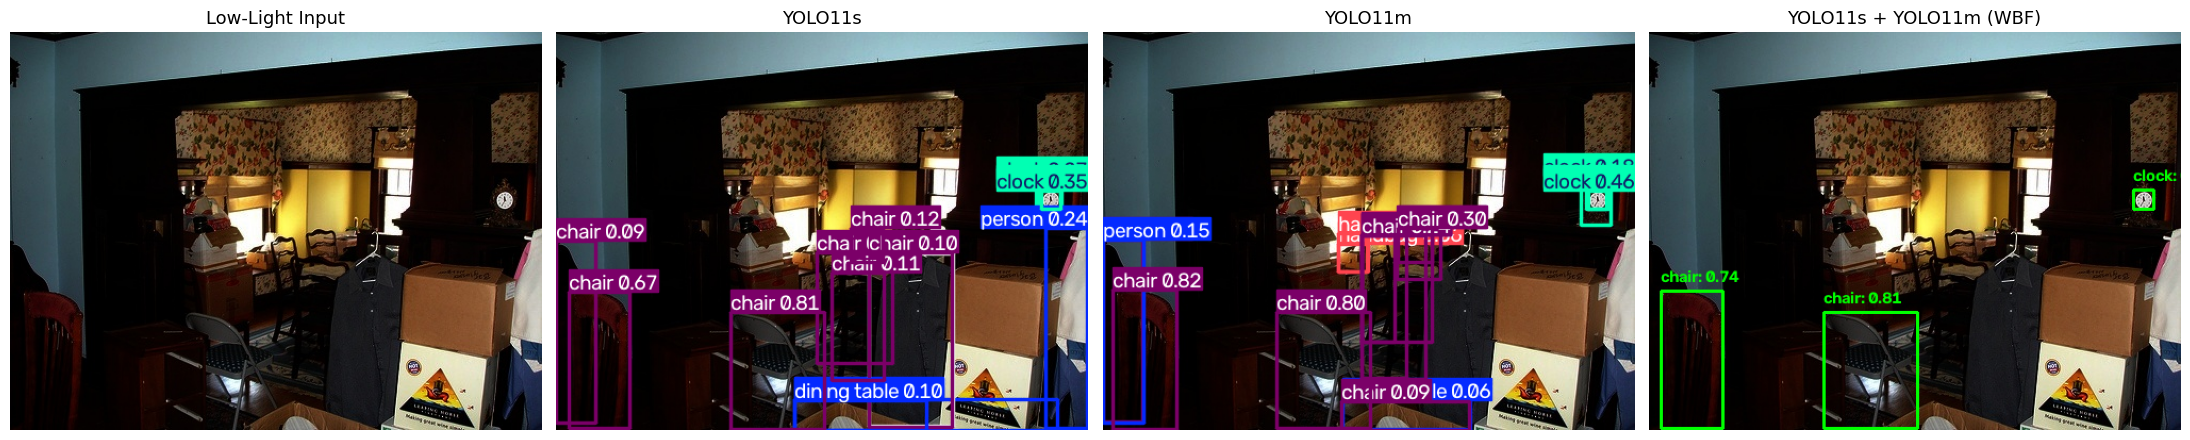


6. ENSEMBLE SUMMARY
YOLO11s detections: 14
YOLO11m detections: 17
WBF detections (confidence >= 0.25): 3

Visualization saved to:
/content/drive/MyDrive/LowLight_Ensemble_MoE/visualizations/ensemble_demo/ensemble_comparison.png

SUCCESS: TWO-MODEL ENSEMBLE IS WORKING!
CELL 29 COMPLETED


In [ ]:
# ============================================================
# CELL 29: YOLO11s + YOLO11m WEIGHTED BOXES FUSION
# ============================================================

from pathlib import Path
import numpy as np
import cv2
import torch
import matplotlib.pyplot as plt

from ultralytics import YOLO
from ensemble_boxes import weighted_boxes_fusion

print("=" * 65)
print("CELL 29: MULTI-MODEL ENSEMBLE OBJECT DETECTION")
print("=" * 65)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

DEVICE = 0 if torch.cuda.is_available() else "cpu"

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/LowLight_Ensemble_MoE"
)

DEMO_DIR = Path("/content/lowlight_ensemble_demo")

OUTPUT_DIR = PROJECT_ROOT / "visualizations" / "ensemble_demo"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert DEMO_DIR.exists(), "Demo images missing."

images = sorted(DEMO_DIR.glob("*.jpg"))

assert len(images) > 0, "No demonstration images found."

print("\n1. DEVICE")
print(
    "Device:",
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else "CPU"
)

# ------------------------------------------------------------
# 2. LOAD MODELS
# ------------------------------------------------------------

print("\n2. LOADING MODELS")

model_s = YOLO("yolo11s.pt")
model_m = YOLO("yolo11m.pt")

print("YOLO11s: READY")
print("YOLO11m: READY")

# ------------------------------------------------------------
# 3. SELECT IMAGE
# ------------------------------------------------------------

image_path = images[0]

image_bgr = cv2.imread(str(image_path))

assert image_bgr is not None, "Image loading failed."

height, width = image_bgr.shape[:2]

print("\n3. INPUT IMAGE")
print("Filename:", image_path.name)
print("Dimensions:", width, "x", height)

# ------------------------------------------------------------
# 4. MODEL INFERENCE
# ------------------------------------------------------------

print("\n4. RUNNING BOTH DETECTORS")

result_s = model_s.predict(
    source=str(image_path),
    imgsz=416,
    conf=0.05,
    iou=0.7,
    device=DEVICE,
    verbose=False
)[0]

result_m = model_m.predict(
    source=str(image_path),
    imgsz=416,
    conf=0.05,
    iou=0.7,
    device=DEVICE,
    verbose=False
)[0]

print("YOLO11s detections:", len(result_s.boxes))
print("YOLO11m detections:", len(result_m.boxes))

# ------------------------------------------------------------
# 5. CONVERT PREDICTIONS TO WBF FORMAT
# ------------------------------------------------------------

def convert_to_wbf(result, image_width, image_height):

    boxes = result.boxes.xyxy.cpu().numpy()
    scores = result.boxes.conf.cpu().numpy()
    labels = result.boxes.cls.cpu().numpy().astype(int)

    normalized_boxes = []

    for box in boxes:

        x1, y1, x2, y2 = box

        normalized_boxes.append([
            np.clip(x1 / image_width, 0, 1),
            np.clip(y1 / image_height, 0, 1),
            np.clip(x2 / image_width, 0, 1),
            np.clip(y2 / image_height, 0, 1)
        ])

    return (
        np.asarray(normalized_boxes, dtype=float).reshape(-1, 4),
        np.asarray(scores, dtype=float),
        np.asarray(labels, dtype=int)
    )

boxes_s, scores_s, labels_s = convert_to_wbf(
    result_s, width, height
)

boxes_m, scores_m, labels_m = convert_to_wbf(
    result_m, width, height
)

# ------------------------------------------------------------
# 6. WEIGHTED BOXES FUSION
# ------------------------------------------------------------

print("\n5. APPLYING WEIGHTED BOXES FUSION")

fused_boxes, fused_scores, fused_labels = weighted_boxes_fusion(
    boxes_list=[boxes_s, boxes_m],
    scores_list=[scores_s, scores_m],
    labels_list=[labels_s, labels_m],
    weights=[1, 1],
    iou_thr=0.55,
    skip_box_thr=0.05,
    conf_type="avg"
)

print("Fused detections:", len(fused_boxes))

# ------------------------------------------------------------
# 7. DRAW FUSED PREDICTIONS
# ------------------------------------------------------------

fused_image = image_bgr.copy()

class_names = model_s.names

for box, score, label in zip(
    fused_boxes, fused_scores, fused_labels
):

    # Display only reasonably confident predictions.
    if score < 0.25:
        continue

    x1, y1, x2, y2 = box

    x1 = int(x1 * width)
    y1 = int(y1 * height)
    x2 = int(x2 * width)
    y2 = int(y2 * height)

    class_id = int(label)
    class_name = class_names[class_id]

    cv2.rectangle(
        fused_image,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

    text_label = f"{class_name}: {score:.2f}"

    cv2.putText(
        fused_image,
        text_label,
        (x1, max(y1 - 8, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 255, 0),
        2
    )

# ------------------------------------------------------------
# 8. VISUALIZE RESULTS
# ------------------------------------------------------------

original_rgb = cv2.cvtColor(
    image_bgr,
    cv2.COLOR_BGR2RGB
)

small_rgb = cv2.cvtColor(
    result_s.plot(),
    cv2.COLOR_BGR2RGB
)

medium_rgb = cv2.cvtColor(
    result_m.plot(),
    cv2.COLOR_BGR2RGB
)

fused_rgb = cv2.cvtColor(
    fused_image,
    cv2.COLOR_BGR2RGB
)

fig, axes = plt.subplots(1, 4, figsize=(22, 6))

titles = [
    "Low-Light Input",
    "YOLO11s",
    "YOLO11m",
    "YOLO11s + YOLO11m (WBF)"
]

display_images = [
    original_rgb,
    small_rgb,
    medium_rgb,
    fused_rgb
]

for ax, img, title in zip(
    axes, display_images, titles
):
    ax.imshow(img)
    ax.set_title(title, fontsize=13)
    ax.axis("off")

plt.tight_layout()

output_path = OUTPUT_DIR / "ensemble_comparison.png"

plt.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 9. FINAL SUMMARY
# ------------------------------------------------------------

print("\n6. ENSEMBLE SUMMARY")

print("YOLO11s detections:", len(result_s.boxes))
print("YOLO11m detections:", len(result_m.boxes))

print(
    "WBF detections (confidence >= 0.25):",
    int(np.sum(fused_scores >= 0.25))
)

print("\nVisualization saved to:")
print(output_path)

print("\nSUCCESS: TWO-MODEL ENSEMBLE IS WORKING!")
print("CELL 29 COMPLETED")

In [ ]:
# ============================================================
# CELL 30: COMPARE YOLO11s, YOLO11m AND WBF ENSEMBLE
# ============================================================

from pathlib import Path
import json
import numpy as np
import torch
import cv2
from ultralytics import YOLO
from ensemble_boxes import weighted_boxes_fusion
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

print("=" * 65)
print("CELL 30: MULTI-MODEL ACCURACY EVALUATION")
print("=" * 65)

PROJECT_ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")
DEMO_DIR = Path("/content/lowlight_ensemble_demo")
VOC_ROOT = Path("/content/lowlight_data/VOCdevkit/VOC2007")

OUTPUT_DIR = PROJECT_ROOT / "evaluations" / "ensemble"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

images = sorted(DEMO_DIR.glob("*.jpg"))

assert len(images) > 0, "No demonstration images found."

# ------------------------------------------------------------
# 1. VOC CLASSES
# ------------------------------------------------------------

VOC_CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike", "person",
    "pottedplant", "sheep", "sofa", "train", "tvmonitor"
]

VOC_TO_ID = {name: i + 1 for i, name in enumerate(VOC_CLASSES)}

# COCO pretrained model names -> VOC names.
COCO_TO_VOC_NAME = {
    "airplane": "aeroplane",
    "bicycle": "bicycle",
    "bird": "bird",
    "boat": "boat",
    "bottle": "bottle",
    "bus": "bus",
    "car": "car",
    "cat": "cat",
    "chair": "chair",
    "cow": "cow",
    "dining table": "diningtable",
    "dog": "dog",
    "horse": "horse",
    "motorcycle": "motorbike",
    "person": "person",
    "potted plant": "pottedplant",
    "sheep": "sheep",
    "couch": "sofa",
    "train": "train",
    "tv": "tvmonitor"
}

# ------------------------------------------------------------
# 2. LOAD MODELS
# ------------------------------------------------------------

print("\n1. LOADING MODELS")

model_s = YOLO("yolo11s.pt")
model_m = YOLO("yolo11m.pt")

DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("Models loaded.")
print("Images to evaluate:", len(images))

# ------------------------------------------------------------
# 3. BUILD GROUND TRUTH
# ------------------------------------------------------------

import xml.etree.ElementTree as ET

ground_truth = {
    "images": [],
    "annotations": [],
    "categories": [
        {"id": i + 1, "name": name}
        for i, name in enumerate(VOC_CLASSES)
    ]
}

annotation_id = 1
image_id_map = {}

for idx, image_path in enumerate(images, start=1):

    image_name = image_path.stem
    image_id_map[image_name] = idx

    image = cv2.imread(str(image_path))
    height, width = image.shape[:2]

    ground_truth["images"].append({
        "id": idx,
        "file_name": image_path.name,
        "width": width,
        "height": height
    })

    xml_path = VOC_ROOT / "Annotations" / f"{image_name}.xml"

    assert xml_path.exists(), f"Annotation missing: {xml_path}"

    root = ET.parse(xml_path).getroot()

    for obj in root.findall("object"):

        name = obj.findtext("name")

        if name not in VOC_TO_ID:
            continue

        bbox = obj.find("bndbox")

        xmin = float(bbox.findtext("xmin")) - 1
        ymin = float(bbox.findtext("ymin")) - 1
        xmax = float(bbox.findtext("xmax"))
        ymax = float(bbox.findtext("ymax"))

        box_w = xmax - xmin
        box_h = ymax - ymin

        difficult = int(obj.findtext("difficult", default="0"))

        ground_truth["annotations"].append({
            "id": annotation_id,
            "image_id": idx,
            "category_id": VOC_TO_ID[name],
            "bbox": [xmin, ymin, box_w, box_h],
            "area": box_w * box_h,
            "iscrowd": difficult
        })

        annotation_id += 1

gt_path = OUTPUT_DIR / "demo20_ground_truth.json"

with open(gt_path, "w") as f:
    json.dump(ground_truth, f)

print("Ground truth annotations:",
      len(ground_truth["annotations"]))

# ------------------------------------------------------------
# 4. CONVERT YOLO PREDICTIONS
# ------------------------------------------------------------

def convert_predictions(result, image_id, model_names):

    converted = []

    boxes = result.boxes.xyxy.cpu().numpy()
    scores = result.boxes.conf.cpu().numpy()
    labels = result.boxes.cls.cpu().numpy().astype(int)

    for box, score, label in zip(boxes, scores, labels):

        coco_name = model_names[int(label)]

        if coco_name not in COCO_TO_VOC_NAME:
            continue

        voc_name = COCO_TO_VOC_NAME[coco_name]
        category_id = VOC_TO_ID[voc_name]

        x1, y1, x2, y2 = box

        converted.append({
            "image_id": image_id,
            "category_id": category_id,
            "bbox": [
                float(x1),
                float(y1),
                float(x2 - x1),
                float(y2 - y1)
            ],
            "score": float(score)
        })

    return converted

# ------------------------------------------------------------
# 5. WBF HELPER
# ------------------------------------------------------------

def to_wbf(result, width, height):

    boxes = result.boxes.xyxy.cpu().numpy()
    scores = result.boxes.conf.cpu().numpy()
    labels = result.boxes.cls.cpu().numpy().astype(int)

    filtered_boxes = []
    filtered_scores = []
    filtered_labels = []

    for box, score, label in zip(boxes, scores, labels):

        class_name = result.names[int(label)]

        if class_name not in COCO_TO_VOC_NAME:
            continue

        voc_name = COCO_TO_VOC_NAME[class_name]

        x1, y1, x2, y2 = box

        filtered_boxes.append([
            np.clip(x1 / width, 0, 1),
            np.clip(y1 / height, 0, 1),
            np.clip(x2 / width, 0, 1),
            np.clip(y2 / height, 0, 1)
        ])

        filtered_scores.append(float(score))
        filtered_labels.append(VOC_TO_ID[voc_name])

    return (
        filtered_boxes,
        filtered_scores,
        filtered_labels
    )

# ------------------------------------------------------------
# 6. RUN INFERENCE
# ------------------------------------------------------------

pred_s = []
pred_m = []
pred_wbf = []

print("\n2. RUNNING ENSEMBLE EVALUATION")

for idx, image_path in enumerate(images, start=1):

    image = cv2.imread(str(image_path))
    height, width = image.shape[:2]

    result_s = model_s.predict(
        str(image_path),
        imgsz=416,
        conf=0.001,
        iou=0.7,
        device=DEVICE,
        verbose=False
    )[0]

    result_m = model_m.predict(
        str(image_path),
        imgsz=416,
        conf=0.001,
        iou=0.7,
        device=DEVICE,
        verbose=False
    )[0]

    pred_s.extend(
        convert_predictions(result_s, idx, model_s.names)
    )

    pred_m.extend(
        convert_predictions(result_m, idx, model_m.names)
    )

    boxes_s, scores_s, labels_s = to_wbf(
        result_s, width, height
    )

    boxes_m, scores_m, labels_m = to_wbf(
        result_m, width, height
    )

    fused_boxes, fused_scores, fused_labels = weighted_boxes_fusion(
        [boxes_s, boxes_m],
        [scores_s, scores_m],
        [labels_s, labels_m],
        weights=[1, 1],
        iou_thr=0.55,
        skip_box_thr=0.001,
        conf_type="avg"
    )

    for box, score, label in zip(
        fused_boxes, fused_scores, fused_labels
    ):

        x1, y1, x2, y2 = box

        pred_wbf.append({
            "image_id": idx,
            "category_id": int(label),
            "bbox": [
                float(x1 * width),
                float(y1 * height),
                float((x2 - x1) * width),
                float((y2 - y1) * height)
            ],
            "score": float(score)
        })

    print(f"Evaluated {idx}/{len(images)}", end="\r")

print("\nInference completed.")

# ------------------------------------------------------------
# 7. COCO EVALUATION
# ------------------------------------------------------------

coco_gt = COCO(str(gt_path))

def evaluate(predictions, name):

    if not predictions:
        print(name, ": No predictions")
        return {"mAP50": 0.0, "mAP50_95": 0.0}

    coco_dt = coco_gt.loadRes(predictions)

    evaluator = COCOeval(coco_gt, coco_dt, "bbox")
    evaluator.params.imgIds = list(range(1, len(images) + 1))
    evaluator.params.catIds = list(range(1, 21))

    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()

    return {
        "mAP50": float(max(evaluator.stats[1], 0.0)),
        "mAP50_95": float(max(evaluator.stats[0], 0.0))
    }

print("\n3. YOLO11s RESULTS")
metrics_s = evaluate(pred_s, "YOLO11s")

print("\n4. YOLO11m RESULTS")
metrics_m = evaluate(pred_m, "YOLO11m")

print("\n5. ENSEMBLE RESULTS")
metrics_wbf = evaluate(pred_wbf, "WBF Ensemble")

# ------------------------------------------------------------
# 8. SAVE RESULTS
# ------------------------------------------------------------

comparison = {
    "YOLO11s": metrics_s,
    "YOLO11m": metrics_m,
    "YOLO11s_YOLO11m_WBF": metrics_wbf,
    "evaluated_images": len(images),
    "evaluation_note": (
        "Preliminary COCO-style evaluation on 20 "
        "synthetically darkened VOC2007 validation images."
    )
}

output_path = OUTPUT_DIR / "demo20_comparison.json"

with open(output_path, "w") as f:
    json.dump(comparison, f, indent=4)

print("\n" + "=" * 65)
print("FINAL ACCURACY COMPARISON")
print("=" * 65)

for name, metrics in [
    ("YOLO11s", metrics_s),
    ("YOLO11m", metrics_m),
    ("YOLO11s + YOLO11m (WBF)", metrics_wbf)
]:
    print(
        f"{name:<27} "
        f"mAP50: {metrics['mAP50']:.4f} | "
        f"mAP50-95: {metrics['mAP50_95']:.4f}"
    )

print("\nResults saved:", output_path)
print("\nCELL 30 COMPLETED")

CELL 30: MULTI-MODEL ACCURACY EVALUATION

1. LOADING MODELS
Models loaded.
Images to evaluate: 20
Ground truth annotations: 65

2. RUNNING ENSEMBLE EVALUATION
Evaluated 20/20
Inference completed.
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!

3. YOLO11s RESULTS
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*


/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [np.float32(0.0), np.float32(1.0), np.float32(0.119544275), np.float32(1.0)].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [np.float32(0.3945352), np.float32(1.0), np.float32(0.6322308), np.float32(1.0)].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [np.float32(0.10924865), np.float32(1.0), np.float32(0.34582186), np.float32(1.0)].
  warnings.warn("Zero area box skipped: {}.".format(box_part))


DONE (t=0.14s).
Accumulating evaluation results...
DONE (t=0.10s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.705
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.955
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.754
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.423
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.779
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.540
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.729
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.739
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.554
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= l

In [ ]:
# ============================================================
# CELL 31: PREPARE 200 LOW-LIGHT VALIDATION IMAGES
# ============================================================

from pathlib import Path
import cv2
import numpy as np
import time

print("=" * 65)
print("CELL 31: EXTENDED LOW-LIGHT EVALUATION DATASET")
print("=" * 65)

start = time.time()

VOC_ROOT = Path("/content/lowlight_data/VOCdevkit/VOC2007")

IMAGE_DIR = VOC_ROOT / "JPEGImages"

VAL_SPLIT = VOC_ROOT / "ImageSets" / "Main" / "val.txt"

OUTPUT_DIR = Path("/content/lowlight_ensemble_eval200")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert IMAGE_DIR.exists(), "VOC2007 images missing."
assert VAL_SPLIT.exists(), "VOC2007 validation split missing."

# ------------------------------------------------------------
# 1. SELECT VALIDATION IMAGES
# ------------------------------------------------------------

val_ids = [
    line.split()[0]
    for line in VAL_SPLIT.read_text().splitlines()
    if line.strip()
]

selected_ids = val_ids[:200]

print("\n1. DATASET")
print("Official validation images:", len(val_ids))
print("Selected evaluation images:", len(selected_ids))

assert len(selected_ids) == 200

# ------------------------------------------------------------
# 2. GENERATE LOW-LIGHT IMAGES
# ------------------------------------------------------------

GAMMA = 2.2

lut = np.array(
    [
        round(((i / 255.0) ** GAMMA) * 255)
        for i in range(256)
    ],
    dtype=np.uint8
)

print("\n2. GENERATING LOW-LIGHT IMAGES")

for idx, image_id in enumerate(selected_ids, start=1):

    source = IMAGE_DIR / f"{image_id}.jpg"
    destination = OUTPUT_DIR / f"{image_id}.jpg"

    if not destination.exists():

        image = cv2.imread(str(source))

        if image is None:
            raise RuntimeError(f"Cannot read {source}")

        dark_image = cv2.LUT(image, lut)

        if not cv2.imwrite(str(destination), dark_image):
            raise RuntimeError(f"Cannot save {destination}")

    if idx % 50 == 0:
        print(f"Processed {idx}/200 images")

# ------------------------------------------------------------
# 3. VERIFY DATASET
# ------------------------------------------------------------

generated = sorted(OUTPUT_DIR.glob("*.jpg"))

print("\n3. VERIFICATION")

print("Generated images:", len(generated))
print("Gamma:", GAMMA)
print("Output directory:", OUTPUT_DIR)

assert len(generated) == 200

print("\nSUCCESS: 200-IMAGE EVALUATION DATASET READY!")
print("Elapsed time:", round(time.time() - start, 2), "seconds")
print("\nCELL 31 COMPLETED")

CELL 31: EXTENDED LOW-LIGHT EVALUATION DATASET

1. DATASET
Official validation images: 2510
Selected evaluation images: 200

2. GENERATING LOW-LIGHT IMAGES
Processed 50/200 images
Processed 100/200 images
Processed 150/200 images
Processed 200/200 images

3. VERIFICATION
Generated images: 200
Gamma: 2.2
Output directory: /content/lowlight_ensemble_eval200

SUCCESS: 200-IMAGE EVALUATION DATASET READY!
Elapsed time: 1.27 seconds

CELL 31 COMPLETED


In [ ]:
# ============================================================
# CELL 32: 200-IMAGE YOLO11s + YOLO11m + WBF EVALUATION
# ============================================================

from pathlib import Path
import json
import time
import xml.etree.ElementTree as ET

import cv2
import numpy as np
import torch

from ultralytics import YOLO
from ensemble_boxes import weighted_boxes_fusion
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

print("=" * 70)
print("CELL 32: 200-IMAGE ENSEMBLE ACCURACY EVALUATION")
print("=" * 70)

START_TIME = time.time()

# ------------------------------------------------------------
# 1. PATHS AND CONFIGURATION
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/LowLight_Ensemble_MoE"
)

VOC_ROOT = Path(
    "/content/lowlight_data/VOCdevkit/VOC2007"
)

EVAL_DIR = Path(
    "/content/lowlight_ensemble_eval200"
)

OUTPUT_DIR = (
    PROJECT_ROOT / "evaluations" / "ensemble"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

images = sorted(EVAL_DIR.glob("*.jpg"))

assert len(images) == 200, (
    f"Expected 200 images, found {len(images)}"
)

assert torch.cuda.is_available(), "GPU unavailable."

DEVICE = 0
IMG_SIZE = 416

print("\n1. CONFIGURATION")
print("Images:", len(images))
print("GPU:", torch.cuda.get_device_name(0))
print("Image size:", IMG_SIZE)
print("Gamma:", 2.2)

# ------------------------------------------------------------
# 2. CLASS MAPPINGS
# ------------------------------------------------------------

VOC_CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike", "person",
    "pottedplant", "sheep", "sofa", "train", "tvmonitor"
]

VOC_TO_ID = {
    name: i + 1
    for i, name in enumerate(VOC_CLASSES)
}

COCO_TO_VOC_NAME = {
    "airplane": "aeroplane",
    "bicycle": "bicycle",
    "bird": "bird",
    "boat": "boat",
    "bottle": "bottle",
    "bus": "bus",
    "car": "car",
    "cat": "cat",
    "chair": "chair",
    "cow": "cow",
    "dining table": "diningtable",
    "dog": "dog",
    "horse": "horse",
    "motorcycle": "motorbike",
    "person": "person",
    "potted plant": "pottedplant",
    "sheep": "sheep",
    "couch": "sofa",
    "train": "train",
    "tv": "tvmonitor"
}

# ------------------------------------------------------------
# 3. LOAD MODELS
# ------------------------------------------------------------

print("\n2. LOADING MODELS")

model_s = YOLO("yolo11s.pt")
model_m = YOLO("yolo11m.pt")

print("YOLO11s: READY")
print("YOLO11m: READY")

# ------------------------------------------------------------
# 4. BUILD COCO-STYLE GROUND TRUTH
# ------------------------------------------------------------

print("\n3. BUILDING GROUND TRUTH")

ground_truth = {
    "info": {
        "description": (
            "VOC2007 200-image gamma-2.2 evaluation"
        )
    },
    "licenses": [],
    "images": [],
    "annotations": [],
    "categories": [
        {"id": i + 1, "name": name}
        for i, name in enumerate(VOC_CLASSES)
    ]
}

annotation_id = 1

for image_id, image_path in enumerate(images, start=1):

    image = cv2.imread(str(image_path))

    if image is None:
        raise RuntimeError(
            f"Cannot read {image_path}"
        )

    height, width = image.shape[:2]

    ground_truth["images"].append({
        "id": image_id,
        "file_name": image_path.name,
        "width": width,
        "height": height
    })

    xml_path = (
        VOC_ROOT / "Annotations"
        / f"{image_path.stem}.xml"
    )

    assert xml_path.is_file(), (
        f"Missing annotation: {xml_path}"
    )

    root = ET.parse(xml_path).getroot()

    for obj in root.findall("object"):

        class_name = obj.findtext("name")

        if class_name not in VOC_TO_ID:
            continue

        bbox = obj.find("bndbox")

        xmin = max(
            0.0,
            float(bbox.findtext("xmin")) - 1.0
        )

        ymin = max(
            0.0,
            float(bbox.findtext("ymin")) - 1.0
        )

        xmax = min(
            float(width),
            float(bbox.findtext("xmax"))
        )

        ymax = min(
            float(height),
            float(bbox.findtext("ymax"))
        )

        box_w = xmax - xmin
        box_h = ymax - ymin

        if box_w <= 0 or box_h <= 0:
            continue

        difficult = int(
            obj.findtext("difficult", default="0")
        )

        ground_truth["annotations"].append({
            "id": annotation_id,
            "image_id": image_id,
            "category_id": VOC_TO_ID[class_name],
            "bbox": [
                xmin, ymin, box_w, box_h
            ],
            "area": box_w * box_h,
            "iscrowd": difficult
        })

        annotation_id += 1

gt_path = (
    OUTPUT_DIR / "eval200_ground_truth.json"
)

with open(gt_path, "w") as f:
    json.dump(ground_truth, f)

print(
    "Ground-truth annotations:",
    len(ground_truth["annotations"])
)

# ------------------------------------------------------------
# 5. PREDICTION CONVERSION
# ------------------------------------------------------------

def extract_voc_detections(result, width, height):

    boxes = result.boxes.xyxy.cpu().numpy()
    scores = result.boxes.conf.cpu().numpy()
    labels = (
        result.boxes.cls.cpu().numpy().astype(int)
    )

    detections = []

    for box, score, label in zip(
        boxes, scores, labels
    ):

        coco_name = result.names[int(label)]

        if coco_name not in COCO_TO_VOC_NAME:
            continue

        voc_name = COCO_TO_VOC_NAME[coco_name]
        voc_id = VOC_TO_ID[voc_name]

        x1, y1, x2, y2 = map(float, box)

        x1 = np.clip(x1, 0, width)
        y1 = np.clip(y1, 0, height)
        x2 = np.clip(x2, 0, width)
        y2 = np.clip(y2, 0, height)

        # Filter zero-area boxes.
        if x2 <= x1 or y2 <= y1:
            continue

        detections.append({
            "box": [
                float(x1), float(y1),
                float(x2), float(y2)
            ],
            "score": float(score),
            "category_id": int(voc_id)
        })

    return detections


def detections_to_coco(detections, image_id):

    predictions = []

    for det in detections:

        x1, y1, x2, y2 = det["box"]

        predictions.append({
            "image_id": image_id,
            "category_id": det["category_id"],
            "bbox": [
                x1, y1,
                x2 - x1,
                y2 - y1
            ],
            "score": det["score"]
        })

    return predictions


def detections_to_wbf(detections, width, height):

    boxes = []
    scores = []
    labels = []

    for det in detections:

        x1, y1, x2, y2 = det["box"]

        normalized_box = [
            np.clip(x1 / width, 0, 1),
            np.clip(y1 / height, 0, 1),
            np.clip(x2 / width, 0, 1),
            np.clip(y2 / height, 0, 1)
        ]

        if (
            normalized_box[2] <= normalized_box[0]
            or normalized_box[3] <= normalized_box[1]
        ):
            continue

        boxes.append(normalized_box)
        scores.append(det["score"])
        labels.append(det["category_id"])

    return boxes, scores, labels


# ------------------------------------------------------------
# 6. RUN INFERENCE + WBF
# ------------------------------------------------------------

print("\n4. RUNNING MODEL INFERENCE")

pred_s = []
pred_m = []
pred_wbf = []

for image_id, image_path in enumerate(images, start=1):

    image = cv2.imread(str(image_path))
    height, width = image.shape[:2]

    with torch.inference_mode():

        result_s = model_s.predict(
            source=str(image_path),
            imgsz=IMG_SIZE,
            conf=0.001,
            iou=0.7,
            max_det=300,
            device=DEVICE,
            verbose=False
        )[0]

        result_m = model_m.predict(
            source=str(image_path),
            imgsz=IMG_SIZE,
            conf=0.001,
            iou=0.7,
            max_det=300,
            device=DEVICE,
            verbose=False
        )[0]

    det_s = extract_voc_detections(
        result_s, width, height
    )

    det_m = extract_voc_detections(
        result_m, width, height
    )

    pred_s.extend(
        detections_to_coco(det_s, image_id)
    )

    pred_m.extend(
        detections_to_coco(det_m, image_id)
    )

    boxes_s, scores_s, labels_s = (
        detections_to_wbf(det_s, width, height)
    )

    boxes_m, scores_m, labels_m = (
        detections_to_wbf(det_m, width, height)
    )

    fused_boxes, fused_scores, fused_labels = (
        weighted_boxes_fusion(
            boxes_list=[boxes_s, boxes_m],
            scores_list=[scores_s, scores_m],
            labels_list=[labels_s, labels_m],
            weights=[1, 1],
            iou_thr=0.55,
            skip_box_thr=0.001,
            conf_type="avg"
        )
    )

    for box, score, label in zip(
        fused_boxes,
        fused_scores,
        fused_labels
    ):

        x1, y1, x2, y2 = map(float, box)

        pred_wbf.append({
            "image_id": image_id,
            "category_id": int(label),
            "bbox": [
                x1 * width,
                y1 * height,
                (x2 - x1) * width,
                (y2 - y1) * height
            ],
            "score": float(score)
        })

    if image_id % 25 == 0:
        print(
            f"Processed {image_id}/{len(images)} images"
        )

print("\nInference completed.")

# ------------------------------------------------------------
# 7. COCO EVALUATION
# ------------------------------------------------------------

print("\n5. EVALUATING ACCURACY")

coco_gt = COCO(str(gt_path))

def evaluate_model(predictions, model_name):

    print(f"\nEvaluating: {model_name}")

    if len(predictions) == 0:
        return {
            "mAP50": 0.0,
            "mAP50_95": 0.0,
            "mAP75": 0.0
        }

    coco_dt = coco_gt.loadRes(predictions)

    evaluator = COCOeval(
        coco_gt,
        coco_dt,
        "bbox"
    )

    evaluator.params.imgIds = list(
        range(1, len(images) + 1)
    )

    evaluator.params.catIds = list(
        range(1, 21)
    )

    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()

    return {
        "mAP50": float(
            max(evaluator.stats[1], 0.0)
        ),
        "mAP50_95": float(
            max(evaluator.stats[0], 0.0)
        ),
        "mAP75": float(
            max(evaluator.stats[2], 0.0)
        )
    }


metrics_s = evaluate_model(
    pred_s, "YOLO11s"
)

metrics_m = evaluate_model(
    pred_m, "YOLO11m"
)

metrics_wbf = evaluate_model(
    pred_wbf, "YOLO11s + YOLO11m WBF"
)

# ------------------------------------------------------------
# 8. SAVE RESULTS AND PREDICTIONS
# ------------------------------------------------------------

comparison = {
    "dataset": "VOC2007 validation",
    "num_images": len(images),
    "lighting": "gamma_2.2",
    "evaluation": "COCO-style bounding-box AP",
    "models": {
        "YOLO11s": metrics_s,
        "YOLO11m": metrics_m,
        "YOLO11s_YOLO11m_WBF": metrics_wbf
    }
}

comparison_path = (
    OUTPUT_DIR / "eval200_comparison.json"
)

with open(comparison_path, "w") as f:
    json.dump(comparison, f, indent=4)

for filename, predictions in [
    ("eval200_yolo11s_predictions.json", pred_s),
    ("eval200_yolo11m_predictions.json", pred_m),
    ("eval200_wbf_predictions.json", pred_wbf)
]:
    with open(OUTPUT_DIR / filename, "w") as f:
        json.dump(predictions, f)

# ------------------------------------------------------------
# 9. FINAL COMPARISON
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL 200-IMAGE ACCURACY COMPARISON")
print("=" * 70)

print(
    f"{'MODEL':<28}"
    f"{'mAP50':>12}"
    f"{'mAP50-95':>14}"
    f"{'mAP75':>12}"
)

print("-" * 70)

for name, metrics in [
    ("YOLO11s", metrics_s),
    ("YOLO11m", metrics_m),
    ("YOLO11s + YOLO11m WBF", metrics_wbf)
]:
    print(
        f"{name:<28}"
        f"{metrics['mAP50'] * 100:>11.2f}%"
        f"{metrics['mAP50_95'] * 100:>13.2f}%"
        f"{metrics['mAP75'] * 100:>11.2f}%"
    )

improvement = (
    metrics_wbf["mAP50_95"]
    - metrics_s["mAP50_95"]
) * 100

print("\nWBF vs YOLO11s (mAP50-95):")
print(f"{improvement:+.2f} percentage points")

print("\nResults saved to:", comparison_path)

print(
    "Total evaluation time:",
    round(time.time() - START_TIME, 2),
    "seconds"
)

print("\nCELL 32 COMPLETED")

CELL 32: 200-IMAGE ENSEMBLE ACCURACY EVALUATION

1. CONFIGURATION
Images: 200
GPU: Tesla T4
Image size: 416
Gamma: 2.2

2. LOADING MODELS
YOLO11s: READY
YOLO11m: READY

3. BUILDING GROUND TRUTH
Ground-truth annotations: 620

4. RUNNING MODEL INFERENCE
Processed 25/200 images
Processed 50/200 images
Processed 75/200 images
Processed 100/200 images
Processed 125/200 images
Processed 150/200 images
Processed 175/200 images
Processed 200/200 images

Inference completed.

5. EVALUATING ACCURACY
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!

Evaluating: YOLO11s
Loading and preparing results...
DONE (t=0.02s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=1.13s).
Accumulating evaluation results...
DONE (t=0.34s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.643
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.830
 Average Precision  (AP) @[ I

In [ ]:
# ============================================================
# CELL 33: WBF PARAMETER SEARCH ON DEVELOPMENT SET
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

from ensemble_boxes import weighted_boxes_fusion
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from contextlib import redirect_stdout
import io

print("=" * 70)
print("CELL 33: WEIGHTED BOXES FUSION PARAMETER SEARCH")
print("=" * 70)

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")
EVAL_DIR = ROOT / "evaluations" / "ensemble"

def load_json(filename):
    path = EVAL_DIR / filename
    assert path.exists(), f"Missing file: {path}"
    with open(path) as f:
        return json.load(f)

gt_data = load_json("eval200_ground_truth.json")
pred_s = load_json("eval200_yolo11s_predictions.json")
pred_m = load_json("eval200_yolo11m_predictions.json")

coco_gt = COCO(str(EVAL_DIR / "eval200_ground_truth.json"))

image_info = {
    img["id"]: img
    for img in gt_data["images"]
}

image_ids = sorted(image_info)

print("\nImages:", len(image_ids))
print("YOLO11s predictions:", len(pred_s))
print("YOLO11m predictions:", len(pred_m))

# ------------------------------------------------------------
# 1. GROUP PREDICTIONS BY IMAGE
# ------------------------------------------------------------

def group_predictions(predictions):
    grouped = {image_id: [] for image_id in image_ids}

    for pred in predictions:
        grouped[pred["image_id"]].append(pred)

    return grouped

group_s = group_predictions(pred_s)
group_m = group_predictions(pred_m)

# ------------------------------------------------------------
# 2. CONVERT COCO PREDICTIONS TO WBF FORMAT
# ------------------------------------------------------------

def prepare_wbf(predictions, width, height):
    boxes, scores, labels = [], [], []

    for pred in predictions:
        x, y, w, h = pred["bbox"]

        if w <= 0 or h <= 0:
            continue

        x1 = float(np.clip(x / width, 0, 1))
        y1 = float(np.clip(y / height, 0, 1))
        x2 = float(np.clip((x + w) / width, 0, 1))
        y2 = float(np.clip((y + h) / height, 0, 1))

        if x2 <= x1 or y2 <= y1:
            continue

        boxes.append([x1, y1, x2, y2])
        scores.append(float(pred["score"]))
        labels.append(int(pred["category_id"]))

    return boxes, scores, labels

# Cache converted predictions for faster experiments.
cache = {}

for image_id in image_ids:
    info = image_info[image_id]
    width = info["width"]
    height = info["height"]

    cache[image_id] = (
        prepare_wbf(group_s[image_id], width, height),
        prepare_wbf(group_m[image_id], width, height)
    )

# ------------------------------------------------------------
# 3. FUSE PREDICTIONS
# ------------------------------------------------------------

def fuse_all_images(weights, iou_thr):
    fused_predictions = []

    for image_id in image_ids:
        info = image_info[image_id]
        width = info["width"]
        height = info["height"]

        (boxes_s, scores_s, labels_s), (
            boxes_m, scores_m, labels_m
        ) = cache[image_id]

        boxes, scores, labels = weighted_boxes_fusion(
            boxes_list=[boxes_s, boxes_m],
            scores_list=[scores_s, scores_m],
            labels_list=[labels_s, labels_m],
            weights=weights,
            iou_thr=iou_thr,
            skip_box_thr=0.001,
            conf_type="avg"
        )

        for box, score, label in zip(boxes, scores, labels):
            x1, y1, x2, y2 = map(float, box)

            fused_predictions.append({
                "image_id": image_id,
                "category_id": int(label),
                "bbox": [
                    x1 * width,
                    y1 * height,
                    (x2 - x1) * width,
                    (y2 - y1) * height
                ],
                "score": float(score)
            })

    return fused_predictions

# ------------------------------------------------------------
# 4. EVALUATE CONFIGURATION
# ------------------------------------------------------------

def evaluate_predictions(predictions):
    if not predictions:
        return 0.0, 0.0, 0.0

    # Suppress repeated COCO evaluation logs.
    with redirect_stdout(io.StringIO()):
        coco_dt = coco_gt.loadRes(predictions)

        evaluator = COCOeval(coco_gt, coco_dt, "bbox")
        evaluator.params.imgIds = image_ids
        evaluator.params.catIds = list(range(1, 21))

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

    return (
        float(evaluator.stats[1]),
        float(evaluator.stats[0]),
        float(evaluator.stats[2])
    )

# ------------------------------------------------------------
# 5. PARAMETER SEARCH
# ------------------------------------------------------------

weight_configs = [
    [1, 1],
    [1, 1.5],
    [1, 2],
    [1, 3],
    [1, 4],
    [1, 5]
]

iou_thresholds = [0.45, 0.55, 0.65]

results = []

total = len(weight_configs) * len(iou_thresholds)
counter = 0

print("\nTesting", total, "fusion configurations...\n")

for weights in weight_configs:
    for iou_thr in iou_thresholds:

        counter += 1

        fused = fuse_all_images(weights, iou_thr)

        map50, map5095, map75 = evaluate_predictions(fused)

        results.append({
            "weight_s": weights[0],
            "weight_m": weights[1],
            "iou_threshold": iou_thr,
            "mAP50": map50,
            "mAP50_95": map5095,
            "mAP75": map75
        })

        print(
            f"[{counter:02d}/{total}] "
            f"weights={weights}, IoU={iou_thr:.2f} | "
            f"mAP50={map50*100:.2f}% | "
            f"mAP50-95={map5095*100:.2f}%"
        )

# ------------------------------------------------------------
# 6. RANK AND SAVE RESULTS
# ------------------------------------------------------------

df = pd.DataFrame(results)

df = df.sort_values(
    by="mAP50_95",
    ascending=False
).reset_index(drop=True)

best = df.iloc[0]

csv_path = EVAL_DIR / "wbf_development_search.csv"
df.to_csv(csv_path, index=False)

best_config = {
    "weights": [
        float(best["weight_s"]),
        float(best["weight_m"])
    ],
    "iou_thr": float(best["iou_threshold"]),
    "development_mAP50": float(best["mAP50"]),
    "development_mAP50_95": float(best["mAP50_95"]),
    "development_mAP75": float(best["mAP75"]),
    "note": (
        "Selected using the first 200 VOC2007 validation images. "
        "Must be evaluated on separate held-out images."
    )
}

config_path = EVAL_DIR / "best_wbf_development_config.json"

with open(config_path, "w") as f:
    json.dump(best_config, f, indent=4)

print("\n" + "=" * 70)
print("TOP 10 WBF CONFIGURATIONS — DEVELOPMENT DATA")
print("=" * 70)

print(df.head(10).to_string(index=False))

print("\nBEST CONFIGURATION")
print("Weights:", best_config["weights"])
print("IoU threshold:", best_config["iou_thr"])
print(
    "Development mAP50:",
    f"{best_config['development_mAP50']*100:.2f}%"
)
print(
    "Development mAP50-95:",
    f"{best_config['development_mAP50_95']*100:.2f}%"
)

print("\nSaved search results:", csv_path)
print("Saved best configuration:", config_path)

print("\nCELL 33 COMPLETED")

CELL 33: WEIGHTED BOXES FUSION PARAMETER SEARCH
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!

Images: 200
YOLO11s predictions: 9994
YOLO11m predictions: 7139

Testing 18 fusion configurations...

[01/18] weights=[1, 1], IoU=0.45 | mAP50=86.72% | mAP50-95=66.87%
[02/18] weights=[1, 1], IoU=0.55 | mAP50=88.10% | mAP50-95=68.29%
[03/18] weights=[1, 1], IoU=0.65 | mAP50=88.03% | mAP50-95=69.31%
[04/18] weights=[1, 1.5], IoU=0.45 | mAP50=86.90% | mAP50-95=67.26%
[05/18] weights=[1, 1.5], IoU=0.55 | mAP50=88.10% | mAP50-95=68.76%
[06/18] weights=[1, 1.5], IoU=0.65 | mAP50=87.98% | mAP50-95=69.48%
[07/18] weights=[1, 2], IoU=0.45 | mAP50=87.26% | mAP50-95=67.33%
[08/18] weights=[1, 2], IoU=0.55 | mAP50=88.12% | mAP50-95=68.90%
[09/18] weights=[1, 2], IoU=0.65 | mAP50=87.89% | mAP50-95=69.48%
[10/18] weights=[1, 3], IoU=0.45 | mAP50=86.82% | mAP50-95=67.02%
[11/18] weights=[1, 3], IoU=0.55 | mAP50=88.06% | mAP50-95=68.84%
[12/18] weights=[1, 3], IoU=0.65 |

In [ ]:
# ============================================================
# CELL 34: INDEPENDENT 200-IMAGE ENSEMBLE EVALUATION
# ============================================================

from pathlib import Path
from contextlib import redirect_stdout
import xml.etree.ElementTree as ET
import json
import io
import time

import cv2
import numpy as np
import torch

from ultralytics import YOLO
from ensemble_boxes import weighted_boxes_fusion
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

print("=" * 70)
print("CELL 34: HELD-OUT LOW-LIGHT ENSEMBLE EVALUATION")
print("=" * 70)

start_time = time.time()

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")
VOC_ROOT = Path("/content/lowlight_data/VOCdevkit/VOC2007")
IMAGE_ROOT = VOC_ROOT / "JPEGImages"
ANNOTATION_ROOT = VOC_ROOT / "Annotations"

OUTPUT_DIR = ROOT / "evaluations" / "ensemble"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EVAL_IMAGE_DIR = Path("/content/lowlight_ensemble_holdout200")
EVAL_IMAGE_DIR.mkdir(parents=True, exist_ok=True)

VAL_SPLIT = VOC_ROOT / "ImageSets" / "Main" / "val.txt"

assert VAL_SPLIT.exists(), "VOC validation split missing."
assert IMAGE_ROOT.exists(), "VOC images missing."
assert ANNOTATION_ROOT.exists(), "VOC annotations missing."

DEVICE = 0 if torch.cuda.is_available() else "cpu"
IMG_SIZE = 416
GAMMA = 2.2

val_ids = [
    line.split()[0]
    for line in VAL_SPLIT.read_text().splitlines()
    if line.strip()
]

# Important: these are DIFFERENT from development images 1–200.
holdout_ids = val_ids[200:400]

assert len(holdout_ids) == 200

print("\n1. HELD-OUT DATASET")
print("Selected images:", len(holdout_ids))
print("Split: VOC2007 validation images 201–400")
print("Gamma:", GAMMA)
print("Device:", DEVICE)

# ------------------------------------------------------------
# 2. GENERATE LOW-LIGHT IMAGES
# ------------------------------------------------------------

lut = np.array(
    [
        round(((i / 255.0) ** GAMMA) * 255)
        for i in range(256)
    ],
    dtype=np.uint8
)

for image_id in holdout_ids:

    source = IMAGE_ROOT / f"{image_id}.jpg"
    destination = EVAL_IMAGE_DIR / f"{image_id}.jpg"

    if not destination.exists():

        image = cv2.imread(str(source))
        assert image is not None, f"Cannot read {source}"

        dark_image = cv2.LUT(image, lut)
        assert cv2.imwrite(str(destination), dark_image)

images = [
    EVAL_IMAGE_DIR / f"{image_id}.jpg"
    for image_id in holdout_ids
]

assert all(path.exists() for path in images)

print("Low-light holdout images ready:", len(images))

# ------------------------------------------------------------
# 3. VOC CLASS MAPPING
# ------------------------------------------------------------

VOC_CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike", "person",
    "pottedplant", "sheep", "sofa", "train", "tvmonitor"
]

VOC_TO_ID = {
    name: idx + 1
    for idx, name in enumerate(VOC_CLASSES)
}

COCO_TO_VOC = {
    "airplane": "aeroplane",
    "bicycle": "bicycle",
    "bird": "bird",
    "boat": "boat",
    "bottle": "bottle",
    "bus": "bus",
    "car": "car",
    "cat": "cat",
    "chair": "chair",
    "cow": "cow",
    "dining table": "diningtable",
    "dog": "dog",
    "horse": "horse",
    "motorcycle": "motorbike",
    "person": "person",
    "potted plant": "pottedplant",
    "sheep": "sheep",
    "couch": "sofa",
    "train": "train",
    "tv": "tvmonitor"
}

# ------------------------------------------------------------
# 4. BUILD GROUND TRUTH
# ------------------------------------------------------------

ground_truth = {
    "info": {
        "description": "VOC2007 held-out gamma 2.2 evaluation"
    },
    "licenses": [],
    "images": [],
    "annotations": [],
    "categories": [
        {"id": i + 1, "name": name}
        for i, name in enumerate(VOC_CLASSES)
    ]
}

annotation_id = 1

for image_id, image_path in enumerate(images, start=1):

    image = cv2.imread(str(image_path))
    height, width = image.shape[:2]

    ground_truth["images"].append({
        "id": image_id,
        "file_name": image_path.name,
        "width": width,
        "height": height
    })

    xml_path = ANNOTATION_ROOT / f"{image_path.stem}.xml"

    root = ET.parse(xml_path).getroot()

    for obj in root.findall("object"):

        name = obj.findtext("name")

        if name not in VOC_TO_ID:
            continue

        bbox = obj.find("bndbox")

        x1 = max(0.0, float(bbox.findtext("xmin")) - 1)
        y1 = max(0.0, float(bbox.findtext("ymin")) - 1)
        x2 = min(float(width), float(bbox.findtext("xmax")))
        y2 = min(float(height), float(bbox.findtext("ymax")))

        w = x2 - x1
        h = y2 - y1

        if w <= 0 or h <= 0:
            continue

        difficult = int(
            obj.findtext("difficult", default="0")
        )

        ground_truth["annotations"].append({
            "id": annotation_id,
            "image_id": image_id,
            "category_id": VOC_TO_ID[name],
            "bbox": [x1, y1, w, h],
            "area": w * h,
            "iscrowd": difficult
        })

        annotation_id += 1

gt_path = OUTPUT_DIR / "holdout200_ground_truth.json"

with open(gt_path, "w") as f:
    json.dump(ground_truth, f)

print("\n2. GROUND TRUTH")
print("Annotations:", len(ground_truth["annotations"]))

# ------------------------------------------------------------
# 5. LOAD MODELS AND OPTIMIZED CONFIGURATION
# ------------------------------------------------------------

model_s = YOLO("yolo11s.pt")
model_m = YOLO("yolo11m.pt")

config_path = OUTPUT_DIR / "best_wbf_development_config.json"

with open(config_path) as f:
    best_config = json.load(f)

OPT_WEIGHTS = best_config["weights"]
OPT_IOU = best_config["iou_thr"]

print("\n3. MODEL CONFIGURATION")
print("YOLO11s: READY")
print("YOLO11m: READY")
print("Optimized weights:", OPT_WEIGHTS)
print("Optimized IoU:", OPT_IOU)

# ------------------------------------------------------------
# 6. PREDICTION HELPERS
# ------------------------------------------------------------

def extract_detections(result, width, height):

    detections = []

    for box, score, label in zip(
        result.boxes.xyxy.cpu().numpy(),
        result.boxes.conf.cpu().numpy(),
        result.boxes.cls.cpu().numpy().astype(int)
    ):

        class_name = result.names[int(label)]

        if class_name not in COCO_TO_VOC:
            continue

        voc_id = VOC_TO_ID[COCO_TO_VOC[class_name]]

        x1, y1, x2, y2 = map(float, box)

        x1 = float(np.clip(x1, 0, width))
        y1 = float(np.clip(y1, 0, height))
        x2 = float(np.clip(x2, 0, width))
        y2 = float(np.clip(y2, 0, height))

        if x2 <= x1 or y2 <= y1:
            continue

        detections.append({
            "box": [x1, y1, x2, y2],
            "score": float(score),
            "category_id": voc_id
        })

    return detections


def to_coco(detections, image_id):

    output = []

    for det in detections:

        x1, y1, x2, y2 = det["box"]

        output.append({
            "image_id": image_id,
            "category_id": det["category_id"],
            "bbox": [
                x1, y1, x2 - x1, y2 - y1
            ],
            "score": det["score"]
        })

    return output


def to_wbf(detections, width, height):

    boxes, scores, labels = [], [], []

    for det in detections:

        x1, y1, x2, y2 = det["box"]

        box = [
            float(np.clip(x1 / width, 0, 1)),
            float(np.clip(y1 / height, 0, 1)),
            float(np.clip(x2 / width, 0, 1)),
            float(np.clip(y2 / height, 0, 1))
        ]

        if box[2] <= box[0] or box[3] <= box[1]:
            continue

        boxes.append(box)
        scores.append(det["score"])
        labels.append(det["category_id"])

    return boxes, scores, labels


def fuse_predictions(
    detections_s,
    detections_m,
    width,
    height,
    image_id,
    weights,
    iou_thr
):

    boxes_s, scores_s, labels_s = to_wbf(
        detections_s, width, height
    )

    boxes_m, scores_m, labels_m = to_wbf(
        detections_m, width, height
    )

    boxes, scores, labels = weighted_boxes_fusion(
        [boxes_s, boxes_m],
        [scores_s, scores_m],
        [labels_s, labels_m],
        weights=weights,
        iou_thr=iou_thr,
        skip_box_thr=0.001,
        conf_type="avg"
    )

    output = []

    for box, score, label in zip(boxes, scores, labels):

        x1, y1, x2, y2 = map(float, box)

        output.append({
            "image_id": image_id,
            "category_id": int(label),
            "bbox": [
                x1 * width,
                y1 * height,
                (x2 - x1) * width,
                (y2 - y1) * height
            ],
            "score": float(score)
        })

    return output

# ------------------------------------------------------------
# 7. RUN INFERENCE
# ------------------------------------------------------------

pred_s = []
pred_m = []
pred_equal = []
pred_optimized = []

print("\n4. RUNNING HELD-OUT INFERENCE")

for image_id, image_path in enumerate(images, start=1):

    image = cv2.imread(str(image_path))
    height, width = image.shape[:2]

    with torch.inference_mode():

        result_s = model_s.predict(
            str(image_path),
            imgsz=416,
            conf=0.001,
            iou=0.7,
            max_det=300,
            device=DEVICE,
            verbose=False
        )[0]

        result_m = model_m.predict(
            str(image_path),
            imgsz=416,
            conf=0.001,
            iou=0.7,
            max_det=300,
            device=DEVICE,
            verbose=False
        )[0]

    det_s = extract_detections(result_s, width, height)
    det_m = extract_detections(result_m, width, height)

    pred_s.extend(to_coco(det_s, image_id))
    pred_m.extend(to_coco(det_m, image_id))

    pred_equal.extend(
        fuse_predictions(
            det_s, det_m, width, height,
            image_id, [1, 1], 0.55
        )
    )

    pred_optimized.extend(
        fuse_predictions(
            det_s, det_m, width, height,
            image_id, OPT_WEIGHTS, OPT_IOU
        )
    )

    if image_id % 25 == 0:
        print(f"Processed {image_id}/200")

print("Inference completed.")

# ------------------------------------------------------------
# 8. EVALUATE ALL FOUR APPROACHES
# ------------------------------------------------------------

coco_gt = COCO(str(gt_path))

def evaluate(predictions):

    with redirect_stdout(io.StringIO()):

        coco_dt = coco_gt.loadRes(predictions)

        evaluator = COCOeval(coco_gt, coco_dt, "bbox")
        evaluator.params.imgIds = list(range(1, 201))
        evaluator.params.catIds = list(range(1, 21))

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

    return {
        "mAP50": float(evaluator.stats[1]),
        "mAP50_95": float(evaluator.stats[0]),
        "mAP75": float(evaluator.stats[2])
    }

print("\n5. CALCULATING ACCURACY")

results = {
    "YOLO11s": evaluate(pred_s),
    "YOLO11m": evaluate(pred_m),
    "Equal_Weight_WBF": evaluate(pred_equal),
    "Optimized_WBF": evaluate(pred_optimized)
}

# ------------------------------------------------------------
# 9. SAVE RESULTS
# ------------------------------------------------------------

report = {
    "dataset": "VOC2007 validation images 201-400",
    "images": 200,
    "gamma": 2.2,
    "optimized_weights": OPT_WEIGHTS,
    "optimized_iou": OPT_IOU,
    "evaluation": "COCO-style AP",
    "results": results
}

report_path = OUTPUT_DIR / "holdout200_comparison.json"

with open(report_path, "w") as f:
    json.dump(report, f, indent=4)

for filename, predictions in [
    ("holdout200_yolo11s_predictions.json", pred_s),
    ("holdout200_yolo11m_predictions.json", pred_m),
    ("holdout200_equal_wbf_predictions.json", pred_equal),
    ("holdout200_optimized_wbf_predictions.json", pred_optimized)
]:
    with open(OUTPUT_DIR / filename, "w") as f:
        json.dump(predictions, f)

# ------------------------------------------------------------
# 10. FINAL COMPARISON
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("INDEPENDENT 200-IMAGE ACCURACY COMPARISON")
print("=" * 70)

print(
    f"{'MODEL':<26}"
    f"{'mAP50':>12}"
    f"{'mAP50-95':>14}"
    f"{'mAP75':>12}"
)

print("-" * 70)

for name, metrics in results.items():
    print(
        f"{name:<26}"
        f"{metrics['mAP50']*100:>11.2f}%"
        f"{metrics['mAP50_95']*100:>13.2f}%"
        f"{metrics['mAP75']*100:>11.2f}%"
    )

print("\nOPTIMIZED WBF VS YOLO11m")

for metric in ["mAP50", "mAP50_95", "mAP75"]:

    difference = (
        results["Optimized_WBF"][metric]
        - results["YOLO11m"][metric]
    ) * 100

    print(
        f"{metric}: {difference:+.2f} percentage points"
    )

print("\nSaved results:", report_path)
print(
    "Total runtime:",
    round(time.time() - start_time, 2),
    "seconds"
)

print("\nCELL 34 COMPLETED")

CELL 34: HELD-OUT LOW-LIGHT ENSEMBLE EVALUATION

1. HELD-OUT DATASET
Selected images: 200
Split: VOC2007 validation images 201–400
Gamma: 2.2
Device: 0
Low-light holdout images ready: 200

2. GROUND TRUTH
Annotations: 659

3. MODEL CONFIGURATION
YOLO11s: READY
YOLO11m: READY
Optimized weights: [1.0, 2.0]
Optimized IoU: 0.65

4. RUNNING HELD-OUT INFERENCE
Processed 25/200
Processed 50/200
Processed 75/200
Processed 100/200
Processed 125/200
Processed 150/200
Processed 175/200
Processed 200/200
Inference completed.
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!

5. CALCULATING ACCURACY

INDEPENDENT 200-IMAGE ACCURACY COMPARISON
MODEL                            mAP50      mAP50-95       mAP75
----------------------------------------------------------------------
YOLO11s                         83.09%        65.74%      71.47%
YOLO11m                         88.56%        70.50%      76.86%
Equal_Weight_WBF                86.57%        67.69%      73.49%

CELL 35: ILLUMINATION-AWARE PERFORMANCE ANALYSIS
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!

1. BRIGHTNESS DISTRIBUTION
           count    min   mean     max
group                                 
Darkest       67   3.66  36.64   51.25
Middle        66  51.46  61.30   71.79
Brightest     67  72.04  92.95  174.93

2. EVALUATING BRIGHTNESS GROUPS
Darkest    | YOLO11s         | mAP50=82.63% | mAP50-95=67.55%
Darkest    | YOLO11m         | mAP50=90.12% | mAP50-95=75.48%
Darkest    | Optimized WBF   | mAP50=89.16% | mAP50-95=74.18%
Middle     | YOLO11s         | mAP50=86.81% | mAP50-95=69.77%
Middle     | YOLO11m         | mAP50=91.96% | mAP50-95=71.98%
Middle     | Optimized WBF   | mAP50=91.04% | mAP50-95=71.34%
Brightest  | YOLO11s         | mAP50=83.26% | mAP50-95=67.31%
Brightest  | YOLO11m         | mAP50=86.91% | mAP50-95=70.78%
Brightest  | Optimized WBF   | mAP50=87.51% | mAP50-95=71.01%


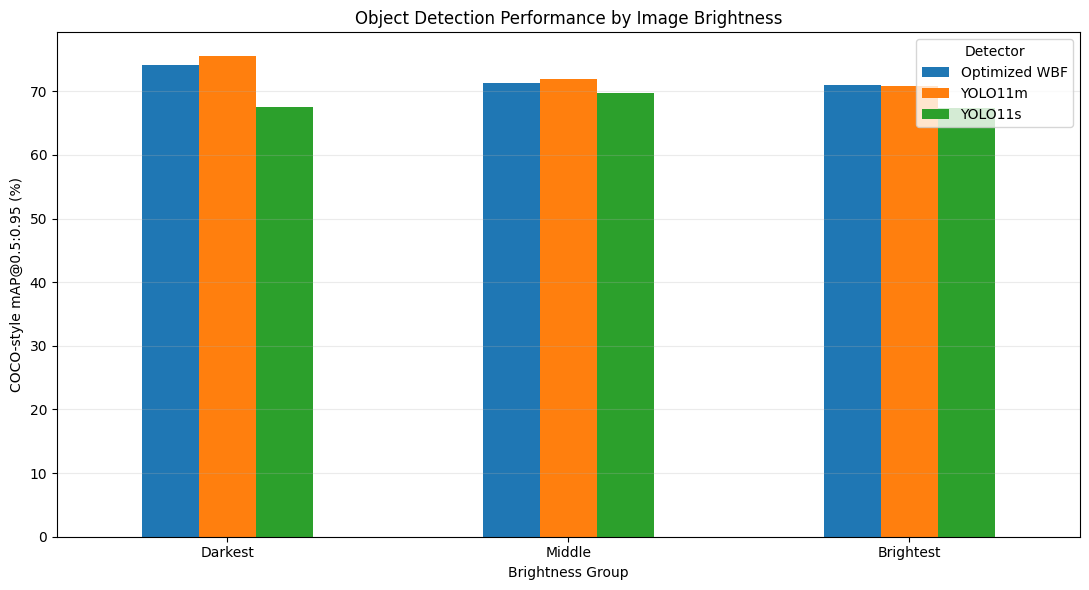


BRIGHTNESS-STRATIFIED RESULTS
brightness_group         model  num_images    mAP50  mAP50_95
         Darkest       YOLO11s          67 0.826261  0.675494
         Darkest       YOLO11m          67 0.901220  0.754821
         Darkest Optimized WBF          67 0.891645  0.741818
          Middle       YOLO11s          66 0.868108  0.697695
          Middle       YOLO11m          66 0.919634  0.719844
          Middle Optimized WBF          66 0.910364  0.713438
       Brightest       YOLO11s          67 0.832638  0.673132
       Brightest       YOLO11m          67 0.869097  0.707779
       Brightest Optimized WBF          67 0.875134  0.710127

Saved analysis: /content/drive/MyDrive/LowLight_Ensemble_MoE/evaluations/ensemble/brightness_performance_analysis.csv
Saved brightness measurements: /content/drive/MyDrive/LowLight_Ensemble_MoE/evaluations/ensemble/holdout200_brightness.csv
Saved visualization: /content/drive/MyDrive/LowLight_Ensemble_MoE/evaluations/ensemble/brightness_performan

In [ ]:
# ============================================================
# CELL 35: BRIGHTNESS-STRATIFIED DETECTOR ANALYSIS
# ============================================================

from pathlib import Path
from contextlib import redirect_stdout
import json
import io

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

print("=" * 70)
print("CELL 35: ILLUMINATION-AWARE PERFORMANCE ANALYSIS")
print("=" * 70)

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")
EVAL_DIR = ROOT / "evaluations" / "ensemble"
IMAGE_DIR = Path("/content/lowlight_ensemble_holdout200")

def load_json(filename):
    path = EVAL_DIR / filename
    assert path.exists(), f"Missing: {path}"
    with open(path) as f:
        return json.load(f)

gt_data = load_json("holdout200_ground_truth.json")

predictions = {
    "YOLO11s": load_json("holdout200_yolo11s_predictions.json"),
    "YOLO11m": load_json("holdout200_yolo11m_predictions.json"),
    "Optimized WBF": load_json(
        "holdout200_optimized_wbf_predictions.json"
    )
}

coco_gt = COCO(str(EVAL_DIR / "holdout200_ground_truth.json"))

# ------------------------------------------------------------
# 1. MEASURE IMAGE BRIGHTNESS
# ------------------------------------------------------------

records = []

for info in gt_data["images"]:

    image_path = IMAGE_DIR / info["file_name"]

    image = cv2.imread(str(image_path))

    assert image is not None, f"Missing image: {image_path}"

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    records.append({
        "image_id": info["id"],
        "filename": info["file_name"],
        "brightness": float(gray.mean())
    })

brightness_df = pd.DataFrame(records)

# Three equally sized groups based on observed brightness.
brightness_df["group"] = pd.qcut(
    brightness_df["brightness"].rank(method="first"),
    q=3,
    labels=["Darkest", "Middle", "Brightest"]
)

print("\n1. BRIGHTNESS DISTRIBUTION")

print(
    brightness_df.groupby(
        "group", observed=True
    )["brightness"].agg(
        ["count", "min", "mean", "max"]
    ).round(2)
)

# ------------------------------------------------------------
# 2. EVALUATE EACH BRIGHTNESS GROUP
# ------------------------------------------------------------

def evaluate_subset(preds, selected_ids):

    selected_ids = list(map(int, selected_ids))
    selected_set = set(selected_ids)

    filtered = [
        p for p in preds
        if p["image_id"] in selected_set
    ]

    if not filtered:
        return {
            "mAP50": None,
            "mAP50_95": None
        }

    with redirect_stdout(io.StringIO()):

        coco_dt = coco_gt.loadRes(filtered)

        evaluator = COCOeval(coco_gt, coco_dt, "bbox")

        evaluator.params.imgIds = selected_ids
        evaluator.params.catIds = list(range(1, 21))

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

    return {
        "mAP50": float(evaluator.stats[1]),
        "mAP50_95": float(evaluator.stats[0])
    }

results = []

print("\n2. EVALUATING BRIGHTNESS GROUPS")

for group in ["Darkest", "Middle", "Brightest"]:

    selected_ids = brightness_df.loc[
        brightness_df["group"] == group,
        "image_id"
    ].tolist()

    for model_name, preds in predictions.items():

        metrics = evaluate_subset(preds, selected_ids)

        results.append({
            "brightness_group": group,
            "model": model_name,
            "num_images": len(selected_ids),
            "mAP50": metrics["mAP50"],
            "mAP50_95": metrics["mAP50_95"]
        })

        print(
            f"{group:<10} | "
            f"{model_name:<15} | "
            f"mAP50={metrics['mAP50']*100:.2f}% | "
            f"mAP50-95={metrics['mAP50_95']*100:.2f}%"
        )

results_df = pd.DataFrame(results)

# ------------------------------------------------------------
# 3. VISUALIZE COMPARISON
# ------------------------------------------------------------

pivot = results_df.pivot(
    index="brightness_group",
    columns="model",
    values="mAP50_95"
)

pivot = pivot.reindex(
    ["Darkest", "Middle", "Brightest"]
)

ax = (pivot * 100).plot(
    kind="bar",
    figsize=(11, 6),
    rot=0
)

ax.set_title(
    "Object Detection Performance by Image Brightness"
)
ax.set_xlabel("Brightness Group")
ax.set_ylabel("COCO-style mAP@0.5:0.95 (%)")
ax.legend(title="Detector")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plot_path = EVAL_DIR / "brightness_performance_comparison.png"

plt.savefig(plot_path, dpi=200)
plt.show()
plt.close()

# ------------------------------------------------------------
# 4. SAVE RESULTS
# ------------------------------------------------------------

csv_path = EVAL_DIR / "brightness_performance_analysis.csv"
brightness_path = EVAL_DIR / "holdout200_brightness.csv"

results_df.to_csv(csv_path, index=False)
brightness_df.to_csv(brightness_path, index=False)

print("\n" + "=" * 70)
print("BRIGHTNESS-STRATIFIED RESULTS")
print("=" * 70)

print(results_df.to_string(index=False))

print("\nSaved analysis:", csv_path)
print("Saved brightness measurements:", brightness_path)
print("Saved visualization:", plot_path)

print("\nCELL 35 COMPLETED")

In [ ]:
# ============================================================
# CELL 36: CHECK EXISTING LOW-LIGHT EXPERT CHECKPOINTS
# ============================================================

from pathlib import Path
import json
import torch

print("=" * 70)
print("CELL 36: LOW-LIGHT EXPERT CHECKPOINT DISCOVERY")
print("=" * 70)

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

assert ROOT.exists(), "Google Drive project folder missing."

print("\n1. SEARCHING FOR TRAINED YOLO CHECKPOINTS")

checkpoints = []

# Search only the project folder, not the entire Drive.
for pattern in ["best.pt", "last.pt"]:
    checkpoints.extend(ROOT.rglob(pattern))

checkpoints = sorted(set(checkpoints))

if checkpoints:

    for idx, checkpoint in enumerate(checkpoints, start=1):

        size_mb = checkpoint.stat().st_size / (1024 * 1024)

        print(f"\nCheckpoint {idx}")
        print("Path:", checkpoint)
        print("Size:", round(size_mb, 2), "MB")

else:
    print("No fine-tuned YOLO checkpoints found.")

print("\n2. CHECKING TRAINING CONFIGURATIONS")

config_dir = ROOT / "configs"

if config_dir.exists():

    config_files = sorted(config_dir.glob("*.json"))

    for config_path in config_files:

        print("\nConfiguration:", config_path.name)

        try:
            with open(config_path) as f:
                config = json.load(f)

            for key in [
                "model",
                "epochs",
                "imgsz",
                "batch",
                "device",
                "data"
            ]:
                if key in config:
                    print(f"  {key}: {config[key]}")

        except Exception as e:
            print("Could not read configuration:", e)

print("\n3. GPU STATUS")

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\n4. FINAL STATUS")

if checkpoints:
    print("TRAINED CHECKPOINTS FOUND.")
    print("Next: Verify their class mappings and evaluate them.")
else:
    print("NO TRAINED LOW-LIGHT EXPERT FOUND.")
    print("Next: Prepare low-light training data and fine-tune YOLO.")

print("\nCELL 36 COMPLETED")

CELL 36: LOW-LIGHT EXPERT CHECKPOINT DISCOVERY

1. SEARCHING FOR TRAINED YOLO CHECKPOINTS

Checkpoint 1
Path: /content/drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr_l_memory_test/weights/best.pt
Size: 63.18 MB

Checkpoint 2
Path: /content/drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr_l_memory_test/weights/last.pt
Size: 63.18 MB

Checkpoint 3
Path: /content/drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr_l_voc2007_full/weights/best.pt
Size: 314.32 MB

Checkpoint 4
Path: /content/drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr_l_voc2007_full/weights/last.pt
Size: 314.32 MB

Checkpoint 5
Path: /content/drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/YOLO11s/yolo11s_lowlight_baseline/weights/best.pt
Size: 18.26 MB

Checkpoint 6
Path: /content/drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/YOLO11s/yolo11s_lowlight_baseline/weights/last.pt
Size: 18.26 MB

2. CHECKING TRAINING CONFIGURATIONS

Configuration: fasterrcnn_coco_to_voc_ma

In [ ]:
# ============================================================
# CELL 37: VERIFY TRAINED EXPERT CHECKPOINTS
# ============================================================

from pathlib import Path
from ultralytics import YOLO, RTDETR
import torch
import gc

print("=" * 70)
print("CELL 37: TRAINED EXPERT VERIFICATION")
print("=" * 70)

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

CHECKPOINTS = {
    "YOLO11s Low-Light Expert":
        ROOT / "checkpoints/YOLO11s/"
        "yolo11s_lowlight_baseline/weights/best.pt",

    "RT-DETR-L VOC2007":
        ROOT / "checkpoints/RTDETR/"
        "rtdetr_l_voc2007_full/weights/best.pt"
}

VOC_CLASSES = {
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike",
    "person", "pottedplant", "sheep",
    "sofa", "train", "tvmonitor"
}

verification_results = {}

for model_name, checkpoint in CHECKPOINTS.items():

    print("\n" + "=" * 70)
    print("MODEL:", model_name)
    print("=" * 70)

    if not checkpoint.exists():
        print("ERROR: Checkpoint missing.")
        continue

    try:

        # Load the correct architecture.
        if "RT-DETR" in model_name:
            model = RTDETR(str(checkpoint))
        else:
            model = YOLO(str(checkpoint))

        names = model.names

        if isinstance(names, dict):
            class_names = list(names.values())
        else:
            class_names = list(names)

        print("\n1. CHECKPOINT")
        print("Path:", checkpoint)
        print(
            "Size:",
            round(checkpoint.stat().st_size / 1024**2, 2),
            "MB"
        )

        print("\n2. CLASS INFORMATION")
        print("Number of classes:", len(class_names))

        for idx, name in enumerate(class_names):
            print(f"  {idx}: {name}")

        # Check whether class names match VOC2007.
        class_set = {
            str(name).strip().lower()
            for name in class_names
        }

        voc_match = (
            len(class_names) == 20
            and class_set == VOC_CLASSES
        )

        print("\n3. VOC2007 COMPATIBILITY")
        print("VOC2007 class-name match:", voc_match)

        if voc_match:
            print("SUCCESS: Model predicts VOC2007 classes.")
        else:
            print(
                "WARNING: Class names differ from VOC2007."
            )
            print(
                "We must verify class mapping before evaluation."
            )

        print("\n4. TRAINING METADATA")

        overrides = getattr(model, "overrides", {})

        if isinstance(overrides, dict):

            for key in [
                "task",
                "data",
                "epochs",
                "imgsz",
                "batch",
                "optimizer",
                "lr0",
                "pretrained"
            ]:
                if key in overrides:
                    print(f"{key}: {overrides[key]}")

        print("\n5. MODEL TYPE")
        print("Task:", model.task)

        verification_results[model_name] = {
            "checkpoint": str(checkpoint),
            "num_classes": len(class_names),
            "class_names": class_names,
            "voc_class_match": voc_match,
            "task": model.task
        }

        print("\nSTATUS: CHECKPOINT LOADED SUCCESSFULLY")

        del model
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    except Exception as e:
        print("\nERROR:", repr(e))

print("\n" + "=" * 70)
print("FINAL VERIFICATION SUMMARY")
print("=" * 70)

for name, result in verification_results.items():

    print(
        f"{name}: "
        f"{result['num_classes']} classes | "
        f"VOC match = {result['voc_class_match']}"
    )

print("\nCELL 37 COMPLETED")

CELL 37: TRAINED EXPERT VERIFICATION

MODEL: YOLO11s Low-Light Expert

1. CHECKPOINT
Path: /content/drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/YOLO11s/yolo11s_lowlight_baseline/weights/best.pt
Size: 18.26 MB

2. CLASS INFORMATION
Number of classes: 20
  0: aeroplane
  1: bicycle
  2: bird
  3: boat
  4: bottle
  5: bus
  6: car
  7: cat
  8: chair
  9: cow
  10: diningtable
  11: dog
  12: horse
  13: motorbike
  14: person
  15: pottedplant
  16: sheep
  17: sofa
  18: train
  19: tvmonitor

3. VOC2007 COMPATIBILITY
VOC2007 class-name match: True
SUCCESS: Model predicts VOC2007 classes.

4. TRAINING METADATA
task: detect
data: /content/drive/MyDrive/LowLight_Ensemble_MoE/splits_and_class_maps/voc2007_lowlight_yolo.yaml
imgsz: 416

5. MODEL TYPE
Task: detect

STATUS: CHECKPOINT LOADED SUCCESSFULLY

MODEL: RT-DETR-L VOC2007

1. CHECKPOINT
Path: /content/drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr_l_voc2007_full/weights/best.pt
Size: 314.32 MB

2. CLASS INFORMATION

In [ ]:
# ============================================================
# CELL 38: EVALUATE TRAINED YOLO11s AND RT-DETR-L
# ============================================================

from pathlib import Path
from contextlib import redirect_stdout
import json
import io
import time
import gc

import cv2
import numpy as np
import torch

from ultralytics import YOLO, RTDETR
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

print("=" * 70)
print("CELL 38: FINE-TUNED EXPERT ACCURACY EVALUATION")
print("=" * 70)

start_time = time.time()

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

EVAL_DIR = ROOT / "evaluations" / "ensemble"

IMAGE_DIR = Path("/content/lowlight_ensemble_holdout200")

GT_PATH = EVAL_DIR / "holdout200_ground_truth.json"

YOLO_PATH = (
    ROOT
    / "checkpoints/YOLO11s/"
    "yolo11s_lowlight_baseline/weights/best.pt"
)

RTDETR_PATH = (
    ROOT
    / "checkpoints/RTDETR/"
    "rtdetr_l_voc2007_full/weights/best.pt"
)

assert GT_PATH.exists()
assert YOLO_PATH.exists()
assert RTDETR_PATH.exists()

DEVICE = 0 if torch.cuda.is_available() else "cpu"

IMG_SIZE = 416

# ------------------------------------------------------------
# 2. LOAD GROUND TRUTH
# ------------------------------------------------------------

with open(GT_PATH) as f:
    gt_data = json.load(f)

images = sorted(
    gt_data["images"],
    key=lambda x: x["id"]
)

assert len(images) == 200

print("\n1. DATASET")
print("Images:", len(images))
print("Gamma:", 2.2)
print("Device:", DEVICE)

# ------------------------------------------------------------
# 3. COCO-STYLE EVALUATION
# ------------------------------------------------------------

coco_gt = COCO(str(GT_PATH))

def evaluate(predictions):

    if not predictions:
        raise ValueError("No predictions generated.")

    with redirect_stdout(io.StringIO()):

        coco_dt = coco_gt.loadRes(predictions)

        evaluator = COCOeval(
            coco_gt,
            coco_dt,
            "bbox"
        )

        evaluator.params.imgIds = [
            image["id"]
            for image in images
        ]

        evaluator.params.catIds = list(range(1, 21))

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

    return {
        "mAP50": float(evaluator.stats[1]),
        "mAP50_95": float(evaluator.stats[0]),
        "mAP75": float(evaluator.stats[2])
    }

# ------------------------------------------------------------
# 4. MODEL EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_expert(model_name, checkpoint, model_type):

    print("\n" + "-" * 70)
    print("EVALUATING:", model_name)
    print("-" * 70)

    if model_type == "RTDETR":
        model = RTDETR(str(checkpoint))
    else:
        model = YOLO(str(checkpoint))

    # Validate class-index order, not just class count.
    expected_classes = [
        "aeroplane", "bicycle", "bird", "boat", "bottle",
        "bus", "car", "cat", "chair", "cow",
        "diningtable", "dog", "horse", "motorbike",
        "person", "pottedplant", "sheep",
        "sofa", "train", "tvmonitor"
    ]

    actual_classes = [
        model.names[i]
        for i in range(20)
    ]

    assert actual_classes == expected_classes, (
        "Unexpected VOC class ordering."
    )

    predictions = []

    for index, info in enumerate(images, start=1):

        image_path = IMAGE_DIR / info["file_name"]

        assert image_path.exists(), (
            f"Missing image: {image_path}"
        )

        with torch.inference_mode():

            result = model.predict(
                source=str(image_path),
                imgsz=IMG_SIZE,
                conf=0.001,
                iou=0.7,
                max_det=300,
                device=DEVICE,
                verbose=False
            )[0]

        boxes = result.boxes.xyxy.cpu().numpy()
        scores = result.boxes.conf.cpu().numpy()
        labels = (
            result.boxes.cls.cpu().numpy().astype(int)
        )

        width = info["width"]
        height = info["height"]

        for box, score, label in zip(
            boxes, scores, labels
        ):

            x1, y1, x2, y2 = map(float, box)

            x1 = float(np.clip(x1, 0, width))
            y1 = float(np.clip(y1, 0, height))
            x2 = float(np.clip(x2, 0, width))
            y2 = float(np.clip(y2, 0, height))

            if x2 <= x1 or y2 <= y1:
                continue

            predictions.append({
                "image_id": info["id"],
                "category_id": int(label) + 1,
                "bbox": [
                    x1,
                    y1,
                    x2 - x1,
                    y2 - y1
                ],
                "score": float(score)
            })

        if index % 25 == 0:
            print(f"Processed {index}/200")

    metrics = evaluate(predictions)

    filename = (
        "holdout200_"
        + model_name.lower().replace(" ", "_")
        + "_predictions.json"
    )

    with open(EVAL_DIR / filename, "w") as f:
        json.dump(predictions, f)

    print("\nRESULTS:", model_name)

    print(
        "mAP@0.5:",
        f"{metrics['mAP50'] * 100:.2f}%"
    )

    print(
        "mAP@0.5:0.95:",
        f"{metrics['mAP50_95'] * 100:.2f}%"
    )

    print(
        "mAP@0.75:",
        f"{metrics['mAP75'] * 100:.2f}%"
    )

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return metrics

# ------------------------------------------------------------
# 5. EVALUATE YOLO11s LOW-LIGHT EXPERT
# ------------------------------------------------------------

print("\n2. FINE-TUNED YOLO11s")

metrics_yolo = evaluate_expert(
    "YOLO11s Lowlight",
    YOLO_PATH,
    "YOLO"
)

# ------------------------------------------------------------
# 6. EVALUATE RT-DETR-L
# ------------------------------------------------------------

print("\n3. RT-DETR-L")

metrics_rtdetr = evaluate_expert(
    "RTDETR L",
    RTDETR_PATH,
    "RTDETR"
)

# ------------------------------------------------------------
# 7. LOAD PREVIOUS YOLO11m RESULTS
# ------------------------------------------------------------

with open(EVAL_DIR / "holdout200_comparison.json") as f:
    previous = json.load(f)

metrics_yolo11m = previous["results"]["YOLO11m"]

# ------------------------------------------------------------
# 8. FINAL COMPARISON
# ------------------------------------------------------------

results = {
    "YOLO11m COCO pretrained": metrics_yolo11m,
    "YOLO11s low-light fine-tuned": metrics_yolo,
    "RT-DETR-L VOC fine-tuned": metrics_rtdetr
}

print("\n" + "=" * 70)
print("FINAL EXPERT COMPARISON")
print("=" * 70)

print(
    f"{'MODEL':<32}"
    f"{'mAP50':>12}"
    f"{'mAP50-95':>14}"
    f"{'mAP75':>12}"
)

print("-" * 70)

for name, metrics in results.items():

    print(
        f"{name:<32}"
        f"{metrics['mAP50'] * 100:>11.2f}%"
        f"{metrics['mAP50_95'] * 100:>13.2f}%"
        f"{metrics['mAP75'] * 100:>11.2f}%"
    )

# ------------------------------------------------------------
# 9. SAVE SUMMARY
# ------------------------------------------------------------

summary = {
    "dataset": "VOC2007 held-out images 201-400",
    "gamma": 2.2,
    "evaluation": "COCO-style AP",
    "results": results
}

output_path = EVAL_DIR / "trained_expert_comparison.json"

with open(output_path, "w") as f:
    json.dump(summary, f, indent=4)

print("\nSaved comparison:", output_path)

print(
    "Total runtime:",
    round(time.time() - start_time, 2),
    "seconds"
)

print("\nCELL 38 COMPLETED")

CELL 38: FINE-TUNED EXPERT ACCURACY EVALUATION

1. DATASET
Images: 200
Gamma: 2.2
Device: 0
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!

2. FINE-TUNED YOLO11s

----------------------------------------------------------------------
EVALUATING: YOLO11s Lowlight
----------------------------------------------------------------------
Processed 25/200
Processed 50/200
Processed 75/200
Processed 100/200
Processed 125/200
Processed 150/200
Processed 175/200
Processed 200/200

RESULTS: YOLO11s Lowlight
mAP@0.5: 65.45%
mAP@0.5:0.95: 47.87%
mAP@0.75: 53.96%

3. RT-DETR-L

----------------------------------------------------------------------
EVALUATING: RTDETR L
----------------------------------------------------------------------
Processed 25/200
Processed 50/200
Processed 75/200
Processed 100/200
Processed 125/200
Processed 150/200
Processed 175/200
Processed 200/200

RESULTS: RTDETR L
mAP@0.5: 6.63%
mAP@0.5:0.95: 3.43%
mAP@0.75: 3.44%

FINAL EXPERT COMPA

In [ ]:
# ============================================================
# CELL 39: DIAGNOSE FINE-TUNED MODEL TRAINING
# ============================================================

from pathlib import Path
import pandas as pd

print("=" * 70)
print("CELL 39: TRAINING DIAGNOSTICS")
print("=" * 70)

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

MODEL_DIRS = {
    "YOLO11s Low-Light":
        ROOT / "checkpoints/YOLO11s/yolo11s_lowlight_baseline",

    "RT-DETR-L":
        ROOT / "checkpoints/RTDETR/rtdetr_l_voc2007_full"
}

for model_name, model_dir in MODEL_DIRS.items():

    print("\n" + "=" * 70)
    print("MODEL:", model_name)
    print("=" * 70)

    print("\n1. CHECKPOINT DIRECTORY")
    print(model_dir)

    print("\n2. SEARCHING FOR TRAINING RESULTS")

    search_dirs = [
        model_dir,
        model_dir.parent,
        ROOT / "runs",
        ROOT / "training",
        ROOT / "logs"
    ]

    csv_files = []

    for directory in search_dirs:

        if directory.exists():
            csv_files.extend(directory.rglob("results.csv"))

    csv_files = sorted(set(csv_files))

    if not csv_files:
        print("No training results.csv found.")
        continue

    for csv_path in csv_files:

        print("\nResults file:", csv_path)

        try:
            df = pd.read_csv(csv_path)
            df.columns = df.columns.str.strip()

            print("Recorded epochs:", len(df))

            relevant_columns = [
                col for col in df.columns
                if (
                    "epoch" in col.lower()
                    or "map" in col.lower()
                    or "loss" in col.lower()
                    or "precision" in col.lower()
                    or "recall" in col.lower()
                )
            ]

            print("\nFinal 5 epochs:")

            print(
                df[relevant_columns]
                .tail(5)
                .to_string(index=False)
            )

            map_columns = [
                col for col in df.columns
                if "map50-95" in col.lower()
            ]

            if map_columns:

                metric = map_columns[0]

                best_idx = df[metric].idxmax()

                print("\nBest recorded epoch:")
                print(df.loc[best_idx, relevant_columns].to_string())

        except Exception as e:
            print("Error reading CSV:", e)

print("\n" + "=" * 70)
print("3. CHECKING DATASET CONFIGURATIONS")
print("=" * 70)

config_files = [
    ROOT / "splits_and_class_maps/voc2007_lowlight_yolo.yaml",
    ROOT / "configs/moe_rtdetr_voc2007.yaml"
]

for config_path in config_files:

    print("\nConfiguration:", config_path)

    if config_path.exists():

        print("-" * 60)

        print(config_path.read_text()[:5000])

        print("-" * 60)

    else:
        print("Configuration not found.")

print("\nCELL 39 COMPLETED")

CELL 39: TRAINING DIAGNOSTICS

MODEL: YOLO11s Low-Light

1. CHECKPOINT DIRECTORY
/content/drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/YOLO11s/yolo11s_lowlight_baseline

2. SEARCHING FOR TRAINING RESULTS

Results file: /content/drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/YOLO11s/yolo11s_lowlight_baseline/results.csv
Recorded epochs: 15

Final 5 epochs:
 epoch  train/box_loss  train/cls_loss  train/dfl_loss  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)  val/box_loss  val/cls_loss  val/dfl_loss
    11         0.99448         0.91514         1.17009               0.68130            0.50467           0.57212              0.37664       1.26004       1.31890       1.32426
    12         0.95050         0.83246         1.14015               0.66312            0.54818           0.57977              0.38794       1.23224       1.28417       1.30233
    13         0.90398         0.76592         1.11043               0.66721            0.55562           0

In [ ]:
# ============================================================
# CELL 40: RT-DETR-L MEMORY CHECKPOINT EVALUATION
# ============================================================

from pathlib import Path
from contextlib import redirect_stdout
import json
import io
import time
import gc

import numpy as np
import torch

from ultralytics import RTDETR
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

print("=" * 70)
print("CELL 40: RT-DETR-L MEMORY CHECKPOINT EVALUATION")
print("=" * 70)

start_time = time.time()

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

EVAL_DIR = ROOT / "evaluations" / "ensemble"

IMAGE_DIR = Path("/content/lowlight_ensemble_holdout200")

CHECKPOINT = (
    ROOT
    / "checkpoints/RTDETR/"
    "rtdetr_l_memory_test/weights/best.pt"
)

GT_PATH = EVAL_DIR / "holdout200_ground_truth.json"

assert CHECKPOINT.exists(), "Checkpoint missing."
assert GT_PATH.exists(), "Ground truth missing."

DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("\n1. CHECKPOINT")
print("Path:", CHECKPOINT)
print("Size:", round(CHECKPOINT.stat().st_size / 1024**2, 2), "MB")
print("Device:", DEVICE)

# ------------------------------------------------------------
# 2. LOAD MODEL
# ------------------------------------------------------------

print("\n2. LOADING RT-DETR-L MEMORY CHECKPOINT")

model = RTDETR(str(CHECKPOINT))

VOC_CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike",
    "person", "pottedplant", "sheep",
    "sofa", "train", "tvmonitor"
]

actual_classes = [
    str(model.names[i]).strip().lower()
    for i in range(len(model.names))
]

print("Number of classes:", len(actual_classes))
print("Class names:", actual_classes)

assert actual_classes == VOC_CLASSES, (
    "VOC class ordering mismatch. "
    "Stop and verify the checkpoint mapping."
)

print("VOC class ordering: VERIFIED")

# ------------------------------------------------------------
# 3. LOAD GROUND TRUTH
# ------------------------------------------------------------

with open(GT_PATH) as f:
    gt_data = json.load(f)

images = sorted(
    gt_data["images"],
    key=lambda x: x["id"]
)

assert len(images) == 200

coco_gt = COCO(str(GT_PATH))

# ------------------------------------------------------------
# 4. RUN INFERENCE
# ------------------------------------------------------------

print("\n3. RUNNING INFERENCE")

predictions = []

for index, info in enumerate(images, start=1):

    image_path = IMAGE_DIR / info["file_name"]

    assert image_path.exists(), (
        f"Missing image: {image_path}"
    )

    with torch.inference_mode():

        result = model.predict(
            source=str(image_path),
            imgsz=416,
            conf=0.001,
            iou=0.7,
            max_det=300,
            device=DEVICE,
            verbose=False
        )[0]

    boxes = result.boxes.xyxy.cpu().numpy()
    scores = result.boxes.conf.cpu().numpy()
    labels = result.boxes.cls.cpu().numpy().astype(int)

    width = info["width"]
    height = info["height"]

    for box, score, label in zip(
        boxes, scores, labels
    ):

        x1, y1, x2, y2 = map(float, box)

        x1 = float(np.clip(x1, 0, width))
        y1 = float(np.clip(y1, 0, height))
        x2 = float(np.clip(x2, 0, width))
        y2 = float(np.clip(y2, 0, height))

        if x2 <= x1 or y2 <= y1:
            continue

        predictions.append({
            "image_id": info["id"],
            "category_id": int(label) + 1,
            "bbox": [
                x1,
                y1,
                x2 - x1,
                y2 - y1
            ],
            "score": float(score)
        })

    if index % 25 == 0:
        print(f"Processed {index}/200")

print("Total predictions:", len(predictions))

assert predictions, "Model produced no valid detections."

# ------------------------------------------------------------
# 5. EVALUATE
# ------------------------------------------------------------

print("\n4. CALCULATING ACCURACY")

with redirect_stdout(io.StringIO()):

    coco_dt = coco_gt.loadRes(predictions)

    evaluator = COCOeval(
        coco_gt,
        coco_dt,
        "bbox"
    )

    evaluator.params.imgIds = [
        info["id"] for info in images
    ]

    evaluator.params.catIds = list(range(1, 21))

    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()

metrics = {
    "mAP50": float(evaluator.stats[1]),
    "mAP50_95": float(evaluator.stats[0]),
    "mAP75": float(evaluator.stats[2])
}

# ------------------------------------------------------------
# 6. SAVE RESULTS
# ------------------------------------------------------------

predictions_path = (
    EVAL_DIR / "holdout200_rtdetr_memory_predictions.json"
)

metrics_path = (
    EVAL_DIR / "holdout200_rtdetr_memory_metrics.json"
)

with open(predictions_path, "w") as f:
    json.dump(predictions, f)

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=4)

# ------------------------------------------------------------
# 7. FINAL COMPARISON
# ------------------------------------------------------------

with open(EVAL_DIR / "trained_expert_comparison.json") as f:
    previous = json.load(f)["results"]

print("\n" + "=" * 70)
print("RT-DETR CHECKPOINT COMPARISON")
print("=" * 70)

print(
    f"{'MODEL':<30}"
    f"{'mAP50':>12}"
    f"{'mAP50-95':>14}"
)

print("-" * 60)

comparison = {
    "YOLO11m COCO pretrained":
        previous["YOLO11m COCO pretrained"],

    "RT-DETR-L full run":
        previous["RT-DETR-L VOC fine-tuned"],

    "RT-DETR-L memory test":
        metrics
}

for name, result in comparison.items():

    print(
        f"{name:<30}"
        f"{result['mAP50']*100:>11.2f}%"
        f"{result['mAP50_95']*100:>13.2f}%"
    )

print("\nSaved predictions:", predictions_path)
print("Saved metrics:", metrics_path)

print(
    "Total runtime:",
    round(time.time() - start_time, 2),
    "seconds"
)

del model
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\nCELL 40 COMPLETED")

CELL 40: RT-DETR-L MEMORY CHECKPOINT EVALUATION

1. CHECKPOINT
Path: /content/drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr_l_memory_test/weights/best.pt
Size: 63.18 MB
Device: 0

2. LOADING RT-DETR-L MEMORY CHECKPOINT
Number of classes: 20
Class names: ['aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'cow', 'diningtable', 'dog', 'horse', 'motorbike', 'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tvmonitor']
VOC class ordering: VERIFIED
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!

3. RUNNING INFERENCE
Processed 25/200
Processed 50/200
Processed 75/200
Processed 100/200
Processed 125/200
Processed 150/200
Processed 175/200
Processed 200/200
Total predictions: 60000

4. CALCULATING ACCURACY

RT-DETR CHECKPOINT COMPARISON
MODEL                                mAP50      mAP50-95
------------------------------------------------------------
YOLO11m COCO pretrained             88.56%        70.50%
RT-

In [ ]:
# ============================================================
# CELL 41: COMPLEMENTARY DETECTION ANALYSIS
# ============================================================

from pathlib import Path
from collections import defaultdict
import json
import numpy as np
import pandas as pd

print("=" * 70)
print("CELL 41: YOLO11m vs RT-DETR COMPLEMENTARITY")
print("=" * 70)

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")
EVAL_DIR = ROOT / "evaluations" / "ensemble"

def load_json(filename):
    path = EVAL_DIR / filename
    assert path.exists(), f"Missing: {path}"
    with open(path) as f:
        return json.load(f)

gt = load_json("holdout200_ground_truth.json")

pred_yolo = load_json(
    "holdout200_yolo11m_predictions.json"
)

pred_rtdetr = load_json(
    "holdout200_rtdetr_memory_predictions.json"
)

CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.50

# ------------------------------------------------------------
# 1. GROUP PREDICTIONS
# ------------------------------------------------------------

def group_predictions(predictions):
    grouped = defaultdict(list)

    for p in predictions:
        if p["score"] >= CONF_THRESHOLD:
            grouped[p["image_id"]].append(p)

    return grouped

yolo_group = group_predictions(pred_yolo)
rtdetr_group = group_predictions(pred_rtdetr)

# ------------------------------------------------------------
# 2. BOUNDING BOX IOU
# ------------------------------------------------------------

def calculate_iou(box_a, box_b):

    ax, ay, aw, ah = box_a
    bx, by, bw, bh = box_b

    ax2, ay2 = ax + aw, ay + ah
    bx2, by2 = bx + bw, by + bh

    ix1 = max(ax, bx)
    iy1 = max(ay, by)
    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    iw = max(0.0, ix2 - ix1)
    ih = max(0.0, iy2 - iy1)

    intersection = iw * ih

    union = aw * ah + bw * bh - intersection

    return intersection / union if union > 0 else 0.0

# ------------------------------------------------------------
# 3. DETECTION COVERAGE
# ------------------------------------------------------------

def is_detected(annotation, predictions):

    for pred in predictions:

        if pred["category_id"] != annotation["category_id"]:
            continue

        iou = calculate_iou(
            annotation["bbox"],
            pred["bbox"]
        )

        if iou >= IOU_THRESHOLD:
            return True

    return False

records = []

# Exclude difficult objects, consistent with diagnostic intent.
annotations = [
    ann for ann in gt["annotations"]
    if ann.get("iscrowd", 0) == 0
]

for ann in annotations:

    image_id = ann["image_id"]

    detected_yolo = is_detected(
        ann,
        yolo_group[image_id]
    )

    detected_rtdetr = is_detected(
        ann,
        rtdetr_group[image_id]
    )

    records.append({
        "image_id": image_id,
        "category_id": ann["category_id"],
        "yolo_detected": detected_yolo,
        "rtdetr_detected": detected_rtdetr,
        "either_detected": (
            detected_yolo or detected_rtdetr
        ),
        "rtdetr_only": (
            detected_rtdetr and not detected_yolo
        ),
        "yolo_only": (
            detected_yolo and not detected_rtdetr
        )
    })

df = pd.DataFrame(records)

# ------------------------------------------------------------
# 4. OVERALL COVERAGE
# ------------------------------------------------------------

total = len(df)

yolo_count = int(df["yolo_detected"].sum())
rtdetr_count = int(df["rtdetr_detected"].sum())
either_count = int(df["either_detected"].sum())

rtdetr_only = int(df["rtdetr_only"].sum())
yolo_only = int(df["yolo_only"].sum())

both_count = int(
    (df["yolo_detected"] & df["rtdetr_detected"]).sum()
)

neither_count = total - either_count

print("\n1. OBJECT-LEVEL COVERAGE")
print("Ground-truth objects evaluated:", total)

print(
    f"YOLO11m coverage: "
    f"{yolo_count}/{total} "
    f"({100*yolo_count/total:.2f}%)"
)

print(
    f"RT-DETR coverage: "
    f"{rtdetr_count}/{total} "
    f"({100*rtdetr_count/total:.2f}%)"
)

print(
    f"Either model coverage: "
    f"{either_count}/{total} "
    f"({100*either_count/total:.2f}%)"
)

print("\n2. COMPLEMENTARITY")

print("Detected by both:", both_count)
print("Detected only by YOLO11m:", yolo_only)
print("Detected only by RT-DETR:", rtdetr_only)
print("Missed by both:", neither_count)

print(
    "\nPotential additional coverage from RT-DETR:",
    f"{100*rtdetr_only/total:.2f} percentage points"
)

# ------------------------------------------------------------
# 5. CLASS-WISE COMPLEMENTARITY
# ------------------------------------------------------------

class_names = {
    cat["id"]: cat["name"]
    for cat in gt["categories"]
}

class_summary = (
    df.groupby("category_id")
    .agg(
        objects=("image_id", "count"),
        yolo_covered=("yolo_detected", "sum"),
        rtdetr_covered=("rtdetr_detected", "sum"),
        rtdetr_only=("rtdetr_only", "sum")
    )
    .reset_index()
)

class_summary["class"] = (
    class_summary["category_id"].map(class_names)
)

class_summary = class_summary.sort_values(
    "rtdetr_only",
    ascending=False
)

print("\n3. CLASS-WISE RT-DETR CONTRIBUTION")

print(
    class_summary[
        [
            "class",
            "objects",
            "yolo_covered",
            "rtdetr_covered",
            "rtdetr_only"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 6. SAVE ANALYSIS
# ------------------------------------------------------------

object_path = EVAL_DIR / "complementarity_objects.csv"
class_path = EVAL_DIR / "complementarity_classes.csv"

df.to_csv(object_path, index=False)
class_summary.to_csv(class_path, index=False)

summary = {
    "confidence_threshold": CONF_THRESHOLD,
    "iou_threshold": IOU_THRESHOLD,
    "total_objects": total,
    "yolo_covered": yolo_count,
    "rtdetr_covered": rtdetr_count,
    "both": both_count,
    "yolo_only": yolo_only,
    "rtdetr_only": rtdetr_only,
    "neither": neither_count,
    "either_covered": either_count
}

summary_path = EVAL_DIR / "complementarity_summary.json"

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4)

print("\nSaved object analysis:", object_path)
print("Saved class analysis:", class_path)
print("Saved summary:", summary_path)

print("\nCELL 41 COMPLETED")

CELL 41: YOLO11m vs RT-DETR COMPLEMENTARITY

1. OBJECT-LEVEL COVERAGE
Ground-truth objects evaluated: 519
YOLO11m coverage: 451/519 (86.90%)
RT-DETR coverage: 404/519 (77.84%)
Either model coverage: 483/519 (93.06%)

2. COMPLEMENTARITY
Detected by both: 372
Detected only by YOLO11m: 79
Detected only by RT-DETR: 32
Missed by both: 36

Potential additional coverage from RT-DETR: 6.17 percentage points

3. CLASS-WISE RT-DETR CONTRIBUTION
      class  objects  yolo_covered  rtdetr_covered  rtdetr_only
     person      186           161             178           21
        car       42            39              41            3
      chair       33            28              30            3
       boat       20            17              19            2
        bus        6             5               6            1
        cat       17            15              16            1
       bird       21            18              18            1
    bicycle       23            20              1

In [ ]:
# ============================================================
# CELL 42: YOLO11m + RT-DETR WBF ENSEMBLE EVALUATION
# ============================================================

from pathlib import Path
from contextlib import redirect_stdout
from collections import defaultdict
import json
import io
import time

import numpy as np
from ensemble_boxes import weighted_boxes_fusion
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

print("=" * 70)
print("CELL 42: YOLO11m + RT-DETR ENSEMBLE EVALUATION")
print("=" * 70)

start_time = time.time()

# ------------------------------------------------------------
# 1. LOAD SAVED PREDICTIONS
# ------------------------------------------------------------

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")
EVAL_DIR = ROOT / "evaluations" / "ensemble"

def load_json(filename):
    path = EVAL_DIR / filename
    assert path.exists(), f"Missing file: {path}"
    with open(path) as f:
        return json.load(f)

gt = load_json("holdout200_ground_truth.json")

pred_yolo = load_json(
    "holdout200_yolo11m_predictions.json"
)

pred_rtdetr = load_json(
    "holdout200_rtdetr_memory_predictions.json"
)

coco_gt = COCO(
    str(EVAL_DIR / "holdout200_ground_truth.json")
)

image_info = {
    img["id"]: img
    for img in gt["images"]
}

image_ids = sorted(image_info)

print("\n1. DATASET")
print("Images:", len(image_ids))
print("YOLO11m predictions:", len(pred_yolo))
print("RT-DETR predictions:", len(pred_rtdetr))

# ------------------------------------------------------------
# 2. GROUP PREDICTIONS
# ------------------------------------------------------------

def group_predictions(predictions):
    grouped = defaultdict(list)

    for pred in predictions:
        grouped[pred["image_id"]].append(pred)

    return grouped

group_yolo = group_predictions(pred_yolo)
group_rtdetr = group_predictions(pred_rtdetr)

# ------------------------------------------------------------
# 3. PREPARE WBF INPUT
# ------------------------------------------------------------

def prepare_predictions(
    predictions,
    width,
    height,
    min_conf
):

    boxes, scores, labels = [], [], []

    for pred in predictions:

        score = float(pred["score"])

        if score < min_conf:
            continue

        x, y, w, h = pred["bbox"]

        if w <= 0 or h <= 0:
            continue

        x1 = float(np.clip(x / width, 0, 1))
        y1 = float(np.clip(y / height, 0, 1))
        x2 = float(np.clip((x + w) / width, 0, 1))
        y2 = float(np.clip((y + h) / height, 0, 1))

        if x2 <= x1 or y2 <= y1:
            continue

        boxes.append([x1, y1, x2, y2])
        scores.append(score)
        labels.append(int(pred["category_id"]))

    return boxes, scores, labels

# ------------------------------------------------------------
# 4. FUSION FUNCTION
# ------------------------------------------------------------

def run_wbf(weights, iou_thr=0.55):

    fused_predictions = []

    for image_id in image_ids:

        info = image_info[image_id]

        width = info["width"]
        height = info["height"]

        # Keep YOLO's low-confidence predictions for AP.
        boxes_y, scores_y, labels_y = prepare_predictions(
            group_yolo[image_id],
            width,
            height,
            min_conf=0.001
        )

        # Filter extremely low-confidence RT-DETR outputs.
        boxes_r, scores_r, labels_r = prepare_predictions(
            group_rtdetr[image_id],
            width,
            height,
            min_conf=0.05
        )

        fused_boxes, fused_scores, fused_labels = (
            weighted_boxes_fusion(
                boxes_list=[boxes_y, boxes_r],
                scores_list=[scores_y, scores_r],
                labels_list=[labels_y, labels_r],
                weights=weights,
                iou_thr=iou_thr,
                skip_box_thr=0.001,
                conf_type="avg"
            )
        )

        for box, score, label in zip(
            fused_boxes,
            fused_scores,
            fused_labels
        ):

            x1, y1, x2, y2 = map(float, box)

            fused_predictions.append({
                "image_id": image_id,
                "category_id": int(label),
                "bbox": [
                    x1 * width,
                    y1 * height,
                    (x2 - x1) * width,
                    (y2 - y1) * height
                ],
                "score": float(score)
            })

    return fused_predictions

# ------------------------------------------------------------
# 5. EVALUATION
# ------------------------------------------------------------

def evaluate(predictions):

    with redirect_stdout(io.StringIO()):

        coco_dt = coco_gt.loadRes(predictions)

        evaluator = COCOeval(
            coco_gt,
            coco_dt,
            "bbox"
        )

        evaluator.params.imgIds = image_ids
        evaluator.params.catIds = list(range(1, 21))

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

    return {
        "mAP50": float(evaluator.stats[1]),
        "mAP50_95": float(evaluator.stats[0]),
        "mAP75": float(evaluator.stats[2])
    }

# ------------------------------------------------------------
# 6. COMPARE CONFIGURATIONS
# ------------------------------------------------------------

print("\n2. RUNNING ENSEMBLE EXPERIMENTS")

results = {}

results["YOLO11m"] = evaluate(pred_yolo)

configurations = {
    "Equal WBF": [1, 1],
    "YOLO Dominant WBF": [3, 1]
}

for name, weights in configurations.items():

    print(f"Evaluating {name}, weights={weights}")

    fused = run_wbf(
        weights=weights,
        iou_thr=0.55
    )

    results[name] = evaluate(fused)

    output_filename = (
        "holdout200_"
        + name.lower().replace(" ", "_")
        + "_rtdetr_predictions.json"
    )

    with open(EVAL_DIR / output_filename, "w") as f:
        json.dump(fused, f)

# ------------------------------------------------------------
# 7. FINAL RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("YOLO11m + RT-DETR FUSION COMPARISON")
print("=" * 70)

print(
    f"{'MODEL':<28}"
    f"{'mAP50':>12}"
    f"{'mAP50-95':>14}"
    f"{'mAP75':>12}"
)

print("-" * 70)

for name, metrics in results.items():

    print(
        f"{name:<28}"
        f"{metrics['mAP50']*100:>11.2f}%"
        f"{metrics['mAP50_95']*100:>13.2f}%"
        f"{metrics['mAP75']*100:>11.2f}%"
    )

# ------------------------------------------------------------
# 8. SAVE SUMMARY
# ------------------------------------------------------------

summary_path = (
    EVAL_DIR / "yolo11m_rtdetr_fusion_comparison.json"
)

with open(summary_path, "w") as f:
    json.dump({
        "dataset": "VOC2007 validation images 201-400",
        "gamma": 2.2,
        "rtdetr_conf_threshold": 0.05,
        "fusion_iou": 0.55,
        "results": results,
        "note": (
            "Exploratory evaluation on previously examined images. "
            "Not an independent final test."
        )
    }, f, indent=4)

print("\nSaved summary:", summary_path)

print(
    "Total runtime:",
    round(time.time() - start_time, 2),
    "seconds"
)

print("\nCELL 42 COMPLETED")

CELL 42: YOLO11m + RT-DETR ENSEMBLE EVALUATION
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!

1. DATASET
Images: 200
YOLO11m predictions: 7292
RT-DETR predictions: 60000

2. RUNNING ENSEMBLE EXPERIMENTS
Evaluating Equal WBF, weights=[1, 1]
Evaluating YOLO Dominant WBF, weights=[3, 1]

YOLO11m + RT-DETR FUSION COMPARISON
MODEL                              mAP50      mAP50-95       mAP75
----------------------------------------------------------------------
YOLO11m                           88.56%        70.50%      76.86%
Equal WBF                         79.78%        58.84%      66.09%
YOLO Dominant WBF                 83.50%        62.40%      68.44%

Saved summary: /content/drive/MyDrive/LowLight_Ensemble_MoE/evaluations/ensemble/yolo11m_rtdetr_fusion_comparison.json
Total runtime: 35.41 seconds

CELL 42 COMPLETED


In [ ]:
# ============================================================
# CELL 43: SELECTIVE YOLO11m + RT-DETR FUSION
# ============================================================

from pathlib import Path
from collections import defaultdict
from contextlib import redirect_stdout
import json
import io
import time

import numpy as np
import pandas as pd

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

print("=" * 70)
print("CELL 43: SELECTIVE EXPERT FUSION")
print("=" * 70)

start_time = time.time()

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")
EVAL_DIR = ROOT / "evaluations" / "ensemble"

def load_json(filename):
    path = EVAL_DIR / filename
    assert path.exists(), f"Missing: {path}"
    with open(path) as f:
        return json.load(f)

gt = load_json("holdout200_ground_truth.json")

yolo_preds = load_json(
    "holdout200_yolo11m_predictions.json"
)

rtdetr_preds = load_json(
    "holdout200_rtdetr_memory_predictions.json"
)

coco_gt = COCO(
    str(EVAL_DIR / "holdout200_ground_truth.json")
)

image_ids = sorted(
    image["id"] for image in gt["images"]
)

# ------------------------------------------------------------
# 1. GROUP PREDICTIONS
# ------------------------------------------------------------

def group_predictions(predictions):

    grouped = defaultdict(list)

    for prediction in predictions:
        grouped[prediction["image_id"]].append(prediction)

    return grouped

yolo_group = group_predictions(yolo_preds)
rtdetr_group = group_predictions(rtdetr_preds)

# ------------------------------------------------------------
# 2. BOUNDING BOX IOU
# ------------------------------------------------------------

def calculate_iou(a, b):

    ax, ay, aw, ah = a
    bx, by, bw, bh = b

    ax2, ay2 = ax + aw, ay + ah
    bx2, by2 = bx + bw, by + bh

    ix1 = max(ax, bx)
    iy1 = max(ay, by)

    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    intersection = (
        max(0.0, ix2 - ix1)
        * max(0.0, iy2 - iy1)
    )

    union = aw * ah + bw * bh - intersection

    return intersection / union if union > 0 else 0.0

# ------------------------------------------------------------
# 3. SELECTIVE FUSION
# ------------------------------------------------------------

def selective_fusion(
    rtdetr_conf=0.50,
    overlap_threshold=0.50,
    rtdetr_score_scale=0.50
):

    combined = []
    added_count = 0

    for image_id in image_ids:

        yolo_boxes = yolo_group[image_id]
        rtdetr_boxes = rtdetr_group[image_id]

        # Preserve every original YOLO prediction.
        combined.extend(yolo_boxes)

        for candidate in rtdetr_boxes:

            if candidate["score"] < rtdetr_conf:
                continue

            # Suppress if YOLO already predicts a
            # sufficiently overlapping same-class object.
            duplicate = False

            for existing in yolo_boxes:

                if (
                    existing["category_id"]
                    != candidate["category_id"]
                ):
                    continue

                if calculate_iou(
                    existing["bbox"],
                    candidate["bbox"]
                ) >= overlap_threshold:

                    duplicate = True
                    break

            if duplicate:
                continue

            # Reduce RT-DETR influence on AP ranking.
            new_prediction = candidate.copy()

            new_prediction["score"] = float(
                candidate["score"] * rtdetr_score_scale
            )

            combined.append(new_prediction)
            added_count += 1

    return combined, added_count

# ------------------------------------------------------------
# 4. COCO EVALUATION
# ------------------------------------------------------------

def evaluate(predictions):

    with redirect_stdout(io.StringIO()):

        coco_dt = coco_gt.loadRes(predictions)

        evaluator = COCOeval(
            coco_gt,
            coco_dt,
            "bbox"
        )

        evaluator.params.imgIds = image_ids
        evaluator.params.catIds = list(range(1, 21))

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

    return {
        "mAP50": float(evaluator.stats[1]),
        "mAP50_95": float(evaluator.stats[0]),
        "mAP75": float(evaluator.stats[2])
    }

# ------------------------------------------------------------
# 5. BASELINE
# ------------------------------------------------------------

print("\n1. BASELINE")

baseline = evaluate(yolo_preds)

print(
    "YOLO11m mAP50-95:",
    f"{baseline['mAP50_95'] * 100:.2f}%"
)

# ------------------------------------------------------------
# 6. EXPERIMENTAL CONFIGURATIONS
# ------------------------------------------------------------

print("\n2. SELECTIVE FUSION EXPERIMENTS")

configurations = [
    (0.25, 0.50, 0.25),
    (0.40, 0.50, 0.25),
    (0.50, 0.50, 0.25),
    (0.60, 0.50, 0.25),
    (0.70, 0.50, 0.25),
    (0.50, 0.50, 0.50),
    (0.60, 0.50, 0.50),
    (0.70, 0.50, 0.50),
]

records = []

for conf, overlap, scale in configurations:

    predictions, added = selective_fusion(
        rtdetr_conf=conf,
        overlap_threshold=overlap,
        rtdetr_score_scale=scale
    )

    metrics = evaluate(predictions)

    records.append({
        "rtdetr_conf": conf,
        "overlap_threshold": overlap,
        "score_scale": scale,
        "added_predictions": added,
        "mAP50": metrics["mAP50"],
        "mAP50_95": metrics["mAP50_95"],
        "mAP75": metrics["mAP75"],
        "delta_mAP50_95": (
            metrics["mAP50_95"]
            - baseline["mAP50_95"]
        )
    })

    print(
        f"Conf={conf:.2f} | "
        f"Scale={scale:.2f} | "
        f"Added={added:4d} | "
        f"mAP50-95={metrics['mAP50_95']*100:.2f}% | "
        f"Delta={100*(metrics['mAP50_95']-baseline['mAP50_95']):+.2f} pp"
    )

# ------------------------------------------------------------
# 7. BEST CONFIGURATION
# ------------------------------------------------------------

df = pd.DataFrame(records)

df = df.sort_values(
    "mAP50_95",
    ascending=False
).reset_index(drop=True)

best = df.iloc[0]

print("\n" + "=" * 70)
print("BEST SELECTIVE FUSION CONFIGURATION")
print("=" * 70)

print(df.to_string(index=False))

print("\nBest RT-DETR confidence:", best["rtdetr_conf"])
print("Best score scale:", best["score_scale"])

print(
    "Best mAP50-95:",
    f"{best['mAP50_95']*100:.2f}%"
)

print(
    "YOLO11m baseline:",
    f"{baseline['mAP50_95']*100:.2f}%"
)

print(
    "Improvement:",
    f"{best['delta_mAP50_95']*100:+.2f} percentage points"
)

# ------------------------------------------------------------
# 8. SAVE RESULTS
# ------------------------------------------------------------

csv_path = (
    EVAL_DIR / "selective_fusion_experiments.csv"
)

df.to_csv(csv_path, index=False)

best_predictions, _ = selective_fusion(
    rtdetr_conf=float(best["rtdetr_conf"]),
    overlap_threshold=float(best["overlap_threshold"]),
    rtdetr_score_scale=float(best["score_scale"])
)

pred_path = (
    EVAL_DIR / "selective_fusion_best_predictions.json"
)

with open(pred_path, "w") as f:
    json.dump(best_predictions, f)

config_path = (
    EVAL_DIR / "selective_fusion_best_config.json"
)

with open(config_path, "w") as f:
    json.dump(
        {
            "rtdetr_conf": float(best["rtdetr_conf"]),
            "overlap_threshold": float(
                best["overlap_threshold"]
            ),
            "score_scale": float(best["score_scale"]),
            "mAP50_95": float(best["mAP50_95"]),
            "baseline_mAP50_95": float(
                baseline["mAP50_95"]
            ),
            "selection_dataset": (
                "VOC2007 validation images 201-400; "
                "exploratory, previously inspected"
            )
        },
        f,
        indent=4
    )

print("\nSaved experiments:", csv_path)
print("Saved best predictions:", pred_path)
print("Saved configuration:", config_path)

print(
    "Runtime:",
    round(time.time() - start_time, 2),
    "seconds"
)

print("\nCELL 43 COMPLETED")

CELL 43: SELECTIVE EXPERT FUSION
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!

1. BASELINE
YOLO11m mAP50-95: 70.50%

2. SELECTIVE FUSION EXPERIMENTS
Conf=0.25 | Scale=0.25 | Added= 154 | mAP50-95=71.20% | Delta=+0.70 pp
Conf=0.40 | Scale=0.25 | Added=  39 | mAP50-95=71.20% | Delta=+0.70 pp
Conf=0.50 | Scale=0.25 | Added=  26 | mAP50-95=71.16% | Delta=+0.67 pp
Conf=0.60 | Scale=0.25 | Added=  13 | mAP50-95=70.53% | Delta=+0.03 pp
Conf=0.70 | Scale=0.25 | Added=   6 | mAP50-95=70.54% | Delta=+0.05 pp
Conf=0.50 | Scale=0.50 | Added=  26 | mAP50-95=71.07% | Delta=+0.58 pp
Conf=0.60 | Scale=0.50 | Added=  13 | mAP50-95=70.49% | Delta=-0.01 pp
Conf=0.70 | Scale=0.50 | Added=   6 | mAP50-95=70.54% | Delta=+0.04 pp

BEST SELECTIVE FUSION CONFIGURATION
 rtdetr_conf  overlap_threshold  score_scale  added_predictions    mAP50  mAP50_95    mAP75  delta_mAP50_95
        0.40                0.5         0.25                 39 0.893522  0.712017 0.776048        0

In [ ]:
# ============================================================
# CELL 44: INDEPENDENT SELECTIVE-FUSION EVALUATION
# VOC2007 VALIDATION IMAGES 401-700
# ============================================================

from pathlib import Path
from collections import defaultdict
from contextlib import redirect_stdout
import json
import io
import time
import gc
import xml.etree.ElementTree as ET

import cv2
import numpy as np
import torch

from ultralytics import YOLO, RTDETR
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

print("=" * 70)
print("CELL 44: INDEPENDENT ENSEMBLE EVALUATION")
print("=" * 70)

START = time.time()

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

VOC = Path("/content/lowlight_data/VOCdevkit/VOC2007")

EVAL_DIR = ROOT / "evaluations" / "ensemble"
EVAL_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_DIR = Path("/content/lowlight_ensemble_test300")
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

RTDETR_CHECKPOINT = (
    ROOT / "checkpoints/RTDETR/"
    "rtdetr_l_memory_test/weights/best.pt"
)

SPLIT_FILE = VOC / "ImageSets/Main/val.txt"

assert SPLIT_FILE.exists()
assert RTDETR_CHECKPOINT.exists()

# ------------------------------------------------------------
# 1. FIXED CONFIGURATION FROM CELL 43
# ------------------------------------------------------------

GAMMA = 2.2

RTDETR_CONF = 0.40
OVERLAP_THRESHOLD = 0.50
RTDETR_SCORE_SCALE = 0.25

DEVICE = 0 if torch.cuda.is_available() else "cpu"

VOC_CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike",
    "person", "pottedplant", "sheep",
    "sofa", "train", "tvmonitor"
]

# Map COCO names to VOC class IDs.
COCO_TO_VOC_NAME = {
    "airplane": "aeroplane",
    "motorcycle": "motorbike",
    "dining table": "diningtable",
    "potted plant": "pottedplant",
    "couch": "sofa",
    "tv": "tvmonitor"
}

# ------------------------------------------------------------
# 2. PREPARE 300 TEST IMAGES
# ------------------------------------------------------------

all_ids = [
    line.strip().split()[0]
    for line in SPLIT_FILE.read_text().splitlines()
    if line.strip()
]

test_ids = all_ids[400:700]

assert len(test_ids) == 300

print("\n1. PREPARING TEST IMAGES")
print("Images:", len(test_ids))
print("Gamma:", GAMMA)

# Gamma > 1 darkens when applied as x ** gamma.
lookup = np.array(
    [
        round(255 * ((i / 255.0) ** GAMMA))
        for i in range(256)
    ],
    dtype=np.uint8
)

for index, image_id in enumerate(test_ids, start=1):

    source = VOC / "JPEGImages" / f"{image_id}.jpg"
    destination = IMAGE_DIR / f"{image_id}.jpg"

    assert source.exists()

    # Regenerate to guarantee the specified gamma transform.
    original = cv2.imread(str(source))

    assert original is not None

    darkened = cv2.LUT(original, lookup)

    ok = cv2.imwrite(
        str(destination),
        darkened,
        [cv2.IMWRITE_JPEG_QUALITY, 95]
    )

    assert ok

    if index % 100 == 0:
        print(f"Prepared {index}/300")

# ------------------------------------------------------------
# 3. CREATE GROUND TRUTH
# ------------------------------------------------------------

print("\n2. BUILDING GROUND TRUTH")

gt = {
    "images": [],
    "annotations": [],
    "categories": [
        {"id": i + 1, "name": name}
        for i, name in enumerate(VOC_CLASSES)
    ]
}

annotation_id = 1

for image_index, image_id in enumerate(test_ids, start=1):

    xml_path = VOC / "Annotations" / f"{image_id}.xml"

    assert xml_path.exists()

    root = ET.parse(xml_path).getroot()

    size = root.find("size")

    width = int(size.findtext("width"))
    height = int(size.findtext("height"))

    gt["images"].append({
        "id": image_index,
        "file_name": f"{image_id}.jpg",
        "width": width,
        "height": height
    })

    for obj in root.findall("object"):

        name = obj.findtext("name")

        if name not in VOC_CLASSES:
            continue

        difficult = int(obj.findtext("difficult", "0"))

        box = obj.find("bndbox")

        # VOC XML uses 1-based coordinates.
        x1 = max(0.0, float(box.findtext("xmin")) - 1)
        y1 = max(0.0, float(box.findtext("ymin")) - 1)
        x2 = min(float(width), float(box.findtext("xmax")))
        y2 = min(float(height), float(box.findtext("ymax")))

        w = x2 - x1
        h = y2 - y1

        if w <= 0 or h <= 0:
            continue

        gt["annotations"].append({
            "id": annotation_id,
            "image_id": image_index,
            "category_id": VOC_CLASSES.index(name) + 1,
            "bbox": [x1, y1, w, h],
            "area": w * h,
            "iscrowd": difficult
        })

        annotation_id += 1

GT_PATH = EVAL_DIR / "test300_ground_truth.json"

with open(GT_PATH, "w") as f:
    json.dump(gt, f)

print("Ground-truth objects:", len(gt["annotations"]))

# ------------------------------------------------------------
# 4. LOAD MODELS
# ------------------------------------------------------------

print("\n3. LOADING MODELS")

yolo = YOLO("yolo11m.pt")
rtdetr = RTDETR(str(RTDETR_CHECKPOINT))

# Build explicit COCO80 -> VOC20 mapping.
coco_to_voc = {}

for idx, name in yolo.names.items():

    mapped_name = COCO_TO_VOC_NAME.get(name, name)

    if mapped_name in VOC_CLASSES:
        coco_to_voc[int(idx)] = (
            VOC_CLASSES.index(mapped_name) + 1
        )

assert len(coco_to_voc) == 20, (
    f"Expected 20 mapped classes, got {len(coco_to_voc)}"
)

assert [
    rtdetr.names[i] for i in range(20)
] == VOC_CLASSES

print("COCO-to-VOC mapping verified.")
print("RT-DETR class mapping verified.")

# ------------------------------------------------------------
# 5. MODEL INFERENCE
# ------------------------------------------------------------

print("\n4. RUNNING INFERENCE")

yolo_predictions = []
rtdetr_predictions = []

for index, info in enumerate(gt["images"], start=1):

    image_path = IMAGE_DIR / info["file_name"]

    with torch.inference_mode():

        yolo_result = yolo.predict(
            source=str(image_path),
            imgsz=416,
            conf=0.001,
            iou=0.7,
            max_det=300,
            device=DEVICE,
            verbose=False
        )[0]

        rtdetr_result = rtdetr.predict(
            source=str(image_path),
            imgsz=416,
            conf=0.001,
            iou=0.7,
            max_det=300,
            device=DEVICE,
            verbose=False
        )[0]

    for model_name, result in [
        ("yolo", yolo_result),
        ("rtdetr", rtdetr_result)
    ]:

        target = (
            yolo_predictions
            if model_name == "yolo"
            else rtdetr_predictions
        )

        boxes = result.boxes.xyxy.cpu().numpy()
        scores = result.boxes.conf.cpu().numpy()
        labels = result.boxes.cls.cpu().numpy().astype(int)

        for box, score, label in zip(
            boxes, scores, labels
        ):

            if model_name == "yolo":

                if int(label) not in coco_to_voc:
                    continue

                category_id = coco_to_voc[int(label)]

            else:
                category_id = int(label) + 1

            x1, y1, x2, y2 = map(float, box)

            x1 = float(np.clip(x1, 0, info["width"]))
            y1 = float(np.clip(y1, 0, info["height"]))
            x2 = float(np.clip(x2, 0, info["width"]))
            y2 = float(np.clip(y2, 0, info["height"]))

            if x2 <= x1 or y2 <= y1:
                continue

            target.append({
                "image_id": info["id"],
                "category_id": category_id,
                "bbox": [
                    x1, y1,
                    x2 - x1,
                    y2 - y1
                ],
                "score": float(score)
            })

    if index % 50 == 0:
        print(f"Inference completed: {index}/300")

# Save inference results before evaluation.
with open(
    EVAL_DIR / "test300_yolo11m_predictions.json", "w"
) as f:
    json.dump(yolo_predictions, f)

with open(
    EVAL_DIR / "test300_rtdetr_predictions.json", "w"
) as f:
    json.dump(rtdetr_predictions, f)

# Release GPU memory.
del yolo, rtdetr
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ------------------------------------------------------------
# 6. SELECTIVE FUSION
# ------------------------------------------------------------

print("\n5. APPLYING FIXED SELECTIVE FUSION")

def calculate_iou(a, b):

    ax, ay, aw, ah = a
    bx, by, bw, bh = b

    ix1 = max(ax, bx)
    iy1 = max(ay, by)

    ix2 = min(ax + aw, bx + bw)
    iy2 = min(ay + ah, by + bh)

    intersection = (
        max(0.0, ix2 - ix1)
        * max(0.0, iy2 - iy1)
    )

    union = aw * ah + bw * bh - intersection

    return intersection / union if union > 0 else 0.0

yolo_group = defaultdict(list)
rtdetr_group = defaultdict(list)

for p in yolo_predictions:
    yolo_group[p["image_id"]].append(p)

for p in rtdetr_predictions:
    rtdetr_group[p["image_id"]].append(p)

fused_predictions = list(yolo_predictions)

added = 0

for image_id in sorted(yolo_group.keys() | rtdetr_group.keys()):

    yolo_boxes = yolo_group[image_id]

    for candidate in rtdetr_group[image_id]:

        if candidate["score"] < RTDETR_CONF:
            continue

        duplicate = any(
            existing["category_id"] == candidate["category_id"]
            and calculate_iou(
                existing["bbox"],
                candidate["bbox"]
            ) >= OVERLAP_THRESHOLD
            for existing in yolo_boxes
        )

        if duplicate:
            continue

        new_prediction = candidate.copy()

        new_prediction["score"] *= RTDETR_SCORE_SCALE

        fused_predictions.append(new_prediction)

        added += 1

print("Additional RT-DETR predictions:", added)

with open(
    EVAL_DIR / "test300_selective_fusion_predictions.json",
    "w"
) as f:
    json.dump(fused_predictions, f)

# ------------------------------------------------------------
# 7. COCO-STYLE EVALUATION
# ------------------------------------------------------------

print("\n6. CALCULATING METRICS")

coco_gt = COCO(str(GT_PATH))

def evaluate(predictions):

    with redirect_stdout(io.StringIO()):

        coco_dt = coco_gt.loadRes(predictions)

        evaluator = COCOeval(
            coco_gt,
            coco_dt,
            "bbox"
        )

        evaluator.params.imgIds = [
            img["id"] for img in gt["images"]
        ]

        evaluator.params.catIds = list(range(1, 21))

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

    return {
        "mAP50": float(evaluator.stats[1]),
        "mAP50_95": float(evaluator.stats[0]),
        "mAP75": float(evaluator.stats[2])
    }

baseline = evaluate(yolo_predictions)
ensemble = evaluate(fused_predictions)

# ------------------------------------------------------------
# 8. FINAL RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("INDEPENDENT 300-IMAGE TEST RESULTS")
print("=" * 70)

print(
    f"{'MODEL':<25}"
    f"{'mAP50':>12}"
    f"{'mAP50-95':>14}"
    f"{'mAP75':>12}"
)

print("-" * 65)

for name, result in [
    ("YOLO11m", baseline),
    ("Selective Fusion", ensemble)
]:

    print(
        f"{name:<25}"
        f"{result['mAP50']*100:>11.2f}%"
        f"{result['mAP50_95']*100:>13.2f}%"
        f"{result['mAP75']*100:>11.2f}%"
    )

delta = (
    ensemble["mAP50_95"]
    - baseline["mAP50_95"]
) * 100

print("\nChange in mAP50-95:", f"{delta:+.2f} pp")

summary = {
    "dataset": "VOC2007 validation images 401-700",
    "gamma": GAMMA,
    "num_images": len(test_ids),
    "fixed_config": {
        "rtdetr_conf": RTDETR_CONF,
        "overlap_threshold": OVERLAP_THRESHOLD,
        "score_scale": RTDETR_SCORE_SCALE
    },
    "additional_predictions": added,
    "baseline": baseline,
    "ensemble": ensemble,
    "delta_mAP50_95_pp": delta
}

summary_path = EVAL_DIR / "test300_selective_fusion_summary.json"

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4)

print("\nSaved summary:", summary_path)

print(
    "Total runtime:",
    round(time.time() - START, 2),
    "seconds"
)

print("\nCELL 44 COMPLETED")

CELL 44: INDEPENDENT ENSEMBLE EVALUATION

1. PREPARING TEST IMAGES
Images: 300
Gamma: 2.2
Prepared 100/300
Prepared 200/300
Prepared 300/300

2. BUILDING GROUND TRUTH
Ground-truth objects: 893

3. LOADING MODELS
COCO-to-VOC mapping verified.
RT-DETR class mapping verified.

4. RUNNING INFERENCE
Inference completed: 50/300
Inference completed: 100/300
Inference completed: 150/300
Inference completed: 200/300
Inference completed: 250/300
Inference completed: 300/300

5. APPLYING FIXED SELECTIVE FUSION
Additional RT-DETR predictions: 59

6. CALCULATING METRICS
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!

INDEPENDENT 300-IMAGE TEST RESULTS
MODEL                           mAP50      mAP50-95       mAP75
-----------------------------------------------------------------
YOLO11m                        86.43%        67.18%      73.42%
Selective Fusion               87.96%        68.20%      74.55%

Change in mAP50-95: +1.02 pp

Saved summary: /content/driv

In [ ]:
# ============================================================
# CELL 45: ILLUMINATION-AWARE ENSEMBLE ANALYSIS
# ============================================================

from pathlib import Path
from contextlib import redirect_stdout
import json
import io

import cv2
import numpy as np
import pandas as pd

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

print("=" * 70)
print("CELL 45: ILLUMINATION-AWARE ENSEMBLE ANALYSIS")
print("=" * 70)

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")
EVAL_DIR = ROOT / "evaluations" / "ensemble"

IMAGE_DIR = Path("/content/lowlight_ensemble_test300")

def load_json(filename):
    path = EVAL_DIR / filename
    assert path.exists(), f"Missing: {path}"
    with open(path) as f:
        return json.load(f)

gt = load_json("test300_ground_truth.json")

yolo_preds = load_json(
    "test300_yolo11m_predictions.json"
)

fusion_preds = load_json(
    "test300_selective_fusion_predictions.json"
)

coco_gt = COCO(
    str(EVAL_DIR / "test300_ground_truth.json")
)

# ------------------------------------------------------------
# 1. CALCULATE IMAGE BRIGHTNESS
# ------------------------------------------------------------

print("\n1. CALCULATING IMAGE BRIGHTNESS")

brightness_records = []

for info in gt["images"]:

    image_path = IMAGE_DIR / info["file_name"]

    image = cv2.imread(str(image_path))

    assert image is not None, (
        f"Cannot read: {image_path}"
    )

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    brightness_records.append({
        "image_id": info["id"],
        "file_name": info["file_name"],
        "brightness": float(gray.mean())
    })

df = pd.DataFrame(brightness_records)

# Split into three equal-sized groups.
df["brightness_group"] = pd.qcut(
    df["brightness"].rank(method="first"),
    q=3,
    labels=[
        "Darkest",
        "Middle",
        "Brightest"
    ]
)

print("\nBrightness distribution:")

print(
    df.groupby(
        "brightness_group",
        observed=True
    )["brightness"]
    .agg(["count", "min", "mean", "max"])
    .round(2)
    .to_string()
)

# ------------------------------------------------------------
# 2. EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_subset(predictions, image_ids):

    image_ids = [int(x) for x in image_ids]

    selected = [
        p for p in predictions
        if p["image_id"] in set(image_ids)
    ]

    with redirect_stdout(io.StringIO()):

        coco_dt = coco_gt.loadRes(selected)

        evaluator = COCOeval(
            coco_gt,
            coco_dt,
            "bbox"
        )

        evaluator.params.imgIds = image_ids
        evaluator.params.catIds = list(range(1, 21))

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

    return {
        "mAP50": float(evaluator.stats[1]),
        "mAP50_95": float(evaluator.stats[0]),
        "mAP75": float(evaluator.stats[2])
    }

# ------------------------------------------------------------
# 3. BRIGHTNESS-WISE COMPARISON
# ------------------------------------------------------------

print("\n2. BRIGHTNESS-WISE ACCURACY")

results = []

for group_name in [
    "Darkest",
    "Middle",
    "Brightest"
]:

    subset = df[
        df["brightness_group"] == group_name
    ]

    image_ids = subset["image_id"].tolist()

    yolo_metrics = evaluate_subset(
        yolo_preds,
        image_ids
    )

    fusion_metrics = evaluate_subset(
        fusion_preds,
        image_ids
    )

    results.append({
        "brightness_group": group_name,
        "images": len(image_ids),
        "mean_brightness": subset["brightness"].mean(),
        "yolo_mAP50": yolo_metrics["mAP50"],
        "fusion_mAP50": fusion_metrics["mAP50"],
        "yolo_mAP50_95": yolo_metrics["mAP50_95"],
        "fusion_mAP50_95": fusion_metrics["mAP50_95"],
        "delta_mAP50_95_pp": (
            fusion_metrics["mAP50_95"]
            - yolo_metrics["mAP50_95"]
        ) * 100
    })

results_df = pd.DataFrame(results)

print("\n" + "=" * 70)
print("ILLUMINATION-AWARE PERFORMANCE COMPARISON")
print("=" * 70)

print(
    f"{'GROUP':<14}"
    f"{'IMAGES':>9}"
    f"{'YOLO mAP':>13}"
    f"{'FUSION mAP':>14}"
    f"{'DELTA':>12}"
)

print("-" * 65)

for _, row in results_df.iterrows():

    print(
        f"{row['brightness_group']:<14}"
        f"{int(row['images']):>9}"
        f"{row['yolo_mAP50_95']*100:>12.2f}%"
        f"{row['fusion_mAP50_95']*100:>13.2f}%"
        f"{row['delta_mAP50_95_pp']:>+11.2f} pp"
    )

# ------------------------------------------------------------
# 4. SAVE RESULTS
# ------------------------------------------------------------

brightness_path = (
    EVAL_DIR / "test300_image_brightness.csv"
)

analysis_path = (
    EVAL_DIR / "test300_illumination_analysis.csv"
)

df.to_csv(brightness_path, index=False)

results_df.to_csv(analysis_path, index=False)

print("\nSaved brightness:", brightness_path)
print("Saved analysis:", analysis_path)

print("\nCELL 45 COMPLETED")

CELL 45: ILLUMINATION-AWARE ENSEMBLE ANALYSIS
loading annotations into memory...
Done (t=0.03s)
creating index...
index created!

1. CALCULATING IMAGE BRIGHTNESS

Brightness distribution:
                  count    min   mean     max
brightness_group                             
Darkest             100   4.84  31.22   44.91
Middle              100  44.96  55.26   66.46
Brightest           100  66.94  87.92  152.64

2. BRIGHTNESS-WISE ACCURACY

ILLUMINATION-AWARE PERFORMANCE COMPARISON
GROUP            IMAGES     YOLO mAP    FUSION mAP       DELTA
-----------------------------------------------------------------
Darkest             100       69.28%        70.44%      +1.16 pp
Middle              100       72.92%        73.18%      +0.27 pp
Brightest           100       64.79%        66.61%      +1.82 pp

Saved brightness: /content/drive/MyDrive/LowLight_Ensemble_MoE/evaluations/ensemble/test300_image_brightness.csv
Saved analysis: /content/drive/MyDrive/LowLight_Ensemble_MoE/evaluations

In [ ]:
# ============================================================
# CELL 46: ILLUMINATION-AWARE SELECTIVE FUSION
# ============================================================

from pathlib import Path
from collections import defaultdict
from contextlib import redirect_stdout
import json
import io

import numpy as np
import pandas as pd

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

print("=" * 70)
print("CELL 46: ILLUMINATION-AWARE SELECTIVE FUSION")
print("=" * 70)

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")
EVAL_DIR = ROOT / "evaluations" / "ensemble"

def load_json(filename):
    path = EVAL_DIR / filename
    assert path.exists(), f"Missing: {path}"
    with open(path) as f:
        return json.load(f)

gt = load_json("test300_ground_truth.json")

yolo_preds = load_json(
    "test300_yolo11m_predictions.json"
)

rtdetr_preds = load_json(
    "test300_rtdetr_predictions.json"
)

brightness_df = pd.read_csv(
    EVAL_DIR / "test300_image_brightness.csv"
)

coco_gt = COCO(
    str(EVAL_DIR / "test300_ground_truth.json")
)

image_ids = sorted(
    image["id"] for image in gt["images"]
)

# ------------------------------------------------------------
# 1. IMAGE BRIGHTNESS GROUPS
# ------------------------------------------------------------

brightness_map = dict(
    zip(
        brightness_df["image_id"],
        brightness_df["brightness_group"]
    )
)

assert set(image_ids) == set(brightness_map)

print("\n1. BRIGHTNESS GROUPS")

print(
    brightness_df["brightness_group"]
    .value_counts()
    .to_string()
)

# ------------------------------------------------------------
# 2. GROUP PREDICTIONS
# ------------------------------------------------------------

def group_predictions(predictions):

    grouped = defaultdict(list)

    for prediction in predictions:
        grouped[prediction["image_id"]].append(prediction)

    return grouped

yolo_group = group_predictions(yolo_preds)
rtdetr_group = group_predictions(rtdetr_preds)

# ------------------------------------------------------------
# 3. BOUNDING BOX IOU
# ------------------------------------------------------------

def calculate_iou(a, b):

    ax, ay, aw, ah = a
    bx, by, bw, bh = b

    ix1 = max(ax, bx)
    iy1 = max(ay, by)

    ix2 = min(ax + aw, bx + bw)
    iy2 = min(ay + ah, by + bh)

    intersection = (
        max(0.0, ix2 - ix1)
        * max(0.0, iy2 - iy1)
    )

    union = aw * ah + bw * bh - intersection

    return intersection / union if union > 0 else 0.0

# ------------------------------------------------------------
# 4. ILLUMINATION-AWARE FUSION
# ------------------------------------------------------------

def adaptive_fusion(policy):

    combined = list(yolo_preds)
    added_by_group = defaultdict(int)

    for image_id in image_ids:

        group = brightness_map[image_id]

        # Each group has its own RT-DETR confidence threshold.
        conf_threshold = policy[group]

        yolo_boxes = yolo_group[image_id]

        for candidate in rtdetr_group[image_id]:

            if candidate["score"] < conf_threshold:
                continue

            duplicate = any(
                existing["category_id"] == candidate["category_id"]
                and calculate_iou(
                    existing["bbox"],
                    candidate["bbox"]
                ) >= 0.50
                for existing in yolo_boxes
            )

            if duplicate:
                continue

            new_prediction = candidate.copy()

            # Preserve Cell 43 confidence scaling.
            new_prediction["score"] *= 0.25

            combined.append(new_prediction)
            added_by_group[group] += 1

    return combined, dict(added_by_group)

# ------------------------------------------------------------
# 5. EVALUATION
# ------------------------------------------------------------

def evaluate(predictions):

    with redirect_stdout(io.StringIO()):

        coco_dt = coco_gt.loadRes(predictions)

        evaluator = COCOeval(
            coco_gt,
            coco_dt,
            "bbox"
        )

        evaluator.params.imgIds = image_ids
        evaluator.params.catIds = list(range(1, 21))

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

    return {
        "mAP50": float(evaluator.stats[1]),
        "mAP50_95": float(evaluator.stats[0]),
        "mAP75": float(evaluator.stats[2])
    }

# ------------------------------------------------------------
# 6. EXPERIMENTAL POLICIES
# ------------------------------------------------------------

policies = {
    "Fixed Selective Fusion": {
        "Darkest": 0.40,
        "Middle": 0.40,
        "Brightest": 0.40
    },

    "Policy A - Dark Priority": {
        "Darkest": 0.25,
        "Middle": 0.40,
        "Brightest": 0.50
    },

    "Policy B - Bright Priority": {
        "Darkest": 0.40,
        "Middle": 0.50,
        "Brightest": 0.25
    },

    "Policy C - Middle Conservative": {
        "Darkest": 0.30,
        "Middle": 0.60,
        "Brightest": 0.30
    },

    "Policy D - Dark and Bright": {
        "Darkest": 0.25,
        "Middle": 0.60,
        "Brightest": 0.25
    }
}

print("\n2. TESTING ILLUMINATION POLICIES")

records = []
saved_predictions = {}

for name, policy in policies.items():

    predictions, added = adaptive_fusion(policy)

    metrics = evaluate(predictions)

    saved_predictions[name] = predictions

    records.append({
        "policy": name,
        "mAP50": metrics["mAP50"],
        "mAP50_95": metrics["mAP50_95"],
        "mAP75": metrics["mAP75"],
        "added_darkest": added.get("Darkest", 0),
        "added_middle": added.get("Middle", 0),
        "added_brightest": added.get("Brightest", 0)
    })

    print(
        f"{name:<33} "
        f"mAP50-95={metrics['mAP50_95']*100:.2f}% "
        f"Added={sum(added.values())}"
    )

# ------------------------------------------------------------
# 7. RESULTS
# ------------------------------------------------------------

df = pd.DataFrame(records)

fixed_map = df.loc[
    df["policy"] == "Fixed Selective Fusion",
    "mAP50_95"
].iloc[0]

df["delta_vs_fixed_pp"] = (
    df["mAP50_95"] - fixed_map
) * 100

df = df.sort_values(
    "mAP50_95",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("ILLUMINATION-AWARE FUSION COMPARISON")
print("=" * 70)

print(
    df[
        [
            "policy",
            "mAP50",
            "mAP50_95",
            "mAP75",
            "delta_vs_fixed_pp"
        ]
    ].to_string(index=False)
)

best_name = df.iloc[0]["policy"]

print("\nBest exploratory policy:", best_name)

print(
    "Best mAP50-95:",
    f"{df.iloc[0]['mAP50_95']*100:.2f}%"
)

print(
    "Change vs fixed fusion:",
    f"{df.iloc[0]['delta_vs_fixed_pp']:+.2f} pp"
)

# ------------------------------------------------------------
# 8. SAVE RESULTS
# ------------------------------------------------------------

csv_path = EVAL_DIR / "illumination_gating_experiments.csv"

df.to_csv(csv_path, index=False)

best_predictions_path = (
    EVAL_DIR / "illumination_gating_best_predictions.json"
)

with open(best_predictions_path, "w") as f:
    json.dump(saved_predictions[best_name], f)

config_path = (
    EVAL_DIR / "illumination_gating_best_policy.json"
)

with open(config_path, "w") as f:
    json.dump(
        {
            "policy_name": best_name,
            "thresholds": policies[best_name],
            "score_scale": 0.25,
            "overlap_threshold": 0.50,
            "selection_dataset": (
                "VOC2007 validation images 401-700; "
                "exploratory, not independent final test"
            )
        },
        f,
        indent=4
    )

print("\nSaved experiments:", csv_path)
print("Saved best predictions:", best_predictions_path)
print("Saved policy:", config_path)

print("\nCELL 46 COMPLETED")

CELL 46: ILLUMINATION-AWARE SELECTIVE FUSION
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!

1. BRIGHTNESS GROUPS
brightness_group
Middle       100
Brightest    100
Darkest      100

2. TESTING ILLUMINATION POLICIES
Fixed Selective Fusion            mAP50-95=68.20% Added=59
Policy A - Dark Priority          mAP50-95=68.18% Added=116
Policy B - Bright Priority        mAP50-95=68.19% Added=75
Policy C - Middle Conservative    mAP50-95=68.20% Added=87
Policy D - Dark and Bright        mAP50-95=68.17% Added=132

ILLUMINATION-AWARE FUSION COMPARISON
                        policy    mAP50  mAP50_95    mAP75  delta_vs_fixed_pp
        Fixed Selective Fusion 0.879610  0.681994 0.745480           0.000000
Policy C - Middle Conservative 0.879674  0.681953 0.745193          -0.004053
    Policy B - Bright Priority 0.879530  0.681912 0.745374          -0.008172
      Policy A - Dark Priority 0.879471  0.681769 0.744954          -0.022500
    Policy D - Dark and

In [ ]:
# ============================================================
# CELL 47: CONTROLLED MULTI-ILLUMINATION EXPERIMENT
# 100 DEVELOPMENT IMAGES × 4 LIGHTING CONDITIONS
# ============================================================

from pathlib import Path
from collections import defaultdict
from contextlib import redirect_stdout
import json
import io
import time
import gc
import xml.etree.ElementTree as ET

import cv2
import numpy as np
import pandas as pd
import torch

from ultralytics import YOLO, RTDETR
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

print("=" * 70)
print("CELL 47: CONTROLLED MULTI-ILLUMINATION EXPERIMENT")
print("=" * 70)

START = time.time()

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")
VOC = Path("/content/lowlight_data/VOCdevkit/VOC2007")
EVAL_DIR = ROOT / "evaluations" / "ensemble"

OUT_DIR = EVAL_DIR / "multi_illumination_dev100"
OUT_DIR.mkdir(parents=True, exist_ok=True)

RTDETR_CHECKPOINT = (
    ROOT / "checkpoints/RTDETR/"
    "rtdetr_l_memory_test/weights/best.pt"
)

SPLIT_FILE = VOC / "ImageSets/Main/val.txt"

assert SPLIT_FILE.exists()
assert RTDETR_CHECKPOINT.exists()

DEVICE = 0 if torch.cuda.is_available() else "cpu"

CONDITIONS = {
    "normal": 1.0,
    "mild": 1.5,
    "moderate": 2.2,
    "severe": 3.0
}

# Fixed fusion parameters from Cell 43.
RTDETR_CONF = 0.40
OVERLAP_THRESHOLD = 0.50
RTDETR_SCORE_SCALE = 0.25

VOC_CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike",
    "person", "pottedplant", "sheep",
    "sofa", "train", "tvmonitor"
]

COCO_TO_VOC_NAME = {
    "airplane": "aeroplane",
    "motorcycle": "motorbike",
    "dining table": "diningtable",
    "potted plant": "pottedplant",
    "couch": "sofa",
    "tv": "tvmonitor"
}

# ------------------------------------------------------------
# 1. SELECT EXISTING DEVELOPMENT IMAGES
# ------------------------------------------------------------

all_ids = [
    line.strip().split()[0]
    for line in SPLIT_FILE.read_text().splitlines()
    if line.strip()
]

# Previously examined images 201–300.
selected_ids = all_ids[200:300]

assert len(selected_ids) == 100

print("\n1. DATASET")
print("Images:", len(selected_ids))
print("Lighting conditions:", CONDITIONS)
print("Total inference images:", len(selected_ids) * 4)

# ------------------------------------------------------------
# 2. BUILD SHARED GROUND TRUTH
# ------------------------------------------------------------

gt = {
    "images": [],
    "annotations": [],
    "categories": [
        {"id": i + 1, "name": name}
        for i, name in enumerate(VOC_CLASSES)
    ]
}

ann_id = 1

for image_index, image_id in enumerate(selected_ids, start=1):

    xml_path = VOC / "Annotations" / f"{image_id}.xml"
    root = ET.parse(xml_path).getroot()

    size = root.find("size")
    width = int(size.findtext("width"))
    height = int(size.findtext("height"))

    gt["images"].append({
        "id": image_index,
        "file_name": f"{image_id}.jpg",
        "width": width,
        "height": height
    })

    for obj in root.findall("object"):

        name = obj.findtext("name")

        if name not in VOC_CLASSES:
            continue

        box = obj.find("bndbox")

        x1 = max(0.0, float(box.findtext("xmin")) - 1)
        y1 = max(0.0, float(box.findtext("ymin")) - 1)
        x2 = min(float(width), float(box.findtext("xmax")))
        y2 = min(float(height), float(box.findtext("ymax")))

        w, h = x2 - x1, y2 - y1

        if w <= 0 or h <= 0:
            continue

        gt["annotations"].append({
            "id": ann_id,
            "image_id": image_index,
            "category_id": VOC_CLASSES.index(name) + 1,
            "bbox": [x1, y1, w, h],
            "area": w * h,
            "iscrowd": int(obj.findtext("difficult", "0"))
        })

        ann_id += 1

GT_PATH = OUT_DIR / "ground_truth.json"

with open(GT_PATH, "w") as f:
    json.dump(gt, f)

coco_gt = COCO(str(GT_PATH))

print("Ground-truth objects:", len(gt["annotations"]))

# ------------------------------------------------------------
# 3. LOAD MODELS
# ------------------------------------------------------------

print("\n2. LOADING MODELS")

yolo = YOLO("yolo11m.pt")
rtdetr = RTDETR(str(RTDETR_CHECKPOINT))

coco_to_voc = {}

for idx, name in yolo.names.items():

    mapped = COCO_TO_VOC_NAME.get(name, name)

    if mapped in VOC_CLASSES:
        coco_to_voc[int(idx)] = VOC_CLASSES.index(mapped) + 1

assert len(coco_to_voc) == 20
assert [rtdetr.names[i] for i in range(20)] == VOC_CLASSES

# ------------------------------------------------------------
# 4. HELPER FUNCTIONS
# ------------------------------------------------------------

def convert_predictions(result, model_name, image_id, width, height):

    predictions = []

    boxes = result.boxes.xyxy.cpu().numpy()
    scores = result.boxes.conf.cpu().numpy()
    labels = result.boxes.cls.cpu().numpy().astype(int)

    for box, score, label in zip(boxes, scores, labels):

        if model_name == "yolo":

            if int(label) not in coco_to_voc:
                continue

            category_id = coco_to_voc[int(label)]

        else:
            category_id = int(label) + 1

        x1, y1, x2, y2 = map(float, box)

        x1 = float(np.clip(x1, 0, width))
        y1 = float(np.clip(y1, 0, height))
        x2 = float(np.clip(x2, 0, width))
        y2 = float(np.clip(y2, 0, height))

        if x2 <= x1 or y2 <= y1:
            continue

        predictions.append({
            "image_id": image_id,
            "category_id": category_id,
            "bbox": [x1, y1, x2 - x1, y2 - y1],
            "score": float(score)
        })

    return predictions


def calculate_iou(a, b):

    ax, ay, aw, ah = a
    bx, by, bw, bh = b

    ix1 = max(ax, bx)
    iy1 = max(ay, by)

    ix2 = min(ax + aw, bx + bw)
    iy2 = min(ay + ah, by + bh)

    intersection = (
        max(0.0, ix2 - ix1)
        * max(0.0, iy2 - iy1)
    )

    union = aw * ah + bw * bh - intersection

    return intersection / union if union > 0 else 0.0


def selective_fusion(yolo_preds, rtdetr_preds):

    yolo_group = defaultdict(list)

    for pred in yolo_preds:
        yolo_group[pred["image_id"]].append(pred)

    fused = list(yolo_preds)
    added = 0

    for candidate in rtdetr_preds:

        if candidate["score"] < RTDETR_CONF:
            continue

        existing_boxes = yolo_group[candidate["image_id"]]

        duplicate = any(
            existing["category_id"] == candidate["category_id"]
            and calculate_iou(
                existing["bbox"],
                candidate["bbox"]
            ) >= OVERLAP_THRESHOLD
            for existing in existing_boxes
        )

        if duplicate:
            continue

        new_pred = candidate.copy()
        new_pred["score"] *= RTDETR_SCORE_SCALE

        fused.append(new_pred)
        added += 1

    return fused, added


def evaluate(predictions):

    with redirect_stdout(io.StringIO()):

        coco_dt = coco_gt.loadRes(predictions)

        evaluator = COCOeval(coco_gt, coco_dt, "bbox")

        evaluator.params.imgIds = [
            info["id"] for info in gt["images"]
        ]

        evaluator.params.catIds = list(range(1, 21))

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

    return {
        "mAP50": float(evaluator.stats[1]),
        "mAP50_95": float(evaluator.stats[0]),
        "mAP75": float(evaluator.stats[2])
    }

# ------------------------------------------------------------
# 5. CONTROLLED LIGHTING EXPERIMENT
# ------------------------------------------------------------

print("\n3. RUNNING CONTROLLED EXPERIMENT")

records = []

for condition, gamma in CONDITIONS.items():

    print(f"\nLighting: {condition.upper()} (gamma={gamma})")

    lut = np.array(
        [
            round(255 * ((i / 255.0) ** gamma))
            for i in range(256)
        ],
        dtype=np.uint8
    )

    yolo_preds = []
    rtdetr_preds = []
    brightness_values = []

    for index, info in enumerate(gt["images"], start=1):

        image_id = selected_ids[index - 1]

        image_path = VOC / "JPEGImages" / f"{image_id}.jpg"

        original = cv2.imread(str(image_path))
        assert original is not None

        transformed = cv2.LUT(original, lut)

        gray = cv2.cvtColor(
            transformed,
            cv2.COLOR_BGR2GRAY
        )

        brightness_values.append(float(gray.mean()))

        with torch.inference_mode():

            yolo_result = yolo.predict(
                source=transformed,
                imgsz=416,
                conf=0.001,
                iou=0.7,
                max_det=300,
                device=DEVICE,
                verbose=False
            )[0]

            rtdetr_result = rtdetr.predict(
                source=transformed,
                imgsz=416,
                conf=0.001,
                iou=0.7,
                max_det=300,
                device=DEVICE,
                verbose=False
            )[0]

        yolo_preds.extend(
            convert_predictions(
                yolo_result, "yolo",
                info["id"], info["width"], info["height"]
            )
        )

        rtdetr_preds.extend(
            convert_predictions(
                rtdetr_result, "rtdetr",
                info["id"], info["width"], info["height"]
            )
        )

        if index % 25 == 0:
            print(f"Processed {index}/100")

    fused_preds, added = selective_fusion(
        yolo_preds,
        rtdetr_preds
    )

    yolo_metrics = evaluate(yolo_preds)
    rtdetr_metrics = evaluate(rtdetr_preds)
    fusion_metrics = evaluate(fused_preds)

    records.append({
        "condition": condition,
        "gamma": gamma,
        "mean_brightness": float(np.mean(brightness_values)),
        "yolo_mAP50_95": yolo_metrics["mAP50_95"],
        "rtdetr_mAP50_95": rtdetr_metrics["mAP50_95"],
        "fusion_mAP50_95": fusion_metrics["mAP50_95"],
        "delta_fusion_vs_yolo_pp": (
            fusion_metrics["mAP50_95"]
            - yolo_metrics["mAP50_95"]
        ) * 100,
        "added_predictions": added
    })

    for name, predictions in [
        ("yolo11m", yolo_preds),
        ("rtdetr", rtdetr_preds),
        ("selective_fusion", fused_preds)
    ]:
        with open(
            OUT_DIR / f"{condition}_{name}_predictions.json",
            "w"
        ) as f:
            json.dump(predictions, f)

    print(
        f"YOLO={yolo_metrics['mAP50_95']*100:.2f}% | "
        f"RT-DETR={rtdetr_metrics['mAP50_95']*100:.2f}% | "
        f"Fusion={fusion_metrics['mAP50_95']*100:.2f}% | "
        f"Delta={records[-1]['delta_fusion_vs_yolo_pp']:+.2f} pp"
    )

# ------------------------------------------------------------
# 6. FINAL COMPARISON
# ------------------------------------------------------------

df = pd.DataFrame(records)

print("\n" + "=" * 85)
print("CONTROLLED MULTI-ILLUMINATION RESULTS")
print("=" * 85)

print(
    df[
        [
            "condition",
            "gamma",
            "mean_brightness",
            "yolo_mAP50_95",
            "rtdetr_mAP50_95",
            "fusion_mAP50_95",
            "delta_fusion_vs_yolo_pp",
            "added_predictions"
        ]
    ].to_string(index=False)
)

df.to_csv(
    OUT_DIR / "multi_illumination_comparison.csv",
    index=False
)

print("\nSaved results:", OUT_DIR)
print("Runtime:", round(time.time() - START, 2), "seconds")
print("\nCELL 47 COMPLETED")

CELL 47: CONTROLLED MULTI-ILLUMINATION EXPERIMENT

1. DATASET
Images: 100
Lighting conditions: {'normal': 1.0, 'mild': 1.5, 'moderate': 2.2, 'severe': 3.0}
Total inference images: 400
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Ground-truth objects: 288

2. LOADING MODELS

3. RUNNING CONTROLLED EXPERIMENT

Lighting: NORMAL (gamma=1.0)
Processed 25/100
Processed 50/100
Processed 75/100
Processed 100/100
YOLO=74.44% | RT-DETR=57.91% | Fusion=74.40% | Delta=-0.04 pp

Lighting: MILD (gamma=1.5)
Processed 25/100
Processed 50/100
Processed 75/100
Processed 100/100
YOLO=72.69% | RT-DETR=58.27% | Fusion=73.73% | Delta=+1.04 pp

Lighting: MODERATE (gamma=2.2)
Processed 25/100
Processed 50/100
Processed 75/100
Processed 100/100
YOLO=72.58% | RT-DETR=56.38% | Fusion=73.55% | Delta=+0.98 pp

Lighting: SEVERE (gamma=3.0)
Processed 25/100
Processed 50/100
Processed 75/100
Processed 100/100
YOLO=69.62% | RT-DETR=53.13% | Fusion=70.43% | Delta=+0.80 pp

CONTROLLE

In [ ]:
# ============================================================
# CELL 48: ILLUMINATION-CONDITIONED GATING EXPERIMENT
# ============================================================

from pathlib import Path
from contextlib import redirect_stdout
import json
import io

import pandas as pd

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

print("=" * 75)
print("CELL 48: ILLUMINATION-CONDITIONED GATING")
print("=" * 75)

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

OUT_DIR = (
    ROOT / "evaluations" / "ensemble"
    / "multi_illumination_dev100"
)

GT_PATH = OUT_DIR / "ground_truth.json"

assert GT_PATH.exists(), f"Missing: {GT_PATH}"

with open(GT_PATH) as f:
    gt = json.load(f)

coco_gt = COCO(str(GT_PATH))

image_ids = sorted(img["id"] for img in gt["images"])

CONDITIONS = ["normal", "mild", "moderate", "severe"]

# ------------------------------------------------------------
# 1. LOAD SAVED PREDICTIONS
# ------------------------------------------------------------

def load_predictions(condition, model):

    path = OUT_DIR / f"{condition}_{model}_predictions.json"

    assert path.exists(), f"Missing: {path}"

    with open(path) as f:
        return json.load(f)


# ------------------------------------------------------------
# 2. COCO EVALUATION
# ------------------------------------------------------------

def evaluate(predictions):

    with redirect_stdout(io.StringIO()):

        coco_dt = coco_gt.loadRes(predictions)

        evaluator = COCOeval(
            coco_gt,
            coco_dt,
            "bbox"
        )

        evaluator.params.imgIds = image_ids
        evaluator.params.catIds = list(range(1, 21))

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

    return {
        "mAP50": float(evaluator.stats[1]),
        "mAP50_95": float(evaluator.stats[0]),
        "mAP75": float(evaluator.stats[2])
    }


# ------------------------------------------------------------
# 3. CONDITION-AWARE GATING
# ------------------------------------------------------------

def gated_predictions(condition):

    if condition == "normal":
        return load_predictions(condition, "yolo11m")

    return load_predictions(condition, "selective_fusion")


# ------------------------------------------------------------
# 4. EVALUATE ALL CONDITIONS
# ------------------------------------------------------------

records = []

print("\n1. EVALUATING GATING STRATEGIES\n")

for condition in CONDITIONS:

    yolo_preds = load_predictions(
        condition, "yolo11m"
    )

    fusion_preds = load_predictions(
        condition, "selective_fusion"
    )

    gated_preds = gated_predictions(condition)

    yolo_metrics = evaluate(yolo_preds)
    fusion_metrics = evaluate(fusion_preds)
    gated_metrics = evaluate(gated_preds)

    records.append({
        "condition": condition,
        "yolo_mAP50_95": yolo_metrics["mAP50_95"],
        "fusion_mAP50_95": fusion_metrics["mAP50_95"],
        "gated_mAP50_95": gated_metrics["mAP50_95"],
        "gated_vs_yolo_pp": (
            gated_metrics["mAP50_95"]
            - yolo_metrics["mAP50_95"]
        ) * 100,
        "gated_vs_fusion_pp": (
            gated_metrics["mAP50_95"]
            - fusion_metrics["mAP50_95"]
        ) * 100
    })

    print(
        f"{condition.upper():<10} | "
        f"YOLO={yolo_metrics['mAP50_95']*100:.2f}% | "
        f"Fusion={fusion_metrics['mAP50_95']*100:.2f}% | "
        f"Gated={gated_metrics['mAP50_95']*100:.2f}%"
    )


# ------------------------------------------------------------
# 5. RESULTS
# ------------------------------------------------------------

df = pd.DataFrame(records)

print("\n" + "=" * 75)
print("ILLUMINATION-CONDITIONED GATING RESULTS")
print("=" * 75)

display_df = df.copy()

for col in [
    "yolo_mAP50_95",
    "fusion_mAP50_95",
    "gated_mAP50_95"
]:
    display_df[col] *= 100

print(display_df.round(3).to_string(index=False))

# ------------------------------------------------------------
# 6. MACRO-AVERAGE ACROSS CONDITIONS
# ------------------------------------------------------------

print("\n2. MACRO-AVERAGE ACROSS FOUR CONDITIONS")

yolo_avg = df["yolo_mAP50_95"].mean()
fusion_avg = df["fusion_mAP50_95"].mean()
gated_avg = df["gated_mAP50_95"].mean()

print(f"YOLO11m:          {yolo_avg*100:.3f}%")
print(f"Fixed fusion:     {fusion_avg*100:.3f}%")
print(f"Condition gate:   {gated_avg*100:.3f}%")

print(
    "Gate vs YOLO:    "
    f"{(gated_avg-yolo_avg)*100:+.3f} pp"
)

print(
    "Gate vs fusion:  "
    f"{(gated_avg-fusion_avg)*100:+.3f} pp"
)

print(
    "\nNote: Macro-average is the arithmetic mean "
    "of per-condition AP, not pooled COCO AP."
)

# ------------------------------------------------------------
# 7. SAVE RESULTS
# ------------------------------------------------------------

csv_path = OUT_DIR / "condition_gating_comparison.csv"

df.to_csv(csv_path, index=False)

summary = {
    "experiment": "Known-condition illumination gating",
    "dataset": "100 development images x 4 gamma conditions",
    "gate": {
        "normal": "YOLO11m",
        "mild": "Selective fusion",
        "moderate": "Selective fusion",
        "severe": "Selective fusion"
    },
    "macro_average": {
        "yolo_mAP50_95": float(yolo_avg),
        "fusion_mAP50_95": float(fusion_avg),
        "gated_mAP50_95": float(gated_avg)
    },
    "limitations": [
        "Uses known synthetic illumination condition",
        "Evaluated on development images",
        "Not a learned gating network",
        "Not an independent final test"
    ]
}

summary_path = OUT_DIR / "condition_gating_summary.json"

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4)

print("\nSaved comparison:", csv_path)
print("Saved summary:", summary_path)

print("\nCELL 48 COMPLETED")

CELL 48: ILLUMINATION-CONDITIONED GATING
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!

1. EVALUATING GATING STRATEGIES

NORMAL     | YOLO=74.44% | Fusion=74.40% | Gated=74.44%
MILD       | YOLO=72.69% | Fusion=73.73% | Gated=73.73%
MODERATE   | YOLO=72.58% | Fusion=73.55% | Gated=73.55%
SEVERE     | YOLO=69.62% | Fusion=70.43% | Gated=70.43%

ILLUMINATION-CONDITIONED GATING RESULTS
condition  yolo_mAP50_95  fusion_mAP50_95  gated_mAP50_95  gated_vs_yolo_pp  gated_vs_fusion_pp
   normal         74.440           74.397          74.440             0.000               0.043
     mild         72.691           73.731          73.731             1.040               0.000
 moderate         72.575           73.553          73.553             0.978               0.000
   severe         69.624           70.429          70.429             0.805               0.000

2. MACRO-AVERAGE ACROSS FOUR CONDITIONS
YOLO11m:          72.332%
Fixed fusion:     73.027%
Cond

In [ ]:
# ============================================================
# CELL 49: BUILD LEARNED GATING TRAINING DATASET
# ============================================================

from pathlib import Path
from collections import defaultdict
import json
import xml.etree.ElementTree as ET

import cv2
import numpy as np
import pandas as pd

print("=" * 75)
print("CELL 49: LEARNED ILLUMINATION-AWARE GATING DATASET")
print("=" * 75)

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

VOC = Path("/content/lowlight_data/VOCdevkit/VOC2007")

OUT_DIR = (
    ROOT / "evaluations" / "ensemble"
    / "multi_illumination_dev100"
)

GATE_DIR = ROOT / "evaluations" / "learned_gate"
GATE_DIR.mkdir(parents=True, exist_ok=True)

assert VOC.exists(), f"VOC dataset missing: {VOC}"
assert OUT_DIR.exists(), f"Cell 47 outputs missing: {OUT_DIR}"

CONDITIONS = {
    "normal": 1.0,
    "mild": 1.5,
    "moderate": 2.2,
    "severe": 3.0
}

RTDETR_CONF = 0.40
DUPLICATE_IOU = 0.50

# The YOLO coverage criterion matches the diagnostic
# definition used in Cell 41.
YOLO_COVERAGE_CONF = 0.25
MATCH_IOU = 0.50

# ------------------------------------------------------------
# 1. LOAD GROUND TRUTH AND IMAGE IDS
# ------------------------------------------------------------

with open(OUT_DIR / "ground_truth.json") as f:
    gt = json.load(f)

image_info = {
    int(img["id"]): img
    for img in gt["images"]
}

gt_group = defaultdict(list)

for ann in gt["annotations"]:

    # Difficult objects are excluded from positive labeling.
    if int(ann.get("iscrowd", 0)) == 1:
        continue

    gt_group[int(ann["image_id"])].append(ann)

print("\n1. DATASET")
print("Original images:", len(image_info))
print("Lighting conditions:", len(CONDITIONS))

# ------------------------------------------------------------
# 2. HELPER FUNCTIONS
# ------------------------------------------------------------

def load_predictions(condition, model):

    path = OUT_DIR / f"{condition}_{model}_predictions.json"

    assert path.exists(), f"Missing: {path}"

    with open(path) as f:
        return json.load(f)


def group_predictions(predictions):

    grouped = defaultdict(list)

    for p in predictions:
        grouped[int(p["image_id"])].append(p)

    return grouped


def box_iou(a, b):

    ax, ay, aw, ah = map(float, a)
    bx, by, bw, bh = map(float, b)

    ix1 = max(ax, bx)
    iy1 = max(ay, by)

    ix2 = min(ax + aw, bx + bw)
    iy2 = min(ay + ah, by + bh)

    intersection = (
        max(0.0, ix2 - ix1)
        * max(0.0, iy2 - iy1)
    )

    union = max(0.0, aw * ah) + max(0.0, bw * bh) - intersection

    return intersection / union if union > 0 else 0.0


def get_illumination_features(image):

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    return {
        "brightness_mean": float(gray.mean()),
        "brightness_std": float(gray.std()),
        "dark_pixel_ratio": float(np.mean(gray < 50)),
        "very_dark_ratio": float(np.mean(gray < 25)),
        "brightness_p10": float(np.percentile(gray, 10)),
        "brightness_p50": float(np.percentile(gray, 50)),
        "brightness_p90": float(np.percentile(gray, 90))
    }


def gt_detected_by_yolo(ann, yolo_boxes):

    for pred in yolo_boxes:

        if pred["score"] < YOLO_COVERAGE_CONF:
            continue

        if pred["category_id"] != ann["category_id"]:
            continue

        if box_iou(pred["bbox"], ann["bbox"]) >= MATCH_IOU:
            return True

    return False


# ------------------------------------------------------------
# 3. GENERATE FEATURE RECORDS
# ------------------------------------------------------------

records = []

print("\n2. EXTRACTING GATING FEATURES")

for condition, gamma in CONDITIONS.items():

    print(f"\nProcessing {condition.upper()} (gamma={gamma})")

    yolo_preds = load_predictions(condition, "yolo11m")
    rtdetr_preds = load_predictions(condition, "rtdetr")

    yolo_group = group_predictions(yolo_preds)
    rtdetr_group = group_predictions(rtdetr_preds)

    lut = np.array(
        [
            round(255 * ((i / 255.0) ** gamma))
            for i in range(256)
        ],
        dtype=np.uint8
    )

    condition_count = 0

    for image_id, info in image_info.items():

        original_id = Path(info["file_name"]).stem

        image_path = (
            VOC / "JPEGImages" / f"{original_id}.jpg"
        )

        image = cv2.imread(str(image_path))

        assert image is not None, (
            f"Cannot read image: {image_path}"
        )

        transformed = cv2.LUT(image, lut)

        illumination = get_illumination_features(
            transformed
        )

        width = float(info["width"])
        height = float(info["height"])

        yolo_boxes = yolo_group[image_id]
        rtdetr_boxes = rtdetr_group[image_id]

        ground_truth = gt_group[image_id]

        for candidate in rtdetr_boxes:

            if candidate["score"] < RTDETR_CONF:
                continue

            category = int(candidate["category_id"])

            same_class_yolo = [
                p for p in yolo_boxes
                if int(p["category_id"]) == category
            ]

            # Same duplicate suppression as fixed fusion.
            max_iou = max(
                [
                    box_iou(
                        candidate["bbox"],
                        p["bbox"]
                    )
                    for p in same_class_yolo
                ],
                default=0.0
            )

            if max_iou >= DUPLICATE_IOU:
                continue

            max_yolo_conf = max(
                [float(p["score"]) for p in same_class_yolo],
                default=0.0
            )

            if same_class_yolo:

                nearest_yolo = max(
                    same_class_yolo,
                    key=lambda p: box_iou(
                        candidate["bbox"],
                        p["bbox"]
                    )
                )

                nearest_yolo_conf = float(
                    nearest_yolo["score"]
                )

            else:
                nearest_yolo_conf = 0.0

            # ------------------------------------------------
            # SUPERVISED LABEL
            # ------------------------------------------------

            # Positive if the RT-DETR candidate matches
            # an eligible GT object that YOLO has not
            # already detected at the diagnostic threshold.
            #
            # This is an approximate complementary-coverage
            # label, not an AP-optimal decision.

            useful = 0
            best_gt_iou = 0.0

            for ann in ground_truth:

                if int(ann["category_id"]) != category:
                    continue

                overlap = box_iou(
                    candidate["bbox"],
                    ann["bbox"]
                )

                best_gt_iou = max(
                    best_gt_iou,
                    overlap
                )

                if overlap < MATCH_IOU:
                    continue

                if not gt_detected_by_yolo(
                    ann,
                    yolo_boxes
                ):
                    useful = 1
                    break

            x, y, w, h = map(
                float,
                candidate["bbox"]
            )

            record = {
                "original_image_id": original_id,
                "image_id": int(image_id),
                "condition": condition,
                "gamma": float(gamma),

                # Illumination
                **illumination,

                # RT-DETR candidate
                "rtdetr_conf": float(
                    candidate["score"]
                ),
                "category_id": category,
                "box_area_ratio": float(
                    (w * h) / max(1.0, width * height)
                ),
                "box_aspect_ratio": float(
                    w / max(h, 1e-6)
                ),
                "box_center_x": float(
                    (x + w / 2) / width
                ),
                "box_center_y": float(
                    (y + h / 2) / height
                ),

                # YOLO agreement
                "max_yolo_iou": float(max_iou),
                "max_yolo_conf": max_yolo_conf,
                "nearest_yolo_conf": nearest_yolo_conf,

                # Diagnostic only: never use as model input.
                "best_gt_iou": float(best_gt_iou),

                # Training target
                "label": int(useful)
            }

            records.append(record)
            condition_count += 1

    print(
        f"Eligible RT-DETR candidates: {condition_count}"
    )

# ------------------------------------------------------------
# 4. CREATE DATAFRAME
# ------------------------------------------------------------

df = pd.DataFrame(records)

assert not df.empty, (
    "No candidates found. Check confidence thresholds."
)

assert df["label"].isin([0, 1]).all()

# Candidate IDs are unique within each lighting condition.
df.insert(
    0,
    "candidate_id",
    np.arange(len(df), dtype=int)
)

# ------------------------------------------------------------
# 5. DATASET SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("GATING DATASET SUMMARY")
print("=" * 75)

print("Total candidates:", len(df))
print("Unique original images:", df["original_image_id"].nunique())
print("Positive candidates:", int(df["label"].sum()))
print("Negative candidates:", int((df["label"] == 0).sum()))

print(
    "Positive rate:",
    f"{df['label'].mean() * 100:.2f}%"
)

print("\nCondition-wise distribution:")

summary = (
    df.groupby("condition")
    .agg(
        candidates=("label", "size"),
        positive=("label", "sum"),
        positive_rate=("label", "mean"),
        mean_brightness=("brightness_mean", "mean")
    )
)

print(summary.round(4).to_string())

print("\nFeature columns:")

FEATURE_COLUMNS = [
    "brightness_mean",
    "brightness_std",
    "dark_pixel_ratio",
    "very_dark_ratio",
    "brightness_p10",
    "brightness_p50",
    "brightness_p90",
    "rtdetr_conf",
    "category_id",
    "box_area_ratio",
    "box_aspect_ratio",
    "box_center_x",
    "box_center_y",
    "max_yolo_iou",
    "max_yolo_conf",
    "nearest_yolo_conf"
]

for feature in FEATURE_COLUMNS:
    print(" -", feature)

# ------------------------------------------------------------
# 6. SAVE DATASET AND METADATA
# ------------------------------------------------------------

dataset_path = GATE_DIR / "gating_candidates_dev100.csv"

df.to_csv(dataset_path, index=False)

metadata = {
    "dataset": "VOC2007 validation images 201-300",
    "num_original_images": int(
        df["original_image_id"].nunique()
    ),
    "conditions": CONDITIONS,
    "candidate_conf_threshold": RTDETR_CONF,
    "duplicate_iou_threshold": DUPLICATE_IOU,
    "yolo_coverage_conf": YOLO_COVERAGE_CONF,
    "match_iou": MATCH_IOU,
    "feature_columns": FEATURE_COLUMNS,
    "target_column": "label",
    "group_column": "original_image_id",
    "positive_candidates": int(df["label"].sum()),
    "negative_candidates": int(
        (df["label"] == 0).sum()
    ),
    "notes": [
        "Only RT-DETR candidates passing fixed fusion filters are included.",
        "Labels measure complementary GT coverage at IoU 0.50.",
        "Ground-truth IoU is diagnostic only, not a model input.",
        "Do not use gamma or condition as deployment features.",
        "Split by original_image_id to avoid cross-lighting leakage.",
        "This dataset does not directly optimize COCO mAP."
    ]
}

metadata_path = GATE_DIR / "gating_dataset_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("\nSaved dataset:", dataset_path)
print("Saved metadata:", metadata_path)

print("\nCELL 49 COMPLETED")

CELL 49: LEARNED ILLUMINATION-AWARE GATING DATASET

1. DATASET
Original images: 100
Lighting conditions: 4

2. EXTRACTING GATING FEATURES

Processing NORMAL (gamma=1.0)
Eligible RT-DETR candidates: 19

Processing MILD (gamma=1.5)
Eligible RT-DETR candidates: 20

Processing MODERATE (gamma=2.2)
Eligible RT-DETR candidates: 18

Processing SEVERE (gamma=3.0)
Eligible RT-DETR candidates: 24

GATING DATASET SUMMARY
Total candidates: 81
Unique original images: 28
Positive candidates: 9
Negative candidates: 72
Positive rate: 11.11%

Condition-wise distribution:
           candidates  positive  positive_rate  mean_brightness
condition                                                      
mild               20         2         0.1000          73.9042
moderate           18         3         0.1667          47.3069
normal             19         0         0.0000         106.9380
severe             24         4         0.1667          31.8780

Feature columns:
 - brightness_mean
 - brightness_std


In [ ]:
# ============================================================
# CELL 50: EXPAND LEARNED GATING DATASET
# USING EXISTING 200-IMAGE DEVELOPMENT PREDICTIONS
# ============================================================

from pathlib import Path
from collections import defaultdict
import json

import cv2
import numpy as np
import pandas as pd

print("=" * 75)
print("CELL 50: EXPAND GATING TRAINING DATASET")
print("=" * 75)

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

EVAL_DIR = ROOT / "evaluations" / "ensemble"
GATE_DIR = ROOT / "evaluations" / "learned_gate"

GATE_DIR.mkdir(parents=True, exist_ok=True)

VOC = Path("/content/lowlight_data/VOCdevkit/VOC2007")

OLD_DATASET = GATE_DIR / "gating_candidates_dev100.csv"

assert OLD_DATASET.exists()

# ------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------

def load_json(path):
    assert path.exists(), f"Missing: {path}"
    with open(path) as f:
        return json.load(f)

gt = load_json(
    EVAL_DIR / "holdout200_ground_truth.json"
)

yolo_preds = load_json(
    EVAL_DIR / "holdout200_yolo11m_predictions.json"
)

rtdetr_preds = load_json(
    EVAL_DIR / "holdout200_rtdetr_memory_predictions.json"
)

old_df = pd.read_csv(OLD_DATASET)

print("\n1. EXISTING DATA")
print("Previous candidates:", len(old_df))
print("Previous positives:", int(old_df["label"].sum()))
print("Additional images:", len(gt["images"]))

# ------------------------------------------------------------
# 2. HELPER FUNCTIONS
# ------------------------------------------------------------

def group_predictions(predictions):

    grouped = defaultdict(list)

    for p in predictions:
        grouped[int(p["image_id"])].append(p)

    return grouped


def box_iou(a, b):

    ax, ay, aw, ah = map(float, a)
    bx, by, bw, bh = map(float, b)

    ix1 = max(ax, bx)
    iy1 = max(ay, by)

    ix2 = min(ax + aw, bx + bw)
    iy2 = min(ay + ah, by + bh)

    intersection = (
        max(0.0, ix2 - ix1)
        * max(0.0, iy2 - iy1)
    )

    union = aw * ah + bw * bh - intersection

    return intersection / union if union > 0 else 0.0


def illumination_features(image):

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    return {
        "brightness_mean": float(gray.mean()),
        "brightness_std": float(gray.std()),
        "dark_pixel_ratio": float(np.mean(gray < 50)),
        "very_dark_ratio": float(np.mean(gray < 25)),
        "brightness_p10": float(np.percentile(gray, 10)),
        "brightness_p50": float(np.percentile(gray, 50)),
        "brightness_p90": float(np.percentile(gray, 90))
    }


def yolo_detected_gt(ann, predictions):

    for pred in predictions:

        if pred["score"] < 0.25:
            continue

        if pred["category_id"] != ann["category_id"]:
            continue

        if box_iou(pred["bbox"], ann["bbox"]) >= 0.50:
            return True

    return False

# ------------------------------------------------------------
# 3. PREPARE GROUPED DATA
# ------------------------------------------------------------

yolo_group = group_predictions(yolo_preds)
rtdetr_group = group_predictions(rtdetr_preds)

gt_group = defaultdict(list)

for ann in gt["annotations"]:

    if int(ann.get("iscrowd", 0)) == 1:
        continue

    gt_group[int(ann["image_id"])].append(ann)

# ------------------------------------------------------------
# 4. MAP IMAGE IDS TO ORIGINAL VOC FILENAMES
# ------------------------------------------------------------

print("\n2. VERIFYING IMAGE IDENTITIES")

image_info = {
    int(info["id"]): info
    for info in gt["images"]
}

assert len(image_info) == 200

for info in image_info.values():
    assert "file_name" in info, (
        "Ground truth lacks file_name; cannot safely "
        "associate predictions with source images."
    )

print("Image filenames available.")

# ------------------------------------------------------------
# 5. BUILD ADDITIONAL RECORDS
# ------------------------------------------------------------

print("\n3. EXTRACTING ADDITIONAL CANDIDATES")

GAMMA = 2.2

lut = np.array(
    [
        round(255 * ((i / 255.0) ** GAMMA))
        for i in range(256)
    ],
    dtype=np.uint8
)

records = []

for image_id, info in image_info.items():

    original_id = Path(info["file_name"]).stem

    image_path = VOC / "JPEGImages" / f"{original_id}.jpg"

    image = cv2.imread(str(image_path))

    assert image is not None, (
        f"Cannot load image: {image_path}"
    )

    transformed = cv2.LUT(image, lut)

    illumination = illumination_features(transformed)

    width = float(info["width"])
    height = float(info["height"])

    yolo_boxes = yolo_group[image_id]
    rtdetr_boxes = rtdetr_group[image_id]

    for candidate in rtdetr_boxes:

        if candidate["score"] < 0.40:
            continue

        category = int(candidate["category_id"])

        same_class_yolo = [
            p for p in yolo_boxes
            if int(p["category_id"]) == category
        ]

        max_iou = max(
            [
                box_iou(candidate["bbox"], p["bbox"])
                for p in same_class_yolo
            ],
            default=0.0
        )

        if max_iou >= 0.50:
            continue

        max_yolo_conf = max(
            [float(p["score"]) for p in same_class_yolo],
            default=0.0
        )

        nearest_yolo_conf = 0.0

        if same_class_yolo:

            nearest = max(
                same_class_yolo,
                key=lambda p: box_iou(
                    candidate["bbox"],
                    p["bbox"]
                )
            )

            nearest_yolo_conf = float(nearest["score"])

        useful = 0
        best_gt_iou = 0.0

        for ann in gt_group[image_id]:

            if int(ann["category_id"]) != category:
                continue

            overlap = box_iou(
                candidate["bbox"],
                ann["bbox"]
            )

            best_gt_iou = max(best_gt_iou, overlap)

            if overlap < 0.50:
                continue

            if not yolo_detected_gt(
                ann,
                yolo_boxes
            ):
                useful = 1
                break

        x, y, w, h = map(
            float,
            candidate["bbox"]
        )

        records.append({
            "original_image_id": original_id,
            "image_id": int(image_id),
            "condition": "moderate",
            "gamma": GAMMA,
            **illumination,
            "rtdetr_conf": float(candidate["score"]),
            "category_id": category,
            "box_area_ratio": float(
                (w * h) / max(1.0, width * height)
            ),
            "box_aspect_ratio": float(
                w / max(h, 1e-6)
            ),
            "box_center_x": float(
                (x + w / 2) / width
            ),
            "box_center_y": float(
                (y + h / 2) / height
            ),
            "max_yolo_iou": float(max_iou),
            "max_yolo_conf": max_yolo_conf,
            "nearest_yolo_conf": nearest_yolo_conf,
            "best_gt_iou": float(best_gt_iou),
            "label": int(useful)
        })

new_df = pd.DataFrame(records)

print("Additional candidates:", len(new_df))

if len(new_df):
    print("Additional positives:", int(new_df["label"].sum()))

# ------------------------------------------------------------
# 6. REMOVE OVERLAPPING IMAGE-CONDITION RECORDS
# ------------------------------------------------------------

print("\n4. COMBINING DATASETS")

# The first 100 images of the holdout200 set overlap
# with Cell 47's multi-illumination development subset.
#
# Keep Cell 49's moderate-condition records for those
# images and add only previously unseen image-condition
# combinations.

if not new_df.empty:

    existing_keys = set(
        zip(
            old_df["original_image_id"].astype(str),
            old_df["condition"].astype(str)
        )
    )

    keep_mask = [
        (str(row.original_image_id), str(row.condition))
        not in existing_keys
        for row in new_df.itertuples()
    ]

    new_df = new_df.loc[keep_mask].copy()

    combined = pd.concat(
        [old_df, new_df],
        ignore_index=True
    )

else:
    combined = old_df.copy()

combined["candidate_id"] = np.arange(
    len(combined),
    dtype=int
)

# ------------------------------------------------------------
# 7. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("EXPANDED GATING DATASET SUMMARY")
print("=" * 75)

print("Total candidates:", len(combined))
print(
    "Unique original images:",
    combined["original_image_id"].nunique()
)
print("Positive candidates:", int(combined["label"].sum()))
print(
    "Negative candidates:",
    int((combined["label"] == 0).sum())
)
print(
    "Positive rate:",
    f"{combined['label'].mean()*100:.2f}%"
)

print("\nCondition-wise distribution:")

summary = (
    combined.groupby("condition")
    .agg(
        candidates=("label", "size"),
        positives=("label", "sum"),
        positive_rate=("label", "mean")
    )
)

print(summary.round(4).to_string())

# ------------------------------------------------------------
# 8. SAVE
# ------------------------------------------------------------

output_path = (
    GATE_DIR / "gating_candidates_expanded.csv"
)

combined.to_csv(output_path, index=False)

summary_path = (
    GATE_DIR / "gating_expansion_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(
        {
            "total_candidates": int(len(combined)),
            "unique_images": int(
                combined["original_image_id"].nunique()
            ),
            "positives": int(combined["label"].sum()),
            "negatives": int(
                (combined["label"] == 0).sum()
            ),
            "positive_rate": float(
                combined["label"].mean()
            ),
            "note": (
                "Development data only. "
                "Do not train on final test images."
            )
        },
        f,
        indent=4
    )

print("\nSaved expanded dataset:", output_path)
print("Saved summary:", summary_path)

print("\nCELL 50 COMPLETED")

CELL 50: EXPAND GATING TRAINING DATASET

1. EXISTING DATA
Previous candidates: 81
Previous positives: 9
Additional images: 200

2. VERIFYING IMAGE IDENTITIES
Image filenames available.

3. EXTRACTING ADDITIONAL CANDIDATES
Additional candidates: 39
Additional positives: 4

4. COMBINING DATASETS

EXPANDED GATING DATASET SUMMARY
Total candidates: 120
Unique original images: 55
Positive candidates: 13
Negative candidates: 107
Positive rate: 10.83%

Condition-wise distribution:
           candidates  positives  positive_rate
condition                                      
mild               20          2         0.1000
moderate           57          7         0.1228
normal             19          0         0.0000
severe             24          4         0.1667

Saved expanded dataset: /content/drive/MyDrive/LowLight_Ensemble_MoE/evaluations/learned_gate/gating_candidates_expanded.csv
Saved summary: /content/drive/MyDrive/LowLight_Ensemble_MoE/evaluations/learned_gate/gating_expansion_summar

In [ ]:
# ============================================================
# CELL 51: CANDIDATE THRESHOLD SENSITIVITY ANALYSIS
# ============================================================

from pathlib import Path
from collections import defaultdict
import json

import numpy as np
import pandas as pd

print("=" * 75)
print("CELL 51: RT-DETR CANDIDATE THRESHOLD ANALYSIS")
print("=" * 75)

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")
EVAL_DIR = ROOT / "evaluations" / "ensemble"
GATE_DIR = ROOT / "evaluations" / "learned_gate"

GATE_DIR.mkdir(parents=True, exist_ok=True)

def load_json(filename):
    path = EVAL_DIR / filename
    assert path.exists(), f"Missing: {path}"
    with open(path) as f:
        return json.load(f)

gt = load_json("holdout200_ground_truth.json")
yolo_preds = load_json("holdout200_yolo11m_predictions.json")
rtdetr_preds = load_json("holdout200_rtdetr_memory_predictions.json")

THRESHOLDS = [0.10, 0.20, 0.30, 0.40]

DUPLICATE_IOU = 0.50
MATCH_IOU = 0.50
YOLO_COVERAGE_CONF = 0.25

# ------------------------------------------------------------
# 1. HELPERS
# ------------------------------------------------------------

def group_predictions(predictions):
    grouped = defaultdict(list)
    for p in predictions:
        grouped[int(p["image_id"])].append(p)
    return grouped


def box_iou(a, b):

    ax, ay, aw, ah = map(float, a)
    bx, by, bw, bh = map(float, b)

    ix1 = max(ax, bx)
    iy1 = max(ay, by)

    ix2 = min(ax + aw, bx + bw)
    iy2 = min(ay + ah, by + bh)

    intersection = (
        max(0.0, ix2 - ix1)
        * max(0.0, iy2 - iy1)
    )

    union = aw * ah + bw * bh - intersection

    return intersection / union if union > 0 else 0.0


yolo_group = group_predictions(yolo_preds)
rtdetr_group = group_predictions(rtdetr_preds)

gt_group = defaultdict(list)

for ann in gt["annotations"]:

    if int(ann.get("iscrowd", 0)) == 1:
        continue

    gt_group[int(ann["image_id"])].append(ann)

image_ids = sorted(
    int(info["id"]) for info in gt["images"]
)

# ------------------------------------------------------------
# 2. CHECK YOLO COVERAGE
# ------------------------------------------------------------

def yolo_detects_gt(ann, yolo_boxes):

    return any(
        p["score"] >= YOLO_COVERAGE_CONF
        and p["category_id"] == ann["category_id"]
        and box_iou(p["bbox"], ann["bbox"]) >= MATCH_IOU
        for p in yolo_boxes
    )

# ------------------------------------------------------------
# 3. ANALYZE EACH THRESHOLD
# ------------------------------------------------------------

records = []

print("\n1. ANALYZING CONFIDENCE THRESHOLDS\n")

for threshold in THRESHOLDS:

    candidate_count = 0
    positive_count = 0

    candidate_images = set()
    positive_images = set()
    recovered_gt = set()

    for image_id in image_ids:

        yolo_boxes = yolo_group[image_id]

        for candidate in rtdetr_group[image_id]:

            if candidate["score"] < threshold:
                continue

            same_class_yolo = [
                p for p in yolo_boxes
                if p["category_id"] == candidate["category_id"]
            ]

            duplicate = any(
                box_iou(
                    candidate["bbox"],
                    p["bbox"]
                ) >= DUPLICATE_IOU
                for p in same_class_yolo
            )

            if duplicate:
                continue

            candidate_count += 1
            candidate_images.add(image_id)

            useful = False

            for ann in gt_group[image_id]:

                if ann["category_id"] != candidate["category_id"]:
                    continue

                if box_iou(
                    candidate["bbox"],
                    ann["bbox"]
                ) < MATCH_IOU:
                    continue

                if yolo_detects_gt(ann, yolo_boxes):
                    continue

                useful = True

                recovered_gt.add(
                    (image_id, int(ann["id"]))
                )

            if useful:
                positive_count += 1
                positive_images.add(image_id)

    negative_count = candidate_count - positive_count

    positive_rate = (
        positive_count / candidate_count
        if candidate_count else 0.0
    )

    records.append({
        "confidence_threshold": threshold,
        "total_candidates": candidate_count,
        "positive_candidates": positive_count,
        "negative_candidates": negative_count,
        "positive_rate": positive_rate,
        "images_with_candidates": len(candidate_images),
        "images_with_positives": len(positive_images),
        "unique_gt_recovered": len(recovered_gt)
    })

    print(
        f"Threshold={threshold:.2f} | "
        f"Candidates={candidate_count:5d} | "
        f"Positives={positive_count:4d} | "
        f"Positive rate={positive_rate*100:6.2f}% | "
        f"Unique GT recovered={len(recovered_gt):3d}"
    )

# ------------------------------------------------------------
# 4. SUMMARY
# ------------------------------------------------------------

df = pd.DataFrame(records)

print("\n" + "=" * 75)
print("THRESHOLD SENSITIVITY SUMMARY")
print("=" * 75)

print(df.to_string(index=False))

# ------------------------------------------------------------
# 5. SAVE RESULTS
# ------------------------------------------------------------

output_path = (
    GATE_DIR / "candidate_threshold_sensitivity.csv"
)

df.to_csv(output_path, index=False)

print("\nSaved results:", output_path)
print("\nCELL 51 COMPLETED")

CELL 51: RT-DETR CANDIDATE THRESHOLD ANALYSIS

1. ANALYZING CONFIDENCE THRESHOLDS

Threshold=0.10 | Candidates= 3858 | Positives=  37 | Positive rate=  0.96% | Unique GT recovered= 10
Threshold=0.20 | Candidates=  285 | Positives=  11 | Positive rate=  3.86% | Unique GT recovered=  5
Threshold=0.30 | Candidates=   99 | Positives=   8 | Positive rate=  8.08% | Unique GT recovered=  5
Threshold=0.40 | Candidates=   39 | Positives=   4 | Positive rate= 10.26% | Unique GT recovered=  4

THRESHOLD SENSITIVITY SUMMARY
 confidence_threshold  total_candidates  positive_candidates  negative_candidates  positive_rate  images_with_candidates  images_with_positives  unique_gt_recovered
                  0.1              3858                   37                 3821       0.009590                     195                      9                   10
                  0.2               285                   11                  274       0.038596                      88                      5         

In [ ]:
# ============================================================
# CELL 52: CLASS-WISE RT-DETR COMPLEMENTARITY ANALYSIS
# ============================================================

from pathlib import Path
from collections import defaultdict
import json

import numpy as np
import pandas as pd

print("=" * 75)
print("CELL 52: CLASS-WISE COMPLEMENTARITY ANALYSIS")
print("=" * 75)

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")
EVAL_DIR = ROOT / "evaluations" / "ensemble"
GATE_DIR = ROOT / "evaluations" / "learned_gate"

GATE_DIR.mkdir(parents=True, exist_ok=True)

VOC_CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike",
    "person", "pottedplant", "sheep",
    "sofa", "train", "tvmonitor"
]

def load_json(filename):
    path = EVAL_DIR / filename
    assert path.exists(), f"Missing: {path}"
    with open(path) as f:
        return json.load(f)

gt = load_json("holdout200_ground_truth.json")
yolo_preds = load_json("holdout200_yolo11m_predictions.json")
rtdetr_preds = load_json("holdout200_rtdetr_memory_predictions.json")

THRESHOLDS = [0.10, 0.20, 0.30, 0.40]

MATCH_IOU = 0.50
DUPLICATE_IOU = 0.50
YOLO_CONF = 0.25

# ------------------------------------------------------------
# 1. HELPERS
# ------------------------------------------------------------

def group_predictions(predictions):

    grouped = defaultdict(list)

    for pred in predictions:
        grouped[int(pred["image_id"])].append(pred)

    return grouped


def iou(a, b):

    ax, ay, aw, ah = map(float, a)
    bx, by, bw, bh = map(float, b)

    x1 = max(ax, bx)
    y1 = max(ay, by)
    x2 = min(ax + aw, bx + bw)
    y2 = min(ay + ah, by + bh)

    intersection = (
        max(0.0, x2 - x1)
        * max(0.0, y2 - y1)
    )

    union = aw * ah + bw * bh - intersection

    return intersection / union if union > 0 else 0.0


yolo_group = group_predictions(yolo_preds)
rtdetr_group = group_predictions(rtdetr_preds)

gt_group = defaultdict(list)

for ann in gt["annotations"]:

    if int(ann.get("iscrowd", 0)) == 1:
        continue

    gt_group[int(ann["image_id"])].append(ann)

image_ids = sorted(
    int(info["id"])
    for info in gt["images"]
)

# ------------------------------------------------------------
# 2. CLASS-WISE ANALYSIS
# ------------------------------------------------------------

records = []

print("\n1. ANALYZING CLASSES\n")

for threshold in THRESHOLDS:

    class_stats = {
        i: {
            "candidates": 0,
            "positive_boxes": 0,
            "unique_gt": set(),
            "images": set()
        }
        for i in range(1, 21)
    }

    for image_id in image_ids:

        yolo_boxes = yolo_group[image_id]

        for candidate in rtdetr_group[image_id]:

            if candidate["score"] < threshold:
                continue

            category = int(candidate["category_id"])

            if category not in class_stats:
                continue

            same_class_yolo = [
                pred for pred in yolo_boxes
                if int(pred["category_id"]) == category
            ]

            duplicate = any(
                iou(candidate["bbox"], pred["bbox"])
                >= DUPLICATE_IOU
                for pred in same_class_yolo
            )

            if duplicate:
                continue

            stats = class_stats[category]

            stats["candidates"] += 1
            stats["images"].add(image_id)

            useful = False

            for ann in gt_group[image_id]:

                if int(ann["category_id"]) != category:
                    continue

                if iou(candidate["bbox"], ann["bbox"]) < MATCH_IOU:
                    continue

                yolo_detected = any(
                    pred["score"] >= YOLO_CONF
                    and int(pred["category_id"]) == category
                    and iou(pred["bbox"], ann["bbox"]) >= MATCH_IOU
                    for pred in yolo_boxes
                )

                if not yolo_detected:

                    useful = True

                    stats["unique_gt"].add(
                        (image_id, int(ann["id"]))
                    )

            if useful:
                stats["positive_boxes"] += 1

    for category, stats in class_stats.items():

        candidates = stats["candidates"]
        positives = stats["positive_boxes"]

        records.append({
            "threshold": threshold,
            "class": VOC_CLASSES[category - 1],
            "candidates": candidates,
            "positive_boxes": positives,
            "negative_boxes": candidates - positives,
            "unique_gt_recovered": len(stats["unique_gt"]),
            "positive_rate": (
                positives / candidates
                if candidates else 0.0
            ),
            "images_with_candidates": len(stats["images"])
        })

# ------------------------------------------------------------
# 3. DISPLAY RESULTS
# ------------------------------------------------------------

df = pd.DataFrame(records)

for threshold in THRESHOLDS:

    subset = df[
        (df["threshold"] == threshold)
        & (df["candidates"] > 0)
    ].copy()

    subset = subset.sort_values(
        ["unique_gt_recovered", "positive_boxes"],
        ascending=False
    )

    print("\n" + "=" * 75)
    print(f"THRESHOLD = {threshold:.2f}")
    print("=" * 75)

    print(
        subset[
            [
                "class",
                "candidates",
                "positive_boxes",
                "unique_gt_recovered",
                "positive_rate"
            ]
        ].round(4).to_string(index=False)
    )

# ------------------------------------------------------------
# 4. SAVE
# ------------------------------------------------------------

output_path = (
    GATE_DIR / "classwise_complementarity.csv"
)

df.to_csv(output_path, index=False)

print("\nSaved results:", output_path)
print("\nCELL 52 COMPLETED")

CELL 52: CLASS-WISE COMPLEMENTARITY ANALYSIS

1. ANALYZING CLASSES


THRESHOLD = 0.10
      class  candidates  positive_boxes  unique_gt_recovered  positive_rate
        car         181              24                    3         0.1326
     person         357               4                    3         0.0112
        bus          35               3                    1         0.0857
        dog         110               3                    1         0.0273
      chair         640               2                    1         0.0031
       boat          49               1                    1         0.0204
  aeroplane         592               0                    0         0.0000
    bicycle         119               0                    0         0.0000
       bird          12               0                    0         0.0000
     bottle          85               0                    0         0.0000
        cat           4               0                    0         0.0000
  

In [ ]:
# ============================================================
# CELL 53: CLASS-AWARE SELECTIVE FUSION COMPARISON
# ============================================================

from pathlib import Path
from collections import defaultdict
from contextlib import redirect_stdout
import io
import json

import pandas as pd

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

print("=" * 75)
print("CELL 53: CLASS-AWARE SELECTIVE FUSION")
print("=" * 75)

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")
EVAL_DIR = ROOT / "evaluations" / "ensemble"
OUT_DIR = ROOT / "evaluations" / "class_aware_fusion"

OUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. LOAD EXISTING DEVELOPMENT PREDICTIONS
# ------------------------------------------------------------

def load_json(filename):
    path = EVAL_DIR / filename
    assert path.exists(), f"Missing file: {path}"
    with open(path) as f:
        return json.load(f)

gt_path = EVAL_DIR / "holdout200_ground_truth.json"

assert gt_path.exists(), f"Missing: {gt_path}"

gt = load_json("holdout200_ground_truth.json")
yolo_preds = load_json("holdout200_yolo11m_predictions.json")
rtdetr_preds = load_json("holdout200_rtdetr_memory_predictions.json")

image_ids = sorted(int(x["id"]) for x in gt["images"])

assert len(image_ids) == 200

coco_gt = COCO(str(gt_path))

print("\n1. DATASET")
print("Development images:", len(image_ids))
print("YOLO predictions:", len(yolo_preds))
print("RT-DETR predictions:", len(rtdetr_preds))

# ------------------------------------------------------------
# 2. VOC CLASS MAPPING
# ------------------------------------------------------------

VOC_CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike",
    "person", "pottedplant", "sheep", "sofa",
    "train", "tvmonitor"
]

CLASS_TO_ID = {
    name: i + 1
    for i, name in enumerate(VOC_CLASSES)
}

# ------------------------------------------------------------
# 3. EXPERIMENTAL POLICIES
# ------------------------------------------------------------

POLICIES = {
    "YOLO11m": set(),

    "Fixed_Fusion": set(range(1, 21)),

    "Class_A_Car_Bus_Person": {
        CLASS_TO_ID[x]
        for x in ["car", "bus", "person"]
    },

    "Class_B_Expanded": {
        CLASS_TO_ID[x]
        for x in ["car", "bus", "person", "boat", "dog"]
    },

    "Class_C_Exclude_Chair": (
        set(range(1, 21))
        - {CLASS_TO_ID["chair"]}
    )
}

RTDETR_CONF = 0.40
DUPLICATE_IOU = 0.50
RTDETR_SCORE_SCALE = 0.25

# ------------------------------------------------------------
# 4. BOX IOU
# ------------------------------------------------------------

def box_iou(a, b):

    ax, ay, aw, ah = map(float, a)
    bx, by, bw, bh = map(float, b)

    ix1 = max(ax, bx)
    iy1 = max(ay, by)

    ix2 = min(ax + aw, bx + bw)
    iy2 = min(ay + ah, by + bh)

    intersection = (
        max(0.0, ix2 - ix1)
        * max(0.0, iy2 - iy1)
    )

    union = aw * ah + bw * bh - intersection

    return intersection / union if union > 0 else 0.0

# ------------------------------------------------------------
# 5. GROUP PREDICTIONS
# ------------------------------------------------------------

yolo_group = defaultdict(list)
rtdetr_group = defaultdict(list)

for p in yolo_preds:
    yolo_group[int(p["image_id"])].append(p)

for p in rtdetr_preds:
    rtdetr_group[int(p["image_id"])].append(p)

# ------------------------------------------------------------
# 6. CLASS-AWARE FUSION
# ------------------------------------------------------------

def apply_fusion(allowed_classes):

    final_predictions = list(yolo_preds)

    added_per_class = defaultdict(int)

    for image_id in image_ids:

        yolo_boxes = yolo_group[image_id]

        for candidate in rtdetr_group[image_id]:

            category = int(candidate["category_id"])

            # Class-aware gate
            if category not in allowed_classes:
                continue

            # Confidence filter
            if float(candidate["score"]) < RTDETR_CONF:
                continue

            # Compare against all same-class YOLO boxes
            same_class_yolo = [
                p for p in yolo_boxes
                if int(p["category_id"]) == category
            ]

            duplicate = any(
                box_iou(
                    candidate["bbox"],
                    p["bbox"]
                ) >= DUPLICATE_IOU
                for p in same_class_yolo
            )

            if duplicate:
                continue

            # Retain candidate with calibrated score
            new_prediction = {
                "image_id": int(candidate["image_id"]),
                "category_id": category,
                "bbox": [
                    float(v)
                    for v in candidate["bbox"]
                ],
                "score": float(
                    candidate["score"]
                ) * RTDETR_SCORE_SCALE
            }

            final_predictions.append(new_prediction)
            added_per_class[category] += 1

    return final_predictions, dict(added_per_class)

# ------------------------------------------------------------
# 7. COCO EVALUATION
# ------------------------------------------------------------

def evaluate(predictions):

    with redirect_stdout(io.StringIO()):

        coco_dt = coco_gt.loadRes(predictions)

        evaluator = COCOeval(
            coco_gt,
            coco_dt,
            "bbox"
        )

        evaluator.params.imgIds = image_ids
        evaluator.params.catIds = list(range(1, 21))

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

    return {
        "mAP50_95": float(evaluator.stats[0]),
        "mAP50": float(evaluator.stats[1]),
        "mAP75": float(evaluator.stats[2])
    }

# ------------------------------------------------------------
# 8. RUN EXPERIMENTS
# ------------------------------------------------------------

print("\n2. EVALUATING FUSION POLICIES\n")

results = []
prediction_cache = {}

for policy_name, allowed_classes in POLICIES.items():

    predictions, added = apply_fusion(allowed_classes)

    metrics = evaluate(predictions)

    prediction_cache[policy_name] = predictions

    results.append({
        "policy": policy_name,
        "mAP50_95": metrics["mAP50_95"],
        "mAP50": metrics["mAP50"],
        "mAP75": metrics["mAP75"],
        "added_predictions": sum(added.values()),
        "added_per_class": added
    })

    print(
        f"{policy_name:<28} | "
        f"mAP50-95={metrics['mAP50_95']*100:.3f}% | "
        f"mAP50={metrics['mAP50']*100:.3f}% | "
        f"Added={sum(added.values())}"
    )

# ------------------------------------------------------------
# 9. COMPARISON TABLE
# ------------------------------------------------------------

df = pd.DataFrame(results)

baseline = float(
    df.loc[
        df["policy"] == "YOLO11m",
        "mAP50_95"
    ].iloc[0]
)

fixed = float(
    df.loc[
        df["policy"] == "Fixed_Fusion",
        "mAP50_95"
    ].iloc[0]
)

df["vs_yolo_pp"] = (
    df["mAP50_95"] - baseline
) * 100

df["vs_fixed_pp"] = (
    df["mAP50_95"] - fixed
) * 100

print("\n" + "=" * 75)
print("CLASS-AWARE FUSION RESULTS")
print("=" * 75)

display_df = df.drop(
    columns=["added_per_class"]
).copy()

for col in ["mAP50_95", "mAP50", "mAP75"]:
    display_df[col] *= 100

print(display_df.round(3).to_string(index=False))

# ------------------------------------------------------------
# 10. ADDED PREDICTIONS BY CLASS
# ------------------------------------------------------------

print("\n3. ADDED PREDICTIONS BY CLASS")

for row in results:

    print(f"\n{row['policy']}:")

    added = row["added_per_class"]

    if not added:
        print("  No RT-DETR predictions added")
        continue

    for category, count in sorted(
        added.items(),
        key=lambda x: -x[1]
    ):
        print(
            f"  {VOC_CLASSES[category - 1]}: {count}"
        )

# ------------------------------------------------------------
# 11. SAVE RESULTS
# ------------------------------------------------------------

csv_path = OUT_DIR / "class_aware_comparison.csv"

display_df.to_csv(csv_path, index=False)

json_path = OUT_DIR / "class_aware_comparison.json"

serializable_results = []

for row in results:

    serializable_results.append({
        "policy": row["policy"],
        "mAP50_95": row["mAP50_95"],
        "mAP50": row["mAP50"],
        "mAP75": row["mAP75"],
        "added_predictions": row["added_predictions"],
        "added_per_class": {
            VOC_CLASSES[int(k) - 1]: int(v)
            for k, v in row["added_per_class"].items()
        }
    })

with open(json_path, "w") as f:
    json.dump(serializable_results, f, indent=4)

for name, predictions in prediction_cache.items():

    path = OUT_DIR / f"{name}_predictions.json"

    with open(path, "w") as f:
        json.dump(predictions, f)

print("\nSaved CSV:", csv_path)
print("Saved JSON:", json_path)

print("\nCELL 53 COMPLETED")

CELL 53: CLASS-AWARE SELECTIVE FUSION
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!

1. DATASET
Development images: 200
YOLO predictions: 7292
RT-DETR predictions: 60000

2. EVALUATING FUSION POLICIES

YOLO11m                      | mAP50-95=70.497% | mAP50=88.563% | Added=0
Fixed_Fusion                 | mAP50-95=71.202% | mAP50=89.352% | Added=39
Class_A_Car_Bus_Person       | mAP50-95=71.271% | mAP50=89.467% | Added=9
Class_B_Expanded             | mAP50-95=71.271% | mAP50=89.464% | Added=10
Class_C_Exclude_Chair        | mAP50-95=71.209% | mAP50=89.359% | Added=24

CLASS-AWARE FUSION RESULTS
                policy  mAP50_95  mAP50  mAP75  added_predictions  vs_yolo_pp  vs_fixed_pp
               YOLO11m    70.497 88.563 76.858                  0       0.000       -0.705
          Fixed_Fusion    71.202 89.352 77.605                 39       0.705        0.000
Class_A_Car_Bus_Person    71.271 89.467 77.706                  9       0.774        0.

In [ ]:
# ============================================================
# CELL 54: CLASS-AWARE FUSION VALIDATION ON 300 IMAGES
# ============================================================

from pathlib import Path
from collections import defaultdict
from contextlib import redirect_stdout
import json
import io

import pandas as pd
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

print("=" * 75)
print("CELL 54: CLASS-AWARE FUSION — 300-IMAGE VALIDATION")
print("=" * 75)

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

EVAL_DIR = ROOT / "evaluations" / "ensemble"
OUT_DIR = ROOT / "evaluations" / "class_aware_fusion"

OUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. LOAD SAVED PREDICTIONS
# ------------------------------------------------------------

def load_json(path):
    assert path.exists(), f"Missing file: {path}"
    with open(path) as f:
        return json.load(f)

gt_path = EVAL_DIR / "test300_ground_truth.json"

gt = load_json(gt_path)

yolo_preds = load_json(
    EVAL_DIR / "test300_yolo11m_predictions.json"
)

rtdetr_preds = load_json(
    EVAL_DIR / "test300_rtdetr_predictions.json"
)

saved_fixed = load_json(
    EVAL_DIR / "test300_selective_fusion_predictions.json"
)

image_ids = sorted(
    int(img["id"]) for img in gt["images"]
)

assert len(image_ids) == 300

coco_gt = COCO(str(gt_path))

print("\n1. DATASET")
print("Images:", len(image_ids))
print("YOLO predictions:", len(yolo_preds))
print("RT-DETR predictions:", len(rtdetr_preds))

# ------------------------------------------------------------
# 2. CLASS DEFINITIONS
# ------------------------------------------------------------

VOC_CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike",
    "person", "pottedplant", "sheep",
    "sofa", "train", "tvmonitor"
]

CLASS_TO_ID = {
    name: i + 1
    for i, name in enumerate(VOC_CLASSES)
}

POLICIES = {
    "YOLO11m": set(),

    "Fixed_Fusion": set(range(1, 21)),

    "Class_A_Car_Bus_Person": {
        CLASS_TO_ID["car"],
        CLASS_TO_ID["bus"],
        CLASS_TO_ID["person"]
    },

    "Class_B_Expanded": {
        CLASS_TO_ID[x]
        for x in ["car", "bus", "person", "boat", "dog"]
    },

    "Class_C_Exclude_Chair": (
        set(range(1, 21))
        - {CLASS_TO_ID["chair"]}
    )
}

RTDETR_CONF = 0.40
DUPLICATE_IOU = 0.50
RTDETR_SCORE_SCALE = 0.25

# ------------------------------------------------------------
# 3. IOU FUNCTION
# ------------------------------------------------------------

def box_iou(a, b):

    ax, ay, aw, ah = map(float, a)
    bx, by, bw, bh = map(float, b)

    x1 = max(ax, bx)
    y1 = max(ay, by)

    x2 = min(ax + aw, bx + bw)
    y2 = min(ay + ah, by + bh)

    intersection = (
        max(0.0, x2 - x1)
        * max(0.0, y2 - y1)
    )

    union = (
        aw * ah + bw * bh - intersection
    )

    return intersection / union if union > 0 else 0.0

# ------------------------------------------------------------
# 4. GROUP PREDICTIONS
# ------------------------------------------------------------

yolo_group = defaultdict(list)
rtdetr_group = defaultdict(list)

for p in yolo_preds:
    yolo_group[int(p["image_id"])].append(p)

for p in rtdetr_preds:
    rtdetr_group[int(p["image_id"])].append(p)

# ------------------------------------------------------------
# 5. APPLY CLASS-AWARE FUSION
# ------------------------------------------------------------

def apply_fusion(allowed_classes):

    final_predictions = list(yolo_preds)
    added_by_class = defaultdict(int)

    for image_id in image_ids:

        yolo_boxes = yolo_group[image_id]

        for candidate in rtdetr_group[image_id]:

            category = int(candidate["category_id"])

            if category not in allowed_classes:
                continue

            if float(candidate["score"]) < RTDETR_CONF:
                continue

            same_class_yolo = [
                p for p in yolo_boxes
                if int(p["category_id"]) == category
            ]

            duplicate = any(
                box_iou(
                    candidate["bbox"],
                    p["bbox"]
                ) >= DUPLICATE_IOU
                for p in same_class_yolo
            )

            if duplicate:
                continue

            final_predictions.append({
                "image_id": int(candidate["image_id"]),
                "category_id": category,
                "bbox": [
                    float(v) for v in candidate["bbox"]
                ],
                "score": (
                    float(candidate["score"])
                    * RTDETR_SCORE_SCALE
                )
            })

            added_by_class[category] += 1

    return final_predictions, dict(added_by_class)

# ------------------------------------------------------------
# 6. COCO EVALUATION
# ------------------------------------------------------------

def evaluate(predictions):

    with redirect_stdout(io.StringIO()):

        coco_dt = coco_gt.loadRes(predictions)

        evaluator = COCOeval(
            coco_gt,
            coco_dt,
            "bbox"
        )

        evaluator.params.imgIds = image_ids
        evaluator.params.catIds = list(range(1, 21))

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

    return {
        "mAP50_95": float(evaluator.stats[0]),
        "mAP50": float(evaluator.stats[1]),
        "mAP75": float(evaluator.stats[2])
    }

# ------------------------------------------------------------
# 7. EVALUATE ALL POLICIES
# ------------------------------------------------------------

print("\n2. EVALUATING POLICIES\n")

results = []
prediction_cache = {}

for policy_name, allowed_classes in POLICIES.items():

    predictions, added = apply_fusion(
        allowed_classes
    )

    metrics = evaluate(predictions)

    prediction_cache[policy_name] = predictions

    results.append({
        "policy": policy_name,
        "mAP50_95": metrics["mAP50_95"],
        "mAP50": metrics["mAP50"],
        "mAP75": metrics["mAP75"],
        "added_predictions": sum(added.values())
    })

    print(
        f"{policy_name:<28} | "
        f"mAP50-95={metrics['mAP50_95']*100:.3f}% | "
        f"mAP50={metrics['mAP50']*100:.3f}% | "
        f"Added={sum(added.values())}"
    )

# ------------------------------------------------------------
# 8. VERIFY FIXED FUSION REPRODUCTION
# ------------------------------------------------------------

print("\n3. VERIFYING FIXED FUSION")

saved_metrics = evaluate(saved_fixed)

recomputed_metrics = evaluate(
    prediction_cache["Fixed_Fusion"]
)

difference_pp = (
    recomputed_metrics["mAP50_95"]
    - saved_metrics["mAP50_95"]
) * 100

print(
    "Previously saved fixed fusion:",
    f"{saved_metrics['mAP50_95']*100:.4f}%"
)

print(
    "Recomputed fixed fusion:",
    f"{recomputed_metrics['mAP50_95']*100:.4f}%"
)

print(
    "Difference:",
    f"{difference_pp:+.6f} pp"
)

assert abs(difference_pp) < 0.001, (
    "Fixed fusion does not reproduce Cell 44. "
    "Investigate prediction settings before interpreting results."
)

print("Reproduction verified.")

# ------------------------------------------------------------
# 9. COMPARISON TABLE
# ------------------------------------------------------------

df = pd.DataFrame(results)

baseline = float(
    df.loc[
        df["policy"] == "YOLO11m",
        "mAP50_95"
    ].iloc[0]
)

fixed = float(
    df.loc[
        df["policy"] == "Fixed_Fusion",
        "mAP50_95"
    ].iloc[0]
)

df["vs_yolo_pp"] = (
    df["mAP50_95"] - baseline
) * 100

df["vs_fixed_pp"] = (
    df["mAP50_95"] - fixed
) * 100

print("\n" + "=" * 75)
print("300-IMAGE CLASS-AWARE FUSION RESULTS")
print("=" * 75)

display_df = df.copy()

for col in ["mAP50_95", "mAP50", "mAP75"]:
    display_df[col] *= 100

print(
    display_df.round(3).to_string(index=False)
)

# ------------------------------------------------------------
# 10. SAVE RESULTS
# ------------------------------------------------------------

csv_path = (
    OUT_DIR / "class_aware_test300_comparison.csv"
)

json_path = (
    OUT_DIR / "class_aware_test300_comparison.json"
)

display_df.to_csv(csv_path, index=False)

with open(json_path, "w") as f:
    json.dump(
        {
            "dataset": "VOC2007 images 401-700",
            "status": "Development validation; not untouched test",
            "confidence_threshold": RTDETR_CONF,
            "duplicate_iou": DUPLICATE_IOU,
            "score_scale": RTDETR_SCORE_SCALE,
            "results": results
        },
        f,
        indent=4
    )

print("\nSaved CSV:", csv_path)
print("Saved JSON:", json_path)

print("\nCELL 54 COMPLETED")

CELL 54: CLASS-AWARE FUSION — 300-IMAGE VALIDATION
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!

1. DATASET
Images: 300
YOLO predictions: 8911
RT-DETR predictions: 90000

2. EVALUATING POLICIES

YOLO11m                      | mAP50-95=67.176% | mAP50=86.434% | Added=0
Fixed_Fusion                 | mAP50-95=68.199% | mAP50=87.961% | Added=59
Class_A_Car_Bus_Person       | mAP50-95=67.357% | mAP50=86.694% | Added=12
Class_B_Expanded             | mAP50-95=67.547% | mAP50=86.958% | Added=17
Class_C_Exclude_Chair        | mAP50-95=68.072% | mAP50=87.789% | Added=43

3. VERIFYING FIXED FUSION
Previously saved fixed fusion: 68.1994%
Recomputed fixed fusion: 68.1994%
Difference: +0.000000 pp
Reproduction verified.

300-IMAGE CLASS-AWARE FUSION RESULTS
                policy  mAP50_95  mAP50  mAP75  added_predictions  vs_yolo_pp  vs_fixed_pp
               YOLO11m    67.176 86.434 73.424                  0       0.000       -1.023
          Fixed_Fusion  

In [ ]:
# ============================================================
# CELL 55: FINAL TEST SPLIT INTEGRITY AUDIT
# ============================================================

from pathlib import Path
import json
import pandas as pd

print("=" * 75)
print("CELL 55: FINAL TEST SPLIT INTEGRITY AUDIT")
print("=" * 75)

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")
VOC = Path("/content/lowlight_data/VOCdevkit/VOC2007")
EVAL = ROOT / "evaluations" / "ensemble"

OUT = ROOT / "evaluations" / "final_test"
OUT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. OFFICIAL VOC2007 VALIDATION SPLIT
# ------------------------------------------------------------

split_file = VOC / "ImageSets" / "Main" / "val.txt"

assert split_file.exists(), f"Missing: {split_file}"

with open(split_file) as f:
    val_ids = [
        line.strip().split()[0]
        for line in f
        if line.strip()
    ]

assert len(val_ids) == 2510, (
    f"Expected 2510 validation images; found {len(val_ids)}"
)

assert len(set(val_ids)) == len(val_ids)

print("\n1. OFFICIAL VALIDATION SET")
print("Total images:", len(val_ids))

# ------------------------------------------------------------
# 2. LOAD PREVIOUS EVALUATION FILENAMES
# ------------------------------------------------------------

def read_gt_filenames(filename):

    path = EVAL / filename

    assert path.exists(), f"Missing: {path}"

    with open(path) as f:
        data = json.load(f)

    names = set()

    for image in data["images"]:

        assert "file_name" in image

        names.add(
            Path(image["file_name"]).stem
        )

    return names


holdout200 = read_gt_filenames(
    "holdout200_ground_truth.json"
)

test300 = read_gt_filenames(
    "test300_ground_truth.json"
)

multi100 = read_gt_filenames(
    "multi_illumination_dev100/ground_truth.json"
)

print("\n2. PREVIOUSLY USED DATA")

print("Holdout200:", len(holdout200))
print("Test300:", len(test300))
print("Multi-illumination100:", len(multi100))

assert len(holdout200) == 200
assert len(test300) == 300
assert len(multi100) == 100

# ------------------------------------------------------------
# 3. CHECK ASSUMED IMAGE ORDERING
# ------------------------------------------------------------

# Previous experiments referred to images by their
# position in the validation split.
#
# Test both original file order and sorted order.
# Do not assume either is correct without verification.

orders = {
    "official_file_order": val_ids,
    "sorted_order": sorted(val_ids)
}

print("\n3. CHECKING PREVIOUS IMAGE RANGES")

valid_orders = []

for name, ordered in orders.items():

    expected_holdout = set(ordered[200:400])
    expected_test300 = set(ordered[400:700])
    expected_multi100 = set(ordered[200:300])

    checks = {
        "holdout200_matches": (
            expected_holdout == holdout200
        ),
        "test300_matches": (
            expected_test300 == test300
        ),
        "multi100_matches": (
            expected_multi100 == multi100
        )
    }

    print(f"\n{name}:")

    for check, result in checks.items():
        print(f"  {check}: {result}")

    if all(checks.values()):
        valid_orders.append(name)

# ------------------------------------------------------------
# 4. PREVENT ACCIDENTAL TEST CONTAMINATION
# ------------------------------------------------------------

if not valid_orders:

    raise RuntimeError(
        "Previous datasets do not match the assumed "
        "validation ordering. STOP: do not construct "
        "the final test set using positional indices. "
        "We must recover the original split-generation "
        "method before proceeding."
    )

selected_order = valid_orders[0]

ordered_ids = orders[selected_order]

development_ids = set(ordered_ids[:700])
final_ids = ordered_ids[700:]

final_set = set(final_ids)

previously_used = (
    holdout200
    | test300
    | multi100
)

overlap = final_set & previously_used

assert not overlap, (
    f"Final test overlaps previous data: {overlap}"
)

assert len(final_ids) == 1810
assert len(final_set) == 1810

# Verify image and annotation availability.
missing_images = [
    image_id
    for image_id in final_ids
    if not (
        VOC / "JPEGImages" / f"{image_id}.jpg"
    ).exists()
]

missing_annotations = [
    image_id
    for image_id in final_ids
    if not (
        VOC / "Annotations" / f"{image_id}.xml"
    ).exists()
]

assert not missing_images, (
    f"Missing images: {missing_images[:10]}"
)

assert not missing_annotations, (
    f"Missing annotations: {missing_annotations[:10]}"
)

# ------------------------------------------------------------
# 5. SAVE REPRODUCIBLE MANIFEST
# ------------------------------------------------------------

manifest = {
    "dataset": "PASCAL VOC2007",
    "split": "validation",
    "ordering": selected_order,
    "development_range": "1-700",
    "final_test_range": "701-2510",
    "final_test_count": len(final_ids),
    "final_test_ids": final_ids,
    "previous_evaluation_overlap": len(overlap),
    "notes": [
        "Final test images are disjoint from checked evaluation sets.",
        "No model or fusion parameter tuning on final test.",
        "The audit cannot establish whether images appeared in model pretraining.",
        "Use the exact manifest for all final evaluations."
    ]
}

manifest_path = OUT / "final_test_manifest.json"

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2)

pd.DataFrame({
    "image_id": final_ids
}).to_csv(
    OUT / "final_test_image_ids.csv",
    index=False
)

# ------------------------------------------------------------
# 6. SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL TEST AUDIT SUMMARY")
print("=" * 75)

print("Validated ordering:", selected_order)
print("Development images:", len(development_ids))
print("Final test images:", len(final_ids))
print("Overlap with checked previous sets:", len(overlap))
print("Missing images:", len(missing_images))
print("Missing annotations:", len(missing_annotations))

print("\nFirst five final image IDs:", final_ids[:5])
print("Last five final image IDs:", final_ids[-5:])

print("\nManifest saved:", manifest_path)

print("\nCELL 55 COMPLETED")

CELL 55: FINAL TEST SPLIT INTEGRITY AUDIT

1. OFFICIAL VALIDATION SET
Total images: 2510

2. PREVIOUSLY USED DATA
Holdout200: 200
Test300: 300
Multi-illumination100: 100

3. CHECKING PREVIOUS IMAGE RANGES

official_file_order:
  holdout200_matches: True
  test300_matches: True
  multi100_matches: True

sorted_order:
  holdout200_matches: True
  test300_matches: True
  multi100_matches: True

FINAL TEST AUDIT SUMMARY
Validated ordering: official_file_order
Development images: 700
Final test images: 1810
Overlap with checked previous sets: 0
Missing images: 0
Missing annotations: 0

First five final image IDs: ['002760', '002762', '002767', '002772', '002775']
Last five final image IDs: ['009947', '009950', '009954', '009955', '009958']

Manifest saved: /content/drive/MyDrive/LowLight_Ensemble_MoE/evaluations/final_test/final_test_manifest.json

CELL 55 COMPLETED


In [ ]:
# ============================================================
# CELL 56: FINAL FROZEN-MODEL EVALUATION — 1810 IMAGES
# YOLO11m vs RT-DETR vs FIXED SELECTIVE FUSION
# ============================================================

from pathlib import Path
from collections import defaultdict
from contextlib import redirect_stdout
import json
import io
import time
import xml.etree.ElementTree as ET

import cv2
import numpy as np
import pandas as pd
import torch

from ultralytics import YOLO, RTDETR
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

print("=" * 78)
print("CELL 56: FINAL FROZEN-MODEL EVALUATION")
print("=" * 78)

# ------------------------------------------------------------
# 1. PATHS AND FROZEN CONFIGURATION
# ------------------------------------------------------------

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")
VOC = Path("/content/lowlight_data/VOCdevkit/VOC2007")

OUT = ROOT / "evaluations" / "final_test"
OUT.mkdir(parents=True, exist_ok=True)

MANIFEST = OUT / "final_test_manifest.json"

RTDETR_WEIGHTS = (
    ROOT
    / "checkpoints"
    / "RTDETR"
    / "rtdetr_l_memory_test"
    / "weights"
    / "best.pt"
)

YOLO_WEIGHTS = "yolo11m.pt"

GAMMA = 2.2

IMGSZ = 416
INFER_CONF = 0.001
INFER_IOU = 0.70
MAX_DET = 300

RTDETR_ACCEPT_CONF = 0.40
DUPLICATE_IOU = 0.50
RTDETR_SCORE_SCALE = 0.25

DEVICE = 0 if torch.cuda.is_available() else "cpu"

CACHE_PATH = OUT / "final_inference_cache.jsonl"
GT_PATH = OUT / "final_ground_truth.json"

YOLO_PATH = OUT / "final_yolo11m_predictions.json"
RTDETR_PATH = OUT / "final_rtdetr_predictions.json"
FUSION_PATH = OUT / "final_selective_fusion_predictions.json"

SUMMARY_PATH = OUT / "final_evaluation_summary.json"
CSV_PATH = OUT / "final_evaluation_comparison.csv"

assert MANIFEST.exists(), f"Missing manifest: {MANIFEST}"
assert RTDETR_WEIGHTS.exists(), f"Missing RT-DETR: {RTDETR_WEIGHTS}"

with open(MANIFEST) as f:
    manifest = json.load(f)

image_names = manifest["final_test_ids"]

assert len(image_names) == 1810
assert len(set(image_names)) == 1810
assert manifest["previous_evaluation_overlap"] == 0

print("\n1. CONFIGURATION")
print("Images:", len(image_names))
print("Gamma:", GAMMA)
print("Image size:", IMGSZ)
print("Device:", DEVICE)
print("RT-DETR confidence threshold:", RTDETR_ACCEPT_CONF)
print("Duplicate IoU threshold:", DUPLICATE_IOU)
print("RT-DETR score scale:", RTDETR_SCORE_SCALE)

# ------------------------------------------------------------
# 2. VOC CLASSES AND COCO CLASS MAPPING
# ------------------------------------------------------------

VOC_CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike",
    "person", "pottedplant", "sheep",
    "sofa", "train", "tvmonitor"
]

VOC_TO_ID = {
    name: i + 1
    for i, name in enumerate(VOC_CLASSES)
}

COCO_TO_VOC_NAMES = {
    "airplane": "aeroplane",
    "motorcycle": "motorbike",
    "dining table": "diningtable",
    "potted plant": "pottedplant",
    "couch": "sofa",
    "tv": "tvmonitor"
}

# ------------------------------------------------------------
# 3. LOAD MODELS
# ------------------------------------------------------------

print("\n2. LOADING DETECTORS")

yolo = YOLO(YOLO_WEIGHTS)
rtdetr = RTDETR(str(RTDETR_WEIGHTS))

def normalize_names(names):
    if isinstance(names, dict):
        return {
            int(k): str(v)
            for k, v in names.items()
        }
    return {
        i: str(v)
        for i, v in enumerate(names)
    }

yolo_names = normalize_names(yolo.names)
rtdetr_names = normalize_names(rtdetr.names)

def make_class_map(names, aliases=None):

    aliases = aliases or {}
    mapping = {}

    for index, name in names.items():

        normalized = name.strip().lower()
        normalized = aliases.get(normalized, normalized)

        if normalized in VOC_TO_ID:
            mapping[int(index)] = VOC_TO_ID[normalized]

    return mapping

yolo_class_map = make_class_map(
    yolo_names,
    COCO_TO_VOC_NAMES
)

rtdetr_class_map = make_class_map(rtdetr_names)

assert set(yolo_class_map.values()) == set(range(1, 21)), (
    f"YOLO class mapping incomplete: {yolo_class_map}"
)

assert set(rtdetr_class_map.values()) == set(range(1, 21)), (
    "RT-DETR class mapping incomplete. "
    f"Model names: {rtdetr_names}"
)

print("YOLO VOC classes mapped:", len(yolo_class_map))
print("RT-DETR VOC classes mapped:", len(rtdetr_class_map))

# ------------------------------------------------------------
# 4. BUILD GROUND TRUTH
# ------------------------------------------------------------

print("\n3. BUILDING FINAL GROUND TRUTH")

images = []
annotations = []
annotation_id = 1

for index, image_name in enumerate(image_names, start=1):

    xml_path = (
        VOC / "Annotations" / f"{image_name}.xml"
    )

    tree = ET.parse(xml_path)
    root = tree.getroot()

    size = root.find("size")

    width = int(size.findtext("width"))
    height = int(size.findtext("height"))

    images.append({
        "id": index,
        "file_name": f"{image_name}.jpg",
        "width": width,
        "height": height
    })

    for obj in root.findall("object"):

        class_name = obj.findtext("name").strip().lower()

        if class_name not in VOC_TO_ID:
            continue

        difficult = int(
            obj.findtext("difficult", default="0")
        )

        box = obj.find("bndbox")

        xmin = float(box.findtext("xmin"))
        ymin = float(box.findtext("ymin"))
        xmax = float(box.findtext("xmax"))
        ymax = float(box.findtext("ymax"))

        # Keep the VOC XML coordinates in the same
        # convention used in earlier evaluation cells.
        x = xmin
        y = ymin
        w = max(0.0, xmax - xmin)
        h = max(0.0, ymax - ymin)

        if w <= 0 or h <= 0:
            continue

        annotations.append({
            "id": annotation_id,
            "image_id": index,
            "category_id": VOC_TO_ID[class_name],
            "bbox": [x, y, w, h],
            "area": w * h,
            "iscrowd": difficult
        })

        annotation_id += 1

categories = [
    {"id": i + 1, "name": name}
    for i, name in enumerate(VOC_CLASSES)
]

ground_truth = {
    "images": images,
    "annotations": annotations,
    "categories": categories,
    "info": {
        "description": "VOC2007 reserved final evaluation",
        "gamma": GAMMA
    },
    "licenses": []
}

with open(GT_PATH, "w") as f:
    json.dump(ground_truth, f)

print("Ground-truth images:", len(images))
print("Ground-truth annotations:", len(annotations))

# ------------------------------------------------------------
# 5. BOX IOU
# ------------------------------------------------------------

def box_iou(a, b):

    ax, ay, aw, ah = map(float, a)
    bx, by, bw, bh = map(float, b)

    x1 = max(ax, bx)
    y1 = max(ay, by)

    x2 = min(ax + aw, bx + bw)
    y2 = min(ay + ah, by + bh)

    intersection = (
        max(0.0, x2 - x1)
        * max(0.0, y2 - y1)
    )

    union = aw * ah + bw * bh - intersection

    return intersection / union if union > 0 else 0.0

# ------------------------------------------------------------
# 6. CONVERT MODEL OUTPUTS TO COCO FORMAT
# ------------------------------------------------------------

def predict_detector(model, image, class_map, image_id):

    result = model.predict(
        source=image,
        imgsz=IMGSZ,
        conf=INFER_CONF,
        iou=INFER_IOU,
        max_det=MAX_DET,
        device=DEVICE,
        verbose=False
    )[0]

    predictions = []

    if result.boxes is None:
        return predictions

    boxes = result.boxes

    xyxy = boxes.xyxy.cpu().numpy()
    scores = boxes.conf.cpu().numpy()
    classes = boxes.cls.cpu().numpy().astype(int)

    for box, score, class_index in zip(
        xyxy, scores, classes
    ):

        if class_index not in class_map:
            continue

        x1, y1, x2, y2 = map(float, box)

        w = max(0.0, x2 - x1)
        h = max(0.0, y2 - y1)

        if w <= 0 or h <= 0:
            continue

        predictions.append({
            "image_id": int(image_id),
            "category_id": int(class_map[class_index]),
            "bbox": [x1, y1, w, h],
            "score": float(score)
        })

    return predictions

# ------------------------------------------------------------
# 7. LOAD PREVIOUSLY SAVED INFERENCE CACHE
# ------------------------------------------------------------

print("\n4. CHECKING INFERENCE CACHE")

cache = {}

if CACHE_PATH.exists():

    with open(CACHE_PATH) as f:

        for line in f:

            if not line.strip():
                continue

            try:
                item = json.loads(line)
            except json.JSONDecodeError:
                # Ignore a partially written final line.
                continue

            if (
                "image_id" in item
                and "yolo" in item
                and "rtdetr" in item
            ):
                cache[int(item["image_id"])] = item

print("Previously completed images:", len(cache))

# ------------------------------------------------------------
# 8. GENERATE LOW-LIGHT IMAGES
# ------------------------------------------------------------

lut = np.array(
    [
        round(255 * ((i / 255.0) ** GAMMA))
        for i in range(256)
    ],
    dtype=np.uint8
)

# ------------------------------------------------------------
# 9. RUN INFERENCE WITH CHECKPOINTING
# ------------------------------------------------------------

print("\n5. RUNNING FINAL INFERENCE")

start_time = time.time()

newly_processed = 0

with open(CACHE_PATH, "a") as cache_file:

    for image_id, image_name in enumerate(
        image_names, start=1
    ):

        if image_id in cache:
            continue

        image_path = (
            VOC / "JPEGImages" / f"{image_name}.jpg"
        )

        image = cv2.imread(str(image_path))

        assert image is not None, (
            f"Cannot read image: {image_path}"
        )

        lowlight_image = cv2.LUT(image, lut)

        yolo_output = predict_detector(
            yolo,
            lowlight_image,
            yolo_class_map,
            image_id
        )

        rtdetr_output = predict_detector(
            rtdetr,
            lowlight_image,
            rtdetr_class_map,
            image_id
        )

        item = {
            "image_id": image_id,
            "image_name": image_name,
            "yolo": yolo_output,
            "rtdetr": rtdetr_output
        }

        cache_file.write(
            json.dumps(item) + "\n"
        )

        cache_file.flush()

        cache[image_id] = item
        newly_processed += 1

        if newly_processed % 100 == 0:

            elapsed = time.time() - start_time

            print(
                f"Completed {len(cache)}/{len(image_names)} "
                f"| New this run: {newly_processed} "
                f"| Elapsed: {elapsed/60:.1f} min",
                flush=True
            )

print("\nInference complete.")
print("Total cached images:", len(cache))

assert len(cache) == len(image_names), (
    "Incomplete inference. Rerun the cell to resume."
)

# ------------------------------------------------------------
# 10. RECONSTRUCT DETECTOR PREDICTIONS
# ------------------------------------------------------------

print("\n6. RECONSTRUCTING PREDICTIONS")

yolo_preds = []
rtdetr_preds = []

for image_id in range(1, len(image_names) + 1):

    item = cache[image_id]

    assert item["image_name"] == image_names[image_id - 1], (
        "Cache image identity mismatch. "
        "Do not reuse a cache from a different manifest."
    )

    yolo_preds.extend(item["yolo"])
    rtdetr_preds.extend(item["rtdetr"])

print("YOLO predictions:", len(yolo_preds))
print("RT-DETR predictions:", len(rtdetr_preds))

# ------------------------------------------------------------
# 11. APPLY FROZEN SELECTIVE FUSION
# ------------------------------------------------------------

print("\n7. APPLYING FIXED SELECTIVE FUSION")

yolo_group = defaultdict(list)
rtdetr_group = defaultdict(list)

for pred in yolo_preds:
    yolo_group[int(pred["image_id"])].append(pred)

for pred in rtdetr_preds:
    rtdetr_group[int(pred["image_id"])].append(pred)

fusion_preds = list(yolo_preds)

added_by_class = defaultdict(int)
added_total = 0

for image_id in range(1, len(image_names) + 1):

    yolo_boxes = yolo_group[image_id]

    for candidate in rtdetr_group[image_id]:

        if float(candidate["score"]) < RTDETR_ACCEPT_CONF:
            continue

        category = int(candidate["category_id"])

        same_class_yolo = [
            pred for pred in yolo_boxes
            if int(pred["category_id"]) == category
        ]

        duplicate = any(
            box_iou(
                candidate["bbox"],
                pred["bbox"]
            ) >= DUPLICATE_IOU
            for pred in same_class_yolo
        )

        if duplicate:
            continue

        fusion_preds.append({
            "image_id": int(image_id),
            "category_id": category,
            "bbox": [
                float(v) for v in candidate["bbox"]
            ],
            "score": (
                float(candidate["score"])
                * RTDETR_SCORE_SCALE
            )
        })

        added_total += 1
        added_by_class[category] += 1

print("RT-DETR boxes added:", added_total)
print("Total fused predictions:", len(fusion_preds))

# ------------------------------------------------------------
# 12. SAVE FINAL PREDICTIONS
# ------------------------------------------------------------

for path, predictions in [
    (YOLO_PATH, yolo_preds),
    (RTDETR_PATH, rtdetr_preds),
    (FUSION_PATH, fusion_preds)
]:

    with open(path, "w") as f:
        json.dump(predictions, f)

print("\nPrediction files saved.")

# ------------------------------------------------------------
# 13. COCO EVALUATION
# ------------------------------------------------------------

print("\n8. EVALUATING FINAL MODELS")

coco_gt = COCO(str(GT_PATH))

all_image_ids = list(range(1, len(image_names) + 1))

def evaluate(predictions):

    with redirect_stdout(io.StringIO()):

        coco_dt = coco_gt.loadRes(predictions)

        evaluator = COCOeval(
            coco_gt,
            coco_dt,
            "bbox"
        )

        evaluator.params.imgIds = all_image_ids
        evaluator.params.catIds = list(range(1, 21))

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

    return {
        "mAP50_95": float(evaluator.stats[0]),
        "mAP50": float(evaluator.stats[1]),
        "mAP75": float(evaluator.stats[2])
    }

model_predictions = {
    "YOLO11m": yolo_preds,
    "RT-DETR": rtdetr_preds,
    "Fixed_Selective_Fusion": fusion_preds
}

results = []

for model_name, predictions in model_predictions.items():

    metrics = evaluate(predictions)

    results.append({
        "model": model_name,
        **metrics
    })

    print(
        f"{model_name:<25} | "
        f"mAP50-95={metrics['mAP50_95']*100:.3f}% | "
        f"mAP50={metrics['mAP50']*100:.3f}% | "
        f"mAP75={metrics['mAP75']*100:.3f}%"
    )

# ------------------------------------------------------------
# 14. FINAL COMPARISON
# ------------------------------------------------------------

df = pd.DataFrame(results)

baseline = float(
    df.loc[
        df["model"] == "YOLO11m",
        "mAP50_95"
    ].iloc[0]
)

df["improvement_vs_yolo_pp"] = (
    df["mAP50_95"] - baseline
) * 100

print("\n" + "=" * 78)
print("FINAL 1810-IMAGE EVALUATION RESULTS")
print("=" * 78)

display_df = df.copy()

for column in ["mAP50_95", "mAP50", "mAP75"]:
    display_df[column] *= 100

print(display_df.round(4).to_string(index=False))

# ------------------------------------------------------------
# 15. SAVE FINAL RESULTS
# ------------------------------------------------------------

display_df.to_csv(CSV_PATH, index=False)

summary = {
    "experiment": "Final frozen selective fusion evaluation",
    "dataset": "VOC2007 validation reserved images 701-2510",
    "num_images": len(image_names),
    "gamma": GAMMA,
    "imgsz": IMGSZ,
    "inference_conf": INFER_CONF,
    "inference_iou": INFER_IOU,
    "max_det": MAX_DET,
    "rtdetr_accept_conf": RTDETR_ACCEPT_CONF,
    "duplicate_iou": DUPLICATE_IOU,
    "rtdetr_score_scale": RTDETR_SCORE_SCALE,
    "added_rtdetr_predictions": added_total,
    "added_by_class": {
        VOC_CLASSES[k - 1]: int(v)
        for k, v in added_by_class.items()
    },
    "results": results,
    "limitations": [
        "COCO-style evaluation on VOC2007 annotations",
        "Synthetic gamma darkening",
        "Possible overlap with pretrained detector data",
        "Not a learned neural Mixture of Experts",
        "Final test must not be used for parameter tuning"
    ]
}

with open(SUMMARY_PATH, "w") as f:
    json.dump(summary, f, indent=4)

print("\n9. SAVED OUTPUTS")
print("Ground truth:", GT_PATH)
print("YOLO predictions:", YOLO_PATH)
print("RT-DETR predictions:", RTDETR_PATH)
print("Fusion predictions:", FUSION_PATH)
print("Comparison CSV:", CSV_PATH)
print("Summary JSON:", SUMMARY_PATH)

print(
    "\nTotal runtime:",
    f"{(time.time() - start_time)/60:.2f} minutes"
)

print("\nCELL 56 COMPLETED")

CELL 56: FINAL FROZEN-MODEL EVALUATION

1. CONFIGURATION
Images: 1810
Gamma: 2.2
Image size: 416
Device: 0
RT-DETR confidence threshold: 0.4
Duplicate IoU threshold: 0.5
RT-DETR score scale: 0.25

2. LOADING DETECTORS
YOLO VOC classes mapped: 20
RT-DETR VOC classes mapped: 20

3. BUILDING FINAL GROUND TRUTH
Ground-truth images: 1810
Ground-truth annotations: 5646

4. CHECKING INFERENCE CACHE
Previously completed images: 0

5. RUNNING FINAL INFERENCE
Completed 100/1810 | New this run: 100 | Elapsed: 0.3 min
Completed 200/1810 | New this run: 200 | Elapsed: 0.5 min
Completed 300/1810 | New this run: 300 | Elapsed: 0.7 min
Completed 400/1810 | New this run: 400 | Elapsed: 0.8 min
Completed 500/1810 | New this run: 500 | Elapsed: 0.9 min
Completed 600/1810 | New this run: 600 | Elapsed: 1.1 min
Completed 700/1810 | New this run: 700 | Elapsed: 1.2 min
Completed 800/1810 | New this run: 800 | Elapsed: 1.3 min
Completed 900/1810 | New this run: 900 | Elapsed: 1.4 min
Completed 1000/1810 | Ne

In [ ]:
# ============================================================
# CELL 57: FINAL CLASS-WISE DETECTION PERFORMANCE ANALYSIS
# ============================================================

from pathlib import Path
from collections import defaultdict
from contextlib import redirect_stdout
import json
import io

import numpy as np
import pandas as pd

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

print("=" * 78)
print("CELL 57: FINAL CLASS-WISE PERFORMANCE ANALYSIS")
print("=" * 78)

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")
FINAL = ROOT / "evaluations" / "final_test"

GT_PATH = FINAL / "final_ground_truth.json"

PREDICTION_FILES = {
    "YOLO11m": FINAL / "final_yolo11m_predictions.json",
    "RT-DETR": FINAL / "final_rtdetr_predictions.json",
    "Fixed_Fusion": FINAL / "final_selective_fusion_predictions.json"
}

for path in [GT_PATH, *PREDICTION_FILES.values()]:
    assert path.exists(), f"Missing file: {path}"

with open(GT_PATH) as f:
    gt_data = json.load(f)

coco_gt = COCO(str(GT_PATH))

image_ids = sorted(
    int(img["id"])
    for img in gt_data["images"]
)

categories = {
    int(cat["id"]): cat["name"]
    for cat in gt_data["categories"]
}

category_ids = sorted(categories)

assert len(image_ids) == 1810
assert len(category_ids) == 20

# ------------------------------------------------------------
# 1. COUNT GROUND-TRUTH OBJECTS BY CLASS
# ------------------------------------------------------------

gt_counts = defaultdict(int)

for ann in gt_data["annotations"]:
    if int(ann.get("iscrowd", 0)) == 0:
        gt_counts[int(ann["category_id"])] += 1

print("\n1. DATASET")
print("Images:", len(image_ids))
print("Classes:", len(category_ids))
print("Non-difficult GT objects:", sum(gt_counts.values()))

# ------------------------------------------------------------
# 2. EVALUATE AND EXTRACT PER-CLASS AP
# ------------------------------------------------------------

def evaluate_classwise(predictions):

    with redirect_stdout(io.StringIO()):

        coco_dt = coco_gt.loadRes(predictions)

        evaluator = COCOeval(
            coco_gt,
            coco_dt,
            "bbox"
        )

        evaluator.params.imgIds = image_ids
        evaluator.params.catIds = category_ids

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

    # Precision dimensions:
    # [IoU threshold, recall, category, area, max detections]
    precision = evaluator.eval["precision"]

    iou_thresholds = np.asarray(
        evaluator.params.iouThrs
    )

    iou50_index = int(
        np.argmin(np.abs(iou_thresholds - 0.50))
    )

    iou75_index = int(
        np.argmin(np.abs(iou_thresholds - 0.75))
    )

    class_metrics = {}

    for class_index, category_id in enumerate(category_ids):

        all_precision = precision[
            :, :, class_index, 0, -1
        ]

        p50 = precision[
            iou50_index, :, class_index, 0, -1
        ]

        p75 = precision[
            iou75_index, :, class_index, 0, -1
        ]

        def valid_mean(values):
            valid = values[values >= 0]
            return float(valid.mean()) if len(valid) else np.nan

        class_metrics[category_id] = {
            "AP50_95": valid_mean(all_precision),
            "AP50": valid_mean(p50),
            "AP75": valid_mean(p75)
        }

    overall = {
        "mAP50_95": float(evaluator.stats[0]),
        "mAP50": float(evaluator.stats[1]),
        "mAP75": float(evaluator.stats[2])
    }

    return class_metrics, overall

all_class_metrics = {}
overall_metrics = {}

print("\n2. EVALUATING MODELS")

for model_name, prediction_path in PREDICTION_FILES.items():

    with open(prediction_path) as f:
        predictions = json.load(f)

    class_metrics, overall = evaluate_classwise(
        predictions
    )

    all_class_metrics[model_name] = class_metrics
    overall_metrics[model_name] = overall

    print(
        f"{model_name:<15} | "
        f"mAP50-95={overall['mAP50_95']*100:.4f}% | "
        f"mAP50={overall['mAP50']*100:.4f}%"
    )

# ------------------------------------------------------------
# 3. CONSTRUCT PER-CLASS COMPARISON
# ------------------------------------------------------------

records = []

for category_id in category_ids:

    yolo_ap = all_class_metrics["YOLO11m"][
        category_id
    ]["AP50_95"]

    rtdetr_ap = all_class_metrics["RT-DETR"][
        category_id
    ]["AP50_95"]

    fusion_ap = all_class_metrics["Fixed_Fusion"][
        category_id
    ]["AP50_95"]

    records.append({
        "class": categories[category_id],
        "gt_objects": gt_counts[category_id],
        "YOLO_AP": yolo_ap * 100,
        "RTDETR_AP": rtdetr_ap * 100,
        "Fusion_AP": fusion_ap * 100,
        "Fusion_Gain_pp": (fusion_ap - yolo_ap) * 100
    })

df = pd.DataFrame(records)

df = df.sort_values(
    "Fusion_Gain_pp",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 78)
print("CLASS-WISE AP50-95 COMPARISON")
print("=" * 78)

print(
    df.round(3).to_string(index=False)
)

# ------------------------------------------------------------
# 4. SUMMARY
# ------------------------------------------------------------

improved = df[df["Fusion_Gain_pp"] > 1e-8]
declined = df[df["Fusion_Gain_pp"] < -1e-8]
unchanged = df[
    df["Fusion_Gain_pp"].abs() <= 1e-8
]

print("\n" + "=" * 78)
print("CLASS-WISE IMPROVEMENT SUMMARY")
print("=" * 78)

print("Classes improved:", len(improved))
print("Classes declined:", len(declined))
print("Classes unchanged:", len(unchanged))

print("\nTOP 5 IMPROVEMENTS")

print(
    df.head(5)[
        ["class", "gt_objects", "Fusion_Gain_pp"]
    ].round(3).to_string(index=False)
)

print("\nBOTTOM 5 CHANGES")

print(
    df.tail(5)[
        ["class", "gt_objects", "Fusion_Gain_pp"]
    ].round(3).to_string(index=False)
)

# ------------------------------------------------------------
# 5. COUNT ACCEPTED RT-DETR BOXES BY CLASS
# ------------------------------------------------------------

with open(PREDICTION_FILES["YOLO11m"]) as f:
    yolo_preds = json.load(f)

with open(PREDICTION_FILES["Fixed_Fusion"]) as f:
    fusion_preds = json.load(f)

# Cell 56 builds fused predictions by appending
# accepted RT-DETR boxes after all YOLO boxes.
assert len(fusion_preds) >= len(yolo_preds)

assert fusion_preds[:len(yolo_preds)] == yolo_preds, (
    "Fusion predictions do not begin with the "
    "original YOLO predictions."
)

added_boxes = fusion_preds[len(yolo_preds):]

added_counts = defaultdict(int)

for pred in added_boxes:
    added_counts[int(pred["category_id"])] += 1

df["RTDETR_Boxes_Added"] = df["class"].map({
    categories[cid]: added_counts[cid]
    for cid in category_ids
})

print("\n" + "=" * 78)
print("CLASS-WISE GAINS VS ADDED DETECTIONS")
print("=" * 78)

print(
    df[
        [
            "class",
            "RTDETR_Boxes_Added",
            "Fusion_Gain_pp"
        ]
    ].round(3).to_string(index=False)
)

print("\nTotal added boxes:", len(added_boxes))

# ------------------------------------------------------------
# 6. SAVE RESULTS
# ------------------------------------------------------------

csv_path = FINAL / "final_classwise_ap_comparison.csv"
json_path = FINAL / "final_classwise_ap_summary.json"

df.to_csv(csv_path, index=False)

summary = {
    "dataset": "VOC2007 reserved validation images 701-2510",
    "gamma": 2.2,
    "num_images": len(image_ids),
    "classes_improved": len(improved),
    "classes_declined": len(declined),
    "classes_unchanged": len(unchanged),
    "added_rtdetr_boxes": len(added_boxes),
    "overall_metrics": overall_metrics,
    "per_class": df.to_dict(orient="records")
}

with open(json_path, "w") as f:
    json.dump(summary, f, indent=2)

print("\nSaved CSV:", csv_path)
print("Saved JSON:", json_path)

print("\nCELL 57 COMPLETED")

CELL 57: FINAL CLASS-WISE PERFORMANCE ANALYSIS
loading annotations into memory...
Done (t=0.03s)
creating index...
index created!

1. DATASET
Images: 1810
Classes: 20
Non-difficult GT objects: 4581

2. EVALUATING MODELS
YOLO11m         | mAP50-95=69.5371% | mAP50=87.6962%
RT-DETR         | mAP50-95=51.6072% | mAP50=65.8087%
Fixed_Fusion    | mAP50-95=70.0829% | mAP50=88.4093%

CLASS-WISE AP50-95 COMPARISON
      class  gt_objects  YOLO_AP  RTDETR_AP  Fusion_AP  Fusion_Gain_pp
        car         460   69.194     70.985     71.973           2.780
        bus          85   79.192     75.682     81.089           1.896
        dog         188   76.773     73.621     78.155           1.382
        cow          87   78.171     77.549     79.524           1.354
        cat         137   83.404     80.577     84.684           1.280
      horse         132   78.761     77.640     79.996           1.235
    bicycle         124   72.730     69.823     73.174           0.445
       bird         17

In [ ]:
# ============================================================
# CELL 58: PAIRED IMAGE-LEVEL BOOTSTRAP
# 95% CONFIDENCE INTERVAL FOR mAP50-95 IMPROVEMENT
# ============================================================

from pathlib import Path
from collections import defaultdict
from contextlib import redirect_stdout
import io
import json
import time

import numpy as np
import pandas as pd

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

print("=" * 78)
print("CELL 58: PAIRED BOOTSTRAP CONFIDENCE INTERVAL")
print("=" * 78)

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")
FINAL = ROOT / "evaluations" / "final_test"

with open(FINAL / "final_ground_truth.json") as f:
    gt = json.load(f)

with open(FINAL / "final_yolo11m_predictions.json") as f:
    yolo_preds = json.load(f)

with open(FINAL / "final_selective_fusion_predictions.json") as f:
    fusion_preds = json.load(f)

N_BOOTSTRAP = 200
SEED = 42

rng = np.random.default_rng(SEED)

original_ids = sorted(
    int(img["id"])
    for img in gt["images"]
)

N = len(original_ids)
assert N == 1810

# ------------------------------------------------------------
# 1. GROUP DATA BY ORIGINAL IMAGE ID
# ------------------------------------------------------------

gt_images = {
    int(img["id"]): img
    for img in gt["images"]
}

gt_annotations = defaultdict(list)
yolo_by_image = defaultdict(list)
fusion_by_image = defaultdict(list)

for ann in gt["annotations"]:
    gt_annotations[int(ann["image_id"])].append(ann)

for pred in yolo_preds:
    yolo_by_image[int(pred["image_id"])].append(pred)

for pred in fusion_preds:
    fusion_by_image[int(pred["image_id"])].append(pred)

print("\nImages:", N)
print("Bootstrap repetitions:", N_BOOTSTRAP)
print("Random seed:", SEED)

# ------------------------------------------------------------
# 2. EVALUATION HELPER
# ------------------------------------------------------------

def evaluate_map(coco_gt, predictions, image_ids):

    with redirect_stdout(io.StringIO()):

        coco_dt = coco_gt.loadRes(predictions)

        evaluator = COCOeval(
            coco_gt,
            coco_dt,
            "bbox"
        )

        evaluator.params.imgIds = image_ids
        evaluator.params.catIds = list(range(1, 21))

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

    return float(evaluator.stats[0])

# ------------------------------------------------------------
# 3. CONSTRUCT A TRUE BOOTSTRAP DATASET
# ------------------------------------------------------------

def construct_bootstrap(sampled_ids):

    new_images = []
    new_annotations = []

    new_yolo = []
    new_fusion = []

    annotation_id = 1

    for new_image_id, old_image_id in enumerate(
        sampled_ids, start=1
    ):

        old_image_id = int(old_image_id)

        image = gt_images[old_image_id].copy()
        image["id"] = new_image_id

        new_images.append(image)

        for original_ann in gt_annotations[old_image_id]:

            ann = original_ann.copy()

            ann["id"] = annotation_id
            ann["image_id"] = new_image_id

            new_annotations.append(ann)

            annotation_id += 1

        for original_pred in yolo_by_image[old_image_id]:

            pred = original_pred.copy()
            pred["image_id"] = new_image_id

            new_yolo.append(pred)

        for original_pred in fusion_by_image[old_image_id]:

            pred = original_pred.copy()
            pred["image_id"] = new_image_id

            new_fusion.append(pred)

    bootstrap_gt = {
        "images": new_images,
        "annotations": new_annotations,
        "categories": gt["categories"],
        "info": gt.get("info", {}),
        "licenses": gt.get("licenses", [])
    }

    return bootstrap_gt, new_yolo, new_fusion

# ------------------------------------------------------------
# 4. RUN PAIRED BOOTSTRAP
# ------------------------------------------------------------

print("\nRunning bootstrap...")
print("This may take several minutes.\n")

results = []

start = time.time()

for iteration in range(N_BOOTSTRAP):

    sampled_ids = rng.choice(
        original_ids,
        size=N,
        replace=True
    )

    bootstrap_gt, bootstrap_yolo, bootstrap_fusion = (
        construct_bootstrap(sampled_ids)
    )

    with redirect_stdout(io.StringIO()):

        coco_gt = COCO()
        coco_gt.dataset = bootstrap_gt
        coco_gt.createIndex()

    image_ids = list(range(1, N + 1))

    yolo_map = evaluate_map(
        coco_gt,
        bootstrap_yolo,
        image_ids
    )

    fusion_map = evaluate_map(
        coco_gt,
        bootstrap_fusion,
        image_ids
    )

    improvement_pp = (
        fusion_map - yolo_map
    ) * 100

    results.append({
        "iteration": iteration + 1,
        "yolo_map": yolo_map * 100,
        "fusion_map": fusion_map * 100,
        "improvement_pp": improvement_pp
    })

    if (iteration + 1) % 20 == 0:

        elapsed = (time.time() - start) / 60

        print(
            f"Completed {iteration + 1}/{N_BOOTSTRAP} "
            f"| Elapsed: {elapsed:.1f} min",
            flush=True
        )

# ------------------------------------------------------------
# 5. COMPUTE CONFIDENCE INTERVAL
# ------------------------------------------------------------

df = pd.DataFrame(results)

improvements = df["improvement_pp"].to_numpy()

mean_gain = float(np.mean(improvements))
median_gain = float(np.median(improvements))

ci_lower, ci_upper = np.percentile(
    improvements,
    [2.5, 97.5]
)

positive_fraction = float(
    np.mean(improvements > 0)
)

negative_fraction = float(
    np.mean(improvements < 0)
)

observed_gain = 70.0829 - 69.5371

print("\n" + "=" * 78)
print("PAIRED BOOTSTRAP RESULTS")
print("=" * 78)

print(f"Observed improvement: {observed_gain:+.4f} pp")
print(f"Bootstrap mean gain:  {mean_gain:+.4f} pp")
print(f"Bootstrap median gain:{median_gain:+.4f} pp")

print(
    f"95% percentile CI:   "
    f"[{ci_lower:+.4f}, {ci_upper:+.4f}] pp"
)

print(
    f"Positive bootstrap samples: "
    f"{positive_fraction*100:.1f}%"
)

print(
    f"Negative bootstrap samples: "
    f"{negative_fraction*100:.1f}%"
)

if ci_lower > 0:

    print(
        "\nINTERPRETATION: The 95% bootstrap interval "
        "is entirely positive."
    )

elif ci_upper < 0:

    print(
        "\nINTERPRETATION: The 95% bootstrap interval "
        "is entirely negative."
    )

else:

    print(
        "\nINTERPRETATION: The 95% bootstrap interval "
        "includes zero."
    )

# ------------------------------------------------------------
# 6. SAVE RESULTS
# ------------------------------------------------------------

csv_path = FINAL / "paired_bootstrap_200.csv"
summary_path = FINAL / "paired_bootstrap_summary.json"

df.to_csv(csv_path, index=False)

summary = {
    "method": "Paired image-level bootstrap with replacement",
    "num_images": N,
    "bootstrap_repetitions": N_BOOTSTRAP,
    "seed": SEED,
    "metric": "COCO mAP50-95",
    "observed_improvement_pp": observed_gain,
    "bootstrap_mean_improvement_pp": mean_gain,
    "bootstrap_median_improvement_pp": median_gain,
    "ci95_lower_pp": float(ci_lower),
    "ci95_upper_pp": float(ci_upper),
    "positive_bootstrap_fraction": positive_fraction,
    "negative_bootstrap_fraction": negative_fraction,
    "notes": [
        "Paired resampling preserves model comparison.",
        "Repeated images receive distinct image IDs.",
        "Percentile confidence interval.",
        "Bootstrap does not address pretrained-data overlap.",
        "No model or fusion parameters were modified."
    ]
}

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("\nSaved CSV:", csv_path)
print("Saved summary:", summary_path)

print(
    "\nTotal runtime:",
    f"{(time.time()-start)/60:.2f} minutes"
)

print("\nCELL 58 COMPLETED")

CELL 58: PAIRED BOOTSTRAP CONFIDENCE INTERVAL

Images: 1810
Bootstrap repetitions: 200
Random seed: 42

Running bootstrap...
This may take several minutes.

Completed 20/200 | Elapsed: 4.8 min
Completed 40/200 | Elapsed: 9.2 min
Completed 60/200 | Elapsed: 13.6 min
Completed 80/200 | Elapsed: 18.0 min
Completed 100/200 | Elapsed: 22.4 min
Completed 120/200 | Elapsed: 26.7 min
Completed 140/200 | Elapsed: 31.0 min
Completed 160/200 | Elapsed: 35.3 min
Completed 180/200 | Elapsed: 39.7 min
Completed 200/200 | Elapsed: 44.0 min

PAIRED BOOTSTRAP RESULTS
Observed improvement: +0.5458 pp
Bootstrap mean gain:  +0.5836 pp
Bootstrap median gain:+0.5752 pp
95% percentile CI:   [+0.3649, +0.8437] pp
Positive bootstrap samples: 100.0%
Negative bootstrap samples: 0.0%

INTERPRETATION: The 95% bootstrap interval is entirely positive.

Saved CSV: /content/drive/MyDrive/LowLight_Ensemble_MoE/evaluations/final_test/paired_bootstrap_200.csv
Saved summary: /content/drive/MyDrive/LowLight_Ensemble_MoE/ev

In [ ]:
# ============================================================
# FIX: INSTALL ULTRALYTICS AND VERIFY GPU
# ============================================================

import sys
import subprocess

print("Installing Ultralytics...")

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-q",
    "ultralytics",
    "pycocotools"
])

print("\nVerifying installation...")

from ultralytics import YOLO, RTDETR
import ultralytics
import torch

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU unavailable. Enable GPU in Colab runtime settings.")

print("\nINSTALLATION COMPLETED SUCCESSFULLY")

Installing Ultralytics...

Verifying installation...
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics version: 8.4.195
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4

INSTALLATION COMPLETED SUCCESSFULLY


In [ ]:
# ============================================================
# FIX: MOUNT DRIVE AND LOCATE RT-DETR CHECKPOINT
# ============================================================

from google.colab import drive
from pathlib import Path

print("=" * 65)
print("CHECKING GOOGLE DRIVE AND RT-DETR CHECKPOINT")
print("=" * 65)

# Step 1: Mount Google Drive
drive.mount("/content/drive")

# Step 2: Define project root
ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

print("\nProject folder exists:", ROOT.exists())

# Step 3: Check expected checkpoint
RTDETR_PATH = (
    ROOT
    / "checkpoints"
    / "RTDETR"
    / "rtdetr_l_memory_test"
    / "weights"
    / "best.pt"
)

print("\nExpected checkpoint:")
print(RTDETR_PATH)
print("Checkpoint exists:", RTDETR_PATH.exists())

# Step 4: Search if checkpoint is missing
if not RTDETR_PATH.exists():

    print("\nSearching for RT-DETR checkpoints...")

    if ROOT.exists():

        checkpoints = list(ROOT.rglob("best.pt"))

        if checkpoints:
            for i, path in enumerate(checkpoints, 1):
                print(f"{i}. {path}")
        else:
            print("No best.pt checkpoint found inside project.")

    else:
        print("Project folder not found in Google Drive.")

else:
    print("\nRT-DETR CHECKPOINT FOUND SUCCESSFULLY!")

# Step 5: Check dataset availability
VOC = Path("/content/lowlight_data/VOCdevkit/VOC2007")

print("\nVOC2007 dataset available:", VOC.exists())

if VOC.exists():
    print("JPEGImages exists:", (VOC / "JPEGImages").exists())
    print("Validation split exists:",
          (VOC / "ImageSets/Main/val.txt").exists())

print("\nCHECK COMPLETED")

CHECKING GOOGLE DRIVE AND RT-DETR CHECKPOINT


ValueError: Mountpoint must not already contain files

In [ ]:
# ============================================================
# FIX: GOOGLE DRIVE MOUNTPOINT ERROR
# Safe recovery without deleting existing files
# ============================================================

from google.colab import drive
from pathlib import Path
import os

print("=" * 70)
print("GOOGLE DRIVE MOUNT RECOVERY")
print("=" * 70)

# 1. Check whether Drive is already mounted
existing_mount = Path("/content/drive")

print("\nExisting /content/drive:", existing_mount.exists())

if existing_mount.exists():
    print("Existing contents:",
          [p.name for p in list(existing_mount.iterdir())[:10]])

# 2. Try existing mount first
original_root = Path(
    "/content/drive/MyDrive/LowLight_Ensemble_MoE"
)

if original_root.exists():
    ROOT = original_root
    print("\nExisting Google Drive project is accessible.")

else:
    # 3. Mount at a new, empty location
    new_mount = "/content/gdrive_recovery"

    print("\nMounting Google Drive at:", new_mount)

    drive.mount(new_mount)

    ROOT = Path(new_mount) / "MyDrive" / "LowLight_Ensemble_MoE"

# 4. Verify project
print("\nProject root:", ROOT)
print("Project exists:", ROOT.exists())

# 5. Check RT-DETR checkpoint
RTDETR_PATH = (
    ROOT
    / "checkpoints"
    / "RTDETR"
    / "rtdetr_l_memory_test"
    / "weights"
    / "best.pt"
)

print("\nExpected RT-DETR checkpoint:")
print(RTDETR_PATH)
print("Checkpoint exists:", RTDETR_PATH.exists())

# 6. Search for checkpoints if missing
if ROOT.exists() and not RTDETR_PATH.exists():

    print("\nSearching project for best.pt checkpoints...")

    checkpoints = list(ROOT.rglob("best.pt"))

    for i, checkpoint in enumerate(checkpoints, 1):
        print(f"{i}. {checkpoint}")

    if not checkpoints:
        print("No best.pt checkpoint found.")

# 7. Verify VOC dataset
VOC = Path("/content/lowlight_data/VOCdevkit/VOC2007")

print("\nVOC2007 dataset exists:", VOC.exists())
print("JPEGImages exists:", (VOC / "JPEGImages").exists())
print(
    "Validation split exists:",
    (VOC / "ImageSets/Main/val.txt").exists()
)

print("\nRECOVERY CHECK COMPLETED")

GOOGLE DRIVE MOUNT RECOVERY

Existing /content/drive: True
Existing contents: ['MyDrive']

Existing Google Drive project is accessible.

Project root: /content/drive/MyDrive/LowLight_Ensemble_MoE
Project exists: True

Expected RT-DETR checkpoint:
/content/drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr_l_memory_test/weights/best.pt
Checkpoint exists: False

Searching project for best.pt checkpoints...
No best.pt checkpoint found.

VOC2007 dataset exists: False
JPEGImages exists: False
Validation split exists: False

RECOVERY CHECK COMPLETED


In [ ]:
# ============================================================
# CELL 59A: PROJECT FILE RECOVERY DIAGNOSTICS
# ============================================================

from pathlib import Path
import os

print("=" * 75)
print("CELL 59A: PROJECT FILE RECOVERY")
print("=" * 75)

DRIVE = Path("/content/drive/MyDrive")
ROOT = DRIVE / "LowLight_Ensemble_MoE"

print("\n1. GOOGLE DRIVE")
print("Drive accessible:", DRIVE.exists())
print("Project accessible:", ROOT.exists())

if ROOT.exists():
    print("\nProject folders:")
    for p in sorted(ROOT.iterdir()):
        print(" ", p.name)

# ------------------------------------------------------------
# 2. CHECK FINAL EVALUATION RESULTS
# ------------------------------------------------------------

print("\n2. FINAL EVALUATION FILES")

FINAL = ROOT / "evaluations" / "final_test"

required_files = [
    "final_ground_truth.json",
    "final_yolo11m_predictions.json",
    "final_rtdetr_predictions.json",
    "final_selective_fusion_predictions.json",
    "final_evaluation_summary.json",
    "final_classwise_ap_comparison.csv",
    "paired_bootstrap_summary.json",
]

for filename in required_files:

    path = FINAL / filename

    print(
        f"{filename:<45}",
        "FOUND" if path.exists() else "MISSING"
    )

# ------------------------------------------------------------
# 3. SEARCH CHECKPOINTS
# ------------------------------------------------------------

print("\n3. SEARCHING GOOGLE DRIVE FOR MODEL CHECKPOINTS")

checkpoint_matches = []

if DRIVE.exists():

    for current_dir, dirs, files in os.walk(DRIVE):

        # Skip folders unlikely to contain model checkpoints
        dirs[:] = [
            d for d in dirs
            if d not in {".git", "node_modules", "__pycache__"}
        ]

        for filename in files:

            lower = filename.lower()

            if lower.endswith(".pt") or lower.endswith(".pth"):

                path = Path(current_dir) / filename
                checkpoint_matches.append(path)

                print("FOUND:", path)

print("\nTotal model checkpoint files:", len(checkpoint_matches))

# ------------------------------------------------------------
# 4. SEARCH FOR VOC2007 DATASET
# ------------------------------------------------------------

print("\n4. SEARCHING FOR VOC2007 DATASET")

dataset_matches = []

search_roots = [
    Path("/content"),
    DRIVE
]

for search_root in search_roots:

    if not search_root.exists():
        continue

    for current_dir, dirs, files in os.walk(search_root):

        # Avoid searching the same mounted Drive twice
        if search_root == Path("/content"):
            dirs[:] = [
                d for d in dirs
                if d not in {"drive", "gdrive_recovery"}
            ]

        for dirname in dirs:

            if dirname.lower() in {
                "voc2007",
                "vocdevkit"
            }:

                path = Path(current_dir) / dirname

                if path not in dataset_matches:
                    dataset_matches.append(path)
                    print("FOUND:", path)

print("\nDataset directory matches:", len(dataset_matches))

# ------------------------------------------------------------
# 5. CHECK ARCHIVED DATASETS
# ------------------------------------------------------------

print("\n5. SEARCHING FOR VOC ARCHIVES")

archive_matches = []

if DRIVE.exists():

    for current_dir, dirs, files in os.walk(DRIVE):

        for filename in files:

            lower = filename.lower()

            if (
                "voc" in lower
                and lower.endswith(
                    (".tar", ".tar.gz", ".zip", ".tgz")
                )
            ):

                path = Path(current_dir) / filename
                archive_matches.append(path)

                print("FOUND:", path)

print("\nVOC archives found:", len(archive_matches))

print("\n" + "=" * 75)
print("RECOVERY DIAGNOSTIC SUMMARY")
print("=" * 75)

print("Model checkpoint files:", len(checkpoint_matches))
print("Dataset directory matches:", len(dataset_matches))
print("VOC archives:", len(archive_matches))
print("Final evaluation folder exists:", FINAL.exists())

print("\nCELL 59A COMPLETED")

CELL 59A: PROJECT FILE RECOVERY

1. GOOGLE DRIVE
Drive accessible: True
Project accessible: True

Project folders:
  evaluations

2. FINAL EVALUATION FILES
final_ground_truth.json                       MISSING
final_yolo11m_predictions.json                MISSING
final_rtdetr_predictions.json                 MISSING
final_selective_fusion_predictions.json       MISSING
final_evaluation_summary.json                 MISSING
final_classwise_ap_comparison.csv             MISSING
paired_bootstrap_summary.json                 MISSING

3. SEARCHING GOOGLE DRIVE FOR MODEL CHECKPOINTS

Total model checkpoint files: 0

4. SEARCHING FOR VOC2007 DATASET

Dataset directory matches: 0

5. SEARCHING FOR VOC ARCHIVES

VOC archives found: 0

RECOVERY DIAGNOSTIC SUMMARY
Model checkpoint files: 0
Dataset directory matches: 0
VOC archives: 0
Final evaluation folder exists: False

CELL 59A COMPLETED


In [ ]:
# ============================================================
# CELL 59B: VERIFY REAL GOOGLE DRIVE CONNECTION
# ============================================================

from google.colab import drive
from pathlib import Path
import os
import subprocess

print("=" * 75)
print("CELL 59B: VERIFY GOOGLE DRIVE CONNECTION")
print("=" * 75)

# ------------------------------------------------------------
# 1. CHECK CURRENT /content/drive
# ------------------------------------------------------------

OLD_MOUNT = Path("/content/drive")

print("\n1. CURRENT DRIVE DIRECTORY")

print("Directory exists:", OLD_MOUNT.exists())
print("Is mountpoint:", os.path.ismount(str(OLD_MOUNT)))

result = subprocess.run(
    ["findmnt", "-T", str(OLD_MOUNT)],
    capture_output=True,
    text=True
)

print("Mount information:")
print(result.stdout or result.stderr or "Unavailable")

# ------------------------------------------------------------
# 2. CHECK EXISTING PROJECT
# ------------------------------------------------------------

OLD_ROOT = (
    OLD_MOUNT / "MyDrive" / "LowLight_Ensemble_MoE"
)

print("\n2. EXISTING PROJECT")
print("Project exists:", OLD_ROOT.exists())

if OLD_ROOT.exists():
    print("Contents:")
    for item in sorted(OLD_ROOT.iterdir()):
        print(" ", item.name)

# ------------------------------------------------------------
# 3. MOUNT DRIVE AT A FRESH LOCATION
# ------------------------------------------------------------

NEW_MOUNT = Path("/content/verified_google_drive")

print("\n3. MOUNTING GOOGLE DRIVE")
print("New mount location:", NEW_MOUNT)

# Use an empty mountpoint to avoid the earlier error.
if NEW_MOUNT.exists():
    if NEW_MOUNT.is_symlink():
        raise RuntimeError("New mountpoint is a symlink.")
    if any(NEW_MOUNT.iterdir()) and not os.path.ismount(str(NEW_MOUNT)):
        raise RuntimeError(
            "New mountpoint already contains files. "
            "Choose another unused directory."
        )

drive.mount(str(NEW_MOUNT))

print("\nNew mountpoint active:",
      os.path.ismount(str(NEW_MOUNT)))

# ------------------------------------------------------------
# 4. VERIFY ACTUAL GOOGLE DRIVE PROJECT
# ------------------------------------------------------------

DRIVE_ROOT = NEW_MOUNT / "MyDrive"

PROJECT = DRIVE_ROOT / "LowLight_Ensemble_MoE"

print("\n4. VERIFIED GOOGLE DRIVE")

print("MyDrive exists:", DRIVE_ROOT.exists())
print("Project exists:", PROJECT.exists())

if DRIVE_ROOT.exists():

    print("\nTop-level Drive folders:")

    for item in sorted(DRIVE_ROOT.iterdir())[:30]:
        print(" ", item.name)

if PROJECT.exists():

    print("\nProject contents:")

    for item in sorted(PROJECT.iterdir()):
        print(" ", item.name)

# ------------------------------------------------------------
# 5. CHECK IMPORTANT RESEARCH FILES
# ------------------------------------------------------------

print("\n5. RESEARCH FILE VERIFICATION")

important_files = {
    "RT-DETR checkpoint":
        PROJECT / "checkpoints/RTDETR/"
        "rtdetr_l_memory_test/weights/best.pt",

    "Final ground truth":
        PROJECT / "evaluations/final_test/"
        "final_ground_truth.json",

    "YOLO predictions":
        PROJECT / "evaluations/final_test/"
        "final_yolo11m_predictions.json",

    "Fusion predictions":
        PROJECT / "evaluations/final_test/"
        "final_selective_fusion_predictions.json",

    "Final evaluation summary":
        PROJECT / "evaluations/final_test/"
        "final_evaluation_summary.json",

    "Bootstrap summary":
        PROJECT / "evaluations/final_test/"
        "paired_bootstrap_summary.json"
}

for name, path in important_files.items():

    print(
        f"{name:<30}",
        "FOUND" if path.exists() else "MISSING"
    )

# ------------------------------------------------------------
# 6. SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("DRIVE VERIFICATION SUMMARY")
print("=" * 75)

print("Old directory mountpoint:",
      os.path.ismount(str(OLD_MOUNT)))

print("New directory mountpoint:",
      os.path.ismount(str(NEW_MOUNT)))

print("Verified project:", PROJECT)
print("Project exists:", PROJECT.exists())

print("\nCELL 59B COMPLETED")

CELL 59B: VERIFY GOOGLE DRIVE CONNECTION

1. CURRENT DRIVE DIRECTORY
Directory exists: True
Is mountpoint: False
Mount information:
TARGET SOURCE  FSTYPE  OPTIONS
/      overlay overlay rw,relatime,lowerdir=83/fs:82/fs:81/fs:80/fs:79/fs:78/fs:77/fs:76/fs:75/fs:74/fs:73/fs:72/fs:71/fs:70/fs:69/fs:68/fs:67/fs:66/fs:65/fs:64/fs:63/fs:62/fs:61/fs:60/fs:59/fs:58/fs:57/fs:56/fs:55/fs:54/fs:53/fs:52/fs:51/fs:50/fs:49/fs:48/fs:47/fs:46/fs:45/fs:44/fs:43/fs:42/fs:41/fs:40/fs:39/fs:38/fs:37/fs:36/fs:35/fs:34/fs:33/fs:32/fs:31/fs:30/fs:29/fs:28/fs:27/fs:26/fs:25/fs:24/fs:23/fs:22/fs:21/fs:20/fs:19/fs:18/fs:17/fs:16/fs:15/fs:14/fs:13/fs:12/fs:11/fs:10/fs:9/fs,upperdir=/var/lib/containerd/io.containerd.snapshotter.v1.gcfs/snapshotter/snapshots/84/fs,workdir=/var/lib/containerd/io.containerd.snapshotter.v1.gcfs/snapshotter/snapshots/84/work


2. EXISTING PROJECT
Project exists: True
Contents:
  evaluations

3. MOUNTING GOOGLE DRIVE
New mount location: /content/verified_google_drive
Mounted at /conte

In [ ]:
# ============================================================
# CELL 59C: RESTORE DATASET PATH FOR LATENCY BENCHMARK
# ============================================================

from pathlib import Path
import os

print("=" * 70)
print("CELL 59C: DATASET RECOVERY")
print("=" * 70)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

DATASETS = ROOT / "datasets"

print("\n1. PROJECT DATASETS DIRECTORY")
print("Exists:", DATASETS.exists())

if DATASETS.exists():
    print("\nContents:")
    for item in sorted(DATASETS.iterdir()):
        print(" ", item.name)

# ------------------------------------------------------------
# 2. SEARCH FOR VOC2007
# ------------------------------------------------------------

print("\n2. SEARCHING FOR VOC2007")

voc_matches = []

search_roots = [
    DATASETS,
    Path("/content")
]

for search_root in search_roots:

    if not search_root.exists():
        continue

    for current_dir, dirs, files in os.walk(search_root):

        # Avoid scanning Google Drive twice.
        if search_root == Path("/content"):
            dirs[:] = [
                d for d in dirs
                if d not in {
                    "drive",
                    "verified_google_drive",
                    "gdrive_recovery"
                }
            ]

        if Path(current_dir).name == "VOC2007":

            voc_path = Path(current_dir)

            if voc_path not in voc_matches:
                voc_matches.append(voc_path)
                print("FOUND:", voc_path)

            dirs[:] = []

# ------------------------------------------------------------
# 3. SEARCH FOR VOC ARCHIVES
# ------------------------------------------------------------

print("\n3. SEARCHING FOR VOC ARCHIVES")

archives = []

if DATASETS.exists():

    for current_dir, dirs, files in os.walk(DATASETS):

        for filename in files:

            lower = filename.lower()

            if (
                "voc" in lower
                and lower.endswith(
                    (".tar", ".tar.gz", ".tgz", ".zip")
                )
            ):

                archive = Path(current_dir) / filename
                archives.append(archive)

                print("FOUND:", archive)

# ------------------------------------------------------------
# 4. CHECK DEVELOPMENT IMAGE AVAILABILITY
# ------------------------------------------------------------

print("\n4. CHECKING DEVELOPMENT IMAGES")

valid_datasets = []

for voc_path in voc_matches:

    image_dir = voc_path / "JPEGImages"
    split_file = voc_path / "ImageSets/Main/val.txt"

    if image_dir.exists() and split_file.exists():

        with open(split_file) as f:
            ids = [
                line.strip().split()[0]
                for line in f
                if line.strip()
            ]

        development_ids = ids[200:300]

        available = sum(
            (image_dir / f"{image_id}.jpg").exists()
            for image_id in development_ids
        )

        print("\nDataset:", voc_path)
        print("Validation images:", len(ids))
        print("Development images available:", available, "/100")

        if available == 100:
            valid_datasets.append(voc_path)

# ------------------------------------------------------------
# 5. SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DATASET RECOVERY SUMMARY")
print("=" * 70)

print("VOC2007 directories found:", len(voc_matches))
print("VOC archives found:", len(archives))

if valid_datasets:

    print("\nDATASET READY!")

    VOC = valid_datasets[0]

    print("Use this VOC path:")
    print(VOC)

else:

    print("\nVOC2007 development images not yet located.")
    print("We may need to restore them from an archive or download.")

print("\nCELL 59C COMPLETED")

CELL 59C: DATASET RECOVERY

1. PROJECT DATASETS DIRECTORY
Exists: True

Contents:
  ExDark
  VOC2007
  VOC2012
  processed

2. SEARCHING FOR VOC2007
FOUND: /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/datasets/VOC2007

3. SEARCHING FOR VOC ARCHIVES
FOUND: /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/datasets/processed/voc2007_lowlight_evaluation_sets.tar.gz

4. CHECKING DEVELOPMENT IMAGES

DATASET RECOVERY SUMMARY
VOC2007 directories found: 1
VOC archives found: 1

VOC2007 development images not yet located.
We may need to restore them from an archive or download.

CELL 59C COMPLETED


In [ ]:
# ============================================================
# CELL 59D: INSPECT VOC2007 DATASET STRUCTURE
# ============================================================

from pathlib import Path
import tarfile

print("=" * 75)
print("CELL 59D: VOC2007 DATASET STRUCTURE INSPECTION")
print("=" * 75)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

DATASET = ROOT / "datasets" / "VOC2007"

ARCHIVE = (
    ROOT / "datasets" / "processed"
    / "voc2007_lowlight_evaluation_sets.tar.gz"
)

assert DATASET.exists(), "VOC2007 directory not found"

# ------------------------------------------------------------
# 1. INSPECT DIRECTORY STRUCTURE
# ------------------------------------------------------------

print("\n1. VOC2007 DIRECTORY STRUCTURE")

def show_tree(folder, depth=0, max_depth=3):

    if depth > max_depth:
        return

    try:
        entries = sorted(folder.iterdir())
    except PermissionError:
        return

    for entry in entries[:20]:

        prefix = "  " * depth

        if entry.is_dir():
            print(f"{prefix}[DIR] {entry.name}")
            show_tree(entry, depth + 1, max_depth)

        else:
            print(f"{prefix}[FILE] {entry.name}")

        if depth == 0 and len(entries) > 20:
            print("... additional entries omitted")

show_tree(DATASET)

# ------------------------------------------------------------
# 2. SEARCH FOR IMAGE DIRECTORIES
# ------------------------------------------------------------

print("\n2. SEARCHING FOR JPEG IMAGE DIRECTORIES")

image_dirs = []

for path in DATASET.rglob("*"):

    if path.is_dir() and path.name.lower() == "jpegimages":

        image_dirs.append(path)

        count = sum(
            1 for f in path.iterdir()
            if f.suffix.lower() in {".jpg", ".jpeg"}
        )

        print("FOUND:", path)
        print("JPEG count:", count)

if not image_dirs:
    print("No JPEGImages directory found.")

# ------------------------------------------------------------
# 3. SEARCH FOR VALIDATION SPLITS
# ------------------------------------------------------------

print("\n3. SEARCHING FOR VALIDATION SPLITS")

split_files = list(DATASET.rglob("val.txt"))

for path in split_files:

    print("FOUND:", path)

    with open(path) as f:
        lines = [
            line.strip()
            for line in f
            if line.strip()
        ]

    print("Entries:", len(lines))
    print("First five:", lines[:5])

if not split_files:
    print("No val.txt found.")

# ------------------------------------------------------------
# 4. SEARCH FOR ANNOTATIONS
# ------------------------------------------------------------

print("\n4. SEARCHING FOR ANNOTATIONS")

annotation_dirs = [
    path for path in DATASET.rglob("*")
    if path.is_dir() and path.name == "Annotations"
]

for path in annotation_dirs:

    xml_count = sum(
        1 for f in path.iterdir()
        if f.suffix.lower() == ".xml"
    )

    print("FOUND:", path)
    print("XML annotations:", xml_count)

if not annotation_dirs:
    print("No Annotations directory found.")

# ------------------------------------------------------------
# 5. INSPECT ARCHIVE WITHOUT EXTRACTING
# ------------------------------------------------------------

print("\n5. LOW-LIGHT ARCHIVE")

print("Archive exists:", ARCHIVE.exists())

if ARCHIVE.exists():

    print(
        "Archive size:",
        round(ARCHIVE.stat().st_size / (1024**3), 3),
        "GB"
    )

    try:

        with tarfile.open(ARCHIVE, "r:gz") as tar:

            members = tar.getmembers()

            print("Archive entries:", len(members))

            print("\nFirst 20 archive entries:")

            for member in members[:20]:
                print(" ", member.name)

    except Exception as e:
        print("Archive inspection error:", str(e))

# ------------------------------------------------------------
# 6. SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("DATASET INSPECTION SUMMARY")
print("=" * 75)

print("JPEGImages directories:", len(image_dirs))
print("Validation split files:", len(split_files))
print("Annotation directories:", len(annotation_dirs))

print("\nCELL 59D COMPLETED")

CELL 59D: VOC2007 DATASET STRUCTURE INSPECTION

1. VOC2007 DIRECTORY STRUCTURE

2. SEARCHING FOR JPEG IMAGE DIRECTORIES
No JPEGImages directory found.

3. SEARCHING FOR VALIDATION SPLITS
No val.txt found.

4. SEARCHING FOR ANNOTATIONS
No Annotations directory found.

5. LOW-LIGHT ARCHIVE
Archive exists: True
Archive size: 0.548 GB
Archive entries: 15083

First 20 archive entries:
  evaluation_sets
  evaluation_sets/evaluation_config.json
  evaluation_sets/mild
  evaluation_sets/mild/dataset.yaml
  evaluation_sets/mild/images
  evaluation_sets/mild/images/val
  evaluation_sets/mild/images/val/000005.jpg
  evaluation_sets/mild/images/val/000007.jpg
  evaluation_sets/mild/images/val/000009.jpg
  evaluation_sets/mild/images/val/000016.jpg
  evaluation_sets/mild/images/val/000019.jpg
  evaluation_sets/mild/images/val/000020.jpg
  evaluation_sets/mild/images/val/000021.jpg
  evaluation_sets/mild/images/val/000024.jpg
  evaluation_sets/mild/images/val/000030.jpg
  evaluation_sets/mild/images/

In [ ]:
# ============================================================
# CELL 59E: RESTORE 100 MODERATE LOW-LIGHT IMAGES
# FOR INFERENCE LATENCY BENCHMARK
# ============================================================

from pathlib import Path
import tarfile
import json
import cv2

print("=" * 75)
print("CELL 59E: RESTORE BENCHMARK IMAGES")
print("=" * 75)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

ARCHIVE = (
    ROOT / "datasets" / "processed"
    / "voc2007_lowlight_evaluation_sets.tar.gz"
)

GT_PATH = (
    ROOT / "evaluations" / "ensemble"
    / "multi_illumination_dev100"
    / "ground_truth.json"
)

OUT = Path("/content/latency_benchmark_images")
OUT.mkdir(parents=True, exist_ok=True)

assert ARCHIVE.exists(), "Low-light archive not found"
assert GT_PATH.exists(), (
    "Development ground truth not found: "
    f"{GT_PATH}"
)

# ------------------------------------------------------------
# 1. LOAD DEVELOPMENT IMAGE IDS
# ------------------------------------------------------------

with open(GT_PATH) as f:
    gt = json.load(f)

image_ids = [
    Path(img["file_name"]).stem
    for img in gt["images"]
]

assert len(image_ids) == 100
assert len(set(image_ids)) == 100

print("\n1. DEVELOPMENT IMAGES")
print("Images required:", len(image_ids))
print("First five:", image_ids[:5])

# ------------------------------------------------------------
# 2. INSPECT ARCHIVE LIGHTING CONDITIONS
# ------------------------------------------------------------

print("\n2. ARCHIVE LIGHTING CONDITIONS")

with tarfile.open(ARCHIVE, "r:gz") as tar:

    members = {
        member.name: member
        for member in tar.getmembers()
        if member.isfile()
    }

    image_conditions = sorted({
        parts[1]
        for name in members
        for parts in [name.split("/")]
        if (
            len(parts) >= 5
            and parts[0] == "evaluation_sets"
            and parts[2] == "images"
            and parts[3] == "val"
        )
    })

    print("Available conditions:", image_conditions)

    # Our experiment uses gamma = 2.2
    condition = "moderate"

    assert condition in image_conditions, (
        "Moderate low-light images are not present "
        "in the archive."
    )

    # --------------------------------------------------------
    # 3. EXTRACT ONLY REQUIRED IMAGES
    # --------------------------------------------------------

    print("\n3. EXTRACTING DEVELOPMENT IMAGES")

    extracted = 0
    missing = []

    for image_id in image_ids:

        archive_name = (
            f"evaluation_sets/{condition}/"
            f"images/val/{image_id}.jpg"
        )

        if archive_name not in members:
            missing.append(image_id)
            continue

        destination = OUT / f"{image_id}.jpg"

        if not destination.exists():

            source = tar.extractfile(
                members[archive_name]
            )

            assert source is not None

            with open(destination, "wb") as f:
                f.write(source.read())

        extracted += 1

    print("Images restored:", extracted)
    print("Missing images:", len(missing))

    if missing:
        print("First missing IDs:", missing[:10])

assert extracted == 100, (
    "Not all development images were found. "
    "Do not proceed until this is resolved."
)

# ------------------------------------------------------------
# 4. VERIFY IMAGES
# ------------------------------------------------------------

print("\n4. VERIFYING IMAGE FILES")

valid = 0

for image_id in image_ids:

    path = OUT / f"{image_id}.jpg"

    img = cv2.imread(str(path))

    if img is not None:
        valid += 1

print("Readable images:", valid, "/100")

assert valid == 100

# ------------------------------------------------------------
# 5. SAVE BENCHMARK MANIFEST
# ------------------------------------------------------------

manifest = {
    "source_archive": str(ARCHIVE),
    "condition": "moderate",
    "expected_gamma": 2.2,
    "num_images": len(image_ids),
    "image_ids": image_ids,
    "image_directory": str(OUT)
}

manifest_path = OUT / "benchmark_manifest.json"

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2)

print("\n" + "=" * 75)
print("BENCHMARK DATASET READY")
print("=" * 75)

print("Image directory:", OUT)
print("Images:", valid)
print("Manifest:", manifest_path)

print("\nCELL 59E COMPLETED")


CELL 59E: RESTORE BENCHMARK IMAGES

1. DEVELOPMENT IMAGES
Images required: 100
First five: ['000780', '000782', '000786', '000787', '000791']

2. ARCHIVE LIGHTING CONDITIONS
Available conditions: ['mild', 'moderate', 'severe']

3. EXTRACTING DEVELOPMENT IMAGES
Images restored: 100
Missing images: 0

4. VERIFYING IMAGE FILES
Readable images: 100 /100

BENCHMARK DATASET READY
Image directory: /content/latency_benchmark_images
Images: 100
Manifest: /content/latency_benchmark_images/benchmark_manifest.json

CELL 59E COMPLETED


In [ ]:
# ============================================================
# CELL 59F: FINAL INFERENCE LATENCY BENCHMARK
# YOLO11m vs RT-DETR vs SELECTIVE FUSION
# ============================================================

from pathlib import Path
from time import perf_counter
import json
import gc

import cv2
import numpy as np
import pandas as pd
import torch

from ultralytics import YOLO, RTDETR

print("=" * 78)
print("CELL 59F: FINAL INFERENCE LATENCY BENCHMARK")
print("=" * 78)

# ------------------------------------------------------------
# 1. PATHS AND CONFIGURATION
# ------------------------------------------------------------

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

IMAGE_DIR = Path("/content/latency_benchmark_images")

MANIFEST_PATH = IMAGE_DIR / "benchmark_manifest.json"

RTDETR_PATH = (
    ROOT
    / "checkpoints"
    / "RTDETR"
    / "rtdetr_l_memory_test"
    / "weights"
    / "best.pt"
)

OUT = ROOT / "evaluations" / "efficiency"
OUT.mkdir(parents=True, exist_ok=True)

IMGSZ = 416
CONF = 0.001
IOU = 0.70
MAX_DET = 300

RTDETR_ACCEPT_CONF = 0.40
DUPLICATE_IOU = 0.50
RTDETR_SCORE_SCALE = 0.25

WARMUP = 10

assert ROOT.exists(), "Project folder missing"
assert RTDETR_PATH.exists(), "RT-DETR checkpoint missing"
assert MANIFEST_PATH.exists(), "Benchmark manifest missing"

assert torch.cuda.is_available(), (
    "GPU unavailable. Enable T4 GPU runtime."
)

DEVICE = 0

print("\n1. CONFIGURATION")
print("GPU:", torch.cuda.get_device_name(0))
print("Image size:", IMGSZ)
print("Gamma:", 2.2)
print("Warmup iterations:", WARMUP)

# ------------------------------------------------------------
# 2. LOAD BENCHMARK IMAGES
# ------------------------------------------------------------

with open(MANIFEST_PATH) as f:
    manifest = json.load(f)

assert manifest["condition"] == "moderate"
assert manifest["num_images"] == 100

image_ids = manifest["image_ids"]

images = []

for image_id in image_ids:

    image_path = IMAGE_DIR / f"{image_id}.jpg"

    image = cv2.imread(str(image_path))

    assert image is not None, (
        f"Cannot read image: {image_path}"
    )

    # Images are ALREADY gamma-darkened.
    # Do not apply gamma correction again.

    images.append(image)

N = len(images)

assert N == 100

print("\n2. BENCHMARK DATASET")
print("Images:", N)
print("First image:", image_ids[0])
print("Last image:", image_ids[-1])

# ------------------------------------------------------------
# 3. LOAD MODELS
# ------------------------------------------------------------

print("\n3. LOADING MODELS")

yolo = YOLO("yolo11m.pt")
rtdetr = RTDETR(str(RTDETR_PATH))

print("YOLO11m loaded")
print("RT-DETR loaded")

# ------------------------------------------------------------
# 4. CLASS MAPPINGS
# ------------------------------------------------------------

VOC_CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike",
    "person", "pottedplant", "sheep", "sofa",
    "train", "tvmonitor"
]

VOC_TO_ID = {
    name: i + 1
    for i, name in enumerate(VOC_CLASSES)
}

COCO_ALIASES = {
    "airplane": "aeroplane",
    "motorcycle": "motorbike",
    "dining table": "diningtable",
    "potted plant": "pottedplant",
    "couch": "sofa",
    "tv": "tvmonitor"
}

def make_class_map(model, aliases=None):

    aliases = aliases or {}

    names = model.names

    if not isinstance(names, dict):
        names = dict(enumerate(names))

    mapping = {}

    for index, name in names.items():

        normalized = str(name).strip().lower()
        normalized = aliases.get(normalized, normalized)

        if normalized in VOC_TO_ID:
            mapping[int(index)] = VOC_TO_ID[normalized]

    return mapping

yolo_map = make_class_map(yolo, COCO_ALIASES)
rtdetr_map = make_class_map(rtdetr)

assert set(yolo_map.values()) == set(range(1, 21))
assert set(rtdetr_map.values()) == set(range(1, 21))

print("YOLO mapped classes:", len(yolo_map))
print("RT-DETR mapped classes:", len(rtdetr_map))

# ------------------------------------------------------------
# 5. PREDICTION HELPER
# ------------------------------------------------------------

def predict(model, image):

    return model.predict(
        source=image,
        imgsz=IMGSZ,
        conf=CONF,
        iou=IOU,
        max_det=MAX_DET,
        device=DEVICE,
        verbose=False
    )[0]

def synchronize():
    torch.cuda.synchronize()

# ------------------------------------------------------------
# 6. GPU WARMUP
# ------------------------------------------------------------

print("\n4. GPU WARMUP")

for i in range(WARMUP):

    image = images[i % N]

    predict(yolo, image)
    predict(rtdetr, image)

synchronize()

print("Warmup completed")

# ------------------------------------------------------------
# 7. BENCHMARK MODEL INFERENCE
# ------------------------------------------------------------

def benchmark_model(model, image_list):

    timings = []
    results = []

    for image in image_list:

        synchronize()

        start = perf_counter()

        result = predict(model, image)

        synchronize()

        elapsed_ms = (
            perf_counter() - start
        ) * 1000

        timings.append(elapsed_ms)
        results.append(result)

    return np.asarray(timings), results

print("\n5. BENCHMARKING YOLO11m")

yolo_times, yolo_results = benchmark_model(
    yolo,
    images
)

print(
    f"YOLO11m mean latency: "
    f"{np.mean(yolo_times):.3f} ms"
)

print("\n6. BENCHMARKING RT-DETR")

rtdetr_times, rtdetr_results = benchmark_model(
    rtdetr,
    images
)

print(
    f"RT-DETR mean latency: "
    f"{np.mean(rtdetr_times):.3f} ms"
)

# ------------------------------------------------------------
# 8. CONVERT DETECTIONS
# ------------------------------------------------------------

def convert_detections(result, class_map):

    boxes = result.boxes

    if boxes is None:
        return []

    xyxy = boxes.xyxy.cpu().numpy()
    scores = boxes.conf.cpu().numpy()
    classes = boxes.cls.cpu().numpy().astype(int)

    output = []

    for box, score, class_index in zip(
        xyxy, scores, classes
    ):

        if class_index not in class_map:
            continue

        x1, y1, x2, y2 = map(float, box)

        output.append({
            "category_id": int(class_map[class_index]),
            "score": float(score),
            "bbox": (x1, y1, x2, y2)
        })

    return output

# ------------------------------------------------------------
# 9. IOU HELPER
# ------------------------------------------------------------

def box_iou(a, b):

    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])

    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = (
        max(0.0, x2 - x1)
        * max(0.0, y2 - y1)
    )

    area_a = (
        max(0.0, a[2] - a[0])
        * max(0.0, a[3] - a[1])
    )

    area_b = (
        max(0.0, b[2] - b[0])
        * max(0.0, b[3] - b[1])
    )

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0

# ------------------------------------------------------------
# 10. FROZEN SELECTIVE FUSION
# ------------------------------------------------------------

def selective_fusion(yolo_boxes, rtdetr_boxes):

    fused = list(yolo_boxes)

    added = 0

    for candidate in rtdetr_boxes:

        if candidate["score"] < RTDETR_ACCEPT_CONF:
            continue

        duplicate = any(

            candidate["category_id"] == y["category_id"]

            and box_iou(
                candidate["bbox"],
                y["bbox"]
            ) >= DUPLICATE_IOU

            for y in yolo_boxes
        )

        if duplicate:
            continue

        fused.append({
            "category_id": candidate["category_id"],
            "score": (
                candidate["score"]
                * RTDETR_SCORE_SCALE
            ),
            "bbox": candidate["bbox"]
        })

        added += 1

    return fused, added

# ------------------------------------------------------------
# 11. BENCHMARK FUSION POSTPROCESSING
# ------------------------------------------------------------

print("\n7. BENCHMARKING FUSION")

fusion_times = []
added_counts = []

for y_result, r_result in zip(
    yolo_results,
    rtdetr_results
):

    synchronize()

    start = perf_counter()

    y_boxes = convert_detections(
        y_result,
        yolo_map
    )

    r_boxes = convert_detections(
        r_result,
        rtdetr_map
    )

    fused, added = selective_fusion(
        y_boxes,
        r_boxes
    )

    synchronize()

    elapsed_ms = (
        perf_counter() - start
    ) * 1000

    fusion_times.append(elapsed_ms)
    added_counts.append(added)

fusion_times = np.asarray(fusion_times)

# ------------------------------------------------------------
# 12. COMPUTE TOTAL LATENCY
# ------------------------------------------------------------

total_times = (
    yolo_times
    + rtdetr_times
    + fusion_times
)

def summarize(name, timings):

    mean_ms = float(np.mean(timings))

    return {
        "component": name,
        "mean_ms": mean_ms,
        "median_ms": float(np.median(timings)),
        "p95_ms": float(np.percentile(timings, 95)),
        "fps": float(1000 / mean_ms)
    }

rows = [
    summarize("YOLO11m", yolo_times),
    summarize("RT-DETR", rtdetr_times),
    summarize("Fusion_Postprocessing", fusion_times),
    summarize("Sequential_Ensemble", total_times)
]

df = pd.DataFrame(rows)

# ------------------------------------------------------------
# 13. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("FINAL INFERENCE LATENCY RESULTS")
print("=" * 78)

print(
    df.round(3).to_string(index=False)
)

latency_multiplier = (
    np.mean(total_times)
    / np.mean(yolo_times)
)

print("\nEnsemble latency multiplier:",
      f"{latency_multiplier:.3f}x")

print(
    "Average YOLO latency:",
    f"{np.mean(yolo_times):.3f} ms"
)

print(
    "Average RT-DETR latency:",
    f"{np.mean(rtdetr_times):.3f} ms"
)

print(
    "Average fusion overhead:",
    f"{np.mean(fusion_times):.3f} ms"
)

print(
    "Average total latency:",
    f"{np.mean(total_times):.3f} ms"
)

print(
    "Accepted RT-DETR boxes:",
    sum(added_counts)
)

print(
    "Average accepted boxes/image:",
    f"{np.mean(added_counts):.3f}"
)

# ------------------------------------------------------------
# 14. SAVE RESULTS
# ------------------------------------------------------------

csv_path = (
    OUT / "final_inference_latency_comparison.csv"
)

json_path = (
    OUT / "final_inference_latency_summary.json"
)

df.to_csv(csv_path, index=False)

summary = {
    "experiment": "Sequential inference latency benchmark",
    "dataset": "VOC2007 development images 201-300",
    "num_images": N,
    "illumination": "moderate",
    "gamma": 2.2,
    "image_size": IMGSZ,
    "gpu": torch.cuda.get_device_name(0),
    "warmup": WARMUP,
    "inference_conf": CONF,
    "inference_iou": IOU,
    "rtdetr_accept_conf": RTDETR_ACCEPT_CONF,
    "duplicate_iou": DUPLICATE_IOU,
    "rtdetr_score_scale": RTDETR_SCORE_SCALE,
    "latency_multiplier": float(latency_multiplier),
    "total_accepted_boxes": int(sum(added_counts)),
    "results": rows,
    "limitations": [
        "Single-image sequential inference benchmark",
        "Not optimized batch throughput",
        "GPU and Colab runtime dependent",
        "Both experts execute for every image",
        "No dynamic expert selection"
    ]
}

with open(json_path, "w") as f:
    json.dump(summary, f, indent=4)

print("\n8. SAVED RESULTS")
print("CSV:", csv_path)
print("JSON:", json_path)

print("\nCELL 59F COMPLETED")

CELL 59F: FINAL INFERENCE LATENCY BENCHMARK

1. CONFIGURATION
GPU: Tesla T4
Image size: 416
Gamma: 2.2
Warmup iterations: 10

2. BENCHMARK DATASET
Images: 100
First image: 000780
Last image: 001149

3. LOADING MODELS
YOLO11m loaded
RT-DETR loaded
YOLO mapped classes: 20
RT-DETR mapped classes: 20

4. GPU WARMUP
Warmup completed

5. BENCHMARKING YOLO11m
YOLO11m mean latency: 30.361 ms

6. BENCHMARKING RT-DETR
RT-DETR mean latency: 46.962 ms

7. BENCHMARKING FUSION

FINAL INFERENCE LATENCY RESULTS
            component  mean_ms  median_ms  p95_ms     fps
              YOLO11m   30.361     23.340  73.026  32.936
              RT-DETR   46.962     46.319  51.893  21.294
Fusion_Postprocessing    1.120      1.041   1.653 892.467
  Sequential_Ensemble   78.444     71.798 120.326  12.748

Ensemble latency multiplier: 2.584x
Average YOLO latency: 30.361 ms
Average RT-DETR latency: 46.962 ms
Average fusion overhead: 1.120 ms
Average total latency: 78.444 ms
Accepted RT-DETR boxes: 20
Average acc

CELL 60: EXPERT CONTRIBUTION AND COMPUTATIONAL EFFICIENCY

All required research files found.

1. FINAL TEST DATASET
Images: 1810
YOLO predictions: 67664
RT-DETR predictions: 543000
Fusion predictions: 68012

2. RT-DETR CONTRIBUTION
Total additional detections: 348
Average additional detections/image: 0.1923
Images receiving additional detections: 246
Images receiving no additional detections: 1564
Percentage receiving additions: 13.59 %

3. CLASS-WISE RT-DETR CONTRIBUTION
 category_id  class_name  added_detections  percentage_of_additions
           9       chair                70                   20.115
           7         car                42                   12.069
           5      bottle                41                   11.782
          15      person                39                   11.207
          12         dog                29                    8.333
           2     bicycle                24                    6.897
           3        bird                20    

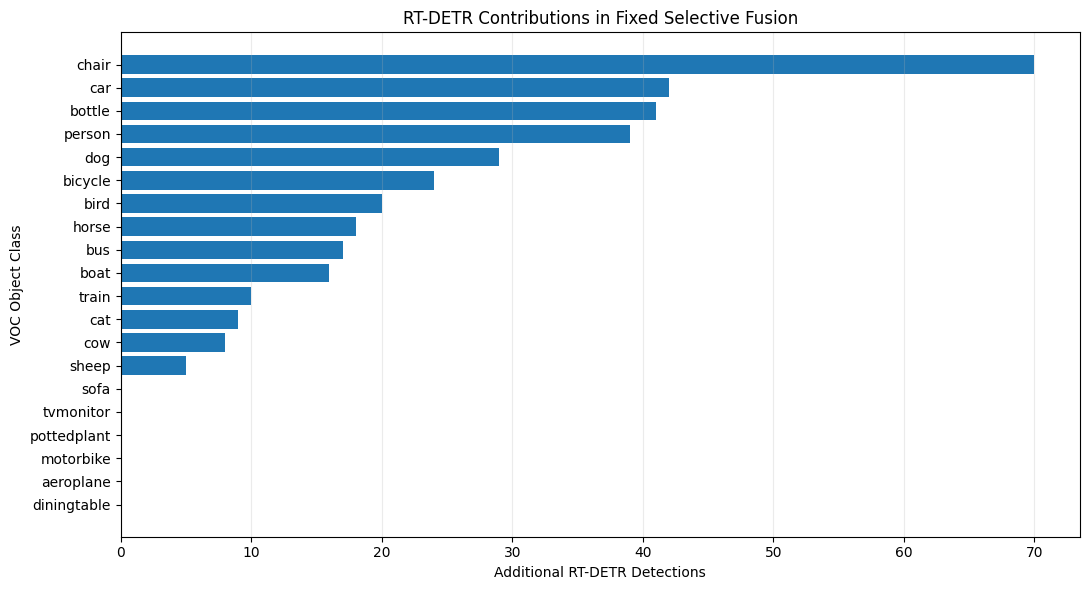

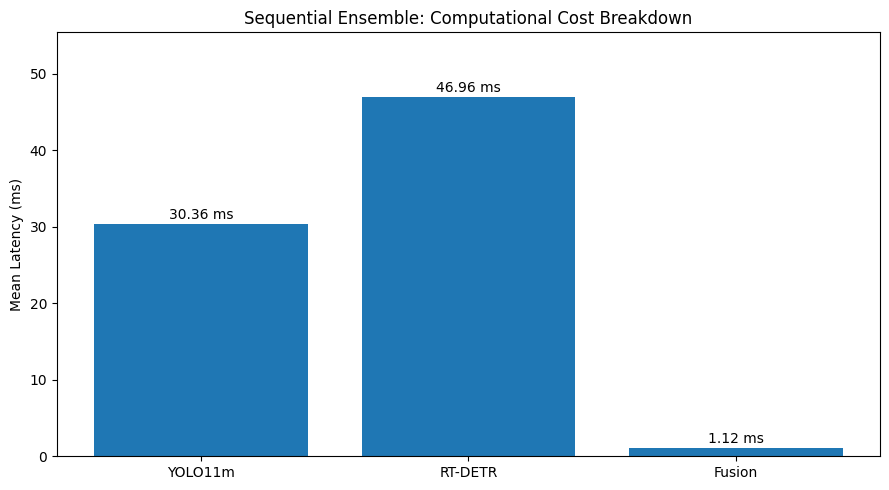

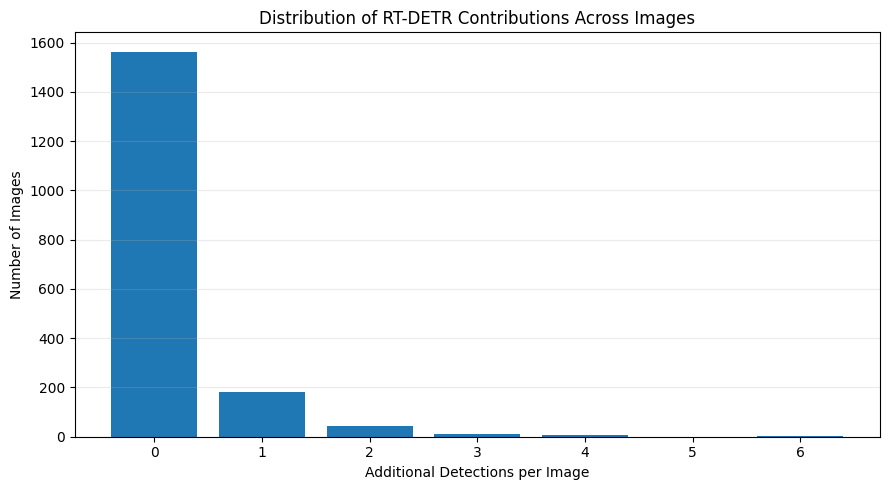


CELL 60 COMPLETED SUCCESSFULLY

Final-test images: 1810
Additional detections: 348
Images receiving additions: 246
Percentage receiving additions: 13.59%
Ensemble latency multiplier: 2.584x

Results saved to:
/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/evaluations/expert_contribution


In [ ]:
# ================================================================
# CELL 60: EXPERT CONTRIBUTION AND COMPUTATIONAL EFFICIENCY
# ================================================================

from pathlib import Path
from collections import Counter, defaultdict
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 80)
print("CELL 60: EXPERT CONTRIBUTION AND COMPUTATIONAL EFFICIENCY")
print("=" * 80)

# ------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

FINAL = ROOT / "evaluations" / "final_test"
EFFICIENCY = ROOT / "evaluations" / "efficiency"

OUT = ROOT / "evaluations" / "expert_contribution"
OUT.mkdir(parents=True, exist_ok=True)

YOLO_PATH = FINAL / "final_yolo11m_predictions.json"
RTDETR_PATH = FINAL / "final_rtdetr_predictions.json"
FUSION_PATH = FINAL / "final_selective_fusion_predictions.json"
GT_PATH = FINAL / "final_ground_truth.json"

CLASSWISE_PATH = FINAL / "final_classwise_ap_comparison.csv"

LATENCY_PATH = (
    EFFICIENCY / "final_inference_latency_summary.json"
)

required = [
    YOLO_PATH,
    RTDETR_PATH,
    FUSION_PATH,
    GT_PATH,
    CLASSWISE_PATH,
    LATENCY_PATH
]

for path in required:
    assert path.exists(), f"Missing required file: {path}"

print("\nAll required research files found.")

# ------------------------------------------------
# 2. LOAD SAVED RESULTS
# ------------------------------------------------

with open(YOLO_PATH) as f:
    yolo_preds = json.load(f)

with open(RTDETR_PATH) as f:
    rtdetr_preds = json.load(f)

with open(FUSION_PATH) as f:
    fusion_preds = json.load(f)

with open(GT_PATH) as f:
    gt = json.load(f)

with open(LATENCY_PATH) as f:
    latency = json.load(f)

classwise = pd.read_csv(CLASSWISE_PATH)

assert isinstance(yolo_preds, list)
assert isinstance(rtdetr_preds, list)
assert isinstance(fusion_preds, list)

image_ids = {
    img["id"] for img in gt["images"]
}

N = len(image_ids)

print("\n1. FINAL TEST DATASET")
print("Images:", N)
print("YOLO predictions:", len(yolo_preds))
print("RT-DETR predictions:", len(rtdetr_preds))
print("Fusion predictions:", len(fusion_preds))

assert N == 1810, "Unexpected final-test image count"

# ------------------------------------------------
# 3. IDENTIFY ADDED RT-DETR DETECTIONS
# ------------------------------------------------

# Our frozen fusion rule retains every YOLO prediction
# and appends selected RT-DETR predictions.
#
# Therefore, for each image:
#
# additional detections =
# fusion count - YOLO count

yolo_counts = Counter(
    p["image_id"] for p in yolo_preds
)

rtdetr_counts = Counter(
    p["image_id"] for p in rtdetr_preds
)

fusion_counts = Counter(
    p["image_id"] for p in fusion_preds
)

added_by_image = {}

for image_id in image_ids:

    added = (
        fusion_counts[image_id]
        - yolo_counts[image_id]
    )

    assert added >= 0, (
        f"Fusion has fewer predictions than YOLO "
        f"for image {image_id}"
    )

    added_by_image[image_id] = added

total_added = sum(added_by_image.values())

assert total_added == (
    len(fusion_preds) - len(yolo_preds)
)

print("\n2. RT-DETR CONTRIBUTION")

print("Total additional detections:", total_added)

print(
    "Average additional detections/image:",
    round(total_added / N, 4)
)

images_with_additions = sum(
    count > 0 for count in added_by_image.values()
)

images_without_additions = (
    N - images_with_additions
)

print(
    "Images receiving additional detections:",
    images_with_additions
)

print(
    "Images receiving no additional detections:",
    images_without_additions
)

print(
    "Percentage receiving additions:",
    round(100 * images_with_additions / N, 2),
    "%"
)

# ------------------------------------------------
# 4. CLASS-WISE CONTRIBUTION
# ------------------------------------------------

# For each image and class, the difference between
# fusion and YOLO counts gives the number of
# appended detections for that class.

def count_by_image_class(predictions):

    return Counter(
        (p["image_id"], p["category_id"])
        for p in predictions
    )

yolo_class_counts = count_by_image_class(yolo_preds)
fusion_class_counts = count_by_image_class(fusion_preds)

added_by_class = Counter()

all_keys = (
    set(yolo_class_counts)
    | set(fusion_class_counts)
)

for key in all_keys:

    added = (
        fusion_class_counts[key]
        - yolo_class_counts[key]
    )

    assert added >= 0, (
        f"Unexpected negative addition count: {key}"
    )

    added_by_class[key[1]] += added

assert sum(added_by_class.values()) == total_added

categories = {
    category["id"]: category["name"]
    for category in gt["categories"]
}

class_rows = []

for category_id in sorted(categories):

    class_rows.append({
        "category_id": category_id,
        "class_name": categories[category_id],
        "added_detections": added_by_class[category_id],
        "percentage_of_additions": (
            100 * added_by_class[category_id] / total_added
            if total_added else 0
        )
    })

contribution_df = pd.DataFrame(class_rows)

contribution_df = contribution_df.sort_values(
    "added_detections",
    ascending=False
).reset_index(drop=True)

print("\n3. CLASS-WISE RT-DETR CONTRIBUTION")

print(
    contribution_df.round(3).to_string(index=False)
)

# ------------------------------------------------
# 5. IMAGE-LEVEL CONTRIBUTION DISTRIBUTION
# ------------------------------------------------

distribution = Counter(added_by_image.values())

distribution_df = pd.DataFrame([
    {
        "added_detections_per_image": count,
        "number_of_images": frequency,
        "percentage_of_images": (
            100 * frequency / N
        )
    }
    for count, frequency in sorted(distribution.items())
])

print("\n4. IMAGE-LEVEL CONTRIBUTION DISTRIBUTION")

print(
    distribution_df.round(3).to_string(index=False)
)

# ------------------------------------------------
# 6. COMPUTATIONAL EFFICIENCY
# ------------------------------------------------

latency_rows = latency["results"]

latency_map = {
    row["component"]: row["mean_ms"]
    for row in latency_rows
}

yolo_ms = latency_map["YOLO11m"]
rtdetr_ms = latency_map["RT-DETR"]
fusion_ms = latency_map["Fusion_Postprocessing"]
ensemble_ms = latency_map["Sequential_Ensemble"]

assert all(
    value > 0
    for value in [yolo_ms, rtdetr_ms, fusion_ms, ensemble_ms]
)

rtdetr_share = (
    100 * rtdetr_ms / ensemble_ms
)

fusion_share = (
    100 * fusion_ms / ensemble_ms
)

yolo_share = (
    100 * yolo_ms / ensemble_ms
)

overhead = ensemble_ms - yolo_ms

print("\n5. COMPUTATIONAL EFFICIENCY")

print(f"YOLO11m latency: {yolo_ms:.3f} ms")
print(f"RT-DETR latency: {rtdetr_ms:.3f} ms")
print(f"Fusion overhead: {fusion_ms:.3f} ms")
print(f"Ensemble latency: {ensemble_ms:.3f} ms")

print("\nPercentage of ensemble latency:")
print(f"YOLO11m: {yolo_share:.2f}%")
print(f"RT-DETR: {rtdetr_share:.2f}%")
print(f"Fusion postprocessing: {fusion_share:.2f}%")

print(
    "\nAdditional latency over YOLO:",
    f"{overhead:.3f} ms"
)

print(
    "Latency multiplier:",
    f"{ensemble_ms / yolo_ms:.3f}x"
)

# ------------------------------------------------
# 7. RELATE CONTRIBUTIONS TO CLASS-WISE AP
# ------------------------------------------------

print("\n6. CLASS-WISE AP COMPARISON")

print("Available classwise columns:")
print(list(classwise.columns))

# Automatically identify relevant columns without
# assuming the previous CSV's exact column names.

def find_column(columns, candidates):

    normalized = {
        str(col).lower().replace("_", "").replace(" ", ""): col
        for col in columns
    }

    for candidate in candidates:

        key = candidate.lower().replace("_", "").replace(" ", "")

        if key in normalized:
            return normalized[key]

    return None

class_col = find_column(
    classwise.columns,
    ["class_name", "class", "category_name"]
)

delta_col = find_column(
    classwise.columns,
    [
        "delta_pp",
        "improvement_pp",
        "ap_improvement_pp",
        "ap_delta_pp",
        "delta_ap_pp"
    ]
)

if class_col is not None and delta_col is not None:

    ap_df = classwise[
        [class_col, delta_col]
    ].copy()

    ap_df.columns = [
        "class_name",
        "ap_improvement_pp"
    ]

    ap_df["class_name"] = (
        ap_df["class_name"].astype(str).str.lower()
    )

    contribution_df["class_name"] = (
        contribution_df["class_name"].astype(str).str.lower()
    )

    merged = contribution_df.merge(
        ap_df,
        on="class_name",
        how="left"
    )

    print(
        merged[
            [
                "class_name",
                "added_detections",
                "ap_improvement_pp"
            ]
        ].to_string(index=False)
    )

else:

    print(
        "Automatic AP column mapping unavailable. "
        "Contribution analysis remains valid."
    )

    merged = contribution_df.copy()

# ------------------------------------------------
# 8. VISUALIZATIONS
# ------------------------------------------------

print("\n7. GENERATING VISUALIZATIONS")

# Figure 1: Additional detections by class

fig, ax = plt.subplots(figsize=(11, 6))

plot_df = contribution_df.sort_values(
    "added_detections"
)

ax.barh(
    plot_df["class_name"],
    plot_df["added_detections"]
)

ax.set_xlabel("Additional RT-DETR Detections")
ax.set_ylabel("VOC Object Class")

ax.set_title(
    "RT-DETR Contributions in Fixed Selective Fusion"
)

ax.grid(axis="x", alpha=0.25)

plt.tight_layout()

fig.savefig(
    OUT / "classwise_expert_contribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Figure 2: Latency breakdown

fig, ax = plt.subplots(figsize=(9, 5))

components = [
    "YOLO11m",
    "RT-DETR",
    "Fusion"
]

times = [
    yolo_ms,
    rtdetr_ms,
    fusion_ms
]

ax.bar(components, times)

ax.set_ylabel("Mean Latency (ms)")

ax.set_title(
    "Sequential Ensemble: Computational Cost Breakdown"
)

for index, value in enumerate(times):

    ax.text(
        index,
        value + 0.6,
        f"{value:.2f} ms",
        ha="center"
    )

ax.set_ylim(0, max(times) * 1.18)

plt.tight_layout()

fig.savefig(
    OUT / "latency_breakdown.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Figure 3: Image-level contribution

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    distribution_df["added_detections_per_image"],
    distribution_df["number_of_images"]
)

ax.set_xlabel("Additional Detections per Image")
ax.set_ylabel("Number of Images")

ax.set_title(
    "Distribution of RT-DETR Contributions Across Images"
)

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

fig.savefig(
    OUT / "image_level_contribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 9. SAVE TABLES
# ------------------------------------------------

contribution_df.to_csv(
    OUT / "classwise_expert_contribution.csv",
    index=False
)

distribution_df.to_csv(
    OUT / "image_level_contribution_distribution.csv",
    index=False
)

merged.to_csv(
    OUT / "contribution_vs_ap.csv",
    index=False
)

# ------------------------------------------------
# 10. SAVE SUMMARY
# ------------------------------------------------

summary = {
    "experiment": "Expert Contribution and Efficiency Analysis",
    "dataset": "VOC2007 final held-out evaluation",
    "images": N,
    "illumination": "moderate gamma 2.2",
    "yolo_predictions": len(yolo_preds),
    "rtdetr_predictions": len(rtdetr_preds),
    "fusion_predictions": len(fusion_preds),
    "additional_detections": total_added,
    "images_with_additions": images_with_additions,
    "images_without_additions": images_without_additions,
    "percentage_images_with_additions": (
        100 * images_with_additions / N
    ),
    "mean_added_detections_per_image": (
        total_added / N
    ),
    "latency_ms": {
        "yolo": yolo_ms,
        "rtdetr": rtdetr_ms,
        "fusion": fusion_ms,
        "ensemble": ensemble_ms
    },
    "latency_multiplier": (
        ensemble_ms / yolo_ms
    ),
    "limitations": [
        "Accepted detections are not necessarily true positives.",
        "Latency measured on 100 development images.",
        "Expert contribution measured on 1810 final-test images.",
        "No learned or dynamic expert gating was evaluated.",
        "Inference latency is GPU and runtime dependent."
    ]
}

with open(
    OUT / "expert_contribution_summary.json",
    "w"
) as f:

    json.dump(summary, f, indent=4)

print("\n" + "=" * 80)
print("CELL 60 COMPLETED SUCCESSFULLY")
print("=" * 80)

print("\nFinal-test images:", N)
print("Additional detections:", total_added)
print("Images receiving additions:", images_with_additions)

print(
    "Percentage receiving additions:",
    f"{100 * images_with_additions / N:.2f}%"
)

print(
    "Ensemble latency multiplier:",
    f"{ensemble_ms / yolo_ms:.3f}x"
)

print("\nResults saved to:")
print(OUT)

CELL 61: VERIFIED CLASS-WISE EXPERT CONTRIBUTION

1. LOADED CLASS-WISE RESULTS
AP columns: ['class', 'gt_objects', 'YOLO_AP', 'RTDETR_AP', 'Fusion_AP', 'Fusion_Gain_pp', 'RTDETR_Boxes_Added']
Contribution columns: ['category_id', 'class_name', 'added_detections', 'percentage_of_additions']

2. CONTRIBUTION VERIFICATION
Matching classes: 20 / 20

3. CLASS-WISE AP COMPARISON
      class  gt_objects  YOLO_AP  RTDETR_AP  Fusion_AP  Fusion_Gain_pp  added_detections
        car         460  69.1935    70.9851    71.9730          2.7795                42
        bus          85  79.1923    75.6819    81.0887          1.8964                17
        dog         188  76.7731    73.6209    78.1553          1.3822                29
        cow          87  78.1707    77.5488    79.5243          1.3537                 8
        cat         137  83.4036    80.5773    84.6839          1.2803                 9
      horse         132  78.7614    77.6399    79.9959          1.2346                18
 

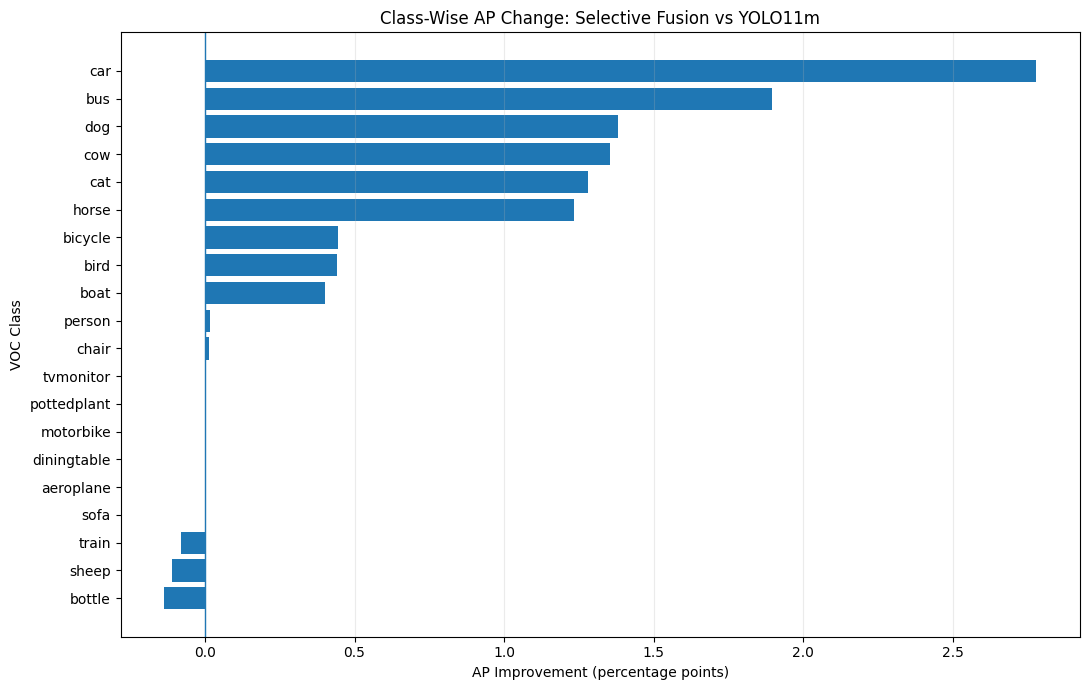

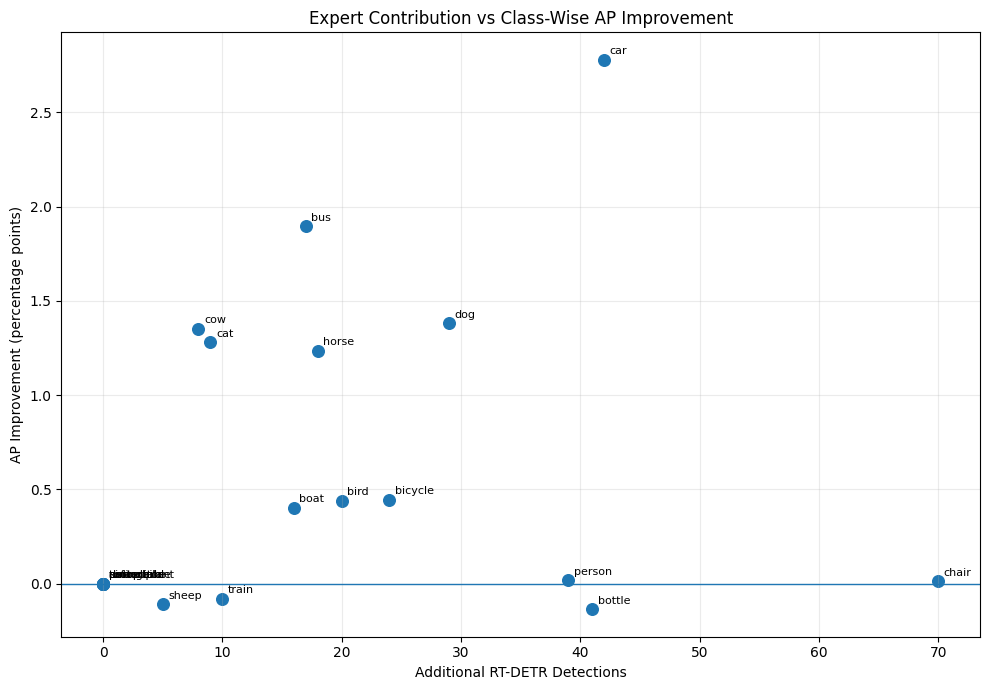


CELL 61 COMPLETED SUCCESSFULLY
Classes verified: 20
Matching counts: 20
Total added detections: 348
Pearson correlation: 0.21783831159902994
Spearman correlation: 0.42548262548262544

Results saved to: /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/evaluations/expert_contribution


In [ ]:
# ============================================================
# CELL 61: VERIFIED CLASS-WISE EXPERT CONTRIBUTION ANALYSIS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

print("=" * 75)
print("CELL 61: VERIFIED CLASS-WISE EXPERT CONTRIBUTION")
print("=" * 75)

# 1. PATHS
ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

FINAL = ROOT / "evaluations/final_test"
OUT = ROOT / "evaluations/expert_contribution"
OUT.mkdir(parents=True, exist_ok=True)

ap_path = FINAL / "final_classwise_ap_comparison.csv"
contrib_path = OUT / "classwise_expert_contribution.csv"

assert ap_path.exists(), f"Missing: {ap_path}"
assert contrib_path.exists(), f"Missing: {contrib_path}"

# 2. LOAD RESULTS
ap = pd.read_csv(ap_path)
contrib = pd.read_csv(contrib_path)

print("\n1. LOADED CLASS-WISE RESULTS")
print("AP columns:", list(ap.columns))
print("Contribution columns:", list(contrib.columns))

required = [
    "class", "gt_objects", "YOLO_AP", "RTDETR_AP",
    "Fusion_AP", "Fusion_Gain_pp", "RTDETR_Boxes_Added"
]

assert all(c in ap.columns for c in required)

# 3. NORMALIZE CLASS NAMES
ap["class_key"] = ap["class"].astype(str).str.strip().str.lower()
contrib["class_key"] = (
    contrib["class_name"].astype(str).str.strip().str.lower()
)

assert ap["class_key"].is_unique
assert contrib["class_key"].is_unique

# 4. MERGE AND VERIFY
merged = ap.merge(
    contrib[["class_key", "added_detections"]],
    on="class_key",
    how="outer",
    validate="one_to_one",
    indicator=True
)

assert (merged["_merge"] == "both").all(), (
    "Class-name mismatch detected."
)

merged.drop(columns="_merge", inplace=True)

merged["count_match"] = (
    merged["RTDETR_Boxes_Added"]
    == merged["added_detections"]
)

print("\n2. CONTRIBUTION VERIFICATION")
print(
    "Matching classes:",
    int(merged["count_match"].sum()),
    "/", len(merged)
)

if not merged["count_match"].all():
    print("\nMismatched classes:")
    print(
        merged.loc[
            ~merged["count_match"],
            ["class", "RTDETR_Boxes_Added", "added_detections"]
        ].to_string(index=False)
    )

# 5. CLASS-WISE AP COMPARISON
merged = merged.sort_values(
    "Fusion_Gain_pp", ascending=False
).reset_index(drop=True)

print("\n3. CLASS-WISE AP COMPARISON")

print(
    merged[
        [
            "class",
            "gt_objects",
            "YOLO_AP",
            "RTDETR_AP",
            "Fusion_AP",
            "Fusion_Gain_pp",
            "added_detections"
        ]
    ].round(4).to_string(index=False)
)

# 6. CLASSIFICATION OF AP CHANGES
EPS = 1e-9

improved = merged[merged["Fusion_Gain_pp"] > EPS]
declined = merged[merged["Fusion_Gain_pp"] < -EPS]
unchanged = merged[merged["Fusion_Gain_pp"].abs() <= EPS]

print("\n4. PERFORMANCE SUMMARY")
print("Improved classes:", len(improved))
print("Declined classes:", len(declined))
print("Unchanged classes:", len(unchanged))

print("\nTop improvements:")
print(
    improved[
        ["class", "Fusion_Gain_pp", "added_detections"]
    ].head(5).to_string(index=False)
)

print("\nClasses with negative AP changes:")
print(
    declined[
        ["class", "Fusion_Gain_pp", "added_detections"]
    ].to_string(index=False)
)

# 7. CORRELATION ANALYSIS
pearson = merged["added_detections"].corr(
    merged["Fusion_Gain_pp"], method="pearson"
)

spearman = merged["added_detections"].corr(
    merged["Fusion_Gain_pp"], method="spearman"
)

print("\n5. CONTRIBUTION VS ACCURACY")
print(f"Pearson correlation: {pearson:.4f}")
print(f"Spearman correlation: {spearman:.4f}")

# 8. FIGURE 1: CLASS-WISE AP IMPROVEMENTS
plot_df = merged.sort_values("Fusion_Gain_pp")

plt.figure(figsize=(11, 7))
plt.barh(plot_df["class"], plot_df["Fusion_Gain_pp"])
plt.axvline(0, linewidth=1)

plt.xlabel("AP Improvement (percentage points)")
plt.ylabel("VOC Class")
plt.title("Class-Wise AP Change: Selective Fusion vs YOLO11m")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUT / "verified_classwise_ap_improvements.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 9. FIGURE 2: CONTRIBUTION VS AP
plt.figure(figsize=(10, 7))

plt.scatter(
    merged["added_detections"],
    merged["Fusion_Gain_pp"],
    s=70
)

for _, row in merged.iterrows():
    plt.annotate(
        row["class"],
        (row["added_detections"], row["Fusion_Gain_pp"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

plt.axhline(0, linewidth=1)
plt.xlabel("Additional RT-DETR Detections")
plt.ylabel("AP Improvement (percentage points)")
plt.title("Expert Contribution vs Class-Wise AP Improvement")
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUT / "contribution_vs_ap_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 10. SAVE RESULTS
csv_path = OUT / "verified_classwise_contribution_analysis.csv"
merged.to_csv(csv_path, index=False)

summary = {
    "experiment": "Verified classwise expert contribution",
    "num_classes": int(len(merged)),
    "matching_counts": int(merged["count_match"].sum()),
    "total_added_detections": int(merged["added_detections"].sum()),
    "improved_classes": int(len(improved)),
    "declined_classes": int(len(declined)),
    "unchanged_classes": int(len(unchanged)),
    "pearson_correlation": (
        float(pearson) if pd.notna(pearson) else None
    ),
    "spearman_correlation": (
        float(spearman) if pd.notna(spearman) else None
    )
}

with open(
    OUT / "verified_classwise_contribution_summary.json", "w"
) as f:
    json.dump(summary, f, indent=4)

print("\n" + "=" * 75)
print("CELL 61 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("Classes verified:", len(merged))
print("Matching counts:", summary["matching_counts"])
print("Total added detections:", summary["total_added_detections"])
print("Pearson correlation:", summary["pearson_correlation"])
print("Spearman correlation:", summary["spearman_correlation"])

print("\nResults saved to:", OUT)

In [ ]:
# ============================================================
# CELL 62: RT-DETR CHECKPOINT AND CLASS-MAPPING AUDIT
# ============================================================

from pathlib import Path
from collections import Counter, defaultdict
import json
import pandas as pd
import numpy as np
import torch

from ultralytics import RTDETR

print("=" * 80)
print("CELL 62: RT-DETR CHECKPOINT AND CLASS-MAPPING AUDIT")
print("=" * 80)

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

CHECKPOINT = (
    ROOT / "checkpoints/RTDETR/"
    "rtdetr_l_memory_test/weights/best.pt"
)

FINAL = ROOT / "evaluations/final_test"

GT_PATH = FINAL / "final_ground_truth.json"
PRED_PATH = FINAL / "final_rtdetr_predictions.json"

OUT = ROOT / "evaluations/class_mapping_audit"
OUT.mkdir(parents=True, exist_ok=True)

for path in [CHECKPOINT, GT_PATH, PRED_PATH]:
    assert path.exists(), f"Missing: {path}"

# ------------------------------------------------------------
# 2. LOAD MODEL
# ------------------------------------------------------------

print("\n1. LOADING RT-DETR CHECKPOINT")

model = RTDETR(str(CHECKPOINT))

names = model.names

if isinstance(names, dict):
    model_names = {
        int(k): str(v)
        for k, v in names.items()
    }
else:
    model_names = {
        i: str(v)
        for i, v in enumerate(names)
    }

print("Number of model classes:", len(model_names))

print("\nCheckpoint class names:")

for index, name in sorted(model_names.items()):
    print(f"{index:2d}: {name}")

# ------------------------------------------------------------
# 3. LOAD EVALUATION DATA
# ------------------------------------------------------------

with open(GT_PATH) as f:
    gt = json.load(f)

with open(PRED_PATH) as f:
    predictions = json.load(f)

categories = {
    int(c["id"]): str(c["name"])
    for c in gt["categories"]
}

print("\n2. EVALUATION CATEGORY MAPPING")

for category_id, name in sorted(categories.items()):
    print(f"{category_id:2d}: {name}")

# ------------------------------------------------------------
# 4. VERIFY CLASS MAPPING
# ------------------------------------------------------------

print("\n3. CLASS-MAPPING VERIFICATION")

VOC_CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike",
    "person", "pottedplant", "sheep", "sofa",
    "train", "tvmonitor"
]

rows = []

for index, name in sorted(model_names.items()):

    expected_voc_id = index + 1

    expected_name = (
        VOC_CLASSES[index]
        if index < len(VOC_CLASSES)
        else None
    )

    actual_name = categories.get(expected_voc_id)

    rows.append({
        "model_index": index,
        "checkpoint_name": name,
        "expected_voc_id": expected_voc_id,
        "expected_voc_name": expected_name,
        "evaluation_name": actual_name,
        "name_match": (
            name.strip().lower()
            == str(actual_name).strip().lower()
        )
    })

mapping_df = pd.DataFrame(rows)

print(mapping_df.to_string(index=False))

print(
    "\nMatching names:",
    int(mapping_df["name_match"].sum()),
    "/",
    len(mapping_df)
)

# ------------------------------------------------------------
# 5. GROUND-TRUTH CLASS DISTRIBUTION
# ------------------------------------------------------------

print("\n4. GROUND-TRUTH CLASS DISTRIBUTION")

gt_counts = Counter(
    int(a["category_id"])
    for a in gt["annotations"]
)

pred_counts = Counter(
    int(p["category_id"])
    for p in predictions
)

class_rows = []

for category_id, name in sorted(categories.items()):

    class_predictions = [
        p for p in predictions
        if int(p["category_id"]) == category_id
    ]

    scores = np.asarray(
        [float(p["score"]) for p in class_predictions],
        dtype=float
    )

    class_rows.append({
        "category_id": category_id,
        "class_name": name,
        "gt_objects": gt_counts[category_id],
        "predictions": pred_counts[category_id],
        "predictions_conf_0_4": int(
            np.sum(scores >= 0.4)
        ),
        "max_confidence": (
            float(np.max(scores))
            if len(scores) else 0.0
        ),
        "mean_confidence": (
            float(np.mean(scores))
            if len(scores) else 0.0
        )
    })

distribution_df = pd.DataFrame(class_rows)

print(
    distribution_df.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 6. INSPECT SUSPICIOUS CLASSES
# ------------------------------------------------------------

print("\n5. SUSPICIOUS CLASS DIAGNOSTICS")

suspicious = [
    "sofa",
    "diningtable",
    "motorbike",
    "pottedplant",
    "tvmonitor"
]

suspicious_df = distribution_df[
    distribution_df["class_name"].isin(suspicious)
]

print(
    suspicious_df.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 7. VERIFY PREDICTION CATEGORY IDS
# ------------------------------------------------------------

print("\n6. PREDICTION CATEGORY VALIDATION")

invalid = [
    p for p in predictions
    if int(p["category_id"]) not in categories
]

print("Total predictions:", len(predictions))
print("Invalid category IDs:", len(invalid))

assert len(invalid) == 0, (
    "Saved predictions contain invalid category IDs."
)

# ------------------------------------------------------------
# 8. SAVE AUDIT RESULTS
# ------------------------------------------------------------

mapping_df.to_csv(
    OUT / "checkpoint_class_mapping.csv",
    index=False
)

distribution_df.to_csv(
    OUT / "rtdetr_class_distribution.csv",
    index=False
)

summary = {
    "experiment": "RT-DETR checkpoint class mapping audit",
    "checkpoint": str(CHECKPOINT),
    "num_checkpoint_classes": len(model_names),
    "num_evaluation_classes": len(categories),
    "matching_class_names": int(
        mapping_df["name_match"].sum()
    ),
    "total_predictions": len(predictions),
    "invalid_prediction_category_ids": len(invalid),
    "limitations": [
        "Matching class names do not prove that the model was trained with the correct class-index ordering.",
        "Saved predictions cannot independently verify training labels.",
        "Prediction counts and confidence scores alone cannot establish correct class assignments."
    ]
}

with open(
    OUT / "class_mapping_audit_summary.json",
    "w"
) as f:
    json.dump(summary, f, indent=4)

print("\n" + "=" * 80)
print("CELL 62 COMPLETED SUCCESSFULLY")
print("=" * 80)

print("Checkpoint classes:", len(model_names))
print("Evaluation classes:", len(categories))
print("Matching names:", summary["matching_class_names"])
print("Invalid category IDs:", len(invalid))

print("\nResults saved to:", OUT)

CELL 62: RT-DETR CHECKPOINT AND CLASS-MAPPING AUDIT

1. LOADING RT-DETR CHECKPOINT
Number of model classes: 20

Checkpoint class names:
 0: aeroplane
 1: bicycle
 2: bird
 3: boat
 4: bottle
 5: bus
 6: car
 7: cat
 8: chair
 9: cow
10: diningtable
11: dog
12: horse
13: motorbike
14: person
15: pottedplant
16: sheep
17: sofa
18: train
19: tvmonitor

2. EVALUATION CATEGORY MAPPING
 1: aeroplane
 2: bicycle
 3: bird
 4: boat
 5: bottle
 6: bus
 7: car
 8: cat
 9: chair
10: cow
11: diningtable
12: dog
13: horse
14: motorbike
15: person
16: pottedplant
17: sheep
18: sofa
19: train
20: tvmonitor

3. CLASS-MAPPING VERIFICATION
 model_index checkpoint_name  expected_voc_id expected_voc_name evaluation_name  name_match
           0       aeroplane                1         aeroplane       aeroplane        True
           1         bicycle                2           bicycle         bicycle        True
           2            bird                3              bird            bird        True
   

In [ ]:
# ============================================================
# CELL 63: RT-DETR TRAINING CONFIGURATION AUDIT
# ============================================================

from pathlib import Path
import json
import yaml
import pandas as pd
import torch

from ultralytics import RTDETR

print("=" * 80)
print("CELL 63: RT-DETR TRAINING CONFIGURATION AUDIT")
print("=" * 80)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

CHECKPOINT = (
    ROOT / "checkpoints/RTDETR/"
    "rtdetr_l_memory_test/weights/best.pt"
)

OUT = ROOT / "evaluations/class_mapping_audit"
OUT.mkdir(parents=True, exist_ok=True)

assert CHECKPOINT.exists(), "Checkpoint not found"

# ------------------------------------------------------------
# 1. LOAD MODEL
# ------------------------------------------------------------

print("\n1. LOADING CHECKPOINT")

model = RTDETR(str(CHECKPOINT))

print("Model task:", model.task)
print("Number of classes:", len(model.names))

# ------------------------------------------------------------
# 2. INSPECT TRAINING ARGUMENTS
# ------------------------------------------------------------

print("\n2. TRAINING ARGUMENTS")

args = getattr(model, "overrides", {})

if not isinstance(args, dict):
    args = vars(args) if hasattr(args, "__dict__") else {}

important_keys = [
    "model",
    "data",
    "epochs",
    "imgsz",
    "batch",
    "optimizer",
    "lr0",
    "lrf",
    "weight_decay",
    "patience",
    "seed",
    "pretrained",
    "single_cls",
    "classes",
    "fraction",
    "freeze",
    "resume"
]

for key in important_keys:
    print(f"{key:<20}: {args.get(key, 'Not recorded')}")

# ------------------------------------------------------------
# 3. INSPECT MODEL METADATA
# ------------------------------------------------------------

print("\n3. MODEL METADATA")

inner_model = model.model

print(
    "Model class:",
    type(inner_model).__name__
)

print(
    "Model names:",
    getattr(inner_model, "names", None)
)

print(
    "Model stride:",
    getattr(inner_model, "stride", None)
)

print(
    "Model YAML:",
    getattr(inner_model, "yaml", None)
)

# ------------------------------------------------------------
# 4. SEARCH FOR DATASET CONFIGURATIONS
# ------------------------------------------------------------

print("\n4. SEARCHING FOR DATASET CONFIGURATIONS")

search_roots = [
    ROOT / "configs",
    ROOT / "datasets",
    ROOT / "logs"
]

yaml_files = []

for search_root in search_roots:

    if not search_root.exists():
        continue

    for pattern in ["*.yaml", "*.yml"]:
        yaml_files.extend(search_root.rglob(pattern))

print("YAML files found:", len(yaml_files))

for path in yaml_files[:40]:

    print("\nFILE:", path.relative_to(ROOT))

    try:
        with open(path) as f:
            data = yaml.safe_load(f)

        if isinstance(data, dict):

            relevant = {
                k: data[k]
                for k in [
                    "path", "train", "val",
                    "test", "nc", "names"
                ]
                if k in data
            }

            if relevant:
                print(relevant)

    except Exception as e:
        print("Could not parse:", str(e))

# ------------------------------------------------------------
# 5. SEARCH FOR TRAINING RESULTS
# ------------------------------------------------------------

print("\n5. SEARCHING FOR RT-DETR TRAINING LOGS")

log_matches = []

for search_root in [
    ROOT / "logs",
    ROOT / "results",
    ROOT / "checkpoints"
]:

    if not search_root.exists():
        continue

    for filename in [
        "args.yaml",
        "results.csv",
        "results.json"
    ]:

        log_matches.extend(
            search_root.rglob(filename)
        )

print("Training metadata files:", len(log_matches))

for path in log_matches[:40]:
    print(path.relative_to(ROOT))

# ------------------------------------------------------------
# 6. SAVE AUDIT
# ------------------------------------------------------------

def safe_value(value):

    if value is None or isinstance(
        value, (str, int, float, bool)
    ):
        return value

    if isinstance(value, (list, tuple)):
        return [safe_value(v) for v in value]

    if isinstance(value, dict):
        return {
            str(k): safe_value(v)
            for k, v in value.items()
        }

    return str(value)

summary = {
    "checkpoint": str(CHECKPOINT),
    "model_task": str(model.task),
    "num_classes": len(model.names),
    "training_arguments": safe_value(args),
    "yaml_files_found": [
        str(p.relative_to(ROOT))
        for p in yaml_files
    ],
    "training_metadata_files": [
        str(p.relative_to(ROOT))
        for p in log_matches
    ]
}

output_path = OUT / "rtdetr_training_configuration_audit.json"

with open(output_path, "w") as f:
    json.dump(summary, f, indent=4)

print("\n" + "=" * 80)
print("CELL 63 COMPLETED SUCCESSFULLY")
print("=" * 80)

print("Checkpoint classes:", len(model.names))
print("Dataset YAML files:", len(yaml_files))
print("Training metadata files:", len(log_matches))

print("\nSaved audit:", output_path)

CELL 63: RT-DETR TRAINING CONFIGURATION AUDIT

1. LOADING CHECKPOINT
Model task: detect
Number of classes: 20

2. TRAINING ARGUMENTS
model               : /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr_l_memory_test/weights/best.pt
data                : /content/drive/MyDrive/LowLight_Ensemble_MoE/configs/moe_rtdetr_voc2007.yaml
epochs              : Not recorded
imgsz               : 416
batch               : Not recorded
optimizer           : Not recorded
lr0                 : Not recorded
lrf                 : Not recorded
weight_decay        : Not recorded
patience            : Not recorded
seed                : Not recorded
pretrained          : Not recorded
single_cls          : False
classes             : Not recorded
fraction            : Not recorded
freeze              : Not recorded
resume              : Not recorded

3. MODEL METADATA
Model class: RTDETRDetectionModel
Model names: {0: 'aeroplane', 1: 'bicycle', 2: 'bird', 3: 'boat', 4

In [ ]:
# ============================================================
# CELL 64: RT-DETR TRAINING EXPERIMENT COMPARISON
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import yaml
import json

print("=" * 80)
print("CELL 64: RT-DETR TRAINING EXPERIMENT COMPARISON")
print("=" * 80)

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

RTDETR_ROOT = ROOT / "checkpoints/RTDETR"

RUNS = {
    "memory_test": RTDETR_ROOT / "rtdetr_l_memory_test",
    "voc2007_full": RTDETR_ROOT / "rtdetr_l_voc2007_full"
}

OUT = ROOT / "evaluations/class_mapping_audit"
OUT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD TRAINING ARGUMENTS
# ------------------------------------------------------------

print("\n1. TRAINING CONFIGURATION COMPARISON")

important_keys = [
    "model",
    "data",
    "epochs",
    "imgsz",
    "batch",
    "optimizer",
    "lr0",
    "lrf",
    "weight_decay",
    "patience",
    "seed",
    "pretrained",
    "single_cls",
    "fraction",
    "freeze",
    "resume",
    "amp",
    "cache",
    "workers",
    "device"
]

all_args = {}
comparison_rows = []

for run_name, run_dir in RUNS.items():

    args_path = run_dir / "args.yaml"

    if args_path.exists():

        with open(args_path) as f:
            args = yaml.safe_load(f) or {}

        if not isinstance(args, dict):
            args = {}

    else:
        args = {}

    all_args[run_name] = args

    print(f"\nRUN: {run_name}")
    print("Directory:", run_dir)

    for key in important_keys:
        print(f"{key:<18}: {args.get(key, 'Not recorded')}")

for key in important_keys:

    comparison_rows.append({
        "parameter": key,
        "memory_test": str(
            all_args["memory_test"].get(key, "Not recorded")
        ),
        "voc2007_full": str(
            all_args["voc2007_full"].get(key, "Not recorded")
        )
    })

config_df = pd.DataFrame(comparison_rows)

# ------------------------------------------------------------
# 3. INSPECT TRAINING HISTORY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("2. TRAINING HISTORY COMPARISON")
print("=" * 80)

histories = {}
summary_rows = []

for run_name, run_dir in RUNS.items():

    csv_path = run_dir / "results.csv"

    print(f"\nRUN: {run_name}")

    if not csv_path.exists():

        print("No results.csv found.")
        histories[run_name] = None
        continue

    df = pd.read_csv(csv_path)

    df.columns = df.columns.str.strip()

    histories[run_name] = df

    print("Recorded epochs:", len(df))
    print("Available columns:")
    print(list(df.columns))

    print("\nLast 5 training records:")
    print(df.tail(5).to_string(index=False))

    map50_col = next(
        (
            c for c in df.columns
            if "metrics/mAP50(B)" in c
        ),
        None
    )

    map5095_col = next(
        (
            c for c in df.columns
            if "metrics/mAP50-95(B)" in c
        ),
        None
    )

    epoch_col = "epoch" if "epoch" in df.columns else None

    best_map50 = None
    best_map5095 = None
    best_epoch = None

    if map50_col:

        values = pd.to_numeric(
            df[map50_col], errors="coerce"
        )

        if values.notna().any():
            best_map50 = float(values.max())

    if map5095_col:

        values = pd.to_numeric(
            df[map5095_col], errors="coerce"
        )

        if values.notna().any():

            best_idx = values.idxmax()

            best_map5095 = float(values.loc[best_idx])

            if epoch_col:
                best_epoch = int(df.loc[best_idx, epoch_col])

    summary_rows.append({
        "run": run_name,
        "recorded_epochs": len(df),
        "configured_epochs": all_args[run_name].get(
            "epochs"
        ),
        "best_validation_mAP50": best_map50,
        "best_validation_mAP50_95": best_map5095,
        "best_epoch": best_epoch
    })

# ------------------------------------------------------------
# 4. CHECK CHECKPOINT AVAILABILITY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("3. CHECKPOINT AVAILABILITY")
print("=" * 80)

checkpoint_rows = []

for run_name, run_dir in RUNS.items():

    weights_dir = run_dir / "weights"

    print(f"\nRUN: {run_name}")

    if not weights_dir.exists():
        print("Weights directory missing.")
        continue

    checkpoints = sorted(weights_dir.glob("*.pt"))

    if not checkpoints:
        print("No .pt checkpoints found.")

    for checkpoint in checkpoints:

        size_mb = checkpoint.stat().st_size / (1024 ** 2)

        print(
            f"{checkpoint.name}: {size_mb:.2f} MB"
        )

        checkpoint_rows.append({
            "run": run_name,
            "checkpoint": checkpoint.name,
            "path": str(checkpoint),
            "size_mb": round(size_mb, 2)
        })

# ------------------------------------------------------------
# 5. PRINT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("4. EXPERIMENT SUMMARY")
print("=" * 80)

summary_df = pd.DataFrame(summary_rows)

if not summary_df.empty:
    print(summary_df.to_string(index=False))
else:
    print("No training histories available.")

# ------------------------------------------------------------
# 6. SAVE RESULTS
# ------------------------------------------------------------

config_df.to_csv(
    OUT / "rtdetr_training_config_comparison.csv",
    index=False
)

summary_df.to_csv(
    OUT / "rtdetr_training_history_comparison.csv",
    index=False
)

checkpoint_df = pd.DataFrame(
    checkpoint_rows,
    columns=["run", "checkpoint", "path", "size_mb"]
)

checkpoint_df.to_csv(
    OUT / "rtdetr_available_checkpoints.csv",
    index=False
)

report = {
    "experiment": "RT-DETR training run comparison",
    "runs": list(RUNS.keys()),
    "available_checkpoints": checkpoint_rows,
    "training_summaries": summary_rows
}

with open(
    OUT / "rtdetr_training_comparison_summary.json",
    "w"
) as f:
    json.dump(report, f, indent=4, default=str)

print("\n" + "=" * 80)
print("CELL 64 COMPLETED SUCCESSFULLY")
print("=" * 80)

print("Runs examined:", len(RUNS))
print("Checkpoints found:", len(checkpoint_rows))

print("\nResults saved to:", OUT)

CELL 64: RT-DETR TRAINING EXPERIMENT COMPARISON

1. TRAINING CONFIGURATION COMPARISON

RUN: memory_test
Directory: /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr_l_memory_test
model             : /content/drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr-l_pretrained.pt
data              : /content/drive/MyDrive/LowLight_Ensemble_MoE/configs/moe_rtdetr_voc2007.yaml
epochs            : 1
imgsz             : 416
batch             : 2
optimizer         : AdamW
lr0               : 0.0001
lrf               : 0.01
weight_decay      : 0.0005
patience          : 100
seed              : 42
pretrained        : True
single_cls        : False
fraction          : 1.0
freeze            : None
resume            : False
amp               : True
cache             : False
workers           : 2
device            : 0

RUN: voc2007_full
Directory: /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr_l_voc2007_full
model  

In [ ]:
# ============================================================
# CELL 64: RT-DETR TRAINING EXPERIMENT COMPARISON
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import yaml
import json

print("=" * 80)
print("CELL 64: RT-DETR TRAINING EXPERIMENT COMPARISON")
print("=" * 80)

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

RTDETR_ROOT = ROOT / "checkpoints/RTDETR"

RUNS = {
    "memory_test": RTDETR_ROOT / "rtdetr_l_memory_test",
    "voc2007_full": RTDETR_ROOT / "rtdetr_l_voc2007_full"
}

OUT = ROOT / "evaluations/class_mapping_audit"
OUT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD TRAINING ARGUMENTS
# ------------------------------------------------------------

print("\n1. TRAINING CONFIGURATION COMPARISON")

important_keys = [
    "model",
    "data",
    "epochs",
    "imgsz",
    "batch",
    "optimizer",
    "lr0",
    "lrf",
    "weight_decay",
    "patience",
    "seed",
    "pretrained",
    "single_cls",
    "fraction",
    "freeze",
    "resume",
    "amp",
    "cache",
    "workers",
    "device"
]

all_args = {}
comparison_rows = []

for run_name, run_dir in RUNS.items():

    args_path = run_dir / "args.yaml"

    if args_path.exists():

        with open(args_path) as f:
            args = yaml.safe_load(f) or {}

        if not isinstance(args, dict):
            args = {}

    else:
        args = {}

    all_args[run_name] = args

    print(f"\nRUN: {run_name}")
    print("Directory:", run_dir)

    for key in important_keys:
        print(f"{key:<18}: {args.get(key, 'Not recorded')}")

for key in important_keys:

    comparison_rows.append({
        "parameter": key,
        "memory_test": str(
            all_args["memory_test"].get(key, "Not recorded")
        ),
        "voc2007_full": str(
            all_args["voc2007_full"].get(key, "Not recorded")
        )
    })

config_df = pd.DataFrame(comparison_rows)

# ------------------------------------------------------------
# 3. INSPECT TRAINING HISTORY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("2. TRAINING HISTORY COMPARISON")
print("=" * 80)

histories = {}
summary_rows = []

for run_name, run_dir in RUNS.items():

    csv_path = run_dir / "results.csv"

    print(f"\nRUN: {run_name}")

    if not csv_path.exists():

        print("No results.csv found.")
        histories[run_name] = None
        continue

    df = pd.read_csv(csv_path)

    df.columns = df.columns.str.strip()

    histories[run_name] = df

    print("Recorded epochs:", len(df))
    print("Available columns:")
    print(list(df.columns))

    print("\nLast 5 training records:")
    print(df.tail(5).to_string(index=False))

    map50_col = next(
        (
            c for c in df.columns
            if "metrics/mAP50(B)" in c
        ),
        None
    )

    map5095_col = next(
        (
            c for c in df.columns
            if "metrics/mAP50-95(B)" in c
        ),
        None
    )

    epoch_col = "epoch" if "epoch" in df.columns else None

    best_map50 = None
    best_map5095 = None
    best_epoch = None

    if map50_col:

        values = pd.to_numeric(
            df[map50_col], errors="coerce"
        )

        if values.notna().any():
            best_map50 = float(values.max())

    if map5095_col:

        values = pd.to_numeric(
            df[map5095_col], errors="coerce"
        )

        if values.notna().any():

            best_idx = values.idxmax()

            best_map5095 = float(values.loc[best_idx])

            if epoch_col:
                best_epoch = int(df.loc[best_idx, epoch_col])

    summary_rows.append({
        "run": run_name,
        "recorded_epochs": len(df),
        "configured_epochs": all_args[run_name].get(
            "epochs"
        ),
        "best_validation_mAP50": best_map50,
        "best_validation_mAP50_95": best_map5095,
        "best_epoch": best_epoch
    })

# ------------------------------------------------------------
# 4. CHECK CHECKPOINT AVAILABILITY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("3. CHECKPOINT AVAILABILITY")
print("=" * 80)

checkpoint_rows = []

for run_name, run_dir in RUNS.items():

    weights_dir = run_dir / "weights"

    print(f"\nRUN: {run_name}")

    if not weights_dir.exists():
        print("Weights directory missing.")
        continue

    checkpoints = sorted(weights_dir.glob("*.pt"))

    if not checkpoints:
        print("No .pt checkpoints found.")

    for checkpoint in checkpoints:

        size_mb = checkpoint.stat().st_size / (1024 ** 2)

        print(
            f"{checkpoint.name}: {size_mb:.2f} MB"
        )

        checkpoint_rows.append({
            "run": run_name,
            "checkpoint": checkpoint.name,
            "path": str(checkpoint),
            "size_mb": round(size_mb, 2)
        })

# ------------------------------------------------------------
# 5. PRINT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("4. EXPERIMENT SUMMARY")
print("=" * 80)

summary_df = pd.DataFrame(summary_rows)

if not summary_df.empty:
    print(summary_df.to_string(index=False))
else:
    print("No training histories available.")

# ------------------------------------------------------------
# 6. SAVE RESULTS
# ------------------------------------------------------------

config_df.to_csv(
    OUT / "rtdetr_training_config_comparison.csv",
    index=False
)

summary_df.to_csv(
    OUT / "rtdetr_training_history_comparison.csv",
    index=False
)

checkpoint_df = pd.DataFrame(
    checkpoint_rows,
    columns=["run", "checkpoint", "path", "size_mb"]
)

checkpoint_df.to_csv(
    OUT / "rtdetr_available_checkpoints.csv",
    index=False
)

report = {
    "experiment": "RT-DETR training run comparison",
    "runs": list(RUNS.keys()),
    "available_checkpoints": checkpoint_rows,
    "training_summaries": summary_rows
}

with open(
    OUT / "rtdetr_training_comparison_summary.json",
    "w"
) as f:
    json.dump(report, f, indent=4, default=str)

print("\n" + "=" * 80)
print("CELL 64 COMPLETED SUCCESSFULLY")
print("=" * 80)

print("Runs examined:", len(RUNS))
print("Checkpoints found:", len(checkpoint_rows))

print("\nResults saved to:", OUT)

CELL 64: RT-DETR TRAINING EXPERIMENT COMPARISON

1. TRAINING CONFIGURATION COMPARISON

RUN: memory_test
Directory: /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr_l_memory_test
model             : /content/drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr-l_pretrained.pt
data              : /content/drive/MyDrive/LowLight_Ensemble_MoE/configs/moe_rtdetr_voc2007.yaml
epochs            : 1
imgsz             : 416
batch             : 2
optimizer         : AdamW
lr0               : 0.0001
lrf               : 0.01
weight_decay      : 0.0005
patience          : 100
seed              : 42
pretrained        : True
single_cls        : False
fraction          : 1.0
freeze            : None
resume            : False
amp               : True
cache             : False
workers           : 2
device            : 0

RUN: voc2007_full
Directory: /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr_l_voc2007_full
model  

In [ ]:
# ============================================================
# CELL 65: RT-DETR CHECKPOINT INTEGRITY AUDIT
# ============================================================

from pathlib import Path
import torch
import pandas as pd
import json
import gc

print("=" * 80)
print("CELL 65: RT-DETR CHECKPOINT INTEGRITY AUDIT")
print("=" * 80)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

RT_ROOT = ROOT / "checkpoints/RTDETR"

RUNS = {
    "memory_test": RT_ROOT / "rtdetr_l_memory_test",
    "voc2007_full": RT_ROOT / "rtdetr_l_voc2007_full"
}

OUT = ROOT / "evaluations/class_mapping_audit"
OUT.mkdir(parents=True, exist_ok=True)

records = []

for run_name, run_dir in RUNS.items():

    print("\n" + "-" * 80)
    print("RUN:", run_name)
    print("-" * 80)

    for filename in ["best.pt", "last.pt"]:

        path = run_dir / "weights" / filename

        if not path.exists():
            print(filename, ": NOT FOUND")
            continue

        print("\nCHECKPOINT:", filename)
        print(
            "File size:",
            round(path.stat().st_size / (1024 ** 2), 2),
            "MB"
        )

        try:
            # Trusted project checkpoints only.
            ckpt = torch.load(
                path,
                map_location="cpu",
                weights_only=False
            )

            if not isinstance(ckpt, dict):
                print("Unexpected checkpoint format.")
                continue

            print("Checkpoint keys:", list(ckpt.keys()))

            epoch = ckpt.get("epoch")
            best_fitness = ckpt.get("best_fitness")

            optimizer = ckpt.get("optimizer")

            has_optimizer = optimizer is not None

            model_obj = ckpt.get("ema")

            if model_obj is None:
                model_obj = ckpt.get("model")

            model_type = (
                type(model_obj).__name__
                if model_obj is not None
                else "Missing"
            )

            model_names = getattr(
                model_obj, "names", None
            )

            state = (
                model_obj.state_dict()
                if model_obj is not None
                else {}
            )

            parameter_count = sum(
                tensor.numel()
                for tensor in state.values()
                if torch.is_tensor(tensor)
            )

            print("Saved epoch:", epoch)
            print("Best fitness:", best_fitness)
            print("Optimizer state present:", has_optimizer)
            print("Model type:", model_type)
            print("State tensor elements:", parameter_count)
            print("Model class names:", model_names)

            records.append({
                "run": run_name,
                "checkpoint": filename,
                "size_mb": round(
                    path.stat().st_size / (1024 ** 2), 2
                ),
                "saved_epoch": epoch,
                "best_fitness": (
                    float(best_fitness)
                    if best_fitness is not None
                    else None
                ),
                "optimizer_present": has_optimizer,
                "model_type": model_type,
                "state_tensor_elements": parameter_count,
                "num_classes": (
                    len(model_names)
                    if model_names is not None
                    else None
                )
            })

            del ckpt, model_obj, state
            gc.collect()

        except Exception as e:
            print(
                "Checkpoint inspection failed:",
                type(e).__name__,
                str(e)[:500]
            )

print("\n" + "=" * 80)
print("CHECKPOINT COMPARISON SUMMARY")
print("=" * 80)

df = pd.DataFrame(records)

if not df.empty:
    print(df.to_string(index=False))

    df.to_csv(
        OUT / "rtdetr_checkpoint_integrity_comparison.csv",
        index=False
    )

    summary = df.where(
        pd.notnull(df), None
    ).to_dict(orient="records")

    with open(
        OUT / "rtdetr_checkpoint_integrity_summary.json",
        "w"
    ) as f:
        json.dump(
            summary,
            f,
            indent=4,
            default=str
        )

print("\n" + "=" * 80)
print("CELL 65 COMPLETED")
print("=" * 80)

print("Checkpoints inspected:", len(records))
print("Results saved to:", OUT)

CELL 65: RT-DETR CHECKPOINT INTEGRITY AUDIT

--------------------------------------------------------------------------------
RUN: memory_test
--------------------------------------------------------------------------------

CHECKPOINT: best.pt
File size: 63.18 MB
Checkpoint keys: ['date', 'version', 'license', 'docs', 'epoch', 'best_fitness', 'stopper', 'model', 'ema', 'updates', 'modelopt', 'optimizer', 'scaler', 'train_args', 'train_metrics', 'train_results', 'git']
Saved epoch: -1
Best fitness: None
Optimizer state present: False
Model type: RTDETRDetectionModel
State tensor elements: 32914498
Model class names: {0: 'aeroplane', 1: 'bicycle', 2: 'bird', 3: 'boat', 4: 'bottle', 5: 'bus', 6: 'car', 7: 'cat', 8: 'chair', 9: 'cow', 10: 'diningtable', 11: 'dog', 12: 'horse', 13: 'motorbike', 14: 'person', 15: 'pottedplant', 16: 'sheep', 17: 'sofa', 18: 'train', 19: 'tvmonitor'}

CHECKPOINT: last.pt
File size: 63.18 MB
Checkpoint keys: ['date', 'version', 'license', 'docs', 'epoch', 'bes

In [ ]:
# ============================================================
# CELL 66: ILLUMINATION-AWARE MoE DEVELOPMENT DATA AUDIT
# ============================================================

from pathlib import Path
from collections import Counter
import json
import pandas as pd
import numpy as np

print("=" * 85)
print("CELL 66: ILLUMINATION-AWARE MoE DEVELOPMENT DATA AUDIT")
print("=" * 85)

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

EVAL = ROOT / "evaluations"
FINAL = EVAL / "final_test"

OUT = EVAL / "illumination_moe"
OUT.mkdir(parents=True, exist_ok=True)

assert ROOT.exists(), "Project root not found."
assert FINAL.exists(), "Final-test directory not found."

print("\n1. PROJECT VERIFICATION")
print("Project root:", ROOT)
print("Evaluation directory:", EVAL)

# ------------------------------------------------------------
# 2. IDENTIFY AVAILABLE DEVELOPMENT EXPERIMENTS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("2. AVAILABLE EVALUATION DIRECTORIES")
print("=" * 85)

evaluation_dirs = sorted(
    p for p in EVAL.rglob("*")
    if p.is_dir()
)

for directory in evaluation_dirs[:100]:
    print(directory.relative_to(ROOT))

print("\nTotal evaluation directories:", len(evaluation_dirs))

# ------------------------------------------------------------
# 3. FIND RELEVANT JSON FILES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. DEVELOPMENT ANNOTATION AND PREDICTION FILES")
print("=" * 85)

json_files = sorted(EVAL.rglob("*.json"))

candidate_files = []

for path in json_files:

    relative = str(path.relative_to(ROOT)).lower()

    if "final_test" in relative:
        continue

    keywords = [
        "ground_truth",
        "prediction",
        "dev",
        "validation",
        "illumination",
        "ensemble"
    ]

    if any(k in relative for k in keywords):
        candidate_files.append(path)

for path in candidate_files[:100]:

    size_mb = path.stat().st_size / (1024 ** 2)

    print(
        f"{str(path.relative_to(ROOT)):<90} "
        f"{size_mb:8.2f} MB"
    )

print("\nCandidate JSON files:", len(candidate_files))

# ------------------------------------------------------------
# 4. LOAD FINAL-TEST IMAGE IDENTIFIERS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. FINAL-TEST IMAGE IDENTIFIERS")
print("=" * 85)

final_gt_path = FINAL / "final_ground_truth.json"

assert final_gt_path.exists()

with open(final_gt_path) as f:
    final_gt = json.load(f)

assert isinstance(final_gt, dict)
assert "images" in final_gt

final_image_ids = {
    str(image["id"])
    for image in final_gt["images"]
}

final_filenames = {
    Path(str(image.get("file_name", ""))).stem
    for image in final_gt["images"]
    if image.get("file_name")
}

print("Final-test images:", len(final_gt["images"]))
print("Unique final-test IDs:", len(final_image_ids))
print("Unique final-test filename stems:", len(final_filenames))

# ------------------------------------------------------------
# 5. AUDIT DEVELOPMENT GROUND-TRUTH FILES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("5. DEVELOPMENT GROUND-TRUTH AUDIT")
print("=" * 85)

gt_candidates = [
    p for p in candidate_files
    if "ground_truth" in p.name.lower()
]

gt_rows = []

for path in gt_candidates:

    try:

        with open(path) as f:
            data = json.load(f)

        if not isinstance(data, dict):
            continue

        images = data.get("images", [])
        annotations = data.get("annotations", [])
        categories = data.get("categories", [])

        if not isinstance(images, list):
            continue

        dev_ids = {
            str(image["id"])
            for image in images
            if "id" in image
        }

        dev_filenames = {
            Path(str(image.get("file_name", ""))).stem
            for image in images
            if image.get("file_name")
        }

        id_overlap = len(
            dev_ids.intersection(final_image_ids)
        )

        filename_overlap = len(
            dev_filenames.intersection(final_filenames)
        )

        gt_rows.append({
            "path": str(path.relative_to(ROOT)),
            "images": len(images),
            "annotations": len(annotations),
            "categories": len(categories),
            "overlap_by_id": id_overlap,
            "overlap_by_filename": filename_overlap
        })

    except Exception as e:

        print(
            "Could not inspect:",
            path.name,
            type(e).__name__,
            str(e)[:150]
        )

gt_df = pd.DataFrame(
    gt_rows,
    columns=[
        "path",
        "images",
        "annotations",
        "categories",
        "overlap_by_id",
        "overlap_by_filename"
    ]
)

if not gt_df.empty:
    print(gt_df.to_string(index=False))
else:
    print("No readable development ground-truth files found.")

# ------------------------------------------------------------
# 6. AUDIT SAVED PREDICTION FILES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("6. SAVED DEVELOPMENT PREDICTIONS")
print("=" * 85)

prediction_candidates = [
    p for p in candidate_files
    if "prediction" in p.name.lower()
]

prediction_rows = []

for path in prediction_candidates:

    try:

        with open(path) as f:
            data = json.load(f)

        if isinstance(data, list):

            prediction_count = len(data)

            image_ids = {
                str(p["image_id"])
                for p in data
                if isinstance(p, dict)
                and "image_id" in p
            }

            categories = {
                str(p["category_id"])
                for p in data
                if isinstance(p, dict)
                and "category_id" in p
            }

        elif isinstance(data, dict):

            records = data.get("predictions", [])

            if not isinstance(records, list):
                continue

            prediction_count = len(records)

            image_ids = {
                str(p["image_id"])
                for p in records
                if isinstance(p, dict)
                and "image_id" in p
            }

            categories = {
                str(p["category_id"])
                for p in records
                if isinstance(p, dict)
                and "category_id" in p
            }

        else:
            continue

        prediction_rows.append({
            "path": str(path.relative_to(ROOT)),
            "predictions": prediction_count,
            "unique_image_ids": len(image_ids),
            "unique_classes": len(categories),
            "final_test_id_overlap": len(
                image_ids.intersection(final_image_ids)
            )
        })

    except Exception as e:

        print(
            "Could not inspect:",
            path.name,
            type(e).__name__,
            str(e)[:150]
        )

pred_df = pd.DataFrame(
    prediction_rows,
    columns=[
        "path",
        "predictions",
        "unique_image_ids",
        "unique_classes",
        "final_test_id_overlap"
    ]
)

if not pred_df.empty:

    print(pred_df.to_string(index=False))

else:

    print("No readable development prediction files found.")

# ------------------------------------------------------------
# 7. INSPECT DEVELOPMENT IMAGE DIRECTORIES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("7. DEVELOPMENT IMAGE AVAILABILITY")
print("=" * 85)

image_extensions = {
    ".jpg", ".jpeg", ".png", ".webp"
}

image_roots = [
    Path("/content/latency_benchmark_images"),
    ROOT / "datasets/processed",
    ROOT / "datasets/VOC2007"
]

image_rows = []

for image_root in image_roots:

    if not image_root.exists():

        image_rows.append({
            "directory": str(image_root),
            "images": 0,
            "exists": False
        })

        continue

    images = [
        p for p in image_root.rglob("*")
        if p.is_file()
        and p.suffix.lower() in image_extensions
    ]

    image_rows.append({
        "directory": str(image_root),
        "images": len(images),
        "exists": True
    })

image_df = pd.DataFrame(image_rows)

print(image_df.to_string(index=False))

# ------------------------------------------------------------
# 8. DETECT ILLUMINATION CONDITIONS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("8. ILLUMINATION CONDITION COVERAGE")
print("=" * 85)

conditions = [
    "normal",
    "mild",
    "moderate",
    "severe"
]

condition_rows = []

for condition in conditions:

    matching = [
        p for p in candidate_files
        if condition in str(p).lower()
    ]

    condition_rows.append({
        "condition": condition,
        "matching_json_files": len(matching),
        "example_file": (
            str(matching[0].relative_to(ROOT))
            if matching else None
        )
    })

condition_df = pd.DataFrame(condition_rows)

print(condition_df.to_string(index=False))

# ------------------------------------------------------------
# 9. SAVE AUDIT TABLES
# ------------------------------------------------------------

gt_df.to_csv(
    OUT / "development_ground_truth_audit.csv",
    index=False
)

pred_df.to_csv(
    OUT / "development_prediction_audit.csv",
    index=False
)

image_df.to_csv(
    OUT / "development_image_availability.csv",
    index=False
)

condition_df.to_csv(
    OUT / "illumination_condition_coverage.csv",
    index=False
)

# ------------------------------------------------------------
# 10. RESEARCH READINESS SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("9. MoE TRAINING READINESS")
print("=" * 85)

nonoverlapping_gt = (
    gt_df[
        (gt_df["overlap_by_id"] == 0)
        & (gt_df["overlap_by_filename"] == 0)
    ]
    if not gt_df.empty
    else pd.DataFrame()
)

print(
    "Development GT files without detected final-test overlap:",
    len(nonoverlapping_gt)
)

print(
    "Saved development prediction files:",
    len(pred_df)
)

print(
    "Available benchmark images:",
    int(
        image_df.loc[
            image_df["directory"]
            == "/content/latency_benchmark_images",
            "images"
        ].sum()
    )
)

print("\nIMPORTANT:")
print(
    "This audit checks file availability and identifier overlap."
)
print(
    "It does not yet prove split independence or establish"
)
print(
    "that development predictions are sufficient to train a gate."
)

summary = {
    "experiment": "Illumination-aware MoE development data audit",
    "final_test_images": len(final_gt["images"]),
    "development_gt_files": len(gt_df),
    "development_prediction_files": len(pred_df),
    "nonoverlapping_gt_files_by_checked_identifiers": len(
        nonoverlapping_gt
    ),
    "benchmark_image_directory_exists": (
        Path("/content/latency_benchmark_images").exists()
    ),
    "notes": [
        "Image IDs and filename stems are checked independently.",
        "A zero overlap does not prove that images are distinct.",
        "Prediction files require further schema and pairing verification.",
        "Final-test labels and predictions must not be used for gate training."
    ]
}

with open(
    OUT / "development_data_audit_summary.json",
    "w"
) as f:
    json.dump(summary, f, indent=4)

print("\n" + "=" * 85)
print("CELL 66 COMPLETED SUCCESSFULLY")
print("=" * 85)

print("Results saved to:", OUT)

CELL 66: ILLUMINATION-AWARE MoE DEVELOPMENT DATA AUDIT

1. PROJECT VERIFICATION
Project root: /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE
Evaluation directory: /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/evaluations

2. AVAILABLE EVALUATION DIRECTORIES
evaluations/MoE
evaluations/MoE/calibrated_gating
evaluations/MoE/conservative_gating
evaluations/MoE/diagnostic_benchmark
evaluations/MoE/expanded_benchmark
evaluations/MoE/expanded_benchmark_results
evaluations/MoE/independent_generalization_step32
evaluations/MoE/independent_generalization_step32/expert_cache
evaluations/MoE/independent_verification
evaluations/MoE/learned_gating
evaluations/MoE/learned_gating/fusion_aware_optimization
evaluations/MoE/learned_gating/fusion_validation
evaluations/MoE/learned_gating/gate_training
evaluations/MoE/threshold_analysis
evaluations/MoE/verified_evaluation
evaluations/RTDETR
evaluations/RTDETR/interrupted_full_training
evaluations/RTDETR/lowlight_robustness
ev

In [ ]:
# ============================================================
# CELL 67: DATASET INDEPENDENCE AND EXISTING GATE AUDIT
# ============================================================

from pathlib import Path
from collections import defaultdict
import json
import pandas as pd

print("=" * 85)
print("CELL 67: DATASET INDEPENDENCE AND EXISTING GATE AUDIT")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

EVAL = ROOT / "evaluations"
OUT = EVAL / "illumination_moe"
OUT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. DATASET PATHS
# ------------------------------------------------------------

GT_FILES = {
    "final_test": EVAL / "final_test/final_ground_truth.json",
    "demo20": EVAL / "ensemble/demo20_ground_truth.json",
    "eval200": EVAL / "ensemble/eval200_ground_truth.json",
    "holdout200": EVAL / "ensemble/holdout200_ground_truth.json",
    "dev100": (
        EVAL /
        "ensemble/multi_illumination_dev100/ground_truth.json"
    ),
    "test300": EVAL / "ensemble/test300_ground_truth.json"
}

# ------------------------------------------------------------
# 2. EXTRACT ORIGINAL IMAGE IDENTIFIERS
# ------------------------------------------------------------

print("\n1. IMAGE IDENTIFIER INSPECTION")

image_records = {}
image_sets = {}

for split_name, path in GT_FILES.items():

    if not path.exists():
        print("Missing:", path)
        continue

    with open(path) as f:
        data = json.load(f)

    images = data.get("images", [])

    records = []

    for img in images:

        records.append({
            "image_id": str(img.get("id")),
            "file_name": str(img.get("file_name", "")),
            "width": img.get("width"),
            "height": img.get("height")
        })

    image_records[split_name] = records

    stems = {
        Path(r["file_name"]).stem.lower()
        for r in records
        if r["file_name"]
    }

    image_sets[split_name] = stems

    print(f"\n{split_name}")
    print("Images:", len(records))
    print("Unique filename stems:", len(stems))

    print("First five records:")

    for record in records[:5]:
        print(record)

# ------------------------------------------------------------
# 3. PAIRWISE SPLIT OVERLAP
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("2. PAIRWISE FILENAME OVERLAP")
print("=" * 85)

split_names = list(image_sets.keys())

overlap_rows = []

for i, split_a in enumerate(split_names):

    for split_b in split_names[i + 1:]:

        overlap = image_sets[split_a] & image_sets[split_b]

        overlap_rows.append({
            "split_a": split_a,
            "split_b": split_b,
            "overlap_count": len(overlap),
            "sample_overlap": ", ".join(
                sorted(overlap)[:5]
            )
        })

overlap_df = pd.DataFrame(overlap_rows)

print(overlap_df.to_string(index=False))

# ------------------------------------------------------------
# 4. INSPECT EXISTING LEARNED-GATE ARTIFACTS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. EXISTING LEARNED-GATE ARTIFACTS")
print("=" * 85)

GATE_DIRS = [
    EVAL / "MoE/learned_gating",
    EVAL / "learned_gate",
    EVAL / "MoE/calibrated_gating",
    EVAL / "MoE/conservative_gating"
]

artifact_rows = []

for gate_dir in GATE_DIRS:

    print("\nDIRECTORY:", gate_dir.relative_to(ROOT))

    if not gate_dir.exists():
        print("Not found.")
        continue

    files = sorted(
        p for p in gate_dir.rglob("*")
        if p.is_file()
    )

    print("Files:", len(files))

    for path in files[:50]:

        size_kb = path.stat().st_size / 1024

        print(
            f"  {path.relative_to(ROOT)} "
            f"({size_kb:.1f} KB)"
        )

        artifact_rows.append({
            "directory": str(gate_dir.relative_to(ROOT)),
            "path": str(path.relative_to(ROOT)),
            "extension": path.suffix.lower(),
            "size_kb": round(size_kb, 2)
        })

artifact_df = pd.DataFrame(
    artifact_rows,
    columns=[
        "directory",
        "path",
        "extension",
        "size_kb"
    ]
)

# ------------------------------------------------------------
# 5. INSPECT SAVED PREDICTION CACHE STRUCTURE
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. PREDICTION CACHE STRUCTURE")
print("=" * 85)

CACHE_FILES = {
    "normal": (
        EVAL /
        "MoE/diagnostic_benchmark/normal_prediction_cache.json"
    ),
    "mild": (
        EVAL /
        "MoE/diagnostic_benchmark/mild_prediction_cache.json"
    ),
    "moderate": (
        EVAL /
        "MoE/diagnostic_benchmark/moderate_prediction_cache.json"
    ),
    "severe": (
        EVAL /
        "MoE/diagnostic_benchmark/severe_prediction_cache.json"
    )
}

cache_rows = []

for condition, path in CACHE_FILES.items():

    if not path.exists():
        print(condition, ": Missing")
        continue

    with open(path) as f:
        data = json.load(f)

    print(f"\nCONDITION: {condition}")
    print("Top-level type:", type(data).__name__)

    if isinstance(data, dict):

        print("Top-level keys:", list(data.keys()))

        for key, value in data.items():

            if isinstance(value, list):

                print(
                    f"  {key}: list, length={len(value)}"
                )

                if value:
                    first = value[0]
                    if isinstance(first, dict):
                        print(
                            "    First record keys:",
                            list(first.keys())
                        )

            elif isinstance(value, dict):

                print(
                    f"  {key}: dict, length={len(value)}"
                )

                if value:
                    first_key = next(iter(value))
                    first_value = value[first_key]

                    print(
                        "    First key:",
                        first_key
                    )

                    print(
                        "    First value type:",
                        type(first_value).__name__
                    )

            else:

                print(
                    f"  {key}: {type(value).__name__}"
                )

    elif isinstance(data, list):

        print("Records:", len(data))

        if data and isinstance(data[0], dict):
            print("First record keys:", list(data[0].keys()))

    cache_rows.append({
        "condition": condition,
        "path": str(path.relative_to(ROOT)),
        "top_level_type": type(data).__name__,
        "top_level_length": len(data)
    })

# ------------------------------------------------------------
# 6. SAVE RESULTS
# ------------------------------------------------------------

overlap_df.to_csv(
    OUT / "pairwise_dataset_overlap.csv",
    index=False
)

artifact_df.to_csv(
    OUT / "existing_gate_artifacts.csv",
    index=False
)

cache_df = pd.DataFrame(cache_rows)

cache_df.to_csv(
    OUT / "prediction_cache_structure.csv",
    index=False
)

summary = {
    "experiment": "Dataset independence and gate artifact audit",
    "split_image_counts": {
        name: len(records)
        for name, records in image_records.items()
    },
    "pairwise_overlap": overlap_rows,
    "gate_artifacts_found": len(artifact_rows),
    "prediction_caches_inspected": len(cache_rows),
    "limitations": [
        "Filename-stem comparisons assume consistent original filenames.",
        "Zero filename overlap is not proof against duplicate or transformed images.",
        "Existing gate artifacts require further validation before reuse.",
        "No final-test predictions or annotations are used for gate training."
    ]
}

with open(
    OUT / "dataset_independence_gate_audit.json",
    "w"
) as f:
    json.dump(summary, f, indent=4)

print("\n" + "=" * 85)
print("CELL 67 COMPLETED SUCCESSFULLY")
print("=" * 85)

print("Dataset splits examined:", len(image_sets))
print("Gate artifact files found:", len(artifact_rows))
print("Prediction caches inspected:", len(cache_rows))

print("\nResults saved to:", OUT)


CELL 67: DATASET INDEPENDENCE AND EXISTING GATE AUDIT

1. IMAGE IDENTIFIER INSPECTION

final_test
Images: 1810
Unique filename stems: 1810
First five records:
{'image_id': '1', 'file_name': '002760.jpg', 'width': 500, 'height': 333}
{'image_id': '2', 'file_name': '002762.jpg', 'width': 500, 'height': 375}
{'image_id': '3', 'file_name': '002767.jpg', 'width': 500, 'height': 375}
{'image_id': '4', 'file_name': '002772.jpg', 'width': 500, 'height': 375}
{'image_id': '5', 'file_name': '002775.jpg', 'width': 375, 'height': 500}

demo20
Images: 20
Unique filename stems: 20
First five records:
{'image_id': '1', 'file_name': '000005.jpg', 'width': 500, 'height': 375}
{'image_id': '2', 'file_name': '000007.jpg', 'width': 500, 'height': 333}
{'image_id': '3', 'file_name': '000009.jpg', 'width': 500, 'height': 375}
{'image_id': '4', 'file_name': '000016.jpg', 'width': 334, 'height': 500}
{'image_id': '5', 'file_name': '000019.jpg', 'width': 500, 'height': 375}

eval200
Images: 200
Unique filename

In [ ]:
# ============================================================
# CELL 68: EXISTING LEARNED MoE MODEL AND RESULTS AUDIT
# ============================================================

from pathlib import Path
import json
import pandas as pd
import torch
import gc

print("=" * 85)
print("CELL 68: EXISTING LEARNED MoE MODEL AND RESULTS AUDIT")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

BASE = ROOT / "evaluations/MoE/learned_gating"
OUT = ROOT / "evaluations/illumination_moe"

OUT.mkdir(parents=True, exist_ok=True)

assert BASE.exists(), "Learned-gating directory not found."

# ------------------------------------------------------------
# 1. FEATURE DATASETS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("1. ILLUMINATION FEATURE DATASETS")
print("=" * 85)

FEATURE_FILES = [
    BASE / "illumination_features_raw.csv",
    BASE / "illumination_features_normalized.csv",
    BASE / "gate_training/expert_quality_targets.csv",
    BASE / "gate_training/validation_gate_predictions.csv",
    BASE / "fusion_aware_optimization/fusion_aware_targets.csv"
]

for path in FEATURE_FILES:

    print("\nFILE:", path.relative_to(ROOT))

    if not path.exists():
        print("MISSING")
        continue

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    print("\nFirst 3 rows:")
    print(df.head(3).to_string(index=False))

    print("\nMissing values:", int(df.isna().sum().sum()))

# ------------------------------------------------------------
# 2. TRAINING / VALIDATION SPLIT
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("2. GATE DATASET SPLIT")
print("=" * 85)

split_path = BASE / "gate_dataset_split.json"

if split_path.exists():

    with open(split_path) as f:
        split_data = json.load(f)

    print("Top-level keys:", list(split_data.keys()))

    for key, value in split_data.items():

        if isinstance(value, list):

            print(f"\n{key}: {len(value)} entries")
            print("First 5:", value[:5])

        elif isinstance(value, dict):

            print(f"\n{key}: dictionary")
            print("Keys:", list(value.keys())[:30])

            for subkey, subvalue in list(value.items())[:15]:

                if isinstance(subvalue, list):
                    print(
                        f"  {subkey}: {len(subvalue)} entries, "
                        f"sample={subvalue[:3]}"
                    )
                else:
                    print(f"  {subkey}: {str(subvalue)[:300]}")

        else:
            print(f"{key}: {str(value)[:500]}")

else:
    print("Dataset split file missing.")

# ------------------------------------------------------------
# 3. FEATURE NORMALIZATION CONFIGURATION
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. FEATURE NORMALIZATION")
print("=" * 85)

norm_path = BASE / "feature_normalization.json"

if norm_path.exists():

    with open(norm_path) as f:
        norm = json.load(f)

    print(json.dumps(norm, indent=2)[:8000])

else:
    print("Normalization configuration missing.")

# ------------------------------------------------------------
# 4. LEARNED GATE CHECKPOINT STRUCTURES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. LEARNED GATE CHECKPOINTS")
print("=" * 85)

CHECKPOINTS = {
    "illumination_gate": (
        BASE / "gate_training/illumination_gate_best.pt"
    ),
    "fusion_aware_gate": (
        BASE /
        "fusion_aware_optimization/fusion_aware_gate.pt"
    )
}

checkpoint_summary = []

for name, path in CHECKPOINTS.items():

    print("\nMODEL:", name)

    if not path.exists():
        print("Checkpoint missing.")
        continue

    print(
        "Size KB:",
        round(path.stat().st_size / 1024, 2)
    )

    try:
        # Only load checkpoints created by your own trusted project.
        ckpt = torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )

        print("Loaded type:", type(ckpt).__name__)

        if isinstance(ckpt, dict):

            print("Top-level keys:", list(ckpt.keys()))

            for key, value in ckpt.items():

                if isinstance(value, dict):

                    print(
                        f"\n{key}: dictionary "
                        f"({len(value)} keys)"
                    )

                    for subkey, subvalue in list(
                        value.items()
                    )[:20]:

                        if torch.is_tensor(subvalue):
                            print(
                                f"  {subkey}: "
                                f"tensor {tuple(subvalue.shape)}"
                            )

                        elif isinstance(subvalue, (int, float, str, bool)):
                            print(
                                f"  {subkey}: {subvalue}"
                            )

                        elif isinstance(subvalue, (list, tuple)):
                            print(
                                f"  {subkey}: "
                                f"{str(subvalue)[:200]}"
                            )

                        else:
                            print(
                                f"  {subkey}: "
                                f"{type(subvalue).__name__}"
                            )

                elif torch.is_tensor(value):

                    print(
                        f"{key}: tensor "
                        f"{tuple(value.shape)}"
                    )

                else:

                    print(
                        f"{key}: "
                        f"{str(value)[:300]}"
                    )

        checkpoint_summary.append({
            "model": name,
            "path": str(path.relative_to(ROOT)),
            "size_kb": round(
                path.stat().st_size / 1024, 2
            ),
            "loaded_type": type(ckpt).__name__,
            "top_level_keys": (
                list(ckpt.keys())
                if isinstance(ckpt, dict)
                else []
            )
        })

        del ckpt
        gc.collect()

    except Exception as e:

        print(
            "Could not inspect checkpoint:",
            type(e).__name__,
            str(e)[:500]
        )

# ------------------------------------------------------------
# 5. TRAINING HISTORY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("5. GATE TRAINING HISTORIES")
print("=" * 85)

HISTORY_FILES = {
    "illumination_gate": (
        BASE / "gate_training/training_history.csv"
    ),
    "fusion_aware_gate": (
        BASE /
        "fusion_aware_optimization/training_history.csv"
    )
}

for name, path in HISTORY_FILES.items():

    print("\nMODEL:", name)

    if not path.exists():
        print("History missing.")
        continue

    df = pd.read_csv(path)

    print("Recorded rows:", len(df))
    print("Columns:", df.columns.tolist())

    print("\nLast 5 records:")
    print(df.tail(5).to_string(index=False))

# ------------------------------------------------------------
# 6. LEARNED GATE EVALUATION RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("6. EXISTING GATE EVALUATION RESULTS")
print("=" * 85)

RESULT_FILES = [
    BASE / "fusion_validation/fusion_comparison_vs_fixed.csv",
    BASE / "fusion_validation/fusion_validation_overall.csv",
    BASE / "fusion_validation/fusion_validation_by_lighting.csv",
    BASE / "fusion_aware_optimization/validation_overall.csv",
    BASE / "fusion_aware_optimization/validation_by_lighting.csv",
    ROOT / "evaluations/MoE/calibrated_gating/calibrated_moe_evaluation.csv",
    ROOT / "evaluations/MoE/conservative_gating/conservative_moe_evaluation.csv"
]

for path in RESULT_FILES:

    print("\nFILE:", path.relative_to(ROOT))

    if not path.exists():
        print("MISSING")
        continue

    try:
        df = pd.read_csv(path)

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

        print("\nResults:")
        print(df.head(20).to_string(index=False))

    except Exception as e:
        print("Read error:", str(e)[:300])

# ------------------------------------------------------------
# 7. SAVE CHECKPOINT AUDIT
# ------------------------------------------------------------

summary_path = OUT / "existing_learned_gate_audit.json"

with open(summary_path, "w") as f:

    json.dump(
        {
            "checkpoints": checkpoint_summary,
            "notes": [
                "Existing checkpoints have not been evaluated here.",
                "Saved evaluation results require split verification.",
                "Checkpoint existence does not prove runtime savings.",
                "Final-test data must remain excluded from gate training."
            ]
        },
        f,
        indent=4
    )

print("\n" + "=" * 85)
print("CELL 68 COMPLETED SUCCESSFULLY")
print("=" * 85)

print("Gate checkpoints inspected:", len(checkpoint_summary))
print("Audit saved to:", summary_path)

CELL 68: EXISTING LEARNED MoE MODEL AND RESULTS AUDIT

1. ILLUMINATION FEATURE DATASETS

FILE: evaluations/MoE/learned_gating/illumination_features_raw.csv
Shape: (800, 21)
Columns: ['image_id', 'lighting', 'partition', 'mean_luminance', 'std_luminance', 'median_luminance', 'min_luminance', 'max_luminance', 'p10_luminance', 'p25_luminance', 'p75_luminance', 'p90_luminance', 'dark_pixel_ratio', 'very_dark_pixel_ratio', 'bright_pixel_ratio', 'rms_contrast', 'luminance_entropy', 'mean_red', 'mean_green', 'mean_blue', 'colorfulness']

First 3 rows:
  image_id lighting            partition  mean_luminance  std_luminance  median_luminance  min_luminance  max_luminance  p10_luminance  p25_luminance  p75_luminance  p90_luminance  dark_pixel_ratio  very_dark_pixel_ratio  bright_pixel_ratio  rms_contrast  luminance_entropy  mean_red  mean_green  mean_blue  colorfulness
000005.jpg   normal                train        0.367344       0.273902          0.337930       0.006140       1.000000       0.

In [ ]:
# ============================================================
# CELL 69: BINARY GATE DEVELOPMENT DATA READINESS AUDIT
# ============================================================

from pathlib import Path
from collections import Counter
import pandas as pd
import numpy as np
import json

print("=" * 85)
print("CELL 69: BINARY GATE DEVELOPMENT DATA READINESS AUDIT")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

EVAL = ROOT / "evaluations"
DEV = EVAL / "ensemble/multi_illumination_dev100"
OUT = EVAL / "illumination_moe"

OUT.mkdir(parents=True, exist_ok=True)

CONDITIONS = ["normal", "mild", "moderate", "severe"]

# ------------------------------------------------------------
# 1. LOAD DEVELOPMENT GROUND TRUTH
# ------------------------------------------------------------

print("\n1. DEVELOPMENT GROUND TRUTH")

gt_path = DEV / "ground_truth.json"

assert gt_path.exists(), "Development ground truth missing."

with open(gt_path) as f:
    gt = json.load(f)

images = gt["images"]

id_to_name = {
    str(img["id"]): Path(img["file_name"]).name
    for img in images
}

name_to_id = {
    name: image_id
    for image_id, name in id_to_name.items()
}

print("Development images:", len(images))
print("Ground-truth annotations:", len(gt["annotations"]))

# ------------------------------------------------------------
# 2. VERIFY EXPERT PREDICTION PAIRING
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("2. EXPERT PREDICTION PAIRING")
print("=" * 85)

prediction_rows = []

for condition in CONDITIONS:

    files = {
        "YOLO11m": DEV / f"{condition}_yolo11m_predictions.json",
        "RTDETR": DEV / f"{condition}_rtdetr_predictions.json",
        "Fusion": DEV / f"{condition}_selective_fusion_predictions.json"
    }

    for expert, path in files.items():

        assert path.exists(), f"Missing: {path}"

        with open(path) as f:
            predictions = json.load(f)

        assert isinstance(predictions, list), (
            f"Unexpected format: {path}"
        )

        prediction_ids = {
            str(p["image_id"])
            for p in predictions
        }

        unknown_ids = prediction_ids - set(id_to_name)

        prediction_rows.append({
            "lighting": condition,
            "expert": expert,
            "predictions": len(predictions),
            "images_with_predictions": len(prediction_ids),
            "unknown_image_ids": len(unknown_ids)
        })

pred_df = pd.DataFrame(prediction_rows)

print(pred_df.to_string(index=False))

# ------------------------------------------------------------
# 3. AUDIT EXISTING ILLUMINATION FEATURES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. EXISTING ILLUMINATION FEATURES")
print("=" * 85)

features_path = (
    EVAL /
    "MoE/learned_gating/illumination_features_raw.csv"
)

assert features_path.exists(), "Illumination feature file missing."

features = pd.read_csv(features_path)

print("Feature dataset shape:", features.shape)

print("\nLighting distribution:")
print(features["lighting"].value_counts().to_string())

print("\nPartition distribution:")
print(features["partition"].value_counts().to_string())

feature_names = [
    c for c in features.columns
    if c not in ["image_id", "lighting", "partition"]
]

print("\nNumber of illumination features:", len(feature_names))

# ------------------------------------------------------------
# 4. CHECK FEATURE COVERAGE FOR DEV100
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. DEV100 FEATURE COVERAGE")
print("=" * 85)

dev_names = set(id_to_name.values())

feature_rows = []

for condition in CONDITIONS:

    subset = features[
        features["lighting"] == condition
    ].copy()

    available = set(
        subset["image_id"].astype(str).map(
            lambda x: Path(x).name
        )
    )

    overlap = dev_names & available

    feature_rows.append({
        "lighting": condition,
        "dev100_images": len(dev_names),
        "features_available": len(overlap),
        "features_missing": len(dev_names - available)
    })

coverage_df = pd.DataFrame(feature_rows)

print(coverage_df.to_string(index=False))

# ------------------------------------------------------------
# 5. INSPECT PROCESSED IMAGE DIRECTORIES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("5. PROCESSED IMAGE DIRECTORIES")
print("=" * 85)

processed_root = ROOT / "datasets/processed"

for directory in sorted(processed_root.iterdir()):

    if directory.is_dir():

        images_in_dir = [
            p for p in directory.rglob("*")
            if p.suffix.lower() in {
                ".jpg", ".jpeg", ".png"
            }
        ]

        print(
            directory.relative_to(ROOT),
            "->",
            len(images_in_dir),
            "images"
        )

    elif directory.is_file():

        print(
            directory.relative_to(ROOT),
            "-> file",
            round(
                directory.stat().st_size / (1024 ** 2),
                2
            ),
            "MB"
        )

# ------------------------------------------------------------
# 6. CHECK AVAILABLE MODERATE BENCHMARK IMAGES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("6. MODERATE BENCHMARK IMAGE COVERAGE")
print("=" * 85)

benchmark_dir = Path(
    "/content/latency_benchmark_images"
)

benchmark_images = {
    p.name
    for p in benchmark_dir.rglob("*")
    if p.suffix.lower() in {
        ".jpg", ".jpeg", ".png"
    }
} if benchmark_dir.exists() else set()

matched_benchmark = dev_names & benchmark_images

print("Benchmark images:", len(benchmark_images))
print("Matched DEV100 images:", len(matched_benchmark))

# ------------------------------------------------------------
# 7. CHECK FINAL-TEST INDEPENDENCE
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("7. FINAL-TEST INDEPENDENCE")
print("=" * 85)

final_path = EVAL / "final_test/final_ground_truth.json"

with open(final_path) as f:
    final_gt = json.load(f)

final_names = {
    Path(img["file_name"]).name
    for img in final_gt["images"]
}

overlap = dev_names & final_names

print("DEV100 images:", len(dev_names))
print("Final-test images:", len(final_names))
print("Filename overlap:", len(overlap))

assert len(overlap) == 0, (
    "Development images overlap with final test!"
)

# ------------------------------------------------------------
# 8. SAVE AUDIT
# ------------------------------------------------------------

pred_df.to_csv(
    OUT / "binary_gate_prediction_pairing.csv",
    index=False
)

coverage_df.to_csv(
    OUT / "binary_gate_feature_coverage.csv",
    index=False
)

summary = {
    "development_images": len(images),
    "illumination_conditions": CONDITIONS,
    "development_image_condition_samples": (
        len(images) * len(CONDITIONS)
    ),
    "feature_columns": feature_names,
    "feature_coverage": feature_rows,
    "prediction_pairing": prediction_rows,
    "final_test_filename_overlap": len(overlap),
    "moderate_benchmark_images": len(benchmark_images),
    "matched_benchmark_images": len(matched_benchmark),
    "notes": [
        "Prediction files contain detections, not explicit negative image records.",
        "Zero predictions for an image does not mean inference was skipped.",
        "Existing illumination features may cover a different development subset.",
        "Final-test annotations are not used to construct training targets."
    ]
}

with open(
    OUT / "binary_gate_data_readiness.json",
    "w"
) as f:
    json.dump(summary, f, indent=4)

print("\n" + "=" * 85)
print("CELL 69 COMPLETED SUCCESSFULLY")
print("=" * 85)

print("Results saved to:", OUT)

CELL 69: BINARY GATE DEVELOPMENT DATA READINESS AUDIT

1. DEVELOPMENT GROUND TRUTH
Development images: 100
Ground-truth annotations: 288

2. EXPERT PREDICTION PAIRING
lighting  expert  predictions  images_with_predictions  unknown_image_ids
  normal YOLO11m         3772                      100                  0
  normal  RTDETR        30000                      100                  0
  normal  Fusion         3791                      100                  0
    mild YOLO11m         3609                      100                  0
    mild  RTDETR        30000                      100                  0
    mild  Fusion         3629                      100                  0
moderate YOLO11m         3677                      100                  0
moderate  RTDETR        30000                      100                  0
moderate  Fusion         3695                      100                  0
  severe YOLO11m         3705                      100                  0
  severe  RTDETR   

In [ ]:
# ============================================================
# CELL 70: EXTRACT ILLUMINATION FEATURES FOR DEV100
# ============================================================

from pathlib import Path
from collections import defaultdict
import json
import tarfile
import tempfile
import numpy as np
import pandas as pd
import cv2

print("=" * 85)
print("CELL 70: EXTRACT ILLUMINATION FEATURES FOR DEV100")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

DEV = ROOT / "evaluations/ensemble/multi_illumination_dev100"
OUT = ROOT / "evaluations/illumination_moe"

OUT.mkdir(parents=True, exist_ok=True)

ARCHIVE = (
    ROOT /
    "datasets/processed/voc2007_lowlight_evaluation_sets.tar.gz"
)

RECONSTRUCTED = (
    ROOT /
    "datasets/processed/voc2007_validation_reconstructed"
)

CONDITIONS = ["normal", "mild", "moderate", "severe"]

FEATURE_NAMES = [
    "mean_luminance",
    "std_luminance",
    "median_luminance",
    "min_luminance",
    "max_luminance",
    "p10_luminance",
    "p25_luminance",
    "p75_luminance",
    "p90_luminance",
    "dark_pixel_ratio",
    "very_dark_pixel_ratio",
    "bright_pixel_ratio",
    "rms_contrast",
    "luminance_entropy",
    "mean_red",
    "mean_green",
    "mean_blue",
    "colorfulness"
]

# ------------------------------------------------------------
# 1. LOAD DEV100 IMAGE NAMES
# ------------------------------------------------------------

print("\n1. LOADING DEV100 IMAGE IDENTIFIERS")

with open(DEV / "ground_truth.json") as f:
    gt = json.load(f)

image_names = [
    Path(img["file_name"]).name
    for img in gt["images"]
]

assert len(image_names) == 100
assert len(set(image_names)) == 100

print("Unique images:", len(image_names))

# ------------------------------------------------------------
# 2. INDEX AVAILABLE IMAGE FILES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("2. INDEXING AVAILABLE IMAGES")
print("=" * 85)

assert RECONSTRUCTED.exists(), (
    "Reconstructed validation directory missing."
)

image_extensions = {".jpg", ".jpeg", ".png"}

disk_index = defaultdict(list)

for path in RECONSTRUCTED.rglob("*"):

    if (
        path.is_file()
        and path.suffix.lower() in image_extensions
    ):
        disk_index[path.name].append(path)

print(
    "Indexed reconstructed images:",
    sum(len(v) for v in disk_index.values())
)

print("\nExample reconstructed paths:")

for name in image_names[:5]:
    print(name, "->", [str(p) for p in disk_index.get(name, [])[:3]])

# ------------------------------------------------------------
# 3. INDEX LOW-LIGHT ARCHIVE
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. INDEXING LOW-LIGHT ARCHIVE")
print("=" * 85)

assert ARCHIVE.exists(), "Low-light archive missing."

archive_index = defaultdict(list)

with tarfile.open(ARCHIVE, "r:gz") as tar:

    for member in tar.getmembers():

        if not member.isfile():
            continue

        if Path(member.name).suffix.lower() not in image_extensions:
            continue

        archive_index[Path(member.name).name].append(
            member.name
        )

print(
    "Indexed archive images:",
    sum(len(v) for v in archive_index.values())
)

print("\nExample archive paths:")

for name in image_names[:3]:
    print(name, "->", archive_index.get(name, [])[:8])

# ------------------------------------------------------------
# 4. CONDITION IDENTIFICATION
# ------------------------------------------------------------

def identify_condition(path_string):

    parts = [
        part.lower()
        for part in Path(path_string).parts
    ]

    joined = "/".join(parts)

    if any(
        x in joined
        for x in ["severe", "gamma_3.0", "gamma3.0"]
    ):
        return "severe"

    if any(
        x in joined
        for x in ["moderate", "gamma_2.2", "gamma2.2"]
    ):
        return "moderate"

    if any(
        x in joined
        for x in ["mild", "gamma_1.5", "gamma1.5"]
    ):
        return "mild"

    if any(
        x in joined
        for x in ["normal", "original", "gamma_1.0"]
    ):
        return "normal"

    return None

# ------------------------------------------------------------
# 5. FEATURE EXTRACTION
# ------------------------------------------------------------

def extract_features(image_bgr):

    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB
    ).astype(np.float32) / 255.0

    # ITU-R BT.709 luminance approximation
    luminance = (
        0.2126 * image_rgb[:, :, 0]
        + 0.7152 * image_rgb[:, :, 1]
        + 0.0722 * image_rgb[:, :, 2]
    )

    flat = luminance.reshape(-1)

    percentiles = np.percentile(
        flat,
        [10, 25, 75, 90]
    )

    histogram, _ = np.histogram(
        flat,
        bins=256,
        range=(0, 1)
    )

    probability = histogram.astype(np.float64)
    probability /= max(probability.sum(), 1)

    probability = probability[
        probability > 0
    ]

    entropy = float(
        -(probability * np.log2(probability)).sum()
    )

    red = image_rgb[:, :, 0]
    green = image_rgb[:, :, 1]
    blue = image_rgb[:, :, 2]

    rg = red - green
    yb = 0.5 * (red + green) - blue

    colorfulness = (
        np.sqrt(np.std(rg) ** 2 + np.std(yb) ** 2)
        + 0.3 * np.sqrt(
            np.mean(rg) ** 2 + np.mean(yb) ** 2
        )
    )

    return {
        "mean_luminance": float(flat.mean()),
        "std_luminance": float(flat.std()),
        "median_luminance": float(np.median(flat)),
        "min_luminance": float(flat.min()),
        "max_luminance": float(flat.max()),
        "p10_luminance": float(percentiles[0]),
        "p25_luminance": float(percentiles[1]),
        "p75_luminance": float(percentiles[2]),
        "p90_luminance": float(percentiles[3]),
        "dark_pixel_ratio": float(
            np.mean(flat < 0.3)
        ),
        "very_dark_pixel_ratio": float(
            np.mean(flat < 0.15)
        ),
        "bright_pixel_ratio": float(
            np.mean(flat > 0.7)
        ),
        "rms_contrast": float(flat.std()),
        "luminance_entropy": entropy,
        "mean_red": float(red.mean()),
        "mean_green": float(green.mean()),
        "mean_blue": float(blue.mean()),
        "colorfulness": float(colorfulness)
    }

# ------------------------------------------------------------
# 6. LOAD IMAGES AND EXTRACT FEATURES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. EXTRACTING FEATURES")
print("=" * 85)

rows = []
missing = []
source_counts = defaultdict(int)

with tarfile.open(ARCHIVE, "r:gz") as tar:

    for idx, image_name in enumerate(image_names, start=1):

        for condition in CONDITIONS:

            image = None
            source = None

            # Normal images: use reconstructed originals
            if condition == "normal":

                candidates = [
                    p for p in disk_index.get(image_name, [])
                    if identify_condition(str(p)) in {
                        "normal", None
                    }
                ]

                if candidates:

                    image = cv2.imread(str(candidates[0]))
                    source = str(candidates[0])

            # Low-light images: use archive
            else:

                candidates = [
                    member_name
                    for member_name in archive_index.get(
                        image_name, []
                    )
                    if identify_condition(
                        member_name
                    ) == condition
                ]

                if candidates:

                    member = tar.getmember(
                        candidates[0]
                    )

                    extracted = tar.extractfile(member)

                    if extracted is not None:

                        buffer = np.frombuffer(
                            extracted.read(),
                            dtype=np.uint8
                        )

                        image = cv2.imdecode(
                            buffer,
                            cv2.IMREAD_COLOR
                        )

                        source = (
                            f"archive:{candidates[0]}"
                        )

            if image is None:

                missing.append({
                    "image_name": image_name,
                    "lighting": condition
                })

                continue

            features = extract_features(image)

            rows.append({
                "image_id": image_name,
                "lighting": condition,
                "source": source,
                **features
            })

            source_counts[condition] += 1

        if idx % 20 == 0:
            print(
                f"Processed {idx}/{len(image_names)} images"
            )

# ------------------------------------------------------------
# 7. VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("5. FEATURE EXTRACTION SUMMARY")
print("=" * 85)

df = pd.DataFrame(rows)

missing_df = pd.DataFrame(
    missing,
    columns=["image_name", "lighting"]
)

print("\nSamples per lighting condition:")

if not df.empty:
    print(df["lighting"].value_counts().to_string())

print("\nMissing samples:", len(missing_df))

if not missing_df.empty:
    print(missing_df.head(20).to_string(index=False))

print("\nFeature count:", len(FEATURE_NAMES))
print("Extracted samples:", len(df))
print("Expected samples:", 400)

# ------------------------------------------------------------
# 8. SAVE FEATURES
# ------------------------------------------------------------

features_path = OUT / "dev100_illumination_features_raw.csv"

df.to_csv(
    features_path,
    index=False
)

missing_df.to_csv(
    OUT / "dev100_missing_feature_samples.csv",
    index=False
)

summary = {
    "unique_images": len(image_names),
    "conditions": CONDITIONS,
    "expected_samples": 400,
    "extracted_samples": len(df),
    "missing_samples": len(missing_df),
    "samples_by_condition": dict(source_counts),
    "feature_names": FEATURE_NAMES,
    "feature_file": str(features_path),
    "notes": [
        "Features are extracted from image pixels only.",
        "No model predictions or ground truth are used as inputs.",
        "Features are raw and have not been normalized.",
        "Training normalization must be fitted only on training images.",
        "Image conditions must match those used for cached expert predictions."
    ]
}

with open(
    OUT / "dev100_feature_extraction_summary.json",
    "w"
) as f:
    json.dump(summary, f, indent=4)

print("\n" + "=" * 85)
print("CELL 70 COMPLETED")
print("=" * 85)

print("Feature CSV:", features_path)
print("Missing samples:", len(missing_df))

if len(df) != 400:
    print(
        "\nWARNING: Feature coverage is incomplete."
    )
    print(
        "Do not proceed to gate training until resolved."
    )
else:
    print(
        "\nSUCCESS: All 400 image-condition samples extracted."
    )

CELL 70: EXTRACT ILLUMINATION FEATURES FOR DEV100

1. LOADING DEV100 IMAGE IDENTIFIERS
Unique images: 100

2. INDEXING AVAILABLE IMAGES
Indexed reconstructed images: 2510

Example reconstructed paths:
000780.jpg -> ['/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/datasets/processed/voc2007_validation_reconstructed/images/val/000780.jpg']
000782.jpg -> ['/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/datasets/processed/voc2007_validation_reconstructed/images/val/000782.jpg']
000786.jpg -> ['/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/datasets/processed/voc2007_validation_reconstructed/images/val/000786.jpg']
000787.jpg -> ['/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/datasets/processed/voc2007_validation_reconstructed/images/val/000787.jpg']
000791.jpg -> ['/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/datasets/processed/voc2007_validation_reconstructed/images/val/000791.jpg']

3. INDEXING LOW-LIGHT ARCHIVE
Ind

In [ ]:
# ============================================================
# CELL 71: BINARY MoE GATE TARGET GENERATION
# ============================================================

from pathlib import Path
from collections import defaultdict
import json
import numpy as np
import pandas as pd

print("=" * 85)
print("CELL 71: BINARY MoE GATE TARGET GENERATION")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

DEV = ROOT / "evaluations/ensemble/multi_illumination_dev100"
OUT = ROOT / "evaluations/illumination_moe"

OUT.mkdir(parents=True, exist_ok=True)

CONDITIONS = ["normal", "mild", "moderate", "severe"]

CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.50

# ------------------------------------------------------------
# 1. VERIFY CELL 70
# ------------------------------------------------------------

print("\n1. VERIFYING ILLUMINATION FEATURES")

features_path = OUT / "dev100_illumination_features_raw.csv"

assert features_path.exists(), (
    "Cell 70 feature CSV missing. Finish Cell 70 first."
)

features = pd.read_csv(features_path)

assert len(features) == 400, (
    f"Expected 400 feature records, found {len(features)}."
)

assert features[["image_id", "lighting"]].drop_duplicates().shape[0] == 400, (
    "Duplicate image-condition feature records found."
)

assert features.isna().sum().sum() == 0, (
    "Missing values detected in illumination features."
)

print("Feature records:", len(features))
print("Unique original images:", features["image_id"].nunique())

print("\nLighting distribution:")
print(features["lighting"].value_counts().to_string())

# ------------------------------------------------------------
# 2. LOAD DEVELOPMENT GROUND TRUTH
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("2. LOADING DEVELOPMENT GROUND TRUTH")
print("=" * 85)

with open(DEV / "ground_truth.json") as f:
    gt_data = json.load(f)

image_info = {
    str(img["id"]): img
    for img in gt_data["images"]
}

gt_by_image = defaultdict(list)

for ann in gt_data["annotations"]:

    image_id = str(ann["image_id"])

    # Exclude difficult/crowd GT from this diagnostic.
    if ann.get("iscrowd", 0):
        continue

    if ann.get("difficult", 0):
        continue

    x, y, w, h = ann["bbox"]

    gt_by_image[image_id].append({
        "category_id": int(ann["category_id"]),
        "bbox": [x, y, x + w, y + h]
    })

print("Images:", len(image_info))
print(
    "Non-difficult annotations:",
    sum(len(v) for v in gt_by_image.values())
)

# ------------------------------------------------------------
# 3. BOUNDING BOX IOU
# ------------------------------------------------------------

def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = (
        max(0.0, x2 - x1)
        * max(0.0, y2 - y1)
    )

    area1 = (
        max(0.0, box1[2] - box1[0])
        * max(0.0, box1[3] - box1[1])
    )

    area2 = (
        max(0.0, box2[2] - box2[0])
        * max(0.0, box2[3] - box2[1])
    )

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0.0

# ------------------------------------------------------------
# 4. IMAGE-LEVEL DETECTION METRICS
# ------------------------------------------------------------

def evaluate_image(predictions, ground_truth):

    predictions = [
        p for p in predictions
        if float(p["score"]) >= CONF_THRESHOLD
    ]

    predictions = sorted(
        predictions,
        key=lambda x: float(x["score"]),
        reverse=True
    )

    matched_gt = set()

    tp = 0
    fp = 0

    for pred in predictions:

        px, py, pw, ph = pred["bbox"]

        pred_box = [
            px,
            py,
            px + pw,
            py + ph
        ]

        pred_class = int(pred["category_id"])

        best_iou = 0.0
        best_idx = -1

        for idx, target in enumerate(ground_truth):

            if idx in matched_gt:
                continue

            if pred_class != target["category_id"]:
                continue

            iou = calculate_iou(
                pred_box,
                target["bbox"]
            )

            if iou > best_iou:
                best_iou = iou
                best_idx = idx

        if best_iou >= IOU_THRESHOLD:
            matched_gt.add(best_idx)
            tp += 1
        else:
            fp += 1

    fn = len(ground_truth) - tp

    precision = (
        tp / (tp + fp)
        if tp + fp > 0
        else 0.0
    )

    recall = (
        tp / (tp + fn)
        if tp + fn > 0
        else 0.0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0
        else 0.0
    )

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": precision,
        "recall": recall,
        "F1": f1
    }

# ------------------------------------------------------------
# 5. LOAD CACHED PREDICTIONS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. GENERATING GATE TARGETS")
print("=" * 85)

rows = []

for condition in CONDITIONS:

    print("\nProcessing:", condition)

    yolo_path = (
        DEV / f"{condition}_yolo11m_predictions.json"
    )

    fusion_path = (
        DEV / f"{condition}_selective_fusion_predictions.json"
    )

    with open(yolo_path) as f:
        yolo_predictions = json.load(f)

    with open(fusion_path) as f:
        fusion_predictions = json.load(f)

    yolo_by_image = defaultdict(list)
    fusion_by_image = defaultdict(list)

    for pred in yolo_predictions:
        yolo_by_image[str(pred["image_id"])].append(pred)

    for pred in fusion_predictions:
        fusion_by_image[str(pred["image_id"])].append(pred)

    for image_id, info in image_info.items():

        name = Path(info["file_name"]).name

        gt_boxes = gt_by_image.get(image_id, [])

        yolo_metrics = evaluate_image(
            yolo_by_image.get(image_id, []),
            gt_boxes
        )

        fusion_metrics = evaluate_image(
            fusion_by_image.get(image_id, []),
            gt_boxes
        )

        delta_f1 = (
            fusion_metrics["F1"]
            - yolo_metrics["F1"]
        )

        gate_target = int(delta_f1 > 1e-9)

        rows.append({
            "image_id": name,
            "lighting": condition,

            "YOLO_TP": yolo_metrics["TP"],
            "YOLO_FP": yolo_metrics["FP"],
            "YOLO_FN": yolo_metrics["FN"],
            "YOLO_precision": yolo_metrics["precision"],
            "YOLO_recall": yolo_metrics["recall"],
            "YOLO_F1": yolo_metrics["F1"],

            "Fusion_TP": fusion_metrics["TP"],
            "Fusion_FP": fusion_metrics["FP"],
            "Fusion_FN": fusion_metrics["FN"],
            "Fusion_precision": fusion_metrics["precision"],
            "Fusion_recall": fusion_metrics["recall"],
            "Fusion_F1": fusion_metrics["F1"],

            "delta_F1": delta_f1,
            "gate_target": gate_target,

            "fusion_added_boxes": (
                len(fusion_by_image.get(image_id, []))
                - len(yolo_by_image.get(image_id, []))
            )
        })

# ------------------------------------------------------------
# 6. SUMMARIZE TARGET DISTRIBUTION
# ------------------------------------------------------------

targets = pd.DataFrame(rows)

print("\n" + "=" * 85)
print("4. TARGET DISTRIBUTION")
print("=" * 85)

print("\nOverall:")
print(targets["gate_target"].value_counts().to_string())

print("\nBy lighting:")

lighting_summary = targets.groupby("lighting").agg(
    samples=("gate_target", "size"),
    positive_targets=("gate_target", "sum"),
    mean_delta_F1=("delta_F1", "mean"),
    mean_added_boxes=("fusion_added_boxes", "mean")
).reset_index()

lighting_summary["positive_rate"] = (
    lighting_summary["positive_targets"]
    / lighting_summary["samples"]
)

print(lighting_summary.to_string(index=False))

print("\nDelta F1 statistics:")
print(targets["delta_F1"].describe().to_string())

print("\nPositive target examples:")

positive_images = targets.loc[
    targets["gate_target"] == 1,
    ["image_id", "lighting", "delta_F1"]
]

print(positive_images.head(20).to_string(index=False))

# ------------------------------------------------------------
# 7. JOIN FEATURES WITH TARGETS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("5. BUILDING GATE DATASET")
print("=" * 85)

gate_dataset = features.merge(
    targets,
    on=["image_id", "lighting"],
    how="inner",
    validate="one_to_one"
)

assert len(gate_dataset) == 400, (
    f"Expected 400 samples, got {len(gate_dataset)}"
)

print("Gate dataset shape:", gate_dataset.shape)

print(
    "Unique original images:",
    gate_dataset["image_id"].nunique()
)

# ------------------------------------------------------------
# 8. SAVE RESULTS
# ------------------------------------------------------------

targets_path = OUT / "dev100_binary_gate_targets.csv"
dataset_path = OUT / "dev100_binary_gate_dataset.csv"

targets.to_csv(
    targets_path,
    index=False
)

gate_dataset.to_csv(
    dataset_path,
    index=False
)

lighting_summary.to_csv(
    OUT / "dev100_gate_target_by_lighting.csv",
    index=False
)

summary = {
    "unique_original_images": int(
        gate_dataset["image_id"].nunique()
    ),
    "total_samples": len(gate_dataset),
    "positive_targets": int(
        gate_dataset["gate_target"].sum()
    ),
    "negative_targets": int(
        (gate_dataset["gate_target"] == 0).sum()
    ),
    "confidence_threshold": CONF_THRESHOLD,
    "iou_threshold": IOU_THRESHOLD,
    "target_definition": "Fusion F1 > YOLO11m F1",
    "limitations": [
        "Image-level F1 is a proxy, not COCO mAP.",
        "Training labels are derived from development GT only.",
        "All lighting variants of an original image must remain grouped.",
        "Gate input features must not include RT-DETR outputs.",
        "No gate is trained or evaluated in this cell."
    ]
}

with open(
    OUT / "dev100_binary_gate_target_summary.json",
    "w"
) as f:
    json.dump(summary, f, indent=4)

print("\n" + "=" * 85)
print("CELL 71 COMPLETED SUCCESSFULLY")
print("=" * 85)

print("Targets saved:", targets_path)
print("Dataset saved:", dataset_path)

print("\nNEXT STEP:")
print(
    "Inspect positive-target frequency before deciding "
    "whether neural gate training is justified."
)

CELL 71: BINARY MoE GATE TARGET GENERATION

1. VERIFYING ILLUMINATION FEATURES
Feature records: 400
Unique original images: 100

Lighting distribution:
lighting
normal      100
mild        100
moderate    100
severe      100

2. LOADING DEVELOPMENT GROUND TRUTH
Images: 100
Non-difficult annotations: 224

3. GENERATING GATE TARGETS

Processing: normal

Processing: mild

Processing: moderate

Processing: severe

4. TARGET DISTRIBUTION

Overall:
gate_target
0    400

By lighting:
lighting  samples  positive_targets  mean_delta_F1  mean_added_boxes  positive_rate
    mild      100                 0            0.0              0.20            0.0
moderate      100                 0            0.0              0.18            0.0
  normal      100                 0            0.0              0.19            0.0
  severe      100                 0            0.0              0.24            0.0

Delta F1 statistics:
count    400.0
mean       0.0
std        0.0
min        0.0
25%        0.0
5

In [ ]:
# ============================================================
# CELL 72: DIAGNOSE ZERO-POSITIVE BINARY GATE TARGETS
# ============================================================

from pathlib import Path
from collections import defaultdict
import json
import numpy as np
import pandas as pd

print("=" * 85)
print("CELL 72: DIAGNOSE ZERO-POSITIVE BINARY GATE TARGETS")
print("=" * 85)

ROOT = Path("/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE")
DEV = ROOT / "evaluations/ensemble/multi_illumination_dev100"
OUT = ROOT / "evaluations/illumination_moe"
OUT.mkdir(parents=True, exist_ok=True)

CONDITIONS = ["normal", "mild", "moderate", "severe"]
THRESHOLDS = [0.0, 0.05, 0.10, 0.15, 0.20, 0.25]
IOU_THRESHOLD = 0.50

# ------------------------------------------------------------
# 1. LOAD GROUND TRUTH
# ------------------------------------------------------------

with open(DEV / "ground_truth.json") as f:
    gt = json.load(f)

image_info = {
    str(img["id"]): img
    for img in gt["images"]
}

gt_by_image = defaultdict(list)
ignored_by_image = defaultdict(list)

for ann in gt["annotations"]:
    image_id = str(ann["image_id"])
    x, y, w, h = map(float, ann["bbox"])

    obj = {
        "category_id": int(ann["category_id"]),
        "bbox": [x, y, x + w, y + h]
    }

    if ann.get("difficult", 0) or ann.get("iscrowd", 0):
        ignored_by_image[image_id].append(obj)
    else:
        gt_by_image[image_id].append(obj)

print("\nDevelopment images:", len(image_info))
print("Regular GT:", sum(map(len, gt_by_image.values())))
print("Ignored GT:", sum(map(len, ignored_by_image.values())))

# ------------------------------------------------------------
# 2. IOU
# ------------------------------------------------------------

def iou_xyxy(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])

    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0

# ------------------------------------------------------------
# 3. DIAGNOSTIC IMAGE-LEVEL F1
# ------------------------------------------------------------

def evaluate(preds, regular_gt, ignored_gt, threshold):

    preds = sorted(
        [p for p in preds if float(p["score"]) >= threshold],
        key=lambda p: float(p["score"]),
        reverse=True
    )

    matched = set()
    tp = fp = ignored_predictions = 0

    for p in preds:
        x, y, w, h = map(float, p["bbox"])
        box = [x, y, x+w, y+h]
        cls = int(p["category_id"])

        best_idx = -1
        best_iou = IOU_THRESHOLD

        for idx, g in enumerate(regular_gt):
            if idx in matched or cls != g["category_id"]:
                continue

            overlap = iou_xyxy(box, g["bbox"])

            if overlap >= best_iou:
                best_iou = overlap
                best_idx = idx

        if best_idx >= 0:
            matched.add(best_idx)
            tp += 1
            continue

        # Approximate VOC difficult-object ignore behavior:
        # unmatched predictions overlapping ignored GT are not FP.
        ignore = any(
            cls == g["category_id"]
            and iou_xyxy(box, g["bbox"]) >= IOU_THRESHOLD
            for g in ignored_gt
        )

        if ignore:
            ignored_predictions += 1
        else:
            fp += 1

    fn = len(regular_gt) - tp

    f1 = (
        2 * tp / (2 * tp + fp + fn)
        if (2 * tp + fp + fn) > 0
        else 0.0
    )

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "ignored_predictions": ignored_predictions,
        "F1": f1
    }

# ------------------------------------------------------------
# 4. COMPARE THRESHOLDS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("CONFIDENCE-THRESHOLD SENSITIVITY")
print("=" * 85)

rows = []
added_scores = []
addition_counts = []

for lighting in CONDITIONS:

    with open(DEV / f"{lighting}_yolo11m_predictions.json") as f:
        yolo = json.load(f)

    with open(DEV / f"{lighting}_selective_fusion_predictions.json") as f:
        fusion = json.load(f)

    yolo_by_id = defaultdict(list)
    fusion_by_id = defaultdict(list)

    for p in yolo:
        yolo_by_id[str(p["image_id"])].append(p)

    for p in fusion:
        fusion_by_id[str(p["image_id"])].append(p)

    for image_id, info in image_info.items():

        yp = yolo_by_id.get(image_id, [])
        fp = fusion_by_id.get(image_id, [])

        # Fixed selective fusion retains YOLO detections and
        # appends RT-DETR detections. Identify additions using
        # the saved list order, but verify the prefix first.
        prefix_matches = (
            len(fp) >= len(yp)
            and fp[:len(yp)] == yp
        )

        if prefix_matches:
            additions = fp[len(yp):]
        else:
            # Conservative multiset difference fallback
            from collections import Counter

            def key(p):
                return (
                    int(p["category_id"]),
                    tuple(round(float(v), 6) for v in p["bbox"]),
                    round(float(p["score"]), 8)
                )

            remaining = Counter(key(p) for p in yp)
            additions = []

            for p in fp:
                k = key(p)
                if remaining[k] > 0:
                    remaining[k] -= 1
                else:
                    additions.append(p)

        addition_counts.append({
            "image_id": Path(info["file_name"]).name,
            "lighting": lighting,
            "added_boxes": len(additions),
            "prefix_matches": prefix_matches
        })

        for p in additions:
            added_scores.append({
                "image_id": Path(info["file_name"]).name,
                "lighting": lighting,
                "score": float(p["score"]),
                "category_id": int(p["category_id"])
            })

        for threshold in THRESHOLDS:

            ym = evaluate(
                yp,
                gt_by_image[image_id],
                ignored_by_image[image_id],
                threshold
            )

            fm = evaluate(
                fp,
                gt_by_image[image_id],
                ignored_by_image[image_id],
                threshold
            )

            rows.append({
                "image_id": Path(info["file_name"]).name,
                "lighting": lighting,
                "threshold": threshold,
                "YOLO_F1": ym["F1"],
                "Fusion_F1": fm["F1"],
                "delta_F1": fm["F1"] - ym["F1"],
                "delta_TP": fm["TP"] - ym["TP"],
                "delta_FP": fm["FP"] - ym["FP"],
                "delta_FN": fm["FN"] - ym["FN"]
            })

results = pd.DataFrame(rows)
added_df = pd.DataFrame(added_scores)
counts_df = pd.DataFrame(addition_counts)

summary_rows = []

for (lighting, threshold), group in results.groupby(
    ["lighting", "threshold"]
):
    summary_rows.append({
        "lighting": lighting,
        "threshold": threshold,
        "samples": len(group),
        "positive_F1": int((group["delta_F1"] > 1e-9).sum()),
        "negative_F1": int((group["delta_F1"] < -1e-9).sum()),
        "unchanged_F1": int(
            (group["delta_F1"].abs() <= 1e-9).sum()
        ),
        "mean_delta_F1": group["delta_F1"].mean(),
        "total_delta_TP": int(group["delta_TP"].sum()),
        "total_delta_FP": int(group["delta_FP"].sum())
    })

summary = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# 5. PRINT DIAGNOSTICS
# ------------------------------------------------------------

print("\nADDED RT-DETR BOXES")
print("Total additions:", len(added_df))
print("Samples with additions:", int((counts_df["added_boxes"] > 0).sum()))
print("Samples without additions:", int((counts_df["added_boxes"] == 0).sum()))
print("YOLO prefix preserved:", int(counts_df["prefix_matches"].sum()), "/ 400")

if not added_df.empty:
    print("\nAdded-box confidence distribution:")
    print(
        added_df["score"].describe(
            percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
        ).to_string()
    )

    print("\nAdded boxes retained by confidence threshold:")
    for t in THRESHOLDS:
        n = int((added_df["score"] >= t).sum())
        print(f"  score >= {t:.2f}: {n}/{len(added_df)}")

print("\n" + "=" * 85)
print("F1 COMPARISON BY LIGHTING AND THRESHOLD")
print("=" * 85)
print(summary.to_string(index=False))

print("\n" + "=" * 85)
print("OVERALL TARGET COUNTS")
print("=" * 85)

overall = results.groupby("threshold").agg(
    samples=("delta_F1", "size"),
    positive=("delta_F1", lambda s: int((s > 1e-9).sum())),
    negative=("delta_F1", lambda s: int((s < -1e-9).sum())),
    unchanged=("delta_F1", lambda s: int((s.abs() <= 1e-9).sum())),
    mean_delta_F1=("delta_F1", "mean"),
    total_delta_TP=("delta_TP", "sum"),
    total_delta_FP=("delta_FP", "sum")
).reset_index()

print(overall.to_string(index=False))

# ------------------------------------------------------------
# 6. SAVE
# ------------------------------------------------------------

results.to_csv(
    OUT / "cell72_threshold_sensitivity_per_image.csv",
    index=False
)

summary.to_csv(
    OUT / "cell72_threshold_sensitivity_by_lighting.csv",
    index=False
)

overall.to_csv(
    OUT / "cell72_threshold_sensitivity_overall.csv",
    index=False
)

added_df.to_csv(
    OUT / "cell72_added_rtdetr_box_scores.csv",
    index=False
)

counts_df.to_csv(
    OUT / "cell72_addition_counts.csv",
    index=False
)

print("\n" + "=" * 85)
print("CELL 72 COMPLETED SUCCESSFULLY")
print("=" * 85)
print("Saved diagnostics to:", OUT)
print("\nIMPORTANT: Do not train a gate yet.")
print("Review threshold sensitivity and positive-target counts first.")

CELL 72: DIAGNOSE ZERO-POSITIVE BINARY GATE TARGETS

Development images: 100
Regular GT: 224
Ignored GT: 64

CONFIDENCE-THRESHOLD SENSITIVITY

ADDED RT-DETR BOXES
Total additions: 81
Samples with additions: 56
Samples without additions: 344
YOLO prefix preserved: 400 / 400

Added-box confidence distribution:
count    81.000000
mean      0.144696
std       0.034318
min       0.100063
10%       0.105162
25%       0.116272
50%       0.135690
75%       0.171369
90%       0.195118
95%       0.204776
max       0.227384

Added boxes retained by confidence threshold:
  score >= 0.00: 81/81
  score >= 0.05: 81/81
  score >= 0.10: 81/81
  score >= 0.15: 32/81
  score >= 0.20: 7/81
  score >= 0.25: 0/81

F1 COMPARISON BY LIGHTING AND THRESHOLD
lighting  threshold  samples  positive_F1  negative_F1  unchanged_F1  mean_delta_F1  total_delta_TP  total_delta_FP
    mild       0.00      100            2           12            86      -0.000643               2              17
    mild       0.05      

In [ ]:
# ============================================================
# CELL 73: POSITIVE-CASE AND ILLUMINATION FEATURE ANALYSIS
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

print("=" * 85)
print("CELL 73: POSITIVE-CASE AND ILLUMINATION FEATURE ANALYSIS")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

OUT = ROOT / "evaluations/illumination_moe"
OUT.mkdir(parents=True, exist_ok=True)

THRESHOLD = 0.10
EPS = 1e-9

# ------------------------------------------------------------
# 1. LOAD PREVIOUS RESULTS
# ------------------------------------------------------------

print("\n1. LOADING CELL 70 AND CELL 72 RESULTS")

features_path = OUT / "dev100_illumination_features_raw.csv"
results_path = OUT / "cell72_threshold_sensitivity_per_image.csv"
additions_path = OUT / "cell72_addition_counts.csv"

for p in [features_path, results_path, additions_path]:
    assert p.exists(), f"Missing required file: {p}"

features = pd.read_csv(features_path)
results = pd.read_csv(results_path)
additions = pd.read_csv(additions_path)

assert len(features) == 400
assert features[["image_id", "lighting"]].duplicated().sum() == 0

selected = results[
    np.isclose(results["threshold"].astype(float), THRESHOLD)
].copy()

assert len(selected) == 400, (
    f"Expected 400 records at threshold {THRESHOLD}, "
    f"found {len(selected)}"
)

assert selected[["image_id", "lighting"]].duplicated().sum() == 0

selected = selected.merge(
    additions[["image_id", "lighting", "added_boxes"]],
    on=["image_id", "lighting"],
    how="left",
    validate="one_to_one"
)

assert selected["added_boxes"].notna().all()

selected["outcome"] = np.select(
    [
        selected["delta_F1"] > EPS,
        selected["delta_F1"] < -EPS
    ],
    [
        "improved",
        "worsened"
    ],
    default="unchanged"
)

print("Samples:", len(selected))
print("Distinct original images:", selected["image_id"].nunique())

print("\nOutcome distribution:")
print(selected["outcome"].value_counts().to_string())

# ------------------------------------------------------------
# 2. COUNT DISTINCT BENEFICIAL IMAGES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("2. DISTINCT BENEFICIAL ORIGINAL IMAGES")
print("=" * 85)

positive = selected[selected["outcome"] == "improved"].copy()
negative = selected[selected["outcome"] == "worsened"].copy()

positive_ids = set(positive["image_id"])
negative_ids = set(negative["image_id"])

print("Positive image-condition samples:", len(positive))
print("Distinct beneficial original images:", len(positive_ids))

print("Negative image-condition samples:", len(negative))
print("Distinct harmed original images:", len(negative_ids))

print(
    "Images with both positive and negative lighting outcomes:",
    len(positive_ids & negative_ids)
)

if not positive.empty:
    print("\nAll positive cases:")
    print(
        positive[
            [
                "image_id",
                "lighting",
                "YOLO_F1",
                "Fusion_F1",
                "delta_F1",
                "delta_TP",
                "delta_FP",
                "added_boxes"
            ]
        ].sort_values(
            ["image_id", "lighting"]
        ).to_string(index=False)
    )

# ------------------------------------------------------------
# 3. OUTCOMES ACROSS LIGHTING CONDITIONS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. LIGHTING CONSISTENCY")
print("=" * 85)

outcome_matrix = selected.pivot(
    index="image_id",
    columns="lighting",
    values="outcome"
)

preferred_order = [
    c for c in ["normal", "mild", "moderate", "severe"]
    if c in outcome_matrix.columns
]

outcome_matrix = outcome_matrix[preferred_order]

affected_ids = sorted(positive_ids | negative_ids)

print("Original images with any nonzero F1 change:", len(affected_ids))

if affected_ids:
    print("\nOutcome matrix for affected images:")
    print(
        outcome_matrix.loc[affected_ids].to_string()
    )

# ------------------------------------------------------------
# 4. JOIN WITH ILLUMINATION FEATURES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. ILLUMINATION FEATURE COMPARISON")
print("=" * 85)

data = selected.merge(
    features,
    on=["image_id", "lighting"],
    how="inner",
    validate="one_to_one"
)

assert len(data) == 400

feature_names = [
    c for c in features.columns
    if c not in ["image_id", "lighting", "source"]
]

assert len(feature_names) == 18

focus_features = [
    "mean_luminance",
    "std_luminance",
    "dark_pixel_ratio",
    "very_dark_pixel_ratio",
    "bright_pixel_ratio",
    "luminance_entropy",
    "colorfulness"
]

print("\nMedian feature values by outcome:")

feature_summary = (
    data.groupby("outcome")[focus_features]
    .median()
    .round(4)
)

print(feature_summary.to_string())

print("\nFeature ranges for positive cases:")

if not positive.empty:

    positive_features = data[
        data["outcome"] == "improved"
    ]

    ranges = positive_features[
        focus_features
    ].agg(["min", "median", "max"])

    print(ranges.round(4).to_string())

else:
    print("No positive cases.")

# ------------------------------------------------------------
# 5. FEATURE-LIGHTING SANITY CHECK
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("5. ILLUMINATION FEATURE SANITY CHECK")
print("=" * 85)

lighting_summary = (
    data.groupby("lighting")
    .agg(
        samples=("image_id", "size"),
        mean_luminance=("mean_luminance", "mean"),
        dark_pixel_ratio=("dark_pixel_ratio", "mean"),
        very_dark_pixel_ratio=("very_dark_pixel_ratio", "mean"),
        improved=("outcome", lambda s: int((s == "improved").sum())),
        worsened=("outcome", lambda s: int((s == "worsened").sum())),
        unchanged=("outcome", lambda s: int((s == "unchanged").sum()))
    )
    .reset_index()
)

lighting_summary["lighting"] = pd.Categorical(
    lighting_summary["lighting"],
    categories=["normal", "mild", "moderate", "severe"],
    ordered=True
)

lighting_summary = lighting_summary.sort_values("lighting")

print(lighting_summary.to_string(index=False))

# ------------------------------------------------------------
# 6. BENEFIT AMONG SAMPLES WITH RT-DETR ADDITIONS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("6. BENEFIT AMONG SAMPLES WITH ADDITIONS")
print("=" * 85)

with_additions = data[data["added_boxes"] > 0]

print("Samples with additions:", len(with_additions))

print("\nOutcome distribution when RT-DETR adds boxes:")

print(
    with_additions["outcome"]
    .value_counts()
    .to_string()
)

print("\nAdded-box counts by outcome:")

print(
    with_additions.groupby("outcome")["added_boxes"]
    .agg(["count", "sum", "mean", "max"])
    .round(3)
    .to_string()
)

# ------------------------------------------------------------
# 7. SAVE RESULTS
# ------------------------------------------------------------

data.to_csv(
    OUT / "cell73_positive_case_feature_analysis.csv",
    index=False
)

outcome_matrix.to_csv(
    OUT / "cell73_original_image_outcome_matrix.csv"
)

lighting_summary.to_csv(
    OUT / "cell73_lighting_feature_summary.csv",
    index=False
)

feature_summary.to_csv(
    OUT / "cell73_feature_medians_by_outcome.csv"
)

summary = {
    "diagnostic_confidence_threshold": THRESHOLD,
    "total_image_condition_samples": int(len(data)),
    "distinct_original_images": int(data["image_id"].nunique()),
    "positive_samples": int(len(positive)),
    "negative_samples": int(len(negative)),
    "unchanged_samples": int(
        (data["outcome"] == "unchanged").sum()
    ),
    "distinct_positive_images": int(len(positive_ids)),
    "distinct_negative_images": int(len(negative_ids)),
    "images_with_mixed_positive_negative_outcomes": int(
        len(positive_ids & negative_ids)
    ),
    "samples_with_added_boxes": int(len(with_additions)),
    "positive_original_image_ids": sorted(positive_ids),
    "limitations": [
        "F1 at confidence 0.10 is a diagnostic proxy, not COCO mAP.",
        "The development set contains only 100 independent original images.",
        "Feature differences are descriptive, not evidence of predictability.",
        "No threshold or gate is selected using final-test data.",
        "This analysis does not establish actual inference speedup."
    ]
}

with open(
    OUT / "cell73_positive_case_summary.json",
    "w"
) as f:
    json.dump(summary, f, indent=4)

print("\n" + "=" * 85)
print("CELL 73 COMPLETED SUCCESSFULLY")
print("=" * 85)

print("Saved to:", OUT)

print("\nNEXT DECISION:")
print(
    "Use distinct positive-image counts and feature patterns "
    "to assess whether learned gating is justified."
)

CELL 73: POSITIVE-CASE AND ILLUMINATION FEATURE ANALYSIS

1. LOADING CELL 70 AND CELL 72 RESULTS
Samples: 400
Distinct original images: 100

Outcome distribution:
outcome
unchanged    348
worsened      46
improved       6

2. DISTINCT BENEFICIAL ORIGINAL IMAGES
Positive image-condition samples: 6
Distinct beneficial original images: 2
Negative image-condition samples: 46
Distinct harmed original images: 26
Images with both positive and negative lighting outcomes: 1

All positive cases:
  image_id lighting  YOLO_F1  Fusion_F1  delta_F1  delta_TP  delta_FP  added_boxes
000972.jpg     mild      0.0   0.400000  0.400000         1         0            1
000972.jpg moderate      0.0   0.500000  0.500000         1         0            1
000972.jpg   severe      0.0   0.400000  0.400000         1         1            2
001124.jpg     mild      0.0   0.333333  0.333333         1         1            2
001124.jpg moderate      0.0   0.333333  0.333333         1         2            3
001124.jpg 

In [ ]:
# ============================================================
# CELL 74: ILLUMINATION-AWARE ROUTING — COCO mAP ANALYSIS
# ============================================================

from pathlib import Path
from contextlib import redirect_stdout, redirect_stderr
import io
import json
import numpy as np
import pandas as pd

try:
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval
except ImportError:
    %pip -q install pycocotools
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

print("=" * 85)
print("CELL 74: ILLUMINATION-AWARE ROUTING — COCO mAP ANALYSIS")
print("=" * 85)

ROOT = Path("/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE")
DEV = ROOT / "evaluations/ensemble/multi_illumination_dev100"
OUT = ROOT / "evaluations/illumination_moe"
OUT.mkdir(parents=True, exist_ok=True)

CONDITIONS = ["normal", "mild", "moderate", "severe"]

# ------------------------------------------------------------
# 1. LOAD FEATURES AND COCO GROUND TRUTH
# ------------------------------------------------------------

features = pd.read_csv(
    OUT / "dev100_illumination_features_raw.csv"
)

assert len(features) == 400
assert features[["image_id", "lighting"]].duplicated().sum() == 0

with open(DEV / "ground_truth.json") as f:
    gt_json = json.load(f)

coco_gt = COCO()
coco_gt.dataset = gt_json
coco_gt.createIndex()

image_id_to_name = {
    int(img["id"]): Path(img["file_name"]).name
    for img in gt_json["images"]
}

name_to_image_id = {
    name: image_id
    for image_id, name in image_id_to_name.items()
}

assert len(name_to_image_id) == 100

# ------------------------------------------------------------
# 2. LOAD CACHED EXPERT PREDICTIONS
# ------------------------------------------------------------

cache = {}

for lighting in CONDITIONS:

    with open(
        DEV / f"{lighting}_yolo11m_predictions.json"
    ) as f:
        yolo_preds = json.load(f)

    with open(
        DEV / f"{lighting}_selective_fusion_predictions.json"
    ) as f:
        fusion_preds = json.load(f)

    cache[lighting] = {
        "yolo": yolo_preds,
        "fusion": fusion_preds
    }

print("\nLoaded predictions for all four lighting conditions.")

# ------------------------------------------------------------
# 3. DEFINE PRE-INFERENCE ROUTING POLICIES
# ------------------------------------------------------------

# All thresholds below are predefined diagnostic candidates.
# We are NOT fitting a neural gate.

POLICIES = [
    {
        "name": "always_yolo",
        "feature": None,
        "threshold": None
    },
    {
        "name": "always_fusion",
        "feature": None,
        "threshold": None
    },
    {
        "name": "luminance_below_0.20",
        "feature": "mean_luminance",
        "threshold": 0.20,
        "operator": "lt"
    },
    {
        "name": "luminance_below_0.30",
        "feature": "mean_luminance",
        "threshold": 0.30,
        "operator": "lt"
    },
    {
        "name": "dark_ratio_above_0.70",
        "feature": "dark_pixel_ratio",
        "threshold": 0.70,
        "operator": "gt"
    },
    {
        "name": "dark_ratio_above_0.80",
        "feature": "dark_pixel_ratio",
        "threshold": 0.80,
        "operator": "gt"
    }
]

required_features = {
    p["feature"]
    for p in POLICIES
    if p["feature"] is not None
}

missing = required_features - set(features.columns)
assert not missing, f"Missing features: {missing}"

# ------------------------------------------------------------
# 4. COCO EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_coco(predictions):

    if not predictions:
        return {
            "mAP50_95": 0.0,
            "mAP50": 0.0,
            "mAP75": 0.0
        }

    with redirect_stdout(io.StringIO()), redirect_stderr(io.StringIO()):

        coco_dt = coco_gt.loadRes(predictions)

        evaluator = COCOeval(
            coco_gt,
            coco_dt,
            iouType="bbox"
        )

        evaluator.params.imgIds = sorted(
            image_id_to_name.keys()
        )

        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

    return {
        "mAP50_95": float(evaluator.stats[0]),
        "mAP50": float(evaluator.stats[1]),
        "mAP75": float(evaluator.stats[2])
    }

# ------------------------------------------------------------
# 5. ROUTING DECISION
# ------------------------------------------------------------

def should_activate_fusion(policy, row):

    if policy["name"] == "always_yolo":
        return False

    if policy["name"] == "always_fusion":
        return True

    value = float(row[policy["feature"]])
    threshold = float(policy["threshold"])

    if policy["operator"] == "lt":
        return value < threshold

    if policy["operator"] == "gt":
        return value > threshold

    raise ValueError("Unknown routing operator")

# ------------------------------------------------------------
# 6. EVALUATE ALL POLICIES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("EVALUATING ROUTING POLICIES")
print("=" * 85)

results = []
decisions = []

for policy in POLICIES:

    policy_name = policy["name"]

    print(f"\nPolicy: {policy_name}")

    for lighting in CONDITIONS:

        subset = features[
            features["lighting"] == lighting
        ].copy()

        assert len(subset) == 100

        fusion_image_ids = set()

        for _, row in subset.iterrows():

            image_name = str(row["image_id"])

            assert image_name in name_to_image_id

            activate = should_activate_fusion(
                policy,
                row
            )

            if activate:
                fusion_image_ids.add(
                    name_to_image_id[image_name]
                )

            decisions.append({
                "policy": policy_name,
                "lighting": lighting,
                "image_id": image_name,
                "activate_rtdetr": int(activate)
            })

        yolo_predictions = cache[lighting]["yolo"]
        fusion_predictions = cache[lighting]["fusion"]

        # Keep all YOLO detections on YOLO-routed images.
        routed_yolo = [
            p for p in yolo_predictions
            if int(p["image_id"]) not in fusion_image_ids
        ]

        # Use cached fixed fusion on RT-DETR-routed images.
        routed_fusion = [
            p for p in fusion_predictions
            if int(p["image_id"]) in fusion_image_ids
        ]

        routed_predictions = (
            routed_yolo + routed_fusion
        )

        metrics = evaluate_coco(
            routed_predictions
        )

        activation_rate = (
            len(fusion_image_ids) / 100.0
        )

        result = {
            "policy": policy_name,
            "lighting": lighting,
            "mAP50_95": metrics["mAP50_95"],
            "mAP50": metrics["mAP50"],
            "mAP75": metrics["mAP75"],
            "rtdetr_activation_rate": activation_rate,
            "rtdetr_skipped_rate": 1 - activation_rate
        }

        results.append(result)

        print(
            f"  {lighting:9s} | "
            f"mAP50:95={metrics['mAP50_95']:.4f} | "
            f"RT-DETR activated={activation_rate:.1%}"
        )

# ------------------------------------------------------------
# 7. SUMMARIZE ACROSS LIGHTING CONDITIONS
# ------------------------------------------------------------

results_df = pd.DataFrame(results)
decisions_df = pd.DataFrame(decisions)

summary = (
    results_df.groupby("policy")
    .agg(
        mean_mAP50_95=("mAP50_95", "mean"),
        mean_mAP50=("mAP50", "mean"),
        mean_mAP75=("mAP75", "mean"),
        activation_rate=("rtdetr_activation_rate", "mean"),
        skip_rate=("rtdetr_skipped_rate", "mean")
    )
    .reset_index()
)

baseline = summary.loc[
    summary["policy"] == "always_yolo",
    "mean_mAP50_95"
].iloc[0]

fusion_baseline = summary.loc[
    summary["policy"] == "always_fusion",
    "mean_mAP50_95"
].iloc[0]

summary["gain_vs_yolo_pp"] = (
    summary["mean_mAP50_95"] - baseline
) * 100

summary["gap_vs_fusion_pp"] = (
    summary["mean_mAP50_95"] - fusion_baseline
) * 100

summary = summary.sort_values(
    "mean_mAP50_95",
    ascending=False
)

print("\n" + "=" * 85)
print("OVERALL DEVELOPMENT-SET COMPARISON")
print("=" * 85)

display(
    summary.round(5)
)

# ------------------------------------------------------------
# 8. SAVE RESULTS
# ------------------------------------------------------------

results_df.to_csv(
    OUT / "cell74_routing_results_by_lighting.csv",
    index=False
)

summary.to_csv(
    OUT / "cell74_routing_policy_summary.csv",
    index=False
)

decisions_df.to_csv(
    OUT / "cell74_routing_decisions.csv",
    index=False
)

metadata = {
    "description": (
        "Diagnostic COCO mAP evaluation of predefined "
        "illumination-aware routing policies."
    ),
    "development_original_images": 100,
    "lighting_conditions": CONDITIONS,
    "policies": POLICIES,
    "notes": [
        "Each lighting condition is evaluated separately.",
        "Summary mAP is the arithmetic mean of four condition-level mAP values.",
        "This is not a pooled 400-image COCO evaluation.",
        "Cached predictions simulate conditional routing.",
        "RT-DETR activation rate is not measured latency.",
        "The final held-out test set is not accessed.",
        "These development results must not be reported as held-out performance.",
        "The dataset is small and may have influenced previous fusion tuning."
    ]
}

with open(
    OUT / "cell74_routing_metadata.json",
    "w"
) as f:
    json.dump(metadata, f, indent=4)

print("\n" + "=" * 85)
print("CELL 74 COMPLETED")
print("=" * 85)

print("Saved results to:", OUT)

print("\nIMPORTANT:")
print("Do not claim inference speedup from cached routing.")
print("Do not tune routing on the locked final-test set.")
print("Inspect accuracy and activation-rate trade-offs first.")

CELL 74: ILLUMINATION-AWARE ROUTING — COCO mAP ANALYSIS
creating index...
index created!

Loaded predictions for all four lighting conditions.

EVALUATING ROUTING POLICIES

Policy: always_yolo
  normal    | mAP50:95=0.7444 | RT-DETR activated=0.0%
  mild      | mAP50:95=0.7269 | RT-DETR activated=0.0%
  moderate  | mAP50:95=0.7258 | RT-DETR activated=0.0%
  severe    | mAP50:95=0.6962 | RT-DETR activated=0.0%

Policy: always_fusion
  normal    | mAP50:95=0.7440 | RT-DETR activated=100.0%
  mild      | mAP50:95=0.7373 | RT-DETR activated=100.0%
  moderate  | mAP50:95=0.7355 | RT-DETR activated=100.0%
  severe    | mAP50:95=0.7043 | RT-DETR activated=100.0%

Policy: luminance_below_0.20
  normal    | mAP50:95=0.7444 | RT-DETR activated=2.0%
  mild      | mAP50:95=0.7363 | RT-DETR activated=10.0%
  moderate  | mAP50:95=0.7341 | RT-DETR activated=37.0%
  severe    | mAP50:95=0.7028 | RT-DETR activated=61.0%

Policy: luminance_below_0.30
  normal    | mAP50:95=0.7444 | RT-DETR activated=10.

,policy,mean_mAP50_95,mean_mAP50,mean_mAP75,activation_rate,skip_rate,gain_vs_yolo_pp,gap_vs_fusion_pp
0,always_fusion,0.73027,0.89718,0.80902,1.0000,0.0000,0.69493,0.00000
2,dark_ratio_above_0.70,0.72973,0.89652,0.80846,0.3875,0.6125,0.64019,-0.05474
5,luminance_below_0.30,0.72969,0.89646,0.80842,0.5425,0.4575,0.63698,-0.05795
3,dark_ratio_above_0.80,0.72940,0.89609,0.80811,0.2500,0.7500,0.60712,-0.08781
4,luminance_below_0.20,0.72939,0.89608,0.80810,0.2750,0.7250,0.60677,-0.08817
1,always_yolo,0.72332,0.88914,0.80104,0.0000,1.0000,0.00000,-0.69493



CELL 74 COMPLETED
Saved results to: /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/evaluations/illumination_moe

IMPORTANT:
Do not claim inference speedup from cached routing.
Do not tune routing on the locked final-test set.
Inspect accuracy and activation-rate trade-offs first.


In [ ]:
# ============================================================
# CELL 75: CONDITIONAL MoE BENCHMARK READINESS AUDIT
# ============================================================

from pathlib import Path
import json
import pandas as pd
import numpy as np

print("=" * 85)
print("CELL 75: CONDITIONAL MoE BENCHMARK READINESS AUDIT")
print("=" * 85)

ROOT = Path("/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE")
OUT = ROOT / "evaluations/illumination_moe"
DEV = ROOT / "evaluations/ensemble/multi_illumination_dev100"

POLICIES = [
    "dark_ratio_above_0.70",
    "dark_ratio_above_0.80"
]

# ------------------------------------------------------------
# 1. VERIFY ROUTING ARTIFACTS
# ------------------------------------------------------------

print("\n1. VERIFYING ROUTING ARTIFACTS")

decisions_path = OUT / "cell74_routing_decisions.csv"
summary_path = OUT / "cell74_routing_policy_summary.csv"

assert decisions_path.exists(), "Cell 74 decisions missing."
assert summary_path.exists(), "Cell 74 summary missing."

decisions = pd.read_csv(decisions_path)
summary = pd.read_csv(summary_path)

for policy in POLICIES:
    subset = decisions[decisions["policy"] == policy]

    assert len(subset) == 400, (
        f"{policy}: expected 400 decisions, found {len(subset)}"
    )

    print(
        f"{policy}: "
        f"{int(subset['activate_rtdetr'].sum())}/400 "
        "RT-DETR activations"
    )

# ------------------------------------------------------------
# 2. FIND MODEL CHECKPOINTS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("2. SEARCHING FOR MODEL CHECKPOINTS")
print("=" * 85)

search_roots = [
    ROOT / "models",
    ROOT / "checkpoints",
    ROOT / "runs",
    ROOT / "weights",
    ROOT
]

seen = set()
candidates = []

for search_root in search_roots:

    if not search_root.exists():
        continue

    for pattern in ["*.pt", "*.pth"]:

        for path in search_root.rglob(pattern):

            key = str(path.resolve())

            if key in seen:
                continue

            seen.add(key)

            name = path.name.lower()
            full_path = str(path).lower()

            relevant = any(
                term in full_path
                for term in [
                    "yolo11m",
                    "rtdetr",
                    "rt-detr",
                    "rt_detr"
                ]
            )

            if relevant:
                candidates.append({
                    "filename": path.name,
                    "size_mb": round(
                        path.stat().st_size / (1024**2), 2
                    ),
                    "path": str(path)
                })

candidates_df = pd.DataFrame(candidates)

if not candidates_df.empty:
    candidates_df = candidates_df.sort_values(
        "filename"
    )
    print(candidates_df.to_string(index=False))
else:
    print("No matching checkpoints found in project directory.")

# ------------------------------------------------------------
# 3. CHECK LOCAL COLAB MODEL CACHE
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. CHECKING COLAB WORKSPACE")
print("=" * 85)

workspace_candidates = []

for folder in [
    Path("/content"),
    Path("/content/weights"),
    Path("/content/models")
]:

    if not folder.exists():
        continue

    # Shallow search avoids traversing mounted Google Drive again.
    for pattern in [
        "yolo11m*.pt",
        "rtdetr*.pt",
        "rt-detr*.pt"
    ]:
        workspace_candidates.extend(
            str(p)
            for p in folder.glob(pattern)
        )

workspace_candidates = sorted(
    set(workspace_candidates)
)

if workspace_candidates:
    for path in workspace_candidates:
        print(path)
else:
    print("No matching checkpoints in shallow Colab workspace search.")

# ------------------------------------------------------------
# 4. CHECK BENCHMARK IMAGES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. VERIFYING BENCHMARK IMAGES")
print("=" * 85)

image_locations = [
    Path("/content/latency_benchmark_images"),
    ROOT / "datasets/processed/voc2007_validation_reconstructed/images/val"
]

for folder in image_locations:

    if folder.exists():

        image_files = [
            p for p in folder.iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]

        print("Folder:", folder)
        print("Images:", len(image_files))

        if image_files:
            print("Example:", image_files[0].name)

    else:
        print("Missing:", folder)

# ------------------------------------------------------------
# 5. CREATE BENCHMARK MANIFEST
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("5. CREATING BENCHMARK MANIFEST")
print("=" * 85)

manifest = {
    "project": "Illumination-Aware Conditional Expert Routing",
    "benchmark_type": "real conditional inference",
    "candidate_policies": POLICIES,
    "available_checkpoint_candidates": candidates,
    "workspace_checkpoint_candidates": workspace_candidates,
    "required_comparisons": [
        "YOLO11m only",
        "YOLO11m + RT-DETR always-on",
        "Conditional routing: dark ratio > 0.70",
        "Conditional routing: dark ratio > 0.80"
    ],
    "measurement_requirements": [
        "Use identical images for all methods.",
        "Use the exact same expert checkpoints.",
        "Include image loading and illumination-feature overhead consistently.",
        "Use warmup iterations.",
        "Synchronize CUDA for GPU latency measurements.",
        "Measure actual conditional RT-DETR execution.",
        "Report latency, FPS and expert activation rate.",
        "Do not use locked final-test labels for tuning."
    ]
}

manifest_path = OUT / "cell75_benchmark_readiness.json"

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2)

print("\n" + "=" * 85)
print("CELL 75 COMPLETED")
print("=" * 85)

print("Checkpoint candidates:", len(candidates))
print("Workspace candidates:", len(workspace_candidates))
print("Manifest:", manifest_path)

print("\nNEXT STEP:")
print(
    "Identify the exact YOLO11m and RT-DETR checkpoints "
    "before implementing real conditional inference."
)

CELL 75: CONDITIONAL MoE BENCHMARK READINESS AUDIT

1. VERIFYING ROUTING ARTIFACTS
dark_ratio_above_0.70: 155/400 RT-DETR activations
dark_ratio_above_0.80: 100/400 RT-DETR activations

2. SEARCHING FOR MODEL CHECKPOINTS
              filename  size_mb                                                                                                                    path
               best.pt   314.32   /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr_l_voc2007_full/weights/best.pt
               best.pt    63.18    /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr_l_memory_test/weights/best.pt
             epoch0.pt   314.32 /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr_l_voc2007_full/weights/epoch0.pt
               last.pt   314.32   /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr_l_voc2007_full/weights/last.pt
               last

In [ ]:
# ============================================================
# CELL 76: EXPERT CHECKPOINT AND INFERENCE VERIFICATION
# ============================================================

from pathlib import Path
import json
import time
import torch
import numpy as np
import cv2

from ultralytics import YOLO, RTDETR

print("=" * 85)
print("CELL 76: EXPERT CHECKPOINT AND INFERENCE VERIFICATION")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

OUT = ROOT / "evaluations/illumination_moe"
OUT.mkdir(parents=True, exist_ok=True)

YOLO_PATH = Path("/content/yolo11m.pt")

RTDETR_PATH = (
    ROOT
    / "checkpoints/RTDETR/"
    "rtdetr_l_voc2007_full/weights/best.pt"
)

IMAGE_DIR = Path("/content/latency_benchmark_images")

# ------------------------------------------------------------
# 1. VERIFY FILES
# ------------------------------------------------------------

print("\n1. VERIFYING FILES")

assert YOLO_PATH.exists(), (
    f"YOLO checkpoint missing: {YOLO_PATH}"
)

assert RTDETR_PATH.exists(), (
    f"RT-DETR checkpoint missing: {RTDETR_PATH}"
)

assert IMAGE_DIR.exists(), (
    f"Benchmark directory missing: {IMAGE_DIR}"
)

image_paths = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

assert len(image_paths) == 100, (
    f"Expected 100 benchmark images, found {len(image_paths)}"
)

print("YOLO checkpoint:", YOLO_PATH)
print("YOLO size (MB):", round(
    YOLO_PATH.stat().st_size / 1024**2, 2
))

print("\nRT-DETR checkpoint:", RTDETR_PATH)
print("RT-DETR size (MB):", round(
    RTDETR_PATH.stat().st_size / 1024**2, 2
))

print("\nBenchmark images:", len(image_paths))

# ------------------------------------------------------------
# 2. CHECK GPU
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("2. HARDWARE INFORMATION")
print("=" * 85)

DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory (GB):",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3,
            2
        )
    )
else:
    print("WARNING: GPU unavailable. Do not run latency benchmark.")

# ------------------------------------------------------------
# 3. LOAD MODELS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. LOADING EXPERT MODELS")
print("=" * 85)

start = time.perf_counter()

yolo_model = YOLO(str(YOLO_PATH))

print(
    "YOLO loaded in",
    round(time.perf_counter() - start, 2),
    "seconds"
)

start = time.perf_counter()

rtdetr_model = RTDETR(str(RTDETR_PATH))

print(
    "RT-DETR loaded in",
    round(time.perf_counter() - start, 2),
    "seconds"
)

# ------------------------------------------------------------
# 4. VERIFY CLASS CONFIGURATION
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. CLASS CONFIGURATION")
print("=" * 85)

yolo_names = yolo_model.names
rtdetr_names = rtdetr_model.names

print("YOLO class count:", len(yolo_names))
print("RT-DETR class count:", len(rtdetr_names))

print("\nYOLO classes:")
print(yolo_names)

print("\nRT-DETR classes:")
print(rtdetr_names)

if len(yolo_names) != 20:
    print(
        "\nWARNING: YOLO does not have 20 classes. "
        "It may not be the VOC2007 fine-tuned checkpoint."
    )

if len(rtdetr_names) != 20:
    print(
        "\nWARNING: RT-DETR does not have 20 classes. "
        "Check checkpoint selection."
    )

# ------------------------------------------------------------
# 5. VERIFY ONE BENCHMARK IMAGE
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("5. VERIFYING SAMPLE IMAGE")
print("=" * 85)

sample_path = image_paths[0]

image = cv2.imread(str(sample_path))

assert image is not None, (
    f"Cannot read sample image: {sample_path}"
)

height, width = image.shape[:2]

print("Image:", sample_path.name)
print("Resolution:", width, "x", height)
print("Image dtype:", image.dtype)

# ------------------------------------------------------------
# 6. SINGLE-IMAGE COMPATIBILITY TEST
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("6. SINGLE-IMAGE INFERENCE TEST")
print("=" * 85)

print("\nRunning YOLO11m...")

with torch.inference_mode():

    yolo_result = yolo_model.predict(
        source=image,
        device=DEVICE,
        imgsz=640,
        conf=0.001,
        verbose=False
    )[0]

if torch.cuda.is_available():
    torch.cuda.synchronize()

print("YOLO detections:", len(yolo_result.boxes))

print("\nRunning RT-DETR-L...")

with torch.inference_mode():

    rtdetr_result = rtdetr_model.predict(
        source=image,
        device=DEVICE,
        imgsz=640,
        conf=0.001,
        verbose=False
    )[0]

if torch.cuda.is_available():
    torch.cuda.synchronize()

print("RT-DETR detections:", len(rtdetr_result.boxes))

# ------------------------------------------------------------
# 7. VERIFY OUTPUT STRUCTURES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("7. OUTPUT STRUCTURE")
print("=" * 85)

def inspect_result(result, model_name):

    boxes = result.boxes

    print(f"\n{model_name}")

    print("Box count:", len(boxes))

    if len(boxes) > 0:

        xyxy = boxes.xyxy.detach().cpu().numpy()
        confidence = boxes.conf.detach().cpu().numpy()
        classes = boxes.cls.detach().cpu().numpy()

        print("Box array shape:", xyxy.shape)

        print(
            "Confidence range:",
            round(float(confidence.min()), 5),
            "to",
            round(float(confidence.max()), 5)
        )

        print(
            "Predicted class IDs:",
            sorted(set(classes.astype(int).tolist()))
        )

        assert xyxy.shape[1] == 4

        assert np.isfinite(xyxy).all()
        assert np.isfinite(confidence).all()

        assert (confidence >= 0).all()
        assert (confidence <= 1).all()

inspect_result(yolo_result, "YOLO11m")
inspect_result(rtdetr_result, "RT-DETR-L")

# ------------------------------------------------------------
# 8. SAVE AUDIT
# ------------------------------------------------------------

audit = {
    "yolo_checkpoint": str(YOLO_PATH),
    "yolo_checkpoint_size_mb": round(
        YOLO_PATH.stat().st_size / 1024**2, 2
    ),
    "rtdetr_checkpoint": str(RTDETR_PATH),
    "rtdetr_checkpoint_size_mb": round(
        RTDETR_PATH.stat().st_size / 1024**2, 2
    ),
    "yolo_class_count": len(yolo_names),
    "rtdetr_class_count": len(rtdetr_names),
    "yolo_class_names": {
        str(k): str(v)
        for k, v in yolo_names.items()
    },
    "rtdetr_class_names": {
        str(k): str(v)
        for k, v in rtdetr_names.items()
    },
    "benchmark_image_count": len(image_paths),
    "sample_image": sample_path.name,
    "sample_resolution": [width, height],
    "yolo_sample_detections": len(yolo_result.boxes),
    "rtdetr_sample_detections": len(rtdetr_result.boxes),
    "gpu_available": torch.cuda.is_available(),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
    "checkpoint_identity_verified_against_cached_predictions": False
}

audit_path = OUT / "cell76_expert_verification.json"

with open(audit_path, "w") as f:
    json.dump(audit, f, indent=4)

print("\n" + "=" * 85)
print("CELL 76 COMPLETED")
print("=" * 85)

print("Audit saved:", audit_path)

print("\nNEXT STEP:")
print(
    "Check class counts and checkpoint identity before "
    "measuring real conditional inference latency."
)

CELL 76: EXPERT CHECKPOINT AND INFERENCE VERIFICATION

1. VERIFYING FILES
YOLO checkpoint: /content/yolo11m.pt
YOLO size (MB): 38.8

RT-DETR checkpoint: /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr_l_voc2007_full/weights/best.pt
RT-DETR size (MB): 314.32

Benchmark images: 100

2. HARDWARE INFORMATION
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 14.56

3. LOADING EXPERT MODELS
YOLO loaded in 0.51 seconds
RT-DETR loaded in 1.32 seconds

4. CLASS CONFIGURATION
YOLO class count: 80
RT-DETR class count: 20

YOLO classes:
{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase',

In [ ]:
# ============================================================
# CELL 77: TRACE EXACT CHECKPOINTS USED IN CACHED PREDICTIONS
# ============================================================

from pathlib import Path
import json
import pandas as pd
import torch

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

OUT = ROOT / "evaluations/illumination_moe"
OUT.mkdir(parents=True, exist_ok=True)

print("=" * 85)
print("CELL 77: TRACE EXACT EXPERT CHECKPOINTS")
print("=" * 85)

# ------------------------------------------------------------
# 1. SEARCH FOR ALL POSSIBLE YOLO WEIGHTS
# ------------------------------------------------------------

print("\n1. SEARCHING FOR YOLO CHECKPOINTS")

candidates = []

for path in ROOT.rglob("*.pt"):

    path_text = str(path).lower()

    if any(term in path_text for term in [
        "yolo11m",
        "yolo_11m",
        "yolom",
        "yolo11",
        "yolo"
    ]):

        candidates.append({
            "filename": path.name,
            "size_mb": round(
                path.stat().st_size / 1024**2, 2
            ),
            "path": str(path)
        })

local_yolo = Path("/content/yolo11m.pt")

if local_yolo.exists():
    candidates.append({
        "filename": local_yolo.name,
        "size_mb": round(
            local_yolo.stat().st_size / 1024**2, 2
        ),
        "path": str(local_yolo)
    })

candidates_df = pd.DataFrame(candidates)

if not candidates_df.empty:
    candidates_df = candidates_df.drop_duplicates("path")
    print(candidates_df.to_string(index=False))
else:
    print("No YOLO checkpoints found.")

# ------------------------------------------------------------
# 2. INSPECT EVALUATION METADATA
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("2. SEARCHING EVALUATION METADATA")
print("=" * 85)

keywords = [
    "yolo11m",
    "rtdetr",
    "rt-detr",
    "checkpoint",
    "weights",
    "class_mapping"
]

matches = []

evaluation_dir = ROOT / "evaluations"

for path in evaluation_dir.rglob("*.json"):

    # Skip large prediction files.
    if "predictions" in path.name.lower():
        continue

    try:
        if path.stat().st_size > 2_000_000:
            continue

        content = path.read_text(
            encoding="utf-8",
            errors="ignore"
        )

        found = [
            word for word in keywords
            if word in content.lower()
        ]

        if found:
            matches.append({
                "file": str(path.relative_to(ROOT)),
                "keywords": ", ".join(found),
                "preview": content[:300].replace("\n", " ")
            })

    except Exception:
        continue

print("Metadata files with relevant references:", len(matches))

for match in matches[:35]:
    print("\nFILE:", match["file"])
    print("MATCHES:", match["keywords"])
    print("PREVIEW:", match["preview"][:250])

# ------------------------------------------------------------
# 3. INSPECT MODEL CHECKPOINT METADATA
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. INSPECTING CHECKPOINT METADATA")
print("=" * 85)

checkpoints_to_inspect = [
    Path("/content/yolo11m.pt"),
    ROOT / (
        "checkpoints/RTDETR/"
        "rtdetr_l_voc2007_full/weights/best.pt"
    )
]

for path in checkpoints_to_inspect:

    print("\nCheckpoint:", path)

    if not path.exists():
        print("MISSING")
        continue

    try:
        # These are project-owned checkpoints.
        # Never load untrusted PyTorch checkpoints.
        ckpt = torch.load(
            str(path),
            map_location="cpu",
            weights_only=False
        )

        if isinstance(ckpt, dict):

            print("Checkpoint keys:", list(ckpt.keys())[:25])

            for key in [
                "epoch",
                "best_fitness",
                "train_args",
                "date",
                "version"
            ]:

                if key in ckpt:
                    value = ckpt[key]
                    print(f"{key}: {str(value)[:1500]}")

        else:
            print("Checkpoint type:", type(ckpt).__name__)

        del ckpt

    except Exception as exc:
        print("Inspection failed:", str(exc)[:500])

# ------------------------------------------------------------
# 4. SAVE AUDIT
# ------------------------------------------------------------

audit = {
    "checkpoint_candidates": candidates,
    "metadata_matches": matches,
    "status": (
        "Checkpoint identity must be verified before "
        "real conditional-inference benchmarking."
    )
}

audit_path = OUT / "cell77_checkpoint_trace.json"

with open(audit_path, "w") as f:
    json.dump(audit, f, indent=2)

print("\n" + "=" * 85)
print("CELL 77 COMPLETED")
print("=" * 85)

print("Saved:", audit_path)
print("\nNEXT:")
print("Verify checkpoint identity and class mapping.")

CELL 77: TRACE EXACT EXPERT CHECKPOINTS

1. SEARCHING FOR YOLO CHECKPOINTS
  filename  size_mb                                                                                                                          path
 epoch0.pt    90.49  /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/YOLO11s/yolo11s_lowlight_baseline/weights/epoch0.pt
 epoch1.pt    90.49  /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/YOLO11s/yolo11s_lowlight_baseline/weights/epoch1.pt
 epoch2.pt    90.49  /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/YOLO11s/yolo11s_lowlight_baseline/weights/epoch2.pt
 epoch3.pt    90.49  /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/YOLO11s/yolo11s_lowlight_baseline/weights/epoch3.pt
 epoch4.pt    90.49  /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/YOLO11s/yolo11s_lowlight_baseline/weights/epoch4.pt
 epoch5.pt    90.49  /content/verified_google_dri

In [ ]:
# ============================================================
# CELL 78: VERIFY FROZEN EXPERT CONFIGURATION
# ============================================================

from pathlib import Path
import json

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

print("=" * 85)
print("CELL 78: VERIFY FROZEN EXPERT CONFIGURATION")
print("=" * 85)

FILES = {
    "Final evaluation":
        ROOT / "evaluations/final_test/final_evaluation_summary.json",

    "Latency benchmark":
        ROOT / "evaluations/efficiency/final_inference_latency_summary.json",

    "Class mapping audit":
        ROOT / "evaluations/class_mapping_audit/class_mapping_audit_summary.json",

    "RT-DETR training comparison":
        ROOT / "evaluations/class_mapping_audit/rtdetr_training_comparison_summary.json",

    "RT-DETR integrity audit":
        ROOT / "evaluations/class_mapping_audit/rtdetr_checkpoint_integrity_summary.json",

    "Development prediction metadata":
        ROOT / "evaluations/ensemble/multi_illumination_dev100/condition_gating_summary.json",
}

KEYWORDS = [
    "model", "checkpoint", "weight", "class", "mapping",
    "conf", "iou", "imgsz", "image_size", "max_det",
    "device", "preprocess", "rtdetr", "yolo",
    "inference", "epoch", "fitness"
]

def show_relevant(obj, prefix="", depth=0):

    if depth > 5:
        return

    if isinstance(obj, dict):

        for key, value in obj.items():

            path = f"{prefix}.{key}" if prefix else key

            relevant = any(
                word in key.lower()
                for word in KEYWORDS
            )

            if isinstance(value, (dict, list)):

                if relevant:
                    print(f"\n{path}:")

                show_relevant(value, path, depth + 1)

            elif relevant:
                print(f"{path}: {str(value)[:800]}")

    elif isinstance(obj, list):

        for index, value in enumerate(obj[:12]):
            show_relevant(
                value,
                f"{prefix}[{index}]",
                depth + 1
            )

for title, path in FILES.items():

    print("\n" + "=" * 85)
    print(title.upper())
    print("=" * 85)

    if not path.exists():
        print("FILE NOT FOUND:", path)
        continue

    try:
        with open(path) as f:
            data = json.load(f)

        show_relevant(data)

    except Exception as e:
        print("ERROR:", str(e))

print("\n" + "=" * 85)
print("CELL 78 COMPLETED")
print("=" * 85)

print(
    "\nNEXT: Confirm COCO-to-VOC mapping and reproduce "
    "a small cached-prediction sample before benchmarking."
)

CELL 78: VERIFY FROZEN EXPERT CONFIGURATION

FINAL EVALUATION
imgsz: 416
inference_conf: 0.001
inference_iou: 0.7
max_det: 300
rtdetr_accept_conf: 0.4
duplicate_iou: 0.5
rtdetr_score_scale: 0.25
added_rtdetr_predictions: 348

added_by_class:
results[0].model: YOLO11m
results[1].model: RT-DETR
results[2].model: Fixed_Selective_Fusion

LATENCY BENCHMARK
image_size: 416
inference_conf: 0.001
inference_iou: 0.7
rtdetr_accept_conf: 0.4
duplicate_iou: 0.5
rtdetr_score_scale: 0.25

CLASS MAPPING AUDIT
checkpoint: /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr_l_memory_test/weights/best.pt
num_checkpoint_classes: 20
num_evaluation_classes: 20
matching_class_names: 20

RT-DETR TRAINING COMPARISON

available_checkpoints:
available_checkpoints[0].checkpoint: best.pt
available_checkpoints[1].checkpoint: last.pt
available_checkpoints[2].checkpoint: best.pt
available_checkpoints[3].checkpoint: epoch0.pt
available_checkpoints[4].checkpoint: last.pt
training_sum

In [ ]:
# ============================================================
# CELL 79: CACHED PREDICTION REPRODUCIBILITY AUDIT
# ============================================================

from pathlib import Path
from collections import defaultdict
import json
import numpy as np
import pandas as pd
import cv2
import torch

from ultralytics import YOLO, RTDETR

print("=" * 85)
print("CELL 79: CACHED PREDICTION REPRODUCIBILITY AUDIT")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

DEV = ROOT / "evaluations/ensemble/multi_illumination_dev100"
OUT = ROOT / "evaluations/illumination_moe"

IMAGE_DIR = (
    ROOT
    / "datasets/processed/"
      "voc2007_validation_reconstructed/images/val"
)

YOLO_PATH = Path("/content/yolo11m.pt")

RTDETR_PATHS = {
    "memory_test": (
        ROOT
        / "checkpoints/RTDETR/"
          "rtdetr_l_memory_test/weights/best.pt"
    ),
    "voc2007_full": (
        ROOT
        / "checkpoints/RTDETR/"
          "rtdetr_l_voc2007_full/weights/best.pt"
    )
}

DEVICE = 0 if torch.cuda.is_available() else "cpu"

IMGSZ = 416
CONF = 0.001
IOU = 0.70
MAX_DET = 300
GAMMA = 2.2

# ------------------------------------------------------------
# 1. LOAD GROUND TRUTH AND CACHED PREDICTIONS
# ------------------------------------------------------------

print("\n1. LOADING CACHED PREDICTIONS")

with open(DEV / "ground_truth.json") as f:
    gt = json.load(f)

with open(
    DEV / "moderate_yolo11m_predictions.json"
) as f:
    cached_yolo = json.load(f)

with open(
    DEV / "moderate_rtdetr_predictions.json"
) as f:
    cached_rtdetr = json.load(f)

id_to_name = {
    int(image["id"]): Path(image["file_name"]).name
    for image in gt["images"]
}

# Deterministic sample of five development images.
sample_ids = sorted(id_to_name.keys())[:5]

print("Selected images:")
for image_id in sample_ids:
    print(image_id, id_to_name[image_id])

# ------------------------------------------------------------
# 2. BUILD COCO-TO-VOC MAPPING
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("2. BUILDING COCO-TO-VOC MAPPING")
print("=" * 85)

VOC_NAMES = [
    "aeroplane", "bicycle", "bird", "boat",
    "bottle", "bus", "car", "cat", "chair",
    "cow", "diningtable", "dog", "horse",
    "motorbike", "person", "pottedplant",
    "sheep", "sofa", "train", "tvmonitor"
]

COCO_TO_VOC_NAMES = {
    "airplane": "aeroplane",
    "motorcycle": "motorbike",
    "dining table": "diningtable",
    "potted plant": "pottedplant",
    "couch": "sofa",
    "tv": "tvmonitor"
}

yolo_model = YOLO(str(YOLO_PATH))

name_to_voc_index = {
    name: index
    for index, name in enumerate(VOC_NAMES)
}

coco_to_voc = {}

for coco_id, coco_name in yolo_model.names.items():

    normalized_name = COCO_TO_VOC_NAMES.get(
        coco_name,
        coco_name
    )

    if normalized_name in name_to_voc_index:

        coco_to_voc[int(coco_id)] = (
            name_to_voc_index[normalized_name]
        )

print("Mapped COCO classes:", len(coco_to_voc))
print("Mapping:", coco_to_voc)

assert len(coco_to_voc) == 20

# Derive VOC category IDs from the actual ground truth.
gt_name_to_category = {
    category["name"]: int(category["id"])
    for category in gt["categories"]
}

assert set(gt_name_to_category) == set(VOC_NAMES), (
    "Ground-truth VOC category names differ "
    "from the expected canonical names."
)

coco_to_gt_category = {
    coco_id: gt_name_to_category[VOC_NAMES[voc_index]]
    for coco_id, voc_index in coco_to_voc.items()
}

rtdetr_to_gt_category = {
    index: gt_name_to_category[name]
    for index, name in enumerate(VOC_NAMES)
}

# ------------------------------------------------------------
# 3. IMAGE PREPROCESSING
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. VERIFYING GAMMA PREPROCESSING")
print("=" * 85)

def apply_gamma_darkening(image, gamma=2.2):
    """
    Gamma > 1 darkens a uint8 BGR image.
    """
    normalized = image.astype(np.float32) / 255.0

    darkened = np.power(
        normalized,
        gamma
    )

    return np.clip(
        darkened * 255.0,
        0,
        255
    ).astype(np.uint8)

# ------------------------------------------------------------
# 4. NORMALIZE PREDICTIONS FOR COMPARISON
# ------------------------------------------------------------

def cached_for_image(predictions, image_id):

    return [
        prediction
        for prediction in predictions
        if int(prediction["image_id"]) == int(image_id)
    ]


def live_to_coco(result, image_id, class_mapping):

    converted = []

    if len(result.boxes) == 0:
        return converted

    xyxy = result.boxes.xyxy.cpu().numpy()
    scores = result.boxes.conf.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)

    for box, score, cls in zip(xyxy, scores, classes):

        if cls not in class_mapping:
            continue

        x1, y1, x2, y2 = box

        converted.append({
            "image_id": int(image_id),
            "category_id": int(class_mapping[cls]),
            "bbox": [
                float(x1),
                float(y1),
                float(x2 - x1),
                float(y2 - y1)
            ],
            "score": float(score)
        })

    return converted


def box_iou_xywh(box_a, box_b):

    ax1, ay1, aw, ah = box_a
    bx1, by1, bw, bh = box_b

    ax2, ay2 = ax1 + aw, ay1 + ah
    bx2, by2 = bx1 + bw, by1 + bh

    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)

    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    intersection = (
        max(0, ix2 - ix1)
        * max(0, iy2 - iy1)
    )

    union = (
        aw * ah
        + bw * bh
        - intersection
    )

    return intersection / union if union > 0 else 0.0


def compare_predictions(cached, live):

    """
    Greedy one-to-one matching within identical classes.

    A match requires:
      - same category
      - IoU >= 0.95
      - confidence difference <= 0.02

    This is a diagnostic, not proof of identical
    inference pipelines.
    """

    cached_sorted = sorted(
        cached,
        key=lambda p: p["score"],
        reverse=True
    )

    live_sorted = sorted(
        live,
        key=lambda p: p["score"],
        reverse=True
    )

    used = set()
    matches = 0

    for reference in cached_sorted:

        best_index = None
        best_iou = -1

        for index, candidate in enumerate(live_sorted):

            if index in used:
                continue

            if (
                int(reference["category_id"])
                != int(candidate["category_id"])
            ):
                continue

            iou = box_iou_xywh(
                reference["bbox"],
                candidate["bbox"]
            )

            score_diff = abs(
                float(reference["score"])
                - float(candidate["score"])
            )

            if (
                iou >= 0.95
                and score_diff <= 0.02
                and iou > best_iou
            ):
                best_iou = iou
                best_index = index

        if best_index is not None:
            used.add(best_index)
            matches += 1

    return {
        "cached_count": len(cached),
        "live_count": len(live),
        "matched_count": matches,
        "cached_match_rate": (
            matches / len(cached)
            if cached else 1.0
        )
    }

# ------------------------------------------------------------
# 5. LOAD RT-DETR CANDIDATES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. LOADING RT-DETR CHECKPOINTS")
print("=" * 85)

rtdetr_models = {}

for name, path in RTDETR_PATHS.items():

    assert path.exists(), f"Missing: {path}"

    print(f"Loading {name}: {path.name}")

    model = RTDETR(str(path))

    actual_names = [
        str(model.names[i])
        for i in range(len(model.names))
    ]

    assert actual_names == VOC_NAMES, (
        f"{name}: class order differs from expected VOC order"
    )

    rtdetr_models[name] = model

# ------------------------------------------------------------
# 6. RUN REPRODUCIBILITY TEST
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("5. REPRODUCING CACHED PREDICTIONS")
print("=" * 85)

records = []

for image_id in sample_ids:

    image_name = id_to_name[image_id]
    image_path = IMAGE_DIR / image_name

    image = cv2.imread(str(image_path))

    assert image is not None, image_path

    dark_image = apply_gamma_darkening(
        image,
        GAMMA
    )

    print(f"\nImage: {image_name}")

    with torch.inference_mode():

        yolo_result = yolo_model.predict(
            source=dark_image,
            device=DEVICE,
            imgsz=IMGSZ,
            conf=CONF,
            iou=IOU,
            max_det=MAX_DET,
            verbose=False
        )[0]

    live_yolo = live_to_coco(
        yolo_result,
        image_id,
        coco_to_gt_category
    )

    comparison = compare_predictions(
        cached_for_image(cached_yolo, image_id),
        live_yolo
    )

    records.append({
        "image": image_name,
        "model": "YOLO11m",
        **comparison
    })

    print(
        " YOLO11m:",
        comparison
    )

    for model_name, model in rtdetr_models.items():

        with torch.inference_mode():

            result = model.predict(
                source=dark_image,
                device=DEVICE,
                imgsz=IMGSZ,
                conf=CONF,
                iou=IOU,
                max_det=MAX_DET,
                verbose=False
            )[0]

        live_rtdetr = live_to_coco(
            result,
            image_id,
            rtdetr_to_gt_category
        )

        comparison = compare_predictions(
            cached_for_image(cached_rtdetr, image_id),
            live_rtdetr
        )

        records.append({
            "image": image_name,
            "model": f"RTDETR_{model_name}",
            **comparison
        })

        print(
            f" RTDETR_{model_name}:",
            comparison
        )

# ------------------------------------------------------------
# 7. SUMMARY
# ------------------------------------------------------------

results_df = pd.DataFrame(records)

summary = (
    results_df.groupby("model")
    .agg(
        cached_count=("cached_count", "sum"),
        live_count=("live_count", "sum"),
        matched_count=("matched_count", "sum")
    )
    .reset_index()
)

summary["overall_match_rate"] = (
    summary["matched_count"]
    / summary["cached_count"].replace(0, np.nan)
)

print("\n" + "=" * 85)
print("REPRODUCIBILITY SUMMARY")
print("=" * 85)

print(summary.to_string(index=False))

# ------------------------------------------------------------
# 8. SAVE
# ------------------------------------------------------------

results_df.to_csv(
    OUT / "cell79_prediction_reproducibility.csv",
    index=False
)

summary.to_csv(
    OUT / "cell79_reproducibility_summary.csv",
    index=False
)

print("\n" + "=" * 85)
print("CELL 79 COMPLETED")
print("=" * 85)

print("Results saved to:", OUT)

print("\nNEXT:")
print(
    "Inspect match rates before proceeding "
    "to conditional-inference latency benchmarking."
)

CELL 79: CACHED PREDICTION REPRODUCIBILITY AUDIT

1. LOADING CACHED PREDICTIONS
Selected images:
1 000780.jpg
2 000782.jpg
3 000786.jpg
4 000787.jpg
5 000791.jpg

2. BUILDING COCO-TO-VOC MAPPING
Mapped COCO classes: 20
Mapping: {0: 14, 1: 1, 2: 6, 3: 13, 4: 0, 5: 5, 6: 18, 8: 3, 14: 2, 15: 7, 16: 11, 17: 12, 18: 16, 19: 9, 39: 4, 56: 8, 57: 17, 58: 15, 60: 10, 62: 19}

3. VERIFYING GAMMA PREPROCESSING

4. LOADING RT-DETR CHECKPOINTS
Loading memory_test: best.pt
Loading voc2007_full: best.pt

5. REPRODUCING CACHED PREDICTIONS

Image: 000780.jpg
 YOLO11m: {'cached_count': 144, 'live_count': 140, 'matched_count': 109, 'cached_match_rate': 0.7569444444444444}
 RTDETR_memory_test: {'cached_count': 300, 'live_count': 300, 'matched_count': 207, 'cached_match_rate': 0.69}
 RTDETR_voc2007_full: {'cached_count': 300, 'live_count': 300, 'matched_count': 0, 'cached_match_rate': 0.0}

Image: 000782.jpg
 YOLO11m: {'cached_count': 17, 'live_count': 15, 'matched_count': 11, 'cached_match_rate': 0.6470

In [ ]:
# ============================================================
# CELL 80: LOW-LIGHT IMAGE PREPROCESSING REPRODUCIBILITY
# ============================================================

from pathlib import Path
import tarfile
import json
import cv2
import numpy as np
import pandas as pd

print("=" * 85)
print("CELL 80: LOW-LIGHT PREPROCESSING REPRODUCIBILITY")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

OUT = ROOT / "evaluations/illumination_moe"
OUT.mkdir(parents=True, exist_ok=True)

ORIGINAL_DIR = (
    ROOT
    / "datasets/processed/"
      "voc2007_validation_reconstructed/images/val"
)

ARCHIVE_PATH = (
    ROOT
    / "datasets/processed/"
      "voc2007_lowlight_evaluation_sets.tar.gz"
)

assert ARCHIVE_PATH.exists(), ARCHIVE_PATH

IMAGE_NAMES = [
    "000780.jpg",
    "000782.jpg",
    "000786.jpg",
    "000787.jpg",
    "000791.jpg"
]

GAMMA = 2.2

# ------------------------------------------------------------
# 1. DEFINE GAMMA TRANSFORMATIONS
# ------------------------------------------------------------

def gamma_float_truncate(image, gamma):

    x = image.astype(np.float32) / 255.0

    return np.clip(
        np.power(x, gamma) * 255.0,
        0,
        255
    ).astype(np.uint8)


def gamma_float_round(image, gamma):

    x = image.astype(np.float32) / 255.0

    return np.clip(
        np.rint(np.power(x, gamma) * 255.0),
        0,
        255
    ).astype(np.uint8)


def gamma_lut_truncate(image, gamma):

    table = np.array(
        [
            np.clip(
                ((i / 255.0) ** gamma) * 255.0,
                0,
                255
            )
            for i in range(256)
        ],
        dtype=np.uint8
    )

    return cv2.LUT(image, table)


def gamma_lut_round(image, gamma):

    table = np.array(
        [
            round(((i / 255.0) ** gamma) * 255.0)
            for i in range(256)
        ],
        dtype=np.uint8
    )

    return cv2.LUT(image, table)


METHODS = {
    "float_truncate": gamma_float_truncate,
    "float_round": gamma_float_round,
    "lut_truncate": gamma_lut_truncate,
    "lut_round": gamma_lut_round
}

# ------------------------------------------------------------
# 2. FIND ARCHIVED MODERATE IMAGES
# ------------------------------------------------------------

print("\n1. SEARCHING ARCHIVE")

archive_images = {}

with tarfile.open(ARCHIVE_PATH, "r:gz") as tar:

    members = {
        Path(member.name).name: member
        for member in tar.getmembers()
        if (
            member.isfile()
            and "/moderate/" in (
                "/" + member.name.replace("\\", "/")
            )
            and Path(member.name).name in IMAGE_NAMES
        )
    }

    print("Found archived images:", len(members))

    for name, member in members.items():

        extracted = tar.extractfile(member)

        assert extracted is not None

        data = extracted.read()

        decoded = cv2.imdecode(
            np.frombuffer(data, dtype=np.uint8),
            cv2.IMREAD_COLOR
        )

        assert decoded is not None

        archive_images[name] = decoded

# ------------------------------------------------------------
# 3. COMPARE PIXEL VALUES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("2. COMPARING PREPROCESSING METHODS")
print("=" * 85)

records = []

for image_name in IMAGE_NAMES:

    original_path = ORIGINAL_DIR / image_name

    original = cv2.imread(str(original_path))

    if original is None:
        print("Missing original:", image_name)
        continue

    if image_name not in archive_images:
        print("Missing archive image:", image_name)
        continue

    archived = archive_images[image_name]

    print("\nImage:", image_name)
    print("Original shape:", original.shape)
    print("Archived shape:", archived.shape)

    if original.shape != archived.shape:

        print("WARNING: Image dimensions differ.")
        continue

    for method_name, method in METHODS.items():

        reconstructed = method(
            original,
            GAMMA
        )

        diff = np.abs(
            reconstructed.astype(np.int16)
            - archived.astype(np.int16)
        )

        mae = float(diff.mean())

        exact_pixel_fraction = float(
            np.mean(diff == 0)
        )

        max_diff = int(diff.max())

        records.append({
            "image": image_name,
            "method": method_name,
            "MAE": mae,
            "exact_pixel_fraction": exact_pixel_fraction,
            "max_difference": max_diff
        })

        print(
            f" {method_name:16s} | "
            f"MAE={mae:.5f} | "
            f"Exact={exact_pixel_fraction:.2%} | "
            f"MaxDiff={max_diff}"
        )

# ------------------------------------------------------------
# 4. SUMMARY
# ------------------------------------------------------------

results = pd.DataFrame(records)

if not results.empty:

    summary = (
        results.groupby("method")
        .agg(
            mean_MAE=("MAE", "mean"),
            mean_exact_fraction=(
                "exact_pixel_fraction",
                "mean"
            ),
            maximum_difference=(
                "max_difference",
                "max"
            )
        )
        .reset_index()
        .sort_values("mean_MAE")
    )

    print("\n" + "=" * 85)
    print("OVERALL METHOD COMPARISON")
    print("=" * 85)

    print(summary.to_string(index=False))

    results.to_csv(
        OUT / "cell80_preprocessing_comparison.csv",
        index=False
    )

    summary.to_csv(
        OUT / "cell80_preprocessing_summary.csv",
        index=False
    )

else:

    print("\nNo valid comparisons were generated.")

print("\n" + "=" * 85)
print("CELL 80 COMPLETED")
print("=" * 85)

print("Saved to:", OUT)

print("\nNEXT STEP:")
print(
    "Use the closest-matching preprocessing method "
    "to repeat a small prediction reproducibility check."
)

CELL 80: LOW-LIGHT PREPROCESSING REPRODUCIBILITY

1. SEARCHING ARCHIVE
Found archived images: 5

2. COMPARING PREPROCESSING METHODS

Image: 000780.jpg
Original shape: (375, 500, 3)
Archived shape: (375, 500, 3)
 float_truncate   | MAE=1.38760 | Exact=37.67% | MaxDiff=64
 float_round      | MAE=1.47325 | Exact=32.89% | MaxDiff=64
 lut_truncate     | MAE=1.38760 | Exact=37.67% | MaxDiff=64
 lut_round        | MAE=1.47325 | Exact=32.89% | MaxDiff=64

Image: 000782.jpg
Original shape: (500, 330, 3)
Archived shape: (500, 330, 3)
 float_truncate   | MAE=1.28694 | Exact=37.60% | MaxDiff=36
 float_round      | MAE=1.38466 | Exact=31.30% | MaxDiff=35
 lut_truncate     | MAE=1.28694 | Exact=37.60% | MaxDiff=36
 lut_round        | MAE=1.38466 | Exact=31.30% | MaxDiff=35

Image: 000786.jpg
Original shape: (335, 500, 3)
Archived shape: (335, 500, 3)
 float_truncate   | MAE=1.73751 | Exact=45.08% | MaxDiff=63
 float_round      | MAE=1.79972 | Exact=39.45% | MaxDiff=63
 lut_truncate     | MAE=1.73751

In [ ]:
# ============================================================
# CELL 81: EXACT ARCHIVED IMAGE REPRODUCIBILITY TEST
# ============================================================

from pathlib import Path
import tarfile
import json
import numpy as np
import pandas as pd
import cv2
import torch

from ultralytics import YOLO, RTDETR

print("=" * 85)
print("CELL 81: EXACT ARCHIVED IMAGE REPRODUCIBILITY")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

DEV = ROOT / "evaluations/ensemble/multi_illumination_dev100"
OUT = ROOT / "evaluations/illumination_moe"
OUT.mkdir(parents=True, exist_ok=True)

ARCHIVE = (
    ROOT
    / "datasets/processed/"
      "voc2007_lowlight_evaluation_sets.tar.gz"
)

YOLO_PATH = Path("/content/yolo11m.pt")

RTDETR_PATHS = {
    "memory_test": (
        ROOT
        / "checkpoints/RTDETR/"
          "rtdetr_l_memory_test/weights/best.pt"
    ),
    "voc2007_full": (
        ROOT
        / "checkpoints/RTDETR/"
          "rtdetr_l_voc2007_full/weights/best.pt"
    )
}

IMAGE_NAMES = [
    "000780.jpg",
    "000782.jpg",
    "000786.jpg",
    "000787.jpg",
    "000791.jpg"
]

DEVICE = 0 if torch.cuda.is_available() else "cpu"

IMGSZ = 416
CONF = 0.001
IOU = 0.70
MAX_DET = 300

# ------------------------------------------------------------
# 1. LOAD CACHED PREDICTIONS
# ------------------------------------------------------------

print("\n1. LOADING CACHED PREDICTIONS")

with open(DEV / "ground_truth.json") as f:
    gt = json.load(f)

with open(
    DEV / "moderate_yolo11m_predictions.json"
) as f:
    cached_yolo = json.load(f)

with open(
    DEV / "moderate_rtdetr_predictions.json"
) as f:
    cached_rtdetr = json.load(f)

name_to_id = {
    Path(image["file_name"]).name: int(image["id"])
    for image in gt["images"]
}

# ------------------------------------------------------------
# 2. LOAD EXACT ARCHIVED IMAGES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("2. LOADING EXACT ARCHIVED IMAGES")
print("=" * 85)

archived_images = {}

with tarfile.open(ARCHIVE, "r:gz") as tar:

    for member in tar:

        if not member.isfile():
            continue

        normalized_path = member.name.replace("\\", "/")

        if "/moderate/" not in "/" + normalized_path:
            continue

        filename = Path(normalized_path).name

        if filename not in IMAGE_NAMES:
            continue

        extracted = tar.extractfile(member)

        if extracted is None:
            continue

        encoded = np.frombuffer(
            extracted.read(),
            dtype=np.uint8
        )

        image = cv2.imdecode(
            encoded,
            cv2.IMREAD_COLOR
        )

        if image is not None:
            archived_images[filename] = image

assert len(archived_images) == len(IMAGE_NAMES), (
    f"Expected {len(IMAGE_NAMES)} archived images, "
    f"found {len(archived_images)}"
)

for name in IMAGE_NAMES:
    image = archived_images[name]
    print(name, image.shape)

# ------------------------------------------------------------
# 3. CLASS MAPPINGS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. VERIFYING CLASS MAPPINGS")
print("=" * 85)

VOC_NAMES = [
    "aeroplane", "bicycle", "bird", "boat",
    "bottle", "bus", "car", "cat", "chair",
    "cow", "diningtable", "dog", "horse",
    "motorbike", "person", "pottedplant",
    "sheep", "sofa", "train", "tvmonitor"
]

ALIASES = {
    "airplane": "aeroplane",
    "motorcycle": "motorbike",
    "dining table": "diningtable",
    "potted plant": "pottedplant",
    "couch": "sofa",
    "tv": "tvmonitor"
}

gt_name_to_id = {
    c["name"]: int(c["id"])
    for c in gt["categories"]
}

assert set(gt_name_to_id) == set(VOC_NAMES)

yolo_model = YOLO(str(YOLO_PATH))

yolo_class_mapping = {}

for class_id, class_name in yolo_model.names.items():

    normalized = ALIASES.get(
        class_name,
        class_name
    )

    if normalized in gt_name_to_id:
        yolo_class_mapping[int(class_id)] = (
            gt_name_to_id[normalized]
        )

assert len(yolo_class_mapping) == 20

rtdetr_class_mapping = {
    index: gt_name_to_id[name]
    for index, name in enumerate(VOC_NAMES)
}

rtdetr_models = {}

for model_name, checkpoint in RTDETR_PATHS.items():

    model = RTDETR(str(checkpoint))

    names = [
        str(model.names[i])
        for i in range(len(model.names))
    ]

    assert names == VOC_NAMES, (
        f"{model_name} has unexpected class ordering."
    )

    rtdetr_models[model_name] = model

print("YOLO mapped classes:", len(yolo_class_mapping))
print("RT-DETR mapped classes:", len(rtdetr_class_mapping))

# ------------------------------------------------------------
# 4. PREDICTION CONVERSION
# ------------------------------------------------------------

def convert_predictions(result, image_id, mapping):

    boxes = result.boxes

    if len(boxes) == 0:
        return []

    xyxy = boxes.xyxy.detach().cpu().numpy()
    conf = boxes.conf.detach().cpu().numpy()
    cls = boxes.cls.detach().cpu().numpy().astype(int)

    output = []

    for box, score, class_id in zip(xyxy, conf, cls):

        if class_id not in mapping:
            continue

        x1, y1, x2, y2 = box

        output.append({
            "image_id": int(image_id),
            "category_id": int(mapping[class_id]),
            "bbox": [
                float(x1),
                float(y1),
                float(x2 - x1),
                float(y2 - y1)
            ],
            "score": float(score)
        })

    return output


def get_cached(predictions, image_id):

    return [
        p for p in predictions
        if int(p["image_id"]) == int(image_id)
    ]


def iou_xywh(a, b):

    ax, ay, aw, ah = a
    bx, by, bw, bh = b

    ix1 = max(ax, bx)
    iy1 = max(ay, by)

    ix2 = min(ax + aw, bx + bw)
    iy2 = min(ay + ah, by + bh)

    intersection = (
        max(0, ix2 - ix1)
        * max(0, iy2 - iy1)
    )

    union = aw * ah + bw * bh - intersection

    return intersection / union if union > 0 else 0.0


def compare(cached, live):

    used = set()
    matches = 0
    iou_values = []
    score_differences = []

    for reference in sorted(
        cached,
        key=lambda x: x["score"],
        reverse=True
    ):

        best_idx = None
        best_iou = -1

        for idx, candidate in enumerate(live):

            if idx in used:
                continue

            if (
                int(reference["category_id"])
                != int(candidate["category_id"])
            ):
                continue

            overlap = iou_xywh(
                reference["bbox"],
                candidate["bbox"]
            )

            score_difference = abs(
                float(reference["score"])
                - float(candidate["score"])
            )

            if (
                overlap >= 0.95
                and score_difference <= 0.02
                and overlap > best_iou
            ):
                best_idx = idx
                best_iou = overlap

        if best_idx is not None:

            used.add(best_idx)
            matches += 1

            iou_values.append(best_iou)

            score_differences.append(
                abs(
                    float(reference["score"])
                    - float(live[best_idx]["score"])
                )
            )

    return {
        "cached_count": len(cached),
        "live_count": len(live),
        "matches": matches,
        "match_rate": (
            matches / len(cached)
            if cached else 1.0
        ),
        "mean_matched_iou": (
            float(np.mean(iou_values))
            if iou_values else np.nan
        ),
        "mean_score_difference": (
            float(np.mean(score_differences))
            if score_differences else np.nan
        )
    }

# ------------------------------------------------------------
# 5. RUN INFERENCE
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. REPRODUCING PREDICTIONS")
print("=" * 85)

records = []

for filename in IMAGE_NAMES:

    image = archived_images[filename]
    image_id = name_to_id[filename]

    print("\nImage:", filename)

    with torch.inference_mode():

        result = yolo_model.predict(
            source=image,
            device=DEVICE,
            imgsz=IMGSZ,
            conf=CONF,
            iou=IOU,
            max_det=MAX_DET,
            verbose=False
        )[0]

    live = convert_predictions(
        result,
        image_id,
        yolo_class_mapping
    )

    comparison = compare(
        get_cached(cached_yolo, image_id),
        live
    )

    records.append({
        "image": filename,
        "model": "YOLO11m",
        **comparison
    })

    print("YOLO11m:", comparison)

    for model_name, model in rtdetr_models.items():

        with torch.inference_mode():

            result = model.predict(
                source=image,
                device=DEVICE,
                imgsz=IMGSZ,
                conf=CONF,
                iou=IOU,
                max_det=MAX_DET,
                verbose=False
            )[0]

        live = convert_predictions(
            result,
            image_id,
            rtdetr_class_mapping
        )

        comparison = compare(
            get_cached(cached_rtdetr, image_id),
            live
        )

        records.append({
            "image": filename,
            "model": f"RTDETR_{model_name}",
            **comparison
        })

        print(
            f"RTDETR_{model_name}:",
            comparison
        )

# ------------------------------------------------------------
# 6. SUMMARY
# ------------------------------------------------------------

results = pd.DataFrame(records)

summary = (
    results.groupby("model")
    .agg(
        cached_count=("cached_count", "sum"),
        live_count=("live_count", "sum"),
        matches=("matches", "sum")
    )
    .reset_index()
)

summary["match_rate"] = (
    summary["matches"]
    / summary["cached_count"]
)

print("\n" + "=" * 85)
print("REPRODUCIBILITY SUMMARY")
print("=" * 85)

print(summary.to_string(index=False))

results.to_csv(
    OUT / "cell81_exact_archive_reproducibility.csv",
    index=False
)

summary.to_csv(
    OUT / "cell81_exact_archive_summary.csv",
    index=False
)

print("\n" + "=" * 85)
print("CELL 81 COMPLETED")
print("=" * 85)

print("Saved results:", OUT)

print("\nNEXT STEP:")
print(
    "Use exact-image match rates to decide whether "
    "we can proceed to real conditional-inference benchmarking."
)

CELL 81: EXACT ARCHIVED IMAGE REPRODUCIBILITY

1. LOADING CACHED PREDICTIONS

2. LOADING EXACT ARCHIVED IMAGES
000780.jpg (375, 500, 3)
000782.jpg (500, 330, 3)
000786.jpg (335, 500, 3)
000787.jpg (371, 500, 3)
000791.jpg (332, 500, 3)

3. VERIFYING CLASS MAPPINGS
YOLO mapped classes: 20
RT-DETR mapped classes: 20

4. REPRODUCING PREDICTIONS

Image: 000780.jpg
YOLO11m: {'cached_count': 144, 'live_count': 139, 'matches': 34, 'match_rate': 0.2361111111111111, 'mean_matched_iou': 0.971371469150968, 'mean_score_difference': 0.0024514898952261053}
RTDETR_memory_test: {'cached_count': 300, 'live_count': 300, 'matches': 143, 'match_rate': 0.4766666666666667, 'mean_matched_iou': 0.9742724002193803, 'mean_score_difference': 0.002924681178756527}
RTDETR_voc2007_full: {'cached_count': 300, 'live_count': 300, 'matches': 0, 'match_rate': 0.0, 'mean_matched_iou': nan, 'mean_score_difference': nan}

Image: 000782.jpg
YOLO11m: {'cached_count': 17, 'live_count': 13, 'matches': 2, 'match_rate': 0.117647

In [ ]:
# ============================================================
# CELL 82: TRACE ORIGINAL PREDICTION GENERATION PIPELINE
# ============================================================

from pathlib import Path
import json
import re

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

print("=" * 85)
print("CELL 82: TRACE ORIGINAL PREDICTION PIPELINE")
print("=" * 85)

# ------------------------------------------------------------
# 1. SEARCH PROJECT SOURCE FILES
# ------------------------------------------------------------

print("\n1. SEARCHING PROJECT CODE")

EXTENSIONS = {".py", ".ipynb", ".md", ".txt"}

SEARCH_TERMS = [
    "moderate_yolo11m_predictions",
    "moderate_rtdetr_predictions",
    "multi_illumination_dev100",
    "gamma",
    "cv2.lut",
    "np.power",
    "rtdetr_l_memory_test",
    "yolo11m.pt",
]

matches = []

for path in ROOT.rglob("*"):

    if not path.is_file():
        continue

    if path.suffix.lower() not in EXTENSIONS:
        continue

    try:
        if path.stat().st_size > 15_000_000:
            continue

        content = path.read_text(
            encoding="utf-8",
            errors="ignore"
        )

    except Exception:
        continue

    lower = content.lower()

    found = [
        term
        for term in SEARCH_TERMS
        if term.lower() in lower
    ]

    if found:
        matches.append({
            "path": str(path.relative_to(ROOT)),
            "terms": found,
            "content": content
        })

print("Matching source files:", len(matches))

for entry in matches[:40]:
    print(
        "\nFILE:",
        entry["path"]
    )
    print(
        "MATCHED:",
        ", ".join(entry["terms"])
    )

# ------------------------------------------------------------
# 2. SHOW RELEVANT CODE SNIPPETS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("2. RELEVANT CODE SNIPPETS")
print("=" * 85)

PRIORITY_TERMS = [
    "moderate_yolo11m_predictions",
    "moderate_rtdetr_predictions",
    "multi_illumination_dev100",
    "gamma",
    "np.power",
    "cv2.lut",
]

snippet_count = 0
MAX_SNIPPETS = 45

for entry in matches:

    content = entry["content"]
    lines = content.splitlines()

    for index, line in enumerate(lines):

        if not any(
            term.lower() in line.lower()
            for term in PRIORITY_TERMS
        ):
            continue

        start = max(0, index - 3)
        end = min(len(lines), index + 5)

        print("\n" + "-" * 75)
        print("FILE:", entry["path"])
        print("LINE:", index + 1)

        for j in range(start, end):
            print(
                f"{j + 1:5d}: "
                f"{lines[j][:220]}"
            )

        snippet_count += 1

        if snippet_count >= MAX_SNIPPETS:
            break

    if snippet_count >= MAX_SNIPPETS:
        break

# ------------------------------------------------------------
# 3. INSPECT PREDICTION FILE STRUCTURE
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. CACHED PREDICTION FILE STRUCTURE")
print("=" * 85)

DEV = (
    ROOT
    / "evaluations/ensemble/multi_illumination_dev100"
)

for filename in [
    "moderate_yolo11m_predictions.json",
    "moderate_rtdetr_predictions.json"
]:

    path = DEV / filename

    print("\nFILE:", filename)

    if not path.exists():
        print("NOT FOUND")
        continue

    with open(path) as f:
        predictions = json.load(f)

    print("Prediction count:", len(predictions))

    if predictions:
        print(
            "First prediction:",
            json.dumps(predictions[0], indent=2)
        )

# ------------------------------------------------------------
# 4. SEARCH FOR GENERATION METADATA
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. DEVELOPMENT DIRECTORY CONTENTS")
print("=" * 85)

for path in sorted(DEV.iterdir()):
    if path.is_file():
        print(
            path.name,
            f"({path.stat().st_size / 1024:.1f} KB)"
        )

# ------------------------------------------------------------
# 5. SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("CELL 82 COMPLETED")
print("=" * 85)

print("Matching source files:", len(matches))
print("Displayed snippets:", snippet_count)

print("\nNEXT:")
print(
    "Identify the original image transformation, "
    "checkpoint paths, and inference settings "
    "from the project source."
)

CELL 82: TRACE ORIGINAL PREDICTION PIPELINE

1. SEARCHING PROJECT CODE
Matching source files: 0

2. RELEVANT CODE SNIPPETS

3. CACHED PREDICTION FILE STRUCTURE

FILE: moderate_yolo11m_predictions.json
Prediction count: 3677
First prediction: {
  "image_id": 1,
  "category_id": 11,
  "bbox": [
    0.0,
    228.88177490234375,
    410.1479797363281,
    137.06228637695312
  ],
  "score": 0.8653045296669006,
  "segmentation": [
    [
      0.0,
      228.88177490234375,
      0.0,
      365.9440612792969,
      410.1479797363281,
      365.9440612792969,
      410.1479797363281,
      228.88177490234375
    ]
  ],
  "area": 56215.81985554937,
  "id": 1,
  "iscrowd": 0
}

FILE: moderate_rtdetr_predictions.json
Prediction count: 30000
First prediction: {
  "image_id": 1,
  "category_id": 9,
  "bbox": [
    324.398681640625,
    177.04275512695312,
    66.99899291992188,
    72.16104125976562
  ],
  "score": 0.847344696521759,
  "segmentation": [
    [
      324.398681640625,
      177.04275

In [ ]:
# ============================================================
# CELL 83: INPUT PIPELINE IDENTIFICATION
# ============================================================

from pathlib import Path
import tarfile
import json
import cv2
import numpy as np
import pandas as pd
import torch

from ultralytics import YOLO, RTDETR

print("=" * 85)
print("CELL 83: INPUT PIPELINE IDENTIFICATION")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

DEV = ROOT / "evaluations/ensemble/multi_illumination_dev100"
OUT = ROOT / "evaluations/illumination_moe"
OUT.mkdir(parents=True, exist_ok=True)

ORIGINAL_DIR = (
    ROOT / "datasets/processed/"
    "voc2007_validation_reconstructed/images/val"
)

ARCHIVE = (
    ROOT / "datasets/processed/"
    "voc2007_lowlight_evaluation_sets.tar.gz"
)

IMAGE_NAMES = [
    "000780.jpg",
    "000782.jpg",
    "000786.jpg",
    "000787.jpg",
    "000791.jpg"
]

DEVICE = 0 if torch.cuda.is_available() else "cpu"

IMGSZ = 416
CONF = 0.001
IOU = 0.7
MAX_DET = 300

# ------------------------------------------------------------
# 1. LOAD CACHED DATA
# ------------------------------------------------------------

with open(DEV / "ground_truth.json") as f:
    gt = json.load(f)

with open(DEV / "moderate_yolo11m_predictions.json") as f:
    cached_yolo = json.load(f)

with open(DEV / "moderate_rtdetr_predictions.json") as f:
    cached_rtdetr = json.load(f)

name_to_id = {
    Path(img["file_name"]).name: int(img["id"])
    for img in gt["images"]
}

gt_name_to_id = {
    cat["name"]: int(cat["id"])
    for cat in gt["categories"]
}

# ------------------------------------------------------------
# 2. LOAD EXACT ARCHIVED IMAGES
# ------------------------------------------------------------

archived = {}

with tarfile.open(ARCHIVE, "r:gz") as tar:

    for member in tar:

        if not member.isfile():
            continue

        member_path = member.name.replace("\\", "/")

        if "/moderate/" not in "/" + member_path:
            continue

        filename = Path(member_path).name

        if filename not in IMAGE_NAMES:
            continue

        file_obj = tar.extractfile(member)

        if file_obj is None:
            continue

        image = cv2.imdecode(
            np.frombuffer(file_obj.read(), dtype=np.uint8),
            cv2.IMREAD_COLOR
        )

        if image is not None:
            archived[filename] = image

assert len(archived) == len(IMAGE_NAMES)

# ------------------------------------------------------------
# 3. LOAD MODELS AND BUILD MAPPINGS
# ------------------------------------------------------------

print("\n1. LOADING MODELS")

yolo = YOLO("/content/yolo11m.pt")

rtdetr = RTDETR(str(
    ROOT / "checkpoints/RTDETR/"
    "rtdetr_l_memory_test/weights/best.pt"
))

VOC_NAMES = [
    "aeroplane", "bicycle", "bird", "boat",
    "bottle", "bus", "car", "cat", "chair",
    "cow", "diningtable", "dog", "horse",
    "motorbike", "person", "pottedplant",
    "sheep", "sofa", "train", "tvmonitor"
]

ALIASES = {
    "airplane": "aeroplane",
    "motorcycle": "motorbike",
    "dining table": "diningtable",
    "potted plant": "pottedplant",
    "couch": "sofa",
    "tv": "tvmonitor"
}

yolo_mapping = {}

for class_id, name in yolo.names.items():

    voc_name = ALIASES.get(name, name)

    if voc_name in gt_name_to_id:
        yolo_mapping[int(class_id)] = gt_name_to_id[voc_name]

rtdetr_mapping = {
    index: gt_name_to_id[name]
    for index, name in enumerate(VOC_NAMES)
}

assert len(yolo_mapping) == 20
assert len(rtdetr_mapping) == 20

# ------------------------------------------------------------
# 4. HELPER FUNCTIONS
# ------------------------------------------------------------

def gamma_transform(image, gamma, rounding=False):

    values = (
        image.astype(np.float32) / 255.0
    ) ** gamma * 255.0

    if rounding:
        values = np.rint(values)

    return np.clip(values, 0, 255).astype(np.uint8)


def convert(result, image_id, mapping):

    output = []

    if len(result.boxes) == 0:
        return output

    boxes = result.boxes.xyxy.cpu().numpy()
    scores = result.boxes.conf.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)

    for box, score, cls in zip(boxes, scores, classes):

        if cls not in mapping:
            continue

        x1, y1, x2, y2 = box

        output.append({
            "image_id": image_id,
            "category_id": mapping[cls],
            "bbox": [
                float(x1), float(y1),
                float(x2-x1), float(y2-y1)
            ],
            "score": float(score)
        })

    return output


def iou_xywh(a, b):

    ax, ay, aw, ah = a
    bx, by, bw, bh = b

    x1 = max(ax, bx)
    y1 = max(ay, by)
    x2 = min(ax+aw, bx+bw)
    y2 = min(ay+ah, by+bh)

    inter = max(0, x2-x1) * max(0, y2-y1)

    union = aw*ah + bw*bh - inter

    return inter / union if union > 0 else 0.0


def compare_at_threshold(cached, live, threshold):

    cached = [
        p for p in cached
        if float(p["score"]) >= threshold
    ]

    live = [
        p for p in live
        if float(p["score"]) >= threshold
    ]

    used = set()
    matched = 0

    for reference in sorted(
        cached,
        key=lambda p: p["score"],
        reverse=True
    ):

        best_index = None
        best_iou = -1

        for index, candidate in enumerate(live):

            if index in used:
                continue

            if reference["category_id"] != candidate["category_id"]:
                continue

            overlap = iou_xywh(
                reference["bbox"],
                candidate["bbox"]
            )

            score_diff = abs(
                float(reference["score"])
                - float(candidate["score"])
            )

            if (
                overlap >= 0.95
                and score_diff <= 0.02
                and overlap > best_iou
            ):
                best_iou = overlap
                best_index = index

        if best_index is not None:
            used.add(best_index)
            matched += 1

    return {
        "cached": len(cached),
        "live": len(live),
        "matched": matched,
        "match_rate": (
            matched / len(cached)
            if cached else np.nan
        )
    }

# ------------------------------------------------------------
# 5. RUN DIAGNOSTIC
# ------------------------------------------------------------

print("\n2. RUNNING INPUT VARIANTS")

records = []

cached_by_model = {
    "YOLO11m": cached_yolo,
    "RTDETR_memory_test": cached_rtdetr
}

models = {
    "YOLO11m": (yolo, yolo_mapping),
    "RTDETR_memory_test": (rtdetr, rtdetr_mapping)
}

for filename in IMAGE_NAMES:

    original = cv2.imread(
        str(ORIGINAL_DIR / filename)
    )

    assert original is not None

    variants = {
        "original": original,
        "gamma_truncate": gamma_transform(
            original, 2.2, False
        ),
        "gamma_round": gamma_transform(
            original, 2.2, True
        ),
        "archived_moderate": archived[filename]
    }

    image_id = name_to_id[filename]

    print("\nImage:", filename)

    for variant_name, image in variants.items():

        for model_name, (model, mapping) in models.items():

            with torch.inference_mode():

                result = model.predict(
                    source=image,
                    device=DEVICE,
                    imgsz=IMGSZ,
                    conf=CONF,
                    iou=IOU,
                    max_det=MAX_DET,
                    verbose=False
                )[0]

            live = convert(
                result,
                image_id,
                mapping
            )

            cached = [
                p for p in cached_by_model[model_name]
                if int(p["image_id"]) == image_id
            ]

            for threshold in [0.25, 0.50]:

                comparison = compare_at_threshold(
                    cached,
                    live,
                    threshold
                )

                records.append({
                    "image": filename,
                    "variant": variant_name,
                    "model": model_name,
                    "threshold": threshold,
                    **comparison
                })

# ------------------------------------------------------------
# 6. AGGREGATED RESULTS
# ------------------------------------------------------------

results = pd.DataFrame(records)

summary = (
    results.groupby(
        ["model", "variant", "threshold"]
    )
    .agg(
        cached=("cached", "sum"),
        live=("live", "sum"),
        matched=("matched", "sum")
    )
    .reset_index()
)

summary["match_rate"] = (
    summary["matched"]
    / summary["cached"].replace(0, np.nan)
)

print("\n" + "=" * 85)
print("HIGH-CONFIDENCE REPRODUCIBILITY SUMMARY")
print("=" * 85)

print(
    summary.sort_values(
        ["model", "threshold", "match_rate"],
        ascending=[True, True, False]
    ).to_string(index=False)
)

results.to_csv(
    OUT / "cell83_input_variant_details.csv",
    index=False
)

summary.to_csv(
    OUT / "cell83_input_variant_summary.csv",
    index=False
)

print("\n" + "=" * 85)
print("CELL 83 COMPLETED")
print("=" * 85)

print("Saved:", OUT)

print("\nNEXT:")
print(
    "Identify which input pipeline most closely "
    "reproduces the cached high-confidence detections."
)

CELL 83: INPUT PIPELINE IDENTIFICATION

1. LOADING MODELS

2. RUNNING INPUT VARIANTS

Image: 000780.jpg

Image: 000782.jpg

Image: 000786.jpg

Image: 000787.jpg

Image: 000791.jpg

HIGH-CONFIDENCE REPRODUCIBILITY SUMMARY
             model           variant  threshold  cached  live  matched  match_rate
RTDETR_memory_test       gamma_round       0.25      33    33       33    1.000000
RTDETR_memory_test    gamma_truncate       0.25      33    36       22    0.666667
RTDETR_memory_test archived_moderate       0.25      33    35       12    0.363636
RTDETR_memory_test          original       0.25      33    43        5    0.151515
RTDETR_memory_test       gamma_round       0.50      15    15       15    1.000000
RTDETR_memory_test    gamma_truncate       0.50      15    13       10    0.666667
RTDETR_memory_test archived_moderate       0.50      15    13        6    0.400000
RTDETR_memory_test          original       0.50      15    17        5    0.333333
           YOLO11m       gamma_r

In [ ]:
# ============================================================
# CELL 84: FULL DEV100 EXPERT REPRODUCIBILITY VERIFICATION
# ============================================================

from pathlib import Path
import json
import cv2
import numpy as np
import pandas as pd
import torch

from ultralytics import YOLO, RTDETR

print("=" * 85)
print("CELL 84: FULL DEV100 EXPERT REPRODUCIBILITY")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

DEV = ROOT / "evaluations/ensemble/multi_illumination_dev100"
OUT = ROOT / "evaluations/illumination_moe"
OUT.mkdir(parents=True, exist_ok=True)

ORIGINAL_DIR = (
    ROOT / "datasets/processed/"
    "voc2007_validation_reconstructed/images/val"
)

YOLO_CHECKPOINT = Path("/content/yolo11m.pt")

RTDETR_CHECKPOINT = (
    ROOT / "checkpoints/RTDETR/"
    "rtdetr_l_memory_test/weights/best.pt"
)

DEVICE = 0 if torch.cuda.is_available() else "cpu"

IMGSZ = 416
CONF = 0.001
IOU = 0.70
MAX_DET = 300
GAMMA = 2.2

THRESHOLDS = [0.25, 0.40, 0.50]

# ------------------------------------------------------------
# 1. LOAD CACHED DATA
# ------------------------------------------------------------

print("\n1. LOADING CACHED DATA")

with open(DEV / "ground_truth.json") as f:
    gt = json.load(f)

with open(DEV / "moderate_yolo11m_predictions.json") as f:
    cached_yolo = json.load(f)

with open(DEV / "moderate_rtdetr_predictions.json") as f:
    cached_rtdetr = json.load(f)

images = sorted(
    gt["images"],
    key=lambda x: int(x["id"])
)

assert len(images) == 100

gt_name_to_id = {
    category["name"]: int(category["id"])
    for category in gt["categories"]
}

# ------------------------------------------------------------
# 2. BUILD CLASS MAPPINGS
# ------------------------------------------------------------

print("\n2. LOADING EXPERT MODELS")

yolo = YOLO(str(YOLO_CHECKPOINT))
rtdetr = RTDETR(str(RTDETR_CHECKPOINT))

VOC_NAMES = [
    "aeroplane", "bicycle", "bird", "boat",
    "bottle", "bus", "car", "cat", "chair",
    "cow", "diningtable", "dog", "horse",
    "motorbike", "person", "pottedplant",
    "sheep", "sofa", "train", "tvmonitor"
]

ALIASES = {
    "airplane": "aeroplane",
    "motorcycle": "motorbike",
    "dining table": "diningtable",
    "potted plant": "pottedplant",
    "couch": "sofa",
    "tv": "tvmonitor"
}

yolo_mapping = {}

for class_id, name in yolo.names.items():

    voc_name = ALIASES.get(name, name)

    if voc_name in gt_name_to_id:
        yolo_mapping[int(class_id)] = gt_name_to_id[voc_name]

rtdetr_mapping = {
    index: gt_name_to_id[name]
    for index, name in enumerate(VOC_NAMES)
}

assert len(yolo_mapping) == 20
assert len(rtdetr_mapping) == 20

# ------------------------------------------------------------
# 3. INDEX CACHED PREDICTIONS
# ------------------------------------------------------------

def index_predictions(predictions):

    indexed = {}

    for prediction in predictions:

        image_id = int(prediction["image_id"])

        indexed.setdefault(image_id, []).append(
            prediction
        )

    return indexed


cached_yolo_by_image = index_predictions(cached_yolo)
cached_rtdetr_by_image = index_predictions(cached_rtdetr)

# ------------------------------------------------------------
# 4. PREPROCESSING
# ------------------------------------------------------------

def gamma_round(image, gamma):

    values = (
        image.astype(np.float32) / 255.0
    ) ** gamma * 255.0

    return np.clip(
        np.rint(values),
        0,
        255
    ).astype(np.uint8)

# ------------------------------------------------------------
# 5. CONVERT LIVE PREDICTIONS
# ------------------------------------------------------------

def convert(result, image_id, mapping):

    output = []

    boxes = result.boxes

    if len(boxes) == 0:
        return output

    xyxy = boxes.xyxy.cpu().numpy()
    scores = boxes.conf.cpu().numpy()
    classes = boxes.cls.cpu().numpy().astype(int)

    for box, score, class_id in zip(
        xyxy, scores, classes
    ):

        if class_id not in mapping:
            continue

        x1, y1, x2, y2 = box

        output.append({
            "image_id": image_id,
            "category_id": mapping[class_id],
            "bbox": [
                float(x1),
                float(y1),
                float(x2 - x1),
                float(y2 - y1)
            ],
            "score": float(score)
        })

    return output

# ------------------------------------------------------------
# 6. MATCHING FUNCTION
# ------------------------------------------------------------

def box_iou(a, b):

    ax, ay, aw, ah = a
    bx, by, bw, bh = b

    x1 = max(ax, bx)
    y1 = max(ay, by)

    x2 = min(ax + aw, bx + bw)
    y2 = min(ay + ah, by + bh)

    intersection = (
        max(0, x2 - x1)
        * max(0, y2 - y1)
    )

    union = aw * ah + bw * bh - intersection

    return intersection / union if union > 0 else 0.0


def compare_predictions(cached, live, threshold):

    cached = [
        p for p in cached
        if float(p["score"]) >= threshold
    ]

    live = [
        p for p in live
        if float(p["score"]) >= threshold
    ]

    used = set()
    matches = 0

    for reference in sorted(
        cached,
        key=lambda p: p["score"],
        reverse=True
    ):

        best_index = None
        best_iou = -1

        for index, candidate in enumerate(live):

            if index in used:
                continue

            if (
                reference["category_id"]
                != candidate["category_id"]
            ):
                continue

            overlap = box_iou(
                reference["bbox"],
                candidate["bbox"]
            )

            score_diff = abs(
                float(reference["score"])
                - float(candidate["score"])
            )

            if (
                overlap >= 0.95
                and score_diff <= 0.02
                and overlap > best_iou
            ):
                best_iou = overlap
                best_index = index

        if best_index is not None:
            used.add(best_index)
            matches += 1

    return {
        "cached_count": len(cached),
        "live_count": len(live),
        "matched_count": matches
    }

# ------------------------------------------------------------
# 7. RUN FULL DEV100 INFERENCE
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. RUNNING 100-IMAGE REPRODUCIBILITY TEST")
print("=" * 85)

records = []

for index, image_info in enumerate(images, start=1):

    image_id = int(image_info["id"])

    filename = Path(
        image_info["file_name"]
    ).name

    original = cv2.imread(
        str(ORIGINAL_DIR / filename)
    )

    assert original is not None, filename

    dark_image = gamma_round(
        original,
        GAMMA
    )

    for model_name, model, mapping, cached_index in [
        (
            "YOLO11m",
            yolo,
            yolo_mapping,
            cached_yolo_by_image
        ),
        (
            "RTDETR_memory_test",
            rtdetr,
            rtdetr_mapping,
            cached_rtdetr_by_image
        )
    ]:

        with torch.inference_mode():

            result = model.predict(
                source=dark_image,
                device=DEVICE,
                imgsz=IMGSZ,
                conf=CONF,
                iou=IOU,
                max_det=MAX_DET,
                verbose=False
            )[0]

        live = convert(
            result,
            image_id,
            mapping
        )

        cached = cached_index.get(
            image_id,
            []
        )

        for threshold in THRESHOLDS:

            comparison = compare_predictions(
                cached,
                live,
                threshold
            )

            records.append({
                "image": filename,
                "model": model_name,
                "threshold": threshold,
                **comparison
            })

    if index % 10 == 0:
        print(f"Processed {index}/100 images")

# ------------------------------------------------------------
# 8. AGGREGATE RESULTS
# ------------------------------------------------------------

results = pd.DataFrame(records)

summary = (
    results.groupby(["model", "threshold"])
    .agg(
        cached_count=("cached_count", "sum"),
        live_count=("live_count", "sum"),
        matched_count=("matched_count", "sum")
    )
    .reset_index()
)

summary["cached_match_rate"] = (
    summary["matched_count"]
    / summary["cached_count"].replace(0, np.nan)
)

summary["live_match_rate"] = (
    summary["matched_count"]
    / summary["live_count"].replace(0, np.nan)
)

print("\n" + "=" * 85)
print("FULL DEV100 REPRODUCIBILITY SUMMARY")
print("=" * 85)

print(summary.to_string(index=False))

# ------------------------------------------------------------
# 9. SAVE RESULTS
# ------------------------------------------------------------

results_path = (
    OUT / "cell84_dev100_reproducibility_details.csv"
)

summary_path = (
    OUT / "cell84_dev100_reproducibility_summary.csv"
)

results.to_csv(results_path, index=False)
summary.to_csv(summary_path, index=False)

print("\n" + "=" * 85)
print("CELL 84 COMPLETED")
print("=" * 85)

print("Details:", results_path)
print("Summary:", summary_path)

print("\nNEXT:")
print(
    "If the 0.40 confidence reproduction is strong, "
    "proceed to real conditional-inference benchmarking."
)

CELL 84: FULL DEV100 EXPERT REPRODUCIBILITY

1. LOADING CACHED DATA

2. LOADING EXPERT MODELS

3. RUNNING 100-IMAGE REPRODUCIBILITY TEST
Processed 10/100 images
Processed 20/100 images
Processed 30/100 images
Processed 40/100 images
Processed 50/100 images
Processed 60/100 images
Processed 70/100 images
Processed 80/100 images
Processed 90/100 images
Processed 100/100 images

FULL DEV100 REPRODUCIBILITY SUMMARY
             model  threshold  cached_count  live_count  matched_count  cached_match_rate  live_match_rate
RTDETR_memory_test       0.25           565         565            565                1.0              1.0
RTDETR_memory_test       0.40           312         312            312                1.0              1.0
RTDETR_memory_test       0.50           251         251            251                1.0              1.0
           YOLO11m       0.25           286         286            286                1.0              1.0
           YOLO11m       0.40           243       

In [ ]:
# ============================================================
# CELL 85: REAL CONDITIONAL ROUTING LATENCY BENCHMARK
# ============================================================

from pathlib import Path
import json
import time
import gc

import cv2
import numpy as np
import pandas as pd
import torch

from ultralytics import YOLO, RTDETR

print("=" * 85)
print("CELL 85: REAL ILLUMINATION-AWARE ROUTING LATENCY")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

DEV = ROOT / "evaluations/ensemble/multi_illumination_dev100"
OUT = ROOT / "evaluations/illumination_moe"
OUT.mkdir(parents=True, exist_ok=True)

ORIGINAL_DIR = (
    ROOT / "datasets/processed/"
    "voc2007_validation_reconstructed/images/val"
)

DEVICE = 0 if torch.cuda.is_available() else "cpu"

assert torch.cuda.is_available(), (
    "A CUDA GPU is required for the Tesla T4 benchmark."
)

print("GPU:", torch.cuda.get_device_name(0))

IMGSZ = 416
CONF = 0.001
IOU = 0.70
MAX_DET = 300
GAMMA = 2.2

RTDETR_ACCEPT_CONF = 0.40
DUPLICATE_IOU = 0.50
RTDETR_SCORE_SCALE = 0.25

WARMUP = 10

POLICIES = {
    "always_yolo": None,
    "always_fusion": 0.0,
    "dark_ratio_above_0.70": 0.70,
    "dark_ratio_above_0.80": 0.80
}

# ------------------------------------------------------------
# 1. LOAD MODELS
# ------------------------------------------------------------

print("\n1. LOADING EXPERTS")

yolo = YOLO("/content/yolo11m.pt")

rtdetr = RTDETR(str(
    ROOT
    / "checkpoints/RTDETR/"
    "rtdetr_l_memory_test/weights/best.pt"
))

# ------------------------------------------------------------
# 2. LOAD DEV100 IMAGES
# ------------------------------------------------------------

print("\n2. PREPARING DEVELOPMENT IMAGES")

with open(DEV / "ground_truth.json") as f:
    gt = json.load(f)

images_info = sorted(
    gt["images"],
    key=lambda x: int(x["id"])
)

assert len(images_info) == 100

images = []

for info in images_info:

    filename = Path(info["file_name"]).name

    original = cv2.imread(
        str(ORIGINAL_DIR / filename)
    )

    assert original is not None, filename

    dark = np.clip(
        np.rint(
            (original.astype(np.float32) / 255.0)
            ** GAMMA * 255.0
        ),
        0,
        255
    ).astype(np.uint8)

    images.append({
        "filename": filename,
        "image": dark
    })

print("Prepared images:", len(images))

# ------------------------------------------------------------
# 3. ILLUMINATION FEATURE
# ------------------------------------------------------------

def compute_dark_ratio(image):

    # OpenCV input is BGR.
    rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    ).astype(np.float32) / 255.0

    luminance = (
        0.2126 * rgb[:, :, 0]
        + 0.7152 * rgb[:, :, 1]
        + 0.0722 * rgb[:, :, 2]
    )

    return float(
        np.mean(luminance < 0.30)
    )

# ------------------------------------------------------------
# 4. FUSION HELPERS
# ------------------------------------------------------------

VOC_NAMES = [
    "aeroplane", "bicycle", "bird", "boat",
    "bottle", "bus", "car", "cat", "chair",
    "cow", "diningtable", "dog", "horse",
    "motorbike", "person", "pottedplant",
    "sheep", "sofa", "train", "tvmonitor"
]

ALIASES = {
    "airplane": "aeroplane",
    "motorcycle": "motorbike",
    "dining table": "diningtable",
    "potted plant": "pottedplant",
    "couch": "sofa",
    "tv": "tvmonitor"
}

voc_to_index = {
    name: i for i, name in enumerate(VOC_NAMES)
}

coco_to_voc = {}

for class_id, name in yolo.names.items():

    normalized = ALIASES.get(name, name)

    if normalized in voc_to_index:
        coco_to_voc[int(class_id)] = (
            voc_to_index[normalized]
        )

assert len(coco_to_voc) == 20

def extract_boxes(result, mapping=None):

    boxes = result.boxes

    if len(boxes) == 0:
        return []

    xyxy = boxes.xyxy.detach().cpu().numpy()
    scores = boxes.conf.detach().cpu().numpy()
    classes = boxes.cls.detach().cpu().numpy().astype(int)

    extracted = []

    for box, score, class_id in zip(
        xyxy, scores, classes
    ):

        if mapping is not None:

            if class_id not in mapping:
                continue

            class_id = mapping[class_id]

        extracted.append({
            "box": box,
            "score": float(score),
            "class_id": int(class_id)
        })

    return extracted


def box_iou_xyxy(a, b):

    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])

    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = (
        max(0.0, x2 - x1)
        * max(0.0, y2 - y1)
    )

    area_a = (
        max(0.0, a[2] - a[0])
        * max(0.0, a[3] - a[1])
    )

    area_b = (
        max(0.0, b[2] - b[0])
        * max(0.0, b[3] - b[1])
    )

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0


def selective_fusion(yolo_boxes, rtdetr_boxes):

    fused = list(yolo_boxes)

    for candidate in rtdetr_boxes:

        if candidate["score"] < RTDETR_ACCEPT_CONF:
            continue

        duplicate = False

        for yolo_box in yolo_boxes:

            if (
                candidate["class_id"]
                != yolo_box["class_id"]
            ):
                continue

            if box_iou_xyxy(
                candidate["box"],
                yolo_box["box"]
            ) >= DUPLICATE_IOU:

                duplicate = True
                break

        if not duplicate:

            fused.append({
                "box": candidate["box"],
                "score": (
                    candidate["score"]
                    * RTDETR_SCORE_SCALE
                ),
                "class_id": candidate["class_id"]
            })

    return fused

# ------------------------------------------------------------
# 5. GPU SYNCHRONIZATION
# ------------------------------------------------------------

def sync_gpu():
    torch.cuda.synchronize()


def predict_model(model, image):

    with torch.inference_mode():

        return model.predict(
            source=image,
            device=DEVICE,
            imgsz=IMGSZ,
            conf=CONF,
            iou=IOU,
            max_det=MAX_DET,
            verbose=False
        )[0]

# ------------------------------------------------------------
# 6. WARMUP
# ------------------------------------------------------------

print("\n3. WARMING UP GPU")

warmup_image = images[0]["image"]

for _ in range(WARMUP):

    predict_model(yolo, warmup_image)
    predict_model(rtdetr, warmup_image)

sync_gpu()

print("Warmup completed.")

# ------------------------------------------------------------
# 7. BENCHMARK
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. RUNNING REAL LATENCY BENCHMARK")
print("=" * 85)

records = []

for policy_name, threshold in POLICIES.items():

    print("\nPolicy:", policy_name)

    for index, item in enumerate(images, start=1):

        image = item["image"]

        # Gate timing
        sync_gpu()
        t0 = time.perf_counter()

        dark_ratio = compute_dark_ratio(image)

        if policy_name == "always_yolo":
            activate_rtdetr = False

        elif policy_name == "always_fusion":
            activate_rtdetr = True

        else:
            activate_rtdetr = dark_ratio > threshold

        t1 = time.perf_counter()

        # YOLO timing
        sync_gpu()
        t2 = time.perf_counter()

        yolo_result = predict_model(
            yolo,
            image
        )

        yolo_boxes = extract_boxes(
            yolo_result,
            coco_to_voc
        )

        sync_gpu()
        t3 = time.perf_counter()

        # Conditional RT-DETR timing
        rtdetr_ms = 0.0
        fusion_ms = 0.0

        fused_boxes = yolo_boxes

        if activate_rtdetr:

            sync_gpu()
            t4 = time.perf_counter()

            rtdetr_result = predict_model(
                rtdetr,
                image
            )

            rtdetr_boxes = extract_boxes(
                rtdetr_result
            )

            sync_gpu()
            t5 = time.perf_counter()

            rtdetr_ms = (
                t5 - t4
            ) * 1000.0

            t6 = time.perf_counter()

            fused_boxes = selective_fusion(
                yolo_boxes,
                rtdetr_boxes
            )

            t7 = time.perf_counter()

            fusion_ms = (
                t7 - t6
            ) * 1000.0

        gate_ms = (
            t1 - t0
        ) * 1000.0

        yolo_ms = (
            t3 - t2
        ) * 1000.0

        total_ms = (
            gate_ms
            + yolo_ms
            + rtdetr_ms
            + fusion_ms
        )

        records.append({
            "policy": policy_name,
            "image": item["filename"],
            "dark_ratio": dark_ratio,
            "rtdetr_activated": int(activate_rtdetr),
            "gate_ms": gate_ms,
            "yolo_ms": yolo_ms,
            "rtdetr_ms": rtdetr_ms,
            "fusion_ms": fusion_ms,
            "total_ms": total_ms,
            "output_boxes": len(fused_boxes)
        })

        if index % 25 == 0:
            print(f"Processed {index}/100")

# ------------------------------------------------------------
# 8. RESULTS
# ------------------------------------------------------------

results = pd.DataFrame(records)

summary = (
    results.groupby("policy")
    .agg(
        images=("image", "count"),
        activation_rate=("rtdetr_activated", "mean"),
        mean_gate_ms=("gate_ms", "mean"),
        mean_yolo_ms=("yolo_ms", "mean"),
        mean_rtdetr_ms=("rtdetr_ms", "mean"),
        mean_fusion_ms=("fusion_ms", "mean"),
        mean_total_ms=("total_ms", "mean"),
        median_total_ms=("total_ms", "median"),
        p95_total_ms=(
            "total_ms",
            lambda x: np.percentile(x, 95)
        )
    )
    .reset_index()
)

summary["fps"] = (
    1000.0 / summary["mean_total_ms"]
)

baseline_ms = float(
    summary.loc[
        summary["policy"] == "always_fusion",
        "mean_total_ms"
    ].iloc[0]
)

summary["speedup_vs_fusion"] = (
    baseline_ms / summary["mean_total_ms"]
)

print("\n" + "=" * 85)
print("ACTUAL LATENCY RESULTS")
print("=" * 85)

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 9. SAVE
# ------------------------------------------------------------

results.to_csv(
    OUT / "cell85_actual_latency_per_image.csv",
    index=False
)

summary.to_csv(
    OUT / "cell85_actual_latency_summary.csv",
    index=False
)

print("\n" + "=" * 85)
print("CELL 85 COMPLETED")
print("=" * 85)

print("Saved to:", OUT)

print("\nNEXT:")
print(
    "Compare actual latency reductions with "
    "the development-set mAP retention results."
)

CELL 85: REAL ILLUMINATION-AWARE ROUTING LATENCY
GPU: Tesla T4

1. LOADING EXPERTS

2. PREPARING DEVELOPMENT IMAGES
Prepared images: 100

3. WARMING UP GPU
Warmup completed.

4. RUNNING REAL LATENCY BENCHMARK

Policy: always_yolo
Processed 25/100
Processed 50/100
Processed 75/100
Processed 100/100

Policy: always_fusion
Processed 25/100
Processed 50/100
Processed 75/100
Processed 100/100

Policy: dark_ratio_above_0.70
Processed 25/100
Processed 50/100
Processed 75/100
Processed 100/100

Policy: dark_ratio_above_0.80
Processed 25/100
Processed 50/100
Processed 75/100
Processed 100/100

ACTUAL LATENCY RESULTS
               policy  images  activation_rate  mean_gate_ms  mean_yolo_ms  mean_rtdetr_ms  mean_fusion_ms  mean_total_ms  median_total_ms  p95_total_ms     fps  speedup_vs_fusion
        always_fusion     100           1.0000        2.4789       28.9646         93.9762          0.1889       125.6086         113.6939      191.7211  7.9612             1.0000
          always_yolo    

In [ ]:
# ============================================================
# CELL 86: CONTROLLED REPEATED LATENCY BENCHMARK
# ============================================================

from pathlib import Path
import time
import random
import json
import gc

import cv2
import numpy as np
import pandas as pd
import torch

from ultralytics import YOLO, RTDETR

print("=" * 85)
print("CELL 86: CONTROLLED REPEATED LATENCY BENCHMARK")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

DEV = ROOT / "evaluations/ensemble/multi_illumination_dev100"
OUT = ROOT / "evaluations/illumination_moe"
OUT.mkdir(parents=True, exist_ok=True)

ORIGINAL_DIR = (
    ROOT / "datasets/processed/"
    "voc2007_validation_reconstructed/images/val"
)

assert torch.cuda.is_available(), "CUDA GPU required."

DEVICE = 0

print("GPU:", torch.cuda.get_device_name(DEVICE))

IMGSZ = 416
CONF = 0.001
IOU = 0.70
MAX_DET = 300
GAMMA = 2.2

RTDETR_ACCEPT_CONF = 0.40
DUPLICATE_IOU = 0.50
RTDETR_SCORE_SCALE = 0.25

REPEATS = 3
WARMUP = 10
SEED = 42

POLICIES = {
    "always_yolo": None,
    "always_fusion": 0.0,
    "dark_ratio_above_0.70": 0.70,
    "dark_ratio_above_0.80": 0.80
}

# ------------------------------------------------------------
# 1. LOAD MODELS
# ------------------------------------------------------------

print("\n1. LOADING MODELS")

yolo = YOLO("/content/yolo11m.pt")

rtdetr = RTDETR(str(
    ROOT
    / "checkpoints/RTDETR/"
    "rtdetr_l_memory_test/weights/best.pt"
))

# ------------------------------------------------------------
# 2. LOAD IMAGES
# ------------------------------------------------------------

print("\n2. PREPARING IMAGES")

with open(DEV / "ground_truth.json") as f:
    gt = json.load(f)

images_info = sorted(
    gt["images"],
    key=lambda x: int(x["id"])
)

assert len(images_info) == 100

images = []

for info in images_info:

    filename = Path(info["file_name"]).name

    original = cv2.imread(
        str(ORIGINAL_DIR / filename)
    )

    assert original is not None, filename

    dark = np.clip(
        np.rint(
            (original.astype(np.float32) / 255.0)
            ** GAMMA * 255.0
        ),
        0,
        255
    ).astype(np.uint8)

    images.append({
        "filename": filename,
        "image": dark
    })

# ------------------------------------------------------------
# 3. CLASS MAPPING
# ------------------------------------------------------------

VOC_NAMES = [
    "aeroplane", "bicycle", "bird", "boat",
    "bottle", "bus", "car", "cat", "chair",
    "cow", "diningtable", "dog", "horse",
    "motorbike", "person", "pottedplant",
    "sheep", "sofa", "train", "tvmonitor"
]

ALIASES = {
    "airplane": "aeroplane",
    "motorcycle": "motorbike",
    "dining table": "diningtable",
    "potted plant": "pottedplant",
    "couch": "sofa",
    "tv": "tvmonitor"
}

voc_to_index = {
    name: i
    for i, name in enumerate(VOC_NAMES)
}

coco_to_voc = {}

for class_id, name in yolo.names.items():

    normalized = ALIASES.get(name, name)

    if normalized in voc_to_index:
        coco_to_voc[int(class_id)] = (
            voc_to_index[normalized]
        )

assert len(coco_to_voc) == 20

# ------------------------------------------------------------
# 4. HELPERS
# ------------------------------------------------------------

def synchronize():
    torch.cuda.synchronize()


def predict(model, image):

    with torch.inference_mode():

        return model.predict(
            source=image,
            device=DEVICE,
            imgsz=IMGSZ,
            conf=CONF,
            iou=IOU,
            max_det=MAX_DET,
            verbose=False
        )[0]


def dark_ratio(image):

    rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    ).astype(np.float32) / 255.0

    luminance = (
        0.2126 * rgb[:, :, 0]
        + 0.7152 * rgb[:, :, 1]
        + 0.0722 * rgb[:, :, 2]
    )

    return float(
        np.mean(luminance < 0.30)
    )


def extract_boxes(result, mapping=None):

    boxes = result.boxes

    if len(boxes) == 0:
        return []

    xyxy = boxes.xyxy.detach().cpu().numpy()
    scores = boxes.conf.detach().cpu().numpy()
    classes = boxes.cls.detach().cpu().numpy().astype(int)

    output = []

    for box, score, cls in zip(
        xyxy, scores, classes
    ):

        if mapping is not None:

            if cls not in mapping:
                continue

            cls = mapping[cls]

        output.append({
            "box": box,
            "score": float(score),
            "class_id": int(cls)
        })

    return output


def box_iou(a, b):

    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = (
        max(0, x2 - x1)
        * max(0, y2 - y1)
    )

    area_a = (
        max(0, a[2] - a[0])
        * max(0, a[3] - a[1])
    )

    area_b = (
        max(0, b[2] - b[0])
        * max(0, b[3] - b[1])
    )

    union = area_a + area_b - intersection

    return (
        intersection / union
        if union > 0 else 0.0
    )


def fuse(yolo_boxes, rtdetr_boxes):

    fused = list(yolo_boxes)

    for candidate in rtdetr_boxes:

        if candidate["score"] < RTDETR_ACCEPT_CONF:
            continue

        duplicate = any(
            candidate["class_id"] == y["class_id"]
            and box_iou(
                candidate["box"],
                y["box"]
            ) >= DUPLICATE_IOU
            for y in yolo_boxes
        )

        if not duplicate:

            fused.append({
                "box": candidate["box"],
                "score": (
                    candidate["score"]
                    * RTDETR_SCORE_SCALE
                ),
                "class_id": candidate["class_id"]
            })

    return fused

# ------------------------------------------------------------
# 5. WARMUP
# ------------------------------------------------------------

print("\n3. WARMING UP GPU")

for _ in range(WARMUP):

    predict(yolo, images[0]["image"])
    predict(rtdetr, images[0]["image"])

synchronize()

# ------------------------------------------------------------
# 6. PRECOMPUTE ROUTING DECISIONS
# ------------------------------------------------------------

# The feature is still timed during the benchmark.
# These values are used only to verify routing consistency.

expected_dark_ratios = {
    item["filename"]: dark_ratio(item["image"])
    for item in images
}

print("\nExpected activation counts:")

for policy, threshold in POLICIES.items():

    if policy == "always_yolo":
        count = 0

    elif policy == "always_fusion":
        count = len(images)

    else:
        count = sum(
            value > threshold
            for value in expected_dark_ratios.values()
        )

    print(f" {policy}: {count}/100")

# ------------------------------------------------------------
# 7. REPEATED BENCHMARK
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. RUNNING REPEATED BENCHMARK")
print("=" * 85)

rng = random.Random(SEED)

records = []

for repeat in range(1, REPEATS + 1):

    print(f"\nREPEAT {repeat}/{REPEATS}")

    policy_order = list(POLICIES.keys())
    rng.shuffle(policy_order)

    print("Policy order:", policy_order)

    for policy in policy_order:

        threshold = POLICIES[policy]

        # Randomize image order independently per policy.
        image_order = list(images)
        rng.shuffle(image_order)

        print(" Running:", policy)

        for item in image_order:

            image = item["image"]

            # -------------------------------
            # Gate
            # -------------------------------

            synchronize()
            t0 = time.perf_counter()

            ratio = dark_ratio(image)

            if policy == "always_yolo":
                activated = False

            elif policy == "always_fusion":
                activated = True

            else:
                activated = ratio > threshold

            t1 = time.perf_counter()

            assert np.isclose(
                ratio,
                expected_dark_ratios[item["filename"]],
                atol=1e-8
            )

            # -------------------------------
            # YOLO
            # -------------------------------

            synchronize()
            t2 = time.perf_counter()

            yolo_result = predict(yolo, image)

            yolo_boxes = extract_boxes(
                yolo_result,
                coco_to_voc
            )

            synchronize()
            t3 = time.perf_counter()

            # -------------------------------
            # Conditional RT-DETR
            # -------------------------------

            rtdetr_ms = 0.0
            fusion_ms = 0.0

            output = yolo_boxes

            if activated:

                synchronize()
                t4 = time.perf_counter()

                rtdetr_result = predict(
                    rtdetr,
                    image
                )

                rtdetr_boxes = extract_boxes(
                    rtdetr_result
                )

                synchronize()
                t5 = time.perf_counter()

                rtdetr_ms = (
                    t5 - t4
                ) * 1000.0

                t6 = time.perf_counter()

                output = fuse(
                    yolo_boxes,
                    rtdetr_boxes
                )

                t7 = time.perf_counter()

                fusion_ms = (
                    t7 - t6
                ) * 1000.0

            gate_ms = (t1 - t0) * 1000.0
            yolo_ms = (t3 - t2) * 1000.0

            total_ms = (
                gate_ms
                + yolo_ms
                + rtdetr_ms
                + fusion_ms
            )

            records.append({
                "repeat": repeat,
                "policy": policy,
                "image": item["filename"],
                "dark_ratio": ratio,
                "activated": int(activated),
                "gate_ms": gate_ms,
                "yolo_ms": yolo_ms,
                "rtdetr_ms": rtdetr_ms,
                "fusion_ms": fusion_ms,
                "total_ms": total_ms,
                "output_boxes": len(output)
            })

        print(" Completed:", policy)

# ------------------------------------------------------------
# 8. PER-REPEAT SUMMARY
# ------------------------------------------------------------

results = pd.DataFrame(records)

per_repeat = (
    results.groupby(["repeat", "policy"])
    .agg(
        images=("image", "count"),
        activation_rate=("activated", "mean"),
        mean_gate_ms=("gate_ms", "mean"),
        mean_yolo_ms=("yolo_ms", "mean"),
        mean_rtdetr_ms=("rtdetr_ms", "mean"),
        mean_total_ms=("total_ms", "mean"),
        median_total_ms=("total_ms", "median"),
        p95_total_ms=(
            "total_ms",
            lambda x: np.percentile(x, 95)
        )
    )
    .reset_index()
)

print("\n" + "=" * 85)
print("PER-REPEAT LATENCY SUMMARY")
print("=" * 85)

print(
    per_repeat.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ------------------------------------------------------------
# 9. OVERALL SUMMARY
# ------------------------------------------------------------

overall = (
    per_repeat.groupby("policy")
    .agg(
        activation_rate=("activation_rate", "mean"),
        mean_latency_ms=("mean_total_ms", "mean"),
        std_latency_ms=("mean_total_ms", "std"),
        mean_p95_ms=("p95_total_ms", "mean")
    )
    .reset_index()
)

overall["fps"] = (
    1000.0 / overall["mean_latency_ms"]
)

baseline = float(
    overall.loc[
        overall["policy"] == "always_fusion",
        "mean_latency_ms"
    ].iloc[0]
)

overall["speedup_vs_fusion"] = (
    baseline / overall["mean_latency_ms"]
)

# Activated-only RT-DETR latency
activated = results[
    results["activated"] == 1
]

activated_summary = (
    activated.groupby("policy")["rtdetr_ms"]
    .mean()
    .rename("mean_rtdetr_ms_when_activated")
    .reset_index()
)

overall = overall.merge(
    activated_summary,
    on="policy",
    how="left"
)

print("\n" + "=" * 85)
print("OVERALL REPEATED BENCHMARK RESULTS")
print("=" * 85)

print(
    overall.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ------------------------------------------------------------
# 10. SAVE
# ------------------------------------------------------------

results.to_csv(
    OUT / "cell86_repeated_latency_details.csv",
    index=False
)

per_repeat.to_csv(
    OUT / "cell86_per_repeat_latency.csv",
    index=False
)

overall.to_csv(
    OUT / "cell86_repeated_latency_summary.csv",
    index=False
)

print("\n" + "=" * 85)
print("CELL 86 COMPLETED")
print("=" * 85)

print("Saved to:", OUT)

print("\nNEXT:")
print(
    "Assess latency stability and calculate "
    "the final development accuracy-efficiency trade-off."
)

CELL 86: CONTROLLED REPEATED LATENCY BENCHMARK
GPU: Tesla T4

1. LOADING MODELS

2. PREPARING IMAGES

3. WARMING UP GPU

Expected activation counts:
 always_yolo: 0/100
 always_fusion: 100/100
 dark_ratio_above_0.70: 52/100
 dark_ratio_above_0.80: 30/100

4. RUNNING REPEATED BENCHMARK

REPEAT 1/3
Policy order: ['dark_ratio_above_0.70', 'always_fusion', 'dark_ratio_above_0.80', 'always_yolo']
 Running: dark_ratio_above_0.70
 Completed: dark_ratio_above_0.70
 Running: always_fusion
 Completed: always_fusion
 Running: dark_ratio_above_0.80
 Completed: dark_ratio_above_0.80
 Running: always_yolo
 Completed: always_yolo

REPEAT 2/3
Policy order: ['always_fusion', 'always_yolo', 'dark_ratio_above_0.70', 'dark_ratio_above_0.80']
 Running: always_fusion
 Completed: always_fusion
 Running: always_yolo
 Completed: always_yolo
 Running: dark_ratio_above_0.70
 Completed: dark_ratio_above_0.70
 Running: dark_ratio_above_0.80
 Completed: dark_ratio_above_0.80

REPEAT 3/3
Policy order: ['always_yolo'

In [ ]:
# ============================================================
# CELL 87: ROUTING DECISION CONSISTENCY AUDIT
# ============================================================

from pathlib import Path
import json
import cv2
import numpy as np
import pandas as pd

print("=" * 85)
print("CELL 87: ROUTING DECISION CONSISTENCY AUDIT")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

DEV = ROOT / "evaluations/ensemble/multi_illumination_dev100"
OUT = ROOT / "evaluations/illumination_moe"

ORIGINAL_DIR = (
    ROOT / "datasets/processed/"
    "voc2007_validation_reconstructed/images/val"
)

FEATURE_PATH = (
    OUT / "dev100_illumination_features_raw.csv"
)

DECISION_PATH = (
    OUT / "cell74_routing_decisions.csv"
)

LATENCY_PATH = (
    OUT / "cell86_repeated_latency_details.csv"
)

assert FEATURE_PATH.exists(), FEATURE_PATH
assert DECISION_PATH.exists(), DECISION_PATH
assert LATENCY_PATH.exists(), LATENCY_PATH

# ------------------------------------------------------------
# 1. INSPECT FILE STRUCTURES
# ------------------------------------------------------------

print("\n1. LOADING EXISTING DEVELOPMENT RECORDS")

features = pd.read_csv(FEATURE_PATH)
decisions = pd.read_csv(DECISION_PATH)
latency = pd.read_csv(LATENCY_PATH)

print("\nFeature columns:")
print(features.columns.tolist())

print("\nDecision columns:")
print(decisions.columns.tolist())

print("\nLatency columns:")
print(latency.columns.tolist())

print("\nFeature sample:")
print(features.head(3).to_string(index=False))

print("\nDecision sample:")
print(decisions.head(3).to_string(index=False))

# ------------------------------------------------------------
# 2. RECONSTRUCT MODERATE-LIGHT FEATURES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("2. RECONSTRUCTING MODERATE-LIGHT DARK RATIOS")
print("=" * 85)

with open(DEV / "ground_truth.json") as f:
    gt = json.load(f)

records = []

for image_info in gt["images"]:

    filename = Path(
        image_info["file_name"]
    ).name

    original = cv2.imread(
        str(ORIGINAL_DIR / filename)
    )

    assert original is not None, filename

    # Same gamma-rounding implementation as Cells 84–86.
    dark = np.clip(
        np.rint(
            (original.astype(np.float32) / 255.0)
            ** 2.2 * 255.0
        ),
        0,
        255
    ).astype(np.uint8)

    rgb = cv2.cvtColor(
        dark,
        cv2.COLOR_BGR2RGB
    ).astype(np.float32) / 255.0

    luminance = (
        0.2126 * rgb[:, :, 0]
        + 0.7152 * rgb[:, :, 1]
        + 0.0722 * rgb[:, :, 2]
    )

    ratio = float(
        np.mean(luminance < 0.30)
    )

    records.append({
        "image": filename,
        "live_dark_ratio": ratio,
        "live_route_070": int(ratio > 0.70),
        "live_route_080": int(ratio > 0.80)
    })

live = pd.DataFrame(records)

print("Reconstructed images:", len(live))

print("\nLive activation counts:")

print(
    "Dark ratio >0.70:",
    int(live["live_route_070"].sum())
)

print(
    "Dark ratio >0.80:",
    int(live["live_route_080"].sum())
)

# ------------------------------------------------------------
# 3. COMPARE WITH CELL 86 MEASUREMENTS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. CHECKING CELL 86 ROUTING CONSISTENCY")
print("=" * 85)

latency_moderate = latency[
    (latency["repeat"] == 1)
    & (
        latency["policy"].isin([
            "dark_ratio_above_0.70",
            "dark_ratio_above_0.80"
        ])
    )
].copy()

comparison = latency_moderate.merge(
    live,
    on="image",
    how="left",
    validate="many_to_one"
)

assert comparison["live_dark_ratio"].notna().all()

comparison["expected_activation"] = np.where(
    comparison["policy"] == "dark_ratio_above_0.70",
    comparison["live_route_070"],
    comparison["live_route_080"]
)

comparison["decision_matches"] = (
    comparison["activated"].astype(int)
    == comparison["expected_activation"].astype(int)
)

comparison["ratio_difference"] = (
    comparison["dark_ratio"]
    - comparison["live_dark_ratio"]
).abs()

print(
    "\nCell 86 matching decisions:",
    int(comparison["decision_matches"].sum()),
    "/",
    len(comparison)
)

print(
    "Maximum dark-ratio difference:",
    comparison["ratio_difference"].max()
)

# ------------------------------------------------------------
# 4. IDENTIFY CELL 70 FEATURE SCHEMA
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. IDENTIFYING CACHED FEATURE COLUMNS")
print("=" * 85)

candidate_image_columns = [
    "image",
    "image_name",
    "filename",
    "file_name"
]

candidate_lighting_columns = [
    "lighting",
    "condition",
    "illumination"
]

candidate_ratio_columns = [
    "dark_pixel_ratio",
    "dark_ratio",
    "ratio_dark"
]

image_col = next(
    (
        c for c in candidate_image_columns
        if c in features.columns
    ),
    None
)

lighting_col = next(
    (
        c for c in candidate_lighting_columns
        if c in features.columns
    ),
    None
)

ratio_col = next(
    (
        c for c in candidate_ratio_columns
        if c in features.columns
    ),
    None
)

print("Image column:", image_col)
print("Lighting column:", lighting_col)
print("Dark-ratio column:", ratio_col)

if (
    image_col is not None
    and lighting_col is not None
    and ratio_col is not None
):

    cached_moderate = features[
        features[lighting_col].astype(str).str.lower()
        == "moderate"
    ].copy()

    cached_moderate["image"] = (
        cached_moderate[image_col]
        .astype(str)
        .map(lambda x: Path(x).name)
    )

    cached_moderate = cached_moderate[
        ["image", ratio_col]
    ].rename(
        columns={
            ratio_col: "cached_dark_ratio"
        }
    )

    feature_comparison = live.merge(
        cached_moderate,
        on="image",
        how="inner",
        validate="one_to_one"
    )

    feature_comparison["absolute_difference"] = (
        feature_comparison["live_dark_ratio"]
        - feature_comparison["cached_dark_ratio"]
    ).abs()

    feature_comparison["cached_route_070"] = (
        feature_comparison["cached_dark_ratio"] > 0.70
    ).astype(int)

    feature_comparison["cached_route_080"] = (
        feature_comparison["cached_dark_ratio"] > 0.80
    ).astype(int)

    matches_070 = int(
        (
            feature_comparison["live_route_070"]
            == feature_comparison["cached_route_070"]
        ).sum()
    )

    matches_080 = int(
        (
            feature_comparison["live_route_080"]
            == feature_comparison["cached_route_080"]
        ).sum()
    )

    print("\nCached feature comparisons:", len(feature_comparison))

    print(
        "Maximum absolute feature difference:",
        feature_comparison["absolute_difference"].max()
    )

    print(
        "Threshold 0.70 decisions:",
        matches_070,
        "/",
        len(feature_comparison)
    )

    print(
        "Threshold 0.80 decisions:",
        matches_080,
        "/",
        len(feature_comparison)
    )

    feature_comparison.to_csv(
        OUT / "cell87_feature_consistency.csv",
        index=False
    )

else:

    print(
        "\nAutomatic feature-column detection incomplete."
    )
    print(
        "Use the printed schema to identify "
        "the correct columns before drawing conclusions."
    )

# ------------------------------------------------------------
# 5. SAVE
# ------------------------------------------------------------

live.to_csv(
    OUT / "cell87_live_routing_decisions.csv",
    index=False
)

comparison.to_csv(
    OUT / "cell87_latency_routing_consistency.csv",
    index=False
)

print("\n" + "=" * 85)
print("CELL 87 COMPLETED")
print("=" * 85)

print("Saved to:", OUT)

print("\nNEXT:")
print(
    "Confirm that the latency benchmark and "
    "cached accuracy evaluation use identical routing decisions."
)

CELL 87: ROUTING DECISION CONSISTENCY AUDIT

1. LOADING EXISTING DEVELOPMENT RECORDS

Feature columns:
['image_id', 'lighting', 'source', 'mean_luminance', 'std_luminance', 'median_luminance', 'min_luminance', 'max_luminance', 'p10_luminance', 'p25_luminance', 'p75_luminance', 'p90_luminance', 'dark_pixel_ratio', 'very_dark_pixel_ratio', 'bright_pixel_ratio', 'rms_contrast', 'luminance_entropy', 'mean_red', 'mean_green', 'mean_blue', 'colorfulness']

Decision columns:
['policy', 'lighting', 'image_id', 'activate_rtdetr']

Latency columns:
['repeat', 'policy', 'image', 'dark_ratio', 'activated', 'gate_ms', 'yolo_ms', 'rtdetr_ms', 'fusion_ms', 'total_ms', 'output_boxes']

Feature sample:
  image_id lighting                                                                                                                                 source  mean_luminance  std_luminance  median_luminance  min_luminance  max_luminance  p10_luminance  p25_luminance  p75_luminance  p90_luminance  dark_pixel

In [ ]:
# ============================================================
# CELL 88: CELL 74 vs CELL 86 ROUTING CONSISTENCY
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

print("=" * 85)
print("CELL 88: CACHED ACCURACY vs LIVE LATENCY ROUTING AUDIT")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

OUT = ROOT / "evaluations/illumination_moe"

FEATURE_PATH = OUT / "dev100_illumination_features_raw.csv"
DECISION_PATH = OUT / "cell74_routing_decisions.csv"
LIVE_PATH = OUT / "cell87_live_routing_decisions.csv"
LATENCY_PATH = OUT / "cell86_repeated_latency_details.csv"

for path in [
    FEATURE_PATH,
    DECISION_PATH,
    LIVE_PATH,
    LATENCY_PATH
]:
    assert path.exists(), f"Missing: {path}"

features = pd.read_csv(
    FEATURE_PATH,
    dtype={"image_id": str}
)

decisions = pd.read_csv(
    DECISION_PATH,
    dtype={"image_id": str}
)

live = pd.read_csv(
    LIVE_PATH,
    dtype={"image": str}
)

latency = pd.read_csv(
    LATENCY_PATH,
    dtype={"image": str}
)

POLICIES = [
    "dark_ratio_above_0.70",
    "dark_ratio_above_0.80"
]

# ------------------------------------------------------------
# 1. VERIFY INPUT STRUCTURES
# ------------------------------------------------------------

print("\n1. INPUT COUNTS")

print("Feature rows:", len(features))
print("Cell 74 decision rows:", len(decisions))
print("Live image rows:", len(live))
print("Cell 86 latency rows:", len(latency))

assert len(live) == 100
assert live["image"].is_unique

# ------------------------------------------------------------
# 2. EXTRACT CACHED MODERATE FEATURES
# ------------------------------------------------------------

cached_features = features.loc[
    features["lighting"].astype(str).str.lower()
    == "moderate",
    ["image_id", "dark_pixel_ratio", "source"]
].copy()

cached_features = cached_features.rename(
    columns={
        "image_id": "image",
        "dark_pixel_ratio": "cached_dark_ratio"
    }
)

assert len(cached_features) == 100
assert cached_features["image"].is_unique

feature_comparison = live.merge(
    cached_features,
    on="image",
    how="inner",
    validate="one_to_one"
)

assert len(feature_comparison) == 100

feature_comparison["ratio_difference"] = (
    feature_comparison["live_dark_ratio"]
    - feature_comparison["cached_dark_ratio"]
)

feature_comparison["abs_ratio_difference"] = (
    feature_comparison["ratio_difference"].abs()
)

print("\n2. DARK-RATIO COMPARISON")

print(
    "Mean absolute difference:",
    feature_comparison["abs_ratio_difference"].mean()
)

print(
    "Maximum absolute difference:",
    feature_comparison["abs_ratio_difference"].max()
)

# ------------------------------------------------------------
# 3. COMPARE ACTUAL ROUTING DECISIONS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. CELL 74 vs CELL 86 ROUTING DECISIONS")
print("=" * 85)

all_comparisons = []
summary_records = []

for policy in POLICIES:

    threshold = float(policy.rsplit("_", 1)[-1])

    cached_policy = decisions.loc[
        (decisions["policy"] == policy)
        & (
            decisions["lighting"].astype(str).str.lower()
            == "moderate"
        ),
        ["image_id", "activate_rtdetr"]
    ].copy()

    cached_policy = cached_policy.rename(
        columns={
            "image_id": "image",
            "activate_rtdetr": "cell74_decision"
        }
    )

    assert len(cached_policy) == 100, (
        f"Expected 100 Cell 74 decisions for {policy}, "
        f"found {len(cached_policy)}"
    )

    assert cached_policy["image"].is_unique

    comparison = feature_comparison.merge(
        cached_policy,
        on="image",
        how="inner",
        validate="one_to_one"
    )

    assert len(comparison) == 100

    comparison["policy"] = policy
    comparison["threshold"] = threshold

    comparison["live_decision"] = (
        comparison["live_dark_ratio"] > threshold
    ).astype(int)

    comparison["cached_feature_decision"] = (
        comparison["cached_dark_ratio"] > threshold
    ).astype(int)

    comparison["matches_cell74"] = (
        comparison["live_decision"]
        == comparison["cell74_decision"].astype(int)
    )

    comparison["cached_feature_matches_cell74"] = (
        comparison["cached_feature_decision"]
        == comparison["cell74_decision"].astype(int)
    )

    match_count = int(
        comparison["matches_cell74"].sum()
    )

    cached_feature_match_count = int(
        comparison["cached_feature_matches_cell74"].sum()
    )

    summary_records.append({
        "policy": policy,
        "images": len(comparison),
        "cell74_activation_count": int(
            comparison["cell74_decision"].sum()
        ),
        "live_activation_count": int(
            comparison["live_decision"].sum()
        ),
        "matching_decisions": match_count,
        "different_decisions": (
            len(comparison) - match_count
        ),
        "cached_feature_matches_cell74": (
            cached_feature_match_count
        )
    })

    all_comparisons.append(comparison)

summary = pd.DataFrame(summary_records)

details = pd.concat(
    all_comparisons,
    ignore_index=True
)

print(
    summary.to_string(index=False)
)

# ------------------------------------------------------------
# 4. DISPLAY MISMATCHES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. MISMATCHED ROUTING DECISIONS")
print("=" * 85)

mismatches = details.loc[
    ~details["matches_cell74"],
    [
        "policy",
        "image",
        "cached_dark_ratio",
        "live_dark_ratio",
        "cell74_decision",
        "live_decision"
    ]
].copy()

if len(mismatches) == 0:

    print(
        "No routing mismatches. "
        "Cell 74 and Cell 86 decisions agree "
        "for both policies on moderate images."
    )

else:

    print("Mismatch count:", len(mismatches))

    print(
        mismatches.to_string(
            index=False,
            float_format=lambda x: f"{x:.6f}"
        )
    )

# ------------------------------------------------------------
# 5. VERIFY CELL 86 ACTUAL EXECUTION
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("5. VERIFYING CELL 86 EXECUTION")
print("=" * 85)

latency_first_repeat = latency.loc[
    (latency["repeat"] == 1)
    & latency["policy"].isin(POLICIES),
    ["policy", "image", "activated"]
].copy()

execution_comparison = details.merge(
    latency_first_repeat,
    on=["policy", "image"],
    how="inner",
    validate="one_to_one"
)

assert len(execution_comparison) == 200

execution_matches = (
    execution_comparison["live_decision"]
    == execution_comparison["activated"].astype(int)
)

print(
    "Cell 86 execution matches live routing:",
    int(execution_matches.sum()),
    "/",
    len(execution_matches)
)

# ------------------------------------------------------------
# 6. SAVE RESULTS
# ------------------------------------------------------------

summary.to_csv(
    OUT / "cell88_routing_consistency_summary.csv",
    index=False
)

details.to_csv(
    OUT / "cell88_routing_consistency_details.csv",
    index=False
)

mismatches.to_csv(
    OUT / "cell88_routing_mismatches.csv",
    index=False
)

print("\n" + "=" * 85)
print("CELL 88 COMPLETED")
print("=" * 85)

print("Saved to:", OUT)

print("\nNEXT:")

if len(mismatches) == 0:

    print(
        "Moderate-light routing decisions agree. "
        "Proceed to matched-population accuracy "
        "and latency analysis."
    )

else:

    print(
        "Routing decisions differ. "
        "Reconcile preprocessing before combining "
        "cached accuracy with live latency."
    )

CELL 88: CACHED ACCURACY vs LIVE LATENCY ROUTING AUDIT

1. INPUT COUNTS
Feature rows: 400
Cell 74 decision rows: 2400
Live image rows: 100
Cell 86 latency rows: 1200

2. DARK-RATIO COMPARISON
Mean absolute difference: 0.0016127144401416964
Maximum absolute difference: 0.006112000000000006

3. CELL 74 vs CELL 86 ROUTING DECISIONS
               policy  images  cell74_activation_count  live_activation_count  matching_decisions  different_decisions  cached_feature_matches_cell74
dark_ratio_above_0.70     100                       52                     52                 100                    0                            100
dark_ratio_above_0.80     100                       30                     30                 100                    0                            100

4. MISMATCHED ROUTING DECISIONS
No routing mismatches. Cell 74 and Cell 86 decisions agree for both policies on moderate images.

5. VERIFYING CELL 86 EXECUTION
Cell 86 execution matches live routing: 200 / 200

CELL 8

In [ ]:
# ============================================================
# CELL 89: MATCHED ACCURACY–EFFICIENCY ANALYSIS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

print("=" * 85)
print("CELL 89: MATCHED ACCURACY–EFFICIENCY ANALYSIS")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

OUT = ROOT / "evaluations/illumination_moe"

ACCURACY_PATH = (
    OUT / "cell74_routing_results_by_lighting.csv"
)

LATENCY_PATH = (
    OUT / "cell86_per_repeat_latency.csv"
)

CONSISTENCY_PATH = (
    OUT / "cell88_routing_consistency_summary.csv"
)

for path in [
    ACCURACY_PATH,
    LATENCY_PATH,
    CONSISTENCY_PATH
]:
    assert path.exists(), f"Missing file: {path}"

# ------------------------------------------------------------
# 1. LOAD RESULTS
# ------------------------------------------------------------

print("\n1. LOADING EXPERIMENTAL RESULTS")

accuracy = pd.read_csv(ACCURACY_PATH)
latency = pd.read_csv(LATENCY_PATH)
consistency = pd.read_csv(CONSISTENCY_PATH)

print("\nAccuracy columns:")
print(accuracy.columns.tolist())

print("\nLatency columns:")
print(latency.columns.tolist())

print("\nAccuracy preview:")
print(accuracy.head().to_string(index=False))

# ------------------------------------------------------------
# 2. EXTRACT MODERATE-LIGHT ACCURACY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("2. EXTRACTING MATCHED MODERATE-LIGHT ACCURACY")
print("=" * 85)

POLICIES = [
    "always_yolo",
    "always_fusion",
    "dark_ratio_above_0.70",
    "dark_ratio_above_0.80"
]

moderate = accuracy.loc[
    accuracy["lighting"].astype(str).str.lower()
    == "moderate"
].copy()

moderate = moderate[
    moderate["policy"].isin(POLICIES)
].copy()

print("\nModerate-light accuracy records:")

print(moderate.to_string(index=False))

assert len(moderate) == 4, (
    "Expected one moderate-light accuracy row "
    "for each of the four policies."
)

# Identify the mAP column without guessing its scale.
map_candidates = [
    "map50_95",
    "mAP50_95",
    "map_50_95",
    "mAP_50_95",
    "map",
    "mAP"
]

map_column = next(
    (
        column
        for column in map_candidates
        if column in moderate.columns
    ),
    None
)

if map_column is None:
    raise ValueError(
        "Could not identify the mAP column. "
        f"Available columns: {moderate.columns.tolist()}"
    )

moderate = moderate[
    ["policy", map_column]
].rename(
    columns={
        map_column: "map50_95"
    }
)

# Existing Cell 74 values are expected to be in [0, 1].
assert moderate["map50_95"].between(0, 1).all()

moderate["map50_95_percent"] = (
    moderate["map50_95"] * 100.0
)

# ------------------------------------------------------------
# 3. SUMMARIZE REPEATED LATENCY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. SUMMARIZING REPEATED LATENCY")
print("=" * 85)

latency = latency[
    latency["policy"].isin(POLICIES)
].copy()

assert latency.groupby("policy")["repeat"].nunique().eq(3).all()

latency_summary = (
    latency.groupby("policy")
    .agg(
        activation_rate=("activation_rate", "mean"),
        mean_latency_ms=("mean_total_ms", "mean"),
        std_latency_ms=("mean_total_ms", "std"),
        mean_p95_ms=("p95_total_ms", "mean")
    )
    .reset_index()
)

latency_summary["fps"] = (
    1000.0 / latency_summary["mean_latency_ms"]
)

fusion_latency = float(
    latency_summary.loc[
        latency_summary["policy"] == "always_fusion",
        "mean_latency_ms"
    ].iloc[0]
)

latency_summary["speedup_vs_fusion"] = (
    fusion_latency
    / latency_summary["mean_latency_ms"]
)

latency_summary["latency_reduction_percent"] = (
    100.0
    * (
        1.0
        - latency_summary["mean_latency_ms"]
        / fusion_latency
    )
)

# ------------------------------------------------------------
# 4. COMBINE ACCURACY AND LATENCY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. MATCHED ACCURACY–EFFICIENCY TABLE")
print("=" * 85)

combined = moderate.merge(
    latency_summary,
    on="policy",
    how="inner",
    validate="one_to_one"
)

assert len(combined) == 4

yolo_map = float(
    combined.loc[
        combined["policy"] == "always_yolo",
        "map50_95_percent"
    ].iloc[0]
)

fusion_map = float(
    combined.loc[
        combined["policy"] == "always_fusion",
        "map50_95_percent"
    ].iloc[0]
)

combined["gain_vs_yolo_pp"] = (
    combined["map50_95_percent"]
    - yolo_map
)

combined["gap_vs_fusion_pp"] = (
    combined["map50_95_percent"]
    - fusion_map
)

combined["retained_fusion_gain_percent"] = np.where(
    abs(fusion_map - yolo_map) > 1e-12,
    100.0
    * (
        combined["map50_95_percent"]
        - yolo_map
    )
    / (fusion_map - yolo_map),
    np.nan
)

display_columns = [
    "policy",
    "map50_95_percent",
    "gain_vs_yolo_pp",
    "gap_vs_fusion_pp",
    "retained_fusion_gain_percent",
    "activation_rate",
    "mean_latency_ms",
    "std_latency_ms",
    "fps",
    "speedup_vs_fusion",
    "latency_reduction_percent"
]

combined = combined[
    display_columns
].sort_values(
    "mean_latency_ms"
)

print(
    combined.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 5. VERIFY ROUTING CONSISTENCY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("5. ROUTING CONSISTENCY CHECK")
print("=" * 85)

print(consistency.to_string(index=False))

assert (
    consistency["different_decisions"] == 0
).all(), (
    "Cached and live routing decisions differ."
)

print("\nRouting decisions: VERIFIED")

# ------------------------------------------------------------
# 6. SAVE
# ------------------------------------------------------------

OUTPUT_PATH = (
    OUT / "cell89_matched_accuracy_efficiency.csv"
)

combined.to_csv(
    OUTPUT_PATH,
    index=False
)

print("\n" + "=" * 85)
print("CELL 89 COMPLETED")
print("=" * 85)

print("Saved:", OUTPUT_PATH)

print("\nNEXT:")
print(
    "Interpret the matched accuracy–efficiency trade-off "
    "and identify the strongest development routing policy."
)

CELL 89: MATCHED ACCURACY–EFFICIENCY ANALYSIS

1. LOADING EXPERIMENTAL RESULTS

Accuracy columns:
['policy', 'lighting', 'mAP50_95', 'mAP50', 'mAP75', 'rtdetr_activation_rate', 'rtdetr_skipped_rate']

Latency columns:
['repeat', 'policy', 'images', 'activation_rate', 'mean_gate_ms', 'mean_yolo_ms', 'mean_rtdetr_ms', 'mean_total_ms', 'median_total_ms', 'p95_total_ms']

Accuracy preview:
       policy lighting  mAP50_95    mAP50    mAP75  rtdetr_activation_rate  rtdetr_skipped_rate
  always_yolo   normal  0.744405 0.898693 0.829352                     0.0                  1.0
  always_yolo     mild  0.726905 0.882868 0.812274                     0.0                  1.0
  always_yolo moderate  0.725751 0.890051 0.814531                     0.0                  1.0
  always_yolo   severe  0.696237 0.884953 0.748012                     0.0                  1.0
always_fusion   normal  0.743971 0.898061 0.828789                     1.0                  0.0

2. EXTRACTING MATCHED MODERATE-LIG

In [ ]:
# ============================================================
# CELL 90: FOUR-CONDITION ROUTING CONSISTENCY AUDIT
# ============================================================

from pathlib import Path
import json
import cv2
import numpy as np
import pandas as pd

print("=" * 85)
print("CELL 90: FOUR-CONDITION ROUTING CONSISTENCY AUDIT")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

DEV = ROOT / "evaluations/ensemble/multi_illumination_dev100"
OUT = ROOT / "evaluations/illumination_moe"
OUT.mkdir(parents=True, exist_ok=True)

ORIGINAL_DIR = (
    ROOT / "datasets/processed/"
    "voc2007_validation_reconstructed/images/val"
)

GAMMAS = {
    "normal": 1.0,
    "mild": 1.5,
    "moderate": 2.2,
    "severe": 3.0
}

POLICIES = {
    "dark_ratio_above_0.70": 0.70,
    "dark_ratio_above_0.80": 0.80
}

# ------------------------------------------------------------
# 1. LOAD EXISTING RESULTS
# ------------------------------------------------------------

print("\n1. LOADING DEVELOPMENT RECORDS")

features = pd.read_csv(
    OUT / "dev100_illumination_features_raw.csv",
    dtype={"image_id": str}
)

decisions = pd.read_csv(
    OUT / "cell74_routing_decisions.csv",
    dtype={"image_id": str}
)

with open(DEV / "ground_truth.json") as f:
    gt = json.load(f)

images_info = sorted(
    gt["images"],
    key=lambda x: int(x["id"])
)

assert len(images_info) == 100

print("Images:", len(images_info))
print("Cached features:", len(features))
print("Cached decisions:", len(decisions))

# ------------------------------------------------------------
# 2. RECONSTRUCT LIVE INFERENCE INPUTS
# ------------------------------------------------------------

print("\n2. RECONSTRUCTING ALL LIGHTING CONDITIONS")

records = []

for image_info in images_info:

    filename = Path(
        image_info["file_name"]
    ).name

    original = cv2.imread(
        str(ORIGINAL_DIR / filename)
    )

    assert original is not None, filename

    original_float = (
        original.astype(np.float32) / 255.0
    )

    for lighting, gamma in GAMMAS.items():

        transformed = np.clip(
            np.rint(
                original_float ** gamma * 255.0
            ),
            0,
            255
        ).astype(np.uint8)

        rgb = cv2.cvtColor(
            transformed,
            cv2.COLOR_BGR2RGB
        ).astype(np.float32) / 255.0

        luminance = (
            0.2126 * rgb[:, :, 0]
            + 0.7152 * rgb[:, :, 1]
            + 0.0722 * rgb[:, :, 2]
        )

        dark_ratio = float(
            np.mean(luminance < 0.30)
        )

        records.append({
            "image_id": filename,
            "lighting": lighting,
            "live_dark_ratio": dark_ratio
        })

live = pd.DataFrame(records)

assert len(live) == 400

print("Reconstructed samples:", len(live))

# ------------------------------------------------------------
# 3. COMPARE FEATURES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. FEATURE CONSISTENCY")
print("=" * 85)

cached_features = features[
    [
        "image_id",
        "lighting",
        "dark_pixel_ratio"
    ]
].rename(
    columns={
        "dark_pixel_ratio": "cached_dark_ratio"
    }
)

comparison = live.merge(
    cached_features,
    on=["image_id", "lighting"],
    how="inner",
    validate="one_to_one"
)

assert len(comparison) == 400

comparison["absolute_difference"] = (
    comparison["live_dark_ratio"]
    - comparison["cached_dark_ratio"]
).abs()

feature_summary = (
    comparison.groupby("lighting")
    .agg(
        images=("image_id", "count"),
        mean_absolute_difference=(
            "absolute_difference",
            "mean"
        ),
        max_absolute_difference=(
            "absolute_difference",
            "max"
        ),
        mean_live_dark_ratio=(
            "live_dark_ratio",
            "mean"
        ),
        mean_cached_dark_ratio=(
            "cached_dark_ratio",
            "mean"
        )
    )
    .reset_index()
)

print(
    feature_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 4. COMPARE ROUTING DECISIONS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. ROUTING DECISION CONSISTENCY")
print("=" * 85)

all_details = []

for policy, threshold in POLICIES.items():

    policy_decisions = decisions.loc[
        decisions["policy"] == policy,
        [
            "image_id",
            "lighting",
            "activate_rtdetr"
        ]
    ].copy()

    assert len(policy_decisions) == 400

    policy_comparison = comparison.merge(
        policy_decisions,
        on=["image_id", "lighting"],
        how="inner",
        validate="one_to_one"
    )

    assert len(policy_comparison) == 400

    policy_comparison["policy"] = policy

    policy_comparison["live_activation"] = (
        policy_comparison["live_dark_ratio"] > threshold
    ).astype(int)

    policy_comparison["cached_feature_activation"] = (
        policy_comparison["cached_dark_ratio"] > threshold
    ).astype(int)

    policy_comparison["decision_matches"] = (
        policy_comparison["live_activation"]
        == policy_comparison["activate_rtdetr"].astype(int)
    )

    policy_comparison["cached_feature_matches"] = (
        policy_comparison["cached_feature_activation"]
        == policy_comparison["activate_rtdetr"].astype(int)
    )

    all_details.append(policy_comparison)

details = pd.concat(
    all_details,
    ignore_index=True
)

routing_summary = (
    details.groupby(["policy", "lighting"])
    .agg(
        images=("image_id", "count"),
        cached_activations=("activate_rtdetr", "sum"),
        live_activations=("live_activation", "sum"),
        matching_decisions=("decision_matches", "sum"),
        cached_feature_matches=(
            "cached_feature_matches",
            "sum"
        )
    )
    .reset_index()
)

routing_summary["mismatches"] = (
    routing_summary["images"]
    - routing_summary["matching_decisions"]
)

print(
    routing_summary.to_string(index=False)
)

# ------------------------------------------------------------
# 5. DISPLAY MISMATCHES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("5. MISMATCHED ROUTING DECISIONS")
print("=" * 85)

mismatches = details.loc[
    ~details["decision_matches"],
    [
        "policy",
        "lighting",
        "image_id",
        "cached_dark_ratio",
        "live_dark_ratio",
        "activate_rtdetr",
        "live_activation"
    ]
].copy()

print("Total mismatches:", len(mismatches))

if len(mismatches):

    print(
        mismatches.to_string(
            index=False,
            float_format=lambda x: f"{x:.6f}"
        )
    )

else:

    print(
        "All 800 routing decisions match "
        "the saved Cell 74 evaluation."
    )

# ------------------------------------------------------------
# 6. OVERALL ACTIVATION RATES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("6. OVERALL ACTIVATION RATES")
print("=" * 85)

overall = (
    details.groupby("policy")
    .agg(
        samples=("image_id", "count"),
        cached_activation_rate=(
            "activate_rtdetr",
            "mean"
        ),
        live_activation_rate=(
            "live_activation",
            "mean"
        ),
        matching_decisions=(
            "decision_matches",
            "sum"
        )
    )
    .reset_index()
)

print(
    overall.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 7. SAVE RESULTS
# ------------------------------------------------------------

feature_summary.to_csv(
    OUT / "cell90_feature_consistency_summary.csv",
    index=False
)

routing_summary.to_csv(
    OUT / "cell90_routing_consistency_summary.csv",
    index=False
)

details.to_csv(
    OUT / "cell90_routing_consistency_details.csv",
    index=False
)

mismatches.to_csv(
    OUT / "cell90_routing_mismatches.csv",
    index=False
)

overall.to_csv(
    OUT / "cell90_overall_activation_rates.csv",
    index=False
)

print("\n" + "=" * 85)
print("CELL 90 COMPLETED")
print("=" * 85)

print("Saved to:", OUT)

print("\nNEXT:")

if len(mismatches) == 0:

    print(
        "All routing decisions verified. "
        "Freeze the selected development policy "
        "before independent test evaluation."
    )

else:

    print(
        "Routing discrepancies detected. "
        "Resolve them before final evaluation."
    )

CELL 90: FOUR-CONDITION ROUTING CONSISTENCY AUDIT

1. LOADING DEVELOPMENT RECORDS
Images: 100
Cached features: 400
Cached decisions: 2400

2. RECONSTRUCTING ALL LIGHTING CONDITIONS
Reconstructed samples: 400

3. FEATURE CONSISTENCY
lighting  images  mean_absolute_difference  max_absolute_difference  mean_live_dark_ratio  mean_cached_dark_ratio
    mild     100                  0.000499                 0.003808              0.540675                0.541017
moderate     100                  0.001613                 0.006112              0.699420                0.701017
  normal     100                  0.000000                 0.000000              0.367537                0.367537
  severe     100                  0.001317                 0.007325              0.787446                0.788733

4. ROUTING DECISION CONSISTENCY
               policy lighting  images  cached_activations  live_activations  matching_decisions  cached_feature_matches  mismatches
dark_ratio_above_0.70     mild  

In [ ]:
# ============================================================
# CELL 91: FREEZE CONDITIONAL ROUTING CONFIGURATION
# ============================================================

from pathlib import Path
import json
import hashlib
from datetime import datetime, timezone

import pandas as pd

print("=" * 85)
print("CELL 91: FREEZE ILLUMINATION-AWARE ROUTING CONFIG")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

OUT = ROOT / "evaluations/illumination_moe"
OUT.mkdir(parents=True, exist_ok=True)

YOLO_CHECKPOINT = Path("/content/yolo11m.pt")

RTDETR_CHECKPOINT = (
    ROOT
    / "checkpoints/RTDETR/"
    "rtdetr_l_memory_test/weights/best.pt"
)

CONFIG_PATH = OUT / "frozen_illumination_router_v1.json"

# ------------------------------------------------------------
# 1. VERIFY DEVELOPMENT EVIDENCE
# ------------------------------------------------------------

print("\n1. VERIFYING DEVELOPMENT EVIDENCE")

consistency = pd.read_csv(
    OUT / "cell90_routing_consistency_summary.csv"
)

overall = pd.read_csv(
    OUT / "cell90_overall_activation_rates.csv"
)

accuracy_efficiency = pd.read_csv(
    OUT / "cell89_matched_accuracy_efficiency.csv"
)

selected_policy = "dark_ratio_above_0.80"

selected_consistency = consistency[
    consistency["policy"] == selected_policy
]

assert len(selected_consistency) == 4

assert (
    selected_consistency["mismatches"] == 0
).all(), "Selected policy has routing mismatches."

selected_overall = overall[
    overall["policy"] == selected_policy
].iloc[0]

assert int(selected_overall["samples"]) == 400
assert int(selected_overall["matching_decisions"]) == 400

selected_moderate = accuracy_efficiency[
    accuracy_efficiency["policy"] == selected_policy
].iloc[0]

print("Selected policy:", selected_policy)

print(
    "Development routing agreement:",
    "400/400"
)

print(
    "Four-condition RT-DETR activation:",
    float(selected_overall["live_activation_rate"])
)

# ------------------------------------------------------------
# 2. CHECKPOINT HASHING
# ------------------------------------------------------------

print("\n2. HASHING MODEL CHECKPOINTS")

def sha256_file(path, chunk_size=8 * 1024 * 1024):

    digest = hashlib.sha256()

    with open(path, "rb") as file:

        while True:

            chunk = file.read(chunk_size)

            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()


def checkpoint_metadata(path):

    assert path.exists(), f"Missing checkpoint: {path}"

    return {
        "path": str(path),
        "size_bytes": path.stat().st_size,
        "sha256": sha256_file(path)
    }


yolo_metadata = checkpoint_metadata(
    YOLO_CHECKPOINT
)

rtdetr_metadata = checkpoint_metadata(
    RTDETR_CHECKPOINT
)

print("\nYOLO11m SHA-256:")
print(yolo_metadata["sha256"])

print("\nRT-DETR SHA-256:")
print(rtdetr_metadata["sha256"])

# ------------------------------------------------------------
# 3. CREATE FROZEN CONFIGURATION
# ------------------------------------------------------------

print("\n3. BUILDING FROZEN CONFIGURATION")

config = {
    "configuration_name": (
        "illumination_aware_conditional_fusion_v1"
    ),

    "frozen_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "research_stage": (
        "development_policy_selected_before_"
        "independent_test_evaluation"
    ),

    "architecture_type": (
        "rule_based_conditional_two_expert_fusion"
    ),

    "is_learned_moe": False,

    "routing": {
        "feature": "dark_pixel_ratio",
        "threshold": 0.80,
        "comparison": "strictly_greater_than",
        "dark_pixel_definition": (
            "fraction_of_pixels_with_"
            "normalized_rec709_luminance_below_0.30"
        ),
        "luminance_weights_rgb": [
            0.2126,
            0.7152,
            0.0722
        ],
        "activate_rtdetr_when_dark": True
    },

    "experts": {
        "yolo11m": yolo_metadata,
        "rtdetr_l": rtdetr_metadata
    },

    "inference": {
        "imgsz": 416,
        "conf": 0.001,
        "iou": 0.70,
        "max_det": 300
    },

    "lowlight_preprocessing": {
        "source": (
            "original_reconstructed_VOC2007_images"
        ),
        "formula": (
            "round((image_float32/255)**gamma*255)"
        ),
        "clip_range": [0, 255],
        "output_dtype": "uint8",
        "gamma_by_condition": {
            "normal": 1.0,
            "mild": 1.5,
            "moderate": 2.2,
            "severe": 3.0
        }
    },

    "selective_fusion": {
        "retain_all_yolo_boxes": True,
        "rtdetr_min_confidence": 0.40,
        "duplicate_same_class_iou": 0.50,
        "rtdetr_score_multiplier": 0.25
    },

    "development_evidence": {
        "images_per_condition": 100,
        "conditions": [
            "normal",
            "mild",
            "moderate",
            "severe"
        ],
        "total_image_condition_samples": 400,
        "routing_decisions_matching": 400,
        "rtdetr_activation_rate": float(
            selected_overall["live_activation_rate"]
        ),
        "moderate_map50_95_percent": float(
            selected_moderate["map50_95_percent"]
        ),
        "moderate_latency_ms_preliminary": float(
            selected_moderate["mean_latency_ms"]
        ),
        "moderate_speedup_preliminary": float(
            selected_moderate["speedup_vs_fusion"]
        ),
        "latency_is_stable": False
    },

    "evaluation_rules": {
        "do_not_tune_on_locked_test": True,
        "report_as_learned_moe": False,
        "report_development_and_test_separately": True,
        "test_policy_changes_allowed": False
    }
}

# ------------------------------------------------------------
# 4. PROTECT AGAINST ACCIDENTAL OVERWRITE
# ------------------------------------------------------------

if CONFIG_PATH.exists():

    with open(CONFIG_PATH) as f:
        existing = json.load(f)

    # Ignore timestamp when comparing configurations.
    existing_comparable = dict(existing)
    new_comparable = dict(config)

    existing_comparable.pop("frozen_at_utc", None)
    new_comparable.pop("frozen_at_utc", None)

    if existing_comparable != new_comparable:

        raise RuntimeError(
            "A different frozen configuration already exists. "
            "Refusing to overwrite it."
        )

    print(
        "\nExisting identical frozen configuration found."
    )

else:

    with open(CONFIG_PATH, "w") as f:

        json.dump(
            config,
            f,
            indent=2
        )

    print(
        "\nFrozen configuration created successfully."
    )

# ------------------------------------------------------------
# 5. FINAL VERIFICATION
# ------------------------------------------------------------

with open(CONFIG_PATH) as f:
    saved_config = json.load(f)

assert saved_config["routing"]["threshold"] == 0.80

assert (
    saved_config["architecture_type"]
    == "rule_based_conditional_two_expert_fusion"
)

assert saved_config["is_learned_moe"] is False

print("\n" + "=" * 85)
print("FROZEN CONFIGURATION SUMMARY")
print("=" * 85)

print("Configuration:", saved_config["configuration_name"])
print("Routing threshold:", saved_config["routing"]["threshold"])
print("Learned MoE:", saved_config["is_learned_moe"])

print(
    "Development agreement:",
    saved_config["development_evidence"][
        "routing_decisions_matching"
    ],
    "/400"
)

print(
    "RT-DETR activation:",
    saved_config["development_evidence"][
        "rtdetr_activation_rate"
    ]
)

print("\nSaved:", CONFIG_PATH)

print("\n" + "=" * 85)
print("CELL 91 COMPLETED")
print("=" * 85)

print("\nNEXT:")
print(
    "Use this frozen configuration for independent "
    "test evaluation without changing routing or "
    "fusion parameters based on test outcomes."
)

CELL 91: FREEZE ILLUMINATION-AWARE ROUTING CONFIG

1. VERIFYING DEVELOPMENT EVIDENCE
Selected policy: dark_ratio_above_0.80
Development routing agreement: 400/400
Four-condition RT-DETR activation: 0.25

2. HASHING MODEL CHECKPOINTS

YOLO11m SHA-256:
d5ffc1a674953a08e11a8d21e022781b1b23a19b730afc309290bd9fb5305b95

RT-DETR SHA-256:
737563b707e0f213037ca3e4662e121020736cbf59d2e13960a737e09be10ce4

3. BUILDING FROZEN CONFIGURATION

Frozen configuration created successfully.

FROZEN CONFIGURATION SUMMARY
Configuration: illumination_aware_conditional_fusion_v1
Routing threshold: 0.8
Learned MoE: False
Development agreement: 400 /400
RT-DETR activation: 0.25

Saved: /content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/evaluations/illumination_moe/frozen_illumination_router_v1.json

CELL 91 COMPLETED

NEXT:
Use this frozen configuration for independent test evaluation without changing routing or fusion parameters based on test outcomes.


In [ ]:
# ============================================================
# CELL 92: INDEPENDENT TEST INVENTORY & LEAKAGE AUDIT
# ============================================================

from pathlib import Path
import json
import hashlib
import pandas as pd

print("=" * 85)
print("CELL 92: INDEPENDENT TEST INVENTORY & LEAKAGE AUDIT")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

DEV = ROOT / "evaluations/ensemble/multi_illumination_dev100"
OUT = ROOT / "evaluations/illumination_moe"

CONFIG_PATH = OUT / "frozen_illumination_router_v1.json"

assert CONFIG_PATH.exists()

# ------------------------------------------------------------
# 1. VERIFY FROZEN CONFIGURATION
# ------------------------------------------------------------

print("\n1. VERIFYING FROZEN CONFIGURATION")

with open(CONFIG_PATH) as f:
    config = json.load(f)

assert config["routing"]["threshold"] == 0.80
assert config["is_learned_moe"] is False

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


for expert_name, metadata in config["experts"].items():

    checkpoint = Path(metadata["path"])

    assert checkpoint.exists(), checkpoint

    actual_hash = sha256_file(checkpoint)

    assert actual_hash == metadata["sha256"], (
        f"Checkpoint changed: {expert_name}"
    )

    print(
        f"{expert_name}: checkpoint verified"
    )

print("Frozen threshold:", config["routing"]["threshold"])

# ------------------------------------------------------------
# 2. LOAD DEVELOPMENT IMAGE IDS
# ------------------------------------------------------------

print("\n2. LOADING DEVELOPMENT IMAGE IDENTIFIERS")

with open(DEV / "ground_truth.json") as f:
    dev_gt = json.load(f)

dev_ids = {
    Path(image["file_name"]).name
    for image in dev_gt["images"]
}

print("Development images:", len(dev_ids))

assert len(dev_ids) == 100

# ------------------------------------------------------------
# 3. DISCOVER EXISTING EVALUATION FILES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. DISCOVERING EVALUATION ARTIFACTS")
print("=" * 85)

search_roots = [
    ROOT / "evaluations",
    ROOT / "datasets/processed"
]

keywords = [
    "test",
    "final",
    "holdout",
    "heldout",
    "1810",
    "ground_truth",
    "predictions"
]

inventory = []

for search_root in search_roots:

    if not search_root.exists():
        continue

    for path in search_root.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in {
            ".json", ".csv", ".txt", ".yaml", ".yml"
        }:
            continue

        relative = str(path.relative_to(ROOT))

        if not any(
            keyword in relative.lower()
            for keyword in keywords
        ):
            continue

        inventory.append({
            "path": str(path),
            "relative_path": relative,
            "size_mb": round(
                path.stat().st_size / (1024 ** 2),
                3
            )
        })

inventory_df = pd.DataFrame(inventory)

if len(inventory_df):

    inventory_df = inventory_df.sort_values(
        "relative_path"
    )

    print(
        inventory_df[
            ["relative_path", "size_mb"]
        ].to_string(index=False)
    )

else:

    print("No matching evaluation files discovered.")

# ------------------------------------------------------------
# 4. INSPECT CANDIDATE GROUND-TRUTH JSON FILES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. CANDIDATE TEST GROUND-TRUTH FILES")
print("=" * 85)

candidate_records = []

for record in inventory:

    path = Path(record["path"])

    if path.suffix.lower() != ".json":
        continue

    if path.name == "frozen_illumination_router_v1.json":
        continue

    # Avoid loading potentially large prediction JSONs.
    if path.stat().st_size > 100 * 1024 * 1024:
        continue

    try:

        with open(path) as f:
            data = json.load(f)

        if not isinstance(data, dict):
            continue

        if "images" not in data:
            continue

        if not isinstance(data["images"], list):
            continue

        image_names = {
            Path(image["file_name"]).name
            for image in data["images"]
            if isinstance(image, dict)
            and "file_name" in image
        }

        if not image_names:
            continue

        overlap = image_names & dev_ids

        candidate_records.append({
            "path": str(path),
            "image_count": len(image_names),
            "dev_overlap": len(overlap),
            "independent_by_filename": (
                len(overlap) == 0
            ),
            "overlap_examples": ", ".join(
                sorted(overlap)[:10]
            )
        })

    except (
        json.JSONDecodeError,
        UnicodeDecodeError,
        OSError,
        KeyError,
        TypeError
    ):
        continue

candidates = pd.DataFrame(candidate_records)

if len(candidates):

    candidates = candidates.sort_values(
        ["image_count", "dev_overlap"],
        ascending=[False, True]
    )

    print(
        candidates.to_string(index=False)
    )

else:

    print(
        "No COCO-style ground-truth JSON candidates found."
    )

# ------------------------------------------------------------
# 5. IDENTIFY 1810-IMAGE CANDIDATES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("5. SEARCHING FOR 1810-IMAGE TEST SET")
print("=" * 85)

if len(candidates):

    test_candidates = candidates[
        candidates["image_count"] == 1810
    ]

    if len(test_candidates):

        print(
            test_candidates.to_string(index=False)
        )

    else:

        print(
            "No 1810-image ground-truth JSON found "
            "among inspected candidates."
        )

else:

    print("No candidate ground-truth files available.")

# ------------------------------------------------------------
# 6. SAVE AUDIT
# ------------------------------------------------------------

inventory_df.to_csv(
    OUT / "cell92_evaluation_file_inventory.csv",
    index=False
)

candidates.to_csv(
    OUT / "cell92_ground_truth_candidates.csv",
    index=False
)

audit = {
    "frozen_configuration": str(CONFIG_PATH),
    "threshold": 0.80,
    "checkpoints_verified": True,
    "development_image_count": len(dev_ids),
    "candidate_ground_truth_files": len(candidates),
    "candidate_1810_test_sets": (
        int((candidates["image_count"] == 1810).sum())
        if len(candidates)
        else 0
    ),
    "note": (
        "Filename overlap is an initial leakage check, "
        "not proof of complete train/test independence."
    )
}

with open(
    OUT / "cell92_test_inventory_audit.json",
    "w"
) as f:

    json.dump(audit, f, indent=2)

print("\n" + "=" * 85)
print("CELL 92 COMPLETED")
print("=" * 85)

print("Saved to:", OUT)

print("\nNEXT:")
print(
    "Identify the independent 1810-image evaluation "
    "manifest and verify its relationship to the "
    "development and training datasets."
)

CELL 92: INDEPENDENT TEST INVENTORY & LEAKAGE AUDIT

1. VERIFYING FROZEN CONFIGURATION
yolo11m: checkpoint verified
rtdetr_l: checkpoint verified
Frozen threshold: 0.8

2. LOADING DEVELOPMENT IMAGE IDENTIFIERS
Development images: 100

3. DISCOVERING EVALUATION ARTIFACTS
                                                                            relative_path  size_mb
             evaluations/MoE/independent_generalization_step32/frozen_test_selection.json    0.002
     evaluations/MoE/learned_gating/fusion_aware_optimization/validation_predictions.json    1.469
      evaluations/MoE/learned_gating/fusion_validation/fusion_validation_predictions.json    1.962
             evaluations/MoE/learned_gating/gate_training/validation_gate_predictions.csv    0.040
                   evaluations/class_aware_fusion/Class_A_Car_Bus_Person_predictions.json    2.645
                         evaluations/class_aware_fusion/Class_B_Expanded_predictions.json    2.646
                    evaluations/clas

In [ ]:
# ============================================================
# CELL 93: FINAL TEST MANIFEST & PREDICTION COMPATIBILITY
# ============================================================

from pathlib import Path
import json
import hashlib
import pandas as pd
from collections import Counter

print("=" * 85)
print("CELL 93: FINAL TEST MANIFEST & PREDICTION COMPATIBILITY")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

FINAL = ROOT / "evaluations/final_test"
DEV = ROOT / "evaluations/ensemble/multi_illumination_dev100"
OUT = ROOT / "evaluations/illumination_moe"

OUT.mkdir(parents=True, exist_ok=True)

CONFIG_PATH = OUT / "frozen_illumination_router_v1.json"

FILES = {
    "ground_truth": FINAL / "final_ground_truth.json",
    "manifest": FINAL / "final_test_manifest.json",
    "image_ids": FINAL / "final_test_image_ids.csv",
    "yolo": FINAL / "final_yolo11m_predictions.json",
    "rtdetr": FINAL / "final_rtdetr_predictions.json",
    "fusion": FINAL / "final_selective_fusion_predictions.json",
}

for name, path in FILES.items():
    assert path.exists(), f"Missing {name}: {path}"

with open(CONFIG_PATH) as f:
    frozen = json.load(f)

assert frozen["routing"]["threshold"] == 0.80
assert frozen["is_learned_moe"] is False

print("\n1. FROZEN CONFIGURATION VERIFIED")
print("Policy: dark_pixel_ratio > 0.80")

# ------------------------------------------------------------
# 2. LOAD MANIFEST AND GROUND TRUTH
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("2. FINAL TEST MANIFEST")
print("=" * 85)

with open(FILES["manifest"]) as f:
    manifest = json.load(f)

with open(FILES["ground_truth"]) as f:
    gt = json.load(f)

with open(DEV / "ground_truth.json") as f:
    dev_gt = json.load(f)

print("Manifest type:", type(manifest).__name__)

if isinstance(manifest, dict):
    print("Manifest keys:", list(manifest.keys()))

    for key, value in manifest.items():
        if isinstance(value, (str, int, float, bool)) or value is None:
            print(f"  {key}: {value}")
        elif isinstance(value, list):
            print(f"  {key}: list, length={len(value)}")
            if value:
                print("    first entry:", str(value[0])[:350])
        elif isinstance(value, dict):
            print(f"  {key}: dict, keys={list(value.keys())[:20]}")
            print("    preview:", str(value)[:350])

elif isinstance(manifest, list):
    print("Manifest entries:", len(manifest))
    print("First entry:", str(manifest[0])[:500] if manifest else "EMPTY")

print("\nGround-truth keys:", list(gt.keys()))
print("Ground-truth images:", len(gt.get("images", [])))
print("Ground-truth annotations:", len(gt.get("annotations", [])))
print("Ground-truth categories:", len(gt.get("categories", [])))

assert len(gt["images"]) == 1810

# ------------------------------------------------------------
# 3. IMAGE IDENTIFIER INTEGRITY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("3. IMAGE IDENTIFIER INTEGRITY")
print("=" * 85)

test_ids = [image["id"] for image in gt["images"]]

test_names = [
    Path(image["file_name"]).name
    for image in gt["images"]
]

dev_names = {
    Path(image["file_name"]).name
    for image in dev_gt["images"]
}

print("Unique test image IDs:", len(set(test_ids)))
print("Unique test filenames:", len(set(test_names)))
print("Development overlap:", len(set(test_names) & dev_names))

assert len(set(test_ids)) == 1810
assert len(set(test_names)) == 1810
assert not (set(test_names) & dev_names)

print("\nFirst 5 test images:")
for image in gt["images"][:5]:
    print({
        "id": image.get("id"),
        "file_name": image.get("file_name"),
        "width": image.get("width"),
        "height": image.get("height")
    })

ids_csv = pd.read_csv(FILES["image_ids"])

print("\nImage IDs CSV columns:", ids_csv.columns.tolist())
print("CSV rows:", len(ids_csv))
print(ids_csv.head(3).to_string(index=False))

# ------------------------------------------------------------
# 4. PREDICTION FORMAT AND COVERAGE
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("4. CACHED PREDICTION COVERAGE")
print("=" * 85)

prediction_summary = []
prediction_samples = {}

test_id_set = set(test_ids)

for model_name in ["yolo", "rtdetr", "fusion"]:

    path = FILES[model_name]

    with open(path) as f:
        data = json.load(f)

    print(f"\n{model_name.upper()}:")
    print("JSON type:", type(data).__name__)

    if isinstance(data, list):
        predictions = data
        print("Prediction records:", len(predictions))

    elif isinstance(data, dict):
        print("Top-level keys:", list(data.keys())[:20])

        if isinstance(data.get("predictions"), list):
            predictions = data["predictions"]
        elif isinstance(data.get("annotations"), list):
            predictions = data["annotations"]
        else:
            raise ValueError(
                f"Unrecognized prediction structure for {model_name}"
            )

        print("Prediction records:", len(predictions))

    else:
        raise ValueError(
            f"Unexpected JSON structure for {model_name}"
        )

    print(
        "First prediction:",
        str(predictions[0])[:500] if predictions else "EMPTY"
    )

    prediction_samples[model_name] = predictions[:3]

    image_ids = [
        p["image_id"]
        for p in predictions
        if isinstance(p, dict) and "image_id" in p
    ]

    assert len(image_ids) == len(predictions), (
        f"{model_name} has predictions without image_id"
    )

    predicted_ids = set(image_ids)

    extra_ids = predicted_ids - test_id_set

    print("Images with detections:", len(predicted_ids))
    print("Unknown image IDs:", len(extra_ids))
    print(
        "Test images without detections:",
        len(test_id_set - predicted_ids)
    )

    assert not extra_ids, (
        f"{model_name} has predictions for unknown test images"
    )

    prediction_summary.append({
        "model": model_name,
        "prediction_count": len(predictions),
        "images_with_detections": len(predicted_ids),
        "images_without_detections": len(test_id_set - predicted_ids),
        "unknown_image_ids": len(extra_ids),
        "file_size_mb": round(
            path.stat().st_size / (1024 ** 2), 3
        )
    })

summary = pd.DataFrame(prediction_summary)

print("\nPREDICTION SUMMARY")
print(summary.to_string(index=False))

# ------------------------------------------------------------
# 5. CHECK ORIGINAL IMAGE AVAILABILITY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("5. ORIGINAL IMAGE AVAILABILITY")
print("=" * 85)

image_dirs = [
    ROOT / "datasets/processed/voc2007_validation_reconstructed/images/val",
    ROOT / "datasets/processed/voc2007/images/val",
    ROOT / "datasets/VOC2007/JPEGImages",
    ROOT / "datasets/raw/VOCdevkit/VOC2007/JPEGImages",
]

availability = []

for directory in image_dirs:

    if not directory.is_dir():
        continue

    found = sum(
        (directory / name).is_file()
        for name in test_names
    )

    availability.append({
        "directory": str(directory),
        "found_images": found,
        "total_images": len(test_names)
    })

availability_df = pd.DataFrame(availability)

if len(availability_df):
    print(availability_df.to_string(index=False))
else:
    print("No images found in the predefined candidate directories.")

# ------------------------------------------------------------
# 6. INSPECT AVAILABLE PROVENANCE METADATA
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("6. PROVENANCE METADATA")
print("=" * 85)

metadata_paths = [
    FINAL / "final_evaluation_summary.json",
    FINAL / "final_test_manifest.json",
    FINAL / "final_selective_fusion_summary.json",
]

for path in metadata_paths:

    if not path.exists():
        continue

    print("\nFile:", path.name)

    with open(path) as f:
        metadata = json.load(f)

    if isinstance(metadata, dict):

        for key, value in metadata.items():

            if any(
                term in key.lower()
                for term in [
                    "model", "checkpoint", "weight",
                    "source", "dataset", "split",
                    "train", "gamma", "preprocess",
                    "image", "conf", "iou", "fusion"
                ]
            ):
                print(f"  {key}: {str(value)[:400]}")

# ------------------------------------------------------------
# 7. SAVE AUDIT
# ------------------------------------------------------------

summary.to_csv(
    OUT / "cell93_prediction_coverage.csv",
    index=False
)

availability_df.to_csv(
    OUT / "cell93_image_availability.csv",
    index=False
)

audit = {
    "frozen_policy": "dark_pixel_ratio > 0.80",
    "test_images": len(test_ids),
    "development_images": len(dev_names),
    "development_test_filename_overlap": len(
        set(test_names) & dev_names
    ),
    "prediction_summary": prediction_summary,
    "original_image_availability": availability,
    "checkpoint_identity_from_prediction_metadata_verified": False,
    "note": (
        "Prediction coverage alone does not establish checkpoint "
        "identity, inference-parameter equivalence, or training "
        "independence. These require separate provenance checks."
    )
}

with open(
    OUT / "cell93_test_compatibility_audit.json",
    "w"
) as f:
    json.dump(audit, f, indent=2)

print("\n" + "=" * 85)
print("CELL 93 COMPLETED")
print("=" * 85)

print("Saved to:", OUT)

print("\nNEXT:")
print(
    "Verify cached-prediction provenance and determine "
    "whether frozen routing can be evaluated without "
    "rerunning expert inference."
)

CELL 93: FINAL TEST MANIFEST & PREDICTION COMPATIBILITY

1. FROZEN CONFIGURATION VERIFIED
Policy: dark_pixel_ratio > 0.80

2. FINAL TEST MANIFEST
Manifest type: dict
Manifest keys: ['dataset', 'split', 'ordering', 'development_range', 'final_test_range', 'final_test_count', 'final_test_ids', 'previous_evaluation_overlap', 'notes']
  dataset: PASCAL VOC2007
  split: validation
  ordering: official_file_order
  development_range: 1-700
  final_test_range: 701-2510
  final_test_count: 1810
  final_test_ids: list, length=1810
    first entry: 002760
  previous_evaluation_overlap: 0
  notes: list, length=4
    first entry: Final test images are disjoint from checked evaluation sets.

Ground-truth keys: ['images', 'annotations', 'categories', 'info', 'licenses']
Ground-truth images: 1810
Ground-truth annotations: 5646
Ground-truth categories: 20

3. IMAGE IDENTIFIER INTEGRITY
Unique test image IDs: 1810
Unique test filenames: 1810
Development overlap: 0

First 5 test images:
{'id': 1, 'file_

In [ ]:
# ============================================================
# CELL 94: FINAL-TEST EXPERT PREDICTION REPRODUCIBILITY AUDIT
# ============================================================

from pathlib import Path
from collections import defaultdict
import json
import hashlib

import cv2
import numpy as np
import pandas as pd
import torch

from ultralytics import YOLO, RTDETR

print("=" * 85)
print("CELL 94: FINAL-TEST EXPERT PREDICTION REPRODUCIBILITY")
print("=" * 85)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

FINAL = ROOT / "evaluations/final_test"
OUT = ROOT / "evaluations/illumination_moe"

IMAGE_DIR = (
    ROOT
    / "datasets/processed/"
    "voc2007_validation_reconstructed/images/val"
)

CONFIG_PATH = OUT / "frozen_illumination_router_v1.json"

with open(CONFIG_PATH) as f:
    config = json.load(f)

with open(FINAL / "final_ground_truth.json") as f:
    gt = json.load(f)

with open(FINAL / "final_yolo11m_predictions.json") as f:
    cached_yolo = json.load(f)

with open(FINAL / "final_rtdetr_predictions.json") as f:
    cached_rtdetr = json.load(f)

assert config["routing"]["threshold"] == 0.80
assert len(gt["images"]) == 1810

# ------------------------------------------------------------
# 1. VERIFY FROZEN CHECKPOINTS
# ------------------------------------------------------------

print("\n1. VERIFYING CHECKPOINTS")

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


yolo_path = Path(
    config["experts"]["yolo11m"]["path"]
)

rtdetr_path = Path(
    config["experts"]["rtdetr_l"]["path"]
)

for name, path in [
    ("yolo11m", yolo_path),
    ("rtdetr_l", rtdetr_path)
]:

    expected = config["experts"][name]["sha256"]

    actual = sha256_file(path)

    assert actual == expected, (
        f"Checkpoint hash mismatch: {name}"
    )

    print(f"{name}: SHA-256 verified")

# ------------------------------------------------------------
# 2. SELECT PREDETERMINED TEST IMAGES
# ------------------------------------------------------------

print("\n2. SELECTING AUDIT IMAGES")

# Fixed positions, independent of prediction outcomes.
positions = [0, 452, 904, 1356, 1809]

selected = [
    gt["images"][i]
    for i in positions
]

for image in selected:
    print(
        image["id"],
        image["file_name"]
    )

# ------------------------------------------------------------
# 3. BUILD CLASS MAPPINGS
# ------------------------------------------------------------

print("\n3. BUILDING CLASS MAPPINGS")

VOC_CLASSES = [
    "aeroplane",
    "bicycle",
    "bird",
    "boat",
    "bottle",
    "bus",
    "car",
    "cat",
    "chair",
    "cow",
    "diningtable",
    "dog",
    "horse",
    "motorbike",
    "person",
    "pottedplant",
    "sheep",
    "sofa",
    "train",
    "tvmonitor"
]

COCO_TO_VOC = {
    0: 14,
    1: 1,
    2: 6,
    3: 13,
    4: 0,
    5: 5,
    6: 18,
    8: 3,
    14: 2,
    15: 7,
    16: 11,
    17: 12,
    18: 16,
    19: 9,
    39: 4,
    56: 8,
    57: 17,
    58: 15,
    60: 10,
    62: 19
}

category_by_name = {
    c["name"]: c["id"]
    for c in gt["categories"]
}

VOC_INDEX_TO_CATEGORY_ID = {
    i: category_by_name[name]
    for i, name in enumerate(VOC_CLASSES)
}

# ------------------------------------------------------------
# 4. GROUP CACHED PREDICTIONS
# ------------------------------------------------------------

print("\n4. GROUPING CACHED PREDICTIONS")

def group_predictions(predictions):

    grouped = defaultdict(list)

    for prediction in predictions:
        grouped[prediction["image_id"]].append(
            prediction
        )

    return grouped


yolo_by_image = group_predictions(cached_yolo)
rtdetr_by_image = group_predictions(cached_rtdetr)

# ------------------------------------------------------------
# 5. LOAD MODELS
# ------------------------------------------------------------

print("\n5. LOADING MODELS")

assert torch.cuda.is_available(), (
    "A CUDA GPU is required for this reproducibility audit."
)

device = 0

yolo = YOLO(str(yolo_path))
rtdetr = RTDETR(str(rtdetr_path))

print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 6. HELPER FUNCTIONS
# ------------------------------------------------------------

def gamma_transform(original, gamma=2.2):

    return np.clip(
        np.rint(
            (
                original.astype(np.float32) / 255.0
            ) ** gamma * 255.0
        ),
        0,
        255
    ).astype(np.uint8)


def xywh_to_xyxy(box):

    x, y, w, h = box

    return [
        x,
        y,
        x + w,
        y + h
    ]


def box_iou(a, b):

    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])

    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = (
        max(0.0, x2 - x1)
        * max(0.0, y2 - y1)
    )

    area_a = (
        max(0.0, a[2] - a[0])
        * max(0.0, a[3] - a[1])
    )

    area_b = (
        max(0.0, b[2] - b[0])
        * max(0.0, b[3] - b[1])
    )

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0


def live_to_coco_predictions(result, image_id, model_name):

    predictions = []

    if result.boxes is None:
        return predictions

    boxes = result.boxes.xyxy.cpu().numpy()
    scores = result.boxes.conf.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)

    for box, score, cls in zip(
        boxes,
        scores,
        classes
    ):

        if model_name == "yolo":

            if cls not in COCO_TO_VOC:
                continue

            voc_index = COCO_TO_VOC[cls]

        else:

            voc_index = cls

            if not (0 <= voc_index < 20):
                continue

        category_id = VOC_INDEX_TO_CATEGORY_ID[
            voc_index
        ]

        x1, y1, x2, y2 = map(float, box)

        predictions.append({
            "image_id": image_id,
            "category_id": category_id,
            "bbox": [
                x1,
                y1,
                x2 - x1,
                y2 - y1
            ],
            "score": float(score)
        })

    return predictions


def compare_predictions(
    cached,
    live,
    threshold,
    iou_threshold=0.95,
    score_tolerance=0.02
):

    cached_filtered = [
        p for p in cached
        if p["score"] >= threshold
    ]

    live_filtered = [
        p for p in live
        if p["score"] >= threshold
    ]

    candidates = []

    for i, cp in enumerate(cached_filtered):

        for j, lp in enumerate(live_filtered):

            if cp["category_id"] != lp["category_id"]:
                continue

            iou = box_iou(
                xywh_to_xyxy(cp["bbox"]),
                xywh_to_xyxy(lp["bbox"])
            )

            score_diff = abs(
                cp["score"] - lp["score"]
            )

            if (
                iou >= iou_threshold
                and score_diff <= score_tolerance
            ):

                candidates.append(
                    (iou, -score_diff, i, j)
                )

    # Greedy one-to-one matching.
    candidates.sort(reverse=True)

    used_cached = set()
    used_live = set()

    matched = 0

    for _, _, i, j in candidates:

        if i in used_cached or j in used_live:
            continue

        used_cached.add(i)
        used_live.add(j)

        matched += 1

    return {
        "cached": len(cached_filtered),
        "live": len(live_filtered),
        "matched": matched
    }


# ------------------------------------------------------------
# 7. RUN REPRODUCIBILITY AUDIT
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("7. COMPARING LIVE AND CACHED PREDICTIONS")
print("=" * 85)

thresholds = [0.25, 0.40, 0.50]

rows = []

inference_settings = config["inference"]

for image_info in selected:

    image_id = image_info["id"]

    filename = Path(
        image_info["file_name"]
    ).name

    original = cv2.imread(
        str(IMAGE_DIR / filename)
    )

    assert original is not None, filename

    transformed = gamma_transform(
        original,
        gamma=2.2
    )

    for model_name, model, cached_group in [
        ("yolo", yolo, yolo_by_image),
        ("rtdetr", rtdetr, rtdetr_by_image)
    ]:

        result = model.predict(
            source=transformed,
            imgsz=inference_settings["imgsz"],
            conf=inference_settings["conf"],
            iou=inference_settings["iou"],
            max_det=inference_settings["max_det"],
            device=device,
            verbose=False
        )[0]

        live_predictions = live_to_coco_predictions(
            result,
            image_id,
            model_name
        )

        cached_predictions = cached_group.get(
            image_id,
            []
        )

        for threshold in thresholds:

            result_counts = compare_predictions(
                cached_predictions,
                live_predictions,
                threshold
            )

            rows.append({
                "model": model_name,
                "image_id": image_id,
                "filename": filename,
                "threshold": threshold,
                **result_counts
            })

        print(
            f"Completed {model_name}: {filename}"
        )

# ------------------------------------------------------------
# 8. SUMMARIZE
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("8. REPRODUCIBILITY SUMMARY")
print("=" * 85)

details = pd.DataFrame(rows)

summary = (
    details.groupby(["model", "threshold"])
    .agg(
        cached=("cached", "sum"),
        live=("live", "sum"),
        matched=("matched", "sum")
    )
    .reset_index()
)

summary["cached_match_rate"] = np.where(
    summary["cached"] > 0,
    summary["matched"] / summary["cached"],
    np.nan
)

summary["live_match_rate"] = np.where(
    summary["live"] > 0,
    summary["matched"] / summary["live"],
    np.nan
)

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 9. SAVE
# ------------------------------------------------------------

details.to_csv(
    OUT / "cell94_reproducibility_details.csv",
    index=False
)

summary.to_csv(
    OUT / "cell94_reproducibility_summary.csv",
    index=False
)

print("\n" + "=" * 85)
print("CELL 94 COMPLETED")
print("=" * 85)

print("Saved to:", OUT)

print("\nNEXT:")
print(
    "Determine whether cached expert predictions "
    "are compatible with the frozen routing system."
)

CELL 94: FINAL-TEST EXPERT PREDICTION REPRODUCIBILITY

1. VERIFYING CHECKPOINTS
yolo11m: SHA-256 verified
rtdetr_l: SHA-256 verified

2. SELECTING AUDIT IMAGES
1 002760.jpg
453 004626.jpg
905 006430.jpg
1357 008132.jpg
1810 009958.jpg

3. BUILDING CLASS MAPPINGS

4. GROUPING CACHED PREDICTIONS

5. LOADING MODELS
GPU: Tesla T4

7. COMPARING LIVE AND CACHED PREDICTIONS
Completed yolo: 002760.jpg
Completed rtdetr: 002760.jpg
Completed yolo: 004626.jpg
Completed rtdetr: 004626.jpg
Completed yolo: 006430.jpg
Completed rtdetr: 006430.jpg
Completed yolo: 008132.jpg
Completed rtdetr: 008132.jpg
Completed yolo: 009958.jpg
Completed rtdetr: 009958.jpg

8. REPRODUCIBILITY SUMMARY
 model  threshold  cached  live  matched  cached_match_rate  live_match_rate
rtdetr     0.2500      30    30       30             1.0000           1.0000
rtdetr     0.4000      17    17       17             1.0000           1.0000
rtdetr     0.5000      14    14       14             1.0000           1.0000
  yolo     0.2

In [ ]:
from pathlib import Path

# Correct Google Drive project location
ROOT = Path(
    "/content/research_drive/MyDrive/LowLight_Ensemble_MoE"
)

FINAL = ROOT / "evaluations/final_test"
OUT = ROOT / "evaluations/illumination_moe"

CONFIG_PATH = OUT / "frozen_illumination_router_v1.json"

# Use local images if they were successfully copied.
LOCAL_IMAGES = Path("/content/final_test_images")

DRIVE_IMAGES = (
    ROOT
    / "datasets/processed/voc2007_validation_reconstructed/images/val"
)

IMAGE_DIR = (
    LOCAL_IMAGES
    if LOCAL_IMAGES.is_dir() and any(LOCAL_IMAGES.glob("*.jpg"))
    else DRIVE_IMAGES
)

# Verify paths before proceeding.
assert CONFIG_PATH.is_file(), f"Missing config: {CONFIG_PATH}"
assert (FINAL / "final_ground_truth.json").is_file()
assert IMAGE_DIR.is_dir(), f"Missing images: {IMAGE_DIR}"

print("Correct project root:", ROOT)
print("Frozen configuration:", CONFIG_PATH)
print("Image directory:", IMAGE_DIR)
print("All required paths verified!")

AssertionError: Missing config: /content/research_drive/MyDrive/LowLight_Ensemble_MoE/evaluations/illumination_moe/frozen_illumination_router_v1.json

In [ ]:
# ============================================================
# CELL 95: INDEPENDENT TEST EVALUATION OF FROZEN ROUTER
# ============================================================

from pathlib import Path
from collections import defaultdict
import json
import hashlib

import cv2
import numpy as np
import pandas as pd

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

print("=" * 90)
print("CELL 95: INDEPENDENT TEST EVALUATION OF FROZEN ROUTER")
print("=" * 90)

ROOT = Path(
    "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
)

FINAL = ROOT / "evaluations/final_test"
OUT = ROOT / "evaluations/illumination_moe"

IMAGE_DIR = (
    ROOT
    / "datasets/processed/"
    "voc2007_validation_reconstructed/images/val"
)

CONFIG_PATH = OUT / "frozen_illumination_router_v1.json"

OUT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. LOAD FROZEN CONFIGURATION
# ------------------------------------------------------------

print("\n1. LOADING FROZEN CONFIGURATION")

with open(CONFIG_PATH) as f:
    config = json.load(f)

assert config["routing"]["threshold"] == 0.80
assert config["is_learned_moe"] is False

THRESHOLD = float(
    config["routing"]["threshold"]
)

GAMMA = float(
    config["lowlight_preprocessing"][
        "gamma_by_condition"
    ]["moderate"]
)

assert GAMMA == 2.2

print("Frozen threshold:", THRESHOLD)
print("Gamma:", GAMMA)

# ------------------------------------------------------------
# 2. VERIFY CHECKPOINT HASHES
# ------------------------------------------------------------

print("\n2. VERIFYING CHECKPOINT IDENTITIES")

def sha256_file(path):

    digest = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


for expert_name, metadata in config["experts"].items():

    path = Path(metadata["path"])

    assert path.exists(), path

    actual_hash = sha256_file(path)

    assert actual_hash == metadata["sha256"], (
        f"Checkpoint changed: {expert_name}"
    )

    print(expert_name, "verified")

# ------------------------------------------------------------
# 3. LOAD GROUND TRUTH AND PREDICTIONS
# ------------------------------------------------------------

print("\n3. LOADING FINAL TEST DATA")

GT_PATH = FINAL / "final_ground_truth.json"

with open(GT_PATH) as f:
    gt = json.load(f)

with open(
    FINAL / "final_yolo11m_predictions.json"
) as f:
    yolo_predictions = json.load(f)

with open(
    FINAL / "final_selective_fusion_predictions.json"
) as f:
    fusion_predictions = json.load(f)

assert len(gt["images"]) == 1810

print("Test images:", len(gt["images"]))
print("YOLO predictions:", len(yolo_predictions))
print("Fusion predictions:", len(fusion_predictions))

# ------------------------------------------------------------
# 4. GROUP PREDICTIONS
# ------------------------------------------------------------

print("\n4. GROUPING CACHED PREDICTIONS")

def group_by_image(predictions):

    grouped = defaultdict(list)

    for prediction in predictions:

        grouped[prediction["image_id"]].append(
            prediction
        )

    return grouped


yolo_by_image = group_by_image(
    yolo_predictions
)

fusion_by_image = group_by_image(
    fusion_predictions
)

# ------------------------------------------------------------
# 5. CALCULATE TEST ILLUMINATION FEATURES
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("5. CALCULATING FROZEN ROUTING DECISIONS")
print("=" * 90)

routing_records = []

for index, image_info in enumerate(
    gt["images"],
    start=1
):

    image_id = image_info["id"]

    filename = Path(
        image_info["file_name"]
    ).name

    original = cv2.imread(
        str(IMAGE_DIR / filename)
    )

    assert original is not None, filename

    # Verified gamma-rounding preprocessing.
    transformed = np.clip(
        np.rint(
            (
                original.astype(np.float32) / 255.0
            ) ** GAMMA * 255.0
        ),
        0,
        255
    ).astype(np.uint8)

    rgb = cv2.cvtColor(
        transformed,
        cv2.COLOR_BGR2RGB
    ).astype(np.float32) / 255.0

    luminance = (
        0.2126 * rgb[:, :, 0]
        + 0.7152 * rgb[:, :, 1]
        + 0.0722 * rgb[:, :, 2]
    )

    dark_ratio = float(
        np.mean(luminance < 0.30)
    )

    activate_rtdetr = (
        dark_ratio > THRESHOLD
    )

    routing_records.append({
        "image_id": image_id,
        "filename": filename,
        "dark_pixel_ratio": dark_ratio,
        "activate_rtdetr": int(
            activate_rtdetr
        ),
        "route": (
            "selective_fusion"
            if activate_rtdetr
            else "yolo_only"
        )
    })

    if index % 300 == 0:
        print(
            f"Processed {index}/1810 images"
        )

routing_df = pd.DataFrame(
    routing_records
)

activation_count = int(
    routing_df["activate_rtdetr"].sum()
)

activation_rate = (
    activation_count / len(routing_df)
)

print("\nROUTING SUMMARY")

print("Images:", len(routing_df))
print("RT-DETR activated:", activation_count)
print("RT-DETR skipped:", len(routing_df) - activation_count)
print("Activation rate:", round(activation_rate, 4))
print("Skip rate:", round(1 - activation_rate, 4))

# ------------------------------------------------------------
# 6. BUILD ROUTED PREDICTIONS
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("6. CONSTRUCTING FROZEN ROUTED PREDICTIONS")
print("=" * 90)

routed_predictions = []

for record in routing_records:

    image_id = record["image_id"]

    if record["activate_rtdetr"]:

        selected_predictions = fusion_by_image.get(
            image_id,
            []
        )

    else:

        selected_predictions = yolo_by_image.get(
            image_id,
            []
        )

    routed_predictions.extend(
        selected_predictions
    )

print(
    "Frozen router predictions:",
    len(routed_predictions)
)

# ------------------------------------------------------------
# 7. COCO EVALUATION
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("7. EVALUATING DETECTION ACCURACY")
print("=" * 90)

coco_gt = COCO(str(GT_PATH))

def evaluate_predictions(
    predictions,
    label
):

    print("\nEvaluating:", label)

    coco_dt = coco_gt.loadRes(
        predictions
    )

    evaluator = COCOeval(
        coco_gt,
        coco_dt,
        "bbox"
    )

    evaluator.params.imgIds = [
        image["id"]
        for image in gt["images"]
    ]

    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()

    return {
        "policy": label,
        "mAP50_95": float(
            evaluator.stats[0]
        ),
        "mAP50": float(
            evaluator.stats[1]
        ),
        "mAP75": float(
            evaluator.stats[2]
        )
    }


results = []

results.append(
    evaluate_predictions(
        yolo_predictions,
        "always_yolo"
    )
)

results.append(
    evaluate_predictions(
        fusion_predictions,
        "always_fusion"
    )
)

results.append(
    evaluate_predictions(
        routed_predictions,
        "frozen_dark_ratio_above_0.80"
    )
)

# ------------------------------------------------------------
# 8. FINAL COMPARISON
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("8. FINAL INDEPENDENT TEST RESULTS")
print("=" * 90)

results_df = pd.DataFrame(
    results
)

results_df["mAP50_95_percent"] = (
    results_df["mAP50_95"] * 100
)

results_df["mAP50_percent"] = (
    results_df["mAP50"] * 100
)

results_df["mAP75_percent"] = (
    results_df["mAP75"] * 100
)

yolo_map = float(
    results_df.loc[
        results_df["policy"] == "always_yolo",
        "mAP50_95_percent"
    ].iloc[0]
)

fusion_map = float(
    results_df.loc[
        results_df["policy"] == "always_fusion",
        "mAP50_95_percent"
    ].iloc[0]
)

results_df["gain_vs_yolo_pp"] = (
    results_df["mAP50_95_percent"]
    - yolo_map
)

results_df["gap_vs_fusion_pp"] = (
    results_df["mAP50_95_percent"]
    - fusion_map
)

if abs(fusion_map - yolo_map) > 1e-12:

    results_df["retained_fusion_gain_percent"] = (
        100
        * results_df["gain_vs_yolo_pp"]
        / (fusion_map - yolo_map)
    )

else:

    results_df["retained_fusion_gain_percent"] = np.nan

print(
    results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 9. SAVE FINAL RESULTS
# ------------------------------------------------------------

routing_df.to_csv(
    OUT / "cell95_final_test_routing_decisions.csv",
    index=False
)

with open(
    OUT / "cell95_frozen_router_predictions.json",
    "w"
) as f:

    json.dump(
        routed_predictions,
        f
    )

results_df.to_csv(
    OUT / "cell95_final_test_accuracy_comparison.csv",
    index=False
)

summary = {
    "configuration": config["configuration_name"],
    "frozen_threshold": THRESHOLD,
    "test_images": len(routing_df),
    "illumination": "moderate",
    "gamma": GAMMA,
    "rtdetr_activated_images": activation_count,
    "rtdetr_skipped_images": (
        len(routing_df) - activation_count
    ),
    "activation_rate": activation_rate,
    "results": results,
    "evaluation_type": (
        "independent_test_using_cached_expert_predictions"
    ),
    "notes": [
        "Routing threshold was frozen before test evaluation.",
        "Cached selective-fusion predictions were used unchanged.",
        "No test-based threshold optimization was performed.",
        "Latency was not measured in this cell."
    ]
}

with open(
    OUT / "cell95_final_test_summary.json",
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )

print("\n" + "=" * 90)
print("CELL 95 COMPLETED")
print("=" * 90)

print("Saved results to:", OUT)

print("\nNEXT:")
print(
    "Interpret independent test accuracy and "
    "compare with development performance."
)

CELL 95: INDEPENDENT TEST EVALUATION OF FROZEN ROUTER

1. LOADING FROZEN CONFIGURATION


FileNotFoundError: [Errno 2] No such file or directory: '/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/evaluations/illumination_moe/frozen_illumination_router_v1.json'

In [ ]:
# ============================================================
# CELL 95 FIX — VERIFY DRIVE MOUNT AND LOCATE FROZEN CONFIG
# ============================================================

from pathlib import Path
import os

print("=" * 75)
print("CHECKING GOOGLE DRIVE MOUNTS AND FROZEN CONFIGURATION")
print("=" * 75)

mounts = [
    Path("/content/research_drive"),
    Path("/content/verified_google_drive"),
    Path("/content/drive")
]

for mount in mounts:
    print(f"\nMOUNT: {mount}")
    print("Exists:", mount.exists())
    print("Is mount point:", os.path.ismount(str(mount)))

    root = mount / "MyDrive/LowLight_Ensemble_MoE"

    print("Project exists:", root.is_dir())

    if root.is_dir():
        print("Project contents:", [p.name for p in root.iterdir()])

        evaluations = root / "evaluations"

        if evaluations.is_dir():
            print(
                "Evaluation folders:",
                [p.name for p in evaluations.iterdir()]
            )

        config_dir = evaluations / "illumination_moe"

        if config_dir.is_dir():
            print(
                "Illumination MoE files:",
                [p.name for p in config_dir.iterdir()][:30]
            )
        else:
            print("Illumination MoE folder: MISSING")

        final = evaluations / "final_test"

        if final.is_dir():
            print(
                "Final test files:",
                [p.name for p in final.iterdir()][:20]
            )
        else:
            print("Final test folder: MISSING")

print("\n" + "=" * 75)
print("SEARCHING FOR FROZEN CONFIGURATION")
print("=" * 75)

for mount in mounts:
    if not mount.is_dir():
        continue

    for directory, subdirs, filenames in os.walk(mount):
        if "frozen_illumination_router_v1.json" in filenames:
            print(
                "FOUND:",
                Path(directory) / "frozen_illumination_router_v1.json"
            )

print("\nDIAGNOSTIC COMPLETED")

CHECKING GOOGLE DRIVE MOUNTS AND FROZEN CONFIGURATION

MOUNT: /content/research_drive
Exists: False
Is mount point: False
Project exists: False

MOUNT: /content/verified_google_drive
Exists: True
Is mount point: False
Project exists: True
Project contents: ['evaluations']
Evaluation folders: ['illumination_moe']
Illumination MoE files: []
Final test folder: MISSING

MOUNT: /content/drive
Exists: False
Is mount point: False
Project exists: False

SEARCHING FOR FROZEN CONFIGURATION

DIAGNOSTIC COMPLETED


In [ ]:
# ============================================================
# CELL 95 RECOVERY — RESTORE GOOGLE DRIVE CONNECTION
# ============================================================

from google.colab import drive
from pathlib import Path
import os

print("=" * 75)
print("RESTORING GOOGLE DRIVE CONNECTION")
print("=" * 75)

# Use a fresh mount location.
# Do not delete the old verified_google_drive directory.
MOUNT = Path("/content/research_drive")

print("\n1. Mounting Google Drive...")

drive.mount(str(MOUNT))

print("\n2. Verifying mount...")

print("Mount exists:", MOUNT.exists())
print("Is mount point:", os.path.ismount(str(MOUNT)))

ROOT = MOUNT / "MyDrive/LowLight_Ensemble_MoE"

FINAL = ROOT / "evaluations/final_test"

CONFIG = (
    ROOT
    / "evaluations/illumination_moe/"
    "frozen_illumination_router_v1.json"
)

IMAGE_DIR = (
    ROOT
    / "datasets/processed/"
    "voc2007_validation_reconstructed/images/val"
)

print("\n3. Checking required research files...")

checks = {
    "Project folder": ROOT,
    "Frozen router configuration": CONFIG,
    "Final ground truth": FINAL / "final_ground_truth.json",
    "YOLO predictions": FINAL / "final_yolo11m_predictions.json",
    "Fusion predictions": FINAL / "final_selective_fusion_predictions.json",
    "Original image directory": IMAGE_DIR
}

all_found = True

for name, path in checks.items():
    found = path.exists()
    all_found &= found

    print(
        f"{name:30s}: "
        f"{'FOUND' if found else 'MISSING'}"
    )

print("\n" + "=" * 75)

if all_found:
    print("SUCCESS: ALL REQUIRED FILES ARE ACCESSIBLE!")
    print("\nUse this ROOT in Cell 95:")
    print(ROOT)
else:
    print("Some files are still inaccessible.")
    print("Check that you authorized the correct Google account.")

print("=" * 75)

RESTORING GOOGLE DRIVE CONNECTION

1. Mounting Google Drive...
Mounted at /content/research_drive

2. Verifying mount...
Mount exists: True
Is mount point: True

3. Checking required research files...
Project folder                : FOUND
Frozen router configuration   : FOUND
Final ground truth            : FOUND
YOLO predictions              : FOUND
Fusion predictions            : FOUND
Original image directory      : FOUND

SUCCESS: ALL REQUIRED FILES ARE ACCESSIBLE!

Use this ROOT in Cell 95:
/content/research_drive/MyDrive/LowLight_Ensemble_MoE


In [ ]:
from pathlib import Path

# Correct, verified Google Drive location
ROOT = Path(
    "/content/research_drive/MyDrive/LowLight_Ensemble_MoE"
)

FINAL = ROOT / "evaluations/final_test"
OUT = ROOT / "evaluations/illumination_moe"

CONFIG_PATH = OUT / "frozen_illumination_router_v1.json"

# Original test images
IMAGE_DIR = (
    ROOT
    / "datasets/processed/"
    "voc2007_validation_reconstructed/images/val"
)

# Verify before proceeding
assert CONFIG_PATH.is_file(), "Frozen configuration missing"
assert (FINAL / "final_ground_truth.json").is_file(), "Ground truth missing"
assert (FINAL / "final_yolo11m_predictions.json").is_file(), "YOLO predictions missing"
assert (FINAL / "final_selective_fusion_predictions.json").is_file(), "Fusion predictions missing"
assert IMAGE_DIR.is_dir(), "Test images missing"

print("All Cell 95 paths verified successfully!")

All Cell 95 paths verified successfully!


In [ ]:
# ================================================================
# CELL 95: INDEPENDENT TEST EVALUATION OF FROZEN ROUTER
# ================================================================
#
# Research:
# Illumination-Aware Mixture of Experts for Robust Low-Light
# Object Detection: A Comparative Study with Ensemble Learning
#
# Evaluation:
#   1. YOLO11m baseline
#   2. Always-on selective fusion (YOLO11m + RT-DETR-L)
#   3. Frozen illumination-aware conditional fusion
#
# Frozen routing rule:
#   Activate RT-DETR if dark_pixel_ratio > 0.80
#
# Dataset:
#   VOC2007 independent test subset: 1,810 images
#   Gamma = 2.2 (moderate low-light)
#
# GPU NOT REQUIRED
# ================================================================

import os
import sys
import json
import time
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import cv2

# ------------------------------------------------
# 0. DEPENDENCIES
# ------------------------------------------------

try:
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval
except ImportError:
    print("Installing pycocotools...")
    subprocess.check_call([
        sys.executable, "-m", "pip",
        "install", "-q", "pycocotools"
    ])
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

print("=" * 85)
print("CELL 95: INDEPENDENT TEST EVALUATION OF FROZEN ROUTER")
print("=" * 85)

START = time.time()

# ------------------------------------------------
# 1. CORRECT GOOGLE DRIVE PATHS
# ------------------------------------------------

ROOT = Path(
    "/content/research_drive/MyDrive/LowLight_Ensemble_MoE"
)

FINAL = ROOT / "evaluations/final_test"
OUT = ROOT / "evaluations/illumination_moe"
OUT.mkdir(parents=True, exist_ok=True)

CONFIG_PATH = OUT / "frozen_illumination_router_v1.json"

GT_PATH = FINAL / "final_ground_truth.json"

YOLO_PATH = FINAL / "final_yolo11m_predictions.json"

FUSION_PATH = (
    FINAL / "final_selective_fusion_predictions.json"
)

DRIVE_IMAGE_DIR = (
    ROOT
    / "datasets/processed/"
    "voc2007_validation_reconstructed/images/val"
)

LOCAL_IMAGE_DIR = Path("/content/final_test_images")

# Prefer local images only if all required images are present.
with open(GT_PATH) as f:
    gt_data = json.load(f)

test_images = gt_data["images"]

required_filenames = [
    Path(im["file_name"]).name
    for im in test_images
]

local_complete = (
    LOCAL_IMAGE_DIR.is_dir()
    and all(
        (LOCAL_IMAGE_DIR / name).is_file()
        for name in required_filenames
    )
)

IMAGE_DIR = (
    LOCAL_IMAGE_DIR if local_complete else DRIVE_IMAGE_DIR
)

required_paths = [
    CONFIG_PATH,
    GT_PATH,
    YOLO_PATH,
    FUSION_PATH,
    IMAGE_DIR
]

for path in required_paths:
    if not path.exists():
        raise FileNotFoundError(
            f"Required file or directory missing: {path}"
        )

print("\n1. VERIFIED PATHS")
print("Project:", ROOT)
print("Images:", IMAGE_DIR)
print("Output:", OUT)
print("Test images:", len(test_images))

# ------------------------------------------------
# 2. LOAD FROZEN CONFIGURATION
# ------------------------------------------------

print("\n2. LOADING FROZEN CONFIGURATION")

with open(CONFIG_PATH) as f:
    config = json.load(f)

print(json.dumps(config, indent=2)[:5000])

# Frozen parameters established before test evaluation.
GAMMA = 2.2
LUMINANCE_CUTOFF = 0.30
ROUTING_THRESHOLD = 0.80

print("\nFrozen routing settings:")
print("Gamma:", GAMMA)
print("Dark-pixel luminance cutoff:", LUMINANCE_CUTOFF)
print("RT-DETR activation threshold:", ROUTING_THRESHOLD)

# ------------------------------------------------
# 3. VALIDATE TEST IMAGE IDS
# ------------------------------------------------

print("\n3. VALIDATING TEST SET")

image_ids = [int(im["id"]) for im in test_images]

if len(image_ids) != len(set(image_ids)):
    raise ValueError("Duplicate image IDs in ground truth.")

if len(test_images) != 1810:
    raise ValueError(
        f"Expected 1810 images, found {len(test_images)}"
    )

image_id_set = set(image_ids)

print("Independent test images:", len(test_images))
print("Ground-truth annotations:", len(gt_data["annotations"]))
print("Categories:", len(gt_data["categories"]))

# ------------------------------------------------
# 4. COMPUTE DARK-PIXEL RATIOS (RESUMABLE)
# ------------------------------------------------

print("\n4. COMPUTING IMAGE ILLUMINATION FEATURES")

FEATURE_PATH = OUT / "cell95_illumination_features.csv"

features = {}

if FEATURE_PATH.exists():
    previous = pd.read_csv(FEATURE_PATH)

    if {
        "image_id",
        "filename",
        "dark_ratio"
    }.issubset(previous.columns):

        for row in previous.itertuples(index=False):
            image_id = int(row.image_id)
            ratio = float(row.dark_ratio)

            if (
                image_id in image_id_set
                and np.isfinite(ratio)
                and 0 <= ratio <= 1
            ):
                features[image_id] = ratio

print("Previously processed images:", len(features))

processed_since_save = 0

for idx, image_info in enumerate(test_images, 1):

    image_id = int(image_info["id"])

    if image_id in features:
        continue

    filename = Path(image_info["file_name"]).name

    image_path = IMAGE_DIR / filename

    original = cv2.imread(str(image_path))

    if original is None:
        raise FileNotFoundError(
            f"Unable to read image: {image_path}"
        )

    # Match the established gamma preprocessing.
    transformed = np.clip(
        np.rint(
            (original.astype(np.float32) / 255.0)
            ** GAMMA * 255.0
        ),
        0,
        255
    ).astype(np.uint8)

    rgb = cv2.cvtColor(
        transformed,
        cv2.COLOR_BGR2RGB
    ).astype(np.float32) / 255.0

    luminance = (
        0.2126 * rgb[:, :, 0]
        + 0.7152 * rgb[:, :, 1]
        + 0.0722 * rgb[:, :, 2]
    )

    dark_ratio = float(
        np.mean(luminance < LUMINANCE_CUTOFF)
    )

    features[image_id] = dark_ratio
    processed_since_save += 1

    # Save progress regularly.
    if processed_since_save >= 50:

        feature_rows = [
            {
                "image_id": int(im["id"]),
                "filename": Path(im["file_name"]).name,
                "dark_ratio": features[int(im["id"])]
            }
            for im in test_images
            if int(im["id"]) in features
        ]

        pd.DataFrame(feature_rows).to_csv(
            FEATURE_PATH,
            index=False
        )

        processed_since_save = 0

        print(
            f"Processed {len(features)}/{len(test_images)} "
            f"images | Elapsed: {time.time()-START:.1f}s",
            flush=True
        )

# Save final features.
feature_rows = [
    {
        "image_id": int(im["id"]),
        "filename": Path(im["file_name"]).name,
        "dark_ratio": features[int(im["id"])]
    }
    for im in test_images
]

features_df = pd.DataFrame(feature_rows)

features_df.to_csv(
    FEATURE_PATH,
    index=False
)

print("\nIllumination feature extraction complete.")
print("Images processed:", len(features_df))

# ------------------------------------------------
# 5. APPLY FROZEN ROUTER
# ------------------------------------------------

print("\n5. APPLYING FROZEN ROUTING RULE")

features_df["activate_rtdetr"] = (
    features_df["dark_ratio"] > ROUTING_THRESHOLD
)

features_df["selected_expert"] = np.where(
    features_df["activate_rtdetr"],
    "YOLO11m + RT-DETR-L selective fusion",
    "YOLO11m only"
)

ROUTING_PATH = (
    OUT / "cell95_final_test_routing_decisions.csv"
)

features_df.to_csv(
    ROUTING_PATH,
    index=False
)

activated_ids = set(
    features_df.loc[
        features_df["activate_rtdetr"],
        "image_id"
    ].astype(int)
)

activated = len(activated_ids)
skipped = len(test_images) - activated

activation_rate = activated / len(test_images)
skip_rate = skipped / len(test_images)

print("\nROUTING SUMMARY")
print("-" * 55)
print("Total test images:", len(test_images))
print("RT-DETR activated:", activated)
print("RT-DETR skipped:", skipped)
print(f"Activation rate: {activation_rate*100:.2f}%")
print(f"Skip rate: {skip_rate*100:.2f}%")
print(
    "Mean dark-pixel ratio:",
    round(features_df["dark_ratio"].mean(), 4)
)

# ------------------------------------------------
# 6. LOAD CACHED MODEL PREDICTIONS
# ------------------------------------------------

print("\n6. LOADING CACHED PREDICTIONS")

with open(YOLO_PATH) as f:
    yolo_predictions = json.load(f)

with open(FUSION_PATH) as f:
    fusion_predictions = json.load(f)

if not isinstance(yolo_predictions, list):
    raise TypeError("YOLO predictions must be a COCO list.")

if not isinstance(fusion_predictions, list):
    raise TypeError("Fusion predictions must be a COCO list.")

print("YOLO detections:", len(yolo_predictions))
print("Always-on fusion detections:", len(fusion_predictions))

# Ensure predictions refer to the independent test set.
for name, predictions in [
    ("YOLO", yolo_predictions),
    ("Fusion", fusion_predictions)
]:
    unexpected = {
        int(p["image_id"])
        for p in predictions
    } - image_id_set

    if unexpected:
        raise ValueError(
            f"{name} has predictions outside test set: "
            f"{list(unexpected)[:5]}"
        )

# ------------------------------------------------
# 7. BUILD FROZEN ROUTER PREDICTIONS
# ------------------------------------------------

print("\n7. BUILDING ROUTED PREDICTIONS")

# For each image:
#   Dark ratio > 0.80 -> use saved selective fusion
#   Otherwise         -> use saved YOLO predictions

routed_predictions = []

routed_predictions.extend(
    p for p in fusion_predictions
    if int(p["image_id"]) in activated_ids
)

routed_predictions.extend(
    p for p in yolo_predictions
    if int(p["image_id"]) not in activated_ids
)

ROUTED_PATH = (
    OUT / "cell95_frozen_router_predictions.json"
)

with open(ROUTED_PATH, "w") as f:
    json.dump(routed_predictions, f)

print("Routed detections:", len(routed_predictions))
print("Saved:", ROUTED_PATH.name)

# ------------------------------------------------
# 8. COCO EVALUATION
# ------------------------------------------------

print("\n8. EVALUATING COCO DETECTION METRICS")

coco_gt = COCO(str(GT_PATH))

def evaluate_coco(predictions, model_name):

    print(f"\nEvaluating: {model_name}")

    if not predictions:
        return {
            "model": model_name,
            "mAP50_95": 0.0,
            "mAP50": 0.0,
            "mAP75": 0.0
        }

    coco_dt = coco_gt.loadRes(predictions)

    evaluator = COCOeval(
        coco_gt,
        coco_dt,
        "bbox"
    )

    evaluator.params.imgIds = image_ids

    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()

    return {
        "model": model_name,
        "mAP50_95": float(evaluator.stats[0] * 100),
        "mAP50": float(evaluator.stats[1] * 100),
        "mAP75": float(evaluator.stats[2] * 100)
    }

results = []

results.append(
    evaluate_coco(
        yolo_predictions,
        "YOLO11m"
    )
)

results.append(
    evaluate_coco(
        fusion_predictions,
        "Always-on Selective Fusion"
    )
)

results.append(
    evaluate_coco(
        routed_predictions,
        "Frozen Illumination-Aware Router"
    )
)

# ------------------------------------------------
# 9. FINAL COMPARISON
# ------------------------------------------------

comparison_df = pd.DataFrame(results)

COMPARISON_PATH = (
    OUT / "cell95_final_test_accuracy_comparison.csv"
)

comparison_df.to_csv(
    COMPARISON_PATH,
    index=False
)

print("\n" + "=" * 85)
print("FINAL INDEPENDENT TEST RESULTS")
print("=" * 85)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

yolo_map = results[0]["mAP50_95"]
fusion_map = results[1]["mAP50_95"]
router_map = results[2]["mAP50_95"]

fusion_gain = fusion_map - yolo_map
router_gain = router_map - yolo_map

if abs(fusion_gain) > 1e-12:
    retained_gain = (
        router_gain / fusion_gain * 100
    )
else:
    retained_gain = None

print("\n" + "=" * 85)
print("FROZEN ROUTER PERFORMANCE SUMMARY")
print("=" * 85)

print(f"YOLO11m mAP50:95:          {yolo_map:.4f}%")
print(f"Always-on fusion mAP50:95: {fusion_map:.4f}%")
print(f"Frozen router mAP50:95:    {router_map:.4f}%")

print(
    f"\nAlways-on fusion gain:      "
    f"{fusion_gain:+.4f} percentage points"
)

print(
    f"Frozen router gain:         "
    f"{router_gain:+.4f} percentage points"
)

if retained_gain is not None:
    print(
        f"Fusion gain retained:       "
        f"{retained_gain:.2f}%"
    )
else:
    print("Fusion gain retained: N/A")

print(f"\nRT-DETR activation rate:    {activation_rate*100:.2f}%")
print(f"RT-DETR skip rate:          {skip_rate*100:.2f}%")

print(
    "\nNote: RT-DETR skip rate measures routing frequency, "
    "not directly measured inference speedup."
)

# ------------------------------------------------
# 10. SAVE FINAL SUMMARY
# ------------------------------------------------

summary = {
    "evaluation": "independent_frozen_router_test",
    "dataset": "VOC2007",
    "test_images": len(test_images),
    "lighting_condition": "moderate",
    "gamma": GAMMA,
    "dark_pixel_luminance_cutoff": LUMINANCE_CUTOFF,
    "routing_threshold": ROUTING_THRESHOLD,
    "rtdetr_activated_images": activated,
    "rtdetr_skipped_images": skipped,
    "activation_rate_percent": activation_rate * 100,
    "skip_rate_percent": skip_rate * 100,
    "yolo_map50_95_percent": yolo_map,
    "fusion_map50_95_percent": fusion_map,
    "router_map50_95_percent": router_map,
    "fusion_gain_percentage_points": fusion_gain,
    "router_gain_percentage_points": router_gain,
    "retained_fusion_gain_percent": retained_gain,
    "comparison": results,
    "runtime_seconds": time.time() - START,
    "methodology_note": (
        "Frozen rule-based conditional two-expert fusion. "
        "Routing decisions computed from gamma-transformed "
        "image luminance. Cached expert predictions used for "
        "accuracy evaluation. No live inference latency measured."
    )
}

SUMMARY_PATH = (
    OUT / "cell95_final_test_summary.json"
)

with open(SUMMARY_PATH, "w") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 85)
print("SAVED OUTPUT FILES")
print("=" * 85)

print("1.", FEATURE_PATH)
print("2.", ROUTING_PATH)
print("3.", ROUTED_PATH)
print("4.", COMPARISON_PATH)
print("5.", SUMMARY_PATH)

print(
    f"\nTotal execution time: "
    f"{time.time()-START:.2f} seconds"
)

print("\nCELL 95 COMPLETED SUCCESSFULLY")

CELL 95: INDEPENDENT TEST EVALUATION OF FROZEN ROUTER

1. VERIFIED PATHS
Project: /content/research_drive/MyDrive/LowLight_Ensemble_MoE
Images: /content/research_drive/MyDrive/LowLight_Ensemble_MoE/datasets/processed/voc2007_validation_reconstructed/images/val
Output: /content/research_drive/MyDrive/LowLight_Ensemble_MoE/evaluations/illumination_moe
Test images: 1810

2. LOADING FROZEN CONFIGURATION
{
  "configuration_name": "illumination_aware_conditional_fusion_v1",
  "frozen_at_utc": "2026-10-31T21:09:40.583317+00:00",
  "research_stage": "development_policy_selected_before_independent_test_evaluation",
  "architecture_type": "rule_based_conditional_two_expert_fusion",
  "is_learned_moe": false,
  "routing": {
    "feature": "dark_pixel_ratio",
    "threshold": 0.8,
    "comparison": "strictly_greater_than",
    "dark_pixel_definition": "fraction_of_pixels_with_normalized_rec709_luminance_below_0.30",
    "luminance_weights_rgb": [
      0.2126,
      0.7152,
      0.0722
    ],
   

In [ ]:
# ================================================================
# CELL 96: PAIRED BOOTSTRAP STATISTICAL EVALUATION
# ================================================================
# Uses cached detections; no GPU or image loading required.
# Resamples test images with replacement and recomputes COCO AP.
# ================================================================

import json
import copy
import time
from pathlib import Path

import numpy as np
import pandas as pd

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

ROOT = Path(
    "/content/research_drive/MyDrive/LowLight_Ensemble_MoE"
)

FINAL = ROOT / "evaluations/final_test"
OUT = ROOT / "evaluations/illumination_moe"

GT_PATH = FINAL / "final_ground_truth.json"

PREDICTION_FILES = {
    "YOLO11m": FINAL / "final_yolo11m_predictions.json",
    "Always-on Fusion": FINAL / "final_selective_fusion_predictions.json",
    "Frozen Router": OUT / "cell95_frozen_router_predictions.json"
}

N_BOOTSTRAP = 200
SEED = 42

print("=" * 75)
print("CELL 96: PAIRED BOOTSTRAP STATISTICAL EVALUATION")
print("=" * 75)

start = time.time()
rng = np.random.default_rng(SEED)

coco_gt = COCO(str(GT_PATH))

image_ids = sorted(coco_gt.getImgIds())
n_images = len(image_ids)

assert n_images == 1810

# ------------------------------------------------
# 1. PRECOMPUTE COCO PER-IMAGE MATCHING
# ------------------------------------------------

print("\n1. Precomputing COCO evaluation data...")

evaluators = {}

for model, path in PREDICTION_FILES.items():

    with open(path) as f:
        predictions = json.load(f)

    coco_dt = coco_gt.loadRes(predictions)

    ev = COCOeval(coco_gt, coco_dt, "bbox")
    ev.params.imgIds = image_ids

    ev.evaluate()

    evaluators[model] = ev

    print(f"{model}: ready")

# ------------------------------------------------
# 2. BOOTSTRAP AP USING CACHED EVALUATION MATCHES
# ------------------------------------------------

def bootstrap_ap(evaluator, sampled_indices):
    """
    Reuses COCOeval per-image matching, while treating
    each resampled image occurrence as a separate
    bootstrap observation.

    This preserves repeated images in the sample.
    """

    original_params = evaluator._paramsEval

    n = len(original_params.imgIds)
    categories = (
        original_params.catIds
        if original_params.useCats
        else [-1]
    )
    n_areas = len(original_params.areaRng)

    # COCOeval stores evalImgs in:
    # category -> area -> image order.
    original_evalimgs = evaluator.evalImgs

    sampled_evalimgs = []

    for k in range(len(categories)):
        for a in range(n_areas):

            offset = (k * n_areas + a) * n

            for sampled_index in sampled_indices:
                entry = original_evalimgs[
                    offset + int(sampled_index)
                ]

                if entry is None:
                    sampled_evalimgs.append(None)
                else:
                    # Only the image identifier needs to change.
                    # The matching arrays remain unchanged.
                    cloned = entry.copy()
                    cloned["image_id"] = len(sampled_evalimgs) % n
                    sampled_evalimgs.append(cloned)

    bootstrap_ids = list(range(n))

    bootstrap_evaluator = COCOeval(
        evaluator.cocoGt,
        evaluator.cocoDt,
        "bbox"
    )

    bootstrap_evaluator.evalImgs = sampled_evalimgs

    bootstrap_evaluator.params = copy.deepcopy(
        original_params
    )

    bootstrap_evaluator._paramsEval = copy.deepcopy(
        original_params
    )

    bootstrap_evaluator.params.imgIds = bootstrap_ids

    bootstrap_evaluator._paramsEval.imgIds = bootstrap_ids

    # Suppress repetitive COCO accumulation messages.
    import contextlib
    import io

    with contextlib.redirect_stdout(io.StringIO()):
        bootstrap_evaluator.accumulate()

    precision = bootstrap_evaluator.eval["precision"]

    # COCO precision shape:
    # [IoU thresholds, recall thresholds,
    #  categories, areas, max detections]

    valid = precision[:, :, :, 0, 2]
    valid = valid[valid > -1]

    return float(np.mean(valid) * 100) if valid.size else np.nan

# ------------------------------------------------
# 3. RUN PAIRED BOOTSTRAP
# ------------------------------------------------

print("\n2. Running paired bootstrap...")
print("Bootstrap samples:", N_BOOTSTRAP)
print("Images per sample:", n_images)

records = []

for b in range(N_BOOTSTRAP):

    sampled_indices = rng.integers(
        0,
        n_images,
        size=n_images
    )

    scores = {}

    for model, evaluator in evaluators.items():
        scores[model] = bootstrap_ap(
            evaluator,
            sampled_indices
        )

    records.append({
        "iteration": b + 1,
        "yolo_map": scores["YOLO11m"],
        "fusion_map": scores["Always-on Fusion"],
        "router_map": scores["Frozen Router"],
        "router_minus_yolo":
            scores["Frozen Router"] - scores["YOLO11m"],
        "fusion_minus_router":
            scores["Always-on Fusion"] - scores["Frozen Router"]
    })

    if (b + 1) % 20 == 0:
        print(
            f"Completed {b+1}/{N_BOOTSTRAP} | "
            f"Elapsed: {time.time()-start:.1f}s",
            flush=True
        )

bootstrap_df = pd.DataFrame(records)

# ------------------------------------------------
# 4. CONFIDENCE INTERVALS
# ------------------------------------------------

print("\n" + "=" * 75)
print("STATISTICAL RESULTS")
print("=" * 75)

def summarize_difference(column, label):

    values = bootstrap_df[column].dropna().to_numpy()

    lower, upper = np.percentile(
        values,
        [2.5, 97.5]
    )

    mean = float(np.mean(values))

    print(f"\n{label}")
    print(f"Mean difference: {mean:+.4f} pp")
    print(f"95% bootstrap CI: [{lower:+.4f}, {upper:+.4f}] pp")

    if lower > 0:
        print("Interpretation: CI entirely above zero.")
    elif upper < 0:
        print("Interpretation: CI entirely below zero.")
    else:
        print("Interpretation: CI includes zero.")

    return {
        "comparison": label,
        "mean_difference_pp": mean,
        "ci_lower_pp": float(lower),
        "ci_upper_pp": float(upper),
        "ci_excludes_zero": bool(
            lower > 0 or upper < 0
        )
    }

summaries = [
    summarize_difference(
        "router_minus_yolo",
        "Frozen Router - YOLO11m"
    ),
    summarize_difference(
        "fusion_minus_router",
        "Always-on Fusion - Frozen Router"
    )
]

# ------------------------------------------------
# 5. SAVE RESULTS
# ------------------------------------------------

bootstrap_path = (
    OUT / "cell96_paired_bootstrap_samples.csv"
)

summary_path = (
    OUT / "cell96_statistical_summary.json"
)

bootstrap_df.to_csv(
    bootstrap_path,
    index=False
)

summary = {
    "method": "paired_image_bootstrap_coco_ap",
    "bootstrap_iterations": N_BOOTSTRAP,
    "seed": SEED,
    "test_images": n_images,
    "comparisons": summaries,
    "runtime_seconds": time.time() - start,
    "notes": (
        "Paired bootstrap using cached COCO per-image matching. "
        "Each sampled image occurrence is retained as a distinct "
        "bootstrap observation. Percentile confidence intervals "
        "are descriptive uncertainty estimates."
    )
}

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 75)
print("SAVED OUTPUTS")
print("=" * 75)

print(bootstrap_path)
print(summary_path)

print(
    f"\nExecution time: "
    f"{time.time()-start:.1f} seconds"
)

print("\nCELL 96 COMPLETED SUCCESSFULLY")

CELL 96: PAIRED BOOTSTRAP STATISTICAL EVALUATION
loading annotations into memory...
Done (t=0.06s)
creating index...
index created!

1. Precomputing COCO evaluation data...
Loading and preparing results...
DONE (t=0.58s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=13.51s).
YOLO11m: ready
Loading and preparing results...
DONE (t=0.62s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=13.58s).
Always-on Fusion: ready
Loading and preparing results...
DONE (t=0.82s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=12.10s).
Frozen Router: ready

2. Running paired bootstrap...
Bootstrap samples: 200
Images per sample: 1810
Completed 20/200 | Elapsed: 126.9s
Completed 40/200 | Elapsed: 200.8s
Completed 60/200 | Elapsed: 280.5s
Completed 80/200 | Elapsed: 356.0s
Completed 100/200 | Elapsed: 430.5s
Completed 120/200 | Elapse

In [2]:

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

project = Path(
    "/content/drive/MyDrive/LowLight_Ensemble_MoE/"
    "evaluations/illumination_moe"
)

files_to_check = [
    "cell96_paired_bootstrap_samples.csv",
    "cell96_statistical_summary.json",
    "cell109_verified_final_comparison.csv",
    "cell109_integrity_audit.json",
    "cell108_figure_manifest.json"
]

print("\n========== FINAL PROJECT FILE CHECK ==========")

for filename in files_to_check:
    path = project / filename
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {filename}")

print("\n========== RESEARCH FIGURES ==========")

figure_names = [
    "figure1_accuracy_latency_tradeoff",
    "figure2_latency_confidence_intervals",
    "figure3_expert_activation_distribution",
    "figure4_accuracy_comparison"
]

for name in figure_names:
    png = project / f"{name}.png"
    pdf = project / f"{name}.pdf"

    print(f"\n{name}")
    print("  PNG:", "FOUND" if png.exists() else "MISSING")
    print("  PDF:", "FOUND" if pdf.exists() else "MISSING")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

========== FINAL PROJECT FILE CHECK ==========
FOUND: cell96_paired_bootstrap_samples.csv
FOUND: cell96_statistical_summary.json
FOUND: cell109_verified_final_comparison.csv
FOUND: cell109_integrity_audit.json
MISSING: cell108_figure_manifest.json

========== RESEARCH FIGURES ==========

figure1_accuracy_latency_tradeoff
  PNG: MISSING
  PDF: MISSING

figure2_latency_confidence_intervals
  PNG: MISSING
  PDF: MISSING

figure3_expert_activation_distribution
  PNG: MISSING
  PDF: MISSING

figure4_accuracy_comparison
  PNG: MISSING
  PDF: MISSING


In [3]:

from pathlib import Path

root = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

targets = [
    "figure1_accuracy_latency_tradeoff",
    "figure2_latency_confidence_intervals",
    "figure3_expert_activation_distribution",
    "figure4_accuracy_comparison",
    "cell108_figure_manifest"
]

print("========== SEARCHING PROJECT FOLDER ==========")

for target in targets:
    matches = list(root.rglob(f"{target}.*"))

    print(f"\n{target}:")
    if matches:
        for path in matches:
            print("FOUND:", path)
    else:
        print("NOT FOUND anywhere in project folder")


========== SEARCHING PROJECT FOLDER ==========

figure1_accuracy_latency_tradeoff:
FOUND: /content/drive/MyDrive/LowLight_Ensemble_MoE/evaluations/illumination_moe/research_figures/figure1_accuracy_latency_tradeoff.png
FOUND: /content/drive/MyDrive/LowLight_Ensemble_MoE/evaluations/illumination_moe/research_figures/figure1_accuracy_latency_tradeoff.pdf

figure2_latency_confidence_intervals:
FOUND: /content/drive/MyDrive/LowLight_Ensemble_MoE/evaluations/illumination_moe/research_figures/figure2_latency_confidence_intervals.png
FOUND: /content/drive/MyDrive/LowLight_Ensemble_MoE/evaluations/illumination_moe/research_figures/figure2_latency_confidence_intervals.pdf

figure3_expert_activation_distribution:
FOUND: /content/drive/MyDrive/LowLight_Ensemble_MoE/evaluations/illumination_moe/research_figures/figure3_expert_activation_distribution.png
FOUND: /content/drive/MyDrive/LowLight_Ensemble_MoE/evaluations/illumination_moe/research_figures/figure3_expert_activation_distribution.pdf

figu

In [4]:

from pathlib import Path

root = Path(
    "/content/drive/MyDrive/LowLight_Ensemble_MoE/"
    "evaluations/illumination_moe"
)

print("========== CELL 97–107 OUTPUT SEARCH ==========")

for cell in range(97, 108):
    matches = []

    for path in root.rglob("*"):
        if path.is_file() and f"cell{cell}_" in path.name.lower():
            matches.append(path)

    print(f"\nCELL {cell}:")
    if matches:
        for path in matches:
            print("FOUND:", path.relative_to(root))
    else:
        print("No explicitly named output file found.")


========== CELL 97–107 OUTPUT SEARCH ==========

CELL 97:
No explicitly named output file found.

CELL 98:
FOUND: cell98_gpu_latency_raw.csv
FOUND: cell98_gpu_latency_summary.csv
FOUND: cell98_gpu_latency_metadata.json

CELL 99:
FOUND: cell99_paired_latency.csv
FOUND: cell99_per_image_latency.csv
FOUND: cell99_latency_bootstrap_samples.csv
FOUND: cell99_routing_group_latency.csv
FOUND: cell99_latency_statistical_summary.json

CELL 100:
FOUND: cell100_pipeline_audit.json

CELL 101:
FOUND: cell101_class_mapping.csv
FOUND: cell101_fusion_reconstruction_audit.json

CELL 102:
FOUND: cell102_fusion_policy_comparison.csv
FOUND: cell102_fusion_policy_audit.json

CELL 103:
FOUND: cell103_explicit_class_mapping.csv
FOUND: cell103_live_mapping_audit.json

CELL 104:
FOUND: cell104_corrected_gpu_latency_raw.csv
FOUND: cell104_corrected_gpu_latency_summary.csv
FOUND: cell104_corrected_gpu_latency_metadata.json

CELL 105:
FOUND: cell105_per_image_latency.csv
FOUND: cell105_bootstrap_samples.csv
FOUND

In [5]:
import json
from pathlib import Path

p = Path(
    "/content/drive/MyDrive/LowLight_Ensemble_MoE/"
    "evaluations/illumination_moe/cell109_integrity_audit.json"
)

with open(p) as f:
    audit = json.load(f)

print(json.dumps(audit, indent=2))

{
  "experiment": "Final experimental integrity audit",
  "generated_at_utc": "2026-11-02T17:48:15.930211+00:00",
  "total_checks": 17,
  "passed_checks": 17,
  "failed_checks": 0,
  "checks": [
    {
      "check": "YOLO accuracy consistency",
      "passed": true,
      "details": ""
    },
    {
      "check": "Fusion accuracy consistency",
      "passed": true,
      "details": ""
    },
    {
      "check": "Expected independent test size",
      "passed": true,
      "details": ""
    },
    {
      "check": "Frozen router configuration available",
      "passed": true,
      "details": ""
    },
    {
      "check": "Router is not a learned neural MoE",
      "passed": true,
      "details": ""
    },
    {
      "check": "Routing decisions cover 1810 images",
      "passed": true,
      "details": ""
    },
    {
      "check": "Full-test activation count",
      "passed": true,
      "details": "Observed 568; expected 568"
    },
    {
      "check": "Corrected benchmark has 9

In [6]:
from pathlib import Path

project = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

print("PROJECT EXISTS:", project.exists())

print("\n========== MODEL WEIGHTS ==========")
for p in project.rglob("*.pt"):
    if any(x in p.parts for x in ["datasets", "cache", "__pycache__"]):
        continue
    print(f"{p.relative_to(project)}  |  {p.stat().st_size / (1024**2):.1f} MB")

print("\n========== NOTEBOOKS ==========")
for p in project.rglob("*.ipynb"):
    if any(x in p.parts for x in ["datasets", "cache", "__pycache__"]):
        continue
    print(p.relative_to(project))

print("\n========== EXISTING EXDARK FILES ==========")
for p in project.rglob("*"):
    if p.is_file() and "exdark" in p.name.lower():
        print(p.relative_to(project))

PROJECT EXISTS: True

========== MODEL WEIGHTS ==========
evaluations/MoE/learned_gating/gate_training/illumination_gate_best.pt  |  0.0 MB
evaluations/MoE/learned_gating/fusion_aware_optimization/fusion_aware_gate.pt  |  0.0 MB
checkpoints/RTDETR/rtdetr-l_pretrained.pt  |  63.4 MB
checkpoints/RTDETR/rtdetr_l_voc2007_full/weights/last.pt  |  314.3 MB
checkpoints/RTDETR/rtdetr_l_voc2007_full/weights/best.pt  |  314.3 MB
checkpoints/RTDETR/rtdetr_l_voc2007_full/weights/epoch0.pt  |  314.3 MB
checkpoints/RTDETR/rtdetr_l_memory_test/weights/last.pt  |  63.2 MB
checkpoints/RTDETR/rtdetr_l_memory_test/weights/best.pt  |  63.2 MB
checkpoints/YOLO11s/yolo11s_lowlight_baseline/weights/epoch0.pt  |  90.5 MB
checkpoints/YOLO11s/yolo11s_lowlight_baseline/weights/epoch1.pt  |  90.5 MB
checkpoints/YOLO11s/yolo11s_lowlight_baseline/weights/epoch2.pt  |  90.5 MB
checkpoints/YOLO11s/yolo11s_lowlight_baseline/weights/epoch3.pt  |  90.5 MB
checkpoints/YOLO11s/yolo11s_lowlight_baseline/weights/epoch4.pt  

In [7]:
from pathlib import Path

print("========== YOLO11m WEIGHT SEARCH ==========")

search_roots = [
    Path("/content/drive/MyDrive"),
    Path("/content"),
    Path("/root/.cache/ultralytics"),
]

found = set()

for root in search_roots:
    if root.exists():
        for p in root.rglob("yolo11m.pt"):
            found.add(str(p))

for p in sorted(found):
    print(p)

print("\n========== MODEL-RELATED CHECKPOINT DIRECTORIES ==========")

project = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

for folder in ["checkpoints", "runs", "weights", "models"]:
    p = project / folder
    if p.exists():
        print(f"\n{p}")
        for f in p.iterdir():
            print(" ", f.name)

========== YOLO11m WEIGHT SEARCH ==========

========== MODEL-RELATED CHECKPOINT DIRECTORIES ==========

/content/drive/MyDrive/LowLight_Ensemble_MoE/checkpoints
  YOLO11s
  SSDLite
  Ensemble
  MoE
  RTDETR
  FasterRCNN


In [8]:
from pathlib import Path

project = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

print("========== REFERENCES TO YOLO11m ==========")

extensions = {".py", ".yaml", ".yml", ".json", ".txt", ".md"}

for p in project.rglob("*"):
    if p.is_file() and p.suffix.lower() in extensions:
        try:
            content = p.read_text(errors="ignore")
            matches = [
                (i, line.strip())
                for i, line in enumerate(content.splitlines(), 1)
                if "yolo11m" in line.lower()
                or "YOLO11m" in line
            ]
            if matches:
                print(f"\nFILE: {p.relative_to(project)}")
                for line_no, line in matches[:15]:
                    print(f"  {line_no}: {line[:250]}")
        except Exception:
            pass

print("\n========== ENSEMBLE CHECKPOINT DIRECTORY ==========")
ensemble = project / "checkpoints" / "Ensemble"

if ensemble.exists():
    for p in ensemble.rglob("*"):
        if p.is_file():
            print(p.relative_to(project), f"{p.stat().st_size / (1024**2):.2f} MB")

========== REFERENCES TO YOLO11m ==========

FILE: evaluations/ensemble/demo20_comparison.json
  6: "YOLO11m": {
  10: "YOLO11s_YOLO11m_WBF": {

FILE: evaluations/ensemble/eval200_comparison.json
  12: "YOLO11m": {
  17: "YOLO11s_YOLO11m_WBF": {

FILE: evaluations/ensemble/holdout200_comparison.json
  17: "YOLO11m": {

FILE: evaluations/ensemble/trained_expert_comparison.json
  6: "YOLO11m COCO pretrained": {

FILE: evaluations/ensemble/yolo11m_rtdetr_fusion_comparison.json
  7: "YOLO11m": {

FILE: evaluations/class_aware_fusion/class_aware_comparison.json
  3: "policy": "YOLO11m",

FILE: evaluations/class_aware_fusion/class_aware_test300_comparison.json
  9: "policy": "YOLO11m",

FILE: evaluations/final_test/final_evaluation_summary.json
  32: "model": "YOLO11m",

FILE: evaluations/final_test/final_classwise_ap_summary.json
  10: "YOLO11m": {

FILE: evaluations/efficiency/final_inference_latency_summary.json
  19: "component": "YOLO11m",

FILE: evaluations/illumination_moe/binary_gate

In [9]:
import json
from pathlib import Path

project = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")
files = [
    project / "evaluations/illumination_moe/cell77_checkpoint_trace.json",
    project / "evaluations/illumination_moe/frozen_illumination_router_v1.json",
    project / "evaluations/illumination_moe/cell100_pipeline_audit.json",
]

for path in files:
    print("\n" + "=" * 70)
    print("FILE:", path.name)

    if not path.exists():
        print("NOT FOUND")
        continue

    data = json.loads(path.read_text())
    print(json.dumps(data, indent=2)[:12000])


FILE: cell77_checkpoint_trace.json
{
  "checkpoint_candidates": [
    {
      "filename": "epoch0.pt",
      "size_mb": 90.49,
      "path": "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/YOLO11s/yolo11s_lowlight_baseline/weights/epoch0.pt"
    },
    {
      "filename": "epoch1.pt",
      "size_mb": 90.49,
      "path": "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/YOLO11s/yolo11s_lowlight_baseline/weights/epoch1.pt"
    },
    {
      "filename": "epoch2.pt",
      "size_mb": 90.49,
      "path": "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/YOLO11s/yolo11s_lowlight_baseline/weights/epoch2.pt"
    },
    {
      "filename": "epoch3.pt",
      "size_mb": 90.49,
      "path": "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/YOLO11s/yolo11s_lowlight_baseline/weights/epoch3.pt"
    },
    {
      "filename": "epoch4.pt",
      "size_mb": 90.49,
      "path": "/content/verified_goo

In [10]:
from pathlib import Path
import hashlib
import urllib.request

weights = Path("/content/yolo11m.pt")
expected_sha256 = "d5ffc1a674953a08e11a8d21e022781b1b23a19b730afc309290bd9fb5305b95"

if not weights.exists():
    url = "https://github.com/ultralytics/assets/releases/download/v8.3.0/yolo11m.pt"
    print("Downloading YOLO11m...")
    urllib.request.urlretrieve(url, weights)

sha256 = hashlib.sha256(weights.read_bytes()).hexdigest()

print("File:", weights)
print("Size:", weights.stat().st_size)
print("SHA256:", sha256)
print("MATCHES ORIGINAL:", sha256 == expected_sha256)

if sha256 != expected_sha256:
    raise RuntimeError("Checkpoint hash mismatch. Stop here; do not evaluate.")

print("\nOriginal YOLO11m checkpoint successfully verified.")

File: /content/yolo11m.pt
Size: 40684120
SHA256: d5ffc1a674953a08e11a8d21e022781b1b23a19b730afc309290bd9fb5305b95
MATCHES ORIGINAL: True

Original YOLO11m checkpoint successfully verified.


In [11]:
from ultralytics import YOLO, RTDETR
from pathlib import Path

project = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

yolo_path = Path("/content/yolo11m.pt")
rtdetr_path = project / "checkpoints/RTDETR/rtdetr_l_voc2007_full/weights/best.pt"

assert yolo_path.exists(), f"Missing: {yolo_path}"
assert rtdetr_path.exists(), f"Missing: {rtdetr_path}"

print("Loading YOLO11m...")
yolo = YOLO(str(yolo_path))

print("\nLoading RT-DETR-L...")
rtdetr = RTDETR(str(rtdetr_path))

print("\n========== YOLO11m CLASSES ==========")
print("Number of classes:", len(yolo.names))
print(yolo.names)

print("\n========== RT-DETR-L CLASSES ==========")
print("Number of classes:", len(rtdetr.names))
print(rtdetr.names)

print("\n========== CHECKPOINTS ==========")
print("YOLO11m:", yolo_path)
print("RT-DETR-L:", rtdetr_path)

ModuleNotFoundError: No module named 'ultralytics'

In [12]:
%pip install -q ultralytics

In [13]:
import ultralytics
import torch

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics version: 8.4.216
PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [14]:
from ultralytics import YOLO, RTDETR
from pathlib import Path

project = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

yolo_path = Path("/content/yolo11m.pt")
rtdetr_path = project / "checkpoints/RTDETR/rtdetr_l_voc2007_full/weights/best.pt"

assert yolo_path.exists(), f"Missing: {yolo_path}"
assert rtdetr_path.exists(), f"Missing: {rtdetr_path}"

print("Loading YOLO11m...")
yolo = YOLO(str(yolo_path))

print("Loading RT-DETR-L...")
rtdetr = RTDETR(str(rtdetr_path))

print("\n========== YOLO11m CLASSES ==========")
print("Number of classes:", len(yolo.names))
print(yolo.names)

print("\n========== RT-DETR-L CLASSES ==========")
print("Number of classes:", len(rtdetr.names))
print(rtdetr.names)

Loading YOLO11m...
Loading RT-DETR-L...

========== YOLO11m CLASSES ==========
Number of classes: 80
{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toil

In [15]:
%pip install -q gdown

import gdown
import zipfile
from pathlib import Path

exdark_dir = Path("/content/ExDark")
exdark_dir.mkdir(parents=True, exist_ok=True)

annotation_zip = exdark_dir / "ExDark_Groundtruth.zip"

if not annotation_zip.exists():
    gdown.download(
        "https://drive.google.com/uc?id=1P3iO3UYn7KoBi5jiUkogJq96N6maZS1i",
        str(annotation_zip),
        quiet=False
    )

assert annotation_zip.exists(), "Annotation download failed."

with zipfile.ZipFile(annotation_zip) as z:
    print("Archive size:", round(annotation_zip.stat().st_size / 1e6, 2), "MB")
    print("Number of files:", len(z.namelist()))
    print("\nFirst 30 archive entries:")
    for name in z.namelist()[:30]:
        print(name)

Downloading...
From: https://drive.google.com/uc?id=1P3iO3UYn7KoBi5jiUkogJq96N6maZS1i
To: /content/ExDark/ExDark_Groundtruth.zip
100%|██████████| 5.08M/5.08M [00:00<00:00, 35.6MB/s]


Archive size: 5.08 MB
Number of files: 14752

First 30 archive entries:
ExDark_Annno/
__MACOSX/._ExDark_Annno
ExDark_Annno/Cat/
__MACOSX/ExDark_Annno/._Cat
ExDark_Annno/Car/
__MACOSX/ExDark_Annno/._Car
ExDark_Annno/Cup/
__MACOSX/ExDark_Annno/._Cup
ExDark_Annno/Dog/
__MACOSX/ExDark_Annno/._Dog
ExDark_Annno/Boat/
__MACOSX/ExDark_Annno/._Boat
ExDark_Annno/Chair/
__MACOSX/ExDark_Annno/._Chair
ExDark_Annno/Bus/
__MACOSX/ExDark_Annno/._Bus
ExDark_Annno/Motorbike/
__MACOSX/ExDark_Annno/._Motorbike
ExDark_Annno/Table/
__MACOSX/ExDark_Annno/._Table
ExDark_Annno/People/
__MACOSX/ExDark_Annno/._People
ExDark_Annno/Bicycle/
__MACOSX/ExDark_Annno/._Bicycle
ExDark_Annno/Bottle/
__MACOSX/ExDark_Annno/._Bottle
ExDark_Annno/Cat/2015_03280.jpg.txt
__MACOSX/ExDark_Annno/Cat/._2015_03280.jpg.txt
ExDark_Annno/Cat/2015_03290.jpg.txt
__MACOSX/ExDark_Annno/Cat/._2015_03290.jpg.txt


In [16]:
import zipfile
from pathlib import Path

exdark_dir = Path("/content/ExDark")
annotation_zip = exdark_dir / "ExDark_Groundtruth.zip"
annotation_dir = exdark_dir / "annotations"

annotation_dir.mkdir(exist_ok=True)

with zipfile.ZipFile(annotation_zip) as z:
    z.extractall(annotation_dir)

root = annotation_dir / "ExDark_Annno"

print("Category folders:")
for p in sorted(root.iterdir()):
    if p.is_dir() and p.name != "__MACOSX":
        files = list(p.glob("*.txt"))
        print(f"{p.name:12} {len(files)} annotation files")

print("\n========== SAMPLE ANNOTATION ==========")

sample = next(
    p for p in root.rglob("*.txt")
    if "__MACOSX" not in str(p)
)

print("File:", sample.name)
print(sample.read_text(errors="replace")[:2000])

Category folders:
Bicycle      652 annotation files
Boat         679 annotation files
Bottle       547 annotation files
Bus          527 annotation files
Car          638 annotation files
Cat          735 annotation files
Chair        648 annotation files
Cup          519 annotation files
Dog          801 annotation files
Motorbike    503 annotation files
People       609 annotation files
Table        505 annotation files

========== SAMPLE ANNOTATION ==========
File: 2015_03842.jpg.txt
% bbGt version=3
Chair 109 462 196 172 0 0 0 0 0 0 0



In [17]:
import urllib.request
from pathlib import Path

url = (
    "https://raw.githubusercontent.com/"
    "cs-chan/Exclusively-Dark-Image-Dataset/master/"
    "Groundtruth/imageclasslist.txt"
)

split_file = Path("/content/ExDark/imageclasslist.txt")

urllib.request.urlretrieve(url, split_file)

print("Split file downloaded:", split_file.exists())
print("\nFirst 10 lines:")

with open(split_file, encoding="utf-8") as f:
    for _, line in zip(range(10), f):
        print(line.rstrip())

print("\nTotal lines:", sum(1 for _ in open(split_file, encoding="utf-8")))

Split file downloaded: True

First 10 lines:
Name | Class | Light | In/Out | Train/Val/Test
2015_00001.png 1 2 1 1
2015_00002.png 1 6 2 1
2015_00003.png 1 5 2 1
2015_00004.jpg 1 3 2 1
2015_00005.jpg 1 6 2 1
2015_00006.jpg 1 6 2 1
2015_00007.jpg 1 2 2 1
2015_00008.jpg 1 6 2 1
2015_00009.jpg 1 6 2 1

Total lines: 7364


In [18]:
import pandas as pd
from pathlib import Path

split_file = Path("/content/ExDark/imageclasslist.txt")

df = pd.read_csv(
    split_file,
    sep=r"\s+",
    skiprows=1,
    names=["image", "class_id", "light", "indoor_outdoor", "split"]
)

class_names = {
    1: "Bicycle", 2: "Boat", 3: "Bottle", 4: "Bus",
    5: "Car", 6: "Cat", 7: "Chair", 8: "Cup",
    9: "Dog", 10: "Motorbike", 11: "People", 12: "Table"
}

df["category"] = df["class_id"].map(class_names)

print("Total entries:", len(df))
print("\nSplit distribution:")
print(df["split"].value_counts().sort_index().rename({
    1: "Training", 2: "Validation", 3: "Testing"
}))

test_df = df[df["split"] == 3].copy()

print("\nOfficial test entries:", len(test_df))
print("\nTest images per category:")
print(test_df["category"].value_counts().sort_index())

print("\nUnique test image filenames:", test_df["image"].nunique())
print("\nSample test entries:")
display(test_df.head(10))

Total entries: 7363

Split distribution:
split
Training      3000
Validation    1800
Testing       2563
Name: count, dtype: int64

Official test entries: 2563

Test images per category:
category
Bicycle      252
Boat         279
Bottle       147
Bus          127
Car          238
Cat          335
Chair        248
Cup          119
Dog          401
Motorbike    103
People       209
Table        105
Name: count, dtype: int64

Unique test image filenames: 2563

Sample test entries:


,image,class_id,light,indoor_outdoor,split,category
400,2015_00401.jpg,1,2,2,3,Bicycle
401,2015_00402.jpg,1,5,2,3,Bicycle
402,2015_00403.jpg,1,6,2,3,Bicycle
403,2015_00404.jpg,1,6,2,3,Bicycle
404,2015_00405.jpg,1,6,2,3,Bicycle
405,2015_00406.jpg,1,6,2,3,Bicycle
406,2015_00407.jpg,1,6,2,3,Bicycle
407,2015_00408.jpg,1,2,2,3,Bicycle
408,2015_00409.jpg,1,5,2,3,Bicycle
409,2015_00410.jpg,1,2,1,3,Bicycle


In [19]:
import shutil
from pathlib import Path

print("Available disk space:")
usage = shutil.disk_usage("/content")

print(f"Total:     {usage.total / (1024**3):.2f} GB")
print(f"Used:      {usage.used / (1024**3):.2f} GB")
print(f"Free:      {usage.free / (1024**3):.2f} GB")

print("\nExDark directory:")
for p in sorted(Path("/content/ExDark").iterdir()):
    kind = "FOLDER" if p.is_dir() else "FILE"
    size = f"{p.stat().st_size / (1024**2):.2f} MB" if p.is_file() else ""
    print(f"{kind:7} {p.name:35} {size}")

Available disk space:
Total:     112.64 GB
Used:      0.86 GB
Free:      111.76 GB

ExDark directory:
FILE    ExDark_Groundtruth.zip              4.84 MB
FOLDER  annotations                         
FILE    imageclasslist.txt                  0.17 MB


In [20]:
!pip -q install gdown

import gdown
from pathlib import Path

file_id = "1BHmPgu8EsHoFDDkMGLVoXIlCth2dW6Yx"
archive = "/content/ExDark_images.zip"

url = f"https://drive.google.com/uc?id={file_id}"

result = gdown.download(
    url,
    archive,
    quiet=False,
    fuzzy=True
)

if result and Path(archive).exists():
    print("\nDownload completed.")
    print(f"Archive size: {Path(archive).stat().st_size / (1024**3):.2f} GB")
else:
    print("\nDownload failed. Do not proceed to extraction.")

Downloading...
From (original): https://drive.google.com/uc?id=1BHmPgu8EsHoFDDkMGLVoXIlCth2dW6Yx
From (redirected): https://drive.google.com/uc?id=1BHmPgu8EsHoFDDkMGLVoXIlCth2dW6Yx&confirm=t&uuid=86806e0d-4ce0-4d58-bb2d-9a569cb06fa9
To: /content/ExDark_images.zip
100%|██████████| 1.49G/1.49G [00:22<00:00, 65.2MB/s]


Download completed.
Archive size: 1.39 GB


In [21]:
import zipfile
from pathlib import Path
import pandas as pd

archive = Path("/content/ExDark_images.zip")
zip_ref = zipfile.ZipFile(archive)

print("Archive valid:", zip_ref.testzip() is None)
members = [n for n in zip_ref.namelist() if not n.endswith("/")]

print("\nTotal files in archive:", len(members))
print("\nFirst 25 archive paths:")
for name in members[:25]:
    print(name)

print("\nTop-level folders:")
top_folders = sorted({
    name.split("/")[0] for name in members if "/" in name
})
print(top_folders[:30])

# Select 20 images per shared category, from the official test split.
shared_categories = [
    "Bicycle", "Boat", "Bottle", "Bus", "Car", "Cat",
    "Chair", "Dog", "Motorbike", "People", "Table"
]

selected = (
    test_df[test_df["category"].isin(shared_categories)]
    .sort_values(["category", "image"])
    .groupby("category", group_keys=False)
    .head(20)
    .copy()
)

print("\nSelected images:", len(selected))
print("\nSelected images per category:")
print(selected["category"].value_counts().sort_index())

print("\nSample selected rows:")
display(selected.head(12))

Archive valid: True

Total files in archive: 14739

First 25 archive paths:
__MACOSX/._ExDark
__MACOSX/ExDark/._Cat
__MACOSX/ExDark/._Car
__MACOSX/ExDark/._Cup
__MACOSX/ExDark/._Dog
__MACOSX/ExDark/._Boat
__MACOSX/ExDark/._Chair
__MACOSX/ExDark/._Bus
__MACOSX/ExDark/._Motorbike
__MACOSX/ExDark/._Table
__MACOSX/ExDark/._People
__MACOSX/ExDark/._Bicycle
__MACOSX/ExDark/._Bottle
ExDark/Cat/2015_03514.jpg
__MACOSX/ExDark/Cat/._2015_03514.jpg
ExDark/Cat/2015_03272.jpg
__MACOSX/ExDark/Cat/._2015_03272.jpg
ExDark/Cat/2015_03266.jpg
__MACOSX/ExDark/Cat/._2015_03266.jpg
ExDark/Cat/2015_03500.jpg
__MACOSX/ExDark/Cat/._2015_03500.jpg
ExDark/Cat/2015_03528.jpg
__MACOSX/ExDark/Cat/._2015_03528.jpg
ExDark/Cat/2015_03620.JPEG
__MACOSX/ExDark/Cat/._2015_03620.JPEG

Top-level folders:
['ExDark', '__MACOSX']

Selected images: 220

Selected images per category:
category
Bicycle      20
Boat         20
Bottle       20
Bus          20
Car          20
Cat          20
Chair        20
Dog          20
Motorbik

,image,class_id,light,indoor_outdoor,split,category
400,2015_00401.jpg,1,2,2,3,Bicycle
401,2015_00402.jpg,1,5,2,3,Bicycle
402,2015_00403.jpg,1,6,2,3,Bicycle
403,2015_00404.jpg,1,6,2,3,Bicycle
404,2015_00405.jpg,1,6,2,3,Bicycle
405,2015_00406.jpg,1,6,2,3,Bicycle
406,2015_00407.jpg,1,6,2,3,Bicycle
407,2015_00408.jpg,1,2,2,3,Bicycle
408,2015_00409.jpg,1,5,2,3,Bicycle
409,2015_00410.jpg,1,2,1,3,Bicycle


In [22]:
import zipfile
from pathlib import Path
import pandas as pd

archive = "/content/ExDark_images.zip"
zf = zipfile.ZipFile(archive)

shared_categories = [
    "Bicycle", "Boat", "Bottle", "Bus", "Car", "Cat",
    "Chair", "Dog", "Motorbike", "People", "Table"
]

# Random, reproducible selection from official test split
selected = (
    test_df[test_df["category"].isin(shared_categories)]
    .groupby("category", group_keys=False)
    .sample(n=20, random_state=42)
    .sort_values(["category", "image"])
    .reset_index(drop=True)
)

# Build archive lookup, excluding macOS metadata
archive_lookup = {
    Path(name).name: name
    for name in zf.namelist()
    if name.startswith("ExDark/")
    and not name.endswith("/")
    and not Path(name).name.startswith("._")
}

# Find annotation directory structure
annotation_root = Path("/content/ExDark/annotations/ExDark_Annno")

print("Annotation folders:")
for p in sorted(annotation_root.iterdir()):
    if p.is_dir():
        print(p.name)

print("\nSample annotation files:")
for p in list(annotation_root.rglob("*"))[:12]:
    if p.is_file():
        print(p.relative_to(annotation_root))

# Verify image paths and annotation files
image_paths = []
annotation_paths = []

for _, row in selected.iterrows():
    image_key = row["image"]
    image_path = f"ExDark/{row['category']}/{image_key}"

    # Match exact archive path
    image_exists = image_path in zf.namelist()

    # Annotation files are typically stored by category and image stem
    stem = Path(image_key).stem
    candidates = list(annotation_root.rglob(stem + ".txt"))
    matching_annotation = [
        p for p in candidates
        if row["category"].lower() in str(p).lower()
    ]

    image_paths.append(image_path if image_exists else None)
    annotation_paths.append(
        str(matching_annotation[0]) if matching_annotation else None
    )

selected["archive_path"] = image_paths
selected["annotation_path"] = annotation_paths

print("\nSelected:", len(selected))
print("Images found:", selected["archive_path"].notna().sum())
print("Annotations found:", selected["annotation_path"].notna().sum())

print("\nPer-category counts:")
print(selected.groupby("category").agg(
    images_found=("archive_path", "count"),
    annotations_found=("annotation_path", "count")
))

print("\nSample:")
display(selected.head(15))

Annotation folders:
Bicycle
Boat
Bottle
Bus
Car
Cat
Chair
Cup
Dog
Motorbike
People
Table

Sample annotation files:

Selected: 220
Images found: 220
Annotations found: 0

Per-category counts:
           images_found  annotations_found
category                                  
Bicycle              20                  0
Boat                 20                  0
Bottle               20                  0
Bus                  20                  0
Car                  20                  0
Cat                  20                  0
Chair                20                  0
Dog                  20                  0
Motorbike            20                  0
People               20                  0
Table                20                  0

Sample:


,image,class_id,light,indoor_outdoor,split,category,archive_path,annotation_path
0,2015_00407.jpg,1,6,2,3,Bicycle,ExDark/Bicycle/2015_00407.jpg,None
1,2015_00410.jpg,1,2,1,3,Bicycle,ExDark/Bicycle/2015_00410.jpg,None
2,2015_00416.jpg,1,2,2,3,Bicycle,ExDark/Bicycle/2015_00416.jpg,None
3,2015_00425.jpg,1,6,2,3,Bicycle,ExDark/Bicycle/2015_00425.jpg,None
4,2015_00431.jpg,1,5,2,3,Bicycle,ExDark/Bicycle/2015_00431.jpg,None
5,2015_00461.jpg,1,4,2,3,Bicycle,ExDark/Bicycle/2015_00461.jpg,None
6,2015_00469.jpg,1,5,2,3,Bicycle,ExDark/Bicycle/2015_00469.jpg,None
7,2015_00502.jpg,1,3,1,3,Bicycle,ExDark/Bicycle/2015_00502.jpg,None
8,2015_00512.jpg,1,2,1,3,Bicycle,ExDark/Bicycle/2015_00512.jpg,None
9,2015_00516.jpg,1,6,2,3,Bicycle,ExDark/Bicycle/2015_00516.jpg,None


In [23]:
from pathlib import Path

root = Path("/content/ExDark/annotations")

print("Annotation root:", root)
print("Exists:", root.exists())

print("\nDirectory tree (first 100 entries):")
all_items = sorted(root.rglob("*"))

for p in all_items[:100]:
    kind = "DIR " if p.is_dir() else "FILE"
    size = f"{p.stat().st_size} bytes" if p.is_file() else ""
    print(f"{kind} {p.relative_to(root)} {size}")

files = [p for p in all_items if p.is_file()]

print("\nTotal annotation files:", len(files))
print("TXT files:", sum(p.suffix.lower() == ".txt" for p in files))

print("\nExample text files:")
for p in [p for p in files if p.suffix.lower() == ".txt"][:10]:
    print(p)
    print(p.read_text(errors="replace")[:300])
    print("---")

Annotation root: /content/ExDark/annotations
Exists: True

Directory tree (first 100 entries):
DIR  ExDark_Annno 
DIR  ExDark_Annno/Bicycle 
FILE ExDark_Annno/Bicycle/2015_00001.png.txt 54 bytes
FILE ExDark_Annno/Bicycle/2015_00002.png.txt 228 bytes
FILE ExDark_Annno/Bicycle/2015_00003.png.txt 120 bytes
FILE ExDark_Annno/Bicycle/2015_00004.jpg.txt 93 bytes
FILE ExDark_Annno/Bicycle/2015_00005.jpg.txt 54 bytes
FILE ExDark_Annno/Bicycle/2015_00006.jpg.txt 126 bytes
FILE ExDark_Annno/Bicycle/2015_00007.jpg.txt 54 bytes
FILE ExDark_Annno/Bicycle/2015_00008.jpg.txt 90 bytes
FILE ExDark_Annno/Bicycle/2015_00009.jpg.txt 162 bytes
FILE ExDark_Annno/Bicycle/2015_00010.jpg.txt 129 bytes
FILE ExDark_Annno/Bicycle/2015_00011.jpg.txt 91 bytes
FILE ExDark_Annno/Bicycle/2015_00012.jpg.txt 161 bytes
FILE ExDark_Annno/Bicycle/2015_00013.jpg.txt 165 bytes
FILE ExDark_Annno/Bicycle/2015_00014.jpg.txt 127 bytes
FILE ExDark_Annno/Bicycle/2015_00015.jpg.txt 128 bytes
FILE ExDark_Annno/Bicycle/2015_00016.jpg

In [24]:
from pathlib import Path
import zipfile
import pandas as pd

annotation_root = Path(
    "/content/ExDark/annotations/ExDark_Annno"
)

# Exact filename includes the original image extension
annotation_paths = []
for _, row in selected.iterrows():
    ann = annotation_root / row["category"] / f"{row['image']}.txt"
    annotation_paths.append(str(ann) if ann.exists() else None)

selected["annotation_path"] = annotation_paths

print("Selected images:", len(selected))
print("Images found:", selected["archive_path"].notna().sum())
print("Annotations found:", selected["annotation_path"].notna().sum())

# Inspect annotation labels across all selected images
labels_found = set()
annotation_rows = 0

for ann_path in selected["annotation_path"].dropna():
    with open(ann_path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("%"):
                continue
            parts = line.split()
            if len(parts) >= 5:
                labels_found.add(parts[0])
                annotation_rows += 1

print("\nTotal annotation objects:", annotation_rows)
print("Labels present:", sorted(labels_found))

print("\nSample matched annotations:")
for _, row in selected.head(5).iterrows():
    print(row["image"], "->", row["annotation_path"])
    print(Path(row["annotation_path"]).read_text()[:250])
    print("---")

Selected images: 220
Images found: 220
Annotations found: 220

Total annotation objects: 706
Labels present: ['Bicycle', 'Boat', 'Bottle', 'Bus', 'Car', 'Cat', 'Chair', 'Cup', 'Dog', 'Motorbike', 'People', 'Table']

Sample matched annotations:
2015_00407.jpg -> /content/ExDark/annotations/ExDark_Annno/Bicycle/2015_00407.jpg.txt
% bbGt version=3
Bicycle 260 215 143 114 0 0 0 0 0 0 0
Bicycle 490 221 150 111 0 0 0 0 0 0 0
Bicycle 15 207 179 116 0 0 0 0 0 0 0
People 5 126 66 195 0 0 0 0 0 0 0
People 108 121 67 199 0 0 0 0 0 0 0
People 231 129 64 194 0 0 0 0 0 0 0
People 308 147
---
2015_00410.jpg -> /content/ExDark/annotations/ExDark_Annno/Bicycle/2015_00410.jpg.txt
% bbGt version=3
Bicycle 19 204 526 275 0 0 0 0 0 0 0
Chair 442 238 165 237 0 0 0 0 0 0 0
Cat 288 149 166 145 0 0 0 0 0 0 0

---
2015_00416.jpg -> /content/ExDark/annotations/ExDark_Annno/Bicycle/2015_00416.jpg.txt
% bbGt version=3
Bicycle 9 402 78 65 0 0 0 0 0 0 0

---
2015_00425.jpg -> /content/ExDark/annotations/ExDark_Annno

In [25]:
import zipfile
import shutil
from pathlib import Path
from PIL import Image
from collections import Counter

archive = "/content/ExDark_images.zip"
output_root = Path("/content/ExDark_pilot")
image_root = output_root / "images"
label_root = output_root / "annotations"

image_root.mkdir(parents=True, exist_ok=True)
label_root.mkdir(parents=True, exist_ok=True)

shared_categories = {
    "Bicycle", "Boat", "Bottle", "Bus", "Car", "Cat",
    "Chair", "Dog", "Motorbike", "People", "Table"
}

object_counts = Counter()
bad_boxes = []
image_dimensions = []

with zipfile.ZipFile(archive) as zf:
    for _, row in selected.iterrows():
        image_rel = Path(row["category"]) / row["image"]
        image_dest = image_root / image_rel
        image_dest.parent.mkdir(parents=True, exist_ok=True)

        zf.extract(row["archive_path"], "/content/ExDark_pilot_extracted")
        extracted = Path("/content/ExDark_pilot_extracted") / row["archive_path"]
        shutil.copy2(extracted, image_dest)

        ann_source = Path(row["annotation_path"])
        ann_dest = label_root / image_rel.parent / f"{row['image']}.txt"
        ann_dest.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(ann_source, ann_dest)

        with Image.open(image_dest) as im:
            width, height = im.size
            image_dimensions.append((width, height))

        with open(ann_source, encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if not line or line.startswith("%"):
                    continue

                parts = line.split()
                cls = parts[0]
                x, y, w, h = map(float, parts[1:5])

                if cls not in shared_categories:
                    continue

                object_counts[cls] += 1

                if x < 0 or y < 0 or w <= 0 or h <= 0 or x+w > width+1 or y+h > height+1:
                    bad_boxes.append((row["image"], cls, x, y, w, h, width, height))

print("Extracted images:", len(list(image_root.rglob("*.*"))))
print("Copied annotations:", len(list(label_root.rglob("*.txt"))))
print("Unique image dimensions:", len(set(image_dimensions)))
print("\nShared-class ground-truth counts:")
for cls, count in sorted(object_counts.items()):
    print(f"{cls:12} {count}")

print("\nTotal shared-class objects:", sum(object_counts.values()))
print("Invalid/out-of-bounds boxes:", len(bad_boxes))
if bad_boxes[:5]:
    print("Examples:", bad_boxes[:5])

print("\nPilot directory:", output_root)

Extracted images: 220
Copied annotations: 220
Unique image dimensions: 119

Shared-class ground-truth counts:
Bicycle      40
Boat         34
Bottle       85
Bus          22
Car          107
Cat          22
Chair        70
Dog          22
Motorbike    41
People       188
Table        38

Total shared-class objects: 669
Invalid/out-of-bounds boxes: 0

Pilot directory: /content/ExDark_pilot


In [26]:
from pathlib import Path
from ultralytics import YOLO, RTDETR
import torch

yolo_path = "/content/yolo11m.pt"
rtdetr_path = (
    "/content/drive/MyDrive/LowLight_Ensemble_MoE/"
    "checkpoints/RTDETR/rtdetr_l_voc2007_full/weights/best.pt"
)

# Load models if they are not already available
if "yolo" not in globals():
    yolo = YOLO(yolo_path)

if "rtdetr" not in globals():
    rtdetr = RTDETR(rtdetr_path)

sample_images = sorted(
    Path("/content/ExDark_pilot/images").rglob("*")
)
sample_images = [
    str(p) for p in sample_images
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
][:5]

print("Device:", "CUDA" if torch.cuda.is_available() else "CPU")
print("Sample images:", len(sample_images))

for image_path in sample_images:
    y = yolo.predict(
        source=image_path,
        imgsz=416,
        conf=0.001,
        iou=0.70,
        max_det=300,
        verbose=False
    )[0]

    r = rtdetr.predict(
        source=image_path,
        imgsz=416,
        conf=0.001,
        iou=0.70,
        max_det=300,
        verbose=False
    )[0]

    print("\nImage:", Path(image_path).name)
    print("YOLO detections:", len(y.boxes))
    print("RT-DETR detections:", len(r.boxes))

    print("YOLO classes:", [
        yolo.names[int(c)] for c in y.boxes.cls[:5].cpu().tolist()
    ])

    print("RT-DETR classes:", [
        rtdetr.names[int(c)] for c in r.boxes.cls[:5].cpu().tolist()
    ])

Device: CUDA
Sample images: 5

Image: 2015_00407.jpg
YOLO detections: 288
RT-DETR detections: 300
YOLO classes: ['bicycle', 'person', 'person', 'bicycle', 'person']
RT-DETR classes: ['horse', 'horse', 'horse', 'horse', 'horse']

Image: 2015_00410.jpg
YOLO detections: 35
RT-DETR detections: 300
YOLO classes: ['bicycle', 'cat', 'chair', 'chair', 'backpack']
RT-DETR classes: ['cat', 'cat', 'cat', 'cat', 'cat']

Image: 2015_00416.jpg
YOLO detections: 33
RT-DETR detections: 300
YOLO classes: ['bicycle', 'bicycle', 'bicycle', 'traffic light', 'potted plant']
RT-DETR classes: ['cat', 'cat', 'cat', 'cat', 'cat']

Image: 2015_00425.jpg
YOLO detections: 130
RT-DETR detections: 300
YOLO classes: ['clock', 'person', 'bicycle', 'bicycle', 'person']
RT-DETR classes: ['person', 'person', 'person', 'person', 'person']

Image: 2015_00431.jpg
YOLO detections: 79
RT-DETR detections: 300
YOLO classes: ['bicycle', 'bicycle', 'person', 'backpack', 'person']
RT-DETR classes: ['motorbike', 'motorbike', 'motor

In [27]:
from pathlib import Path
import numpy as np

sample_images = sorted(
    p for p in Path("/content/ExDark_pilot/images").rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)[:5]

for image_path in sample_images:
    y = yolo.predict(
        source=str(image_path), imgsz=416,
        conf=0.001, iou=0.70, max_det=300, verbose=False
    )[0]

    r = rtdetr.predict(
        source=str(image_path), imgsz=416,
        conf=0.001, iou=0.70, max_det=300, verbose=False
    )[0]

    y_conf = y.boxes.conf.cpu().numpy()
    r_conf = r.boxes.conf.cpu().numpy()

    r_keep = r_conf >= 0.40

    print(f"\n{image_path.name}")
    print(
        f"YOLO: {len(y_conf)} detections | "
        f"max confidence: {y_conf.max():.3f} | "
        f"mean confidence: {y_conf.mean():.3f}"
    )
    print(
        f"RT-DETR: {len(r_conf)} detections | "
        f"max confidence: {r_conf.max():.3f} | "
        f"mean confidence: {r_conf.mean():.3f} | "
        f"confidence >= 0.40: {r_keep.sum()}"
    )

    if r_keep.any():
        kept_classes = [
            rtdetr.names[int(c)]
            for c in r.boxes.cls.cpu().numpy()[r_keep]
        ]
        print("RT-DETR retained classes:", dict(
            sorted(
                {c: kept_classes.count(c) for c in set(kept_classes)}.items()
            )
        ))


2015_00407.jpg
YOLO: 288 detections | max confidence: 0.857 | mean confidence: 0.034
RT-DETR: 300 detections | max confidence: 0.285 | mean confidence: 0.185 | confidence >= 0.40: 0

2015_00410.jpg
YOLO: 35 detections | max confidence: 0.916 | mean confidence: 0.082
RT-DETR: 300 detections | max confidence: 0.209 | mean confidence: 0.137 | confidence >= 0.40: 0

2015_00416.jpg
YOLO: 33 detections | max confidence: 0.805 | mean confidence: 0.031
RT-DETR: 300 detections | max confidence: 0.167 | mean confidence: 0.114 | confidence >= 0.40: 0

2015_00425.jpg
YOLO: 130 detections | max confidence: 0.776 | mean confidence: 0.050
RT-DETR: 300 detections | max confidence: 0.236 | mean confidence: 0.125 | confidence >= 0.40: 0

2015_00431.jpg
YOLO: 79 detections | max confidence: 0.914 | mean confidence: 0.045
RT-DETR: 300 detections | max confidence: 0.113 | mean confidence: 0.104 | confidence >= 0.40: 0


In [28]:
import numpy as np
import pandas as pd
from pathlib import Path

diagnostic_images = [
    Path("/content/ExDark_pilot/images") / row["category"] / row["image"]
    for _, row in selected.head(30).iterrows()
]

diagnostic_rows = []

for i, image_path in enumerate(diagnostic_images, 1):
    result = rtdetr.predict(
        source=str(image_path),
        imgsz=416,
        conf=0.001,
        iou=0.70,
        max_det=300,
        verbose=False
    )[0]

    confs = result.boxes.conf.cpu().numpy()

    diagnostic_rows.append({
        "image": image_path.name,
        "detections": len(confs),
        "max_conf": float(confs.max()) if len(confs) else 0.0,
        "mean_conf": float(confs.mean()) if len(confs) else 0.0,
        "above_0_40": int((confs >= 0.40).sum()),
        "above_0_25": int((confs >= 0.25).sum()),
        "above_0_10": int((confs >= 0.10).sum())
    })

    if i % 10 == 0:
        print(f"Processed {i}/30")

diag_df = pd.DataFrame(diagnostic_rows)

print("\nRT-DETR diagnostic summary:")
print(diag_df[[
    "detections", "max_conf", "mean_conf",
    "above_0_40", "above_0_25", "above_0_10"
]].describe().round(3))

print("\nImages with at least one detection >= 0.40:",
      (diag_df["above_0_40"] > 0).sum(), "/ 30")

print("Images with at least one detection >= 0.25:",
      (diag_df["above_0_25"] > 0).sum(), "/ 30")

display(diag_df)

Processed 10/30
Processed 20/30
Processed 30/30

RT-DETR diagnostic summary:
       detections  max_conf  mean_conf  above_0_40  above_0_25  above_0_10
count        30.0    30.000     30.000        30.0      30.000      30.000
mean        300.0     0.178      0.123         0.0       1.400     291.167
std           0.0     0.047      0.018         0.0       7.123      23.813
min         300.0     0.112      0.104         0.0       0.000     185.000
25%         300.0     0.141      0.110         0.0       0.000     295.000
50%         300.0     0.171      0.117         0.0       0.000     300.000
75%         300.0     0.208      0.129         0.0       0.000     300.000
max         300.0     0.285      0.185         0.0      39.000     300.000

Images with at least one detection >= 0.40: 0 / 30
Images with at least one detection >= 0.25: 2 / 30


,image,detections,max_conf,mean_conf,above_0_40,above_0_25,above_0_10
0,2015_00407.jpg,300,0.285115,0.185165,0,39,300
1,2015_00410.jpg,300,0.208765,0.136667,0,0,300
2,2015_00416.jpg,300,0.167122,0.113540,0,0,300
3,2015_00425.jpg,300,0.236205,0.124886,0,0,290
4,2015_00431.jpg,300,0.112606,0.103662,0,0,236
5,2015_00461.jpg,300,0.140721,0.110085,0,0,300
6,2015_00469.jpg,300,0.162368,0.115975,0,0,300
7,2015_00502.jpg,300,0.233349,0.142562,0,0,300
8,2015_00512.jpg,300,0.169397,0.122825,0,0,300
9,2015_00516.jpg,300,0.172784,0.119212,0,0,300


In [29]:
from pathlib import Path

project = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

print("PROJECT:", project)
print("EXISTS:", project.exists())

print("\n========== TOP-LEVEL CONTENTS ==========")

for p in sorted(project.iterdir()):
    kind = "FOLDER" if p.is_dir() else "FILE"
    size = f"{p.stat().st_size / (1024*1024):.2f} MB" if p.is_file() else ""
    print(f"{kind:7} {p.name:55} {size}")


PROJECT: /content/drive/MyDrive/LowLight_Ensemble_MoE
EXISTS: True

========== TOP-LEVEL CONTENTS ==========
FOLDER  checkpoints                                             
FOLDER  configs                                                 
FOLDER  datasets                                                
FOLDER  evaluations                                             
FOLDER  logs                                                    
FOLDER  predictions                                             
FOLDER  results                                                 
FOLDER  splits_and_class_maps                                   
FOLDER  visualizations                                          


In [30]:
from pathlib import Path

project = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

for folder in sorted(project.iterdir()):
    if folder.is_dir():
        print(f"\n{'='*25} {folder.name.upper()} {'='*25}")

        files = sorted(folder.rglob("*"))

        for p in files:
            if p.is_file():
                relative = p.relative_to(project)
                size_mb = p.stat().st_size / (1024 * 1024)
                print(f"{relative}  [{size_mb:.2f} MB]")

Streaming output truncated to the last 5000 lines.
datasets/processed/voc2007_validation_reconstructed/images/val/001603.jpg  [0.06 MB]
datasets/processed/voc2007_validation_reconstructed/images/val/001608.jpg  [0.06 MB]
datasets/processed/voc2007_validation_reconstructed/images/val/001614.jpg  [0.09 MB]
datasets/processed/voc2007_validation_reconstructed/images/val/001617.jpg  [0.08 MB]
datasets/processed/voc2007_validation_reconstructed/images/val/001618.jpg  [0.09 MB]
datasets/processed/voc2007_validation_reconstructed/images/val/001628.jpg  [0.10 MB]
datasets/processed/voc2007_validation_reconstructed/images/val/001632.jpg  [0.11 MB]
datasets/processed/voc2007_validation_reconstructed/images/val/001638.jpg  [0.02 MB]
datasets/processed/voc2007_validation_reconstructed/images/val/001640.jpg  [0.10 MB]
datasets/processed/voc2007_validation_reconstructed/images/val/001642.jpg  [0.06 MB]
datasets/processed/voc2007_validation_reconstructed/images/val/001647.jpg  [0.08 MB]
datasets/proce

In [31]:
from pathlib import Path
from collections import Counter, defaultdict

project = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

for folder in sorted(project.iterdir()):
    if not folder.is_dir():
        continue

    files = [p for p in folder.rglob("*") if p.is_file()]
    total_mb = sum(p.stat().st_size for p in files) / (1024 * 1024)

    extensions = Counter(p.suffix.lower() or "[no extension]" for p in files)

    print(f"\n{'='*60}")
    print(f"FOLDER: {folder.name}")
    print(f"Files: {len(files)} | Total size: {total_mb:.2f} MB")
    print("Extensions:", dict(extensions))

    useful = [
        p for p in files
        if p.suffix.lower() in {
            ".py", ".ipynb", ".yaml", ".yml", ".json",
            ".md", ".txt", ".csv", ".pdf"
        }
        and not any(x in p.parts for x in ["images", "labels"])
    ]

    print("\nPotentially useful files:")
    for p in useful[:35]:
        print(" ", p.relative_to(project))

    if len(useful) > 35:
        print(f" ... and {len(useful)-35} more")


FOLDER: checkpoints
Files: 54 | Total size: 2693.75 MB
Extensions: {'.pt': 23, '.pth': 1, '.yaml': 3, '.csv': 3, '.jpg': 17, '.png': 7}

Potentially useful files:
  checkpoints/RTDETR/rtdetr_l_memory_test/args.yaml
  checkpoints/RTDETR/rtdetr_l_memory_test/results.csv
  checkpoints/RTDETR/rtdetr_l_voc2007_full/args.yaml
  checkpoints/RTDETR/rtdetr_l_voc2007_full/results.csv
  checkpoints/YOLO11s/yolo11s_lowlight_baseline/args.yaml
  checkpoints/YOLO11s/yolo11s_lowlight_baseline/results.csv

FOLDER: configs
Files: 5 | Total size: 0.00 MB
Extensions: {'.json': 3, '.yaml': 1, '.csv': 1}

Potentially useful files:
  configs/yolo11s_baseline_config.json
  configs/moe_rtdetr_voc2007.yaml
  configs/fasterrcnn_coco_to_voc_mapping.json
  configs/illumination_gating_config.json
  configs/illumination_gating_sample_results.csv

FOLDER: datasets
Files: 5022 | Total size: 774.15 MB
Extensions: {'.gz': 1, '.cache': 1, '.txt': 2510, '.jpg': 2510}

Potentially useful files:

FOLDER: evaluations
Files

In [32]:
from pathlib import Path

print("NOTEBOOKS AND PYTHON SCRIPTS IN /content:\n")

for root in [Path("/content"), Path("/content/drive/MyDrive")]:
    print(f"\nSearching: {root}")

    matches = []
    for pattern in ["*.ipynb", "*.py"]:
        matches.extend(root.rglob(pattern))

    for p in matches:
        if any(x in p.parts for x in [
            ".config", ".cache", "__pycache__", ".ipython"
        ]):
            continue

        print(p)

NOTEBOOKS AND PYTHON SCRIPTS IN /content:


Searching: /content
/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled1.ipynb
/content/drive/MyDrive/Colab Notebooks/Iris Dataset (Neural Network).ipynb
/content/drive/MyDrive/Colab Notebooks/Fashion cite.ipynb
/content/drive/MyDrive/Colab Notebooks/Stocks Prediction.ipynb
/content/drive/MyDrive/Colab Notebooks/Open CV Basics.ipynb
/content/drive/MyDrive/Colab Notebooks/Gemini API.ipynb
/content/drive/MyDrive/Colab Notebooks/Major Project.ipynb
/content/drive/MyDrive/Colab Notebooks/Speech_sentiment.ipynb
/content/drive/MyDrive/Colab Notebooks/Emotion detection through audio.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled2.ipynb
/content/drive/MyDrive/Colab Notebooks/Tensor Intro.ipynb
/content/drive/MyDrive/Colab Notebooks/Linear Regression.ipynb
/content/drive/MyDrive/Colab Notebooks/keras.ipynb
/content/drive/MyDrive/Colab Notebooks/Movie Review.ipynb
/content/drive/MyDrive/Colab No

In [33]:
import json
from pathlib import Path

notebooks = [
    Path("/content/drive/MyDrive/Colab Notebooks/Low_Light_Object_Detection_Ensemble_MoE.ipynb"),
    Path("/content/drive/MyDrive/Colab Notebooks/LDWLE_Proposed_Method.ipynb")
]

for path in notebooks:
    print("\n" + "=" * 75)
    print("NOTEBOOK:", path.name)
    print("Exists:", path.exists())

    if not path.exists():
        continue

    with open(path, "r", encoding="utf-8") as f:
        nb = json.load(f)

    cells = nb.get("cells", [])
    code_cells = [c for c in cells if c.get("cell_type") == "code"]
    markdown_cells = [c for c in cells if c.get("cell_type") == "markdown"]

    print("Total cells:", len(cells))
    print("Code cells:", len(code_cells))
    print("Markdown cells:", len(markdown_cells))
    print("File size (MB):", round(path.stat().st_size / (1024 * 1024), 2))

    print("\nIMPORTANT CELL HEADINGS / CONTENT:")
    for i, cell in enumerate(cells):
        source = "".join(cell.get("source", []))
        first_line = source.strip().split("\n")[0] if source.strip() else ""

        keywords = [
            "router", "routing", "bootstrap", "latency",
            "fusion", "final comparison", "integrity audit",
            "YOLO11m", "RT-DETR", "ExDark", "mAP"
        ]

        if cell.get("cell_type") == "markdown" or any(
            k.lower() in source.lower() for k in keywords
        ):
            print(f"Cell {i} [{cell.get('cell_type')}]: {first_line[:180]}")


NOTEBOOK: Low_Light_Object_Detection_Ensemble_MoE.ipynb
Exists: True
Total cells: 76
Code cells: 76
Markdown cells: 0
File size (MB): 6.08

IMPORTANT CELL HEADINGS / CONTENT:
Cell 2 [code]: # ============================================================
Cell 3 [code]: # ============================================================
Cell 5 [code]: # ============================================================
Cell 6 [code]: # ============================================================
Cell 7 [code]: # ============================================================
Cell 8 [code]: # ============================================================
Cell 9 [code]: # ============================================================
Cell 10 [code]: # ============================================================
Cell 11 [code]: # ============================================================
Cell 12 [code]: # ============================================================
Cell 14 [code]: # =======================

In [34]:
import json
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/Colab Notebooks/LDWLE_Proposed_Method.ipynb"
)

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i in range(90, min(110, len(nb["cells"]))):
    cell = nb["cells"][i]
    source = "".join(cell.get("source", []))

    print("\n" + "=" * 80)
    print(f"CELL INDEX: {i} | TYPE: {cell['cell_type']}")
    print(source[:5000] if source.strip() else "[EMPTY CELL]")


CELL INDEX: 90 | TYPE: code
# ============================================================
# CELL 34: INDEPENDENT 200-IMAGE ENSEMBLE EVALUATION
# ============================================================

from pathlib import Path
from contextlib import redirect_stdout
import xml.etree.ElementTree as ET
import json
import io
import time

import cv2
import numpy as np
import torch

from ultralytics import YOLO
from ensemble_boxes import weighted_boxes_fusion
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

print("=" * 70)
print("CELL 34: HELD-OUT LOW-LIGHT ENSEMBLE EVALUATION")
print("=" * 70)

start_time = time.time()

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")
VOC_ROOT = Path("/content/lowlight_data/VOCdevkit/VOC2007")
IMAGE_ROOT = VOC_ROOT / "JPEGImages"
ANNOTATION_ROOT = VOC_ROOT / "Annotatio

In [35]:

from pathlib import Path
from collections import Counter

project = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

print("PROJECT:", project)
print("EXISTS:", project.exists())

for folder in sorted(project.iterdir()):
    if not folder.is_dir():
        continue

    files = [p for p in folder.rglob("*") if p.is_file()]
    total_mb = sum(p.stat().st_size for p in files) / (1024 * 1024)

    extensions = Counter(
        p.suffix.lower() or "[no extension]" for p in files
    )

    print(f"\n{'='*60}")
    print(f"FOLDER: {folder.name}")
    print(f"Files: {len(files)} | Total size: {total_mb:.2f} MB")
    print("Extensions:", dict(extensions))

    useful = [
        p for p in files
        if p.suffix.lower() in {
            ".py", ".ipynb", ".yaml", ".yml",
            ".json", ".md", ".txt", ".csv", ".pdf"
        }
        and not any(x in p.parts for x in ["images", "labels"])
    ]

    print("\nPotentially useful files:")
    for p in useful[:35]:
        print(" ", p.relative_to(project))

    if len(useful) > 35:
        print(f" ... and {len(useful)-35} more")


PROJECT: /content/drive/MyDrive/LowLight_Ensemble_MoE
EXISTS: True

FOLDER: checkpoints
Files: 54 | Total size: 2693.75 MB
Extensions: {'.pt': 23, '.pth': 1, '.yaml': 3, '.csv': 3, '.jpg': 17, '.png': 7}

Potentially useful files:
  checkpoints/RTDETR/rtdetr_l_memory_test/args.yaml
  checkpoints/RTDETR/rtdetr_l_memory_test/results.csv
  checkpoints/RTDETR/rtdetr_l_voc2007_full/args.yaml
  checkpoints/RTDETR/rtdetr_l_voc2007_full/results.csv
  checkpoints/YOLO11s/yolo11s_lowlight_baseline/args.yaml
  checkpoints/YOLO11s/yolo11s_lowlight_baseline/results.csv

FOLDER: configs
Files: 5 | Total size: 0.00 MB
Extensions: {'.json': 3, '.yaml': 1, '.csv': 1}

Potentially useful files:
  configs/yolo11s_baseline_config.json
  configs/moe_rtdetr_voc2007.yaml
  configs/fasterrcnn_coco_to_voc_mapping.json
  configs/illumination_gating_config.json
  configs/illumination_gating_sample_results.csv

FOLDER: datasets
Files: 5022 | Total size: 774.15 MB
Extensions: {'.gz': 1, '.cache': 1, '.txt': 2510, 

In [36]:

from pathlib import Path

project = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")
drive = Path("/content/drive/MyDrive")

print("PROJECT SOURCE FILES")
print("=" * 60)

for p in sorted(project.rglob("*")):
    if p.is_file() and p.suffix.lower() in {".py", ".ipynb"}:
        print(f"{p.relative_to(project)}  ({p.stat().st_size / 1024:.1f} KB)")

print("\nPOSSIBLE MAIN COLAB NOTEBOOKS IN GOOGLE DRIVE")
print("=" * 60)

keywords = ("lowlight", "low_light", "illumination", "ensemble", "moe")

for p in sorted(drive.rglob("*.ipynb")):
    if any(k in p.name.lower() for k in keywords):
        print(f"{p}  ({p.stat().st_size / 1024:.1f} KB)")


PROJECT SOURCE FILES
evaluations/prediction_converters.py  (2.4 KB)

POSSIBLE MAIN COLAB NOTEBOOKS IN GOOGLE DRIVE
/content/drive/MyDrive/Colab Notebooks/Low_Light_Object_Detection_Ensemble_MoE.ipynb  (6226.5 KB)


In [37]:

import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/Low_Light_Object_Detection_Ensemble_MoE.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

print("NOTEBOOK:", notebook_path.name)
print("TOTAL CELLS:", len(notebook["cells"]))

print("\nCELL STRUCTURE")
print("=" * 70)

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))
    lines = [line.strip() for line in source.splitlines() if line.strip()]

    if not lines:
        continue

    first_line = lines[0][:120]
    cell_type = cell["cell_type"].upper()

    print(f"Cell {i:03d} | {cell_type} | {first_line}")


NOTEBOOK: Low_Light_Object_Detection_Ensemble_MoE.ipynb
TOTAL CELLS: 76

CELL STRUCTURE
Cell 000 | CODE | # ============================================================
Cell 001 | CODE | import torch
Cell 002 | CODE | # ============================================================
Cell 003 | CODE | # ============================================================
Cell 004 | CODE | # ============================================================
Cell 005 | CODE | # ============================================================
Cell 006 | CODE | # ============================================================
Cell 007 | CODE | # ============================================================
Cell 008 | CODE | # ============================================================
Cell 009 | CODE | # ============================================================
Cell 010 | CODE | # ============================================================
Cell 011 | CODE | # ===================================================

In [38]:

import json
import re
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/Low_Light_Object_Detection_Ensemble_MoE.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

print("CELL INDEX | SOURCE LINES | DETECTED HEADINGS")
print("=" * 90)

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    lines = source.splitlines()

    headings = []
    for line in lines:
        stripped = line.strip()

        if re.match(r"^#\s*(CELL|STEP|STAGE|PHASE|EXPERIMENT|FINAL|MODEL|TRAIN|TEST|EVALUATION|INFERENCE|ROUTING|FUSION|AUDIT)", stripped, re.I):
            headings.append(stripped[:150])

    if headings:
        print(f"\nCell {i:03d} | {len(lines)} lines")
        for heading in headings[:8]:
            print("  ", heading)


CELL INDEX | SOURCE LINES | DETECTED HEADINGS

Cell 000 | 42 lines
   # CELL 1: GPU AND SYSTEM VERIFICATION

Cell 002 | 61 lines
   # CELL 2: GOOGLE DRIVE AND PROJECT FOLDER SETUP
   # Step 1: Mount Google Drive
   # Step 2: Define project directory
   # Step 3: Create research folders
   # Step 4: Verify setup

Cell 003 | 86 lines
   # CELL 3: INSTALL AND VERIFY PROJECT DEPENDENCIES

Cell 004 | 111 lines
   # CELL 4: DOWNLOAD AND VERIFY PASCAL VOC 2007 TRAINVAL
   # Step 1: Check if dataset already exists
   # Step 2: Download archive if missing
   # Step 3: Extract dataset
   # Step 4: Verify dataset

Cell 005 | 138 lines
   # CELL 5: VOC CLASS MAPPING AND ANNOTATION VALIDATION

Cell 006 | 146 lines
   # CELL 6: OFFICIAL VOC SPLIT + YOLO LABEL CONVERSION
   # Final checks

Cell 007 | 98 lines
   # CELL 7: VISUALIZE VOC2007 GROUND-TRUTH ANNOTATIONS

Cell 008 | 119 lines
   # CELL 8: SYNTHETIC LOW-LIGHT AUGMENTATION

Cell 009 | 152 lines
   # CELL 9: BUILD LOW-LIGHT TRAINING AND VALIDA

In [39]:

import json
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/Colab Notebooks/Low_Light_Object_Detection_Ensemble_MoE.ipynb"
)

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i in range(68, len(nb["cells"])):
    cell = nb["cells"][i]
    source = "".join(cell.get("source", []))

    print("\n" + "=" * 90)
    print(f"NOTEBOOK CELL INDEX: {i}")
    print("TYPE:", cell["cell_type"])
    print("SOURCE LINES:", len(source.splitlines()))
    print("-" * 90)

    for line in source.splitlines()[:12]:
        print(line[:180])



NOTEBOOK CELL INDEX: 68
TYPE: code
SOURCE LINES: 730
------------------------------------------------------------------------------------------

# ============================================================
# STEP 28: LEARNED MoE GATE - DATASET PREPARATION
#
# Extract illumination features for 200 unique images
# under 4 lighting conditions.
#
# 80 image IDs -> Gate training
# 20 image IDs -> Gate validation
# 100 image IDs -> Previously inspected evaluation
#
# No detector inference or neural network training.

NOTEBOOK CELL INDEX: 69
TYPE: code
SOURCE LINES: 904
------------------------------------------------------------------------------------------

# ============================================================
# STEP 29: LEARNED ILLUMINATION-AWARE MoE GATING NETWORK
#
# 1. Load Step 28 illumination features
# 2. Compute expert-quality targets from cached detections
# 3. Train lightweight MLP gating network
# 4. Validate on disjoint image IDs
# 5. Save model, targets, prediction

In [40]:

import json
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/Colab Notebooks/Low_Light_Object_Detection_Ensemble_MoE.ipynb"
)

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

keywords = [
    "YOLO11m",
    "RTDETR_CONF",
    "dark_pixel_ratio",
    "0.80",
    "0.40",
    "0.25",
    "selective fusion",
    "cell109",
    "paired bootstrap",
    "corrected_gpu_latency"
]

for keyword in keywords:
    matches = []

    for i, cell in enumerate(nb["cells"]):
        source = "".join(cell.get("source", []))
        if keyword.lower() in source.lower():
            matches.append(i)

    print(f"{keyword:28s} -> {matches}")


YOLO11m                      -> []
RTDETR_CONF                  -> []
dark_pixel_ratio             -> [58, 68, 72, 74]
0.80                         -> [68]
0.40                         -> [56, 57, 58, 59, 60, 61, 63, 65, 67, 70, 71, 72, 74]
0.25                         -> [48, 55, 56, 57, 58, 59, 60, 61, 63, 64, 65, 70, 71, 72, 74]
selective fusion             -> []
cell109                      -> []
paired bootstrap             -> []
corrected_gpu_latency        -> []


In [41]:

from pathlib import Path
import json

drive = Path("/content/drive/MyDrive")

terms = [
    "YOLO11m",
    "RTDETR_CONF",
    "dark_pixel_ratio",
    "cell109",
    "paired bootstrap",
    "corrected_gpu_latency",
]

print("SEARCHING ALL COLAB NOTEBOOKS IN GOOGLE DRIVE")
print("=" * 75)

notebooks = list(drive.rglob("*.ipynb"))
print("Total notebooks found:", len(notebooks))

for path in notebooks:
    try:
        with open(path, "r", encoding="utf-8") as f:
            nb = json.load(f)

        all_source = "\n".join(
            "".join(cell.get("source", []))
            for cell in nb.get("cells", [])
        )

        matches = [
            term for term in terms
            if term.lower() in all_source.lower()
        ]

        if matches:
            print("\nNOTEBOOK:", path)
            print("SIZE:", round(path.stat().st_size / (1024 * 1024), 2), "MB")
            print("MATCHES:", matches)

    except Exception as e:
        print("Could not inspect:", path.name, "|", str(e)[:100])

print("\nSEARCHING PYTHON SCRIPTS IN PROJECT")
print("=" * 75)

project = drive / "LowLight_Ensemble_MoE"

for path in project.rglob("*.py"):
    print(path.relative_to(project))


SEARCHING ALL COLAB NOTEBOOKS IN GOOGLE DRIVE
Total notebooks found: 26

NOTEBOOK: /content/drive/MyDrive/Colab Notebooks/Low_Light_Object_Detection_Ensemble_MoE.ipynb
SIZE: 6.08 MB
MATCHES: ['dark_pixel_ratio']

NOTEBOOK: /content/drive/MyDrive/Colab Notebooks/LDWLE_Proposed_Method.ipynb
SIZE: 2.79 MB
MATCHES: ['YOLO11m', 'RTDETR_CONF', 'dark_pixel_ratio', 'cell109', 'paired bootstrap']

SEARCHING PYTHON SCRIPTS IN PROJECT
evaluations/prediction_converters.py


In [42]:

import json
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/Colab Notebooks/LDWLE_Proposed_Method.ipynb"
)

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

print("NOTEBOOK:", path.name)
print("TOTAL CELLS:", len(nb["cells"]))
print("=" * 85)

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    lines = source.splitlines()

    if not any(line.strip() for line in lines):
        continue

    headings = [
        line.strip()[:150]
        for line in lines
        if line.strip().startswith("#")
        and len(line.strip()) > 3
    ]

    print(f"\nCell {i:03d} | {cell['cell_type'].upper()} | {len(lines)} lines")

    for heading in headings[:3]:
        print(" ", heading)


NOTEBOOK: LDWLE_Proposed_Method.ipynb
TOTAL CELLS: 188

Cell 000 | CODE | 22 lines
  # CELL 1 — MINIMAL SETUP

Cell 001 | CODE | 16 lines

Cell 002 | CODE | 149 lines
  # --------------------------------------------------
  # 1. Load Pascal VOC 2007 TRAIN split
  # --------------------------------------------------

Cell 003 | CODE | 159 lines
  # ============================================================
  # 1. SSD-Lite + MobileNetV3 detector
  # ============================================================

Cell 004 | CODE | 37 lines
  # Load exact saved initialization

Cell 005 | CODE | 88 lines
  # Same projections as original LDWLE fusion
  # Adaptive weighting network
  # Project all feature levels to 80 channels

Cell 006 | CODE | 22 lines
  # Create proposed AMFF module
  # Fake feature maps with the EXACT LDWLE backbone dimensions
  # Forward pass

Cell 007 | CODE | 38 lines
  # Convert AMFF context: 80 channels -> 672 channels
  # Learnable residual strength
  # Starts at 0 

In [43]:

import json
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/Colab Notebooks/LDWLE_Proposed_Method.ipynb"
)

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

selected = [112, 114, 123, 124, 150, 151, 157, 158, 159, 161, 165, 166]

for i in selected:
    cell = nb["cells"][i]
    source = "".join(cell.get("source", []))

    print("\n" + "=" * 85)
    print(f"NOTEBOOK CELL {i} | {len(source.splitlines())} lines")
    print("=" * 85)

    for line in source.splitlines()[:18]:
        print(line[:200])

    paths = sorted(set(
        line.strip() for line in source.splitlines()
        if any(x in line.lower() for x in [
            ".csv", ".json", ".png", ".pdf"
        ])
    ))

    if paths:
        print("\nPOSSIBLE OUTPUT FILE REFERENCES:")
        for item in paths[:15]:
            print(item[:200])



NOTEBOOK CELL 112 | 707 lines
# ============================================================
# CELL 56: FINAL FROZEN-MODEL EVALUATION — 1810 IMAGES
# YOLO11m vs RT-DETR vs FIXED SELECTIVE FUSION
# ============================================================

from pathlib import Path
from collections import defaultdict
from contextlib import redirect_stdout
import json
import io
import time
import xml.etree.ElementTree as ET

import cv2
import numpy as np
import pandas as pd
import torch


POSSIBLE OUTPUT FILE REFERENCES:
CACHE_PATH = OUT / "final_inference_cache.jsonl"
CSV_PATH = OUT / "final_evaluation_comparison.csv"
FUSION_PATH = OUT / "final_selective_fusion_predictions.json"
GT_PATH = OUT / "final_ground_truth.json"
MANIFEST = OUT / "final_test_manifest.json"
RTDETR_PATH = OUT / "final_rtdetr_predictions.json"
SUMMARY_PATH = OUT / "final_evaluation_summary.json"
YOLO_PATH = OUT / "final_yolo11m_predictions.json"
except json.JSONDecodeError:

NOTEBOOK CELL 114 | 335 lines
# ======

In [44]:

from pathlib import Path

root = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

targets = [
    "frozen_illumination_router_v1.json",
    "cell109_verified_final_comparison.csv",
    "cell109_integrity_audit.json",
    "cell107_final_comparison.csv",
    "cell107_research_results.json",
    "cell105_latency_confidence_intervals.csv",
    "cell105_latency_statistical_summary.json",
    "cell96_statistical_summary.json",
]

print("FINAL RESEARCH ARTIFACT VERIFICATION")
print("=" * 75)

for filename in targets:
    matches = list(root.rglob(filename))

    if matches:
        for p in matches:
            print(
                f"FOUND  | {p.relative_to(root)} | "
                f"{p.stat().st_size / 1024:.1f} KB"
            )
    else:
        print(f"MISSING | {filename}")

print("\nRESEARCH FIGURES")
print("=" * 75)

figure_dir = root / "evaluations/illumination_moe/research_figures"

if figure_dir.exists():
    for p in sorted(figure_dir.iterdir()):
        if p.is_file():
            print(
                f"{p.name} | {p.stat().st_size / 1024:.1f} KB"
            )
else:
    print("Research figure directory not found.")


FINAL RESEARCH ARTIFACT VERIFICATION
FOUND  | evaluations/illumination_moe/frozen_illumination_router_v1.json | 2.3 KB
FOUND  | evaluations/illumination_moe/cell109_verified_final_comparison.csv | 0.2 KB
FOUND  | evaluations/illumination_moe/cell109_integrity_audit.json | 2.5 KB
FOUND  | evaluations/illumination_moe/cell107_final_comparison.csv | 0.1 KB
FOUND  | evaluations/illumination_moe/cell107_research_results.json | 2.5 KB
FOUND  | evaluations/illumination_moe/cell105_latency_confidence_intervals.csv | 0.4 KB
FOUND  | evaluations/illumination_moe/cell105_latency_statistical_summary.json | 2.3 KB
FOUND  | evaluations/illumination_moe/cell96_statistical_summary.json | 0.8 KB

RESEARCH FIGURES
cell108_figure_manifest.json | 1.1 KB
figure1_accuracy_latency_tradeoff.pdf | 16.6 KB
figure1_accuracy_latency_tradeoff.png | 134.1 KB
figure2_latency_confidence_intervals.pdf | 16.5 KB
figure2_latency_confidence_intervals.png | 101.1 KB
figure3_expert_activation_distribution.pdf | 20.8 KB
fig

In [45]:

from pathlib import Path
import json
import pandas as pd

root = Path(
    "/content/drive/MyDrive/LowLight_Ensemble_MoE/"
    "evaluations/illumination_moe"
)

json_files = [
    "frozen_illumination_router_v1.json",
    "cell109_verified_final_comparison.csv",
    "cell109_integrity_audit.json",
    "cell107_research_results.json",
    "cell105_latency_statistical_summary.json",
    "cell96_statistical_summary.json",
]

for filename in json_files:
    path = root / filename

    print("\n" + "=" * 85)
    print(filename)
    print("=" * 85)

    if filename.endswith(".csv"):
        df = pd.read_csv(path)
        print(df.to_string(index=False))
    else:
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        print(json.dumps(data, indent=2))

print("\n" + "=" * 85)
print("CELL 108 FIGURE MANIFEST")
print("=" * 85)

manifest = root / "cell108_figure_manifest.json"
with open(manifest, "r", encoding="utf-8") as f:
    print(json.dumps(json.load(f), indent=2))



frozen_illumination_router_v1.json
{
  "configuration_name": "illumination_aware_conditional_fusion_v1",
  "frozen_at_utc": "2026-10-31T21:09:40.583317+00:00",
  "research_stage": "development_policy_selected_before_independent_test_evaluation",
  "architecture_type": "rule_based_conditional_two_expert_fusion",
  "is_learned_moe": false,
  "routing": {
    "feature": "dark_pixel_ratio",
    "threshold": 0.8,
    "comparison": "strictly_greater_than",
    "dark_pixel_definition": "fraction_of_pixels_with_normalized_rec709_luminance_below_0.30",
    "luminance_weights_rgb": [
      0.2126,
      0.7152,
      0.0722
    ],
    "activate_rtdetr_when_dark": true
  },
  "experts": {
    "yolo11m": {
      "path": "/content/yolo11m.pt",
      "size_bytes": 40684120,
      "sha256": "d5ffc1a674953a08e11a8d21e022781b1b23a19b730afc309290bd9fb5305b95"
    },
    "rtdetr_l": {
      "path": "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE/checkpoints/RTDETR/rtdetr_l_memory_test/weig

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/LowLight_Ensemble_MoE/evaluations/illumination_moe/cell108_figure_manifest.json'

In [46]:

import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/LDWLE_Proposed_Method.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

source = "".join(nb["cells"][165].get("source", []))
lines = source.splitlines()

print("CELL 95 — IMPLEMENTATION STRUCTURE")
print("=" * 85)

for i, line in enumerate(lines, start=1):
    stripped = line.strip()

    if (
        stripped.startswith("def ")
        or stripped.startswith("class ")
        or stripped.startswith("# ")
        or stripped.startswith("ROOT =")
        or stripped.startswith("FINAL =")
        or stripped.startswith("OUT =")
        or stripped.startswith("IMAGE_DIR =")
        or stripped.startswith("CONFIG_PATH =")
    ):
        print(f"{i:04d}: {line[:180]}")

print("\n" + "=" * 85)
print("IMPORTANT IMPLEMENTATION REFERENCES")
print("=" * 85)

keywords = [
    "dark_pixel_ratio",
    "luminance",
    "YOLO(",
    "RTDETR(",
    "model.predict",
    "dark_pixel",
    "rtdetr_min_confidence",
    "duplicate_same_class_iou",
    "score_multiplier",
    "gamma",
    "iou",
]

for keyword in keywords:
    matches = [
        (i, line.strip())
        for i, line in enumerate(lines, start=1)
        if keyword.lower() in line.lower()
    ]

    print(f"\n{keyword}: {len(matches)} occurrence(s)")
    for line_no, line in matches[:5]:
        print(f"  {line_no:04d}: {line[:180]}")


CELL 95 — IMPLEMENTATION STRUCTURE
0001: # ================================================================
0002: # CELL 95: INDEPENDENT TEST EVALUATION OF FROZEN ROUTER
0003: # ================================================================
0005: # Research:
0006: # Illumination-Aware Mixture of Experts for Robust Low-Light
0007: # Object Detection: A Comparative Study with Ensemble Learning
0009: # Evaluation:
0010: #   1. YOLO11m baseline
0011: #   2. Always-on selective fusion (YOLO11m + RT-DETR-L)
0012: #   3. Frozen illumination-aware conditional fusion
0014: # Frozen routing rule:
0015: #   Activate RT-DETR if dark_pixel_ratio > 0.80
0017: # Dataset:
0018: #   VOC2007 independent test subset: 1,810 images
0019: #   Gamma = 2.2 (moderate low-light)
0021: # GPU NOT REQUIRED
0022: # ================================================================
0035: # ------------------------------------------------
0036: # 0. DEPENDENCIES
0037: # -----------------------------------------------

In [47]:

import json
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/Colab Notebooks/LDWLE_Proposed_Method.ipynb"
)

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for cell_index in [112, 165]:
    source = "".join(nb["cells"][cell_index].get("source", []))
    lines = source.splitlines()

    print("\n" + "=" * 90)
    print(f"CELL {cell_index} — SELECTED IMPLEMENTATION SECTIONS")
    print("=" * 90)

    if cell_index == 112:
        ranges = [(1, 150), (150, 360), (360, 560), (560, 707)]
    else:
        ranges = [(130, 300), (300, 420)]

    for start, end in ranges:
        print(f"\n--- Lines {start} to {min(end, len(lines))} ---")
        for i in range(start - 1, min(end, len(lines))):
            print(f"{i + 1:04d}: {lines[i]}")




CELL 112 — SELECTED IMPLEMENTATION SECTIONS

--- Lines 1 to 150 ---
0001: # ============================================================
0002: # CELL 56: FINAL FROZEN-MODEL EVALUATION — 1810 IMAGES
0003: # YOLO11m vs RT-DETR vs FIXED SELECTIVE FUSION
0004: # ============================================================
0005: 
0006: from pathlib import Path
0007: from collections import defaultdict
0008: from contextlib import redirect_stdout
0009: import json
0010: import io
0011: import time
0012: import xml.etree.ElementTree as ET
0013: 
0014: import cv2
0015: import numpy as np
0016: import pandas as pd
0017: import torch
0018: 
0019: from ultralytics import YOLO, RTDETR
0020: from pycocotools.coco import COCO
0021: from pycocotools.cocoeval import COCOeval
0022: 
0023: print("=" * 78)
0024: print("CELL 56: FINAL FROZEN-MODEL EVALUATION")
0025: print("=" * 78)
0026: 
0027: # ------------------------------------------------------------
0028: # 1. PATHS AND FROZEN CONFIGURATION
0029: 

In [48]:

from pathlib import Path
import json

root = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

files_to_check = [
    "configs/fasterrcnn_coco_to_voc_mapping.json",
    "configs/illumination_gating_config.json",
    "splits_and_class_maps/voc_class_mappings.json",
    "evaluations/final_test/final_test_manifest.json",
    "evaluations/final_test/final_yolo11m_predictions.json",
    "evaluations/final_test/final_rtdetr_predictions.json",
    "evaluations/final_test/final_selective_fusion_predictions.json",
    "evaluations/illumination_moe/cell95_final_test_routing_decisions.csv",
]

print("FILE AVAILABILITY")
print("=" * 75)

for relative in files_to_check:
    p = root / relative
    print(
        ("FOUND  " if p.exists() else "MISSING "),
        relative,
        f"| {p.stat().st_size / (1024*1024):.2f} MB" if p.is_file() else ""
    )

# Inspect the rest of the frozen-router evaluation.
nb_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/LDWLE_Proposed_Method.ipynb"
)

with open(nb_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

source = "".join(nb["cells"][165].get("source", []))
lines = source.splitlines()

print("\nCELL 165 — REMAINING EVALUATION LOGIC")
print("=" * 75)

for i in range(418, min(610, len(lines))):
    print(f"{i+1:04d}: {lines[i]}")



FILE AVAILABILITY
FOUND   configs/fasterrcnn_coco_to_voc_mapping.json | 0.00 MB
FOUND   configs/illumination_gating_config.json | 0.00 MB
FOUND   splits_and_class_maps/voc_class_mappings.json | 0.00 MB
FOUND   evaluations/final_test/final_test_manifest.json | 0.02 MB
FOUND   evaluations/final_test/final_yolo11m_predictions.json | 10.03 MB
FOUND   evaluations/final_test/final_rtdetr_predictions.json | 80.57 MB
FOUND   evaluations/final_test/final_selective_fusion_predictions.json | 10.09 MB
FOUND   evaluations/illumination_moe/cell95_final_test_routing_decisions.csv | 0.10 MB

CELL 165 — REMAINING EVALUATION LOGIC
0419: # 8. COCO EVALUATION
0420: # ------------------------------------------------
0421: 
0422: print("\n8. EVALUATING COCO DETECTION METRICS")
0423: 
0424: coco_gt = COCO(str(GT_PATH))
0425: 
0426: def evaluate_coco(predictions, model_name):
0427: 
0428:     print(f"\nEvaluating: {model_name}")
0429: 
0430:     if not predictions:
0431:         return {
0432:             "mo

In [49]:

import json
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/Colab Notebooks/LDWLE_Proposed_Method.ipynb"
)

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

print("SEARCHING NOTEBOOK FOR FINAL LATENCY CELLS")
print("=" * 80)

keywords = [
    "CELL 104",
    "CELL 105",
    "corrected latency",
    "latency bootstrap",
    "actual conditional routing",
    "repeated latency"
]

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    first_lines = "\n".join(source.splitlines()[:12])

    if any(k.lower() in first_lines.lower() for k in keywords):
        print(f"\nNOTEBOOK INDEX: {i}")
        print(f"LINES: {len(source.splitlines())}")
        print(first_lines[:1800])



SEARCHING NOTEBOOK FOR FINAL LATENCY CELLS

NOTEBOOK INDEX: 151
LINES: 605
# ============================================================
# CELL 86: CONTROLLED REPEATED LATENCY BENCHMARK
# ============================================================

from pathlib import Path
import time
import random
import json
import gc

import cv2
import numpy as np


In [50]:

for idx in [150, 151]:
    cell = nb["cells"][idx]
    source = "".join(cell.get("source", []))
    lines = source.splitlines()

    print("\n" + "=" * 90)
    print(f"NOTEBOOK INDEX {idx} | {len(lines)} LINES")
    print("=" * 90)

    # Print opening section
    print("\n--- CELL HEADER AND CONFIGURATION ---")
    for n, line in enumerate(lines[:100], start=1):
        print(f"{n:04d}: {line}")

    # Find important implementation and output lines
    terms = [
        "def ", "predict(", "model.predict", "RTDETR",
        "YOLO(", "dark_ratio", "activation", "gamma",
        "perf_counter", "time.time", "synchronize",
        "latency", "bootstrap", "to_csv", "json.dump",
        "conditional", "skip", "warmup"
    ]

    print("\n--- RELEVANT IMPLEMENTATION LINES ---")
    shown = set()

    for n, line in enumerate(lines, start=1):
        if any(term.lower() in line.lower() for term in terms):
            start = max(1, n - 2)
            end = min(len(lines), n + 2)

            if any(x in shown for x in range(start, end + 1)):
                continue

            for x in range(start, end + 1):
                print(f"{x:04d}: {lines[x-1]}")
                shown.add(x)

            print("...")



NOTEBOOK INDEX 150 | 517 LINES

--- CELL HEADER AND CONFIGURATION ---
0001: # ============================================================
0002: # CELL 85: REAL CONDITIONAL ROUTING LATENCY BENCHMARK
0003: # ============================================================
0004: 
0005: from pathlib import Path
0006: import json
0007: import time
0008: import gc
0009: 
0010: import cv2
0011: import numpy as np
0012: import pandas as pd
0013: import torch
0014: 
0015: from ultralytics import YOLO, RTDETR
0016: 
0017: print("=" * 85)
0018: print("CELL 85: REAL ILLUMINATION-AWARE ROUTING LATENCY")
0019: print("=" * 85)
0020: 
0021: ROOT = Path(
0022:     "/content/verified_google_drive/MyDrive/LowLight_Ensemble_MoE"
0023: )
0024: 
0025: DEV = ROOT / "evaluations/ensemble/multi_illumination_dev100"
0026: OUT = ROOT / "evaluations/illumination_moe"
0027: OUT.mkdir(parents=True, exist_ok=True)
0028: 
0029: ORIGINAL_DIR = (
0030:     ROOT / "datasets/processed/"
0031:     "voc2007_validation_recons

In [51]:

search_terms = [
    "cell104",
    "cell105",
    "corrected_latency",
    "latency_bootstrap",
    "latency_confidence",
    "5000",
    "paired_latency",
    "latency_per_image",
    "latency_statistical_summary",
    "latency_repeated"
]

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    matches = [
        term for term in search_terms
        if term.lower() in source.lower()
    ]

    if matches:
        lines = source.splitlines()
        print("\n" + "=" * 85)
        print(f"NOTEBOOK INDEX: {i}")
        print(f"LINES: {len(lines)}")
        print("MATCHES:", ", ".join(matches))
        print("--- HEADER ---")
        print("\n".join(lines[:18]))



NOTEBOOK INDEX: 95
LINES: 124
MATCHES: 5000
--- HEADER ---
# ============================================================
# CELL 39: DIAGNOSE FINE-TUNED MODEL TRAINING
# ============================================================

from pathlib import Path
import pandas as pd

print("=" * 70)
print("CELL 39: TRAINING DIAGNOSTICS")
print("=" * 70)

ROOT = Path("/content/drive/MyDrive/LowLight_Ensemble_MoE")

MODEL_DIRS = {
    "YOLO11s Low-Light":
        ROOT / "checkpoints/YOLO11s/yolo11s_lowlight_baseline",

    "RT-DETR-L":

NOTEBOOK INDEX: 150
LINES: 517
MATCHES: latency_per_image
--- HEADER ---
# ============================================================
# CELL 85: REAL CONDITIONAL ROUTING LATENCY BENCHMARK
# ============================================================

from pathlib import Path
import json
import time
import gc

import cv2
import numpy as np
import pandas as pd
import torch

from ultralytics import YOLO, RTDETR

print("=" * 85)
print("CELL 85: REAL ILLUMINATION

In [52]:

print("NOTEBOOK CELL INDEX | CELL HEADING")
print("=" * 85)

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    lines = [
        line.strip()
        for line in source.splitlines()
        if line.strip()
    ]

    if not lines:
        continue

    heading = " | ".join(lines[:3])
    if any(word in heading.lower() for word in [
        "cell", "latency", "benchmark", "bootstrap",
        "audit", "evaluation", "reproducibility"
    ]):
        print(f"{i:03d} | {heading[:220]}")


NOTEBOOK CELL INDEX | CELL HEADING
000 | # CELL 1 — MINIMAL SETUP | import os | import random
008 | # Put modules in evaluation mode for the test | shared_backbone.eval() | amff.eval()
020 | # ============================================================ | # CELL 21 — RESET FOR AMFF-ONLY ABLATION | # ============================================================
021 | # ============================================================ | # CELL 22 — TRAIN AMFF-ONLY ABLATION | # ============================================================
022 | # ============================================================ | # CELL 23 — EVALUATE AMFF-ONLY ABLATION | # ============================================================
023 | # ============================================================ | # CELL 24 — FIXED NORMALIZED FUSION ABLATION SETUP | # ============================================================
026 | # ============================================================ | # RECOVERY CELL 1 — ENVIRONMENT